# **1. Drive**

In [ ]:
# ============================================================
# BLOQUE 1. RUTAS
# ============================================================

from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path

# ------------------------------------------------------------
# Main paths
# ------------------------------------------------------------
dataset = Path("/content/drive/MyDrive/Tesis-Mango/Dataset Tesis2")
ejecucion = Path("/content/drive/MyDrive/Tesis-Mango/Dataset Tesis2/Resultados")
ejecucion.mkdir(parents=True, exist_ok=True)


Mounted at /content/drive


# **2. PreProcesamiento**

## **2.1. Segmentacion**

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.1/42.1 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 53.6 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Dispositivo utilizado: 0
requirements: Ultralytics requirement ['git+https://github.com/ultralytics/CLIP.git'] not found, attempting AutoUpdate...
Using Python 3.12.13 environment at: /usr
Resolved 37 packages in 926ms
Prepared 2 packages in 3.01s
Installed 2 packages in 1ms
 + clip==1.0 (from git+https://github.com/ultralytics/CLIP.git@0fa238b2ba553fe76dc158348d8e34625e3e2470)
 + ftfy==6.3.1

requirements: AutoUpdate success ✅ 4.4s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

Modelo ca

Segmentando mangos:   0%|          | 0/1356 [00:00<?, ?it/s]


PROCESAMIENTO TERMINADO
--------------------------------
Total de imágenes: 1356
Segmentadas: 1295
No detectadas: 61
Errores: 0

Imágenes segmentadas:
/content/drive/MyDrive/Tesis-Mango/Dataset Tesis2/Resultados/Mangos_segmentados_fondo_negro

Máscaras binarias:
/content/drive/MyDrive/Tesis-Mango/Dataset Tesis2/Resultados/Mascaras_binarias

Imágenes que requieren revisión:
/content/drive/MyDrive/Tesis-Mango/Dataset Tesis2/Resultados/Imagenes_no_detectadas

Reporte:
/content/drive/MyDrive/Tesis-Mango/Dataset Tesis2/Resultados/reporte_segmentacion_mangos.csv


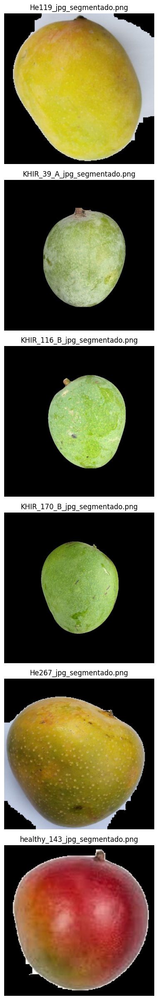

In [ ]:
# ============================================================
# BLOQUE 2. Segmentación
# ============================================================

!pip install -q -U ultralytics

import cv2
import torch
import shutil
import numpy as np
import pandas as pd

from tqdm.auto import tqdm
from ultralytics import YOLOE


# ------------------------------------------------------------
# Carpetas de salida
# ------------------------------------------------------------

salida_segmentadas = ejecucion / "Mangos_segmentados_fondo_negro"
salida_mascaras = ejecucion / "Mascaras_binarias"
salida_no_detectadas = ejecucion / "Imagenes_no_detectadas"

salida_segmentadas.mkdir(parents=True, exist_ok=True)
salida_mascaras.mkdir(parents=True, exist_ok=True)
salida_no_detectadas.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# Dispositivo
# ------------------------------------------------------------

DEVICE = 0 if torch.cuda.is_available() else "cpu"

print("Dispositivo utilizado:", DEVICE)


# ------------------------------------------------------------
# Parámetros principales
# ------------------------------------------------------------

# Umbral mínimo para aceptar una detección.
# Reducir a 0.08 si algunos mangos no son detectados.
CONFIDENCE = 0.12

# Tamaño utilizado durante la inferencia.
# 1024 conserva mejor el contorno que 640.
IMAGE_SIZE = 1024

# Umbral para eliminar detecciones superpuestas.
IOU_THRESHOLD = 0.50

# Área mínima de un componente respecto al tamaño de la imagen.
MIN_AREA_RATIO = 0.0002


# ------------------------------------------------------------
# Modelo de segmentación
# ------------------------------------------------------------

modelo = YOLOE("yoloe-11s-seg.pt")

# Se colocan varias formas de describir el objeto.
# Las indicaciones en inglés suelen funcionar mejor.
PROMPTS = [
    "mango fruit",
    "green mango fruit",
    "ripe mango fruit",
    "mango"
]

modelo.set_classes(PROMPTS)

print("Modelo cargado correctamente.")

# ============================================================
# FUNCIONES AUXILIARES
# ============================================================

def limpiar_mascara(mascara, alto, ancho):
    """
    Convierte la máscara a formato binario, corrige su tamaño,
    cierra pequeños huecos y elimina partículas diminutas.
    """

    # Ajustar al tamaño original de la imagen
    if mascara.shape[:2] != (alto, ancho):
        mascara = cv2.resize(
            mascara,
            (ancho, alto),
            interpolation=cv2.INTER_NEAREST
        )

    # Convertir a máscara binaria de 0 y 255
    mascara = (mascara > 0.50).astype(np.uint8) * 255

    # Cerrar pequeños huecos dentro del mango
    kernel = np.ones((5, 5), dtype=np.uint8)

    mascara = cv2.morphologyEx(
        mascara,
        cv2.MORPH_CLOSE,
        kernel,
        iterations=2
    )

    # --------------------------------------------------------
    # Eliminar componentes extremadamente pequeños
    # --------------------------------------------------------

    cantidad, etiquetas, estadisticas, _ = (
        cv2.connectedComponentsWithStats(
            mascara,
            connectivity=8
        )
    )

    mascara_limpia = np.zeros_like(mascara)

    area_minima = max(
        100,
        int(alto * ancho * MIN_AREA_RATIO)
    )

    for componente in range(1, cantidad):

        area = estadisticas[
            componente,
            cv2.CC_STAT_AREA
        ]

        if area >= area_minima:
            mascara_limpia[etiquetas == componente] = 255

    return mascara_limpia


def segmentar_fondo_claro(imagen):
    """
    Método auxiliar para imágenes donde YOLOE no detecte el mango,
    pero el fondo sea blanco o muy claro.

    Devuelve None cuando la imagen no parece tener un fondo claro.
    """

    alto, ancho = imagen.shape[:2]

    hsv = cv2.cvtColor(imagen, cv2.COLOR_BGR2HSV)

    grosor = max(
        2,
        int(min(alto, ancho) * 0.02)
    )

    # Píxeles ubicados alrededor de los bordes de la imagen
    borde_bgr = np.concatenate([
        imagen[:grosor, :, :].reshape(-1, 3),
        imagen[-grosor:, :, :].reshape(-1, 3),
        imagen[:, :grosor, :].reshape(-1, 3),
        imagen[:, -grosor:, :].reshape(-1, 3)
    ])

    borde_hsv = np.concatenate([
        hsv[:grosor, :, :].reshape(-1, 3),
        hsv[-grosor:, :, :].reshape(-1, 3),
        hsv[:, :grosor, :].reshape(-1, 3),
        hsv[:, -grosor:, :].reshape(-1, 3)
    ])

    saturacion_mediana = np.median(borde_hsv[:, 1])
    brillo_mediano = np.median(borde_hsv[:, 2])

    # Si los bordes no son claros, no se aplica este método
    if brillo_mediano < 190 or saturacion_mediana > 80:
        return None

    color_fondo = np.median(
        borde_bgr,
        axis=0
    ).astype(np.float32)

    diferencia = np.linalg.norm(
        imagen.astype(np.float32) - color_fondo,
        axis=2
    )

    # Los píxeles suficientemente diferentes del fondo
    # se consideran parte del mango
    mascara = (diferencia > 32).astype(np.uint8) * 255

    mascara = limpiar_mascara(
        mascara,
        alto,
        ancho
    )

    proporcion = np.count_nonzero(mascara) / mascara.size

    # Evitar máscaras completamente vacías o casi completas
    if proporcion < 0.005 or proporcion > 0.95:
        return None

    return mascara

# ============================================================
# BLOQUE 5. SEGMENTAR TODO EL DATASET
# ============================================================

EXTENSIONES_VALIDAS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".tif",
    ".tiff",
    ".webp"
}


# ------------------------------------------------------------
# Buscar imágenes recursivamente
# ------------------------------------------------------------

archivos_imagen = sorted([
    ruta
    for ruta in dataset.rglob("*")
    if ruta.is_file()
    and ruta.suffix.lower() in EXTENSIONES_VALIDAS
])

print(f"Imágenes encontradas: {len(archivos_imagen)}")


# ------------------------------------------------------------
# Registro de resultados
# ------------------------------------------------------------

registros = []


for archivo in tqdm(
    archivos_imagen,
    desc="Segmentando mangos"
):

    ruta_relativa = archivo.relative_to(dataset)

    # Mantener las subcarpetas originales
    carpeta_segmentada = (
        salida_segmentadas /
        ruta_relativa.parent
    )

    carpeta_mascara = (
        salida_mascaras /
        ruta_relativa.parent
    )

    carpeta_no_detectada = (
        salida_no_detectadas /
        ruta_relativa.parent
    )

    carpeta_segmentada.mkdir(
        parents=True,
        exist_ok=True
    )

    carpeta_mascara.mkdir(
        parents=True,
        exist_ok=True
    )

    carpeta_no_detectada.mkdir(
        parents=True,
        exist_ok=True
    )

    # Se incluye la extensión original en el nombre para
    # evitar sobrescribir archivos que tengan el mismo nombre
    nombre_base = (
        f"{archivo.stem}_"
        f"{archivo.suffix[1:].lower()}"
    )

    ruta_salida = (
        carpeta_segmentada /
        f"{nombre_base}_segmentado.png"
    )

    ruta_mascara = (
        carpeta_mascara /
        f"{nombre_base}_mascara.png"
    )

    imagen = cv2.imread(
        str(archivo),
        cv2.IMREAD_COLOR
    )

    if imagen is None:

        registros.append({
            "archivo": str(ruta_relativa),
            "estado": "Error de lectura",
            "metodo": "",
            "numero_mangos": 0,
            "confianza_maxima": 0,
            "porcentaje_segmentado": 0
        })

        continue

    alto, ancho = imagen.shape[:2]

    mascara_final = None
    metodo = ""
    numero_mangos = 0
    confianza_maxima = 0.0

    try:

        # ----------------------------------------------------
        # Segmentación principal mediante YOLOE
        # ----------------------------------------------------

        resultado = modelo.predict(
            source=str(archivo),
            conf=CONFIDENCE,
            iou=IOU_THRESHOLD,
            imgsz=IMAGE_SIZE,
            device=DEVICE,
            retina_masks=True,
            agnostic_nms=True,
            max_det=100,
            verbose=False
        )[0]

        if (
            resultado.masks is not None
            and len(resultado.masks.data) > 0
        ):

            mascaras = (
                resultado.masks.data
                .detach()
                .cpu()
                .numpy()
            )

            # Unir todas las máscaras para conservar todos
            # los mangos encontrados en la fotografía
            mascara_unida = np.max(
                mascaras,
                axis=0
            )

            mascara_final = limpiar_mascara(
                mascara_unida,
                alto,
                ancho
            )

            metodo = "YOLOE"
            numero_mangos = len(mascaras)

            if (
                resultado.boxes is not None
                and resultado.boxes.conf is not None
            ):
                confianza_maxima = float(
                    resultado.boxes.conf.max().item()
                )

        # ----------------------------------------------------
        # Respaldo para fotografías con fondo blanco
        # ----------------------------------------------------

        if (
            mascara_final is None
            or np.count_nonzero(mascara_final) == 0
        ):

            mascara_clara = segmentar_fondo_claro(
                imagen
            )

            if mascara_clara is not None:
                mascara_final = mascara_clara
                metodo = "Fondo claro"
                numero_mangos = 1

        # ----------------------------------------------------
        # Cuando ningún método obtiene una máscara
        # ----------------------------------------------------

        if (
            mascara_final is None
            or np.count_nonzero(mascara_final) == 0
        ):

            destino_no_detectado = (
                carpeta_no_detectada /
                archivo.name
            )

            shutil.copy2(
                archivo,
                destino_no_detectado
            )

            registros.append({
                "archivo": str(ruta_relativa),
                "estado": "No detectada",
                "metodo": "",
                "numero_mangos": 0,
                "confianza_maxima": confianza_maxima,
                "porcentaje_segmentado": 0
            })

            continue

        # ----------------------------------------------------
        # Crear imagen con fondo completamente negro
        # ----------------------------------------------------

        imagen_segmentada = np.zeros_like(imagen)

        imagen_segmentada[
            mascara_final > 0
        ] = imagen[
            mascara_final > 0
        ]

        # Guardar imagen final
        cv2.imwrite(
            str(ruta_salida),
            imagen_segmentada,
            [cv2.IMWRITE_PNG_COMPRESSION, 3]
        )

        # Guardar máscara binaria
        cv2.imwrite(
            str(ruta_mascara),
            mascara_final,
            [cv2.IMWRITE_PNG_COMPRESSION, 3]
        )

        porcentaje_segmentado = (
            np.count_nonzero(mascara_final)
            / mascara_final.size
            * 100
        )

        registros.append({
            "archivo": str(ruta_relativa),
            "estado": "Segmentada",
            "metodo": metodo,
            "numero_mangos": numero_mangos,
            "confianza_maxima": round(
                confianza_maxima,
                4
            ),
            "porcentaje_segmentado": round(
                porcentaje_segmentado,
                4
            )
        })

    except Exception as error:

        registros.append({
            "archivo": str(ruta_relativa),
            "estado": f"Error: {error}",
            "metodo": "",
            "numero_mangos": 0,
            "confianza_maxima": 0,
            "porcentaje_segmentado": 0
        })


# ------------------------------------------------------------
# Guardar reporte
# ------------------------------------------------------------

reporte = pd.DataFrame(registros)

ruta_reporte = (
    ejecucion /
    "reporte_segmentacion_mangos.csv"
)

reporte.to_csv(
    ruta_reporte,
    index=False,
    encoding="utf-8-sig"
)


# ------------------------------------------------------------
# Resumen
# ------------------------------------------------------------

cantidad_segmentadas = (
    reporte["estado"] == "Segmentada"
).sum()

cantidad_no_detectadas = (
    reporte["estado"] == "No detectada"
).sum()

cantidad_errores = len(reporte) - (
    cantidad_segmentadas
    + cantidad_no_detectadas
)

print("\nPROCESAMIENTO TERMINADO")
print("--------------------------------")
print("Total de imágenes:", len(reporte))
print("Segmentadas:", cantidad_segmentadas)
print("No detectadas:", cantidad_no_detectadas)
print("Errores:", cantidad_errores)

print("\nImágenes segmentadas:")
print(salida_segmentadas)

print("\nMáscaras binarias:")
print(salida_mascaras)

print("\nImágenes que requieren revisión:")
print(salida_no_detectadas)

print("\nReporte:")
print(ruta_reporte)

# ============================================================
# BLOQUE 6. MOSTRAR RESULTADOS
# ============================================================

import random
import matplotlib.pyplot as plt

resultados_guardados = list(
    salida_segmentadas.rglob("*.png")
)

if len(resultados_guardados) == 0:

    print("Todavía no existen imágenes segmentadas.")

else:

    cantidad_mostrar = min(
        6,
        len(resultados_guardados)
    )

    seleccionadas = random.sample(
        resultados_guardados,
        cantidad_mostrar
    )

    plt.figure(
        figsize=(15, 4 * cantidad_mostrar)
    )

    for posicion, ruta in enumerate(
        seleccionadas,
        start=1
    ):

        imagen = cv2.imread(str(ruta))
        imagen = cv2.cvtColor(
            imagen,
            cv2.COLOR_BGR2RGB
        )

        plt.subplot(
            cantidad_mostrar,
            1,
            posicion
        )

        plt.imshow(imagen)
        plt.title(ruta.name)
        plt.axis("off")

    plt.tight_layout()
    plt.show()

## **2.2. Spliting**

In [ ]:
# ============================================================
# BLOQUE SPLITTING CORREGIDO
#
# Funciones:
# 1. Lee las imágenes de Maduros e Inmaduros.
# 2. Calcula el hash SHA-256 de cada imagen.
# 3. Detecta conflictos de etiquetas.
# 4. Elimina duplicados exactos dentro de cada clase.
# 5. Balancea las clases según la clase minoritaria.
# 6. Genera:
#       70 % train
#       20 % val
#       10 % test
# 7. Verifica que no exista data leakage.
# ============================================================

import math
import random
import shutil
import hashlib

from pathlib import Path

import pandas as pd
from tqdm.auto import tqdm
from IPython.display import display


# ============================================================
# 1. CONFIGURACIÓN
# ============================================================

SEED = 42

CLASES = [
    "Maduros",
    "Inmaduros"
]

PROPORCIONES = {
    "train": 0.70,
    "val": 0.20,
    "test": 0.10
}

EXTENSIONES_VALIDAS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".tif",
    ".tiff",
    ".webp"
}


# ------------------------------------------------------------
# Carpeta que contiene:
#   Maduros/
#   Inmaduros/
# ------------------------------------------------------------

CARPETA_ORIGEN = (
    ejecucion /
    "Mangos_segmentados_fondo_negro"
)


# ------------------------------------------------------------
# Carpeta que se reconstruirá completamente
# ------------------------------------------------------------

CARPETA_SALIDA = (
    ejecucion /
    "Dataset_balanceado_split"
)


# ------------------------------------------------------------
# Carpeta para reportes del proceso
# ------------------------------------------------------------

CARPETA_REPORTES = (
    ejecucion /
    "Reportes_splitting"
)

CARPETA_REPORTES.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 2. FUNCIONES AUXILIARES
# ============================================================

def obtener_imagenes(carpeta):
    """
    Busca recursivamente todas las imágenes válidas.
    """

    return sorted([
        archivo
        for archivo in carpeta.rglob("*")
        if archivo.is_file()
        and archivo.suffix.lower() in EXTENSIONES_VALIDAS
    ])


def calcular_hash_archivo(
    filepath,
    chunk_size=1024 * 1024
):
    """
    Calcula el hash SHA-256 de un archivo.

    Dos archivos con el mismo hash son idénticos byte a byte,
    aunque tengan nombres o rutas diferentes.
    """

    sha256 = hashlib.sha256()

    with open(filepath, "rb") as archivo:

        while True:

            bloque = archivo.read(chunk_size)

            if not bloque:
                break

            sha256.update(bloque)

    return sha256.hexdigest()


def calcular_cantidades_split(total):
    """
    Calcula las cantidades enteras para 70 %, 20 % y 10 %,
    asegurando que la suma sea exactamente igual al total.

    Usa el método de restos mayores.
    """

    valores_reales = {
        division: total * proporcion
        for division, proporcion in PROPORCIONES.items()
    }

    cantidades = {
        division: int(math.floor(valor))
        for division, valor in valores_reales.items()
    }

    faltantes = total - sum(cantidades.values())

    orden_restos = sorted(
        valores_reales.keys(),
        key=lambda division: (
            valores_reales[division]
            - cantidades[division]
        ),
        reverse=True
    )

    for posicion in range(faltantes):

        division = orden_restos[
            posicion % len(orden_restos)
        ]

        cantidades[division] += 1

    return cantidades


# ============================================================
# 3. VERIFICAR PROPORCIONES
# ============================================================

if not math.isclose(
    sum(PROPORCIONES.values()),
    1.0,
    rel_tol=1e-9
):
    raise ValueError(
        "Las proporciones de train, val y test deben sumar 1."
    )


# ============================================================
# 4. INVENTARIAR TODAS LAS IMÁGENES
# ============================================================

registros_inventario = []

print("INVENTARIANDO IMÁGENES")
print("=" * 70)

for clase in CLASES:

    carpeta_clase = (
        CARPETA_ORIGEN /
        clase
    )

    if not carpeta_clase.exists():

        raise FileNotFoundError(
            f"No se encontró la carpeta:\n{carpeta_clase}"
        )

    imagenes = obtener_imagenes(
        carpeta_clase
    )

    if len(imagenes) == 0:

        raise ValueError(
            f"La clase '{clase}' no contiene imágenes."
        )

    print(
        f"{clase}: {len(imagenes)} archivos encontrados"
    )

    for archivo in imagenes:

        registros_inventario.append({
            "clase": clase,
            "filepath": str(archivo),
            "nombre_archivo": archivo.name,
            "extension": archivo.suffix.lower()
        })


df_inventario = pd.DataFrame(
    registros_inventario
)


# ============================================================
# 5. CALCULAR HASH DE CADA IMAGEN
# ============================================================

print("\nCALCULANDO HASH SHA-256")
print("=" * 70)

hashes = []

for filepath in tqdm(
    df_inventario["filepath"],
    desc="Calculando hashes"
):

    hashes.append(
        calcular_hash_archivo(filepath)
    )

df_inventario["hash_sha256"] = hashes


ruta_inventario = (
    CARPETA_REPORTES /
    "inventario_imagenes_con_hash.csv"
)

df_inventario.to_csv(
    ruta_inventario,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 6. DETECTAR CONFLICTOS ENTRE CLASES
# ============================================================

# Un conflicto ocurre cuando una misma imagen exacta está
# etiquetada como Maduros y también como Inmaduros.

conteo_clases_por_hash = (
    df_inventario
    .groupby("hash_sha256")["clase"]
    .nunique()
)

hashes_conflictivos = conteo_clases_por_hash[
    conteo_clases_por_hash > 1
].index.tolist()


if len(hashes_conflictivos) > 0:

    df_conflictos = (
        df_inventario[
            df_inventario["hash_sha256"].isin(
                hashes_conflictivos
            )
        ]
        .sort_values([
            "hash_sha256",
            "clase",
            "filepath"
        ])
        .reset_index(drop=True)
    )

    ruta_conflictos = (
        CARPETA_REPORTES /
        "conflictos_etiquetas.csv"
    )

    df_conflictos.to_csv(
        ruta_conflictos,
        index=False,
        encoding="utf-8-sig"
    )

    print("\nCONFLICTOS DE ETIQUETAS ENCONTRADOS")
    display(df_conflictos)

    raise ValueError(
        "Existen imágenes idénticas etiquetadas en clases "
        "diferentes. Debes revisar si realmente corresponden "
        "a Maduros o Inmaduros.\n\n"
        f"Reporte guardado en:\n{ruta_conflictos}"
    )


print(
    "\nNo existen imágenes idénticas con etiquetas diferentes."
)


# ============================================================
# 7. ELIMINAR DUPLICADOS EXACTOS DENTRO DE CADA CLASE
# ============================================================

registros_unicos = []
registros_duplicados = []

for clase in CLASES:

    df_clase = (
        df_inventario[
            df_inventario["clase"] == clase
        ]
        .sort_values("filepath")
        .reset_index(drop=True)
    )

    for hash_imagen, grupo in df_clase.groupby(
        "hash_sha256",
        sort=True
    ):

        grupo = grupo.sort_values(
            "filepath"
        ).reset_index(drop=True)

        # Se conserva solamente el primer archivo
        registro_conservado = grupo.iloc[0]

        registros_unicos.append({
            "clase": clase,
            "filepath": registro_conservado["filepath"],
            "nombre_archivo": registro_conservado["nombre_archivo"],
            "extension": registro_conservado["extension"],
            "hash_sha256": hash_imagen
        })

        # Los demás archivos del grupo son copias exactas
        if len(grupo) > 1:

            for posicion in range(1, len(grupo)):

                registro_duplicado = grupo.iloc[posicion]

                registros_duplicados.append({
                    "clase": clase,
                    "hash_sha256": hash_imagen,
                    "archivo_conservado": (
                        registro_conservado["filepath"]
                    ),
                    "archivo_duplicado": (
                        registro_duplicado["filepath"]
                    )
                })


df_imagenes_unicas = pd.DataFrame(
    registros_unicos
)

df_duplicados_eliminados = pd.DataFrame(
    registros_duplicados
)


ruta_unicos = (
    CARPETA_REPORTES /
    "imagenes_unicas.csv"
)

df_imagenes_unicas.to_csv(
    ruta_unicos,
    index=False,
    encoding="utf-8-sig"
)


ruta_duplicados = (
    CARPETA_REPORTES /
    "duplicados_exactos_eliminados.csv"
)

df_duplicados_eliminados.to_csv(
    ruta_duplicados,
    index=False,
    encoding="utf-8-sig"
)


print("\nRESULTADO DE LA DEPURACIÓN")
print("=" * 70)

for clase in CLASES:

    cantidad_original = int(
        (
            df_inventario["clase"] == clase
        ).sum()
    )

    cantidad_unica = int(
        (
            df_imagenes_unicas["clase"] == clase
        ).sum()
    )

    cantidad_duplicada = (
        cantidad_original
        - cantidad_unica
    )

    print(
        f"{clase}:"
        f"\n  Originales: {cantidad_original}"
        f"\n  Únicas: {cantidad_unica}"
        f"\n  Duplicadas eliminadas: {cantidad_duplicada}"
    )


# ============================================================
# 8. DETERMINAR CANTIDAD DE LA CLASE MINORITARIA
# ============================================================

cantidad_unica_por_clase = (
    df_imagenes_unicas[
        "clase"
    ]
    .value_counts()
    .reindex(CLASES)
)

cantidad_minima = int(
    cantidad_unica_por_clase.min()
)

if cantidad_minima < 10:

    raise ValueError(
        "Después de eliminar duplicados, alguna clase tiene "
        "menos de 10 imágenes. El dataset es insuficiente para "
        "el flujo propuesto."
    )


cantidades_split = calcular_cantidades_split(
    cantidad_minima
)


print("\nBALANCEO Y DISTRIBUCIÓN")
print("=" * 70)

print(
    f"Cantidad única utilizada por clase: "
    f"{cantidad_minima}"
)

print(
    f"Train por clase: "
    f"{cantidades_split['train']}"
)

print(
    f"Validation por clase: "
    f"{cantidades_split['val']}"
)

print(
    f"Test por clase: "
    f"{cantidades_split['test']}"
)

print(
    f"Total final del dataset: "
    f"{cantidad_minima * len(CLASES)}"
)


# ============================================================
# 9. REINICIAR CARPETA DEL SPLITTING
# ============================================================

# Se elimina solamente la carpeta del split anterior.
# Las imágenes segmentadas originales no se modifican.

if CARPETA_SALIDA.exists():

    shutil.rmtree(
        CARPETA_SALIDA
    )

CARPETA_SALIDA.mkdir(
    parents=True,
    exist_ok=True
)


for division in [
    "train",
    "val",
    "test"
]:

    for clase in CLASES:

        (
            CARPETA_SALIDA /
            division /
            clase
        ).mkdir(
            parents=True,
            exist_ok=True
        )


# ============================================================
# 10. SELECCIONAR, DIVIDIR Y COPIAR
# ============================================================

generador = random.Random(
    SEED
)

registros_split = []
registros_no_seleccionados = []


for clase in CLASES:

    registros_clase = (
        df_imagenes_unicas[
            df_imagenes_unicas["clase"] == clase
        ]
        .sort_values("filepath")
        .to_dict("records")
    )

    # Mezcla reproducible
    generador.shuffle(
        registros_clase
    )

    seleccionados = registros_clase[
        :cantidad_minima
    ]

    no_seleccionados = registros_clase[
        cantidad_minima:
    ]

    for registro in no_seleccionados:

        registros_no_seleccionados.append({
            "clase": clase,
            "filepath": registro["filepath"],
            "hash_sha256": registro["hash_sha256"],
            "motivo": "Submuestreo para balancear clases"
        })


    inicio_train = 0

    fin_train = (
        cantidades_split["train"]
    )

    fin_val = (
        fin_train
        + cantidades_split["val"]
    )


    divisiones = {
        "train": seleccionados[
            inicio_train:fin_train
        ],

        "val": seleccionados[
            fin_train:fin_val
        ],

        "test": seleccionados[
            fin_val:
        ]
    }


    for division, lista_registros in divisiones.items():

        carpeta_destino = (
            CARPETA_SALIDA /
            division /
            clase
        )

        for indice, registro in enumerate(
            lista_registros,
            start=1
        ):

            archivo_origen = Path(
                registro["filepath"]
            )

            hash_corto = registro[
                "hash_sha256"
            ][:12]

            nombre_destino = (
                f"{clase.lower()}_"
                f"{division}_"
                f"{indice:05d}_"
                f"{hash_corto}"
                f"{archivo_origen.suffix.lower()}"
            )

            archivo_destino = (
                carpeta_destino /
                nombre_destino
            )

            shutil.copy2(
                archivo_origen,
                archivo_destino
            )

            registros_split.append({
                "clase": clase,
                "division": division,
                "archivo_original": str(
                    archivo_origen
                ),
                "archivo_destino": str(
                    archivo_destino
                ),
                "nombre_destino": nombre_destino,
                "hash_sha256": registro[
                    "hash_sha256"
                ]
            })


df_registro_split = pd.DataFrame(
    registros_split
)

df_no_seleccionados = pd.DataFrame(
    registros_no_seleccionados
)


ruta_registro_split = (
    CARPETA_SALIDA /
    "registro_split_imagenes.csv"
)

df_registro_split.to_csv(
    ruta_registro_split,
    index=False,
    encoding="utf-8-sig"
)


ruta_no_seleccionados = (
    CARPETA_REPORTES /
    "imagenes_no_seleccionadas_balanceo.csv"
)

df_no_seleccionados.to_csv(
    ruta_no_seleccionados,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 11. VERIFICACIÓN FINAL DE DATA LEAKAGE
# ============================================================

print("\nVERIFICACIÓN FINAL DEL SPLITTING")
print("=" * 70)


# ------------------------------------------------------------
# Cada hash debe aparecer exactamente una vez en todo el split
# ------------------------------------------------------------

conteo_global_hash = (
    df_registro_split[
        "hash_sha256"
    ]
    .value_counts()
)

hashes_repetidos = conteo_global_hash[
    conteo_global_hash > 1
]


if len(hashes_repetidos) > 0:

    df_leakage = df_registro_split[
        df_registro_split[
            "hash_sha256"
        ].isin(
            hashes_repetidos.index
        )
    ].sort_values(
        "hash_sha256"
    )

    ruta_leakage = (
        CARPETA_REPORTES /
        "data_leakage_detectado.csv"
    )

    df_leakage.to_csv(
        ruta_leakage,
        index=False,
        encoding="utf-8-sig"
    )

    display(
        df_leakage
    )

    raise ValueError(
        "La verificación final encontró hashes repetidos "
        "en el dataset generado."
    )


# ------------------------------------------------------------
# Verificar que un hash no aparezca en varias divisiones
# ------------------------------------------------------------

divisiones_por_hash = (
    df_registro_split
    .groupby("hash_sha256")["division"]
    .nunique()
)

leakage_entre_splits = divisiones_por_hash[
    divisiones_por_hash > 1
]


if len(leakage_entre_splits) > 0:

    raise ValueError(
        "Se encontraron imágenes idénticas en más de una "
        "división."
    )


print(
    "No se encontraron duplicados exactos en el dataset final."
)

print(
    "No existe superposición entre train, val y test."
)


# ============================================================
# 12. RESUMEN FINAL
# ============================================================

resumen_final = (
    df_registro_split
    .groupby([
        "division",
        "clase"
    ])
    .size()
    .reset_index(
        name="cantidad"
    )
)


orden_divisiones = pd.CategoricalDtype(
    categories=[
        "train",
        "val",
        "test"
    ],
    ordered=True
)

resumen_final["division"] = (
    resumen_final["division"]
    .astype(orden_divisiones)
)

resumen_final = resumen_final.sort_values([
    "division",
    "clase"
])


ruta_resumen = (
    CARPETA_SALIDA /
    "resumen_split.csv"
)

resumen_final.to_csv(
    ruta_resumen,
    index=False,
    encoding="utf-8-sig"
)


tabla_resumen = resumen_final.pivot(
    index="division",
    columns="clase",
    values="cantidad"
).reindex([
    "train",
    "val",
    "test"
])


print("\nDISTRIBUCIÓN FINAL")
print("=" * 70)

display(
    tabla_resumen
)


print(
    f"\nTotal de imágenes únicas utilizadas: "
    f"{len(df_registro_split)}"
)

print(
    f"\nDataset generado en:\n"
    f"{CARPETA_SALIDA}"
)

print(
    f"\nReporte de duplicados eliminados:\n"
    f"{ruta_duplicados}"
)

print(
    f"\nRegistro del nuevo split:\n"
    f"{ruta_registro_split}"
)

print(
    f"\nResumen del nuevo split:\n"
    f"{ruta_resumen}"
)

print(
    "\nSPLITTING FINALIZADO SIN DATA LEAKAGE."
)

INVENTARIANDO IMÁGENES
Maduros: 384 archivos encontrados
Inmaduros: 911 archivos encontrados

CALCULANDO HASH SHA-256


Calculando hashes:   0%|          | 0/1295 [00:00<?, ?it/s]


No existen imágenes idénticas con etiquetas diferentes.

RESULTADO DE LA DEPURACIÓN
Maduros:
  Originales: 384
  Únicas: 336
  Duplicadas eliminadas: 48
Inmaduros:
  Originales: 911
  Únicas: 910
  Duplicadas eliminadas: 1

BALANCEO Y DISTRIBUCIÓN
Cantidad única utilizada por clase: 336
Train por clase: 235
Validation por clase: 67
Test por clase: 34
Total final del dataset: 672

VERIFICACIÓN FINAL DEL SPLITTING
No se encontraron duplicados exactos en el dataset final.
No existe superposición entre train, val y test.

DISTRIBUCIÓN FINAL


clase,Inmaduros,Maduros
division,,
train,235,235
val,67,67
test,34,34



Total de imágenes únicas utilizadas: 672

Dataset generado en:
/content/drive/MyDrive/Tesis-Mango/Dataset Tesis2/Resultados/Dataset_balanceado_split

Reporte de duplicados eliminados:
/content/drive/MyDrive/Tesis-Mango/Dataset Tesis2/Resultados/Reportes_splitting/duplicados_exactos_eliminados.csv

Registro del nuevo split:
/content/drive/MyDrive/Tesis-Mango/Dataset Tesis2/Resultados/Dataset_balanceado_split/registro_split_imagenes.csv

Resumen del nuevo split:
/content/drive/MyDrive/Tesis-Mango/Dataset Tesis2/Resultados/Dataset_balanceado_split/resumen_split.csv

SPLITTING FINALIZADO SIN DATA LEAKAGE.


# **3. Modelos**

## **3.1. ResNet50**

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 425.6/425.6 kB 13.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.1/19.1 MB 67.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.7/18.7 MB 67.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 839.1/839.1 kB 47.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 264.7/264.7 kB 21.4 MB/s eta 0:00:00
Operaciones deterministas activadas.
GPU detectada: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

DISTRIBUCIÓN PRINCIPAL DEL DATASET

Train


,count
label,
Inmaduros,235
Maduros,235



Validation


,count
label,
Inmaduros,67
Maduros,67



Test


,count
label,
Inmaduros,34
Maduros,34


Verificando duplicados:   0%|          | 0/672 [00:00<?, ?it/s]

No se encontraron imágenes duplicadas entre los splits.

DIVISIÓN INTERNA DE VALIDACIÓN PARA OPTUNA

Optuna train:


,count
label,
Inmaduros,46
Maduros,47



Optuna validation:


,count
label,
Inmaduros,21
Maduros,20



Total val: 134
Optuna train: 93
Optuna validation: 41

INICIANDO OPTUNA - RESNET50


  0%|          | 0/30 [00:00<?, ?it/s]

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step



MEJORES HIPERPARÁMETROS
batch_size: 32
cnn_epochs: 10
last_n_layers: 40
dense_units: 128
dropout_rate: 0.1
learning_rate: 1.7327871113349947e-05
optimizer: adam
l2_regularization: 2.015647705936503e-06
label_smoothing: 0.0

Mejor log loss: 0.01162095
Accuracy del mejor trial: 1.000000
ROC AUC del mejor trial: 1.000000
PR AUC del mejor trial: 1.000000
Brier del mejor trial: 0.00290718
ECE del mejor trial: 0.00973171
Épocas elegidas por HPO: 10


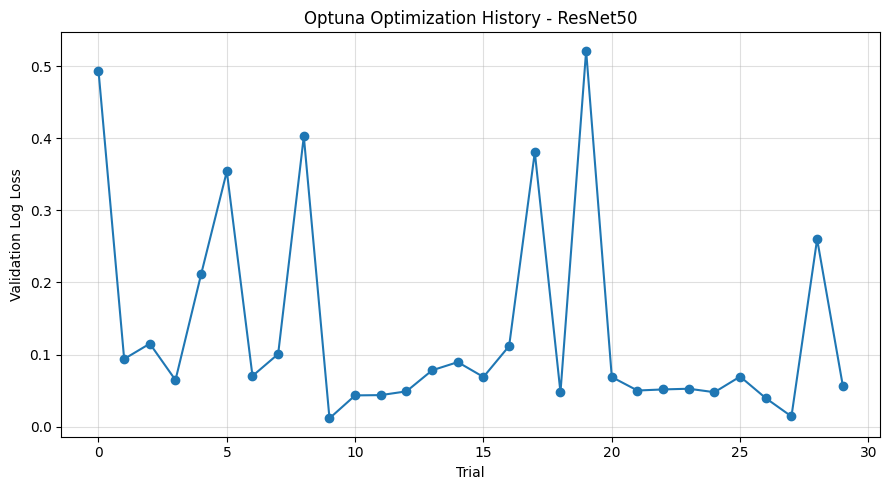


INICIANDO VALIDACIÓN CRUZADA - RESNET50
Cada fold utilizará exactamente 10 época(s) elegida(s) por HPO, sin EarlyStopping ni selección adicional de épocas.

FOLD 1/10
------------------------------------------------------------------------
Epoch 1/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 29s 1s/step - accuracy: 0.8865 - auc: 0.9606 - loss: 0.2871 - pr_auc: 0.9669 - precision: 0.9767 - recall: 0.7925 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0198 - val_pr_auc: 1.0000 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 2/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - accuracy: 1.0000 - auc: 1.0000 - loss: 0.0087 - pr_auc: 1.0000 - precision: 1.0000 - recall: 1.0000 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0098 - val_pr_auc: 1.0000 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 3/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - accuracy: 1.0000 - auc: 1.0000 - loss: 8.9232e-04 - pr_auc: 1.0000 - precision: 1.0000 - recall: 1.0000 - val_accuracy: 0.9787 - val_auc: 1.0000 - val_

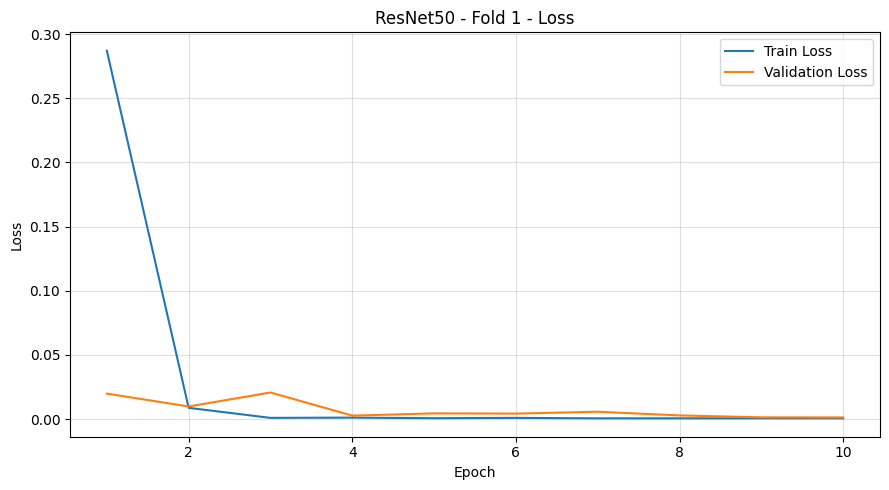

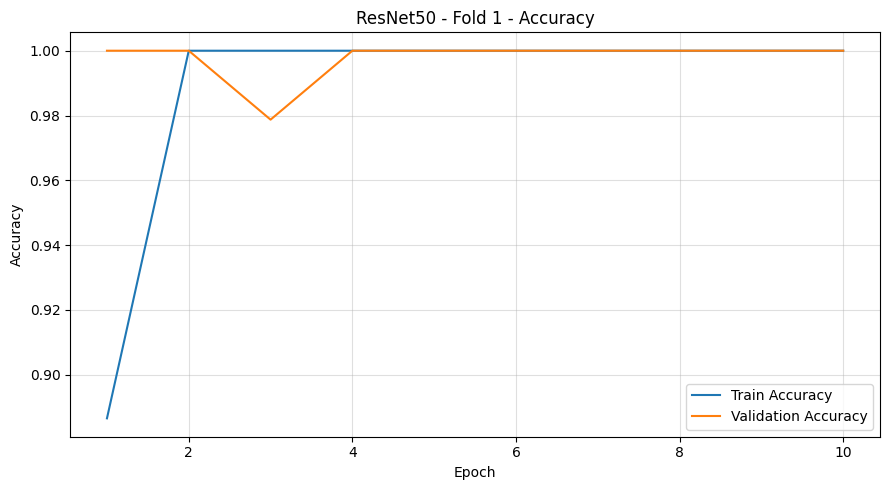

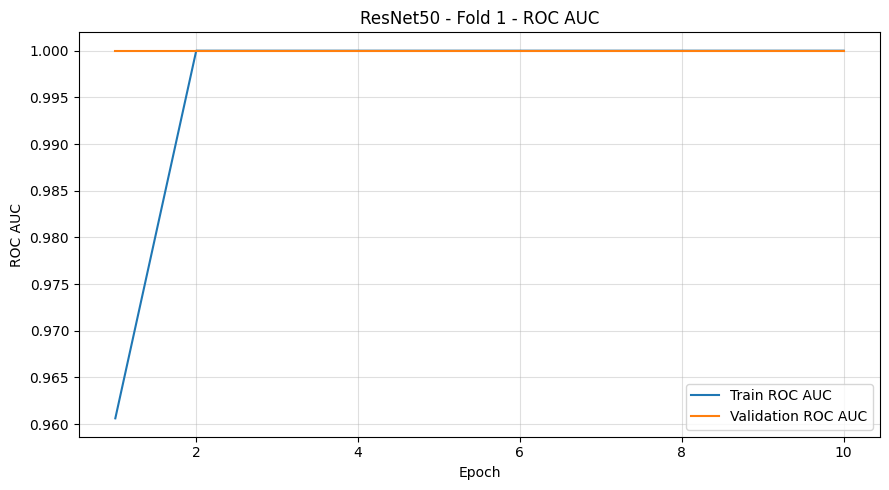

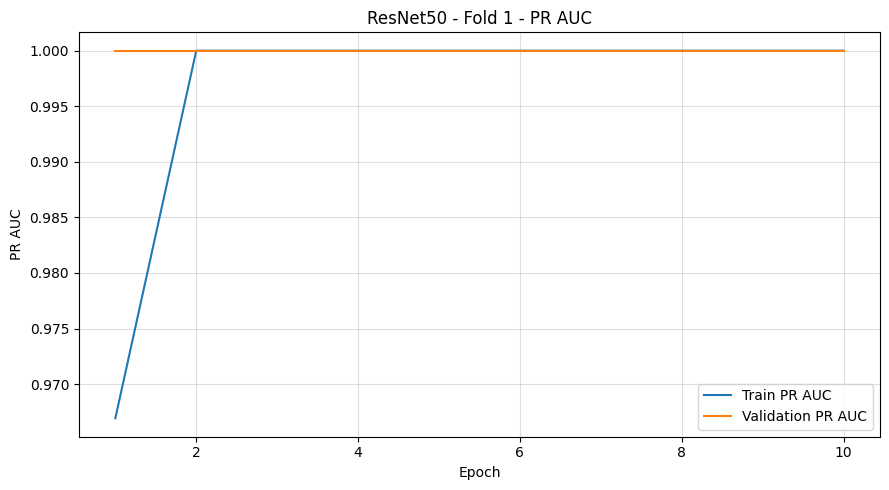

2/2 ━━━━━━━━━━━━━━━━━━━━ 4s 2s/step

Fold 01 | Acc: 1.0000 | Bal Acc: 1.0000 | F1: 1.0000 | ROC AUC: 1.0000 | PR AUC: 1.0000 | Log loss: 0.00075741 | Brier: 0.00001597 | ECE: 0.00074929


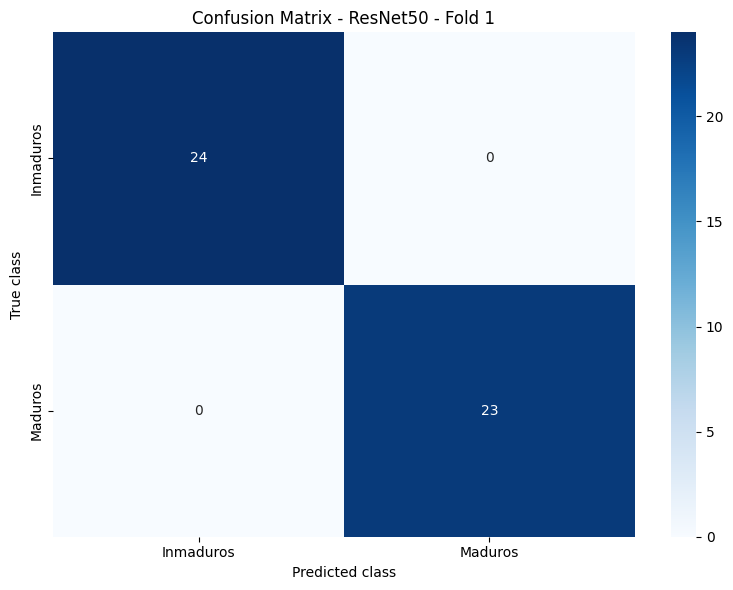

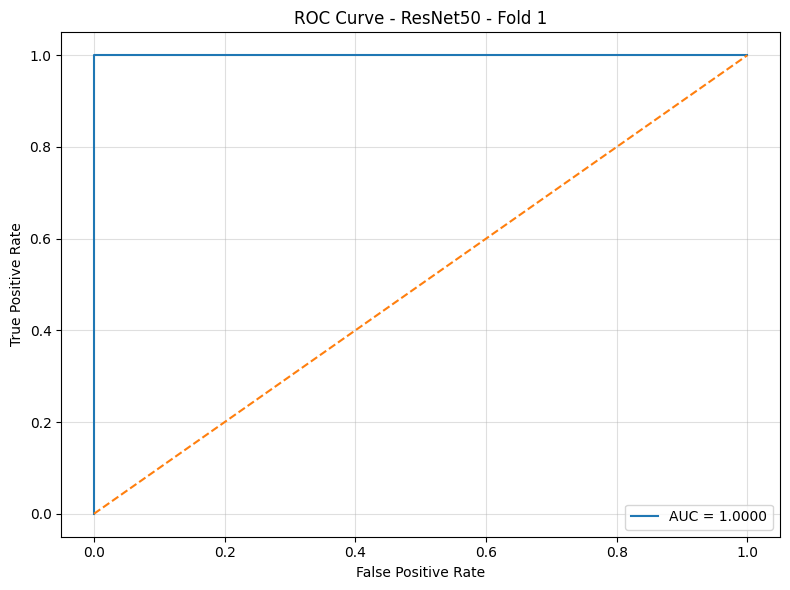

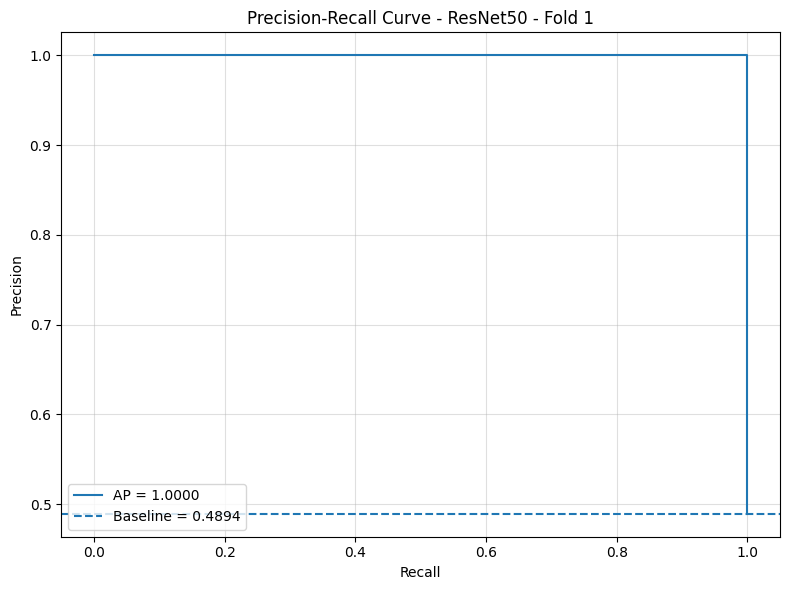

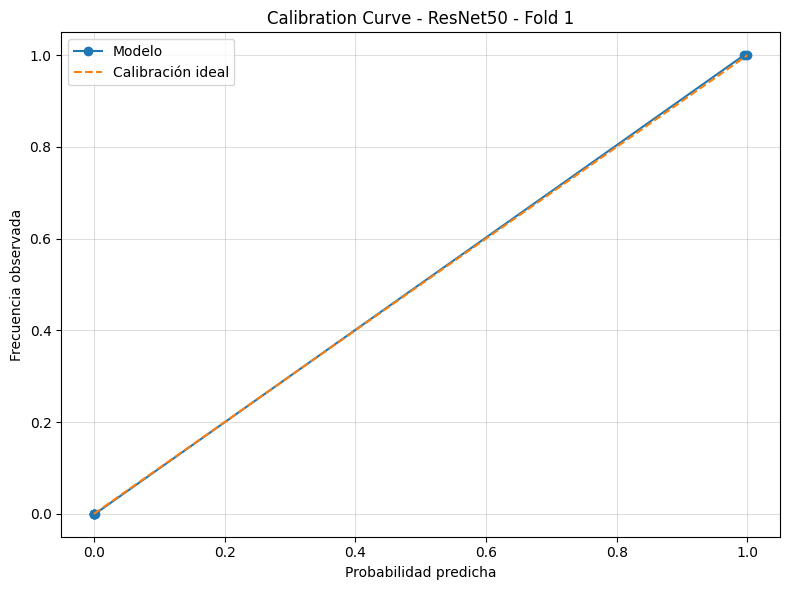

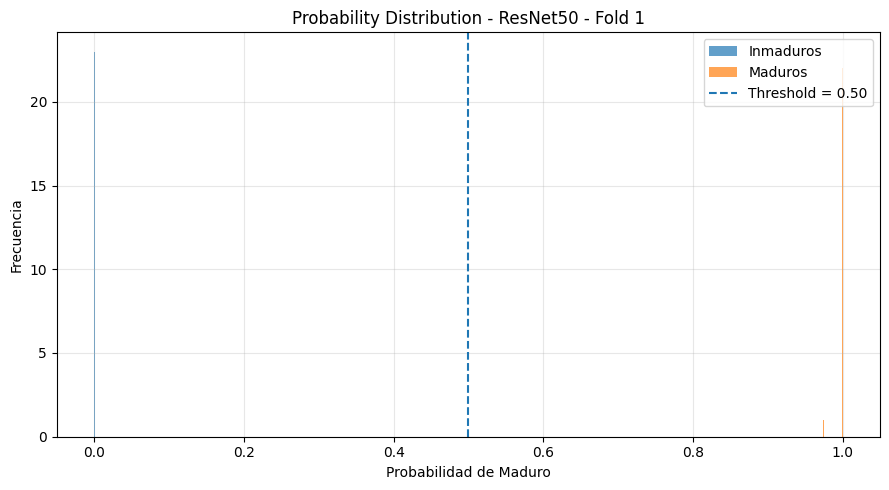

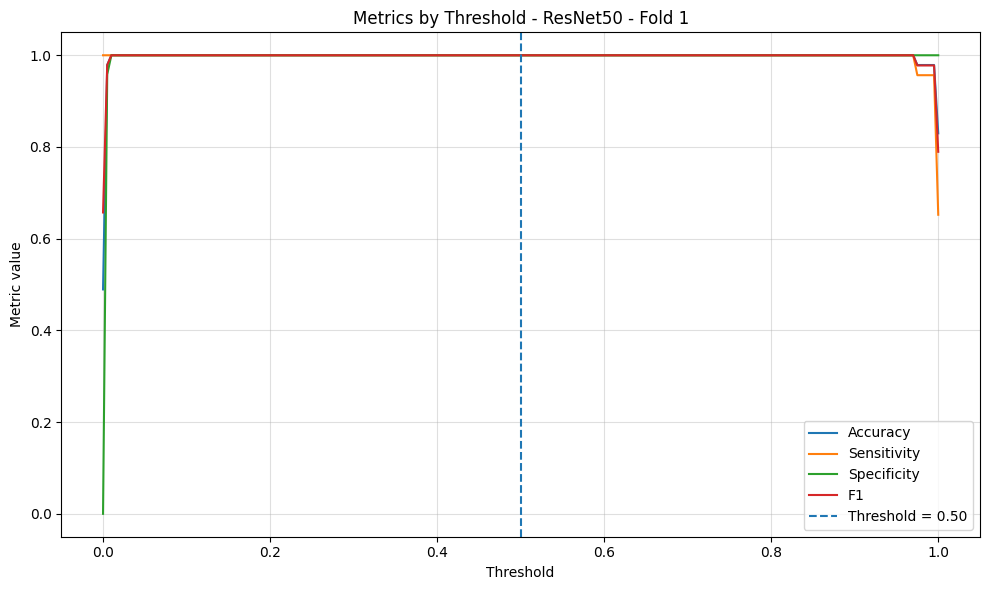


FOLD 2/10
------------------------------------------------------------------------
Epoch 1/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 29s 1s/step - accuracy: 0.8629 - auc: 0.9560 - loss: 0.3261 - pr_auc: 0.9612 - precision: 0.9477 - recall: 0.7689 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0138 - val_pr_auc: 1.0000 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 2/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - accuracy: 0.9953 - auc: 1.0000 - loss: 0.0103 - pr_auc: 1.0000 - precision: 0.9907 - recall: 1.0000 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0022 - val_pr_auc: 1.0000 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 3/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 17s 1s/step - accuracy: 0.9929 - auc: 0.9997 - loss: 0.0198 - pr_auc: 0.9997 - precision: 0.9953 - recall: 0.9906 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0025 - val_pr_auc: 1.0000 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 4/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - accuracy: 1.0000 - auc: 1.0000

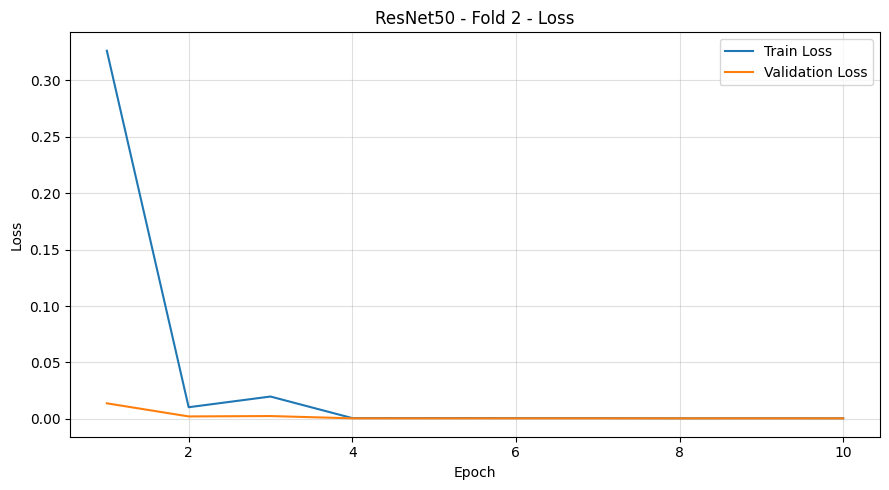

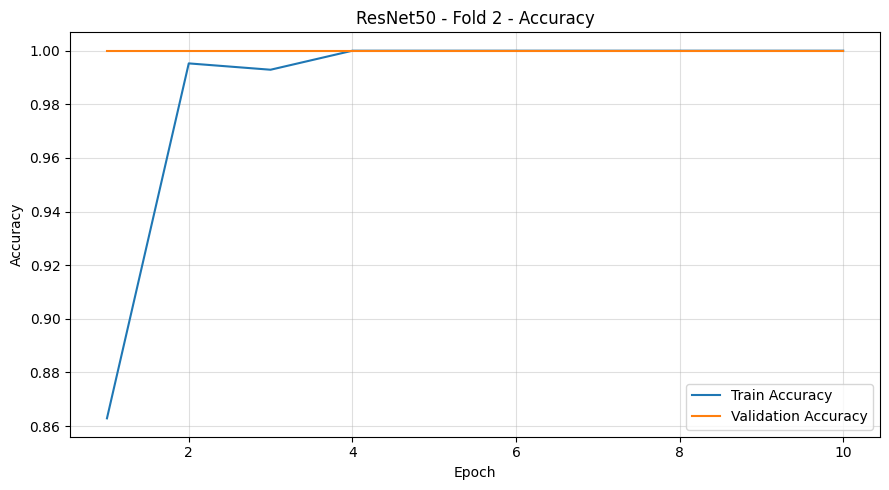

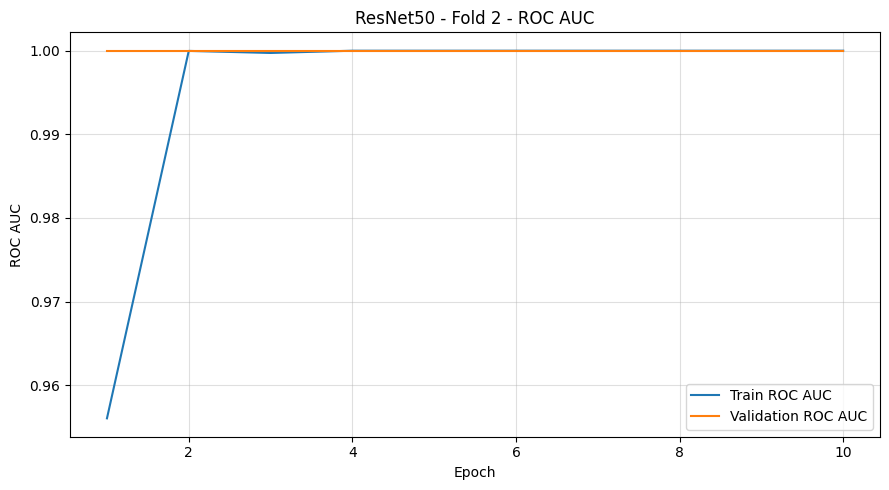

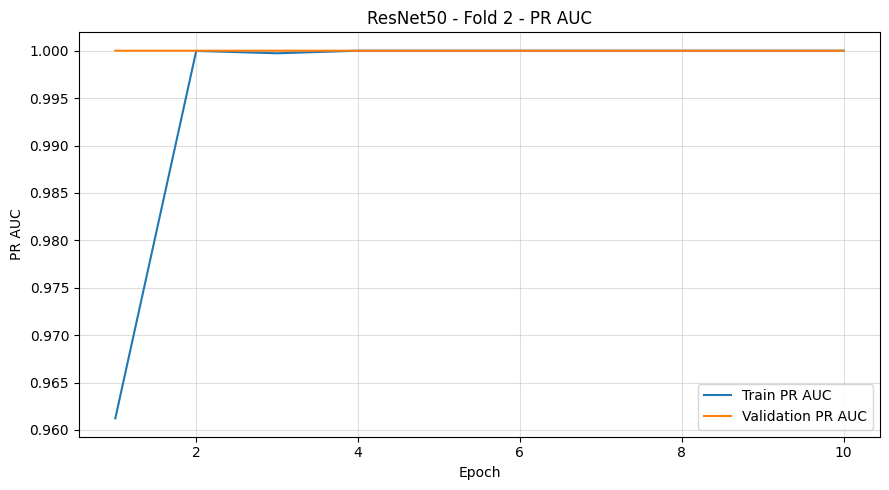

2/2 ━━━━━━━━━━━━━━━━━━━━ 5s 2s/step

Fold 02 | Acc: 1.0000 | Bal Acc: 1.0000 | F1: 1.0000 | ROC AUC: 1.0000 | PR AUC: 1.0000 | Log loss: 0.00000751 | Brier: 0.00000000 | ECE: 0.00000751


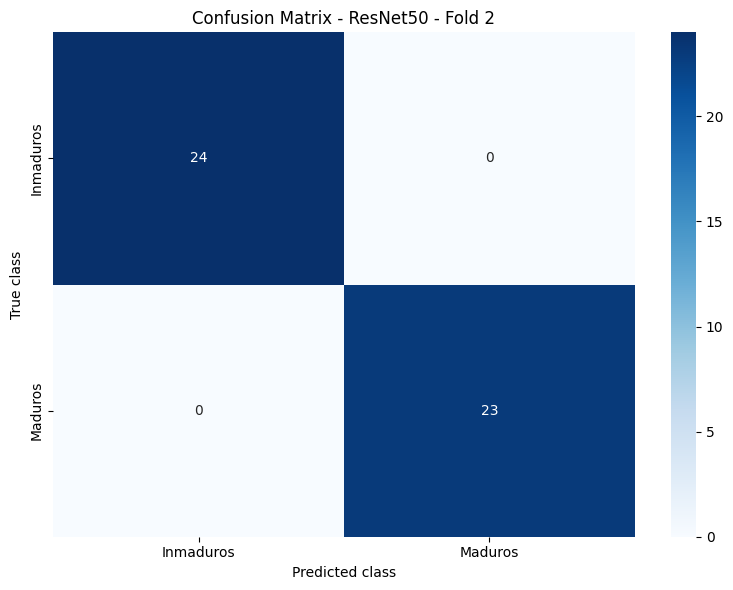

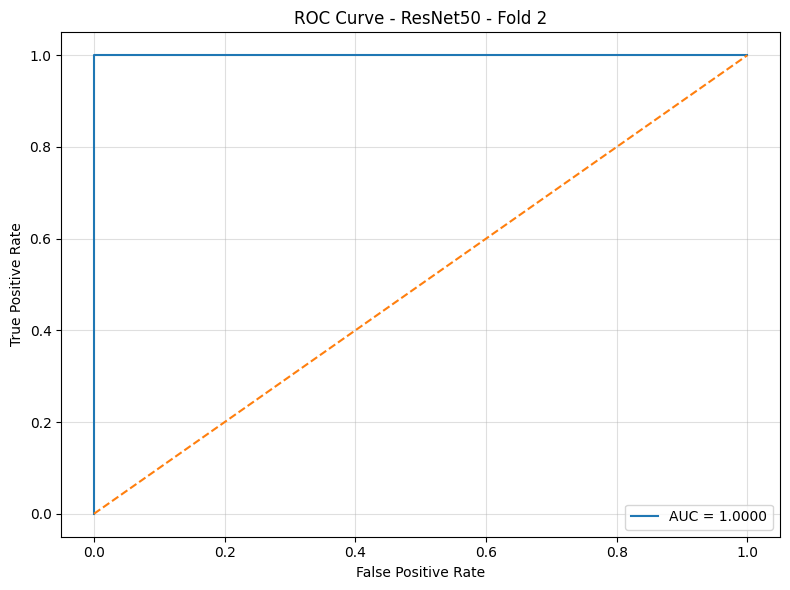

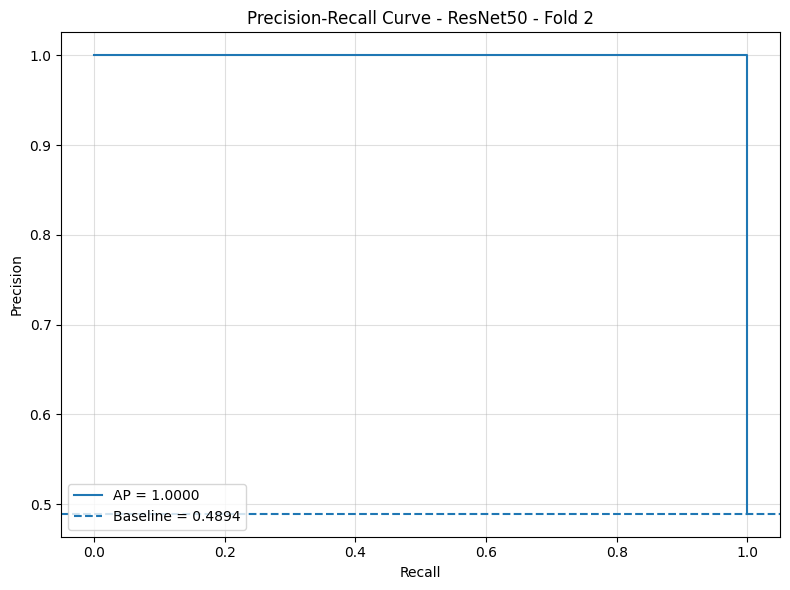

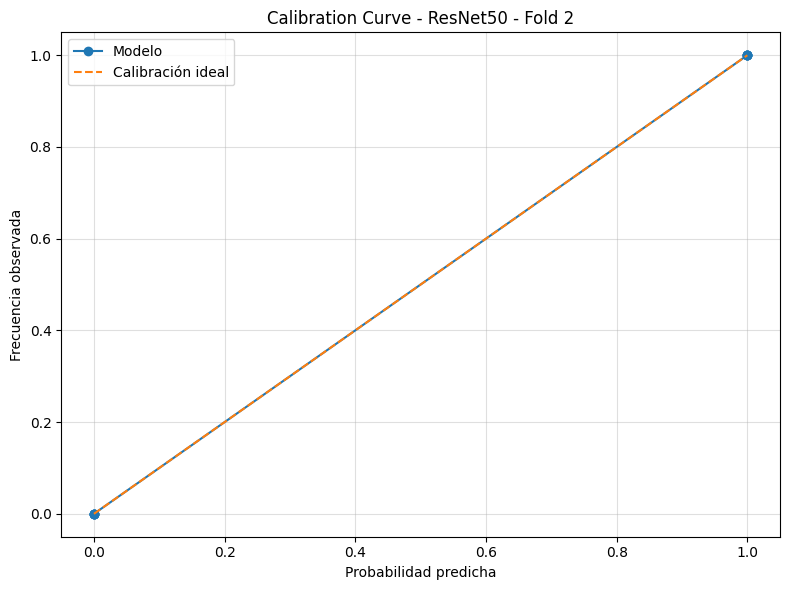

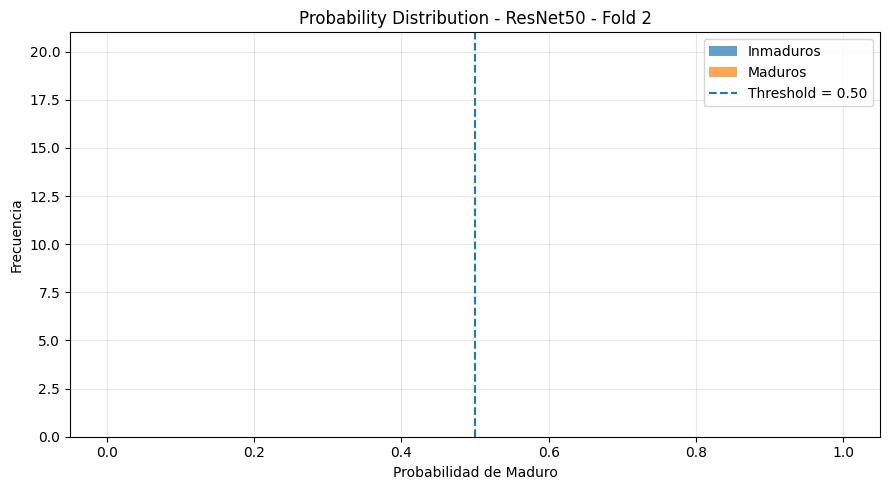

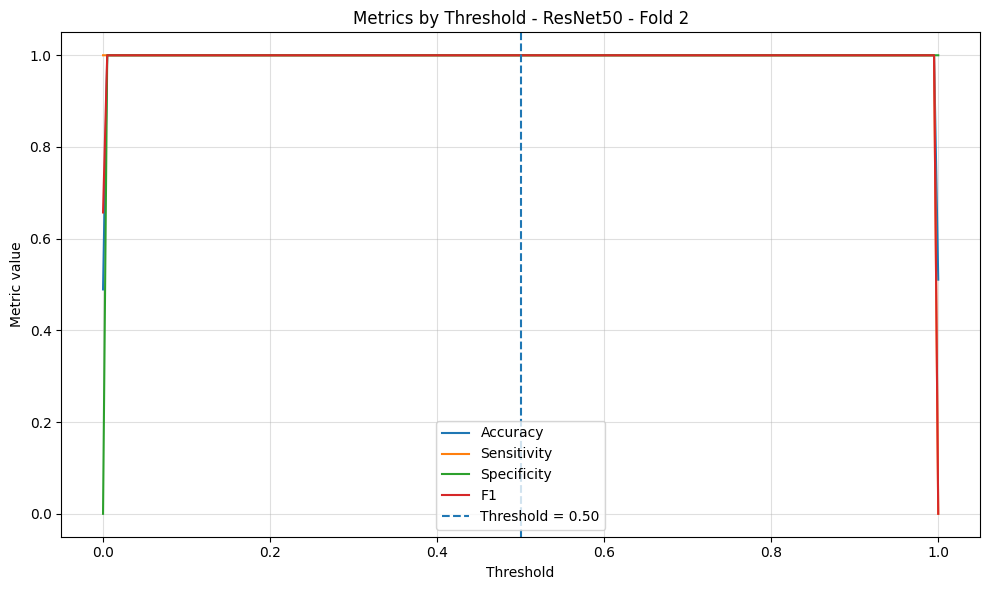


FOLD 3/10
------------------------------------------------------------------------
Epoch 1/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 29s 1s/step - accuracy: 0.9196 - auc: 0.9813 - loss: 0.2179 - pr_auc: 0.9799 - precision: 0.9320 - recall: 0.9057 - val_accuracy: 0.9787 - val_auc: 1.0000 - val_loss: 0.0200 - val_pr_auc: 1.0000 - val_precision: 1.0000 - val_recall: 0.9565
Epoch 2/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - accuracy: 1.0000 - auc: 1.0000 - loss: 0.0060 - pr_auc: 1.0000 - precision: 1.0000 - recall: 1.0000 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0010 - val_pr_auc: 1.0000 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 3/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - accuracy: 1.0000 - auc: 1.0000 - loss: 7.8245e-04 - pr_auc: 1.0000 - precision: 1.0000 - recall: 1.0000 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 5.7241e-04 - val_pr_auc: 1.0000 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 4/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - accuracy: 1.0000 - auc

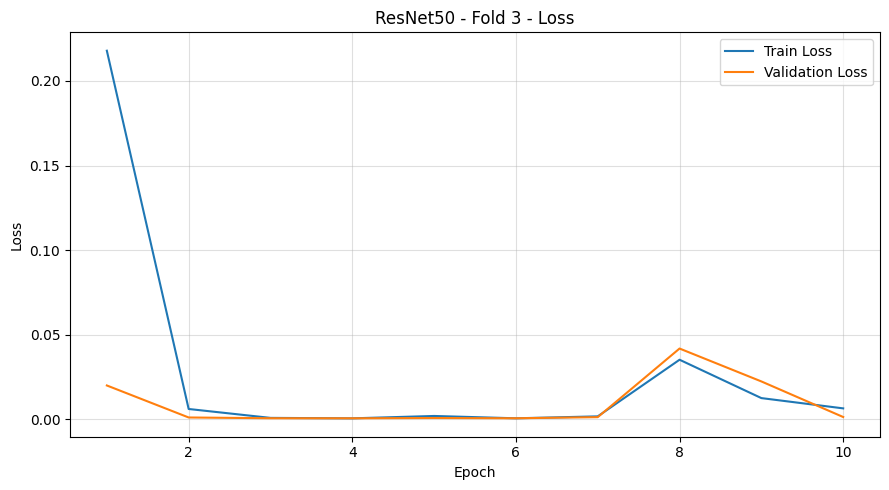

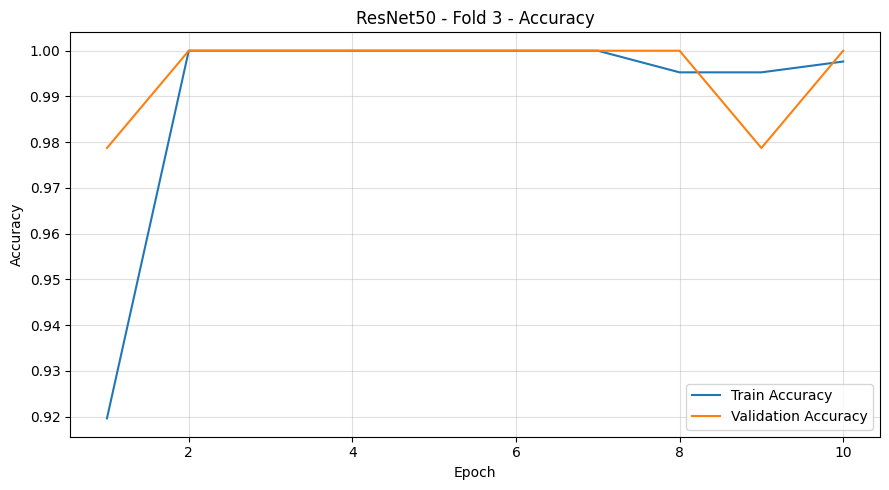

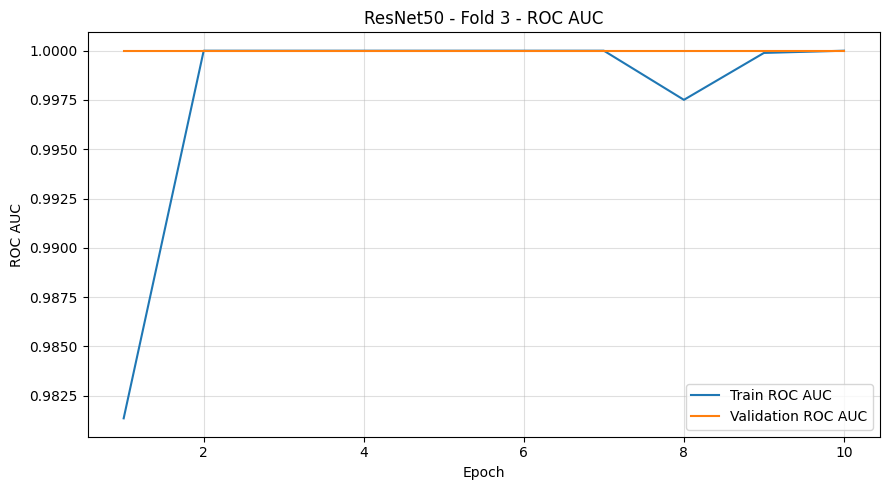

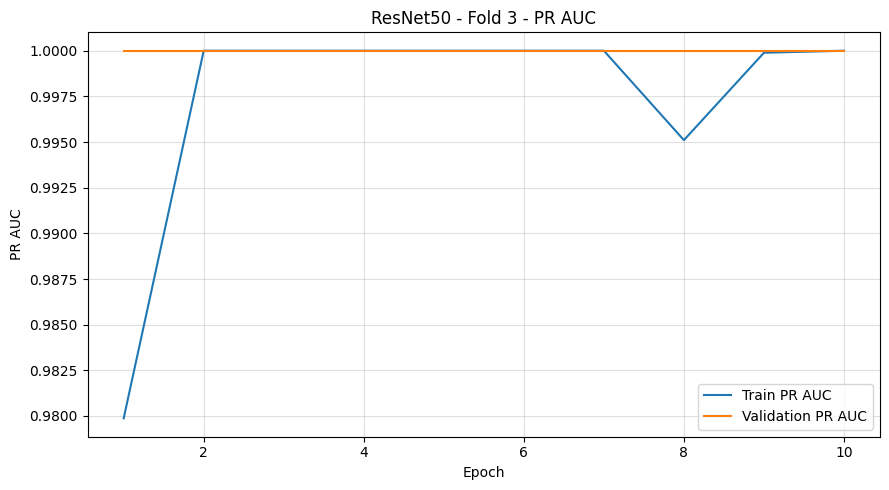

2/2 ━━━━━━━━━━━━━━━━━━━━ 4s 2s/step

Fold 03 | Acc: 1.0000 | Bal Acc: 1.0000 | F1: 1.0000 | ROC AUC: 1.0000 | PR AUC: 1.0000 | Log loss: 0.00081267 | Brier: 0.00002075 | ECE: 0.00080208


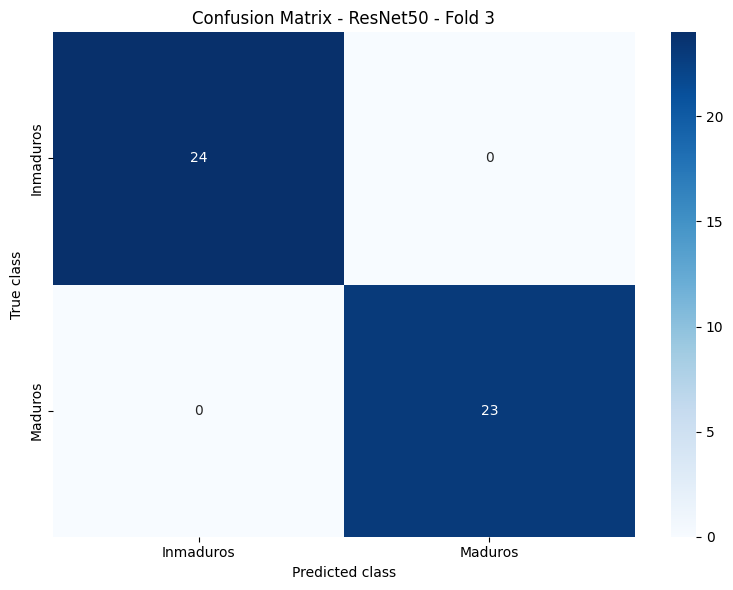

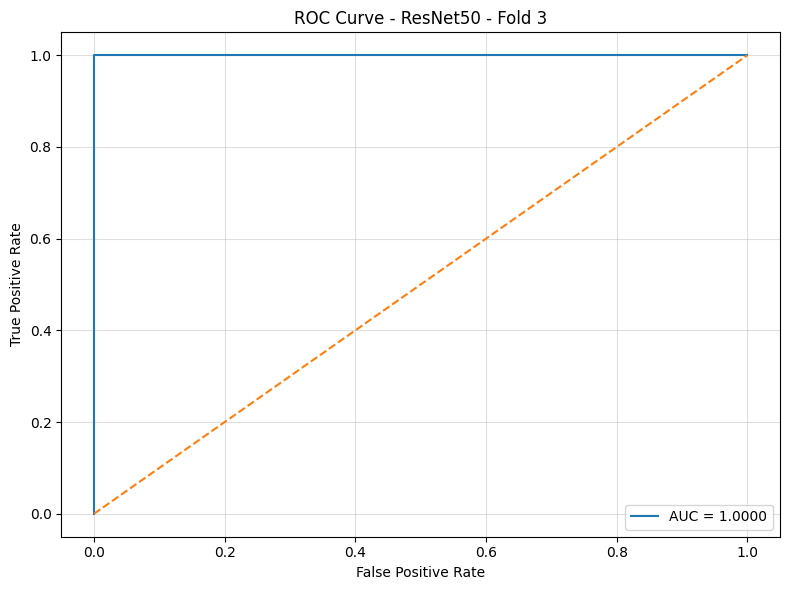

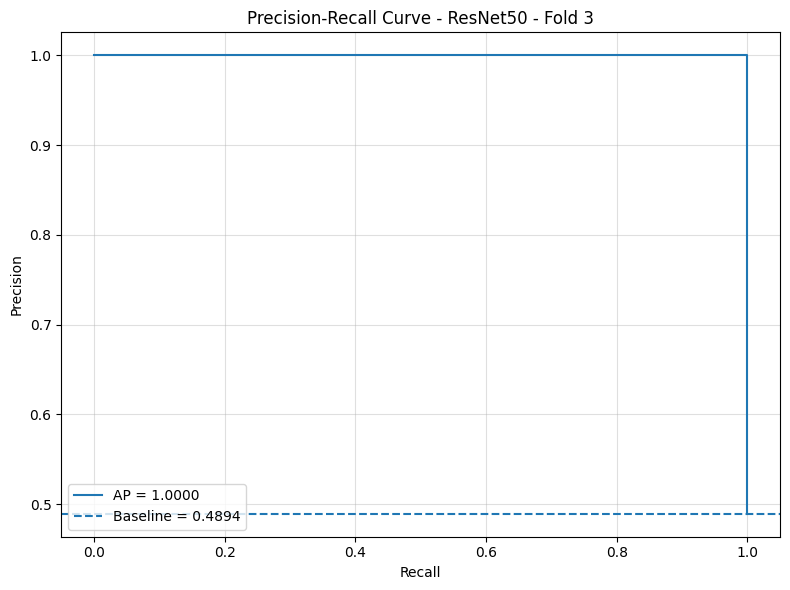

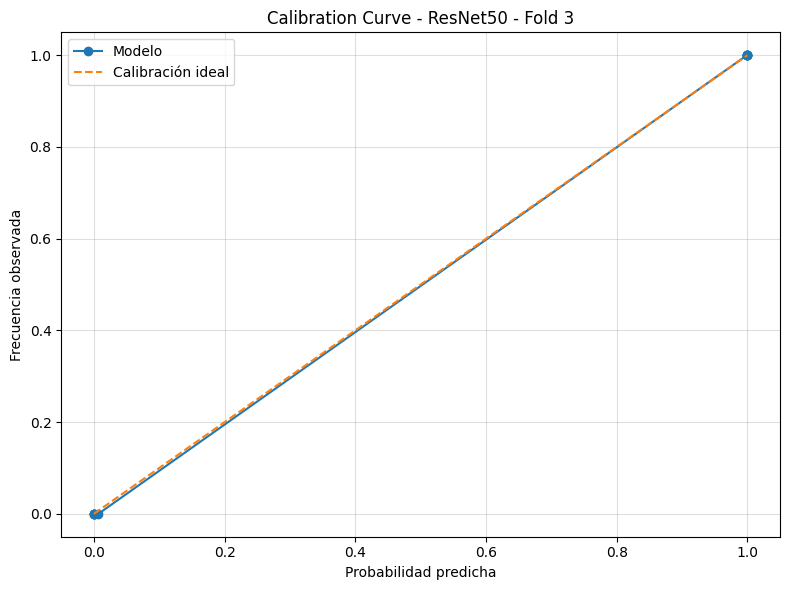

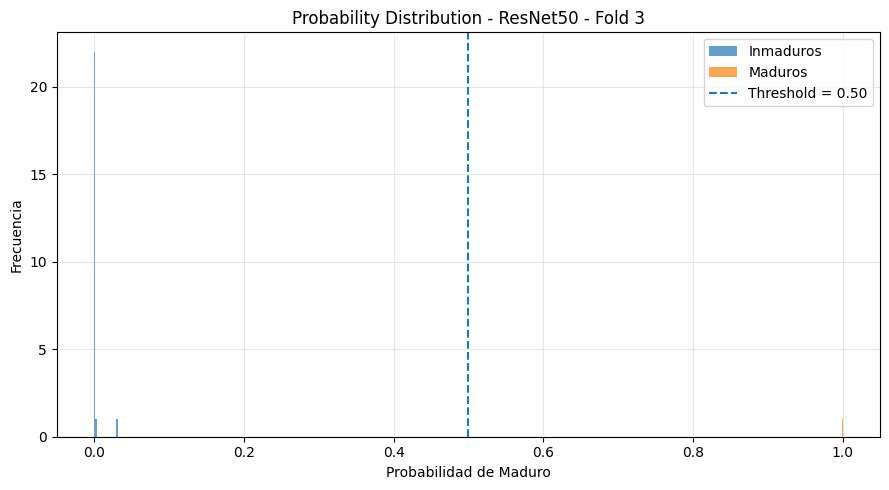

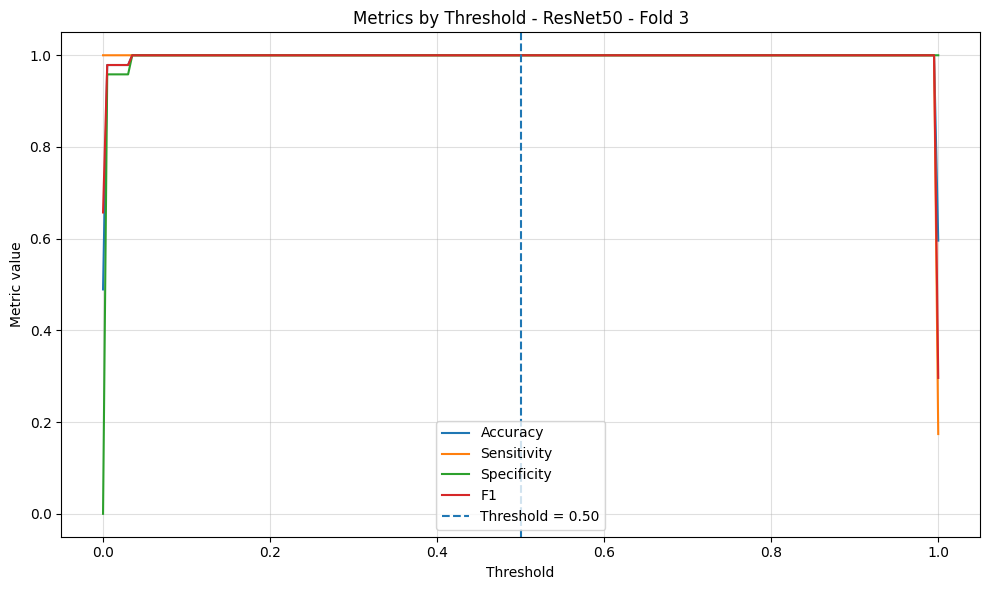


FOLD 4/10
------------------------------------------------------------------------
Epoch 1/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 29s 1s/step - accuracy: 0.9527 - auc: 0.9933 - loss: 0.1624 - pr_auc: 0.9938 - precision: 0.9948 - recall: 0.9104 - val_accuracy: 0.9787 - val_auc: 1.0000 - val_loss: 0.0209 - val_pr_auc: 1.0000 - val_precision: 0.9583 - val_recall: 1.0000
Epoch 2/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 17s 1s/step - accuracy: 0.9976 - auc: 1.0000 - loss: 0.0053 - pr_auc: 1.0000 - precision: 1.0000 - recall: 0.9953 - val_accuracy: 0.9787 - val_auc: 1.0000 - val_loss: 0.0158 - val_pr_auc: 1.0000 - val_precision: 0.9583 - val_recall: 1.0000
Epoch 3/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 17s 1s/step - accuracy: 1.0000 - auc: 1.0000 - loss: 9.5274e-04 - pr_auc: 1.0000 - precision: 1.0000 - recall: 1.0000 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0140 - val_pr_auc: 1.0000 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 4/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - accuracy: 1.0000 - auc: 1.

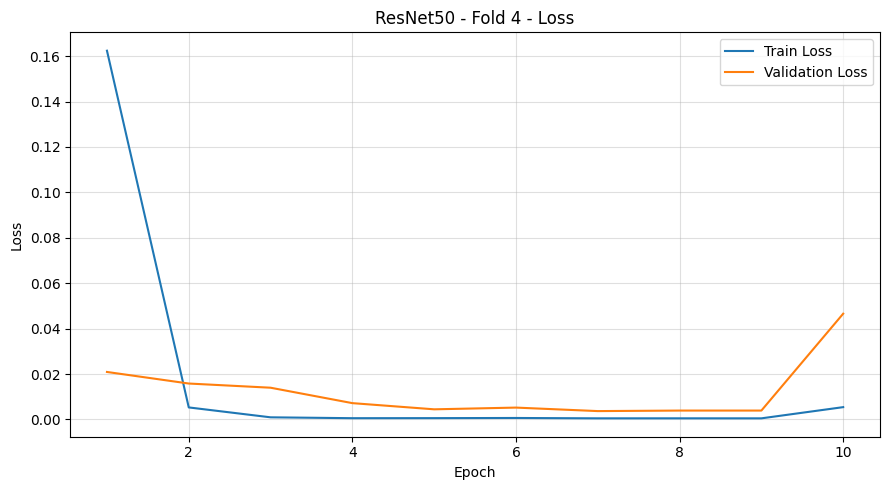

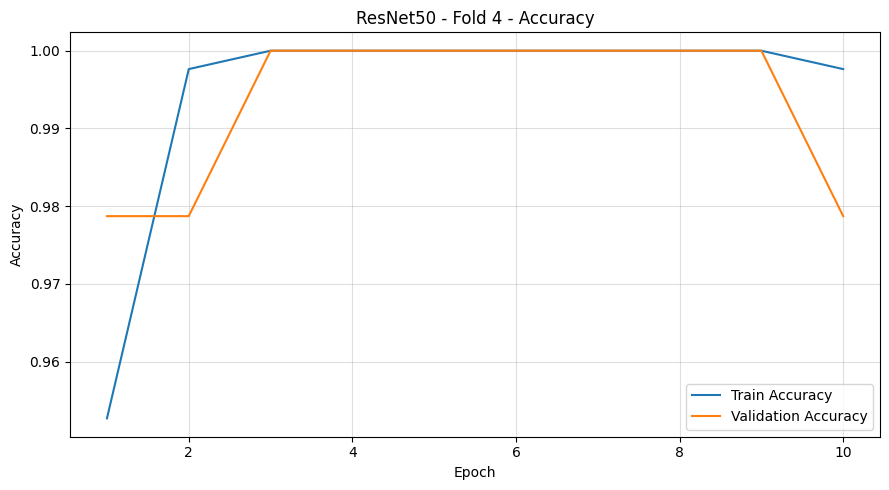

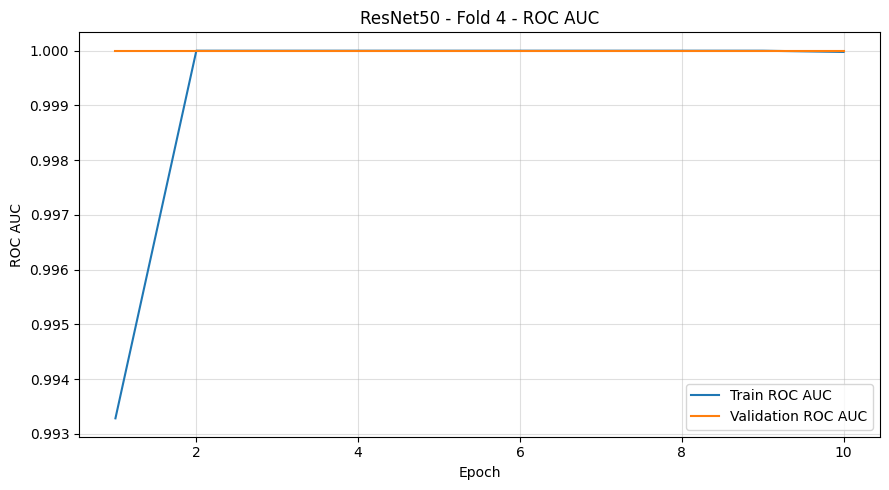

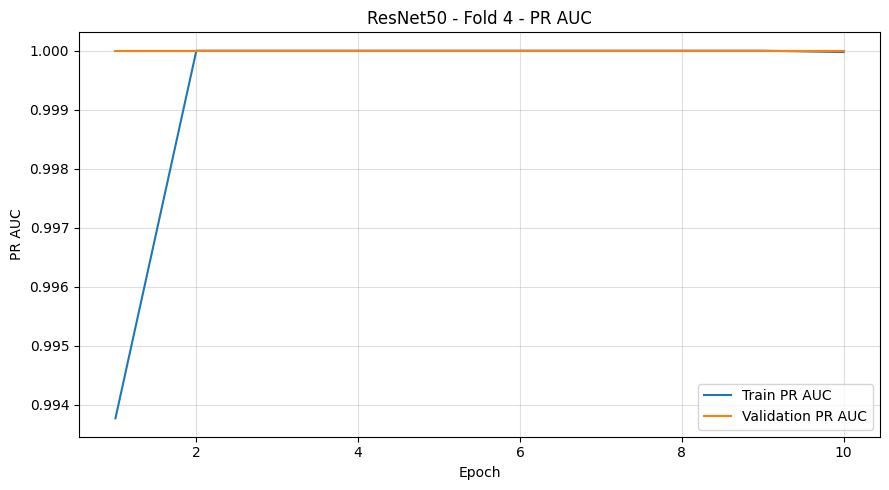

2/2 ━━━━━━━━━━━━━━━━━━━━ 4s 2s/step

Fold 04 | Acc: 0.9787 | Bal Acc: 0.9792 | F1: 0.9787 | ROC AUC: 1.0000 | PR AUC: 1.0000 | Log loss: 0.04609929 | Brier: 0.01668009 | ECE: 0.01884307


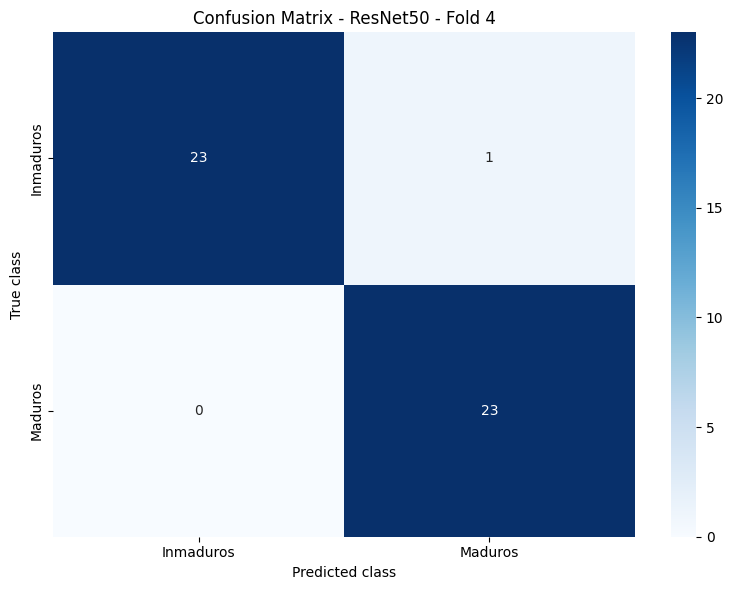

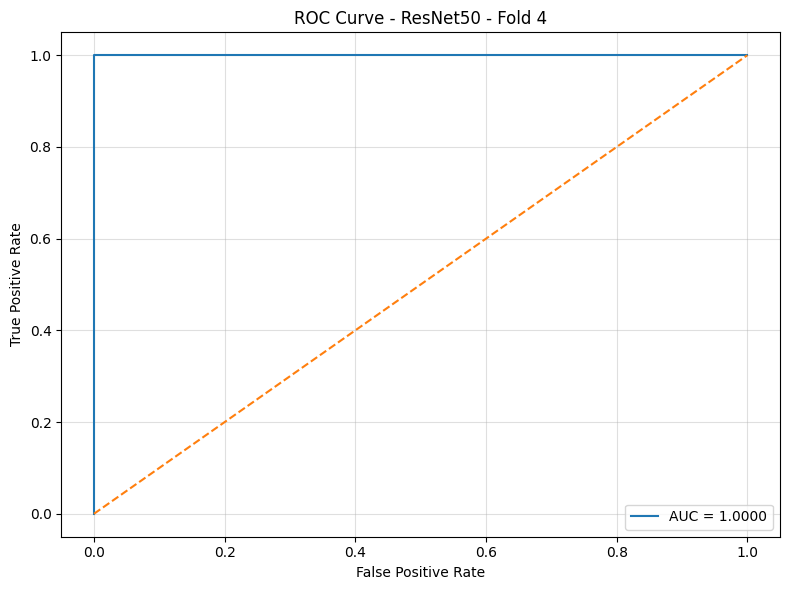

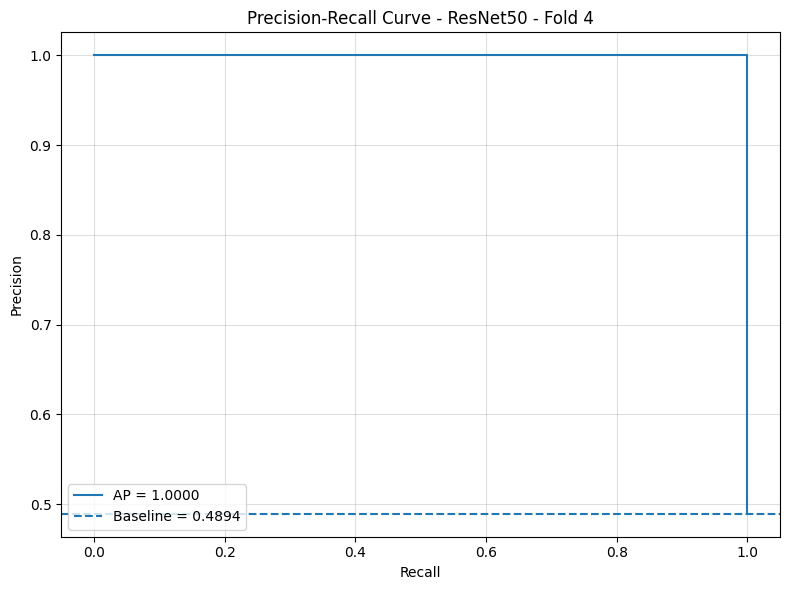

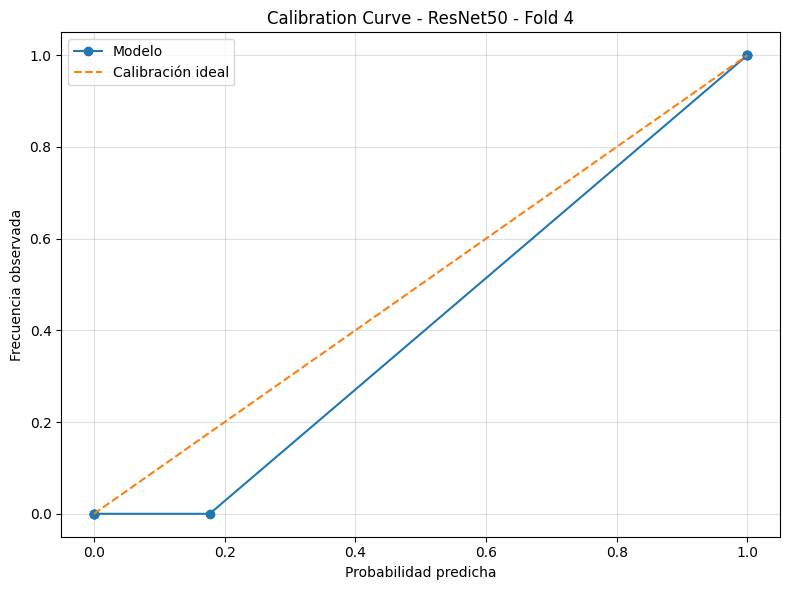

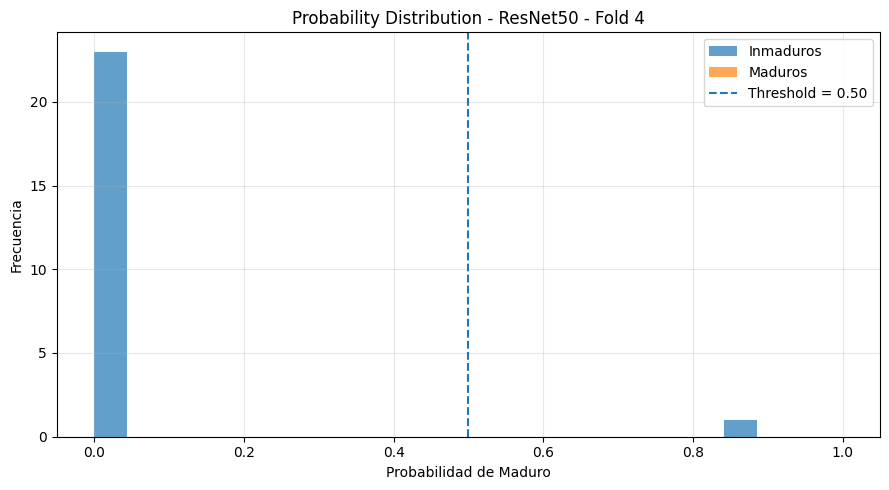

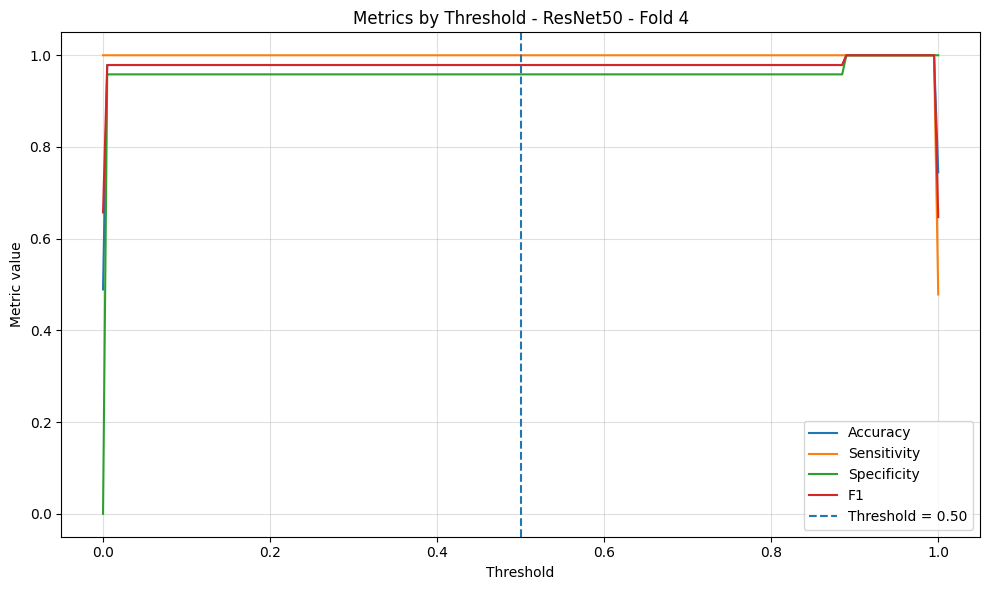


FOLD 5/10
------------------------------------------------------------------------
Epoch 1/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 29s 1s/step - accuracy: 0.8558 - auc: 0.9226 - loss: 0.3523 - pr_auc: 0.9076 - precision: 0.8545 - recall: 0.8585 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0227 - val_pr_auc: 1.0000 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 2/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - accuracy: 1.0000 - auc: 1.0000 - loss: 0.0098 - pr_auc: 1.0000 - precision: 1.0000 - recall: 1.0000 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0011 - val_pr_auc: 1.0000 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 3/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - accuracy: 1.0000 - auc: 1.0000 - loss: 0.0026 - pr_auc: 1.0000 - precision: 1.0000 - recall: 1.0000 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 6.2731e-04 - val_pr_auc: 1.0000 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 4/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - accuracy: 1.0000 - auc: 1.

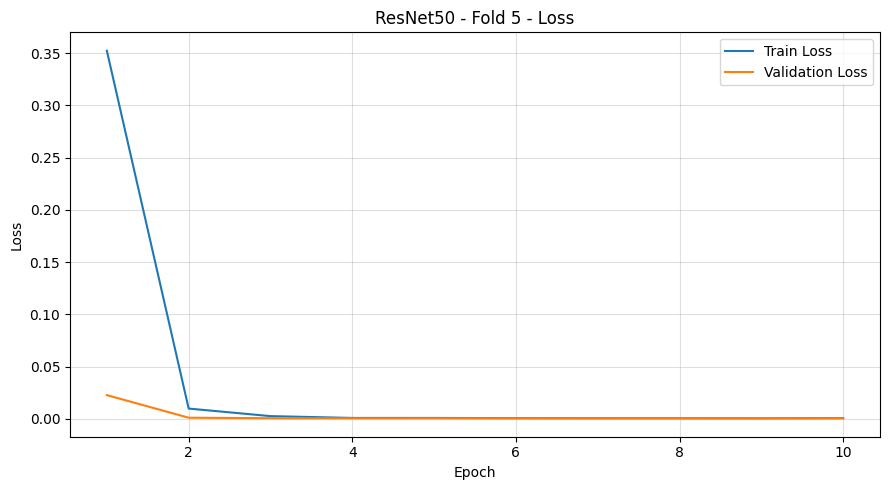

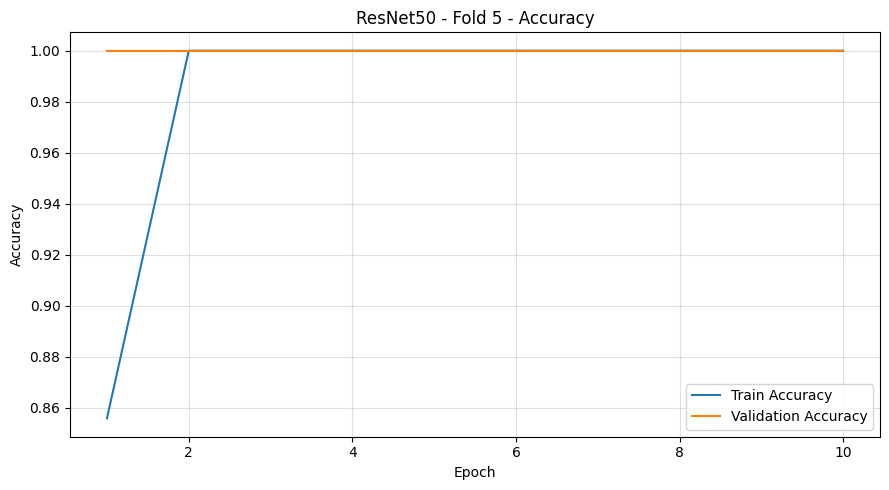

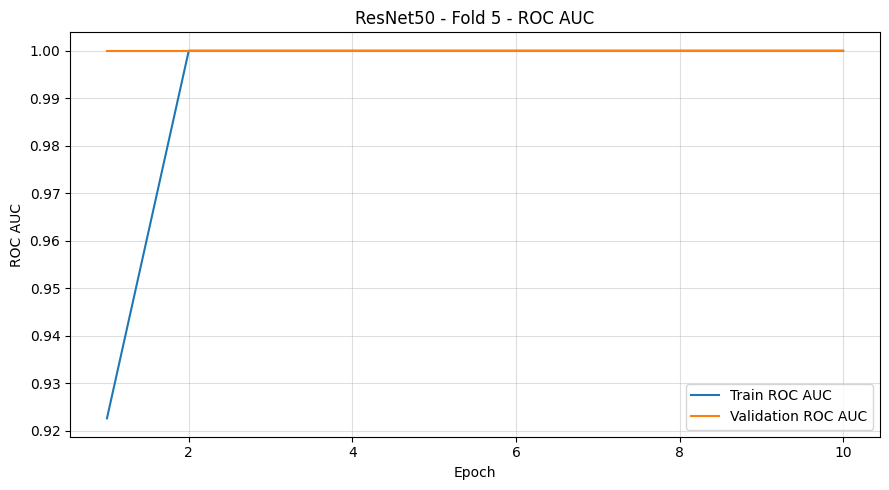

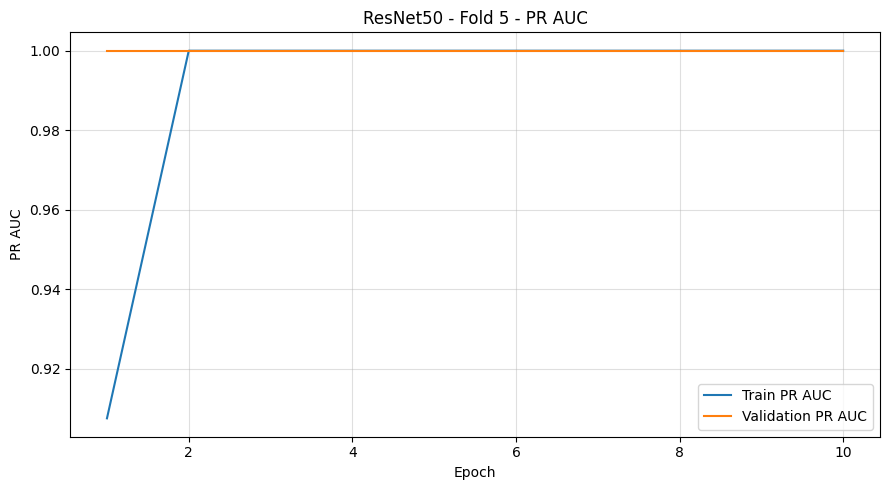

2/2 ━━━━━━━━━━━━━━━━━━━━ 4s 2s/step

Fold 05 | Acc: 1.0000 | Bal Acc: 1.0000 | F1: 1.0000 | ROC AUC: 1.0000 | PR AUC: 1.0000 | Log loss: 0.00008400 | Brier: 0.00000017 | ECE: 0.00008392


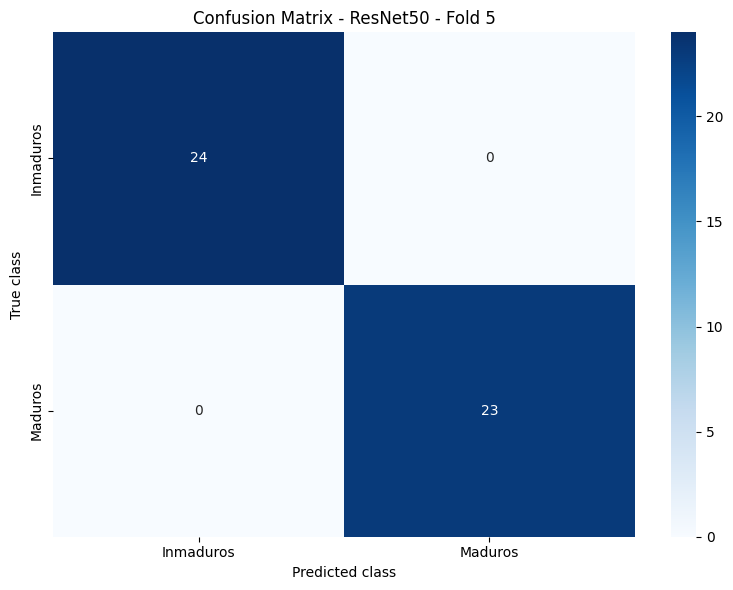

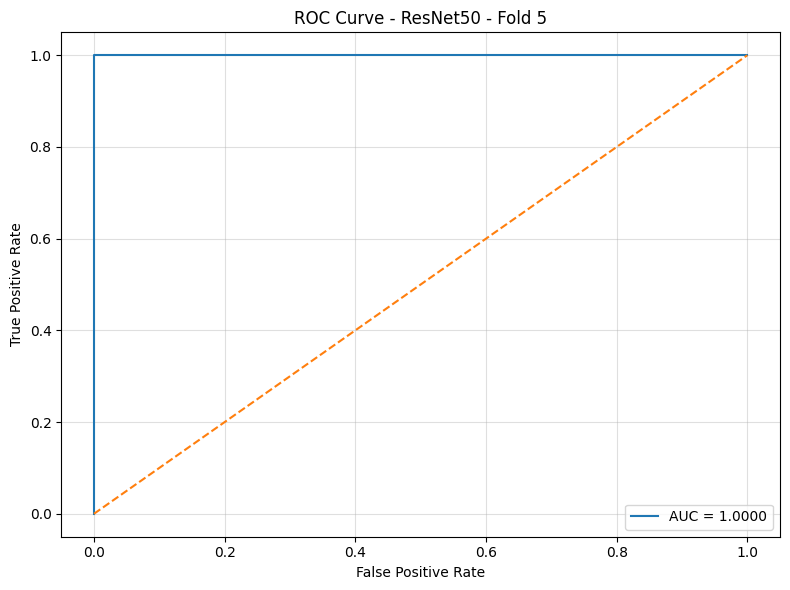

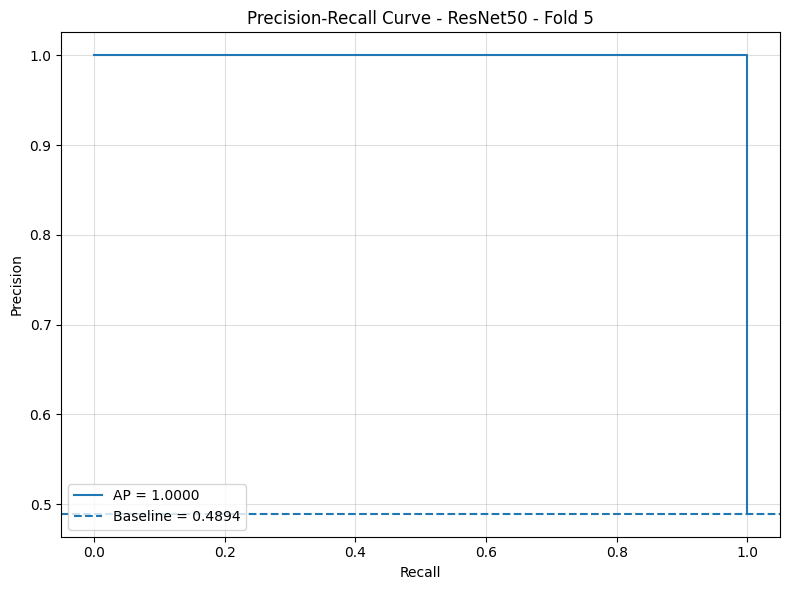

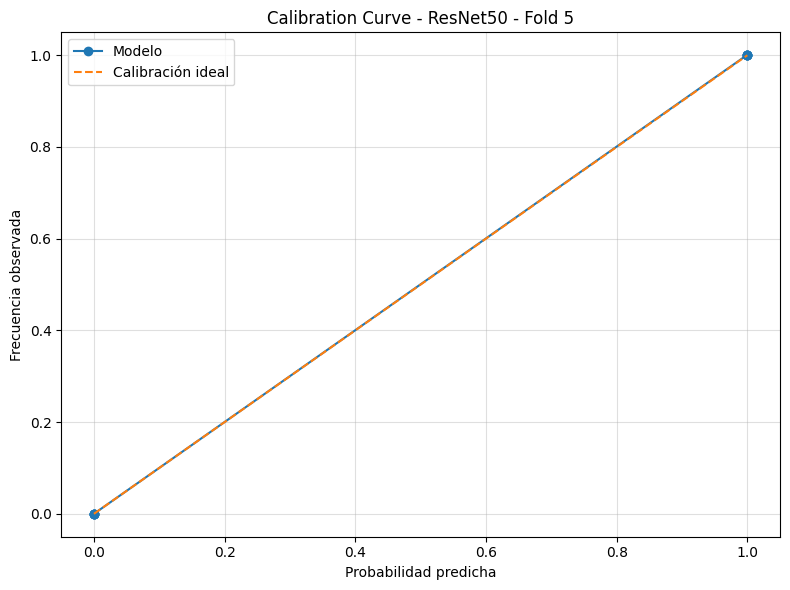

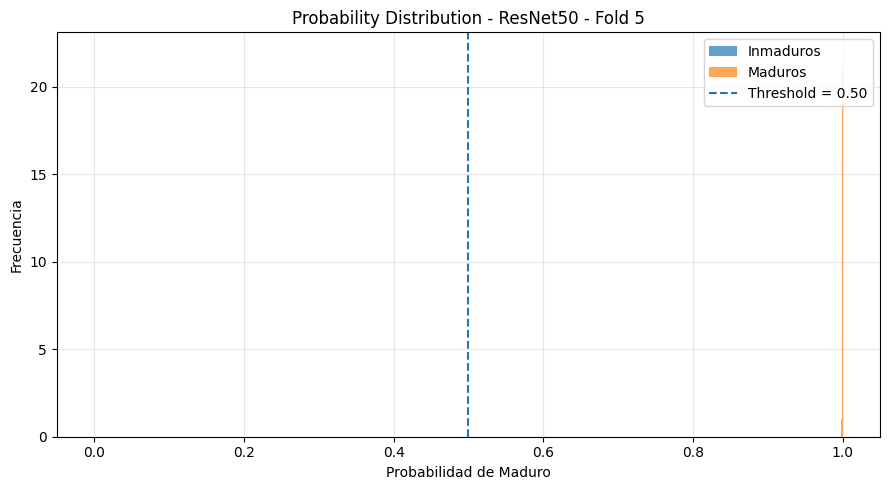

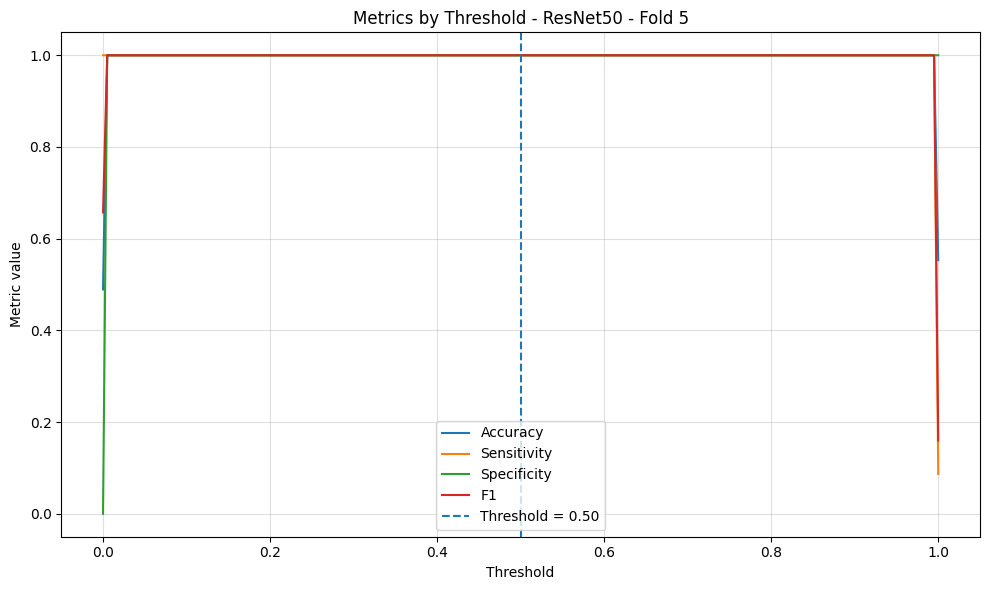


FOLD 6/10
------------------------------------------------------------------------
Epoch 1/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 29s 1s/step - accuracy: 0.9149 - auc: 0.9786 - loss: 0.2311 - pr_auc: 0.9770 - precision: 0.8924 - recall: 0.9431 - val_accuracy: 0.9574 - val_auc: 1.0000 - val_loss: 0.0899 - val_pr_auc: 1.0000 - val_precision: 0.9231 - val_recall: 1.0000
Epoch 2/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - accuracy: 0.9882 - auc: 0.9999 - loss: 0.0155 - pr_auc: 0.9999 - precision: 0.9858 - recall: 0.9905 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0039 - val_pr_auc: 1.0000 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 3/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - accuracy: 1.0000 - auc: 1.0000 - loss: 0.0015 - pr_auc: 1.0000 - precision: 1.0000 - recall: 1.0000 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0068 - val_pr_auc: 1.0000 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 4/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - accuracy: 1.0000 - auc: 1.0000

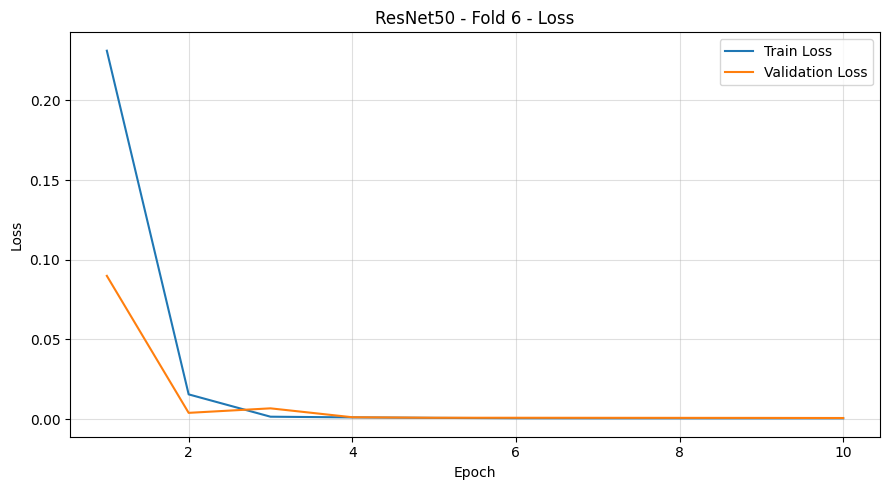

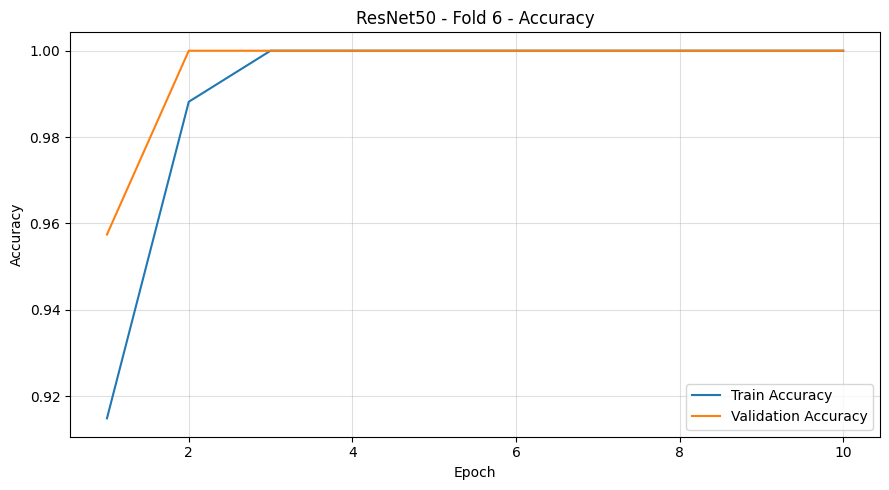

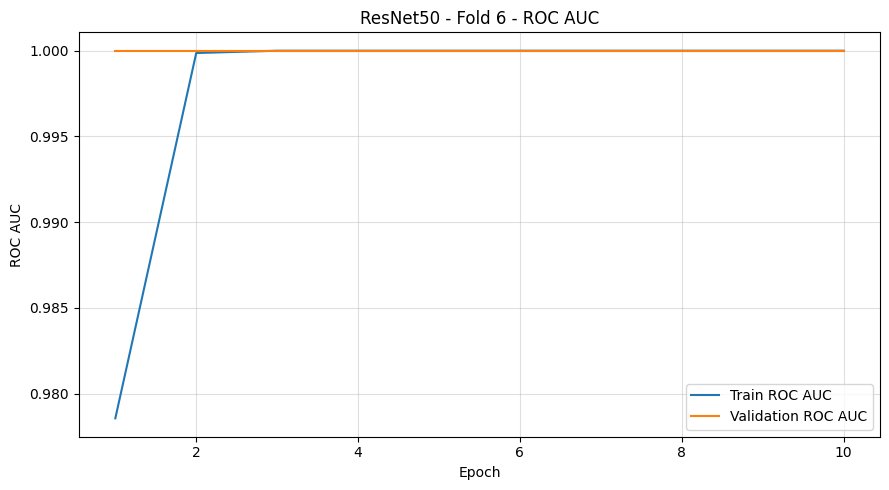

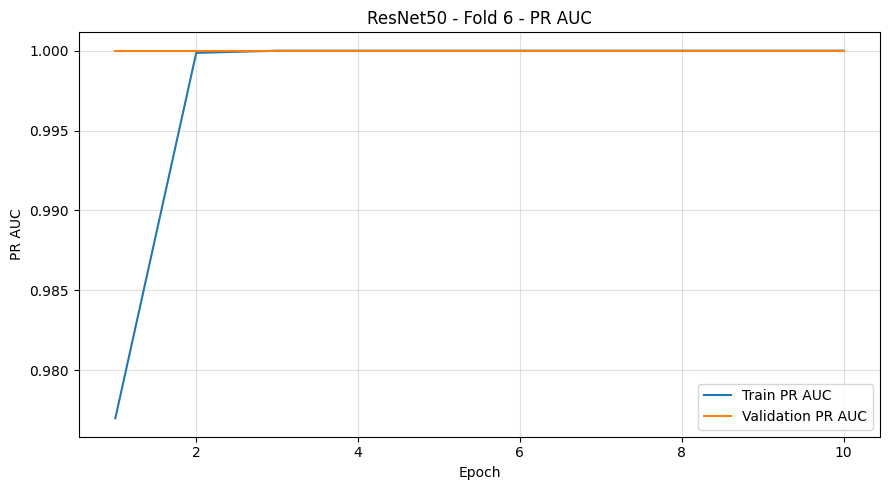

2/2 ━━━━━━━━━━━━━━━━━━━━ 4s 2s/step

Fold 06 | Acc: 1.0000 | Bal Acc: 1.0000 | F1: 1.0000 | ROC AUC: 1.0000 | PR AUC: 1.0000 | Log loss: 0.00022817 | Brier: 0.00000088 | ECE: 0.00022773


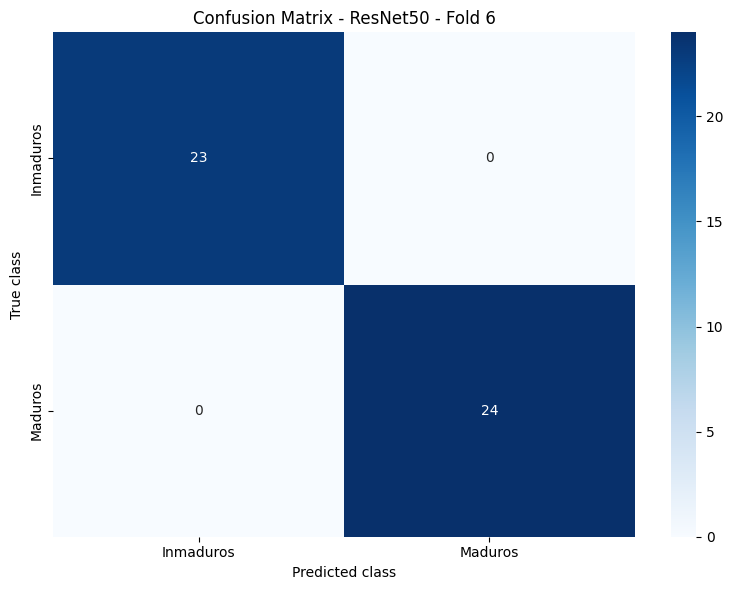

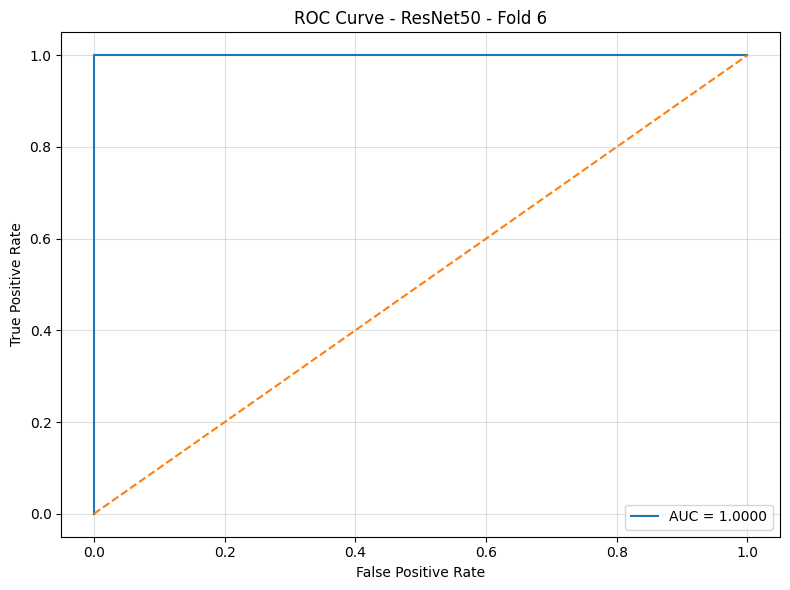

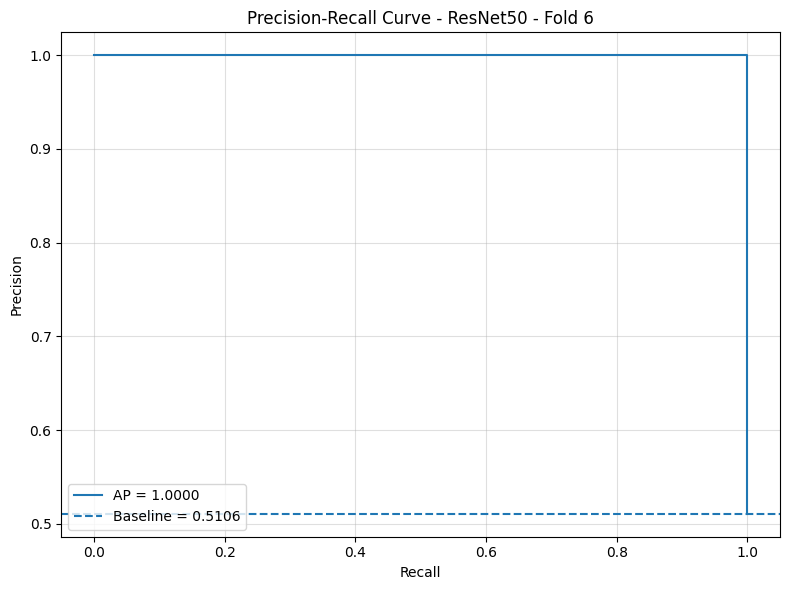

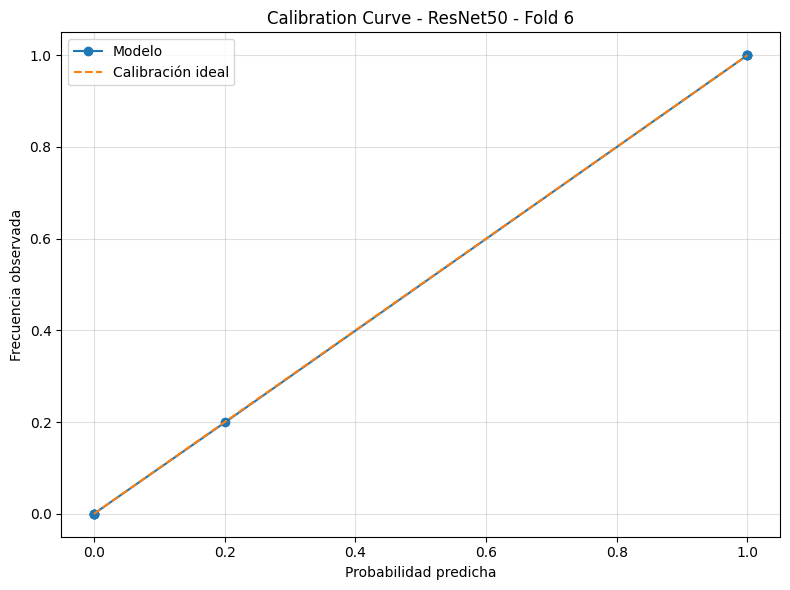

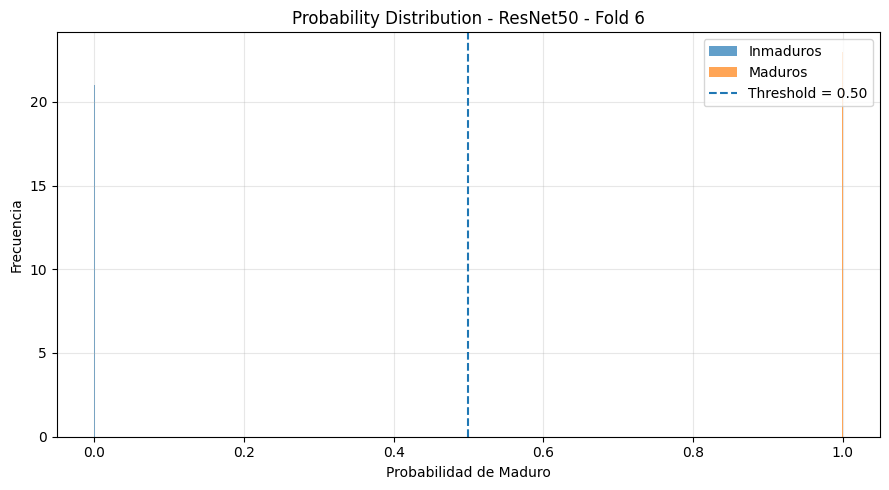

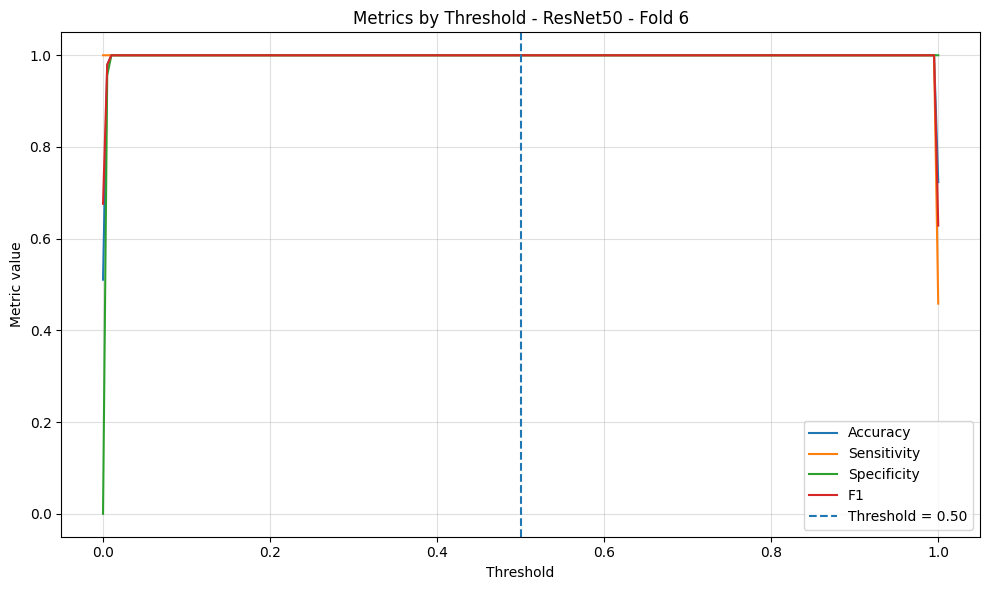


FOLD 7/10
------------------------------------------------------------------------
Epoch 1/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 29s 1s/step - accuracy: 0.8392 - auc: 0.9085 - loss: 0.3830 - pr_auc: 0.8890 - precision: 0.7895 - recall: 0.9242 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0504 - val_pr_auc: 1.0000 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 2/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 17s 1s/step - accuracy: 1.0000 - auc: 1.0000 - loss: 0.0168 - pr_auc: 1.0000 - precision: 1.0000 - recall: 1.0000 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 9.0660e-04 - val_pr_auc: 1.0000 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 3/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 17s 1s/step - accuracy: 1.0000 - auc: 1.0000 - loss: 0.0039 - pr_auc: 1.0000 - precision: 1.0000 - recall: 1.0000 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 5.7372e-04 - val_pr_auc: 1.0000 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 4/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - accuracy: 1.0000 - auc

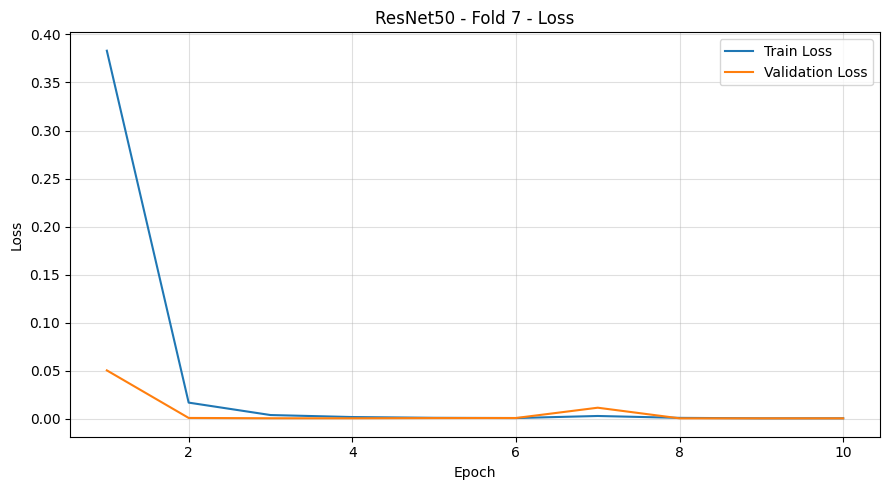

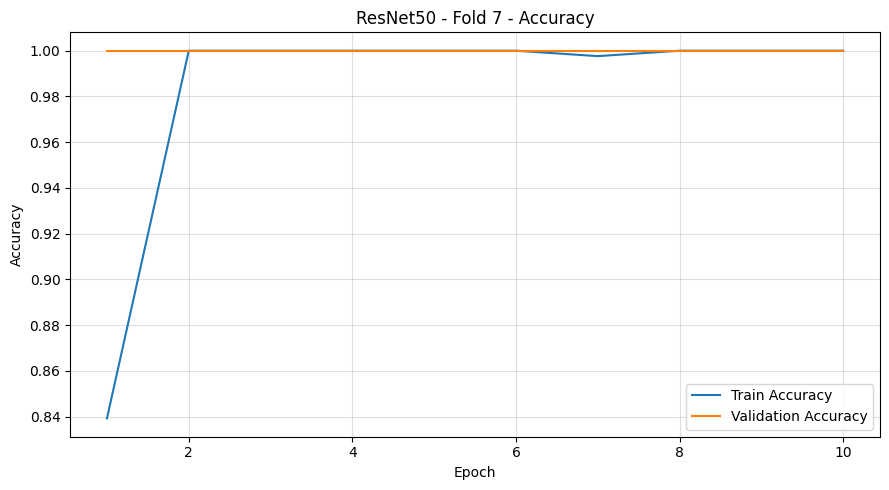

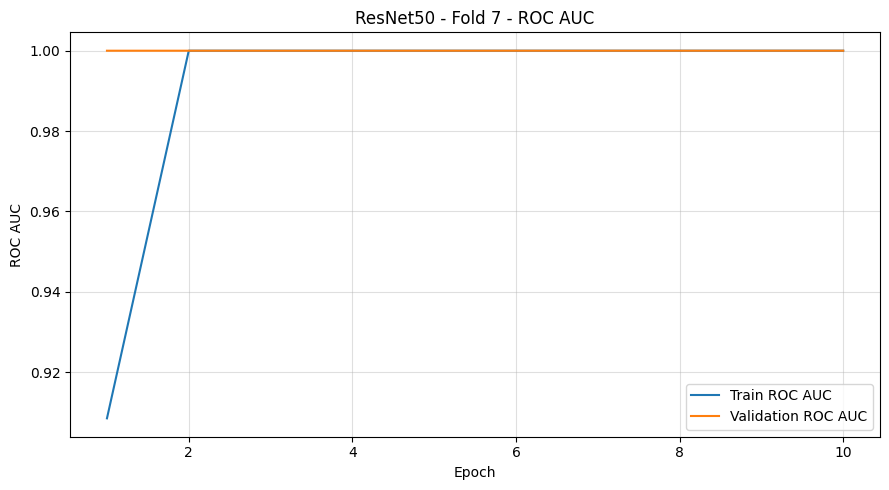

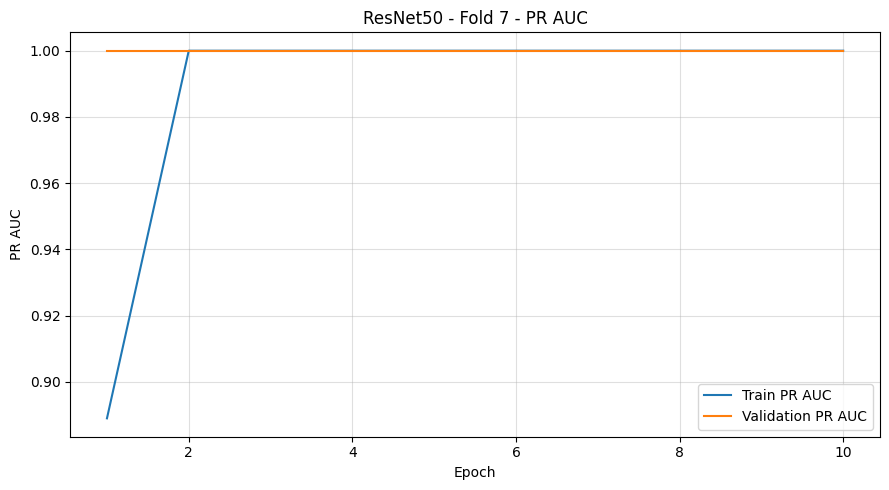

2/2 ━━━━━━━━━━━━━━━━━━━━ 4s 2s/step

Fold 07 | Acc: 1.0000 | Bal Acc: 1.0000 | F1: 1.0000 | ROC AUC: 1.0000 | PR AUC: 1.0000 | Log loss: 0.00000178 | Brier: 0.00000000 | ECE: 0.00000178


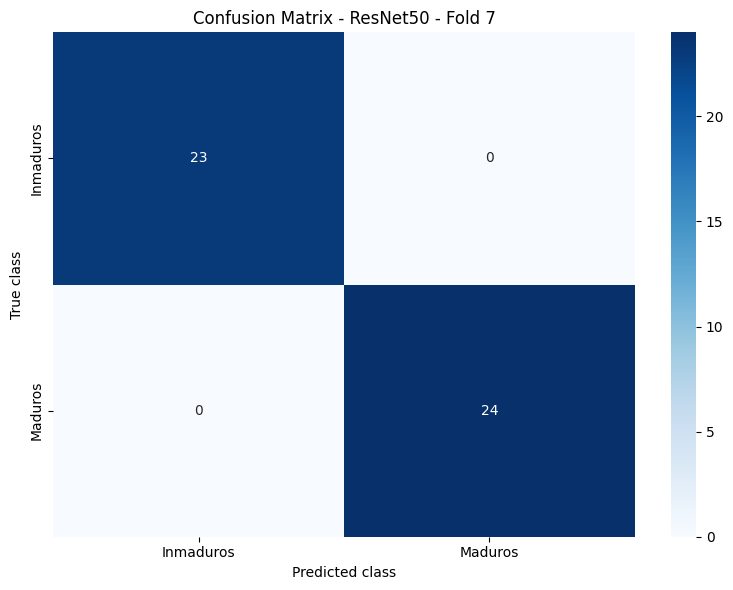

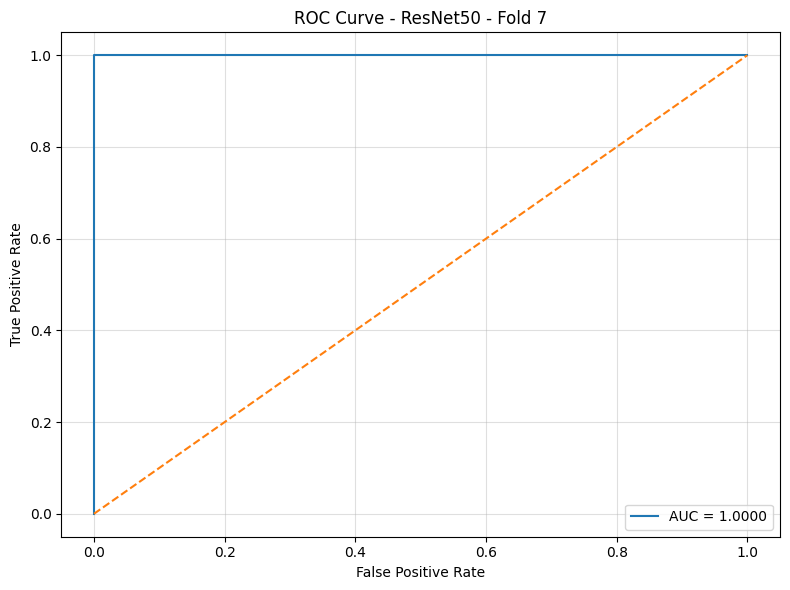

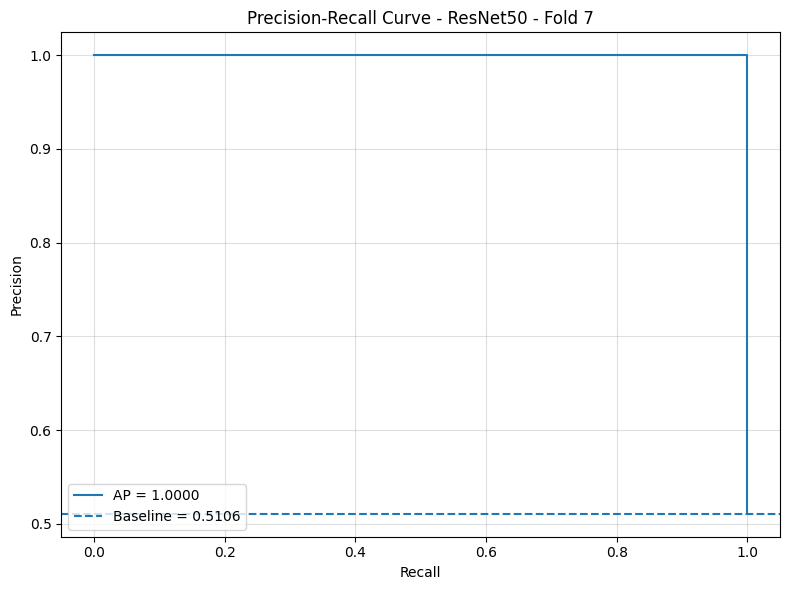

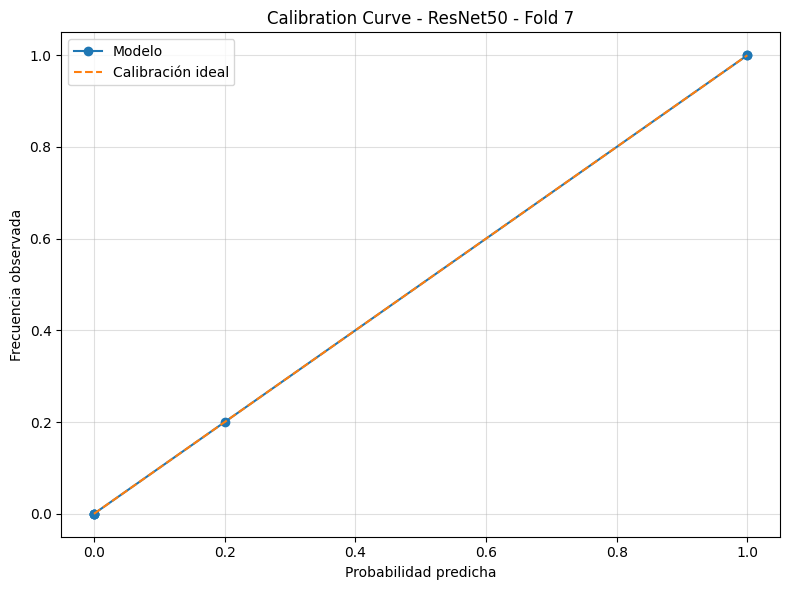

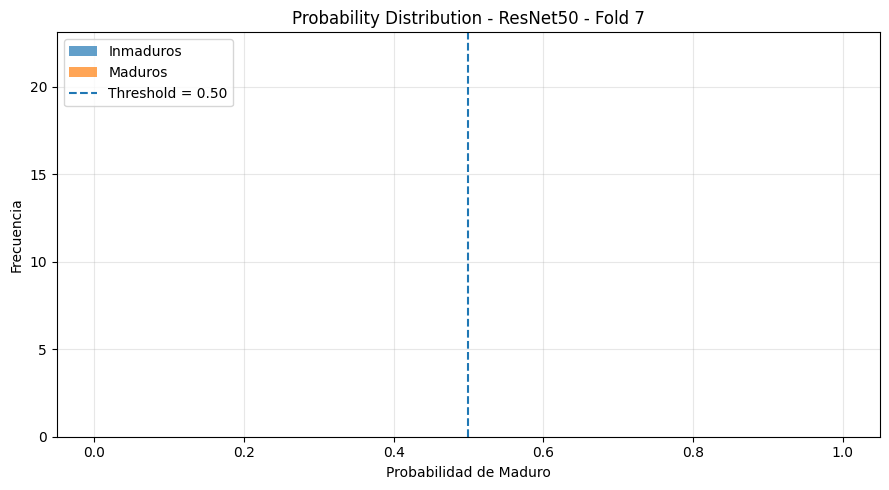

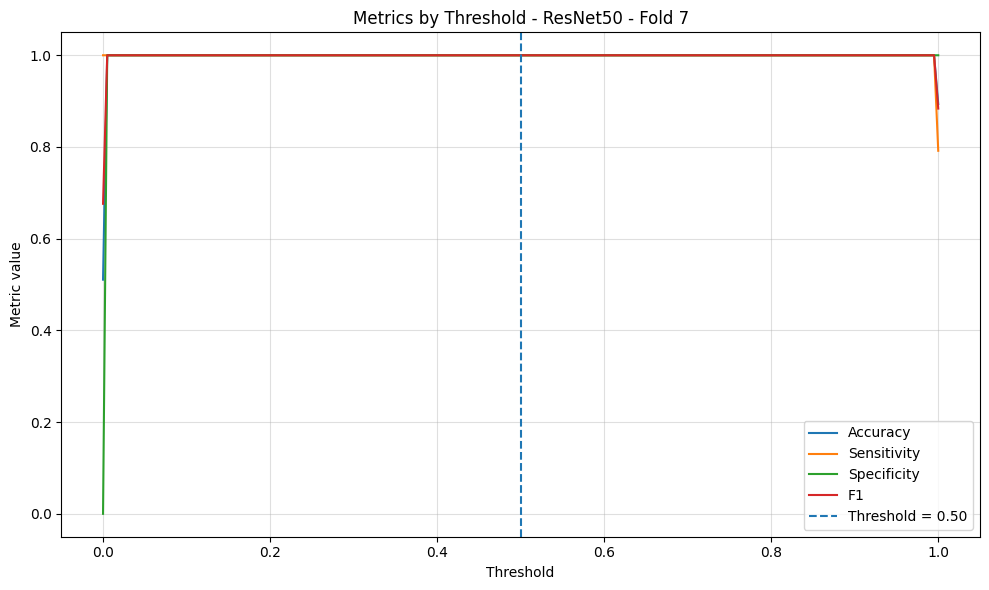


FOLD 8/10
------------------------------------------------------------------------
Epoch 1/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 29s 1s/step - accuracy: 0.8676 - auc: 0.9590 - loss: 0.2957 - pr_auc: 0.9633 - precision: 0.9586 - recall: 0.7678 - val_accuracy: 0.9362 - val_auc: 1.0000 - val_loss: 0.0962 - val_pr_auc: 1.0000 - val_precision: 0.8889 - val_recall: 1.0000
Epoch 2/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - accuracy: 0.9929 - auc: 0.9998 - loss: 0.0154 - pr_auc: 0.9998 - precision: 0.9906 - recall: 0.9953 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0035 - val_pr_auc: 1.0000 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 3/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - accuracy: 0.9976 - auc: 1.0000 - loss: 0.0056 - pr_auc: 1.0000 - precision: 1.0000 - recall: 0.9953 - val_accuracy: 0.9574 - val_auc: 0.9783 - val_loss: 0.1476 - val_pr_auc: 0.9600 - val_precision: 0.9231 - val_recall: 1.0000
Epoch 4/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 17s 1s/step - accuracy: 1.0000 - auc: 1.0000

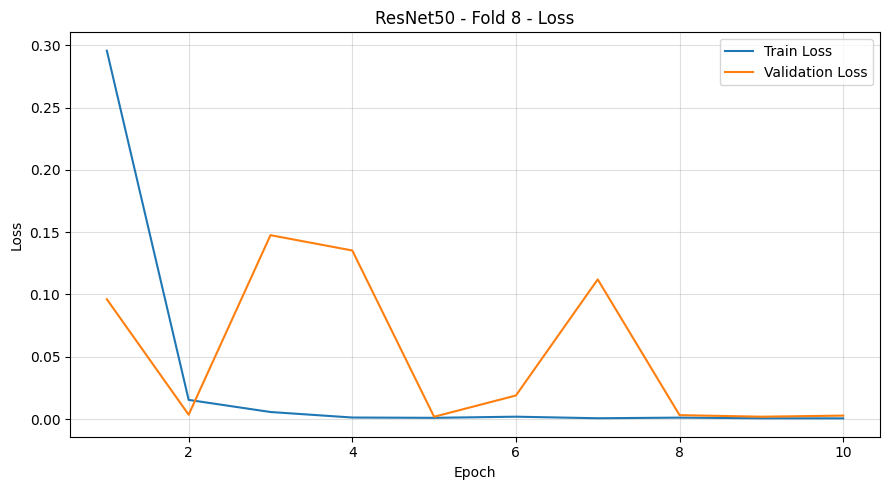

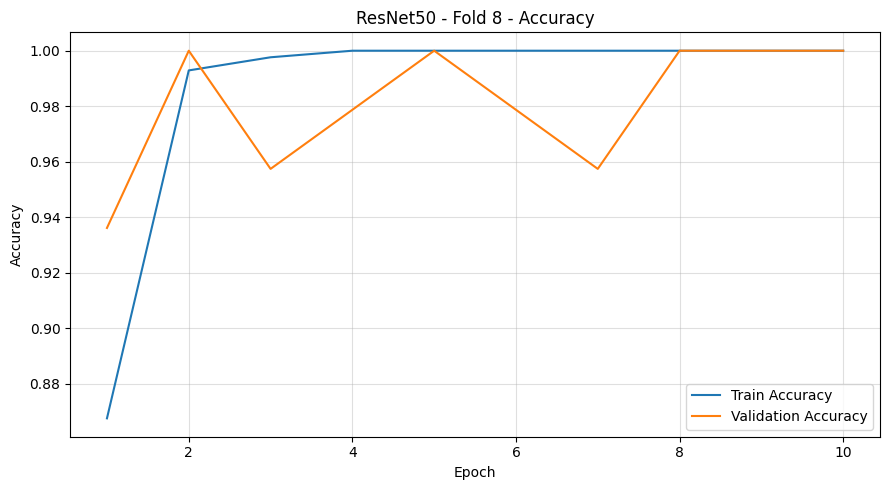

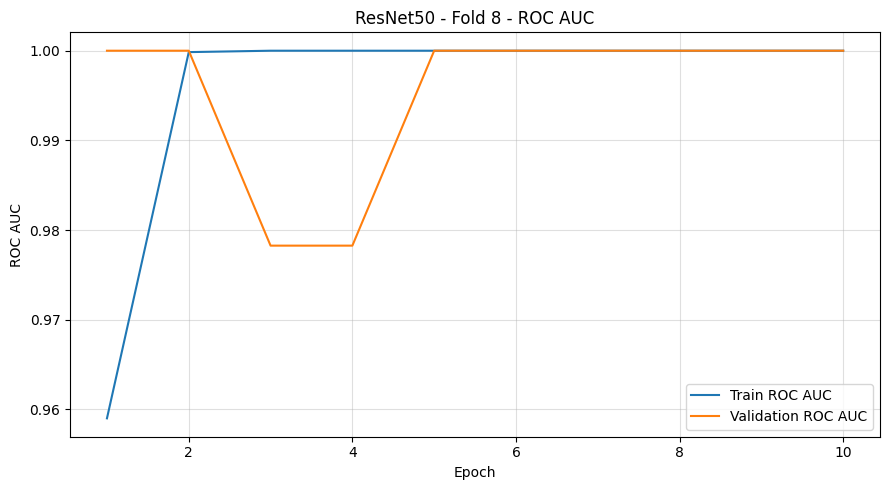

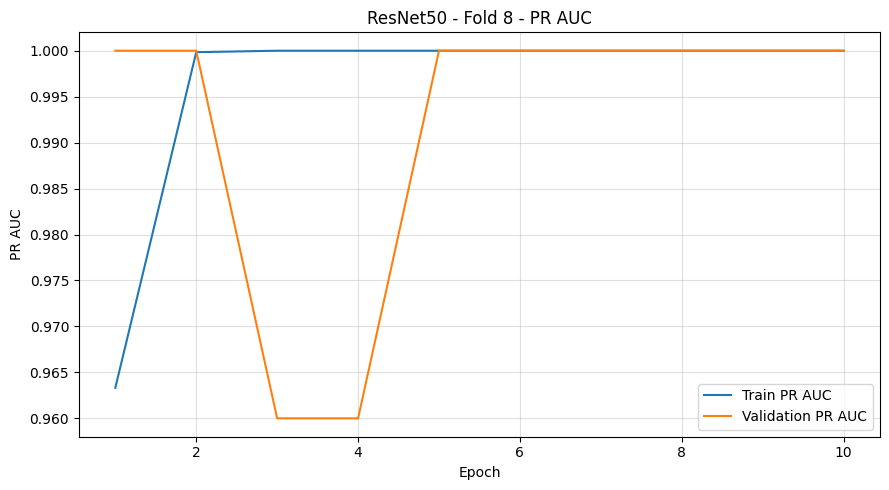

2/2 ━━━━━━━━━━━━━━━━━━━━ 6s 2s/step

Fold 08 | Acc: 1.0000 | Bal Acc: 1.0000 | F1: 1.0000 | ROC AUC: 1.0000 | PR AUC: 1.0000 | Log loss: 0.00225044 | Brier: 0.00020121 | ECE: 0.00214281


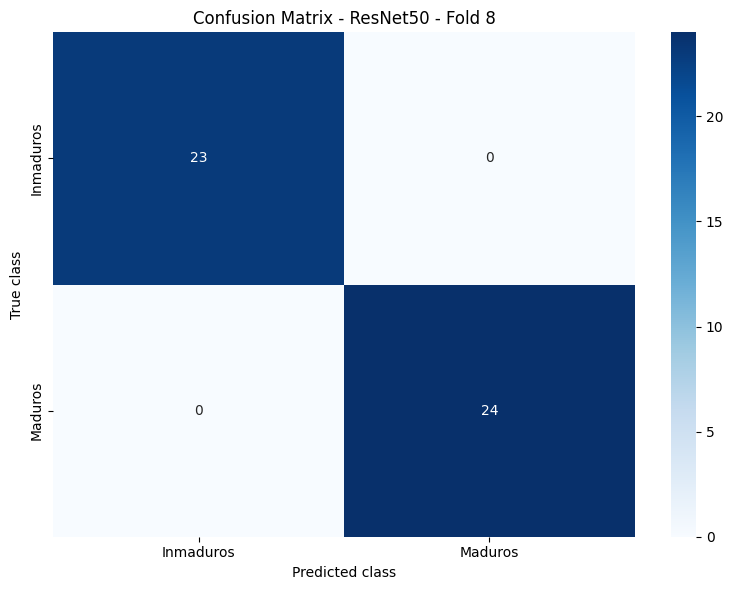

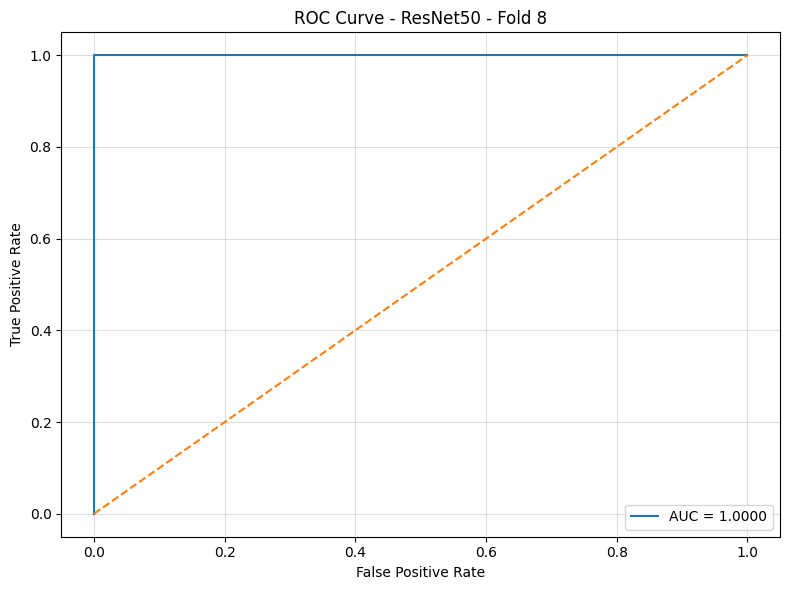

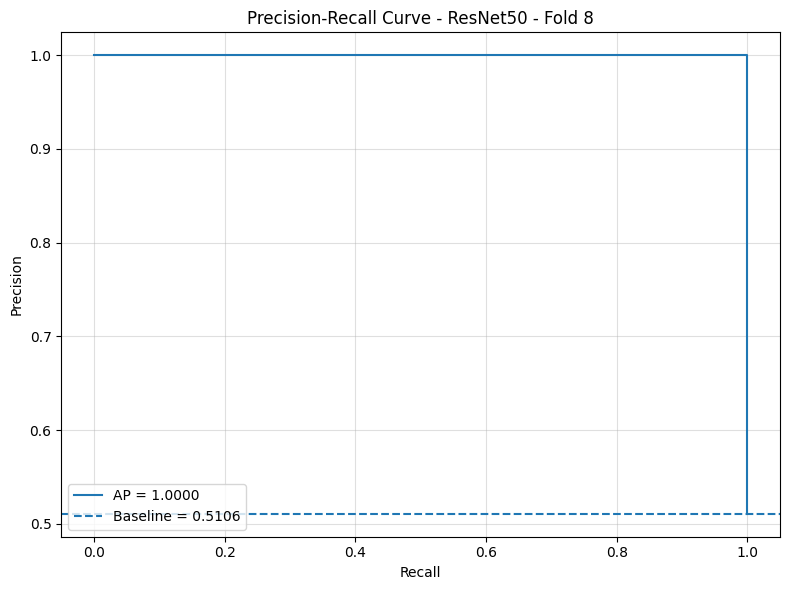

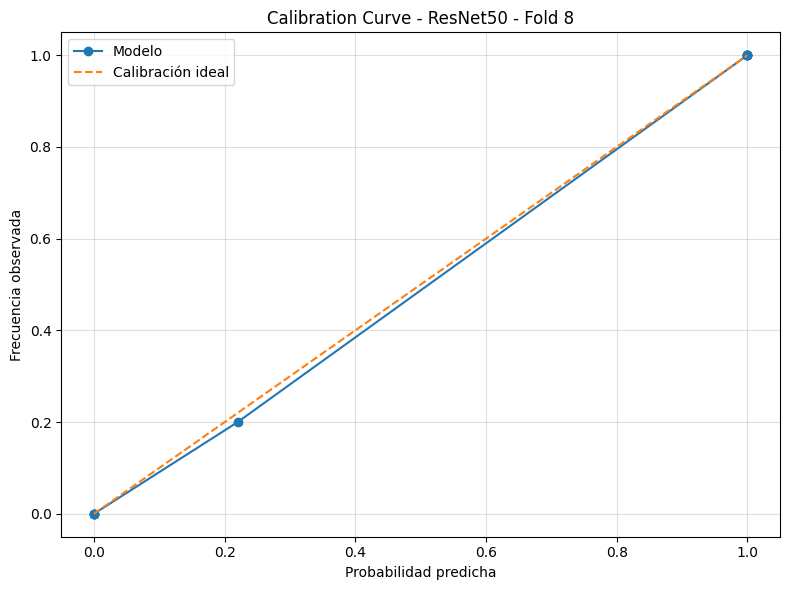

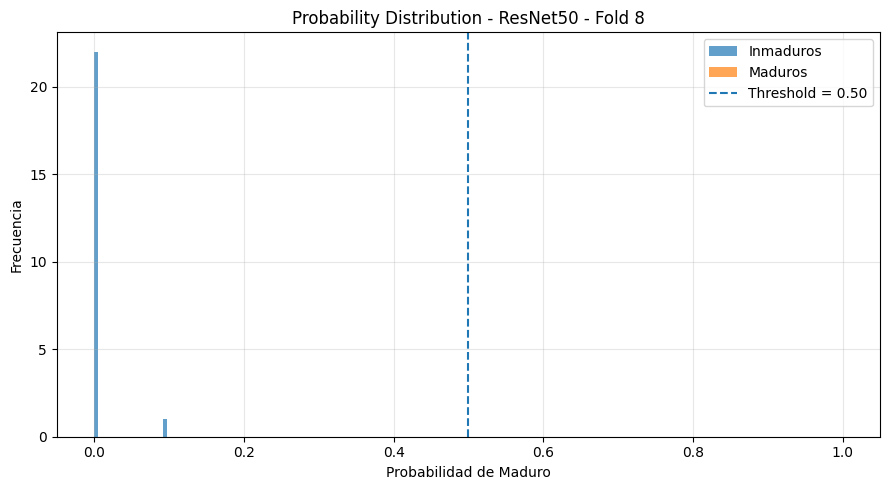

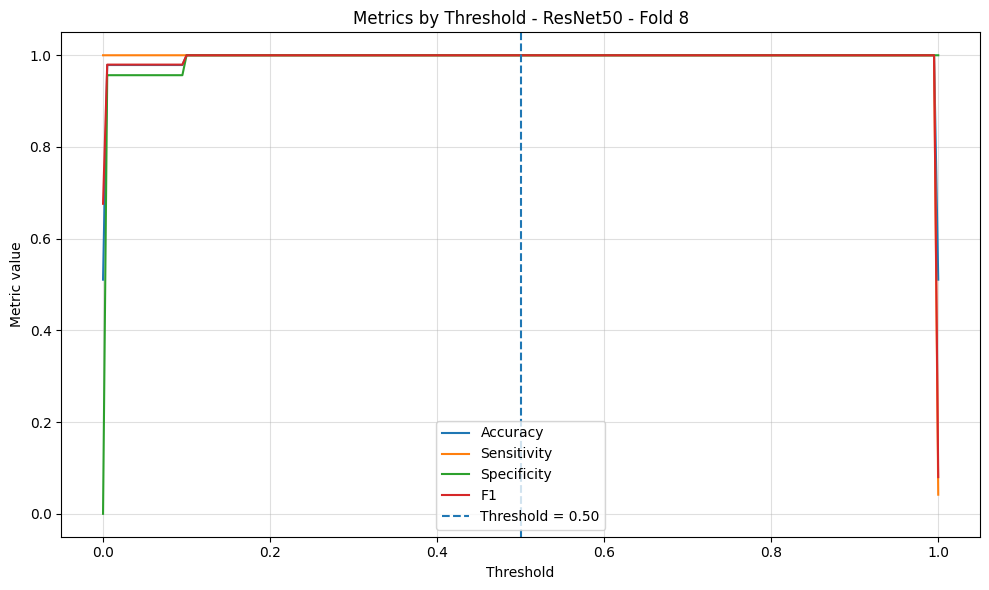


FOLD 9/10
------------------------------------------------------------------------
Epoch 1/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 29s 1s/step - accuracy: 0.9504 - auc: 0.9923 - loss: 0.1964 - pr_auc: 0.9927 - precision: 0.9703 - recall: 0.9289 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0110 - val_pr_auc: 1.0000 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 2/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - accuracy: 0.9976 - auc: 1.0000 - loss: 0.0084 - pr_auc: 1.0000 - precision: 1.0000 - recall: 0.9953 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 7.9307e-04 - val_pr_auc: 1.0000 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 3/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - accuracy: 1.0000 - auc: 1.0000 - loss: 0.0022 - pr_auc: 1.0000 - precision: 1.0000 - recall: 1.0000 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 5.3609e-04 - val_pr_auc: 1.0000 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 4/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - accuracy: 1.0000 - auc

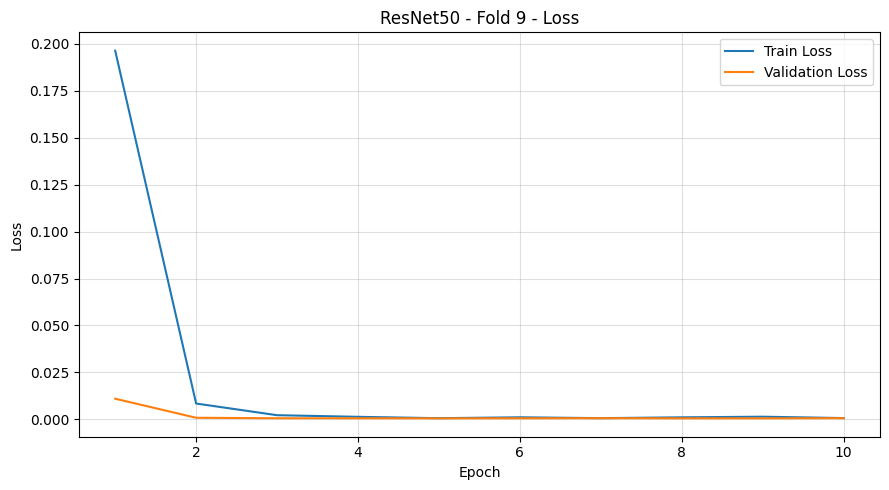

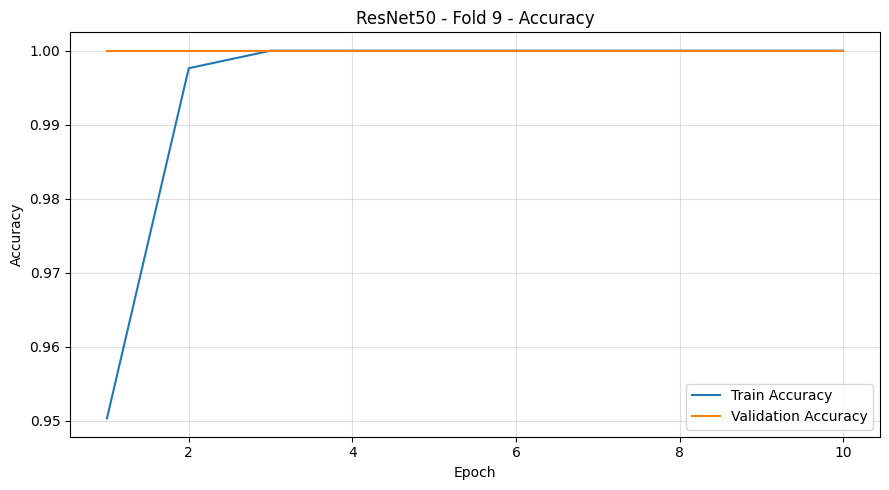

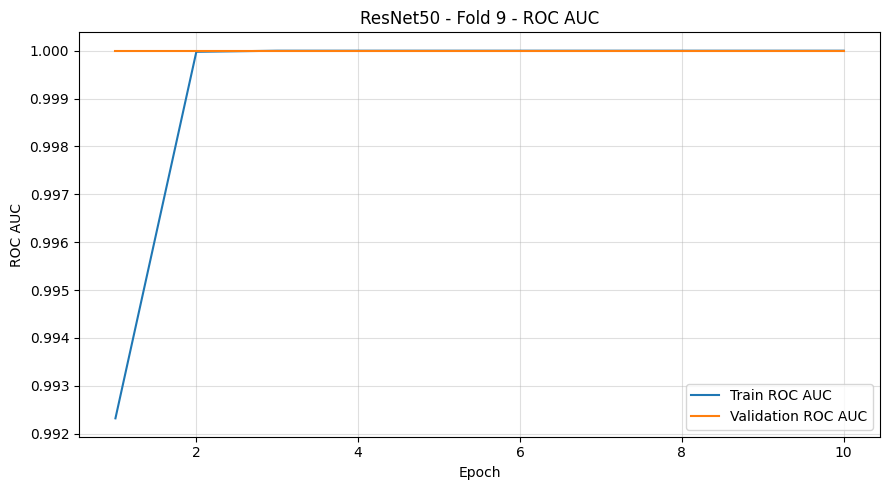

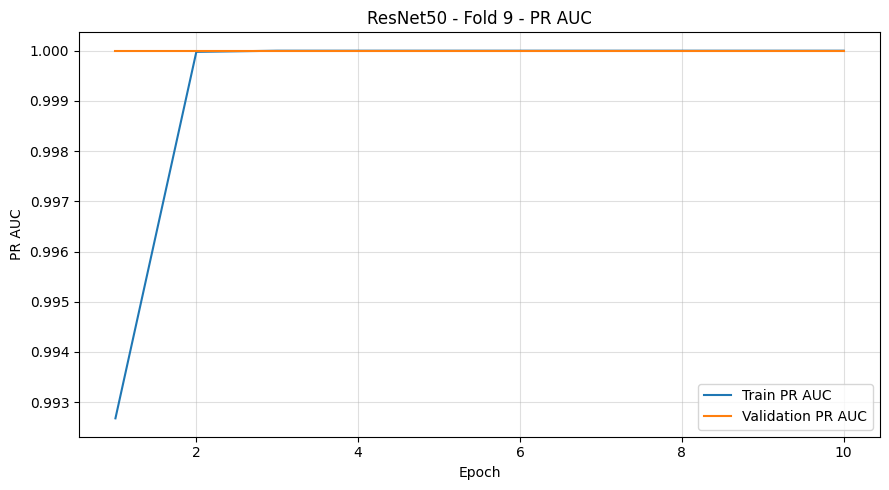

2/2 ━━━━━━━━━━━━━━━━━━━━ 5s 3s/step

Fold 09 | Acc: 1.0000 | Bal Acc: 1.0000 | F1: 1.0000 | ROC AUC: 1.0000 | PR AUC: 1.0000 | Log loss: 0.00008601 | Brier: 0.00000013 | ECE: 0.00008595


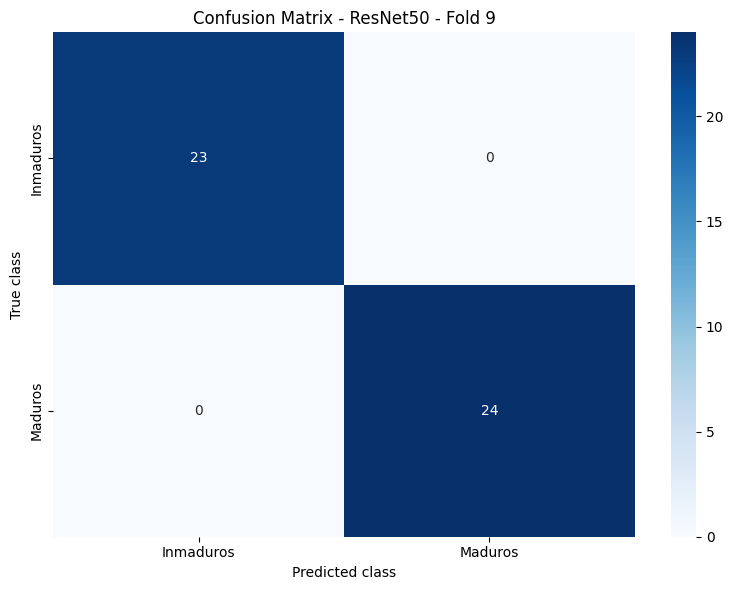

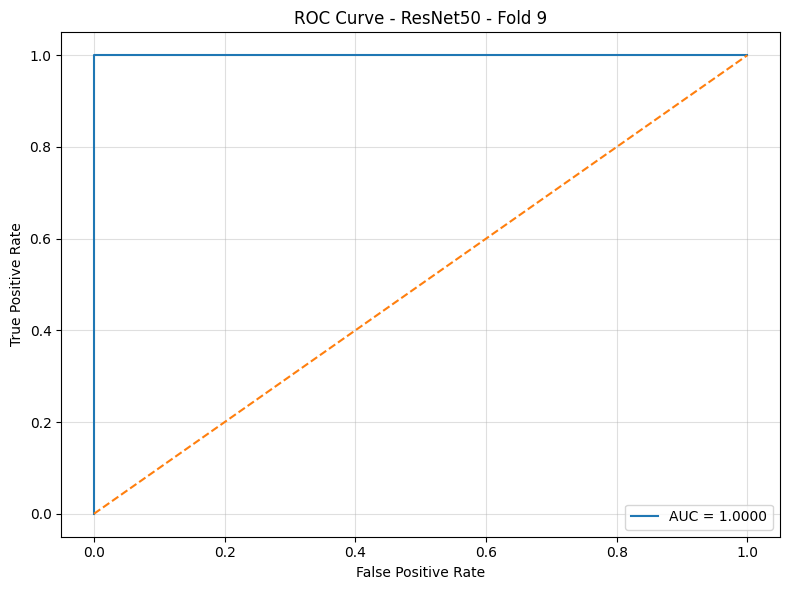

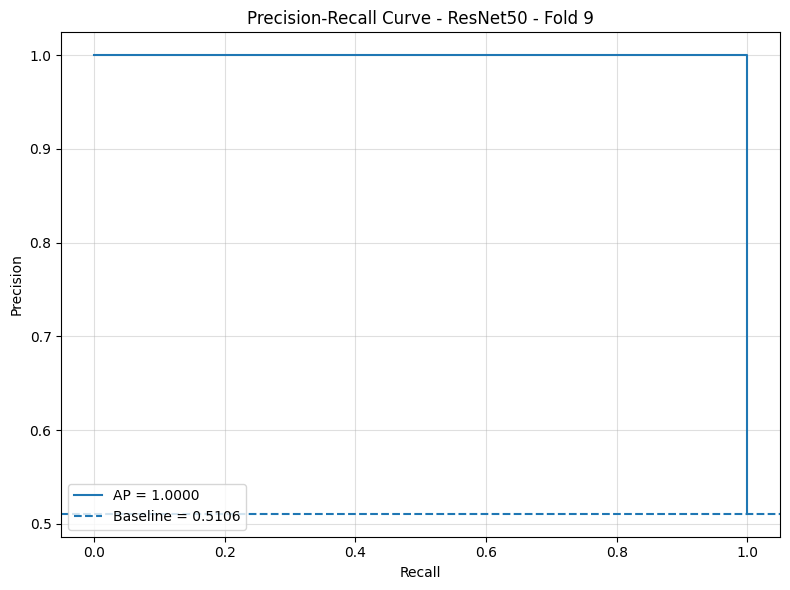

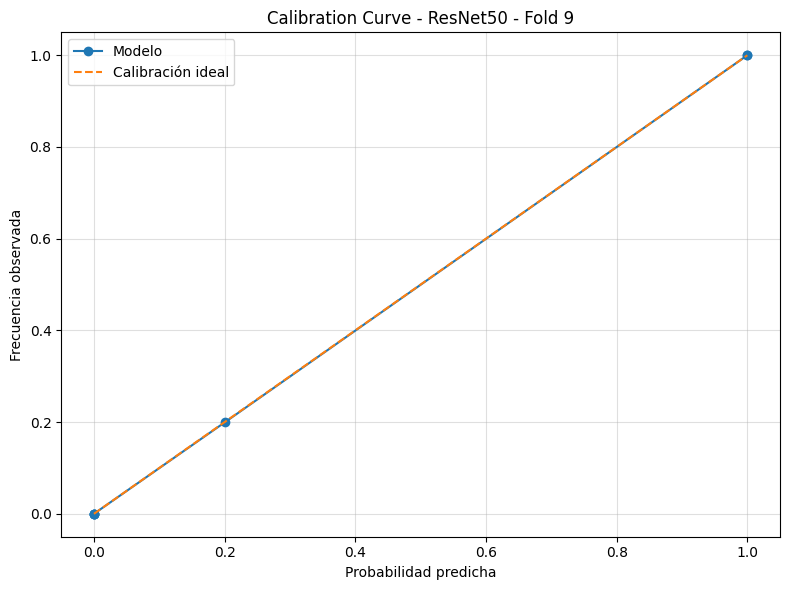

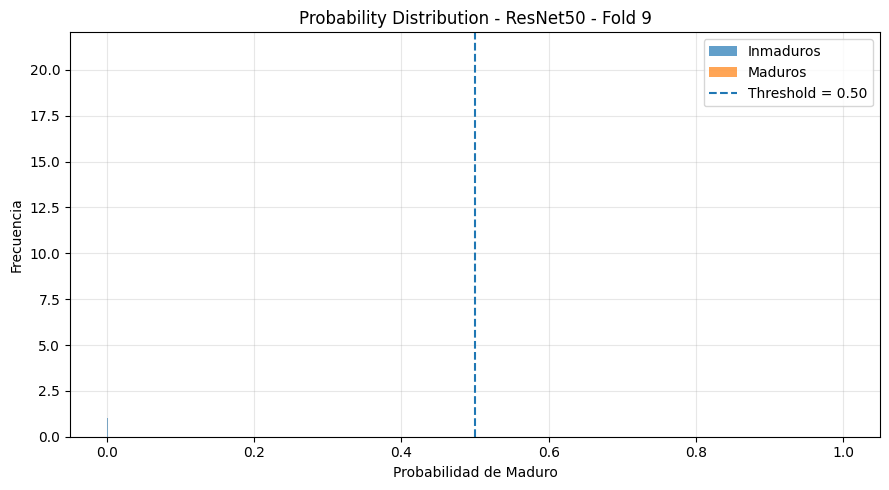

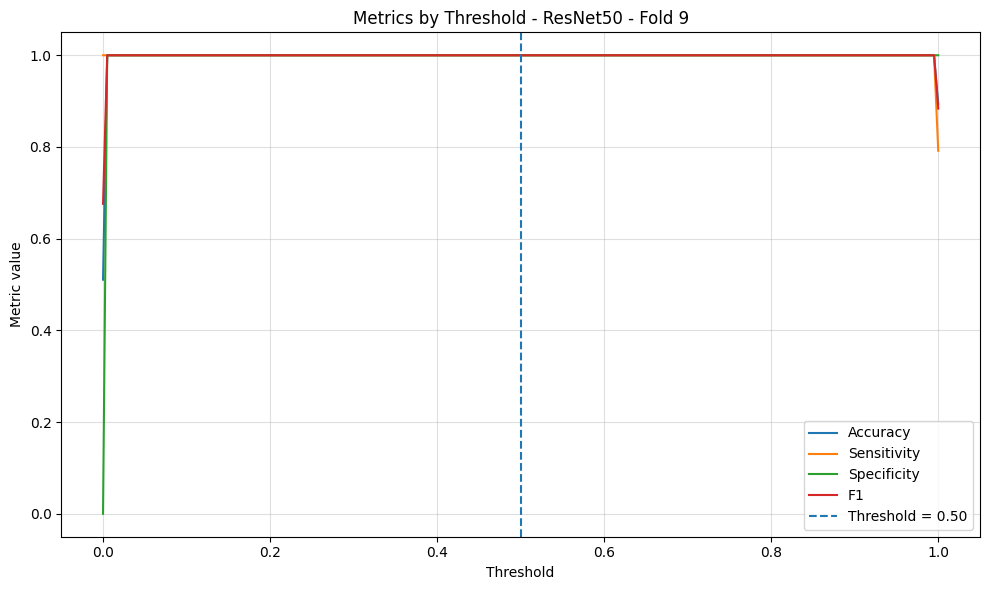


FOLD 10/10
------------------------------------------------------------------------
Epoch 1/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 29s 1s/step - accuracy: 0.8251 - auc: 0.8759 - loss: 0.4746 - pr_auc: 0.9098 - precision: 0.9152 - recall: 0.7156 - val_accuracy: 0.9787 - val_auc: 0.9964 - val_loss: 0.1237 - val_pr_auc: 0.9965 - val_precision: 0.9600 - val_recall: 1.0000
Epoch 2/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - accuracy: 0.9929 - auc: 0.9983 - loss: 0.0535 - pr_auc: 0.9980 - precision: 0.9952 - recall: 0.9905 - val_accuracy: 0.9787 - val_auc: 1.0000 - val_loss: 0.0681 - val_pr_auc: 1.0000 - val_precision: 0.9600 - val_recall: 1.0000
Epoch 3/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - accuracy: 1.0000 - auc: 1.0000 - loss: 0.0061 - pr_auc: 1.0000 - precision: 1.0000 - recall: 1.0000 - val_accuracy: 0.9787 - val_auc: 1.0000 - val_loss: 0.0247 - val_pr_auc: 1.0000 - val_precision: 0.9600 - val_recall: 1.0000
Epoch 4/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - accuracy: 1.0000 - auc: 1.000

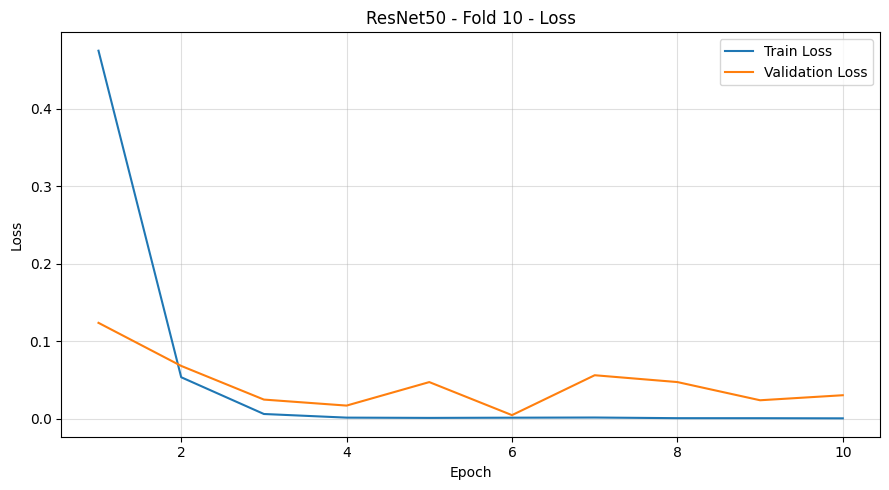

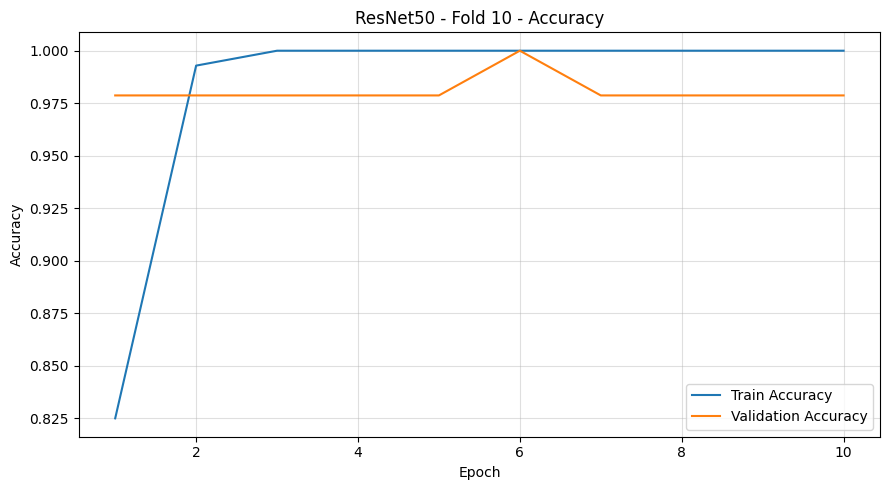

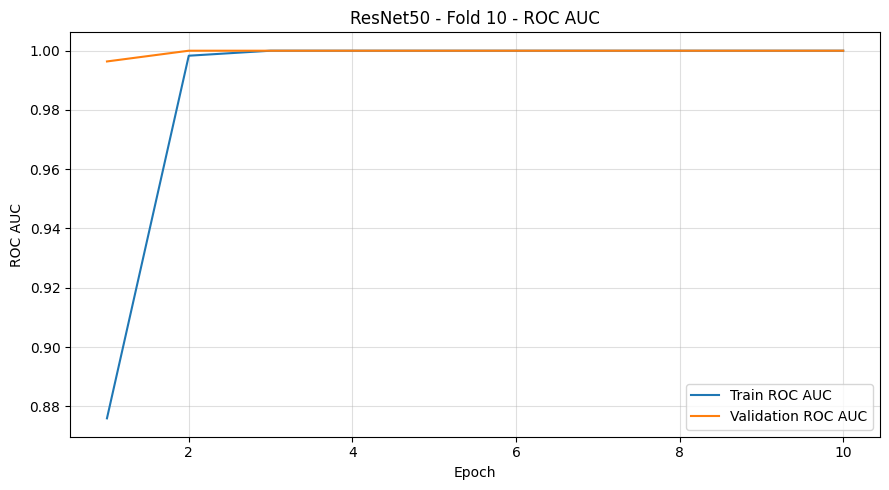

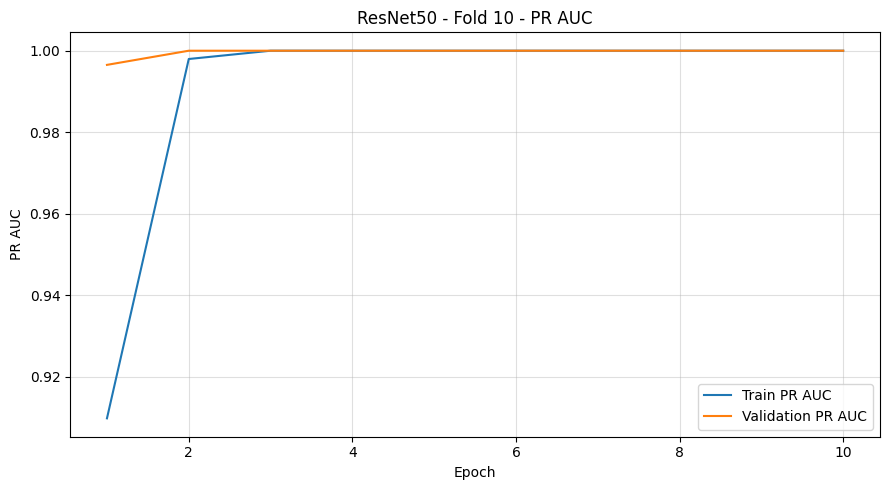

2/2 ━━━━━━━━━━━━━━━━━━━━ 4s 2s/step

Fold 10 | Acc: 0.9787 | Bal Acc: 0.9783 | F1: 0.9796 | ROC AUC: 1.0000 | PR AUC: 1.0000 | Log loss: 0.02984856 | Brier: 0.01209499 | ECE: 0.01605455


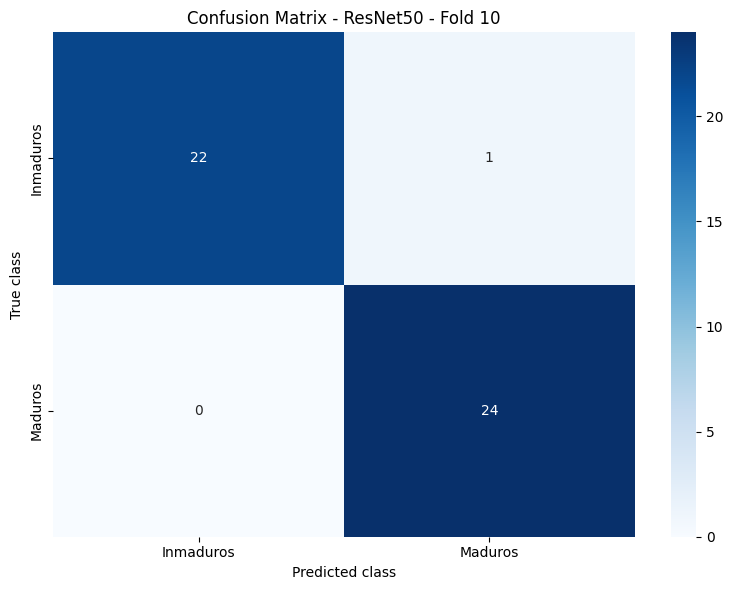

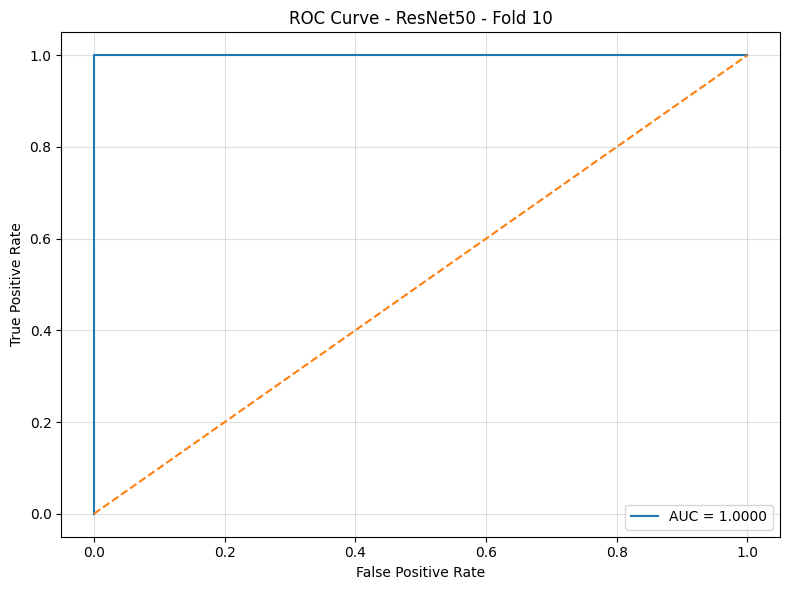

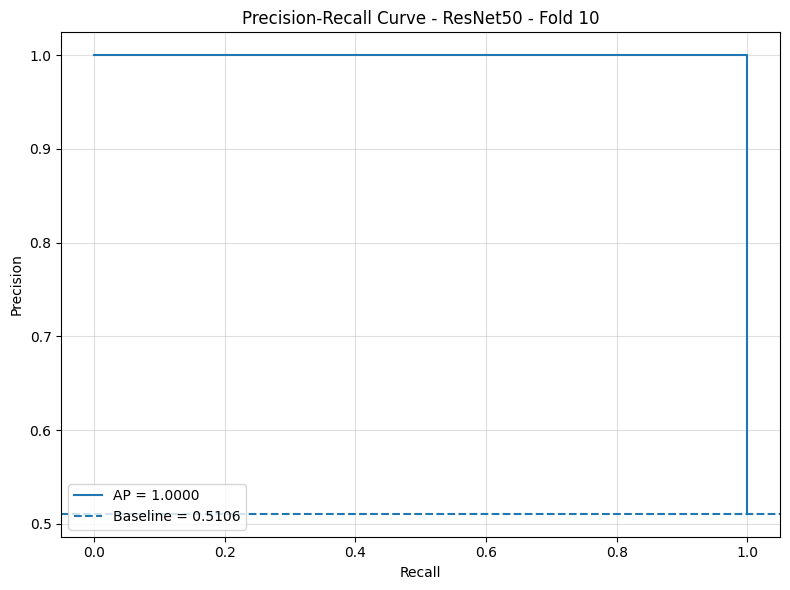

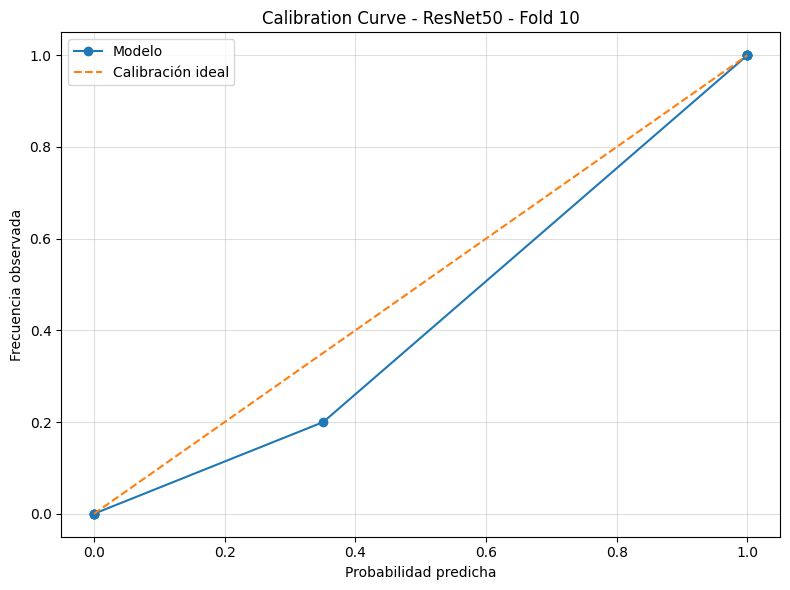

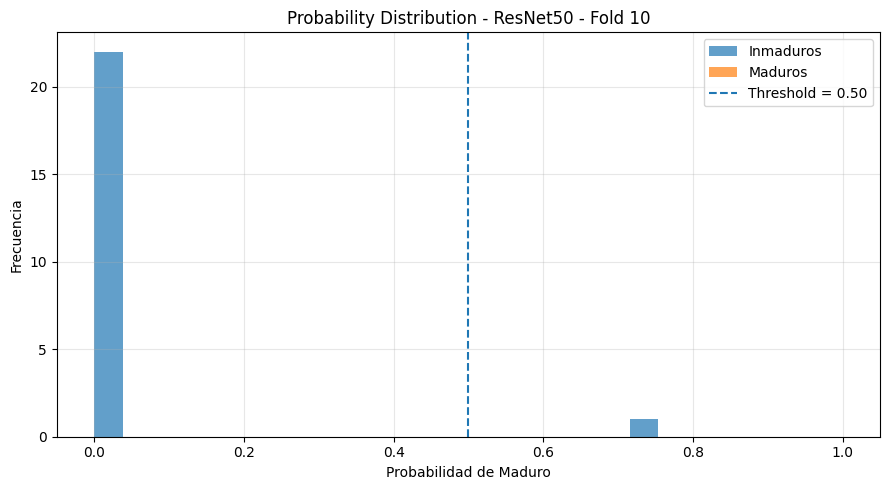

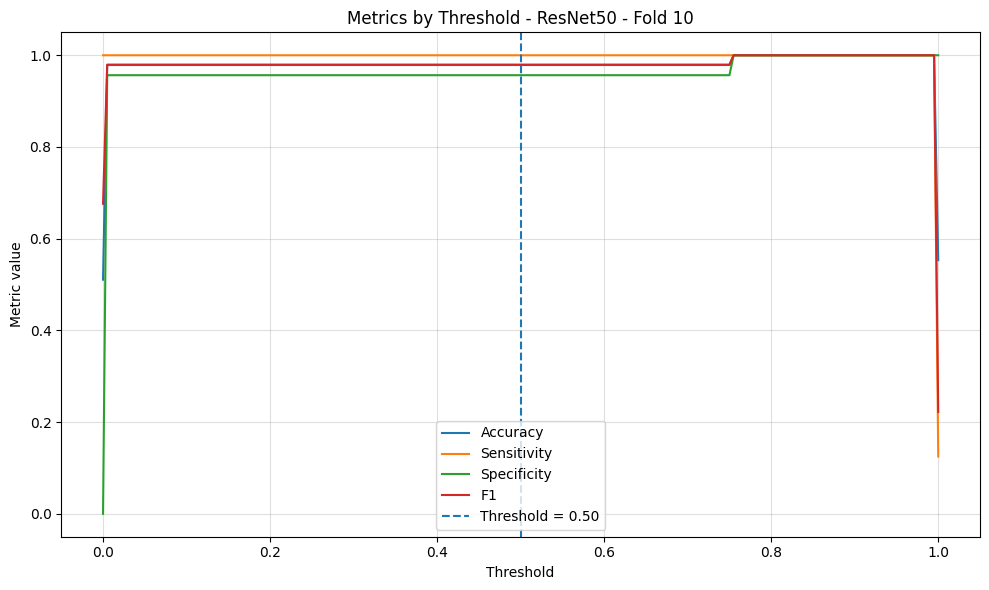


RESULTADOS POR FOLD


,tn,fp,fn,tp,accuracy,balanced_accuracy,precision_ppv,sensitivity_recall,specificity,negative_predictive_value,...,n_images,model,fold,train_images,validation_images,epochs_trained,epochs_source,training_time_seconds,inference_time_seconds,inference_time_per_image_ms
0,24,0,0,23,1.000000,1.000000,1.000000,1.0,1.000000,1.0,...,47,ResNet50,1,423,47,10,best_optuna_trial,173.633758,4.120972,87.680249
1,24,0,0,23,1.000000,1.000000,1.000000,1.0,1.000000,1.0,...,47,ResNet50,2,423,47,10,best_optuna_trial,172.515166,5.464913,116.274753
2,24,0,0,23,1.000000,1.000000,1.000000,1.0,1.000000,1.0,...,47,ResNet50,3,423,47,10,best_optuna_trial,174.233419,4.214702,89.674518
3,23,1,0,23,0.978723,0.979167,0.958333,1.0,0.958333,1.0,...,47,ResNet50,4,423,47,10,best_optuna_trial,175.317209,4.409106,93.810766
4,24,0,0,23,1.000000,1.000000,1.000000,1.0,1.000000,1.0,...,47,ResNet50,5,423,47,10,best_optuna_trial,179.211630,4.198487,89.329512
5,23,0,0,24,1.000000,1.000000,1.000000,1.0,1.000000,1.0,...,47,ResNet50,6,423,47,10,best_optuna_trial,184.006684,4.192475,89.201597
6,23,0,0,24,1.000000,1.000000,1.000000,1.0,1.000000,1.0,...,47,ResNet50,7,423,47,10,best_optuna_trial,176.256248,4.204548,89.458476
7,23,0,0,24,1.000000,1.000000,1.000000,1.0,1.000000,1.0,...,47,ResNet50,8,423,47,10,best_optuna_trial,174.148724,5.743630,122.204887
8,23,0,0,24,1.000000,1.000000,1.000000,1.0,1.000000,1.0,...,47,ResNet50,9,423,47,10,best_optuna_trial,175.775717,10.268524,218.479228
9,22,1,0,24,0.978723,0.978261,0.960000,1.0,0.956522,1.0,...,47,ResNet50,10,423,47,10,best_optuna_trial,178.274739,4.114809,87.549123



RESUMEN DE LOS 10 FOLDS


,metric,mean,std,median,min,max
0,accuracy,0.995745,8.971000e-03,1.000000,9.787234e-01,1.000000
1,balanced_accuracy,0.995743,8.977602e-03,1.000000,9.782609e-01,1.000000
2,precision_ppv,0.991833,1.722133e-02,1.000000,9.583333e-01,1.000000
3,sensitivity_recall,1.000000,0.000000e+00,1.000000,1.000000e+00,1.000000
4,specificity,0.991486,1.795520e-02,1.000000,9.565217e-01,1.000000
5,negative_predictive_value,1.000000,0.000000e+00,1.000000,1.000000e+00,1.000000
6,f1_score,0.995832,8.790302e-03,1.000000,9.787234e-01,1.000000
7,f2_score,0.998311,3.560693e-03,1.000000,9.913793e-01,1.000000
8,jaccard_index,0.991833,1.722133e-02,1.000000,9.583333e-01,1.000000
9,mcc,0.991659,1.758383e-02,1.000000,9.582593e-01,1.000000



MÉTRICAS OOF EXTENDIDAS


,0
tn,233
fp,2
fn,0
tp,235
accuracy,0.995745
balanced_accuracy,0.995745
precision_ppv,0.991561
sensitivity_recall,1.0
specificity,0.991489
negative_predictive_value,1.0


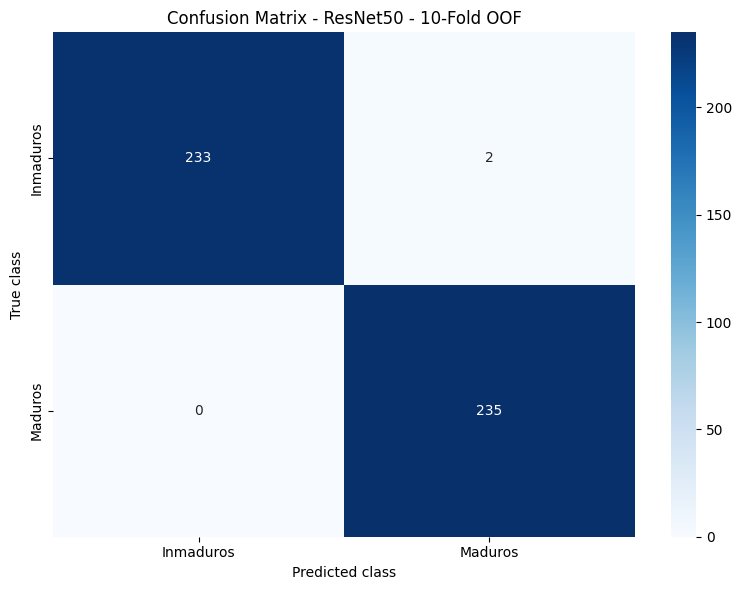

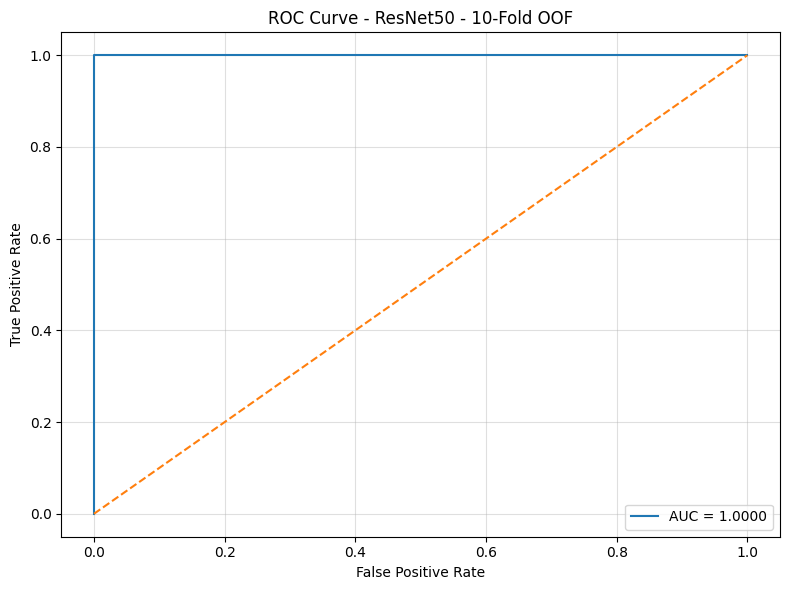

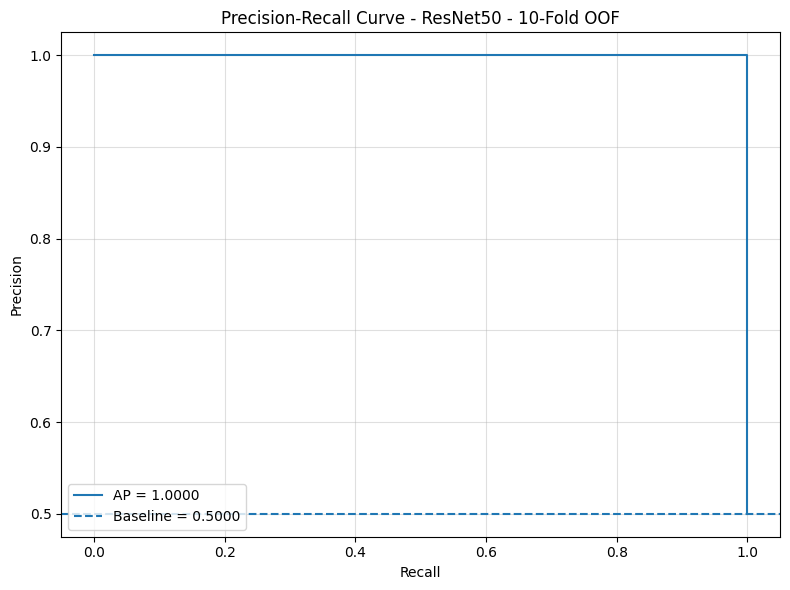

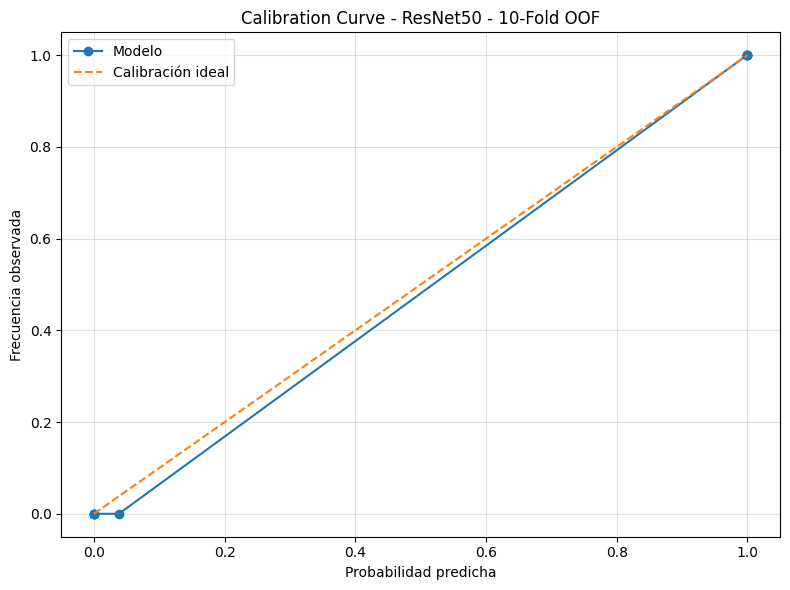

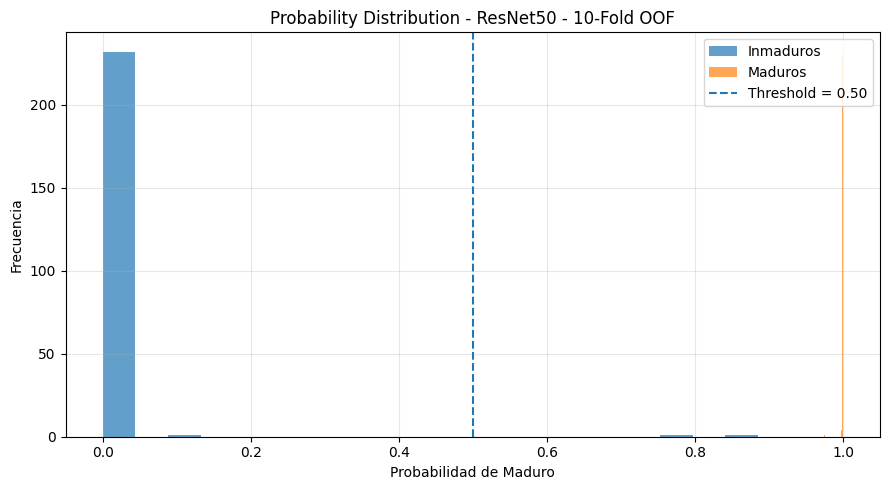

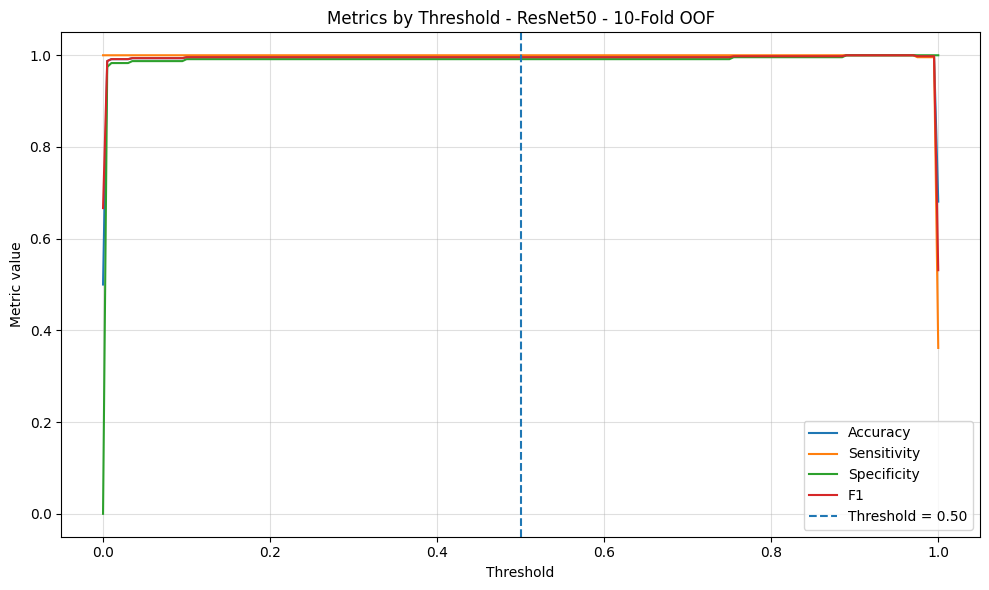


ENTRENAMIENTO FINAL CON TRAIN + VAL
Epoch 1/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 32s 1s/step - accuracy: 0.9570 - auc: 0.9961 - loss: 0.1355 - pr_auc: 0.9964 - precision: 0.9894 - recall: 0.9238
Epoch 2/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 22s 1s/step - accuracy: 1.0000 - auc: 1.0000 - loss: 0.0016 - pr_auc: 1.0000 - precision: 1.0000 - recall: 1.0000
Epoch 3/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 21s 1s/step - accuracy: 1.0000 - auc: 1.0000 - loss: 0.0016 - pr_auc: 1.0000 - precision: 1.0000 - recall: 1.0000
Epoch 4/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 22s 1s/step - accuracy: 1.0000 - auc: 1.0000 - loss: 6.4813e-04 - pr_auc: 1.0000 - precision: 1.0000 - recall: 1.0000
Epoch 5/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 21s 1s/step - accuracy: 1.0000 - auc: 1.0000 - loss: 5.3168e-04 - pr_auc: 1.0000 - precision: 1.0000 - recall: 1.0000
Epoch 6/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 22s 1s/step - accuracy: 1.0000 - auc: 1.0000 - loss: 5.7197e-04 - pr_auc: 1.0000 - precision: 1.0000 - recall: 1.0000
Epoch 7/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 2

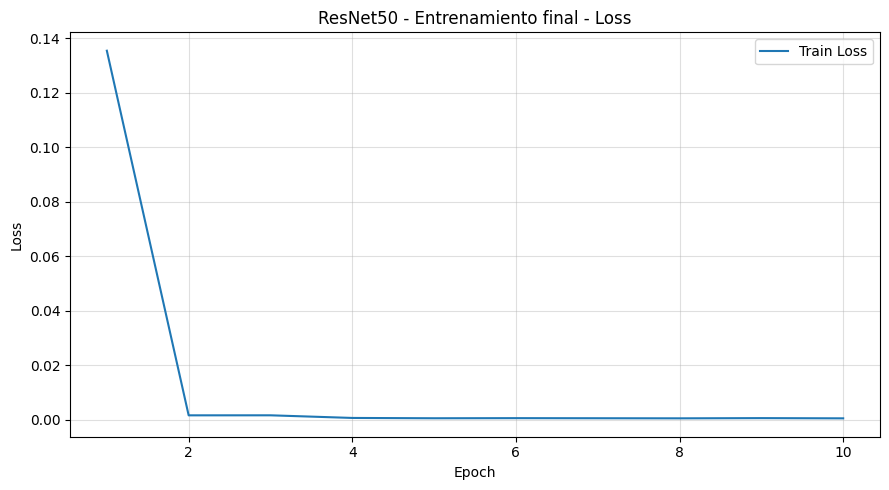

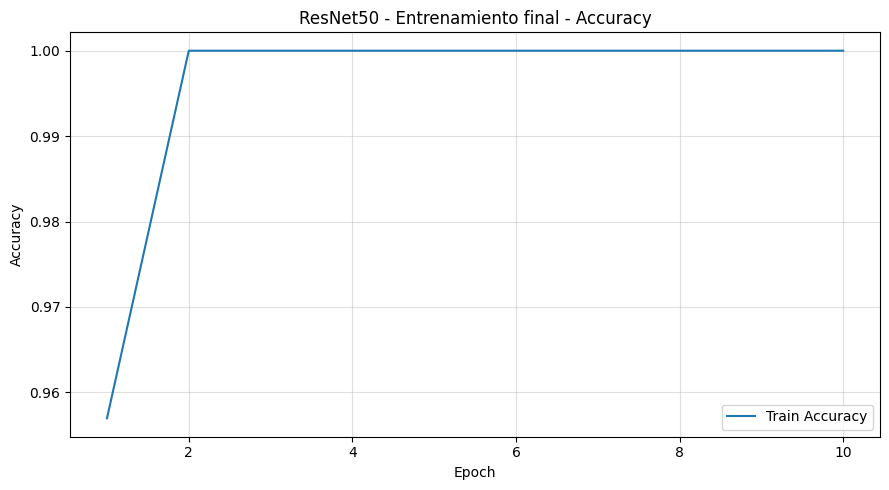

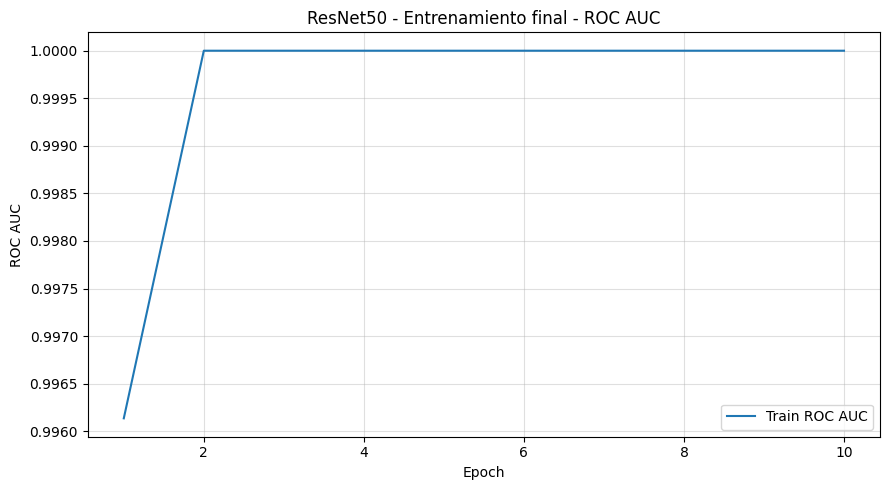

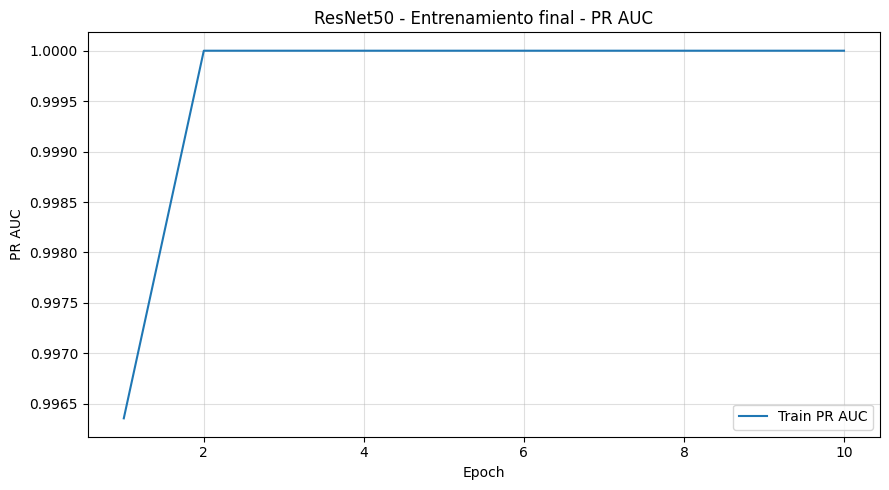


EVALUACIÓN FINAL SOBRE TEST INDEPENDIENTE

MÉTRICAS DEL TEST EXTENDIDAS


,0
tn,34
fp,0
fn,0
tp,34
accuracy,1.0
...,...
inference_per_image_ms_median,19.150135
inference_per_image_ms_p95_repetition,20.159481
total_parameters,23850113
trainable_parameters,16069121


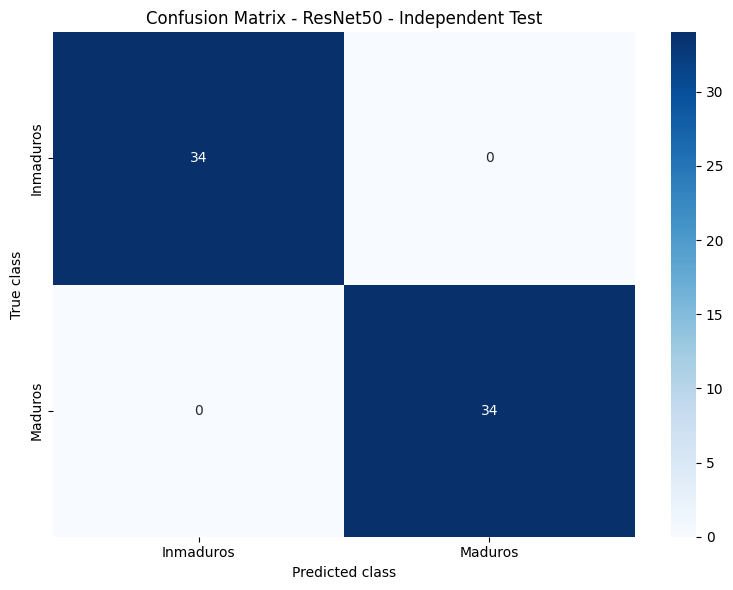

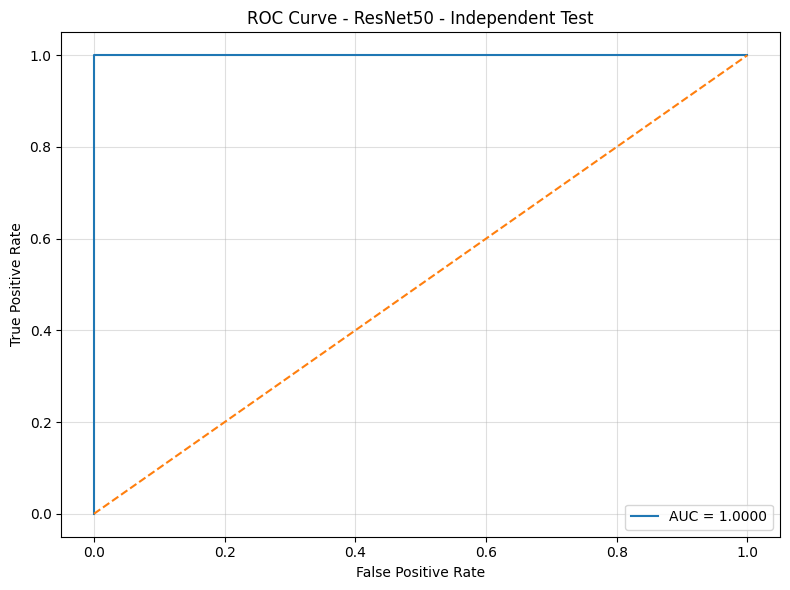

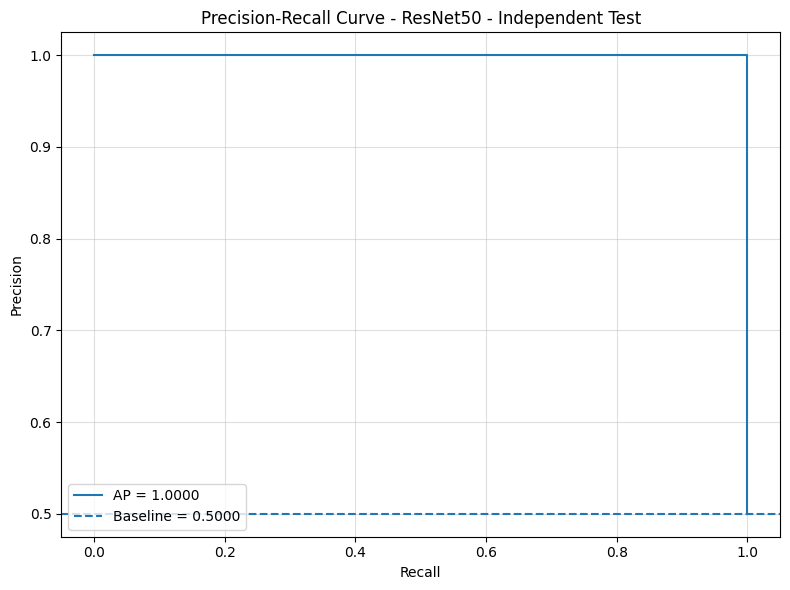

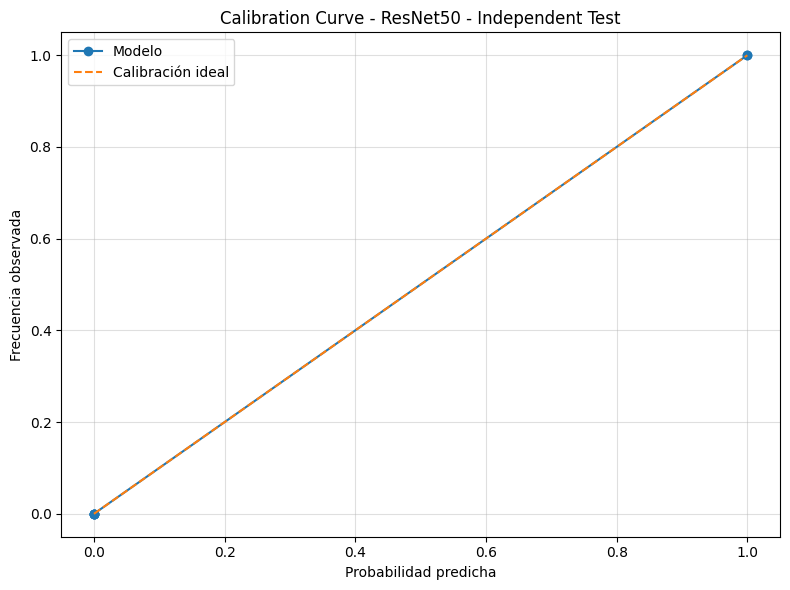

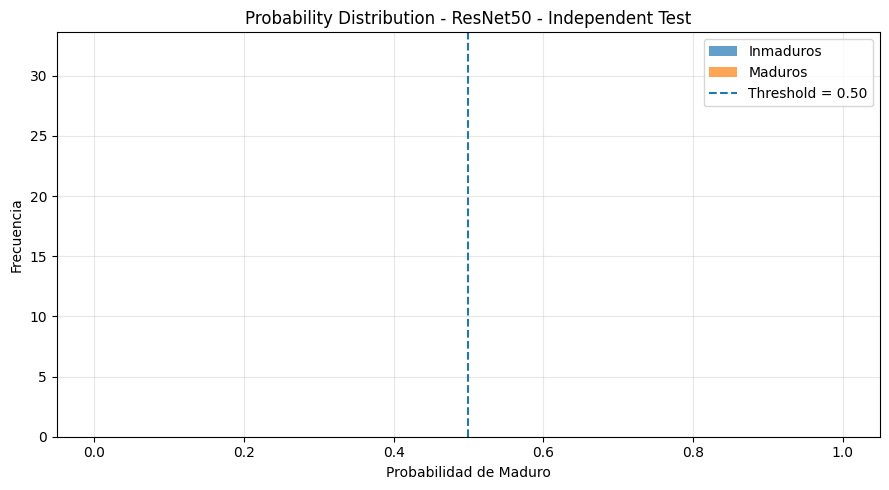

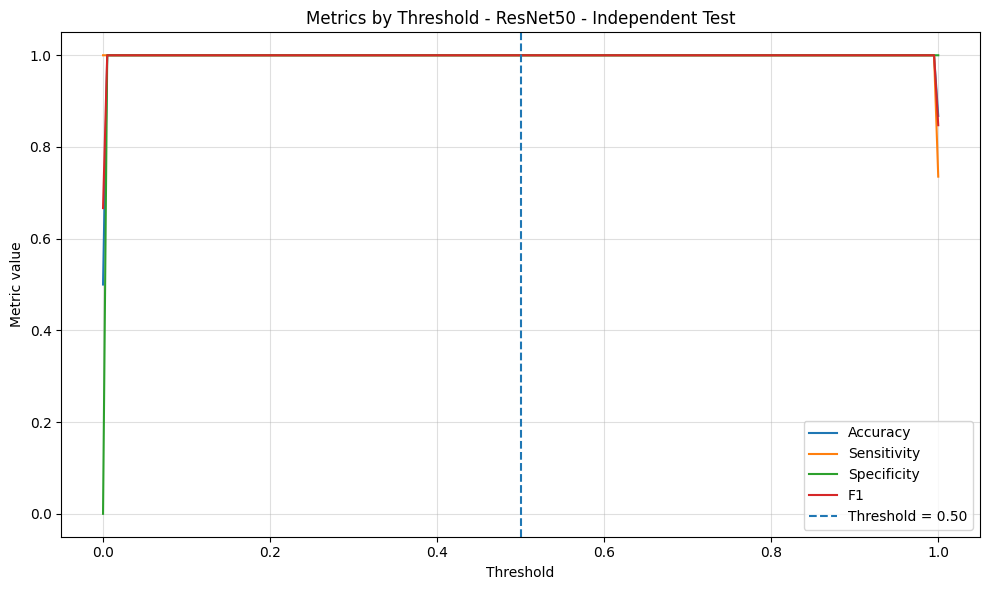


EXPORTANDO ARTEFACTOS DE RESNET50


Saved artifact at '/content/drive/MyDrive/Tesis-Mango/Dataset Tesis2/Resultados/Experimento_ResNet50_Evaluacion_Extendida/artefactos_modelo/ResNet50_saved_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='imagen_entrada')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  137665345321296: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137662518191376: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137665345317840: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137662518190992: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137651692492880: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137651692219728: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137662517687696: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137662517688080: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137662517690192: TensorSpec

In [ ]:
# ============================================================
# RESNET50 MONOLÍTICA - EVALUACIÓN EXTENDIDA
# ============================================================
#
# CLASIFICACIÓN:
#   0 = Inmaduros
#   1 = Maduros
#
# OBJETIVO:
#   Entrenar y evaluar ResNet50 con un conjunto amplio de métricas
#   para permitir comparaciones posteriores con EfficientNetV2 y
#   Swin Transformer Tiny, incluso cuando Accuracy/F1/AUC se saturen.
#
# FLUJO:
#   1. Cargar train, val y test.
#   2. Verificar duplicados exactos SHA-256 entre splits.
#   3. Dividir únicamente val para Optuna (70/30).
#   4. Optuna ejecuta 30 trials y minimiza log loss.
#   5. Optuna selecciona hiperparámetros y cantidad de épocas.
#   6. Validación cruzada estratificada de 10 folds sobre train.
#      Cada fold entrena una ResNet50 nueva con la configuración fija
#      seleccionada por HPO. No se vuelve a elegir época en CV.
#   7. Evaluación OOF con métricas discriminativas, probabilísticas,
#      calibración, incertidumbre, intervalos y curvas.
#   8. Entrenamiento final con train + val.
#   9. Evaluación única en test independiente.
#  10. Exportación de modelo, pesos, configuración, TFLite,
#      SavedModel, manifiesto, checksums y ZIP.
#
# COLORES:
#   - Matrices de confusión: cmap="Blues".
#   - Resto de gráficos: ciclo de colores predeterminado de Matplotlib
#     (primera serie azul, segunda naranja, etc.).
# ============================================================


# ============================================================
# 1. INSTALAR DEPENDENCIAS
# ============================================================

!pip install -q optuna seaborn scipy statsmodels onnx onnxruntime tf2onnx


# ============================================================
# 2. IMPORTACIONES
# ============================================================

import os
import gc
import io
import json
import time
import math
import random
import shutil
import hashlib
import platform
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
import optuna

from tqdm.auto import tqdm
from IPython.display import display

from tensorflow.keras import Model, layers, callbacks, optimizers, regularizers
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import (
    preprocess_input as resnet_preprocess_input,
)

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    jaccard_score,
    matthews_corrcoef,
    cohen_kappa_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    log_loss,
    brier_score_loss,
    roc_curve,
    precision_recall_curve,
    auc,
)
from sklearn.calibration import calibration_curve
from sklearn.linear_model import LogisticRegression
from scipy.stats import beta, ks_2samp

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)


# ============================================================
# 3. REPRODUCIBILIDAD
# ============================================================

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

try:
    tf.config.experimental.enable_op_determinism()
    print("Operaciones deterministas activadas.")
except Exception as error:
    print("No se pudo activar el determinismo completo:", error)


# ============================================================
# 4. CONFIGURACIÓN DE GPU
# ============================================================

gpus = tf.config.list_physical_devices("GPU")

if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print(f"GPU detectada: {gpus}")
    except Exception as error:
        print("No se pudo configurar la memoria GPU:", error)
else:
    print("No se detectó GPU. Se utilizará CPU.")


# ============================================================
# 5. RUTAS
# ============================================================

# Debe existir previamente:
# ejecucion = Path("/content/drive/MyDrive/Tesis-Mango/Resultados")

SPLIT_DIR = ejecucion / "Dataset_balanceado_split"
TRAIN_DIR = SPLIT_DIR / "train"
VAL_DIR = SPLIT_DIR / "val"
TEST_DIR = SPLIT_DIR / "test"

EXPERIMENT_DIR = ejecucion / "Experimento_ResNet50_Evaluacion_Extendida"
MODELS_DIR = EXPERIMENT_DIR / "modelos"
RESULTS_DIR = EXPERIMENT_DIR / "resultados"
FIGURES_DIR = EXPERIMENT_DIR / "figuras"
HISTORIES_DIR = EXPERIMENT_DIR / "historiales"
FOLDS_DIR = EXPERIMENT_DIR / "folds"
OPTUNA_DIR = EXPERIMENT_DIR / "optuna"
ARTEFACTS_DIR = EXPERIMENT_DIR / "artefactos_modelo"

for carpeta in [
    EXPERIMENT_DIR,
    MODELS_DIR,
    RESULTS_DIR,
    FIGURES_DIR,
    HISTORIES_DIR,
    FOLDS_DIR,
    OPTUNA_DIR,
    ARTEFACTS_DIR,
]:
    carpeta.mkdir(parents=True, exist_ok=True)


# ============================================================
# 6. CONFIGURACIÓN GENERAL
# ============================================================

MODEL_NAME = "ResNet50"
IMG_SIZE = (224, 224)
CLASS_NAMES = ["Inmaduros", "Maduros"]
LABEL_MAP = {"Inmaduros": 0, "Maduros": 1}
INV_LABEL_MAP = {0: "Inmaduros", 1: "Maduros"}
POSITIVE_CLASS = 1
EXTENSIONES_VALIDAS = {".jpg", ".jpeg", ".png", ".bmp"}

# HPO
N_OPTUNA_TRIALS = 30
OPTUNA_VALIDATION_FRACTION = 0.30

# Validación cruzada
N_FOLDS = 10

# Clasificación
CLASSIFICATION_THRESHOLD = 0.50

# Calibración y bootstrap
N_CALIBRATION_BINS = 10
N_BOOTSTRAP = 2000
BOOTSTRAP_CONFIDENCE = 0.95

# Medición de latencia
LATENCY_REPETITIONS = 5

# Controles
GENERAR_PLOTS_POR_FOLD = True
VERIFICAR_DUPLICADOS = True
GUARDAR_MODELOS_FOLDS = False
EXPORTAR_SAVEDMODEL = True
EXPORTAR_TFLITE_FLOAT32 = True
EXPORTAR_TFLITE_OPTIMIZADO = True

# ONNX queda desactivado por defecto para evitar reinicios de Colab.
# Puede activarse posteriormente en un runtime limpio.
EXPORTAR_ONNX = False


# ============================================================
# 7. DATAFRAMES DE TRAIN, VAL Y TEST
# ============================================================

def crear_dataframe_split(carpeta_split, nombre_split):
    registros = []

    if not carpeta_split.exists():
        raise FileNotFoundError(f"No existe la carpeta:\n{carpeta_split}")

    for nombre_clase in CLASS_NAMES:
        carpeta_clase = carpeta_split / nombre_clase

        if not carpeta_clase.exists():
            raise FileNotFoundError(f"No existe la carpeta:\n{carpeta_clase}")

        archivos = sorted([
            archivo
            for archivo in carpeta_clase.rglob("*")
            if archivo.is_file()
            and archivo.suffix.lower() in EXTENSIONES_VALIDAS
        ])

        if not archivos:
            raise ValueError(
                f"La clase '{nombre_clase}' del split "
                f"'{nombre_split}' no contiene imágenes."
            )

        for archivo in archivos:
            registros.append({
                "filepath": str(archivo),
                "label": nombre_clase,
                "y": LABEL_MAP[nombre_clase],
                "split": nombre_split,
            })

    dataframe = pd.DataFrame(registros)
    return dataframe.sample(frac=1, random_state=SEED).reset_index(drop=True)


df_train = crear_dataframe_split(TRAIN_DIR, "train")
df_val = crear_dataframe_split(VAL_DIR, "validation")
df_test = crear_dataframe_split(TEST_DIR, "test")


# ============================================================
# 8. VERIFICACIONES INICIALES
# ============================================================

conteo_train = df_train["label"].value_counts().reindex(CLASS_NAMES)

if conteo_train.min() < N_FOLDS:
    raise ValueError(
        f"Cada clase de train debe tener al menos {N_FOLDS} imágenes "
        f"para ejecutar {N_FOLDS} folds.\n\nConteo:\n{conteo_train}"
    )

print("\nDISTRIBUCIÓN PRINCIPAL DEL DATASET")
print("=" * 72)

resumen_dataset = []

for nombre_split, dataframe in {
    "Train": df_train,
    "Validation": df_val,
    "Test": df_test,
}.items():
    print(f"\n{nombre_split}")
    conteo = dataframe["label"].value_counts().reindex(
        CLASS_NAMES,
        fill_value=0,
    )
    display(conteo)

    for clase in CLASS_NAMES:
        resumen_dataset.append({
            "split": nombre_split,
            "clase": clase,
            "cantidad": int(conteo.loc[clase]),
        })

pd.DataFrame(resumen_dataset).to_csv(
    RESULTS_DIR / "distribucion_dataset.csv",
    index=False,
    encoding="utf-8-sig",
)


# ============================================================
# 9. DUPLICADOS EXACTOS ENTRE SPLITS
# ============================================================

def calcular_hash_archivo(filepath, chunk_size=1024 * 1024):
    sha256 = hashlib.sha256()
    with open(filepath, "rb") as archivo:
        while True:
            bloque = archivo.read(chunk_size)
            if not bloque:
                break
            sha256.update(bloque)
    return sha256.hexdigest()


def verificar_duplicados_entre_splits(dataframes):
    hashes_observados = {}
    duplicados = []
    total_archivos = sum(len(df) for df in dataframes.values())
    barra = tqdm(total=total_archivos, desc="Verificando duplicados")

    for nombre_split, dataframe in dataframes.items():
        for filepath in dataframe["filepath"]:
            hash_imagen = calcular_hash_archivo(filepath)

            if hash_imagen in hashes_observados:
                anterior = hashes_observados[hash_imagen]
                if anterior["split"] != nombre_split:
                    duplicados.append({
                        "hash": hash_imagen,
                        "split_1": anterior["split"],
                        "archivo_1": anterior["filepath"],
                        "split_2": nombre_split,
                        "archivo_2": filepath,
                    })
            else:
                hashes_observados[hash_imagen] = {
                    "split": nombre_split,
                    "filepath": filepath,
                }

            barra.update(1)

    barra.close()

    if duplicados:
        df_duplicados = pd.DataFrame(duplicados)
        ruta = RESULTS_DIR / "duplicados_entre_splits.csv"
        df_duplicados.to_csv(ruta, index=False, encoding="utf-8-sig")
        display(df_duplicados)
        raise ValueError(
            "Se encontraron imágenes idénticas entre splits. "
            f"Reporte: {ruta}"
        )

    print("No se encontraron imágenes duplicadas entre los splits.")


if VERIFICAR_DUPLICADOS:
    verificar_duplicados_entre_splits({
        "train": df_train,
        "validation": df_val,
        "test": df_test,
    })


# ============================================================
# 10. DIVISIÓN INTERNA DE VAL PARA OPTUNA
# ============================================================

# Optuna usa únicamente val. No utiliza train principal ni test.

df_optuna_train, df_optuna_validation = train_test_split(
    df_val,
    test_size=OPTUNA_VALIDATION_FRACTION,
    stratify=df_val["y"],
    random_state=SEED,
)


df_optuna_train = df_optuna_train.sample(
    frac=1,
    random_state=SEED,
).reset_index(drop=True)

df_optuna_validation = df_optuna_validation.sample(
    frac=1,
    random_state=SEED,
).reset_index(drop=True)


df_optuna_train.to_csv(
    OPTUNA_DIR / "optuna_train.csv",
    index=False,
    encoding="utf-8-sig",
)

df_optuna_validation.to_csv(
    OPTUNA_DIR / "optuna_validation.csv",
    index=False,
    encoding="utf-8-sig",
)

print("\nDIVISIÓN INTERNA DE VALIDACIÓN PARA OPTUNA")
print("=" * 72)
print("\nOptuna train:")
display(
    df_optuna_train["label"]
    .value_counts()
    .reindex(CLASS_NAMES, fill_value=0)
)
print("\nOptuna validation:")
display(
    df_optuna_validation["label"]
    .value_counts()
    .reindex(CLASS_NAMES, fill_value=0)
)
print(f"\nTotal val: {len(df_val)}")
print(f"Optuna train: {len(df_optuna_train)}")
print(f"Optuna validation: {len(df_optuna_validation)}")


# ============================================================
# 11. AUMENTO DE DATOS CONTROLADO
# ============================================================

def construir_aumento_datos():
    """
    Aumento únicamente para entrenamiento.
    Se usa relleno negro porque las imágenes están segmentadas
    sobre fondo negro.
    """

    return tf.keras.Sequential(
        [
            layers.RandomFlip(
                mode="horizontal",
                seed=SEED,
            ),
            layers.RandomRotation(
                factor=0.08,
                fill_mode="constant",
                fill_value=0.0,
                seed=SEED + 1,
            ),
            layers.RandomZoom(
                height_factor=(-0.10, 0.10),
                width_factor=(-0.10, 0.10),
                fill_mode="constant",
                fill_value=0.0,
                seed=SEED + 2,
            ),
            layers.RandomTranslation(
                height_factor=0.05,
                width_factor=0.05,
                fill_mode="constant",
                fill_value=0.0,
                seed=SEED + 3,
            ),
            layers.RandomContrast(
                factor=0.15,
                seed=SEED + 4,
            ),
        ],
        name="aumento_datos_controlado",
    )


# ============================================================
# 12. FUNCIONES TF.DATA
# ============================================================

def cargar_y_redimensionar(filepath, label):
    imagen = tf.io.read_file(filepath)
    imagen = tf.io.decode_image(
        imagen,
        channels=3,
        expand_animations=False,
    )
    imagen.set_shape([None, None, 3])
    imagen = tf.image.resize(imagen, IMG_SIZE, method="bilinear")
    imagen = tf.cast(imagen, tf.float32)
    label = tf.cast(label, tf.float32)
    return imagen, label


def cargar_imagen_sin_label(filepath):
    imagen = tf.io.read_file(filepath)
    imagen = tf.io.decode_image(
        imagen,
        channels=3,
        expand_animations=False,
    )
    imagen.set_shape([None, None, 3])
    imagen = tf.image.resize(imagen, IMG_SIZE, method="bilinear")
    imagen = tf.cast(imagen, tf.float32)
    return imagen


def crear_dataset_etiquetado(
    dataframe,
    batch_size,
    aplicar_aumento=False,
    shuffle=False,
):
    paths = dataframe["filepath"].astype(str).values
    etiquetas = dataframe["y"].astype("float32").values

    dataset_tf = tf.data.Dataset.from_tensor_slices((paths, etiquetas))

    if shuffle:
        dataset_tf = dataset_tf.shuffle(
            buffer_size=len(dataframe),
            seed=SEED,
            reshuffle_each_iteration=True,
        )

    dataset_tf = dataset_tf.map(
        cargar_y_redimensionar,
        num_parallel_calls=tf.data.AUTOTUNE,
    )
    dataset_tf = dataset_tf.batch(batch_size, drop_remainder=False)

    if aplicar_aumento:
        augmentation_layer = construir_aumento_datos()
        dataset_tf = dataset_tf.map(
            lambda imagen, etiqueta: (
                augmentation_layer(imagen, training=True),
                etiqueta,
            ),
            num_parallel_calls=tf.data.AUTOTUNE,
        )

    dataset_tf = dataset_tf.map(
        lambda imagen, etiqueta: (
            resnet_preprocess_input(imagen),
            etiqueta,
        ),
        num_parallel_calls=tf.data.AUTOTUNE,
    )

    opciones = tf.data.Options()
    opciones.experimental_deterministic = True
    dataset_tf = dataset_tf.with_options(opciones)
    return dataset_tf.prefetch(tf.data.AUTOTUNE)


def crear_dataset_prediccion(dataframe, batch_size):
    paths = dataframe["filepath"].astype(str).values
    dataset_tf = tf.data.Dataset.from_tensor_slices(paths)
    dataset_tf = dataset_tf.map(
        cargar_imagen_sin_label,
        num_parallel_calls=tf.data.AUTOTUNE,
    )
    dataset_tf = dataset_tf.batch(batch_size, drop_remainder=False)
    dataset_tf = dataset_tf.map(
        lambda imagen: resnet_preprocess_input(imagen),
        num_parallel_calls=tf.data.AUTOTUNE,
    )

    opciones = tf.data.Options()
    opciones.experimental_deterministic = True
    dataset_tf = dataset_tf.with_options(opciones)
    return dataset_tf.prefetch(tf.data.AUTOTUNE)


# ============================================================
# 13. PESOS DE CLASE
# ============================================================

def calcular_pesos_clase(etiquetas):
    clases, conteos = np.unique(etiquetas, return_counts=True)
    total = len(etiquetas)
    numero_clases = len(clases)

    return {
        int(clase): total / (numero_clases * conteo)
        for clase, conteo in zip(clases, conteos)
    }


# ============================================================
# 14. CONSTRUCCIÓN DE RESNET50
# ============================================================

def crear_optimizador(nombre, learning_rate):
    nombre = str(nombre).lower()

    if nombre == "adam":
        return optimizers.Adam(learning_rate=learning_rate)

    if nombre == "rmsprop":
        return optimizers.RMSprop(learning_rate=learning_rate)

    if nombre == "sgd":
        return optimizers.SGD(
            learning_rate=learning_rate,
            momentum=0.90,
            nesterov=True,
        )

    raise ValueError(f"Optimizador no reconocido: {nombre}")


def configurar_capas_entrenables(base_model, last_n_layers):
    for capa in base_model.layers:
        capa.trainable = False

    if last_n_layers > 0:
        for capa in base_model.layers[-last_n_layers:]:
            if isinstance(capa, layers.BatchNormalization):
                capa.trainable = False
            else:
                capa.trainable = True

    return base_model


def construir_resnet50(hiperparametros):
    base_model = ResNet50(
        weights="imagenet",
        include_top=False,
        input_shape=IMG_SIZE + (3,),
        pooling="avg",
    )

    base_model = configurar_capas_entrenables(
        base_model,
        last_n_layers=int(hiperparametros["last_n_layers"]),
    )

    entradas = layers.Input(
        shape=IMG_SIZE + (3,),
        name="imagen_entrada",
    )

    x = base_model(entradas, training=False)

    x = layers.Dense(
        units=int(hiperparametros["dense_units"]),
        activation="relu",
        kernel_regularizer=regularizers.l2(
            float(hiperparametros["l2_regularization"])
        ),
        name="capa_densa",
    )(x)

    x = layers.Dropout(
        rate=float(hiperparametros["dropout_rate"]),
        name="dropout",
    )(x)

    salida = layers.Dense(
        units=1,
        activation="sigmoid",
        name="salida_binaria",
    )(x)

    modelo = Model(
        entradas,
        salida,
        name="ResNet50_Madurez_Mango",
    )

    modelo.compile(
        optimizer=crear_optimizador(
            hiperparametros["optimizer"],
            float(hiperparametros["learning_rate"]),
        ),
        loss=tf.keras.losses.BinaryCrossentropy(
            label_smoothing=float(
                hiperparametros["label_smoothing"]
            )
        ),
        metrics=[
            tf.keras.metrics.BinaryAccuracy(name="accuracy"),
            tf.keras.metrics.AUC(name="auc"),
            tf.keras.metrics.AUC(
                name="pr_auc",
                curve="PR",
            ),
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall"),
        ],
    )

    return modelo


# ============================================================
# 15. MÉTRICAS EXTENDIDAS
# ============================================================

def division_segura(numerador, denominador):
    return (
        numerador / denominador
        if denominador not in (0, 0.0)
        else np.nan
    )


def intervalo_clopper_pearson(exitos, total, confianza=0.95):
    """Intervalo binomial exacto de Clopper-Pearson."""

    if total <= 0:
        return np.nan, np.nan

    alfa = 1.0 - confianza

    inferior = (
        0.0
        if exitos == 0
        else beta.ppf(alfa / 2.0, exitos, total - exitos + 1)
    )

    superior = (
        1.0
        if exitos == total
        else beta.ppf(1.0 - alfa / 2.0, exitos + 1, total - exitos)
    )

    return float(inferior), float(superior)


def calcular_ece_mce(y_true, y_score, n_bins=10):
    y_true = np.asarray(y_true).astype(int)
    y_score = np.asarray(y_score).astype(float)

    confianza_predicha = np.maximum(y_score, 1.0 - y_score)
    predicciones = (y_score >= 0.5).astype(int)
    aciertos = (predicciones == y_true).astype(float)

    bordes = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    mce = 0.0
    registros = []

    for i in range(n_bins):
        izquierda = bordes[i]
        derecha = bordes[i + 1]

        if i == n_bins - 1:
            mascara = (
                (confianza_predicha >= izquierda)
                & (confianza_predicha <= derecha)
            )
        else:
            mascara = (
                (confianza_predicha >= izquierda)
                & (confianza_predicha < derecha)
            )

        cantidad = int(mascara.sum())

        if cantidad == 0:
            registros.append({
                "bin": i + 1,
                "lower": izquierda,
                "upper": derecha,
                "count": 0,
                "mean_confidence": np.nan,
                "accuracy": np.nan,
                "gap": np.nan,
            })
            continue

        confianza_media = float(confianza_predicha[mascara].mean())
        accuracy_bin = float(aciertos[mascara].mean())
        gap = abs(accuracy_bin - confianza_media)

        ece += (cantidad / len(y_true)) * gap
        mce = max(mce, gap)

        registros.append({
            "bin": i + 1,
            "lower": izquierda,
            "upper": derecha,
            "count": cantidad,
            "mean_confidence": confianza_media,
            "accuracy": accuracy_bin,
            "gap": gap,
        })

    return float(ece), float(mce), pd.DataFrame(registros)


def calcular_calibracion_logistica(y_true, y_score):
    """
    Intercepto y pendiente de calibración.
    Ideal: intercepto = 0 y pendiente = 1.
    """

    y_true = np.asarray(y_true).astype(int)
    y_score = np.clip(
        np.asarray(y_score).astype(float),
        1e-7,
        1.0 - 1e-7,
    )

    if len(np.unique(y_true)) < 2:
        return np.nan, np.nan

    logits = np.log(y_score / (1.0 - y_score)).reshape(-1, 1)

    try:
        calibrador = LogisticRegression(
            penalty=None,
            solver="lbfgs",
            max_iter=5000,
        )
        calibrador.fit(logits, y_true)
        intercepto = float(calibrador.intercept_[0])
        pendiente = float(calibrador.coef_[0][0])
        return intercepto, pendiente
    except Exception:
        return np.nan, np.nan


def entropia_binaria(probabilidades):
    p = np.clip(
        np.asarray(probabilidades, dtype=float),
        1e-12,
        1.0 - 1e-12,
    )
    return -(p * np.log2(p) + (1.0 - p) * np.log2(1.0 - p))


def perdida_logaritmica_individual(y_true, y_score):
    y_true = np.asarray(y_true).astype(float)
    p = np.clip(
        np.asarray(y_score).astype(float),
        1e-7,
        1.0 - 1e-7,
    )
    return -(y_true * np.log(p) + (1.0 - y_true) * np.log(1.0 - p))


def calcular_metricas_binarias_extensas(
    y_true,
    y_pred,
    y_score,
    threshold=0.50,
    n_bins=10,
):
    y_true = np.asarray(y_true).astype(int)
    y_pred = np.asarray(y_pred).astype(int)
    y_score = np.asarray(y_score).astype(float)

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    sensibilidad = division_segura(tp, tp + fn)
    especificidad = division_segura(tn, tn + fp)
    ppv = division_segura(tp, tp + fp)
    npv = division_segura(tn, tn + fn)
    fpr = division_segura(fp, fp + tn)
    fnr = division_segura(fn, fn + tp)
    lr_positive = division_segura(sensibilidad, 1.0 - especificidad)
    lr_negative = division_segura(1.0 - sensibilidad, especificidad)
    dor = division_segura(lr_positive, lr_negative)

    valor_auc = (
        roc_auc_score(y_true, y_score)
        if len(np.unique(y_true)) == 2
        else np.nan
    )

    valor_ap = (
        average_precision_score(y_true, y_score)
        if len(np.unique(y_true)) == 2
        else np.nan
    )

    if len(np.unique(y_true)) == 2:
        precision_pr, recall_pr, _ = precision_recall_curve(
            y_true,
            y_score,
        )
        valor_pr_auc_trapezoidal = auc(recall_pr, precision_pr)
    else:
        valor_pr_auc_trapezoidal = np.nan

    youden_j = sensibilidad + especificidad - 1.0
    markedness = ppv + npv - 1.0
    geometric_mean = (
        math.sqrt(sensibilidad * especificidad)
        if np.isfinite(sensibilidad) and np.isfinite(especificidad)
        else np.nan
    )
    fowlkes_mallows = (
        math.sqrt(ppv * sensibilidad)
        if np.isfinite(ppv) and np.isfinite(sensibilidad)
        else np.nan
    )

    ece, mce, _ = calcular_ece_mce(
        y_true,
        y_score,
        n_bins=n_bins,
    )

    calibration_intercept, calibration_slope = (
        calcular_calibracion_logistica(y_true, y_score)
    )

    prob_clase_correcta = np.where(
        y_true == 1,
        y_score,
        1.0 - y_score,
    )

    margen = np.abs(y_score - threshold)
    entropia = entropia_binaria(y_score)

    scores_negativos = y_score[y_true == 0]
    scores_positivos = y_score[y_true == 1]

    if len(scores_negativos) > 0 and len(scores_positivos) > 0:
        ks_statistic, ks_pvalue = ks_2samp(
            scores_negativos,
            scores_positivos,
        )
    else:
        ks_statistic, ks_pvalue = np.nan, np.nan

    return {
        # Matriz de confusión
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),

        # Métricas basadas en clase
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "balanced_accuracy": float(
            balanced_accuracy_score(y_true, y_pred)
        ),
        "precision_ppv": float(
            precision_score(
                y_true,
                y_pred,
                pos_label=POSITIVE_CLASS,
                zero_division=0,
            )
        ),
        "sensitivity_recall": float(
            recall_score(
                y_true,
                y_pred,
                pos_label=POSITIVE_CLASS,
                zero_division=0,
            )
        ),
        "specificity": float(especificidad),
        "negative_predictive_value": float(npv),
        "f1_score": float(
            f1_score(
                y_true,
                y_pred,
                pos_label=POSITIVE_CLASS,
                zero_division=0,
            )
        ),
        "f2_score": float(
            fbeta_score(
                y_true,
                y_pred,
                beta=2.0,
                pos_label=POSITIVE_CLASS,
                zero_division=0,
            )
        ),
        "jaccard_index": float(
            jaccard_score(
                y_true,
                y_pred,
                pos_label=POSITIVE_CLASS,
                zero_division=0,
            )
        ),
        "mcc": float(matthews_corrcoef(y_true, y_pred)),
        "cohen_kappa": float(cohen_kappa_score(y_true, y_pred)),
        "false_positive_rate": float(fpr),
        "false_negative_rate": float(fnr),
        "positive_likelihood_ratio": float(lr_positive),
        "negative_likelihood_ratio": float(lr_negative),
        "diagnostic_odds_ratio": float(dor),
        "youden_j_informedness": float(youden_j),
        "markedness": float(markedness),
        "geometric_mean_sensitivity_specificity": float(geometric_mean),
        "fowlkes_mallows_index": float(fowlkes_mallows),
        "prevalence": float(np.mean(y_true)),
        "predicted_positive_rate": float(np.mean(y_pred)),

        # Métricas probabilísticas y threshold-independent
        "roc_auc": float(valor_auc),
        "pr_auc_average_precision": float(valor_ap),
        "pr_auc_trapezoidal": float(valor_pr_auc_trapezoidal),
        "log_loss": float(log_loss(y_true, y_score, labels=[0, 1])),
        "brier_score": float(brier_score_loss(y_true, y_score)),

        # Calibración
        "ece": float(ece),
        "mce": float(mce),
        "calibration_intercept": float(calibration_intercept),
        "calibration_slope": float(calibration_slope),

        # Confianza, separación e incertidumbre
        "mean_correct_class_probability": float(
            np.mean(prob_clase_correcta)
        ),
        "median_correct_class_probability": float(
            np.median(prob_clase_correcta)
        ),
        "minimum_correct_class_probability": float(
            np.min(prob_clase_correcta)
        ),
        "mean_margin_from_threshold": float(np.mean(margen)),
        "median_margin_from_threshold": float(np.median(margen)),
        "p05_margin_from_threshold": float(np.percentile(margen, 5)),
        "minimum_margin_from_threshold": float(np.min(margen)),
        "mean_predictive_entropy_bits": float(np.mean(entropia)),
        "maximum_predictive_entropy_bits": float(np.max(entropia)),
        "ks_statistic_score_separation": float(ks_statistic),
        "ks_pvalue_score_separation": float(ks_pvalue),
        "threshold": float(threshold),
        "n_images": int(len(y_true)),
    }


def construir_intervalos_exactos(y_true, y_pred, confianza=0.95):
    y_true = np.asarray(y_true).astype(int)
    y_pred = np.asarray(y_pred).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1],
    ).ravel()

    registros = []

    especificaciones = [
        ("accuracy", int((y_true == y_pred).sum()), len(y_true)),
        ("sensitivity", int(tp), int(tp + fn)),
        ("specificity", int(tn), int(tn + fp)),
        ("precision_ppv", int(tp), int(tp + fp)),
        ("negative_predictive_value", int(tn), int(tn + fn)),
    ]

    for metrica, exitos, total in especificaciones:
        inferior, superior = intervalo_clopper_pearson(
            exitos,
            total,
            confianza=confianza,
        )
        registros.append({
            "metric": metrica,
            "estimate": division_segura(exitos, total),
            "ci_lower": inferior,
            "ci_upper": superior,
            "confidence": confianza,
            "method": "Clopper-Pearson exact",
            "successes": exitos,
            "total": total,
        })

    return pd.DataFrame(registros)


def bootstrap_metricas(
    y_true,
    y_score,
    threshold=0.50,
    n_bootstrap=2000,
    confianza=0.95,
    seed=42,
):
    """
    Intervalos bootstrap estratificados para métricas que siguen
    siendo informativas cuando Accuracy/F1 se saturan.
    """

    y_true = np.asarray(y_true).astype(int)
    y_score = np.asarray(y_score).astype(float)
    rng = np.random.default_rng(seed)

    indices_0 = np.where(y_true == 0)[0]
    indices_1 = np.where(y_true == 1)[0]

    if len(indices_0) == 0 or len(indices_1) == 0:
        return pd.DataFrame()

    nombres = [
        "roc_auc",
        "pr_auc_average_precision",
        "log_loss",
        "brier_score",
        "ece",
        "mean_correct_class_probability",
        "mean_margin_from_threshold",
        "mean_predictive_entropy_bits",
    ]

    distribuciones = {nombre: [] for nombre in nombres}

    for _ in range(n_bootstrap):
        muestra_0 = rng.choice(indices_0, size=len(indices_0), replace=True)
        muestra_1 = rng.choice(indices_1, size=len(indices_1), replace=True)
        indices = np.concatenate([muestra_0, muestra_1])
        rng.shuffle(indices)

        yt = y_true[indices]
        ys = y_score[indices]

        ece_boot, _, _ = calcular_ece_mce(
            yt,
            ys,
            n_bins=N_CALIBRATION_BINS,
        )

        prob_correcta_boot = np.where(
            yt == 1,
            ys,
            1.0 - ys,
        )

        valores_boot = {
            "roc_auc": float(roc_auc_score(yt, ys)),
            "pr_auc_average_precision": float(
                average_precision_score(yt, ys)
            ),
            "log_loss": float(log_loss(yt, ys, labels=[0, 1])),
            "brier_score": float(brier_score_loss(yt, ys)),
            "ece": float(ece_boot),
            "mean_correct_class_probability": float(
                np.mean(prob_correcta_boot)
            ),
            "mean_margin_from_threshold": float(
                np.mean(np.abs(ys - threshold))
            ),
            "mean_predictive_entropy_bits": float(
                np.mean(entropia_binaria(ys))
            ),
        }

        for nombre in nombres:
            valor = valores_boot[nombre]
            if np.isfinite(valor):
                distribuciones[nombre].append(valor)

    alfa = 1.0 - confianza
    filas = []

    y_pred_original = (y_score >= threshold).astype(int)
    metricas_originales = calcular_metricas_binarias_extensas(
        y_true,
        y_pred_original,
        y_score,
        threshold=threshold,
        n_bins=N_CALIBRATION_BINS,
    )

    for nombre in nombres:
        valores = np.asarray(distribuciones[nombre], dtype=float)

        if len(valores) == 0:
            continue

        filas.append({
            "metric": nombre,
            "estimate": metricas_originales[nombre],
            "ci_lower": float(np.percentile(valores, 100 * alfa / 2)),
            "ci_upper": float(
                np.percentile(valores, 100 * (1.0 - alfa / 2))
            ),
            "confidence": confianza,
            "method": "Stratified percentile bootstrap",
            "n_bootstrap": int(n_bootstrap),
        })

    return pd.DataFrame(filas)


def crear_barrido_umbrales(y_true, y_score):
    filas = []

    for threshold in np.linspace(0.0, 1.0, 201):
        pred = (np.asarray(y_score) >= threshold).astype(int)
        tn, fp, fn, tp = confusion_matrix(
            y_true,
            pred,
            labels=[0, 1],
        ).ravel()

        sensibilidad = division_segura(tp, tp + fn)
        especificidad = division_segura(tn, tn + fp)
        precision = division_segura(tp, tp + fp)

        filas.append({
            "threshold": float(threshold),
            "accuracy": float(accuracy_score(y_true, pred)),
            "balanced_accuracy": float(
                balanced_accuracy_score(y_true, pred)
            ),
            "precision": precision,
            "sensitivity": sensibilidad,
            "specificity": especificidad,
            "f1_score": float(
                f1_score(y_true, pred, zero_division=0)
            ),
            "youden_j": float(sensibilidad + especificidad - 1.0),
            "tn": int(tn),
            "fp": int(fp),
            "fn": int(fn),
            "tp": int(tp),
        })

    return pd.DataFrame(filas)


# ============================================================
# 16. GRÁFICOS
# ============================================================

def plot_confusion_matrix_from_predictions(
    y_true,
    y_pred,
    class_names,
    title,
    save_path,
):
    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=list(range(len(class_names))),
    )

    plt.figure(figsize=(8, 6))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names,
    )
    plt.xlabel("Predicted class")
    plt.ylabel("True class")
    plt.title(title)
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()
    return cm


def plot_roc_binaria(y_true, y_score, title, save_path):
    fpr, tpr, _ = roc_curve(y_true, y_score)
    roc_auc = auc(fpr, tpr)

    plt.figure(figsize=(8, 6))
    plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.4f}")
    plt.plot([0, 1], [0, 1], linestyle="--")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(title)
    plt.legend(loc="lower right")
    plt.grid(alpha=0.4)
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()


def plot_precision_recall_binaria(y_true, y_score, title, save_path):
    precision, recall, _ = precision_recall_curve(y_true, y_score)
    ap = average_precision_score(y_true, y_score)
    baseline = float(np.mean(y_true))

    plt.figure(figsize=(8, 6))
    plt.plot(recall, precision, label=f"AP = {ap:.4f}")
    plt.axhline(
        baseline,
        linestyle="--",
        label=f"Baseline = {baseline:.4f}",
    )
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title(title)
    plt.legend(loc="lower left")
    plt.grid(alpha=0.4)
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()


def plot_calibracion(y_true, y_score, title, save_path, n_bins=10):
    prob_true, prob_pred = calibration_curve(
        y_true,
        y_score,
        n_bins=n_bins,
        strategy="quantile",
    )

    plt.figure(figsize=(8, 6))
    plt.plot(prob_pred, prob_true, marker="o", label="Modelo")
    plt.plot([0, 1], [0, 1], linestyle="--", label="Calibración ideal")
    plt.xlabel("Probabilidad predicha")
    plt.ylabel("Frecuencia observada")
    plt.title(title)
    plt.legend(loc="upper left")
    plt.grid(alpha=0.4)
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()


def plot_distribucion_probabilidades(
    y_true,
    y_score,
    title,
    save_path,
):
    y_true = np.asarray(y_true)
    y_score = np.asarray(y_score)

    plt.figure(figsize=(9, 5))
    plt.hist(
        y_score[y_true == 0],
        bins=20,
        alpha=0.70,
        label=CLASS_NAMES[0],
    )
    plt.hist(
        y_score[y_true == 1],
        bins=20,
        alpha=0.70,
        label=CLASS_NAMES[1],
    )
    plt.axvline(
        CLASSIFICATION_THRESHOLD,
        linestyle="--",
        label=f"Threshold = {CLASSIFICATION_THRESHOLD:.2f}",
    )
    plt.xlabel("Probabilidad de Maduro")
    plt.ylabel("Frecuencia")
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()


def plot_metricas_por_umbral(df_thresholds, title, save_path):
    plt.figure(figsize=(10, 6))
    plt.plot(
        df_thresholds["threshold"],
        df_thresholds["accuracy"],
        label="Accuracy",
    )
    plt.plot(
        df_thresholds["threshold"],
        df_thresholds["sensitivity"],
        label="Sensitivity",
    )
    plt.plot(
        df_thresholds["threshold"],
        df_thresholds["specificity"],
        label="Specificity",
    )
    plt.plot(
        df_thresholds["threshold"],
        df_thresholds["f1_score"],
        label="F1",
    )
    plt.axvline(
        CLASSIFICATION_THRESHOLD,
        linestyle="--",
        label=f"Threshold = {CLASSIFICATION_THRESHOLD:.2f}",
    )
    plt.xlabel("Threshold")
    plt.ylabel("Metric value")
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.4)
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()


def plot_historial_entrenamiento(historial_df, titulo_base, prefijo_archivo):
    if historial_df.empty:
        return

    pares = [
        ("loss", "val_loss", "Loss"),
        ("accuracy", "val_accuracy", "Accuracy"),
        ("auc", "val_auc", "ROC AUC"),
        ("pr_auc", "val_pr_auc", "PR AUC"),
    ]

    for train_col, val_col, nombre in pares:
        if train_col not in historial_df.columns:
            continue

        plt.figure(figsize=(9, 5))
        plt.plot(
            historial_df["epoch"],
            historial_df[train_col],
            label=f"Train {nombre}",
        )

        if val_col in historial_df.columns:
            plt.plot(
                historial_df["epoch"],
                historial_df[val_col],
                label=f"Validation {nombre}",
            )

        plt.xlabel("Epoch")
        plt.ylabel(nombre)
        plt.title(f"{titulo_base} - {nombre}")
        plt.legend()
        plt.grid(alpha=0.4)
        plt.tight_layout()
        plt.savefig(
            FIGURES_DIR / f"{prefijo_archivo}_{train_col}.png",
            dpi=300,
            bbox_inches="tight",
        )
        plt.show()
        plt.close()


def generar_graficos_evaluacion(
    y_true,
    y_pred,
    y_score,
    etiqueta,
    prefijo,
):
    plot_confusion_matrix_from_predictions(
        y_true,
        y_pred,
        CLASS_NAMES,
        f"Confusion Matrix - {MODEL_NAME} - {etiqueta}",
        FIGURES_DIR / f"confusion_matrix_{prefijo}.png",
    )

    plot_roc_binaria(
        y_true,
        y_score,
        f"ROC Curve - {MODEL_NAME} - {etiqueta}",
        FIGURES_DIR / f"roc_curve_{prefijo}.png",
    )

    plot_precision_recall_binaria(
        y_true,
        y_score,
        f"Precision-Recall Curve - {MODEL_NAME} - {etiqueta}",
        FIGURES_DIR / f"precision_recall_curve_{prefijo}.png",
    )

    plot_calibracion(
        y_true,
        y_score,
        f"Calibration Curve - {MODEL_NAME} - {etiqueta}",
        FIGURES_DIR / f"calibration_curve_{prefijo}.png",
        n_bins=N_CALIBRATION_BINS,
    )

    plot_distribucion_probabilidades(
        y_true,
        y_score,
        f"Probability Distribution - {MODEL_NAME} - {etiqueta}",
        FIGURES_DIR / f"probability_distribution_{prefijo}.png",
    )

    df_thresholds = crear_barrido_umbrales(y_true, y_score)
    df_thresholds.to_csv(
        RESULTS_DIR / f"threshold_sweep_{prefijo}.csv",
        index=False,
        encoding="utf-8-sig",
    )

    plot_metricas_por_umbral(
        df_thresholds,
        f"Metrics by Threshold - {MODEL_NAME} - {etiqueta}",
        FIGURES_DIR / f"metrics_by_threshold_{prefijo}.png",
    )


# ============================================================
# 17. ESPACIO DE HIPERPARÁMETROS
# ============================================================

def sugerir_hiperparametros(trial):
    return {
        "batch_size": trial.suggest_categorical(
            "batch_size",
            [8, 16, 32],
        ),
        "cnn_epochs": trial.suggest_int(
            "cnn_epochs",
            2,
            10,
        ),
        "last_n_layers": trial.suggest_categorical(
            "last_n_layers",
            [0, 10, 20, 30, 40],
        ),
        "dense_units": trial.suggest_categorical(
            "dense_units",
            [128, 256, 512],
        ),
        "dropout_rate": trial.suggest_float(
            "dropout_rate",
            0.10,
            0.50,
            step=0.10,
        ),
        "learning_rate": trial.suggest_float(
            "learning_rate",
            1e-5,
            3e-4,
            log=True,
        ),
        "optimizer": trial.suggest_categorical(
            "optimizer",
            ["adam", "rmsprop", "sgd"],
        ),
        "l2_regularization": trial.suggest_float(
            "l2_regularization",
            1e-6,
            1e-3,
            log=True,
        ),
        "label_smoothing": trial.suggest_categorical(
            "label_smoothing",
            [0.0, 0.05, 0.10],
        ),
    }


# ============================================================
# 18. OPTUNA SOBRE VAL
# ============================================================

def objetivo_optuna(trial):
    """
    Cada trial entrena solo con optuna_train y evalúa solo con
    optuna_validation. El objetivo es minimizar log loss estándar.
    """

    tf.keras.backend.clear_session()
    gc.collect()

    hiperparametros = sugerir_hiperparametros(trial)
    batch_size = int(hiperparametros["batch_size"])
    epocas = int(hiperparametros["cnn_epochs"])

    ds_train = crear_dataset_etiquetado(
        df_optuna_train,
        batch_size=batch_size,
        aplicar_aumento=True,
        shuffle=True,
    )

    ds_val = crear_dataset_etiquetado(
        df_optuna_validation,
        batch_size=batch_size,
        aplicar_aumento=False,
        shuffle=False,
    )

    ds_pred = crear_dataset_prediccion(
        df_optuna_validation,
        batch_size=batch_size,
    )

    pesos = calcular_pesos_clase(df_optuna_train["y"].values)
    modelo = construir_resnet50(hiperparametros)

    try:
        historial = modelo.fit(
            ds_train,
            validation_data=ds_val,
            epochs=epocas,
            class_weight=pesos,
            callbacks=[callbacks.TerminateOnNaN()],
            verbose=0,
        )

        probabilidades = modelo.predict(ds_pred, verbose=0).ravel()
        verdaderos = df_optuna_validation["y"].astype(int).values
        predicciones = (
            probabilidades >= CLASSIFICATION_THRESHOLD
        ).astype(int)

        metricas = calcular_metricas_binarias_extensas(
            verdaderos,
            predicciones,
            probabilidades,
            threshold=CLASSIFICATION_THRESHOLD,
            n_bins=N_CALIBRATION_BINS,
        )

        trial.set_user_attr("validation_accuracy", metricas["accuracy"])
        trial.set_user_attr("validation_roc_auc", metricas["roc_auc"])
        trial.set_user_attr(
            "validation_pr_auc",
            metricas["pr_auc_average_precision"],
        )
        trial.set_user_attr("validation_brier", metricas["brier_score"])
        trial.set_user_attr("validation_ece", metricas["ece"])
        trial.set_user_attr(
            "final_keras_val_loss",
            float(historial.history["val_loss"][-1]),
        )

        return float(metricas["log_loss"])

    finally:
        del modelo
        del ds_train
        del ds_val
        del ds_pred
        gc.collect()
        tf.keras.backend.clear_session()


print("\nINICIANDO OPTUNA - RESNET50")
print("=" * 72)

sampler = optuna.samplers.TPESampler(seed=SEED)
study = optuna.create_study(
    direction="minimize",
    sampler=sampler,
    study_name="ResNet50_Madurez_Mango_Evaluacion_Extendida",
)

study.optimize(
    objetivo_optuna,
    n_trials=N_OPTUNA_TRIALS,
    show_progress_bar=True,
    gc_after_trial=True,
)


# ============================================================
# 19. RESULTADOS DE OPTUNA
# ============================================================

mejores_hiperparametros = study.best_params.copy()
mejor_log_loss_optuna = float(study.best_value)
mejor_accuracy_optuna = float(
    study.best_trial.user_attrs.get("validation_accuracy", np.nan)
)
mejor_roc_auc_optuna = float(
    study.best_trial.user_attrs.get("validation_roc_auc", np.nan)
)
mejor_pr_auc_optuna = float(
    study.best_trial.user_attrs.get("validation_pr_auc", np.nan)
)
mejor_brier_optuna = float(
    study.best_trial.user_attrs.get("validation_brier", np.nan)
)
mejor_ece_optuna = float(
    study.best_trial.user_attrs.get("validation_ece", np.nan)
)

EPOCAS_SELECCIONADAS_HPO = int(
    mejores_hiperparametros["cnn_epochs"]
)

print("\nMEJORES HIPERPARÁMETROS")
print("=" * 72)
for nombre, valor in mejores_hiperparametros.items():
    print(f"{nombre}: {valor}")

print(f"\nMejor log loss: {mejor_log_loss_optuna:.8f}")
print(f"Accuracy del mejor trial: {mejor_accuracy_optuna:.6f}")
print(f"ROC AUC del mejor trial: {mejor_roc_auc_optuna:.6f}")
print(f"PR AUC del mejor trial: {mejor_pr_auc_optuna:.6f}")
print(f"Brier del mejor trial: {mejor_brier_optuna:.8f}")
print(f"ECE del mejor trial: {mejor_ece_optuna:.8f}")
print(f"Épocas elegidas por HPO: {EPOCAS_SELECCIONADAS_HPO}")

ruta_trials_optuna = RESULTS_DIR / "optuna_trials_resnet50.csv"
study.trials_dataframe().to_csv(
    ruta_trials_optuna,
    index=False,
    encoding="utf-8-sig",
)

ruta_mejores_parametros = RESULTS_DIR / "mejores_hiperparametros.json"
with open(ruta_mejores_parametros, "w", encoding="utf-8") as archivo:
    json.dump(
        {
            "model": MODEL_NAME,
            "objective": "validation_log_loss",
            "n_trials": N_OPTUNA_TRIALS,
            "optuna_train_images": int(len(df_optuna_train)),
            "optuna_validation_images": int(len(df_optuna_validation)),
            "best_log_loss": mejor_log_loss_optuna,
            "best_accuracy": mejor_accuracy_optuna,
            "best_roc_auc": mejor_roc_auc_optuna,
            "best_pr_auc": mejor_pr_auc_optuna,
            "best_brier": mejor_brier_optuna,
            "best_ece": mejor_ece_optuna,
            "selected_epochs": EPOCAS_SELECCIONADAS_HPO,
            "best_params": mejores_hiperparametros,
            "class_mapping": LABEL_MAP,
        },
        archivo,
        indent=4,
        ensure_ascii=False,
    )


df_trials = study.trials_dataframe()
df_trials_validos = df_trials[df_trials["value"].notna()].copy()

if not df_trials_validos.empty:
    plt.figure(figsize=(9, 5))
    plt.plot(
        df_trials_validos["number"],
        df_trials_validos["value"],
        marker="o",
    )
    plt.xlabel("Trial")
    plt.ylabel("Validation Log Loss")
    plt.title("Optuna Optimization History - ResNet50")
    plt.grid(alpha=0.4)
    plt.tight_layout()
    plt.savefig(
        FIGURES_DIR / "optuna_optimization_history.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()
    plt.close()


# ============================================================
# 20. VALIDACIÓN CRUZADA DE 10 FOLDS SOBRE TRAIN
# ============================================================

print("\nINICIANDO VALIDACIÓN CRUZADA - RESNET50")
print("=" * 72)
print(
    "Cada fold utilizará exactamente "
    f"{EPOCAS_SELECCIONADAS_HPO} época(s) elegida(s) por HPO, "
    "sin EarlyStopping ni selección adicional de épocas."
)

skf = StratifiedKFold(
    n_splits=N_FOLDS,
    shuffle=True,
    random_state=SEED,
)

y_train_completo = df_train["y"].astype(int).values

oof_predicciones = np.zeros(len(df_train), dtype=int)
oof_probabilidades = np.zeros(len(df_train), dtype=float)
oof_fold = np.zeros(len(df_train), dtype=int)

resultados_folds = []
registros_folds = []

batch_size_cv = int(mejores_hiperparametros["batch_size"])

for fold_numero, (
    indices_fold_train,
    indices_fold_validation,
) in enumerate(
    skf.split(df_train["filepath"], df_train["y"]),
    start=1,
):
    print(f"\nFOLD {fold_numero}/{N_FOLDS}")
    print("-" * 72)

    tf.keras.backend.clear_session()
    gc.collect()

    df_fold_train = (
        df_train.iloc[indices_fold_train]
        .copy()
        .reset_index(drop=True)
    )

    df_fold_validation = (
        df_train.iloc[indices_fold_validation]
        .copy()
        .reset_index(drop=True)
    )

    for indice_original in indices_fold_train:
        registros_folds.append({
            "fold": fold_numero,
            "role": "train",
            "row_index": int(indice_original),
            "filepath": df_train.iloc[indice_original]["filepath"],
            "label": df_train.iloc[indice_original]["label"],
            "y": int(df_train.iloc[indice_original]["y"]),
        })

    for indice_original in indices_fold_validation:
        registros_folds.append({
            "fold": fold_numero,
            "role": "validation",
            "row_index": int(indice_original),
            "filepath": df_train.iloc[indice_original]["filepath"],
            "label": df_train.iloc[indice_original]["label"],
            "y": int(df_train.iloc[indice_original]["y"]),
        })

    ds_fold_train = crear_dataset_etiquetado(
        df_fold_train,
        batch_size=batch_size_cv,
        aplicar_aumento=True,
        shuffle=True,
    )

    ds_fold_validation = crear_dataset_etiquetado(
        df_fold_validation,
        batch_size=batch_size_cv,
        aplicar_aumento=False,
        shuffle=False,
    )

    ds_fold_prediction = crear_dataset_prediccion(
        df_fold_validation,
        batch_size=batch_size_cv,
    )

    pesos_fold = calcular_pesos_clase(df_fold_train["y"].values)
    modelo_fold = construir_resnet50(mejores_hiperparametros)

    inicio_entrenamiento = time.time()

    historial_fold = modelo_fold.fit(
        ds_fold_train,
        validation_data=ds_fold_validation,
        epochs=EPOCAS_SELECCIONADAS_HPO,
        class_weight=pesos_fold,
        callbacks=[callbacks.TerminateOnNaN()],
        verbose=1,
    )

    tiempo_entrenamiento = time.time() - inicio_entrenamiento

    df_historial_fold = pd.DataFrame(historial_fold.history)
    df_historial_fold["epoch"] = np.arange(
        1,
        len(df_historial_fold) + 1,
    )

    df_historial_fold.to_csv(
        HISTORIES_DIR / f"historial_fold_{fold_numero:02d}.csv",
        index=False,
        encoding="utf-8-sig",
    )

    plot_historial_entrenamiento(
        df_historial_fold,
        titulo_base=f"ResNet50 - Fold {fold_numero}",
        prefijo_archivo=f"historial_fold_{fold_numero:02d}",
    )

    inicio_inferencia = time.time()
    probabilidades_fold = modelo_fold.predict(
        ds_fold_prediction,
        verbose=1,
    ).ravel()
    tiempo_inferencia = time.time() - inicio_inferencia

    predicciones_fold = (
        probabilidades_fold >= CLASSIFICATION_THRESHOLD
    ).astype(int)

    verdaderos_fold = df_fold_validation["y"].astype(int).values

    oof_predicciones[indices_fold_validation] = predicciones_fold
    oof_probabilidades[indices_fold_validation] = probabilidades_fold
    oof_fold[indices_fold_validation] = fold_numero

    metricas_fold = calcular_metricas_binarias_extensas(
        verdaderos_fold,
        predicciones_fold,
        probabilidades_fold,
        threshold=CLASSIFICATION_THRESHOLD,
        n_bins=N_CALIBRATION_BINS,
    )

    metricas_fold.update({
        "model": MODEL_NAME,
        "fold": fold_numero,
        "train_images": int(len(df_fold_train)),
        "validation_images": int(len(df_fold_validation)),
        "epochs_trained": EPOCAS_SELECCIONADAS_HPO,
        "epochs_source": "best_optuna_trial",
        "training_time_seconds": float(tiempo_entrenamiento),
        "inference_time_seconds": float(tiempo_inferencia),
        "inference_time_per_image_ms": float(
            tiempo_inferencia / len(df_fold_validation) * 1000.0
        ),
    })

    resultados_folds.append(metricas_fold)

    print(
        f"\nFold {fold_numero:02d} | "
        f"Acc: {metricas_fold['accuracy']:.4f} | "
        f"Bal Acc: {metricas_fold['balanced_accuracy']:.4f} | "
        f"F1: {metricas_fold['f1_score']:.4f} | "
        f"ROC AUC: {metricas_fold['roc_auc']:.4f} | "
        f"PR AUC: {metricas_fold['pr_auc_average_precision']:.4f} | "
        f"Log loss: {metricas_fold['log_loss']:.8f} | "
        f"Brier: {metricas_fold['brier_score']:.8f} | "
        f"ECE: {metricas_fold['ece']:.8f}"
    )

    perdidas_individuales = perdida_logaritmica_individual(
        verdaderos_fold,
        probabilidades_fold,
    )
    probabilidades_correctas = np.where(
        verdaderos_fold == 1,
        probabilidades_fold,
        1.0 - probabilidades_fold,
    )
    margenes = np.abs(
        probabilidades_fold - CLASSIFICATION_THRESHOLD
    )
    entropias = entropia_binaria(probabilidades_fold)

    df_predicciones_fold = pd.DataFrame({
        "filepath": df_fold_validation["filepath"].values,
        "label": df_fold_validation["label"].values,
        "y_true": verdaderos_fold,
        "y_pred": predicciones_fold,
        "probability_maduro": probabilidades_fold,
        "probability_inmaduro": 1.0 - probabilidades_fold,
        "correct_class_probability": probabilidades_correctas,
        "margin_from_threshold": margenes,
        "predictive_entropy_bits": entropias,
        "individual_log_loss": perdidas_individuales,
        "correct": verdaderos_fold == predicciones_fold,
        "fold": fold_numero,
    })

    df_predicciones_fold.to_csv(
        FOLDS_DIR / f"predicciones_fold_{fold_numero:02d}.csv",
        index=False,
        encoding="utf-8-sig",
    )

    if GENERAR_PLOTS_POR_FOLD:
        generar_graficos_evaluacion(
            verdaderos_fold,
            predicciones_fold,
            probabilidades_fold,
            etiqueta=f"Fold {fold_numero}",
            prefijo=f"fold_{fold_numero:02d}",
        )

    if GUARDAR_MODELOS_FOLDS:
        modelo_fold.save(
            MODELS_DIR / f"resnet50_fold_{fold_numero:02d}.keras"
        )

    del modelo_fold
    del ds_fold_train
    del ds_fold_validation
    del ds_fold_prediction
    gc.collect()
    tf.keras.backend.clear_session()


# ============================================================
# 21. RESULTADOS DE LOS FOLDS
# ============================================================

df_resultados_folds = pd.DataFrame(resultados_folds)
ruta_resultados_folds = RESULTS_DIR / "resnet50_resultados_10_folds.csv"
df_resultados_folds.to_csv(
    ruta_resultados_folds,
    index=False,
    encoding="utf-8-sig",
)

pd.DataFrame(registros_folds).to_csv(
    RESULTS_DIR / "composicion_10_folds.csv",
    index=False,
    encoding="utf-8-sig",
)

print("\nRESULTADOS POR FOLD")
print("=" * 72)
display(df_resultados_folds)

columnas_resumen = [
    "accuracy",
    "balanced_accuracy",
    "precision_ppv",
    "sensitivity_recall",
    "specificity",
    "negative_predictive_value",
    "f1_score",
    "f2_score",
    "jaccard_index",
    "mcc",
    "cohen_kappa",
    "youden_j_informedness",
    "markedness",
    "geometric_mean_sensitivity_specificity",
    "fowlkes_mallows_index",
    "roc_auc",
    "pr_auc_average_precision",
    "pr_auc_trapezoidal",
    "log_loss",
    "brier_score",
    "ece",
    "mce",
    "calibration_intercept",
    "calibration_slope",
    "mean_correct_class_probability",
    "minimum_correct_class_probability",
    "mean_margin_from_threshold",
    "minimum_margin_from_threshold",
    "mean_predictive_entropy_bits",
    "ks_statistic_score_separation",
    "training_time_seconds",
    "inference_time_per_image_ms",
]

resumen_cv = []

for metrica in columnas_resumen:
    valores = pd.to_numeric(
        df_resultados_folds[metrica],
        errors="coerce",
    )
    resumen_cv.append({
        "metric": metrica,
        "mean": float(valores.mean()),
        "std": float(valores.std(ddof=1)),
        "median": float(valores.median()),
        "min": float(valores.min()),
        "max": float(valores.max()),
    })


df_resumen_cv = pd.DataFrame(resumen_cv)
df_resumen_cv.to_csv(
    RESULTS_DIR / "resnet50_resumen_10_folds.csv",
    index=False,
    encoding="utf-8-sig",
)

print("\nRESUMEN DE LOS 10 FOLDS")
print("=" * 72)
display(df_resumen_cv)


# ============================================================
# 22. EVALUACIÓN OOF
# ============================================================

metricas_oof = calcular_metricas_binarias_extensas(
    y_train_completo,
    oof_predicciones,
    oof_probabilidades,
    threshold=CLASSIFICATION_THRESHOLD,
    n_bins=N_CALIBRATION_BINS,
)

metricas_oof.update({
    "model": MODEL_NAME,
    "evaluation": "10_fold_oof",
    "n_folds": N_FOLDS,
})

ruta_metricas_oof = RESULTS_DIR / "resnet50_metricas_10fold_oof.csv"
pd.DataFrame([metricas_oof]).to_csv(
    ruta_metricas_oof,
    index=False,
    encoding="utf-8-sig",
)

perdidas_oof = perdida_logaritmica_individual(
    y_train_completo,
    oof_probabilidades,
)
prob_correcta_oof = np.where(
    y_train_completo == 1,
    oof_probabilidades,
    1.0 - oof_probabilidades,
)
margenes_oof = np.abs(oof_probabilidades - CLASSIFICATION_THRESHOLD)
entropias_oof = entropia_binaria(oof_probabilidades)


df_predicciones_oof = pd.DataFrame({
    "filepath": df_train["filepath"].values,
    "label": df_train["label"].values,
    "y_true": y_train_completo,
    "y_pred": oof_predicciones,
    "probability_maduro": oof_probabilidades,
    "probability_inmaduro": 1.0 - oof_probabilidades,
    "correct_class_probability": prob_correcta_oof,
    "margin_from_threshold": margenes_oof,
    "predictive_entropy_bits": entropias_oof,
    "individual_log_loss": perdidas_oof,
    "correct": y_train_completo == oof_predicciones,
    "fold": oof_fold,
})

ruta_predicciones_oof = (
    RESULTS_DIR / "resnet50_predicciones_10fold_oof.csv"
)
df_predicciones_oof.to_csv(
    ruta_predicciones_oof,
    index=False,
    encoding="utf-8-sig",
)

print("\nMÉTRICAS OOF EXTENDIDAS")
print("=" * 72)
display(pd.DataFrame([metricas_oof]).transpose())

# Reporte por clase
reporte_oof = classification_report(
    y_train_completo,
    oof_predicciones,
    labels=[0, 1],
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0,
)

pd.DataFrame(reporte_oof).transpose().to_csv(
    RESULTS_DIR / "resnet50_classification_report_oof.csv",
    encoding="utf-8-sig",
)

# Intervalos exactos y bootstrap
confiabilidad = BOOTSTRAP_CONFIDENCE

df_ci_exactos_oof = construir_intervalos_exactos(
    y_train_completo,
    oof_predicciones,
    confianza=confiabilidad,
)
df_ci_exactos_oof.to_csv(
    RESULTS_DIR / "resnet50_intervalos_exactos_oof.csv",
    index=False,
    encoding="utf-8-sig",
)


df_ci_bootstrap_oof = bootstrap_metricas(
    y_train_completo,
    oof_probabilidades,
    threshold=CLASSIFICATION_THRESHOLD,
    n_bootstrap=N_BOOTSTRAP,
    confianza=confiabilidad,
    seed=SEED,
)
df_ci_bootstrap_oof.to_csv(
    RESULTS_DIR / "resnet50_intervalos_bootstrap_oof.csv",
    index=False,
    encoding="utf-8-sig",
)

# Tabla de calibración por bins
_, _, df_bins_oof = calcular_ece_mce(
    y_train_completo,
    oof_probabilidades,
    n_bins=N_CALIBRATION_BINS,
)
df_bins_oof.to_csv(
    RESULTS_DIR / "resnet50_calibration_bins_oof.csv",
    index=False,
    encoding="utf-8-sig",
)

# Gráficos OOF
generar_graficos_evaluacion(
    y_train_completo,
    oof_predicciones,
    oof_probabilidades,
    etiqueta="10-Fold OOF",
    prefijo="10fold_oof",
)


# ============================================================
# 23. ENTRENAMIENTO FINAL CON TRAIN + VAL
# ============================================================

print("\nENTRENAMIENTO FINAL CON TRAIN + VAL")
print("=" * 72)

# Test permanece aislado.
df_entrenamiento_final = pd.concat(
    [df_train, df_val],
    ignore_index=True,
)

df_entrenamiento_final = df_entrenamiento_final.sample(
    frac=1,
    random_state=SEED,
).reset_index(drop=True)

batch_size_final = int(mejores_hiperparametros["batch_size"])


ds_entrenamiento_final = crear_dataset_etiquetado(
    df_entrenamiento_final,
    batch_size=batch_size_final,
    aplicar_aumento=True,
    shuffle=True,
)


ds_test_prediction = crear_dataset_prediccion(
    df_test,
    batch_size=batch_size_final,
)

pesos_finales = calcular_pesos_clase(
    df_entrenamiento_final["y"].values
)

tf.keras.backend.clear_session()
gc.collect()

modelo_final = construir_resnet50(mejores_hiperparametros)

parametros_totales = int(modelo_final.count_params())
parametros_entrenables = int(
    np.sum([np.prod(v.shape) for v in modelo_final.trainable_weights])
)
parametros_no_entrenables = parametros_totales - parametros_entrenables

inicio_entrenamiento_final = time.time()

historial_final = modelo_final.fit(
    ds_entrenamiento_final,
    epochs=EPOCAS_SELECCIONADAS_HPO,
    class_weight=pesos_finales,
    callbacks=[callbacks.TerminateOnNaN()],
    verbose=1,
)

tiempo_entrenamiento_final = time.time() - inicio_entrenamiento_final


df_historial_final = pd.DataFrame(historial_final.history)
df_historial_final["epoch"] = np.arange(
    1,
    len(df_historial_final) + 1,
)

df_historial_final.to_csv(
    HISTORIES_DIR / "historial_entrenamiento_final.csv",
    index=False,
    encoding="utf-8-sig",
)

plot_historial_entrenamiento(
    df_historial_final,
    titulo_base="ResNet50 - Entrenamiento final",
    prefijo_archivo="historial_entrenamiento_final",
)


# ============================================================
# 24. EVALUACIÓN FINAL SOBRE TEST
# ============================================================

print("\nEVALUACIÓN FINAL SOBRE TEST INDEPENDIENTE")
print("=" * 72)

# Warm-up
_ = modelo_final.predict(ds_test_prediction, verbose=0)

latencias = []
probabilidades_test = None

for repeticion in range(LATENCY_REPETITIONS):
    inicio = time.perf_counter()
    probabilidades_repeticion = modelo_final.predict(
        ds_test_prediction,
        verbose=0,
    ).ravel()
    duracion = time.perf_counter() - inicio
    latencias.append(duracion)

    if probabilidades_test is None:
        probabilidades_test = probabilidades_repeticion

predicciones_test = (
    probabilidades_test >= CLASSIFICATION_THRESHOLD
).astype(int)
verdaderos_test = df_test["y"].astype(int).values

latencias = np.asarray(latencias, dtype=float)

metricas_test = calcular_metricas_binarias_extensas(
    verdaderos_test,
    predicciones_test,
    probabilidades_test,
    threshold=CLASSIFICATION_THRESHOLD,
    n_bins=N_CALIBRATION_BINS,
)

metricas_test.update({
    "model": MODEL_NAME,
    "evaluation": "independent_test",
    "train_images": int(len(df_entrenamiento_final)),
    "test_images": int(len(df_test)),
    "epochs": EPOCAS_SELECCIONADAS_HPO,
    "training_time_seconds": float(tiempo_entrenamiento_final),
    "latency_repetitions": LATENCY_REPETITIONS,
    "inference_total_seconds_mean": float(latencias.mean()),
    "inference_total_seconds_std": float(latencias.std(ddof=1)),
    "inference_total_seconds_median": float(np.median(latencias)),
    "inference_per_image_ms_mean": float(
        latencias.mean() / len(df_test) * 1000.0
    ),
    "inference_per_image_ms_median": float(
        np.median(latencias) / len(df_test) * 1000.0
    ),
    "inference_per_image_ms_p95_repetition": float(
        np.percentile(latencias, 95) / len(df_test) * 1000.0
    ),
    "total_parameters": parametros_totales,
    "trainable_parameters": parametros_entrenables,
    "non_trainable_parameters": parametros_no_entrenables,
})

ruta_metricas_test = RESULTS_DIR / "resnet50_resultados_test.csv"
pd.DataFrame([metricas_test]).to_csv(
    ruta_metricas_test,
    index=False,
    encoding="utf-8-sig",
)

print("\nMÉTRICAS DEL TEST EXTENDIDAS")
print("=" * 72)
display(pd.DataFrame([metricas_test]).transpose())

perdidas_test = perdida_logaritmica_individual(
    verdaderos_test,
    probabilidades_test,
)
prob_correcta_test = np.where(
    verdaderos_test == 1,
    probabilidades_test,
    1.0 - probabilidades_test,
)
margenes_test = np.abs(
    probabilidades_test - CLASSIFICATION_THRESHOLD
)
entropias_test = entropia_binaria(probabilidades_test)


df_predicciones_test = pd.DataFrame({
    "filepath": df_test["filepath"].values,
    "true_label": df_test["label"].values,
    "y_true": verdaderos_test,
    "y_pred": predicciones_test,
    "predicted_label": [
        INV_LABEL_MAP[int(valor)]
        for valor in predicciones_test
    ],
    "probability_maduro": probabilidades_test,
    "probability_inmaduro": 1.0 - probabilidades_test,
    "correct_class_probability": prob_correcta_test,
    "margin_from_threshold": margenes_test,
    "predictive_entropy_bits": entropias_test,
    "individual_log_loss": perdidas_test,
    "correct": verdaderos_test == predicciones_test,
})

ruta_predicciones_test = RESULTS_DIR / "resnet50_predicciones_test.csv"
df_predicciones_test.to_csv(
    ruta_predicciones_test,
    index=False,
    encoding="utf-8-sig",
)

# Reporte por clase
reporte_test = classification_report(
    verdaderos_test,
    predicciones_test,
    labels=[0, 1],
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0,
)

pd.DataFrame(reporte_test).transpose().to_csv(
    RESULTS_DIR / "resnet50_classification_report_test.csv",
    encoding="utf-8-sig",
)

# Intervalos exactos y bootstrap
df_ci_exactos_test = construir_intervalos_exactos(
    verdaderos_test,
    predicciones_test,
    confianza=confiabilidad,
)
df_ci_exactos_test.to_csv(
    RESULTS_DIR / "resnet50_intervalos_exactos_test.csv",
    index=False,
    encoding="utf-8-sig",
)


df_ci_bootstrap_test = bootstrap_metricas(
    verdaderos_test,
    probabilidades_test,
    threshold=CLASSIFICATION_THRESHOLD,
    n_bootstrap=N_BOOTSTRAP,
    confianza=confiabilidad,
    seed=SEED + 1,
)
df_ci_bootstrap_test.to_csv(
    RESULTS_DIR / "resnet50_intervalos_bootstrap_test.csv",
    index=False,
    encoding="utf-8-sig",
)

_, _, df_bins_test = calcular_ece_mce(
    verdaderos_test,
    probabilidades_test,
    n_bins=N_CALIBRATION_BINS,
)
df_bins_test.to_csv(
    RESULTS_DIR / "resnet50_calibration_bins_test.csv",
    index=False,
    encoding="utf-8-sig",
)

# Gráficos test
generar_graficos_evaluacion(
    verdaderos_test,
    predicciones_test,
    probabilidades_test,
    etiqueta="Independent Test",
    prefijo="test",
)


# ============================================================
# 25. EXPORTACIÓN DE ARTEFACTOS
# ============================================================

print("\nEXPORTANDO ARTEFACTOS DE RESNET50")
print("=" * 72)

ruta_modelo_keras = ARTEFACTS_DIR / "ResNet50_madurez_mango_final.keras"
ruta_pesos = ARTEFACTS_DIR / "ResNet50_madurez_mango_final.weights.h5"
ruta_arquitectura = ARTEFACTS_DIR / "ResNet50_madurez_mango.architecture.json"
ruta_config = ARTEFACTS_DIR / "ResNet50_madurez_mango.config.json"
ruta_summary = ARTEFACTS_DIR / "ResNet50_madurez_mango.summary.txt"
ruta_saved_model = ARTEFACTS_DIR / "ResNet50_saved_model"
ruta_tflite_float32 = ARTEFACTS_DIR / "ResNet50_float32.tflite"
ruta_tflite_optimizado = ARTEFACTS_DIR / "ResNet50_dynamic_range.tflite"
ruta_onnx = ARTEFACTS_DIR / "ResNet50.onnx"
ruta_verificacion = ARTEFACTS_DIR / "verificacion_recarga_modelo.json"
ruta_errores = ARTEFACTS_DIR / "errores_exportacion.json"
ruta_manifiesto = ARTEFACTS_DIR / "manifesto_artefactos.csv"
ruta_checksums = ARTEFACTS_DIR / "checksums_sha256.csv"

modelo_final.save(ruta_modelo_keras)
modelo_final.save_weights(ruta_pesos)

with open(ruta_arquitectura, "w", encoding="utf-8") as archivo:
    archivo.write(modelo_final.to_json())

buffer_resumen = io.StringIO()
modelo_final.summary(
    print_fn=lambda linea: buffer_resumen.write(linea + "\n")
)

with open(ruta_summary, "w", encoding="utf-8") as archivo:
    archivo.write(buffer_resumen.getvalue())

config_modelo = {
    "model_name": MODEL_NAME,
    "framework": "TensorFlow/Keras",
    "tensorflow_version": tf.__version__,
    "python_version": platform.python_version(),
    "input_shape": [IMG_SIZE[0], IMG_SIZE[1], 3],
    "input_dtype_before_preprocessing": "float32",
    "color_order": "RGB",
    "preprocessing": (
        "tensorflow.keras.applications.resnet50.preprocess_input"
    ),
    "class_names": CLASS_NAMES,
    "class_mapping": LABEL_MAP,
    "positive_class": "Maduros",
    "classification_threshold": CLASSIFICATION_THRESHOLD,
    "optuna_trials": N_OPTUNA_TRIALS,
    "selected_epochs": EPOCAS_SELECCIONADAS_HPO,
    "best_hyperparameters": mejores_hiperparametros,
    "total_parameters": parametros_totales,
    "trainable_parameters": parametros_entrenables,
    "non_trainable_parameters": parametros_no_entrenables,
    "evaluation_schema": {
        "primary_probability_metric": "log_loss",
        "secondary_probability_metrics": [
            "brier_score",
            "pr_auc_average_precision",
            "ece",
            "calibration_slope",
            "minimum_correct_class_probability",
            "minimum_margin_from_threshold",
        ],
        "same_schema_for_future_models": [
            "EfficientNetV2",
            "Swin Transformer Tiny",
        ],
    },
    "onnx_export_enabled": EXPORTAR_ONNX,
    "pytorch_pt_note": (
        ".pt no se genera porque el modelo fue entrenado con "
        "TensorFlow/Keras, no con PyTorch."
    ),
}

with open(ruta_config, "w", encoding="utf-8") as archivo:
    json.dump(config_modelo, archivo, indent=4, ensure_ascii=False)


errores_exportacion = {}

if EXPORTAR_SAVEDMODEL:
    try:
        if ruta_saved_model.exists():
            shutil.rmtree(ruta_saved_model)

        if hasattr(modelo_final, "export"):
            modelo_final.export(
                str(ruta_saved_model),
                format="tf_saved_model",
            )
        else:
            tf.saved_model.save(modelo_final, str(ruta_saved_model))

        print(f"SavedModel exportado: {ruta_saved_model}")
    except Exception as error:
        errores_exportacion["saved_model"] = str(error)
        print("No se pudo exportar SavedModel:", error)

if EXPORTAR_TFLITE_FLOAT32:
    try:
        converter = tf.lite.TFLiteConverter.from_keras_model(modelo_final)
        modelo_tflite = converter.convert()

        with open(ruta_tflite_float32, "wb") as archivo:
            archivo.write(modelo_tflite)

        print(f"TFLite Float32 exportado: {ruta_tflite_float32}")
        del converter
        del modelo_tflite
        gc.collect()
    except Exception as error:
        errores_exportacion["tflite_float32"] = str(error)
        print("No se pudo exportar TFLite Float32:", error)

if EXPORTAR_TFLITE_OPTIMIZADO:
    try:
        converter = tf.lite.TFLiteConverter.from_keras_model(modelo_final)
        converter.optimizations = [tf.lite.Optimize.DEFAULT]
        modelo_tflite_optimizado = converter.convert()

        with open(ruta_tflite_optimizado, "wb") as archivo:
            archivo.write(modelo_tflite_optimizado)

        print(f"TFLite optimizado exportado: {ruta_tflite_optimizado}")
        del converter
        del modelo_tflite_optimizado
        gc.collect()
    except Exception as error:
        errores_exportacion["tflite_dynamic_range"] = str(error)
        print("No se pudo exportar TFLite optimizado:", error)

if EXPORTAR_ONNX:
    try:
        if not hasattr(modelo_final, "export"):
            raise RuntimeError(
                "La versión instalada de Keras no admite exportación ONNX."
            )

        modelo_final.export(str(ruta_onnx), format="onnx")
        print(f"ONNX exportado: {ruta_onnx}")
    except Exception as error:
        errores_exportacion["onnx"] = str(error)
        print("ONNX fue omitido o falló:", error)
else:
    errores_exportacion["onnx"] = (
        "Exportación desactivada por configuración para reducir "
        "el riesgo de reinicio del kernel."
    )

with open(ruta_errores, "w", encoding="utf-8") as archivo:
    json.dump(
        errores_exportacion,
        archivo,
        indent=4,
        ensure_ascii=False,
    )


# ============================================================
# 26. VERIFICACIÓN DE RECARGA
# ============================================================

verificacion = {"status": "not_executed"}

try:
    modelo_recargado = tf.keras.models.load_model(
        ruta_modelo_keras,
        compile=False,
    )

    probabilidades_recargadas = modelo_recargado.predict(
        ds_test_prediction,
        verbose=0,
    ).ravel()

    predicciones_recargadas = (
        probabilidades_recargadas >= CLASSIFICATION_THRESHOLD
    ).astype(int)

    verificacion = {
        "status": "ok",
        "max_absolute_probability_difference": float(
            np.max(
                np.abs(
                    probabilidades_test - probabilidades_recargadas
                )
            )
        ),
        "class_predictions_identical": bool(
            np.array_equal(
                predicciones_test,
                predicciones_recargadas,
            )
        ),
        "tolerance_reference": 1e-5,
    }

    del modelo_recargado
    gc.collect()

except Exception as error:
    verificacion = {
        "status": "error",
        "error": str(error),
    }

with open(ruta_verificacion, "w", encoding="utf-8") as archivo:
    json.dump(verificacion, archivo, indent=4, ensure_ascii=False)


# ============================================================
# 27. MANIFIESTO, CHECKSUMS Y ZIP
# ============================================================

def calcular_sha256_exportado(ruta_archivo, chunk_size=1024 * 1024):
    sha256 = hashlib.sha256()
    with open(ruta_archivo, "rb") as archivo:
        while True:
            bloque = archivo.read(chunk_size)
            if not bloque:
                break
            sha256.update(bloque)
    return sha256.hexdigest()


registros_artefactos = []
registros_checksums = []

for ruta in sorted(ARTEFACTS_DIR.rglob("*")):
    if not ruta.is_file():
        continue

    if ruta.name in {ruta_manifiesto.name, ruta_checksums.name}:
        continue

    tamaño_bytes = int(ruta.stat().st_size)
    ruta_relativa = str(ruta.relative_to(ARTEFACTS_DIR))

    registros_artefactos.append({
        "artifact": ruta_relativa,
        "extension": ruta.suffix,
        "size_bytes": tamaño_bytes,
        "size_mb": round(tamaño_bytes / (1024 ** 2), 4),
    })

    registros_checksums.append({
        "artifact": ruta_relativa,
        "sha256": calcular_sha256_exportado(ruta),
    })

pd.DataFrame(registros_artefactos).to_csv(
    ruta_manifiesto,
    index=False,
    encoding="utf-8-sig",
)

pd.DataFrame(registros_checksums).to_csv(
    ruta_checksums,
    index=False,
    encoding="utf-8-sig",
)

ruta_zip_base = EXPERIMENT_DIR / "ResNet50_artefactos"
ruta_zip = shutil.make_archive(
    base_name=str(ruta_zip_base),
    format="zip",
    root_dir=str(ARTEFACTS_DIR),
)

print(f"\nZIP creado: {ruta_zip}")
print(f"Manifiesto: {ruta_manifiesto}")
print(f"Checksums: {ruta_checksums}")
print(f"Verificación: {ruta_verificacion}")


# ============================================================
# 28. RESUMEN FINAL
# ============================================================

resumen_final = {
    "model": MODEL_NAME,
    "classes": CLASS_NAMES,
    "class_mapping": LABEL_MAP,
    "positive_class": "Maduros",
    "train_images": int(len(df_train)),
    "validation_images": int(len(df_val)),
    "test_images": int(len(df_test)),
    "final_training_images": int(len(df_entrenamiento_final)),
    "n_folds": N_FOLDS,
    "n_optuna_trials": N_OPTUNA_TRIALS,
    "optuna_objective": "validation_log_loss",
    "best_optuna_log_loss": mejor_log_loss_optuna,
    "selected_epochs": EPOCAS_SELECCIONADAS_HPO,
    "selected_hyperparameters": mejores_hiperparametros,
    "classification_threshold": CLASSIFICATION_THRESHOLD,
    "oof_metrics": metricas_oof,
    "test_metrics": metricas_test,
    "artifact_zip": str(ruta_zip),
}

with open(
    RESULTS_DIR / "resumen_experimento_resnet50.json",
    "w",
    encoding="utf-8",
) as archivo:
    json.dump(
        resumen_final,
        archivo,
        indent=4,
        ensure_ascii=False,
    )


# ============================================================
# 29. RESULTADOS PRINCIPALES
# ============================================================

print("\nEXPERIMENTO RESNET50 COMPLETADO")
print("=" * 72)
print(f"Trials Optuna: {N_OPTUNA_TRIALS}")
print(f"Épocas elegidas: {EPOCAS_SELECCIONADAS_HPO}")
print(f"Accuracy OOF: {metricas_oof['accuracy']:.6f}")
print(f"Balanced Accuracy OOF: {metricas_oof['balanced_accuracy']:.6f}")
print(f"ROC AUC OOF: {metricas_oof['roc_auc']:.6f}")
print(f"PR AUC OOF: {metricas_oof['pr_auc_average_precision']:.6f}")
print(f"Log loss OOF: {metricas_oof['log_loss']:.8f}")
print(f"Brier OOF: {metricas_oof['brier_score']:.8f}")
print(f"ECE OOF: {metricas_oof['ece']:.8f}")
print(f"Accuracy test: {metricas_test['accuracy']:.6f}")
print(f"ROC AUC test: {metricas_test['roc_auc']:.6f}")
print(f"PR AUC test: {metricas_test['pr_auc_average_precision']:.6f}")
print(f"Log loss test: {metricas_test['log_loss']:.8f}")
print(f"Brier test: {metricas_test['brier_score']:.8f}")
print(f"ECE test: {metricas_test['ece']:.8f}")
print(f"Parámetros totales: {parametros_totales:,}")
print(
    "Latencia media test por imagen: "
    f"{metricas_test['inference_per_image_ms_mean']:.4f} ms"
)

print("\nARCHIVOS PRINCIPALES")
print("-" * 72)
print(f"Mejores hiperparámetros:\n{ruta_mejores_parametros}")
print(f"Trials Optuna:\n{ruta_trials_optuna}")
print(f"Resultados folds:\n{ruta_resultados_folds}")
print(f"Métricas OOF:\n{ruta_metricas_oof}")
print(f"Predicciones OOF:\n{ruta_predicciones_oof}")
print(f"Resultados test:\n{ruta_metricas_test}")
print(f"Predicciones test:\n{ruta_predicciones_test}")
print(f"Modelo Keras:\n{ruta_modelo_keras}")
print(f"Artefactos:\n{ARTEFACTS_DIR}")
print(f"ZIP:\n{ruta_zip}")
print(f"Carpeta completa:\n{EXPERIMENT_DIR}")


# ============================================================
# 30. LIBERAR MEMORIA
# ============================================================

gc.collect()
tf.keras.backend.clear_session()

print("\nResNet50 finalizado correctamente.")


## **3.2. EfficientNetV2-S**

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 425.6/425.6 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.1/19.1 MB 26.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.7/18.7 MB 25.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 839.1/839.1 kB 22.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 264.7/264.7 kB 23.8 MB/s eta 0:00:00
Operaciones deterministas activadas.
GPU detectada: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

DISTRIBUCIÓN PRINCIPAL DEL DATASET

Train


,count
label,
Inmaduros,235
Maduros,235



Validation


,count
label,
Inmaduros,67
Maduros,67



Test


,count
label,
Inmaduros,34
Maduros,34


Verificando duplicados:   0%|          | 0/672 [00:00<?, ?it/s]

No se encontraron imágenes duplicadas entre los splits.

DIVISIÓN INTERNA DE VALIDACIÓN PARA OPTUNA

Optuna train:


,count
label,
Inmaduros,46
Maduros,47



Optuna validation:


,count
label,
Inmaduros,21
Maduros,20



Total val: 134
Optuna train: 93
Optuna validation: 41

INICIANDO OPTUNA - EFFICIENTNETV2-S


  0%|          | 0/30 [00:00<?, ?it/s]

82420632/82420632 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step



MEJORES HIPERPARÁMETROS
batch_size: 16
cnn_epochs: 9
last_n_layers: 40
dense_units: 512
dropout_rate: 0.30000000000000004
learning_rate: 0.00016229562911838208
optimizer: rmsprop
l2_regularization: 2.954768981343286e-06
label_smoothing: 0.05

Mejor log loss: 0.10010912
Accuracy del mejor trial: 0.951220
ROC AUC del mejor trial: 0.997619
PR AUC del mejor trial: 0.997619
Brier del mejor trial: 0.02217051
ECE del mejor trial: 0.08298381
Épocas elegidas por HPO: 9


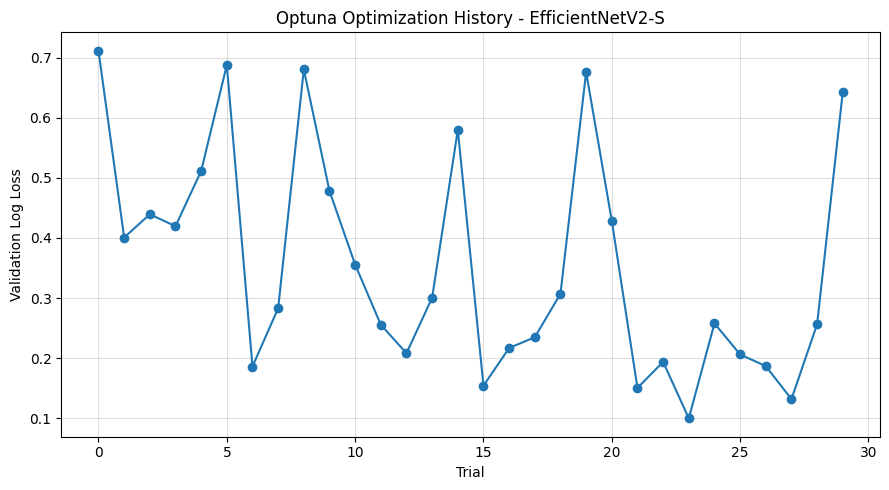


INICIANDO VALIDACIÓN CRUZADA - EFFICIENTNETV2-S
Cada fold utilizará exactamente 9 época(s) elegida(s) por HPO, sin EarlyStopping ni selección adicional de épocas.

FOLD 1/10
------------------------------------------------------------------------
Epoch 1/9
27/27 ━━━━━━━━━━━━━━━━━━━━ 45s 847ms/step - accuracy: 0.9527 - auc: 0.9942 - loss: 0.2409 - pr_auc: 0.9942 - precision: 0.9660 - recall: 0.9387 - val_accuracy: 0.9787 - val_auc: 1.0000 - val_loss: 0.1836 - val_pr_auc: 1.0000 - val_precision: 0.9583 - val_recall: 1.0000
Epoch 2/9
27/27 ━━━━━━━━━━━━━━━━━━━━ 33s 556ms/step - accuracy: 0.9882 - auc: 0.9997 - loss: 0.1528 - pr_auc: 0.9997 - precision: 0.9905 - recall: 0.9858 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.1677 - val_pr_auc: 1.0000 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 3/9
27/27 ━━━━━━━━━━━━━━━━━━━━ 16s 580ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 0.1392 - pr_auc: 1.0000 - precision: 1.0000 - recall: 1.0000 - val_accuracy: 1.0000 - val_auc: 1.00

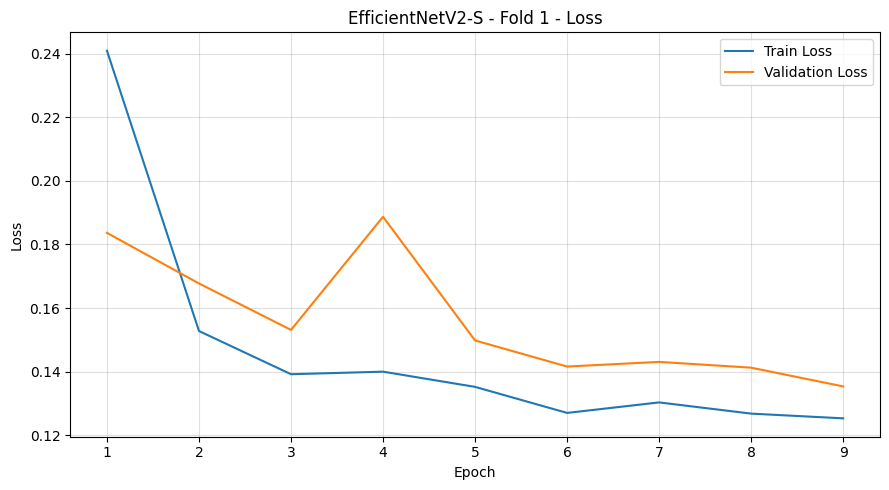

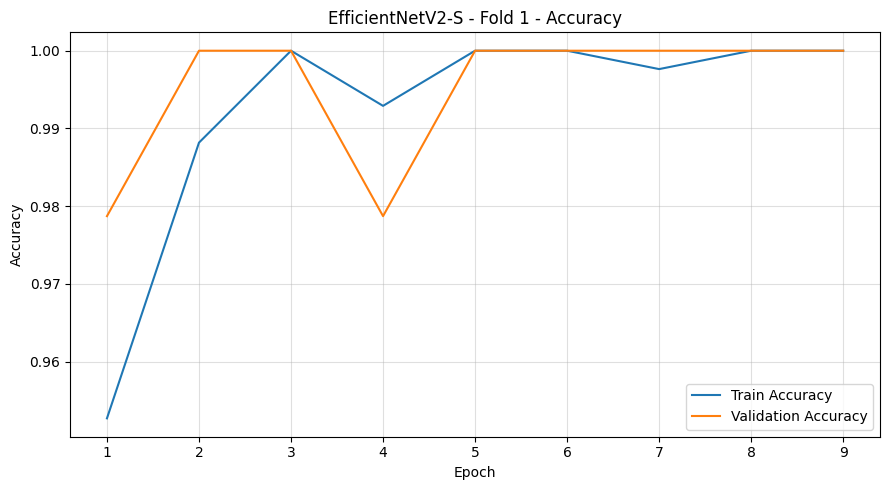

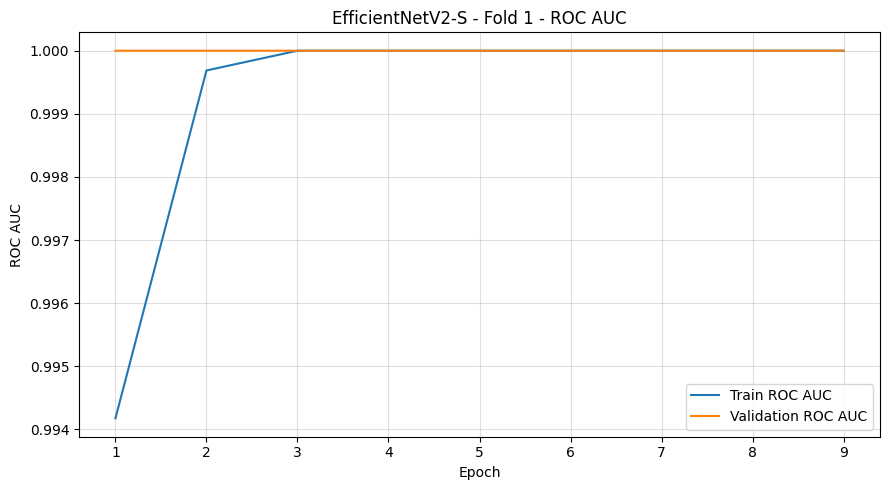

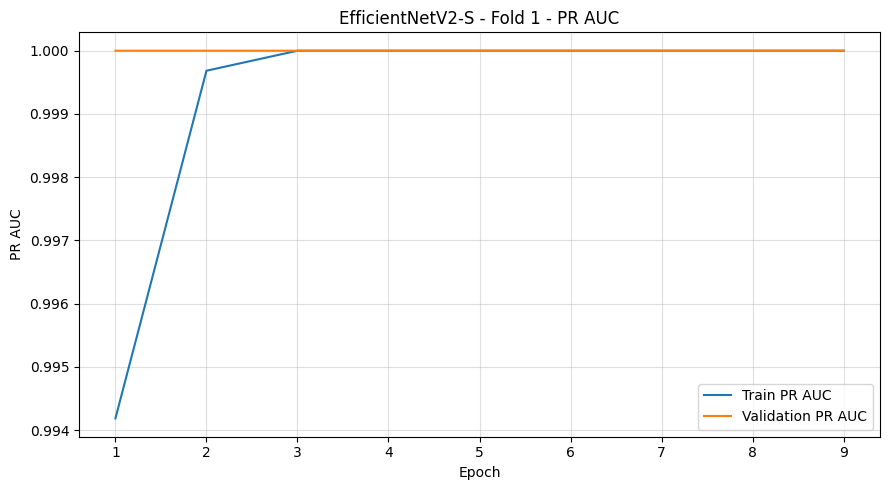

3/3 ━━━━━━━━━━━━━━━━━━━━ 11s 2s/step

Fold 01 | Acc: 1.0000 | Bal Acc: 1.0000 | F1: 1.0000 | ROC AUC: 1.0000 | PR AUC: 1.0000 | Log loss: 0.04537639 | Brier: 0.00538016 | ECE: 0.04219121


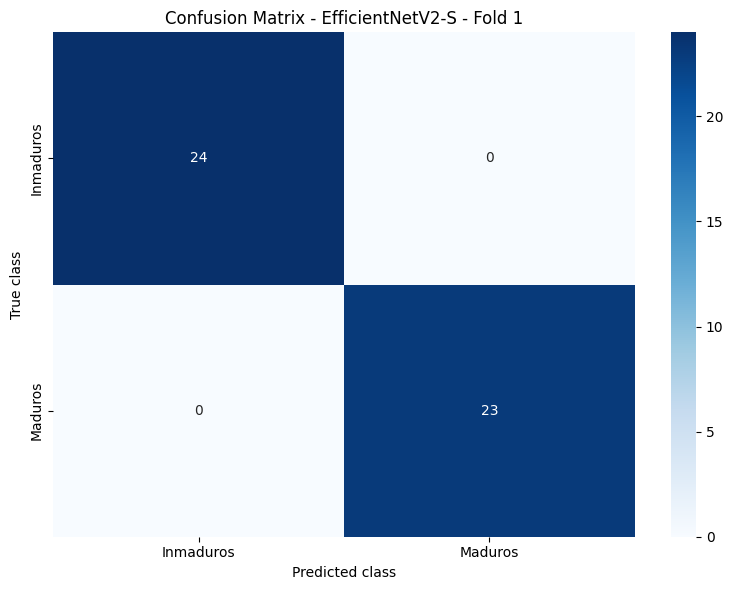

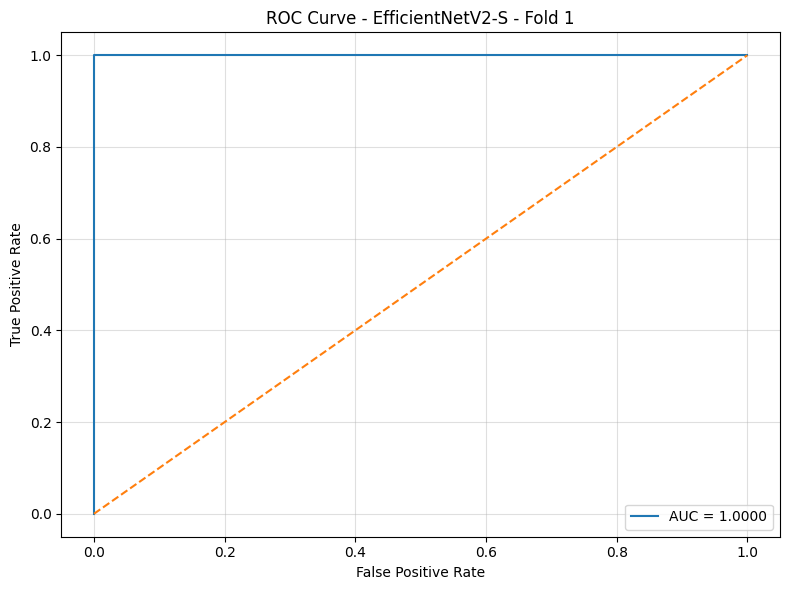

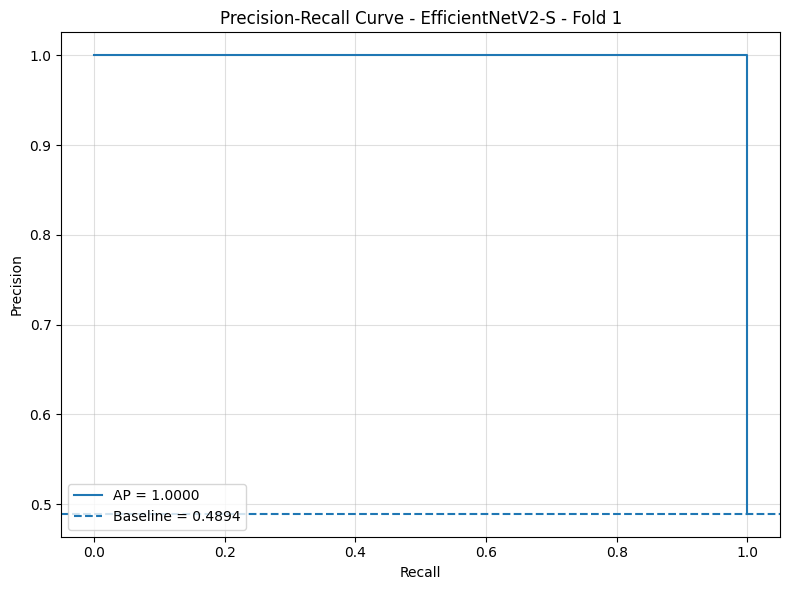

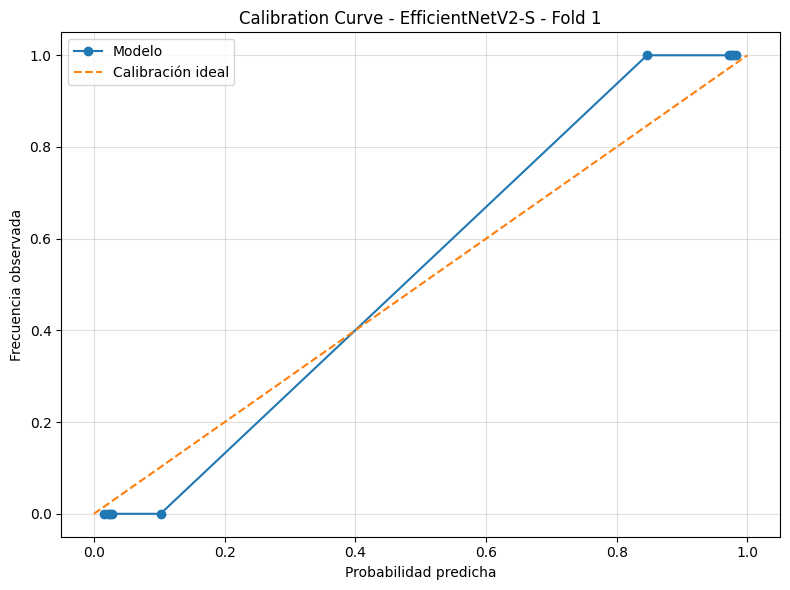

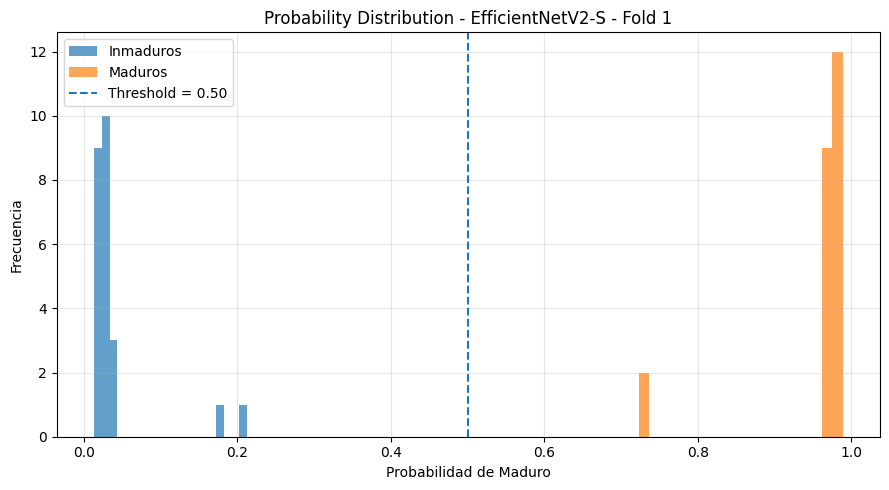

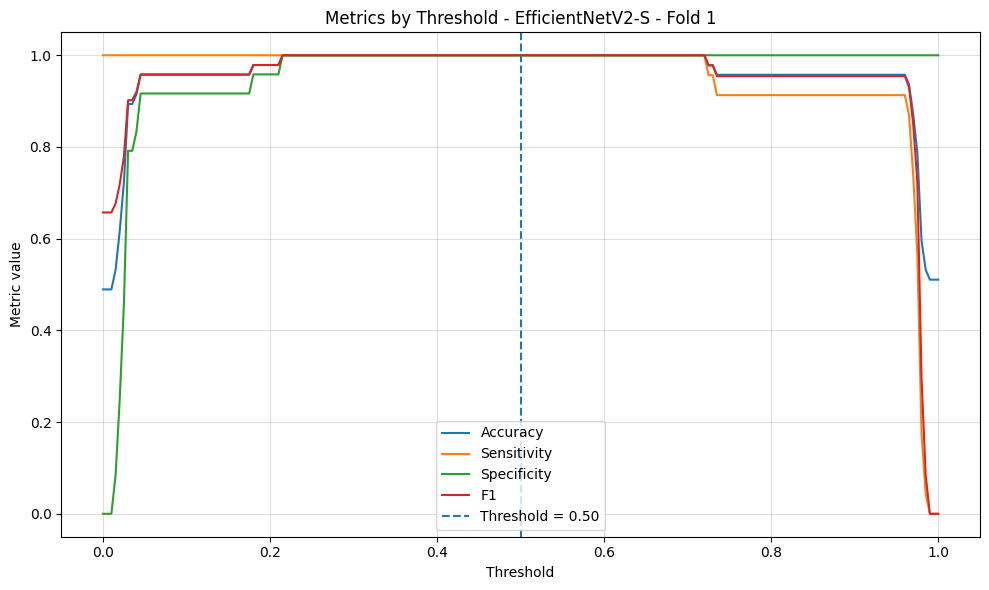


FOLD 2/10
------------------------------------------------------------------------
Epoch 1/9
27/27 ━━━━━━━━━━━━━━━━━━━━ 44s 829ms/step - accuracy: 0.9338 - auc: 0.9900 - loss: 0.2489 - pr_auc: 0.9902 - precision: 0.9381 - recall: 0.9292 - val_accuracy: 0.9787 - val_auc: 1.0000 - val_loss: 0.1853 - val_pr_auc: 1.0000 - val_precision: 0.9583 - val_recall: 1.0000
Epoch 2/9
27/27 ━━━━━━━━━━━━━━━━━━━━ 15s 564ms/step - accuracy: 0.9929 - auc: 0.9994 - loss: 0.1571 - pr_auc: 0.9994 - precision: 0.9953 - recall: 0.9906 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.1438 - val_pr_auc: 1.0000 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 3/9
27/27 ━━━━━━━━━━━━━━━━━━━━ 15s 561ms/step - accuracy: 0.9976 - auc: 1.0000 - loss: 0.1402 - pr_auc: 1.0000 - precision: 0.9953 - recall: 1.0000 - val_accuracy: 0.9787 - val_auc: 1.0000 - val_loss: 0.1796 - val_pr_auc: 1.0000 - val_precision: 0.9583 - val_recall: 1.0000
Epoch 4/9
27/27 ━━━━━━━━━━━━━━━━━━━━ 15s 568ms/step - accuracy: 0.9976 - auc

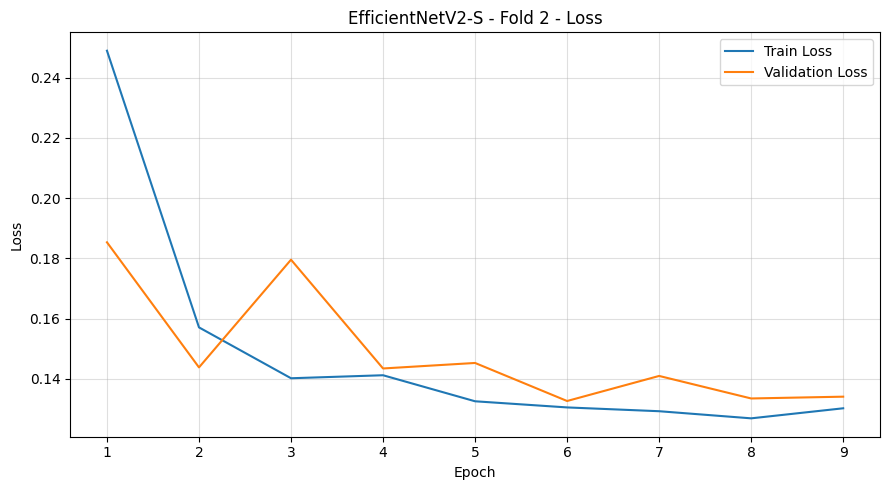

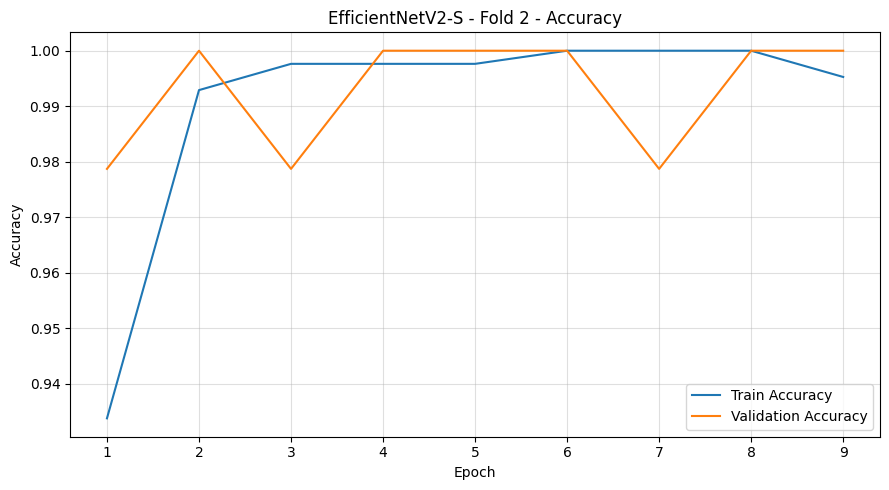

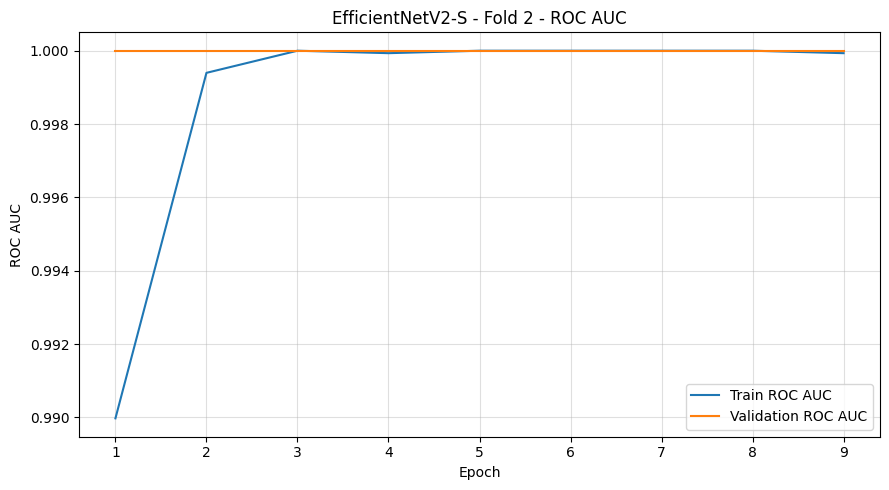

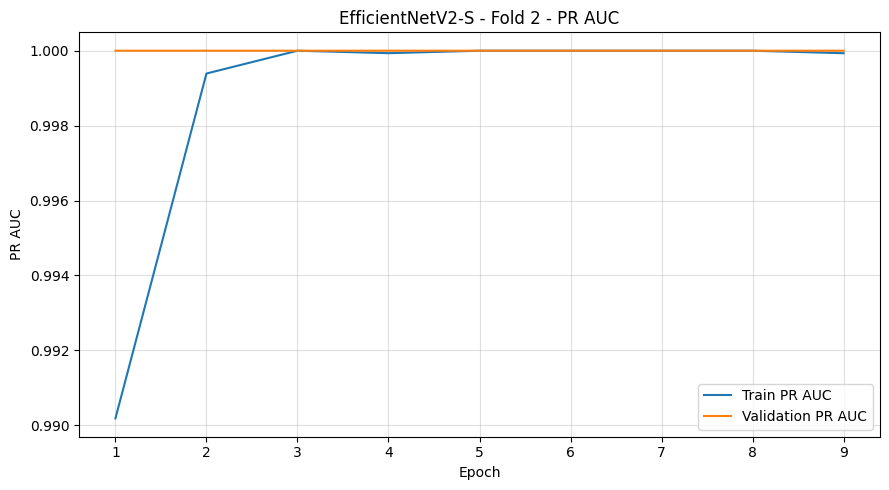

3/3 ━━━━━━━━━━━━━━━━━━━━ 9s 2s/step

Fold 02 | Acc: 1.0000 | Bal Acc: 1.0000 | F1: 1.0000 | ROC AUC: 1.0000 | PR AUC: 1.0000 | Log loss: 0.04405067 | Brier: 0.00586204 | ECE: 0.03999902


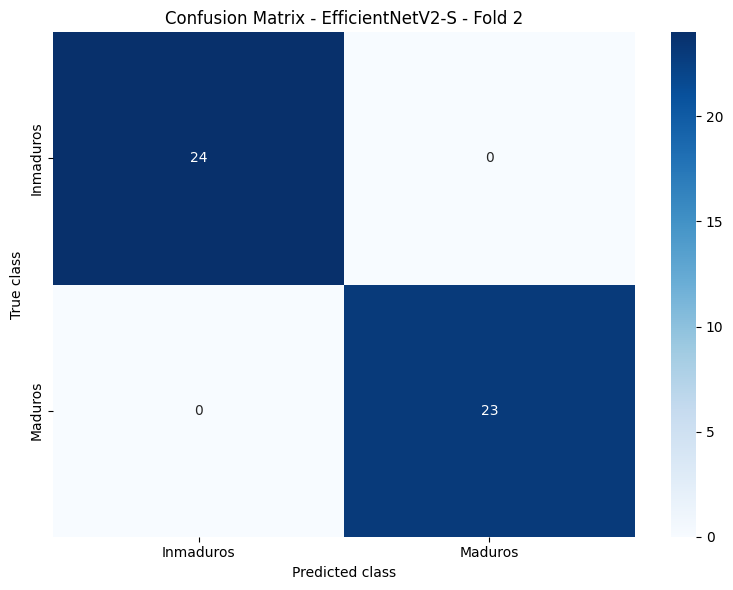

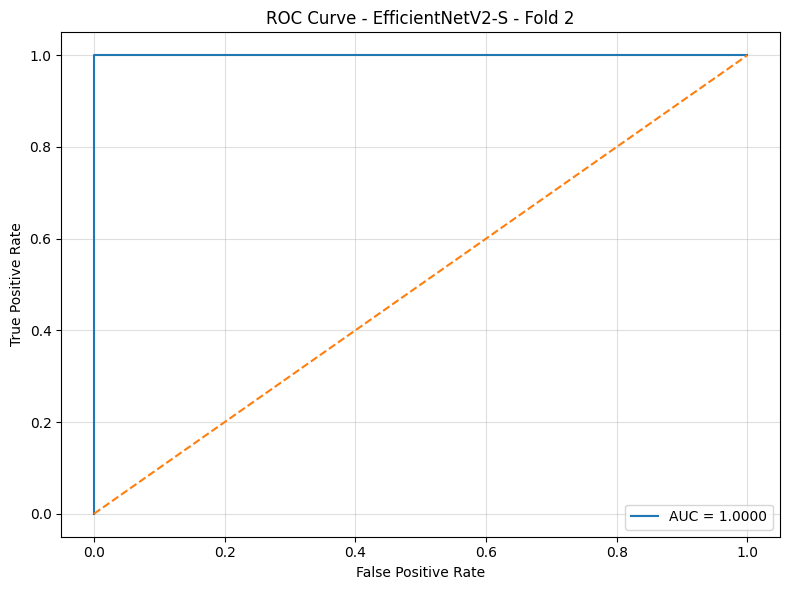

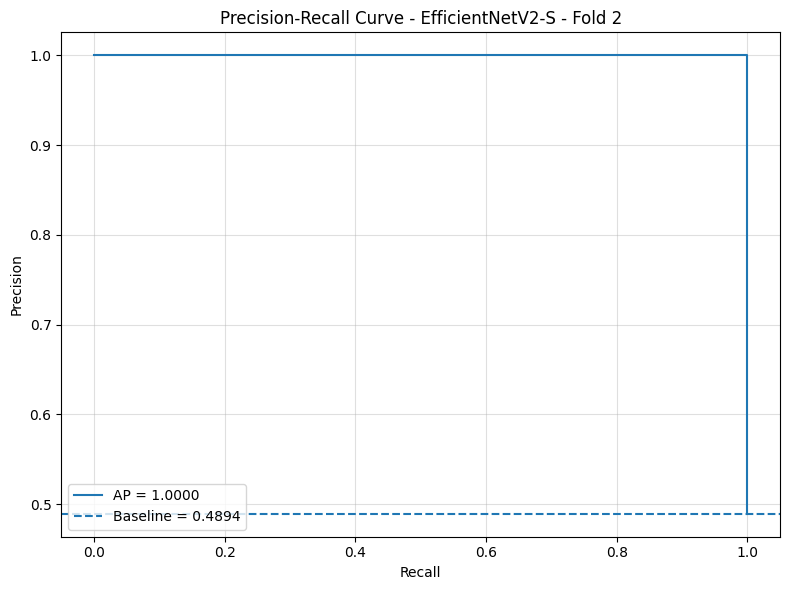

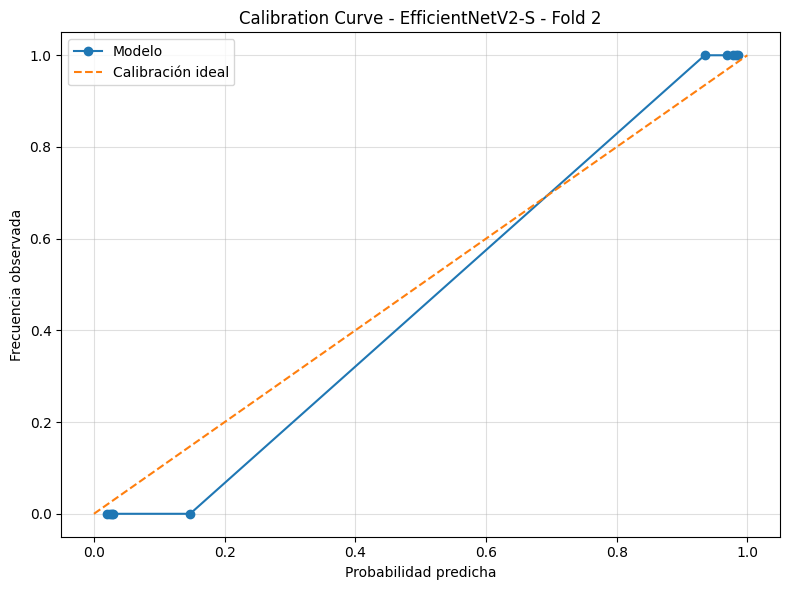

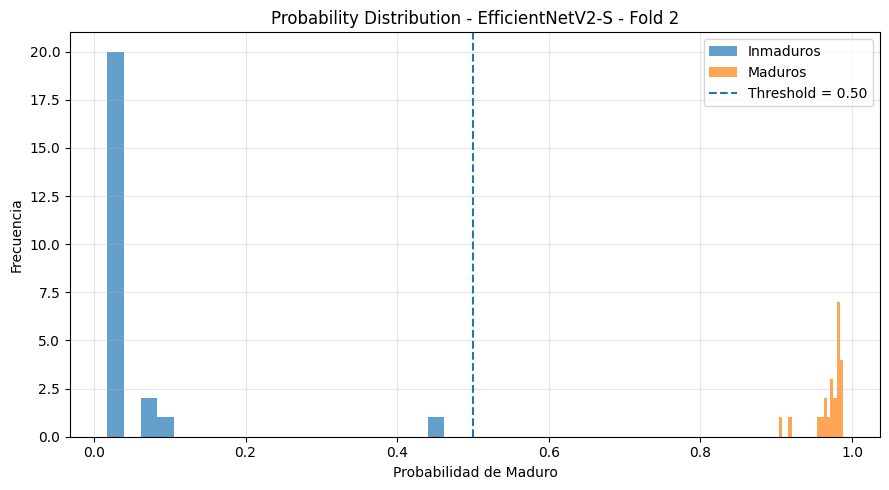

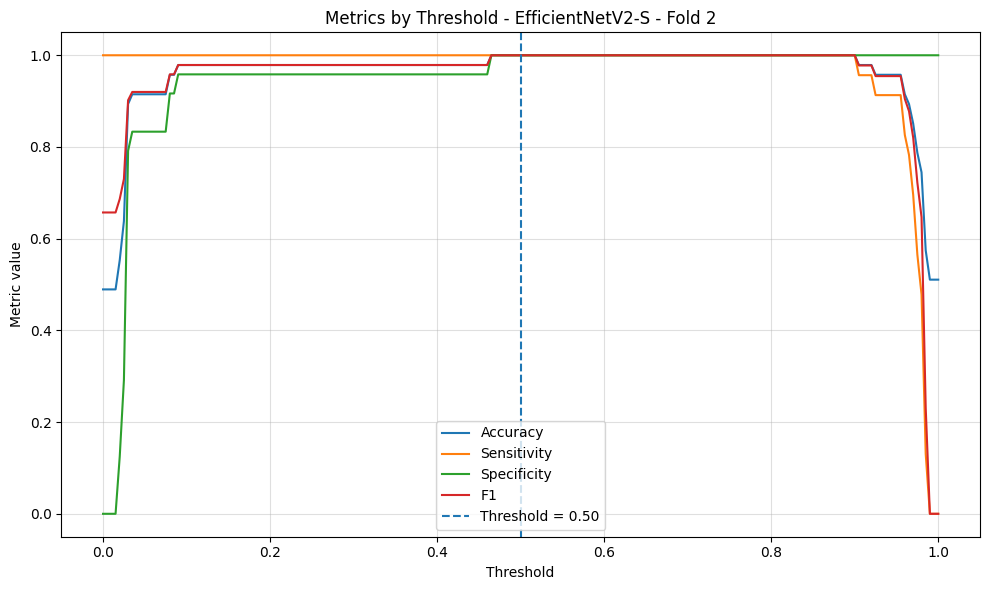


FOLD 3/10
------------------------------------------------------------------------
Epoch 1/9
27/27 ━━━━━━━━━━━━━━━━━━━━ 45s 776ms/step - accuracy: 0.9338 - auc: 0.9870 - loss: 0.2603 - pr_auc: 0.9878 - precision: 0.9423 - recall: 0.9245 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.1476 - val_pr_auc: 1.0000 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 2/9
27/27 ━━━━━━━━━━━━━━━━━━━━ 16s 583ms/step - accuracy: 0.9905 - auc: 0.9998 - loss: 0.1513 - pr_auc: 0.9998 - precision: 0.9906 - recall: 0.9906 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.1427 - val_pr_auc: 1.0000 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 3/9
27/27 ━━━━━━━━━━━━━━━━━━━━ 15s 570ms/step - accuracy: 0.9929 - auc: 1.0000 - loss: 0.1416 - pr_auc: 1.0000 - precision: 0.9953 - recall: 0.9906 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.1324 - val_pr_auc: 1.0000 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 4/9
27/27 ━━━━━━━━━━━━━━━━━━━━ 16s 583ms/step - accuracy: 0.9976 - auc

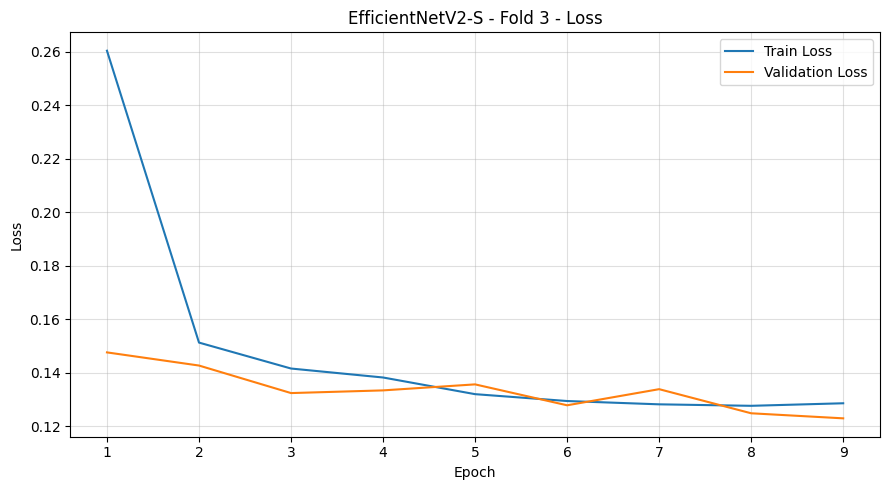

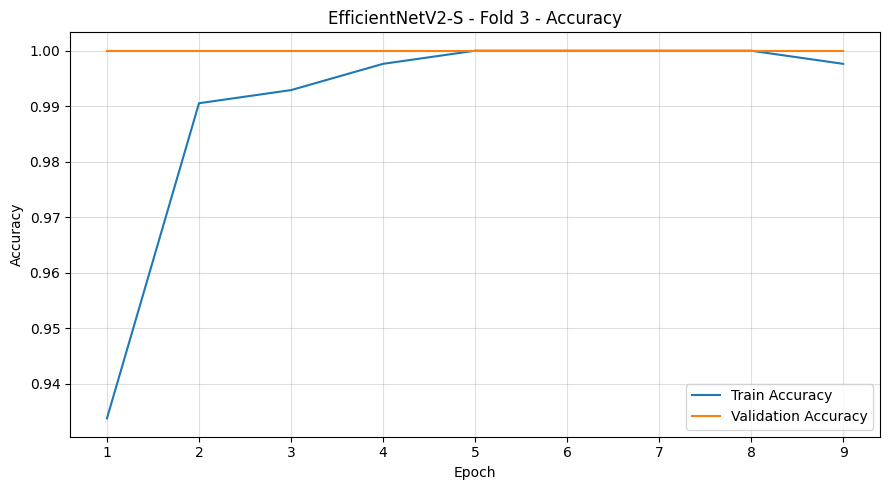

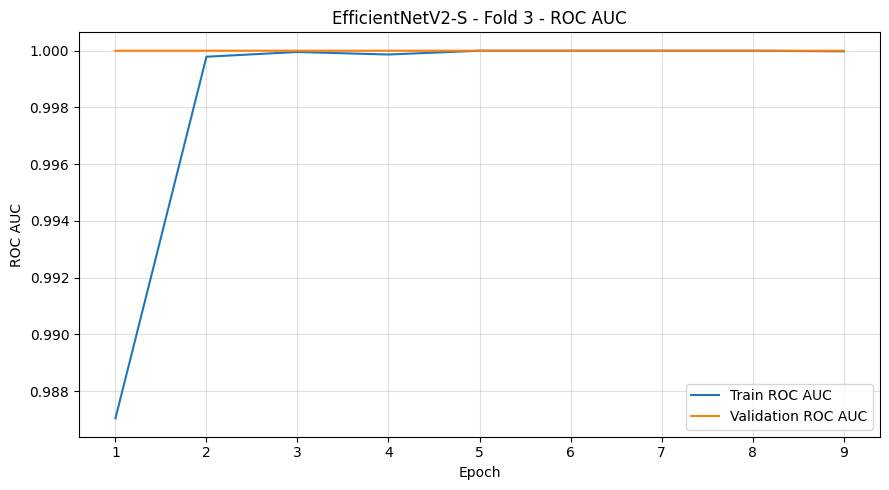

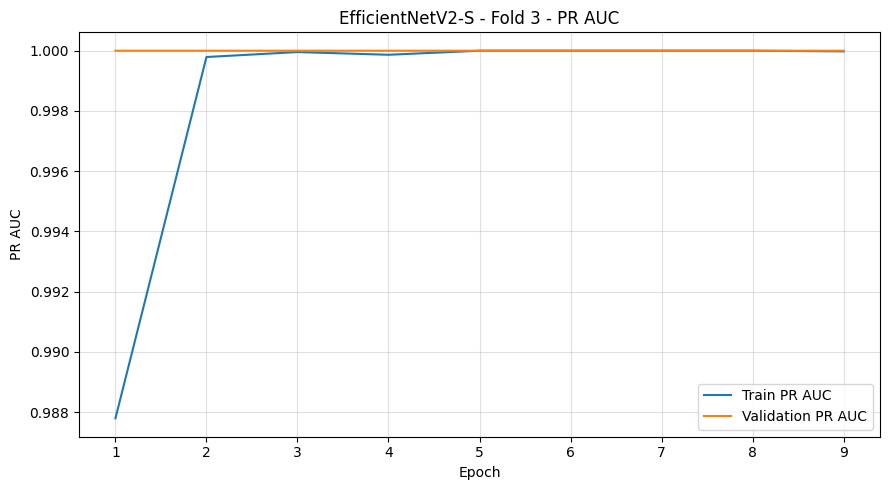

3/3 ━━━━━━━━━━━━━━━━━━━━ 11s 3s/step

Fold 03 | Acc: 1.0000 | Bal Acc: 1.0000 | F1: 1.0000 | ROC AUC: 1.0000 | PR AUC: 1.0000 | Log loss: 0.02497882 | Brier: 0.00089206 | ECE: 0.02451476


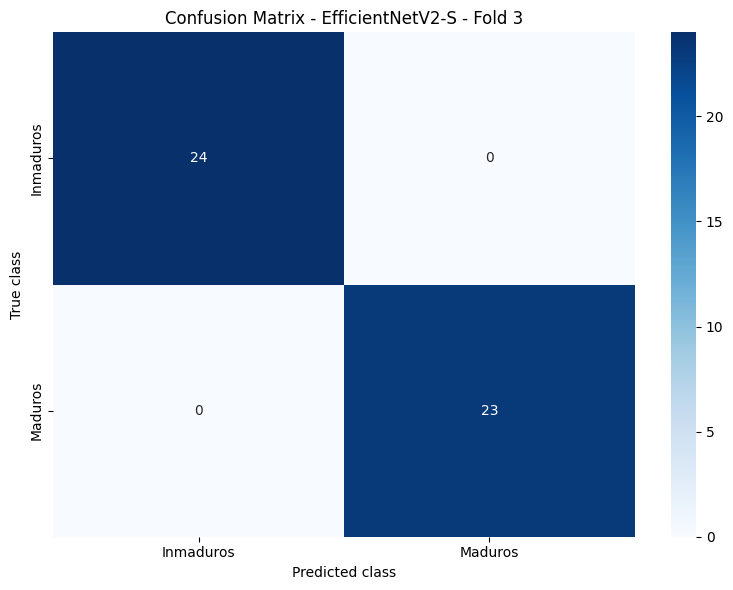

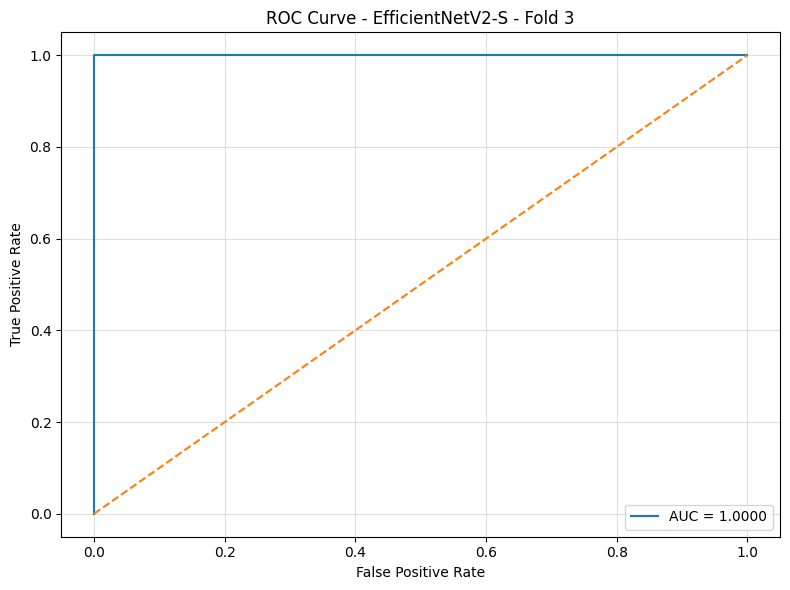

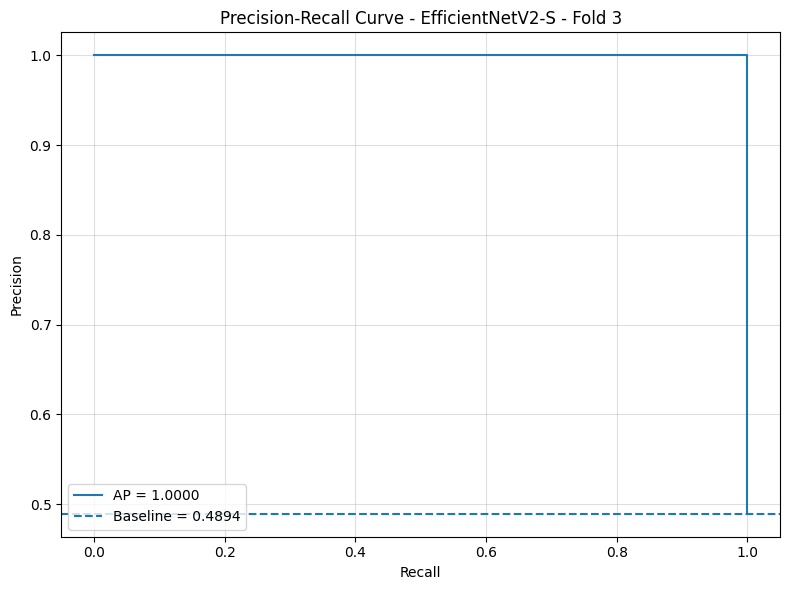

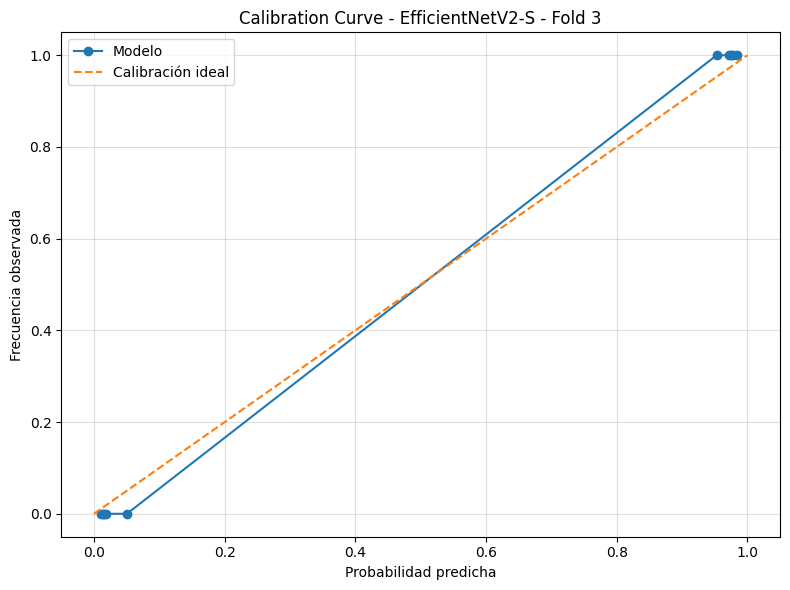

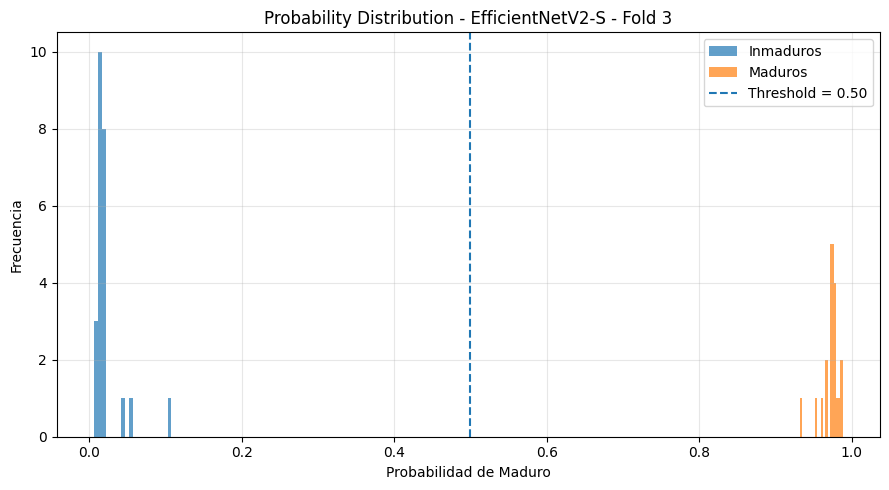

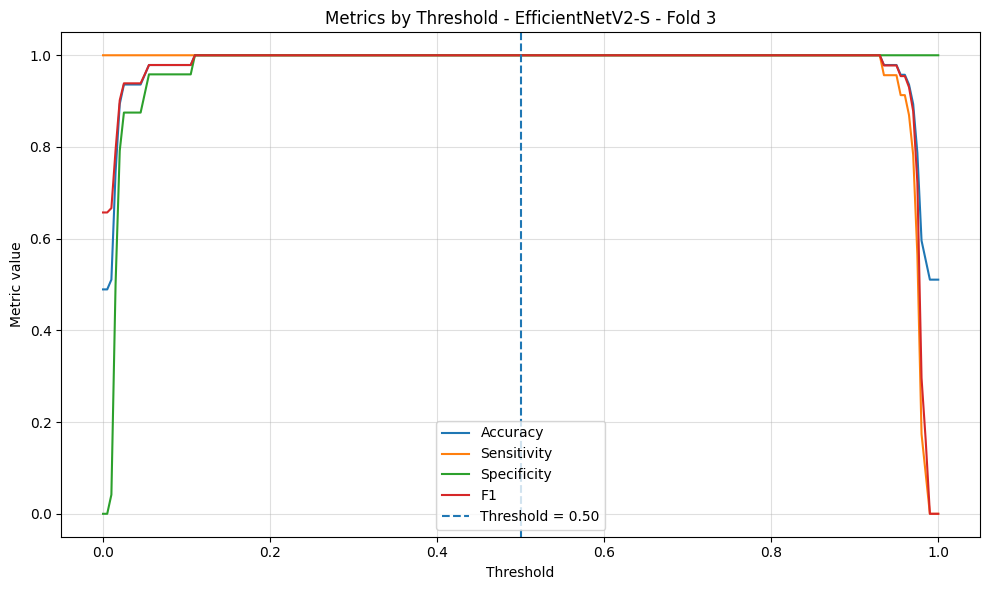


FOLD 4/10
------------------------------------------------------------------------
Epoch 1/9
27/27 ━━━━━━━━━━━━━━━━━━━━ 45s 802ms/step - accuracy: 0.9574 - auc: 0.9924 - loss: 0.2392 - pr_auc: 0.9930 - precision: 0.9619 - recall: 0.9528 - val_accuracy: 0.8511 - val_auc: 0.9891 - val_loss: 0.2921 - val_pr_auc: 0.9908 - val_precision: 0.7857 - val_recall: 0.9565
Epoch 2/9
27/27 ━━━━━━━━━━━━━━━━━━━━ 35s 592ms/step - accuracy: 0.9953 - auc: 0.9999 - loss: 0.1509 - pr_auc: 0.9999 - precision: 0.9953 - recall: 0.9953 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.1835 - val_pr_auc: 1.0000 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 3/9
27/27 ━━━━━━━━━━━━━━━━━━━━ 15s 573ms/step - accuracy: 0.9953 - auc: 0.9999 - loss: 0.1438 - pr_auc: 0.9999 - precision: 0.9953 - recall: 0.9953 - val_accuracy: 0.9787 - val_auc: 1.0000 - val_loss: 0.1638 - val_pr_auc: 1.0000 - val_precision: 1.0000 - val_recall: 0.9565
Epoch 4/9
27/27 ━━━━━━━━━━━━━━━━━━━━ 15s 570ms/step - accuracy: 1.0000 - auc

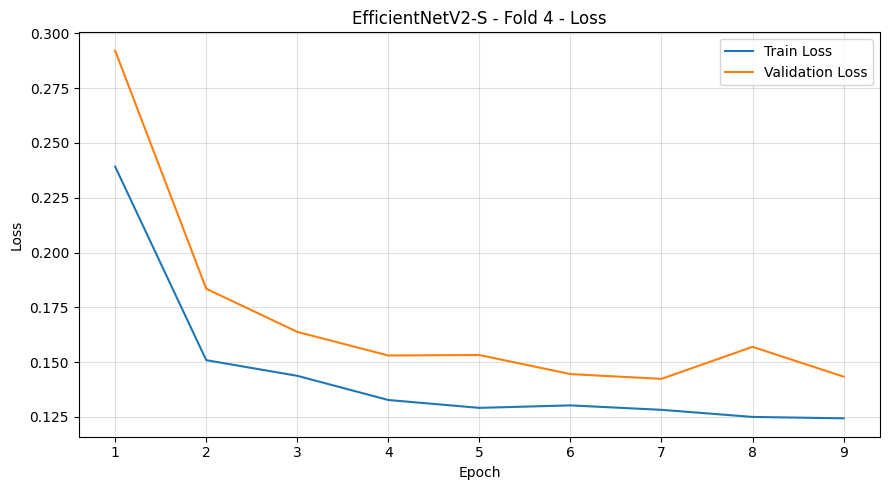

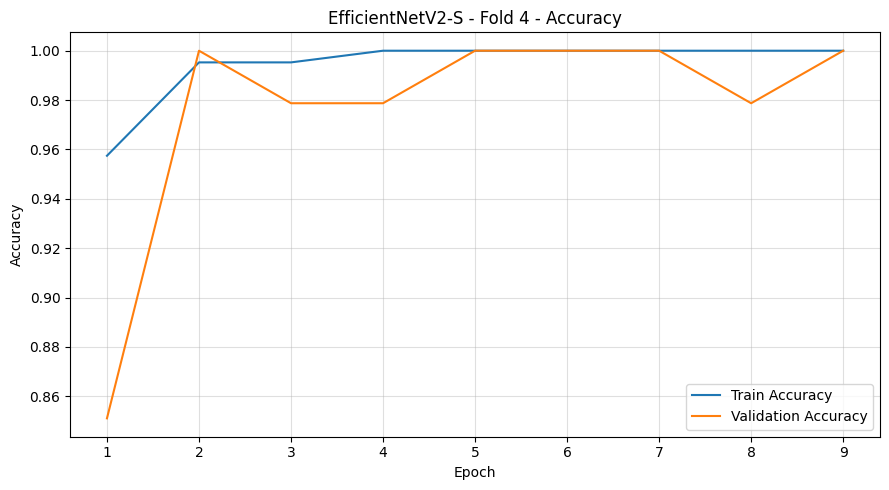

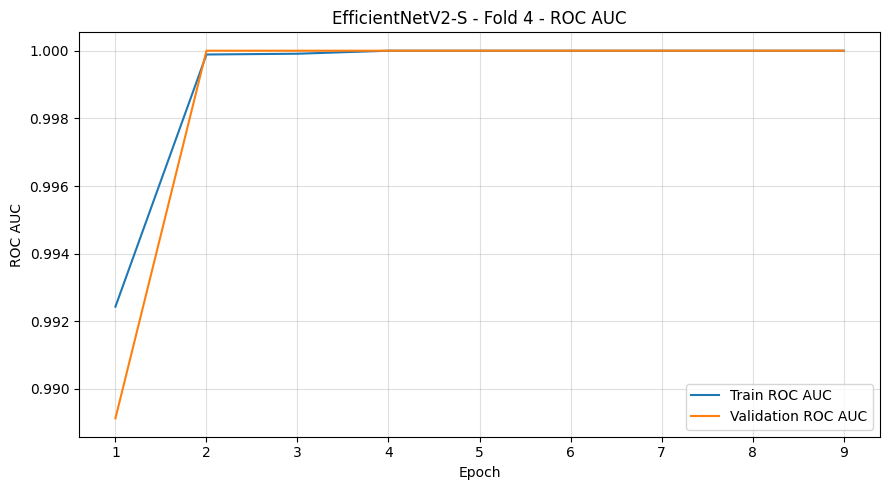

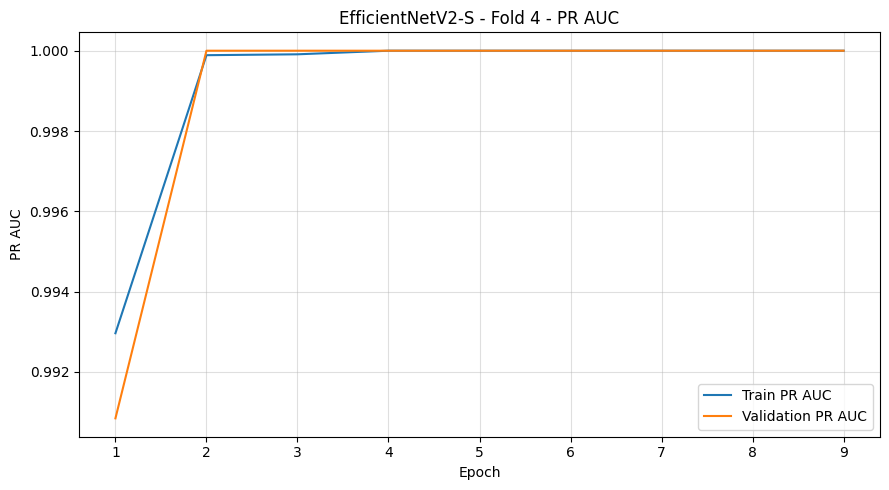

3/3 ━━━━━━━━━━━━━━━━━━━━ 11s 2s/step

Fold 04 | Acc: 1.0000 | Bal Acc: 1.0000 | F1: 1.0000 | ROC AUC: 1.0000 | PR AUC: 1.0000 | Log loss: 0.06210701 | Brier: 0.00795809 | ECE: 0.05730957


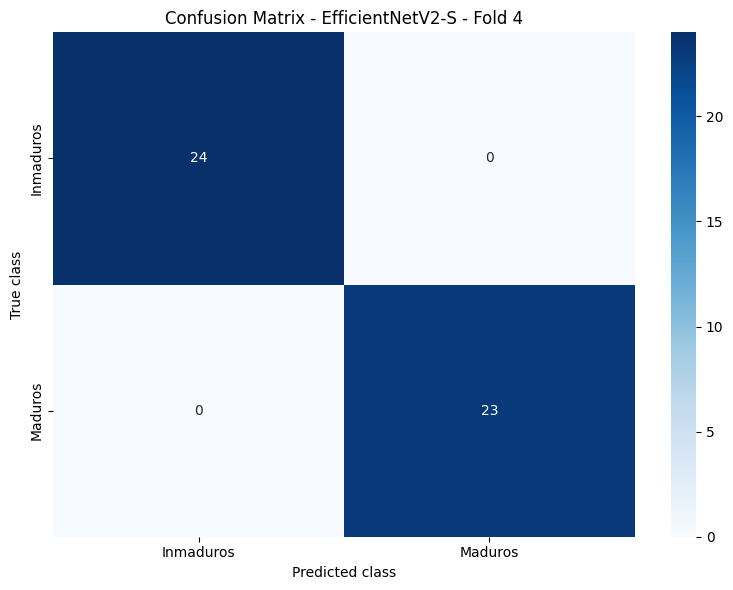

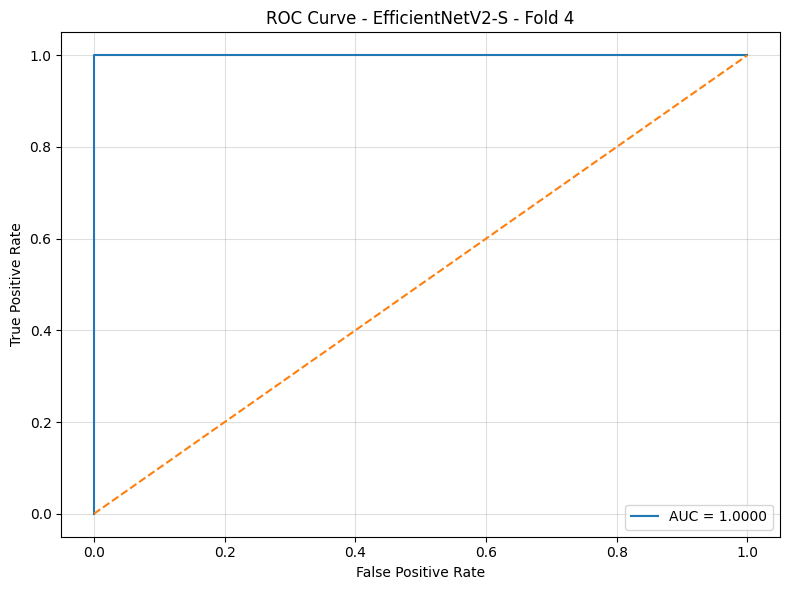

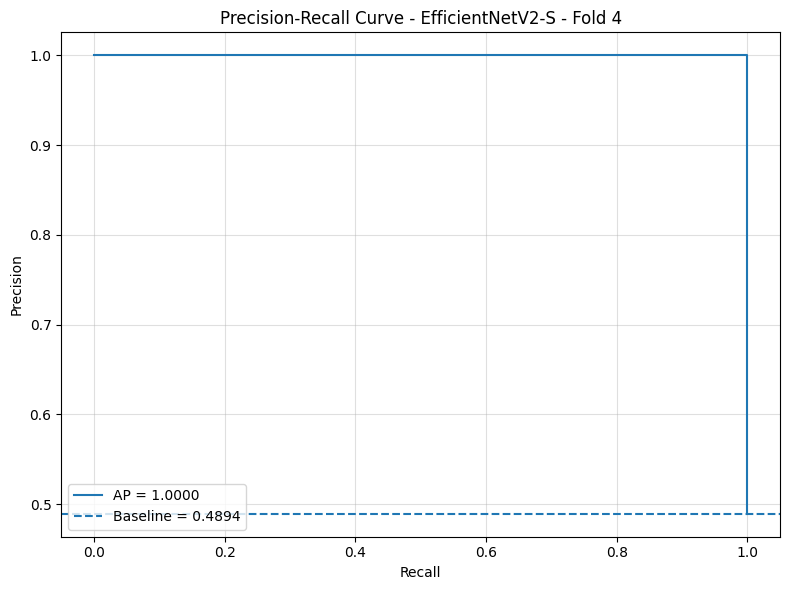

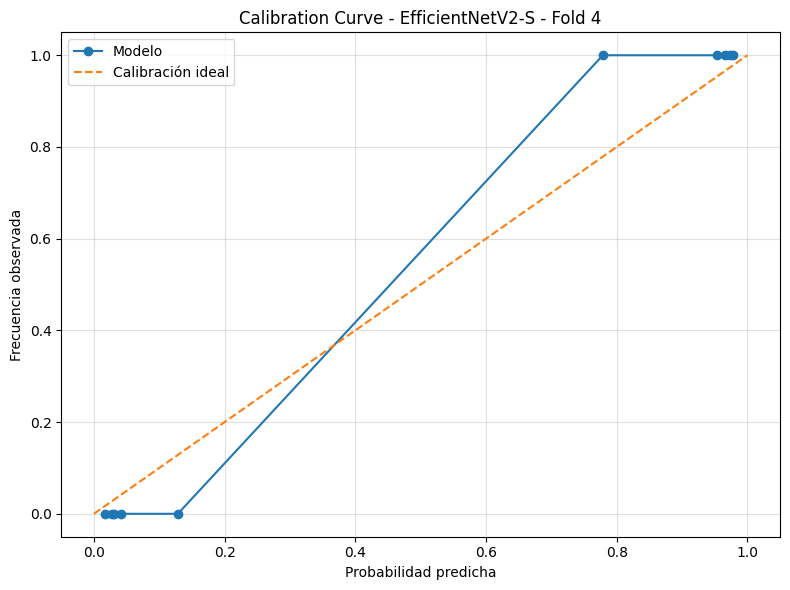

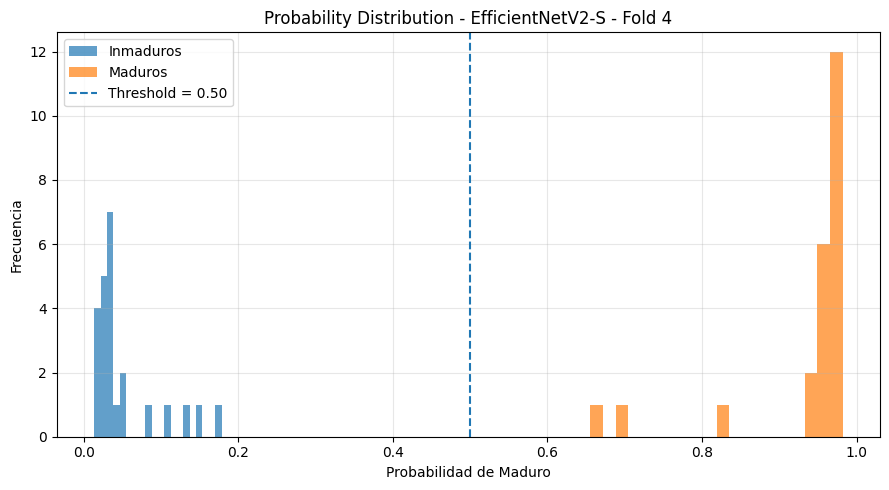

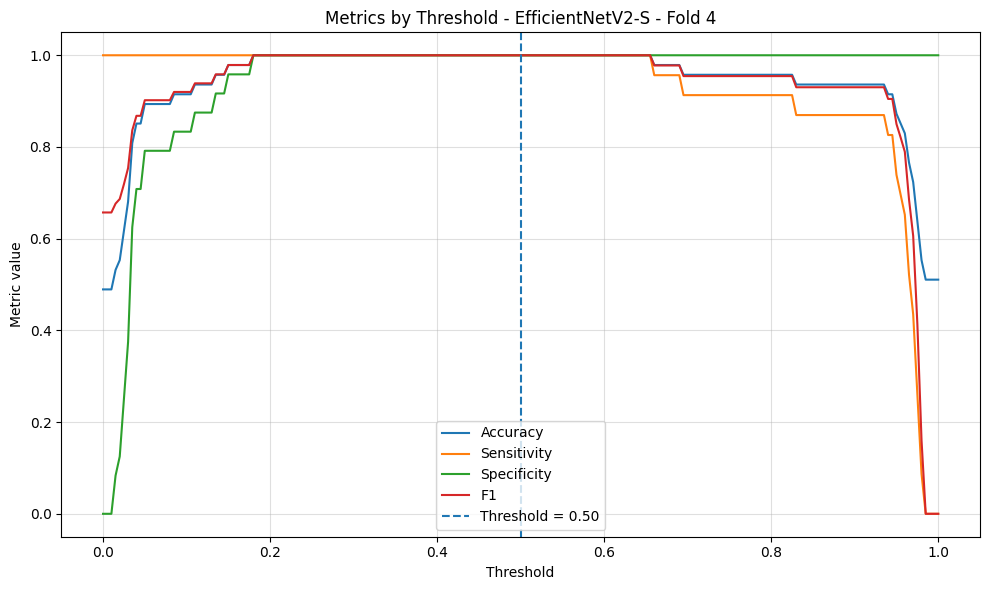


FOLD 5/10
------------------------------------------------------------------------
Epoch 1/9
27/27 ━━━━━━━━━━━━━━━━━━━━ 45s 827ms/step - accuracy: 0.9243 - auc: 0.9853 - loss: 0.2669 - pr_auc: 0.9859 - precision: 0.9245 - recall: 0.9245 - val_accuracy: 0.9787 - val_auc: 0.9982 - val_loss: 0.2635 - val_pr_auc: 0.9981 - val_precision: 0.9583 - val_recall: 1.0000
Epoch 2/9
27/27 ━━━━━━━━━━━━━━━━━━━━ 16s 574ms/step - accuracy: 0.9976 - auc: 1.0000 - loss: 0.1466 - pr_auc: 1.0000 - precision: 0.9953 - recall: 1.0000 - val_accuracy: 0.9787 - val_auc: 0.9982 - val_loss: 0.1805 - val_pr_auc: 0.9981 - val_precision: 1.0000 - val_recall: 0.9565
Epoch 3/9
27/27 ━━━━━━━━━━━━━━━━━━━━ 16s 584ms/step - accuracy: 0.9976 - auc: 1.0000 - loss: 0.1405 - pr_auc: 1.0000 - precision: 1.0000 - recall: 0.9953 - val_accuracy: 0.9787 - val_auc: 0.9982 - val_loss: 0.1691 - val_pr_auc: 0.9981 - val_precision: 1.0000 - val_recall: 0.9565
Epoch 4/9
27/27 ━━━━━━━━━━━━━━━━━━━━ 16s 577ms/step - accuracy: 1.0000 - auc

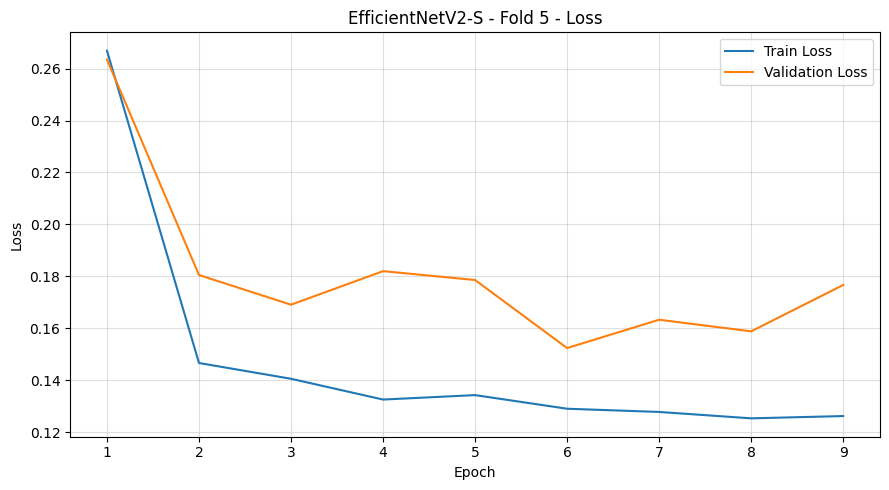

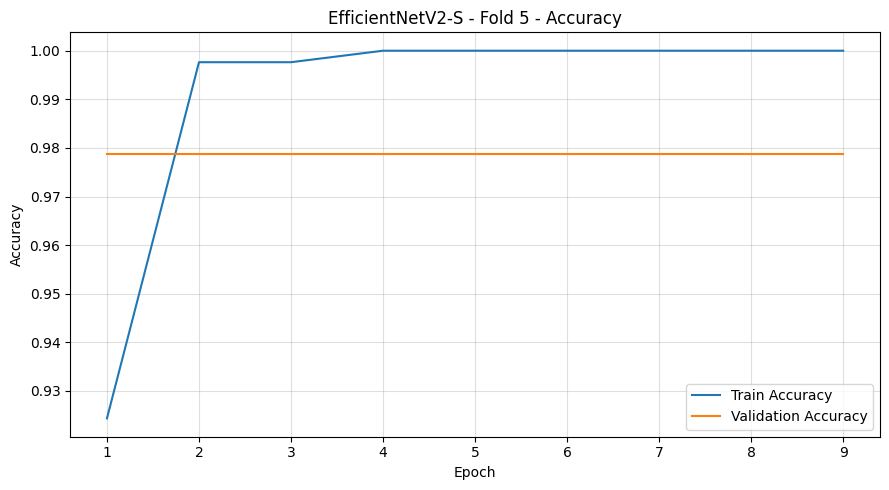

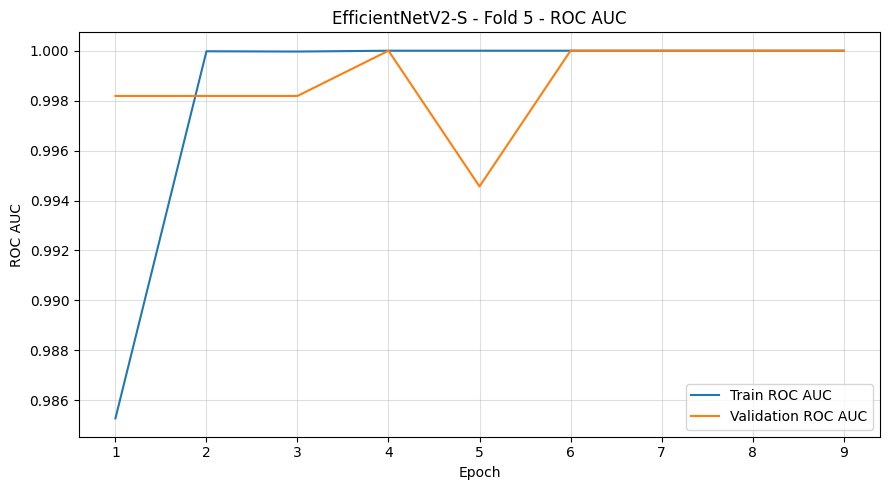

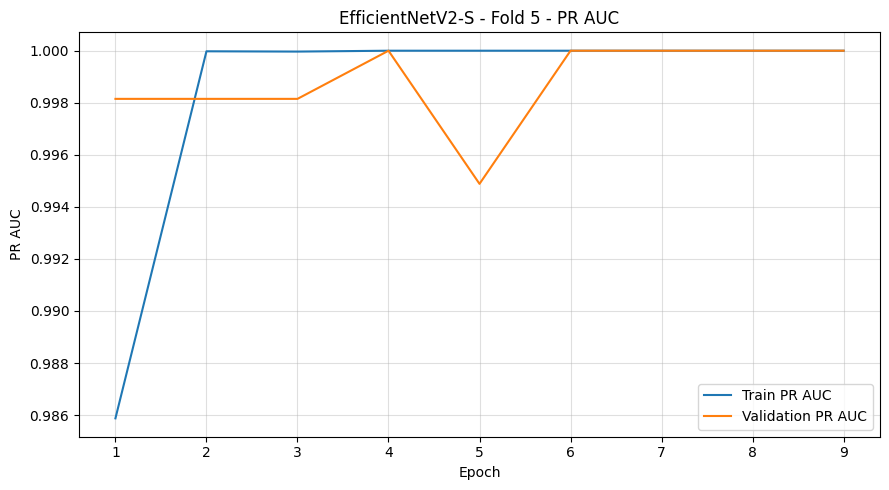

3/3 ━━━━━━━━━━━━━━━━━━━━ 10s 3s/step

Fold 05 | Acc: 0.9787 | Bal Acc: 0.9783 | F1: 0.9778 | ROC AUC: 1.0000 | PR AUC: 1.0000 | Log loss: 0.09338237 | Brier: 0.02009978 | ECE: 0.01681577


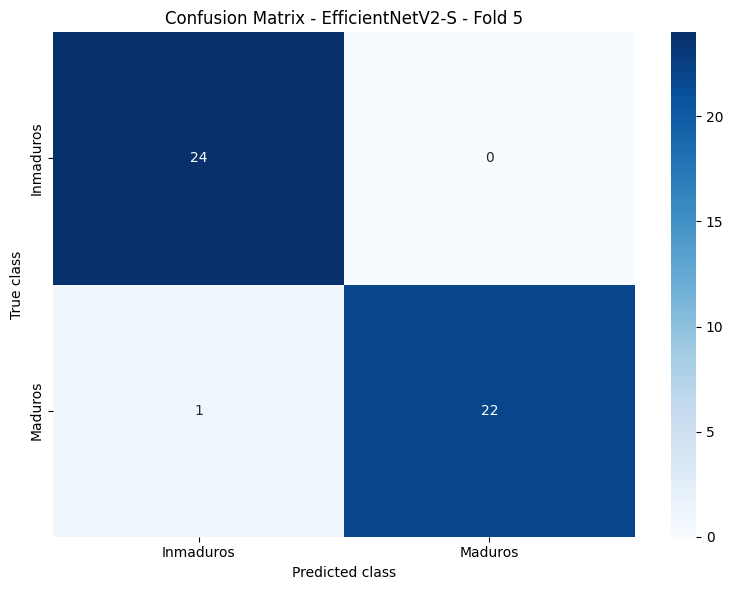

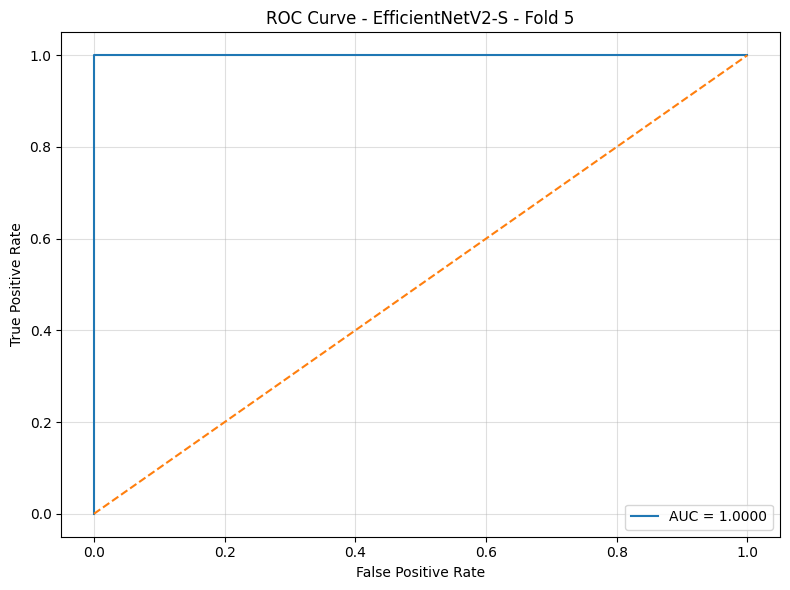

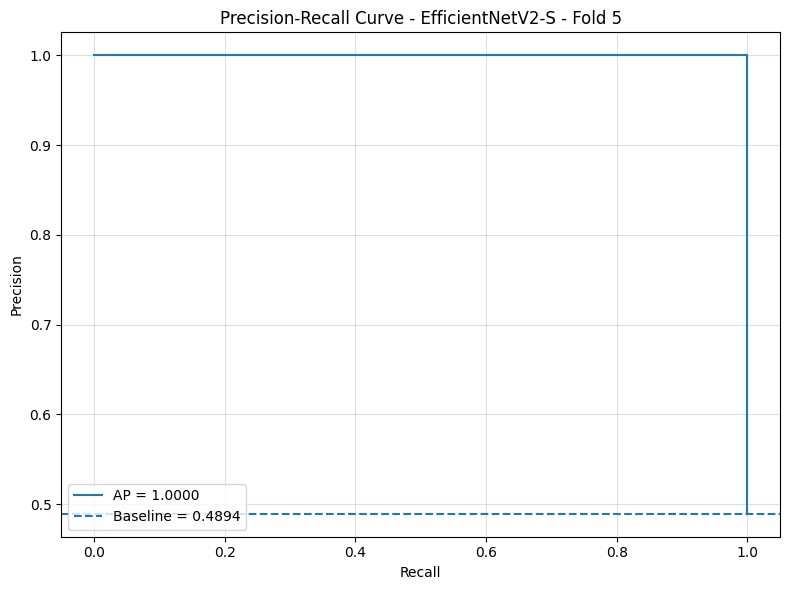

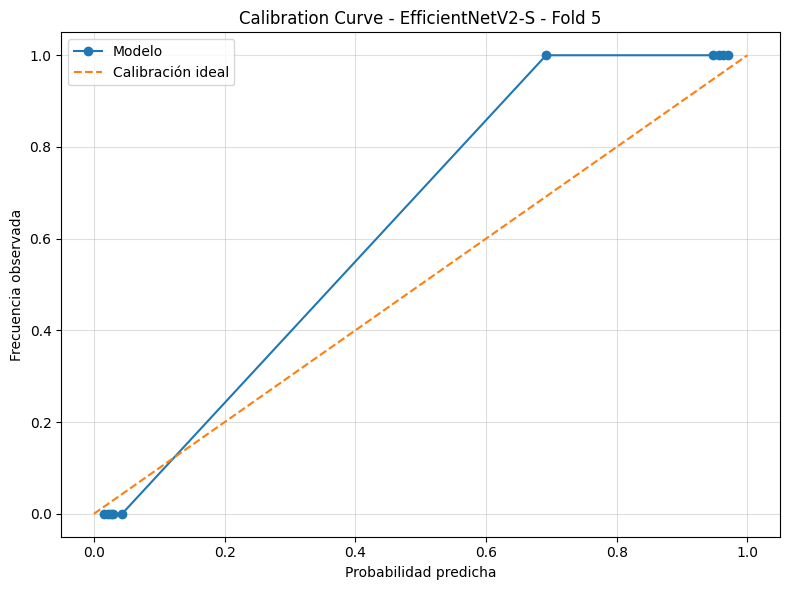

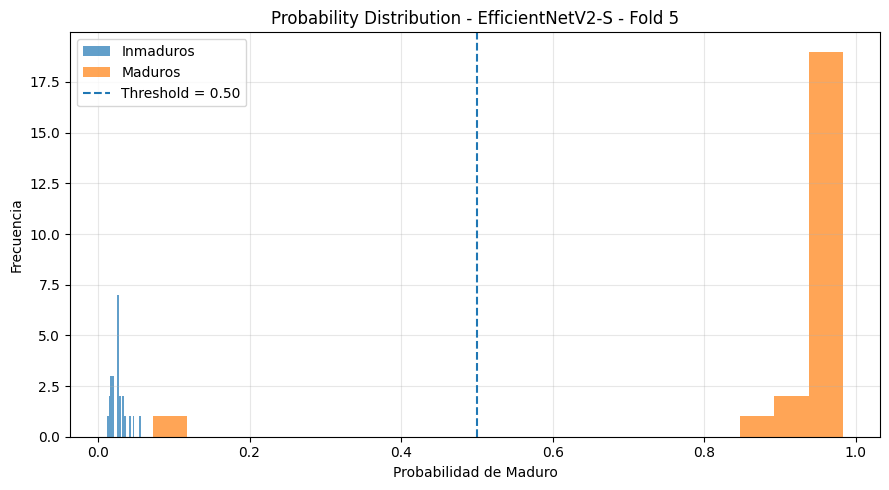

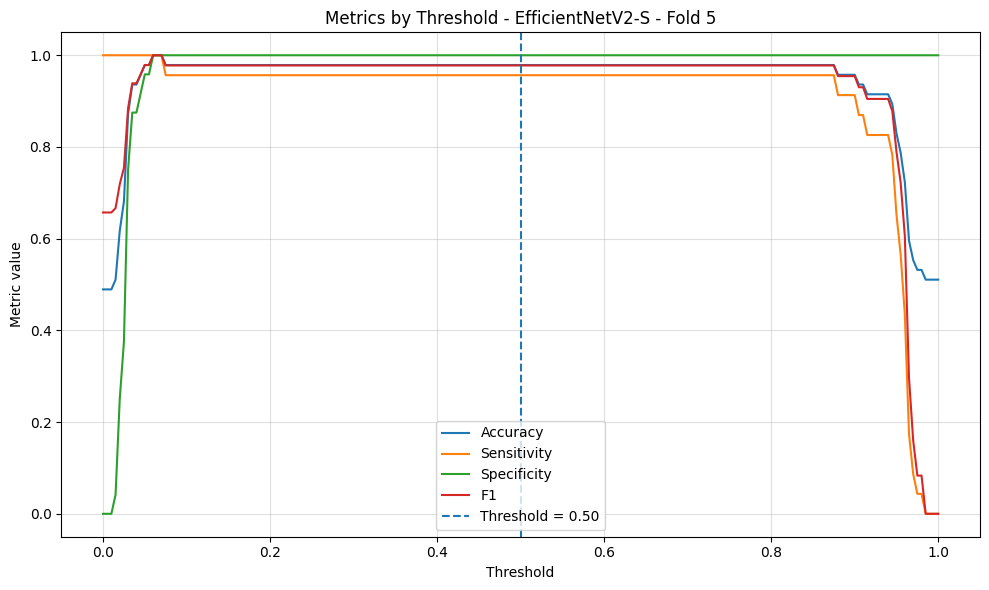


FOLD 6/10
------------------------------------------------------------------------
Epoch 1/9
27/27 ━━━━━━━━━━━━━━━━━━━━ 45s 818ms/step - accuracy: 0.9504 - auc: 0.9890 - loss: 0.2534 - pr_auc: 0.9887 - precision: 0.9398 - recall: 0.9621 - val_accuracy: 0.8511 - val_auc: 1.0000 - val_loss: 0.3097 - val_pr_auc: 1.0000 - val_precision: 0.7742 - val_recall: 1.0000
Epoch 2/9
27/27 ━━━━━━━━━━━━━━━━━━━━ 17s 598ms/step - accuracy: 0.9953 - auc: 1.0000 - loss: 0.1483 - pr_auc: 1.0000 - precision: 0.9953 - recall: 0.9953 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.1585 - val_pr_auc: 1.0000 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 3/9
27/27 ━━━━━━━━━━━━━━━━━━━━ 16s 588ms/step - accuracy: 0.9976 - auc: 1.0000 - loss: 0.1383 - pr_auc: 1.0000 - precision: 1.0000 - recall: 0.9953 - val_accuracy: 0.9787 - val_auc: 1.0000 - val_loss: 0.1620 - val_pr_auc: 1.0000 - val_precision: 0.9600 - val_recall: 1.0000
Epoch 4/9
27/27 ━━━━━━━━━━━━━━━━━━━━ 16s 590ms/step - accuracy: 0.9976 - auc

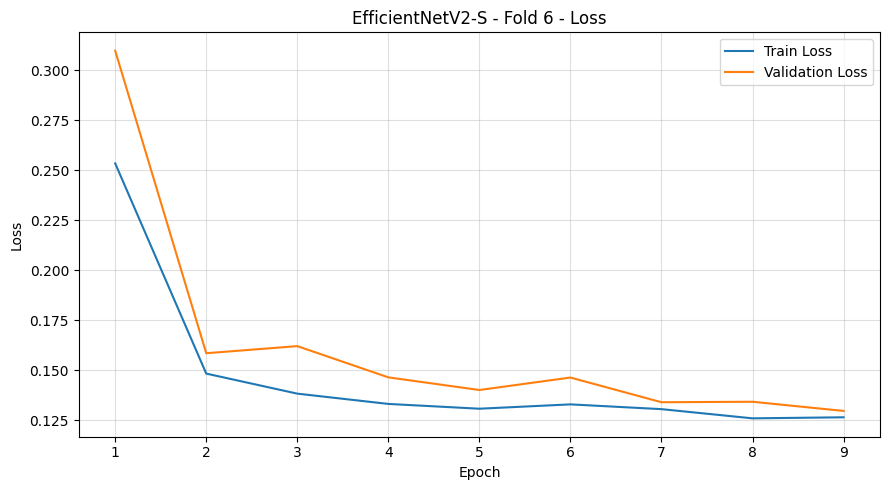

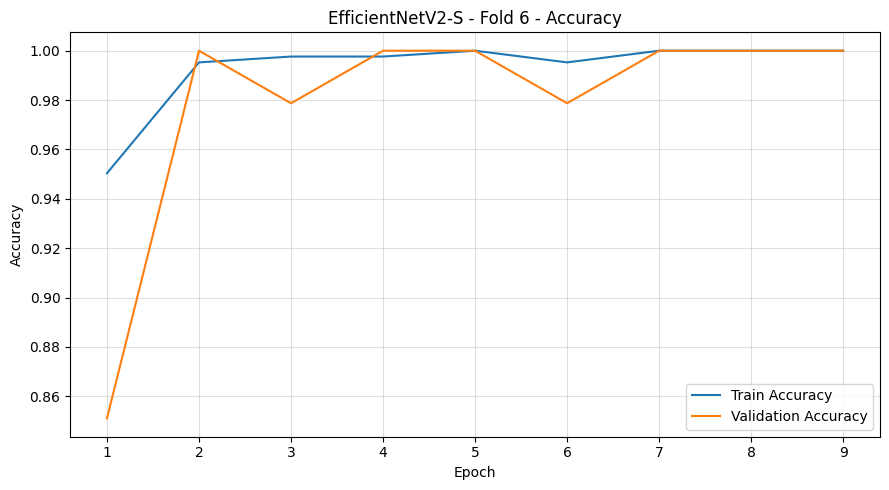

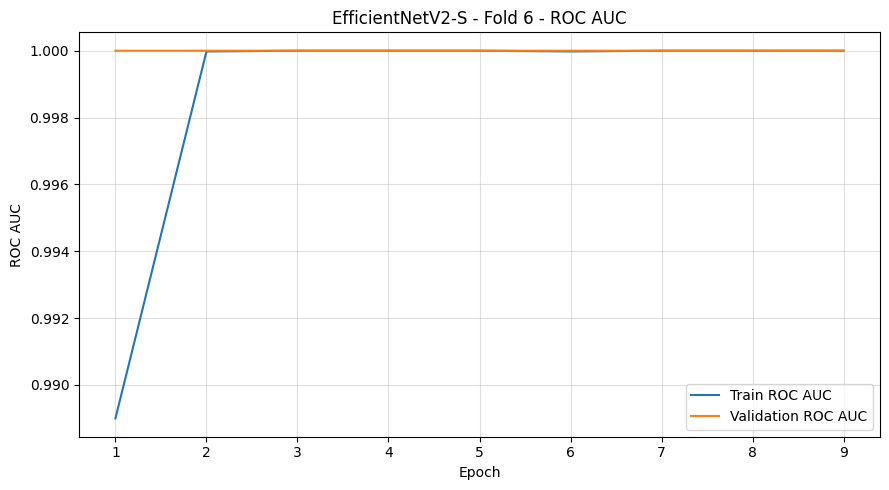

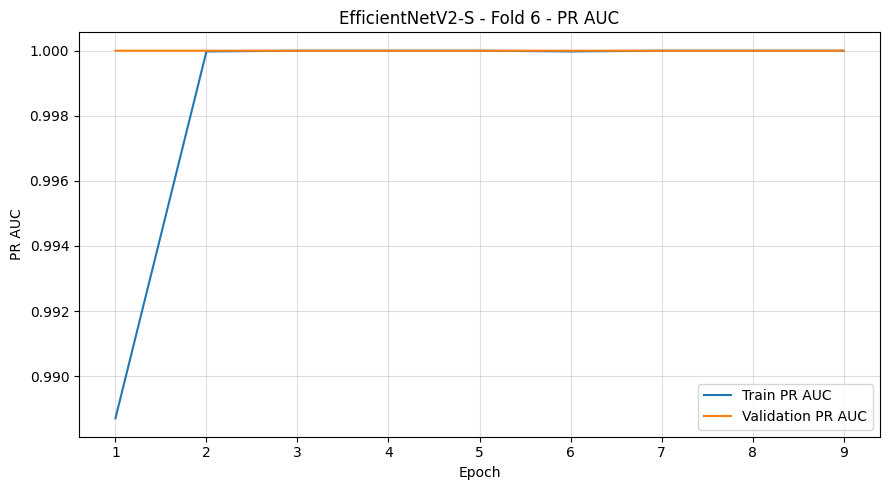

3/3 ━━━━━━━━━━━━━━━━━━━━ 11s 3s/step

Fold 06 | Acc: 1.0000 | Bal Acc: 1.0000 | F1: 1.0000 | ROC AUC: 1.0000 | PR AUC: 1.0000 | Log loss: 0.04580249 | Brier: 0.00359371 | ECE: 0.04374965


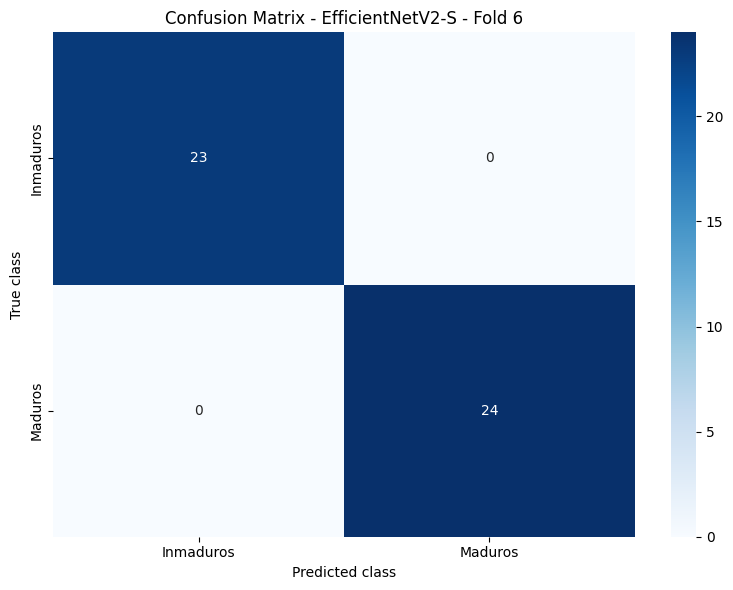

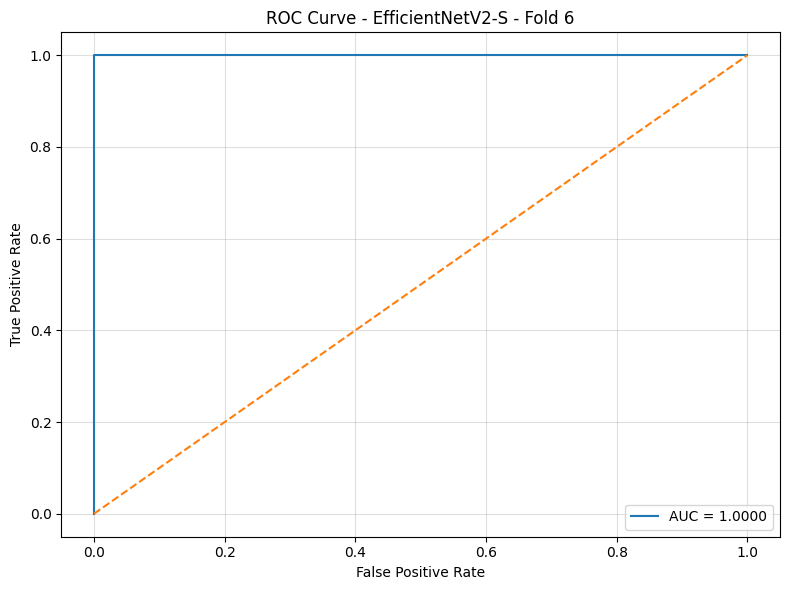

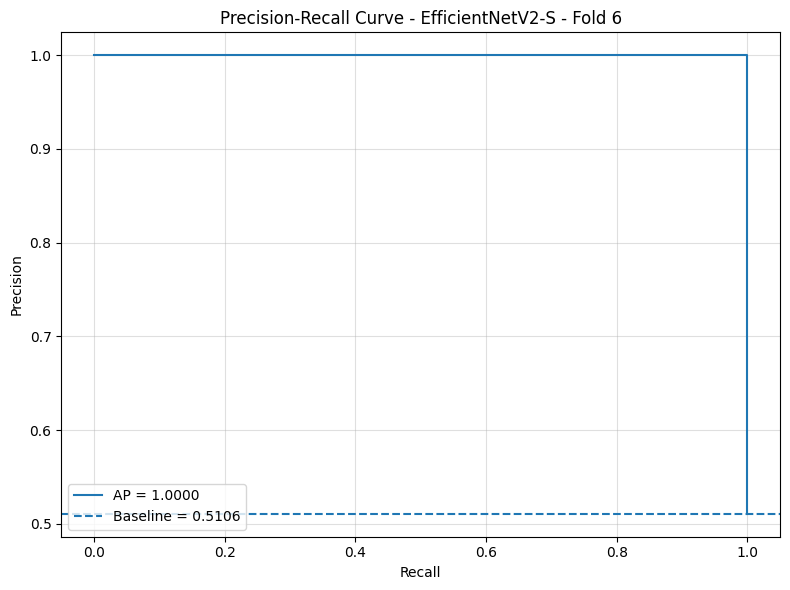

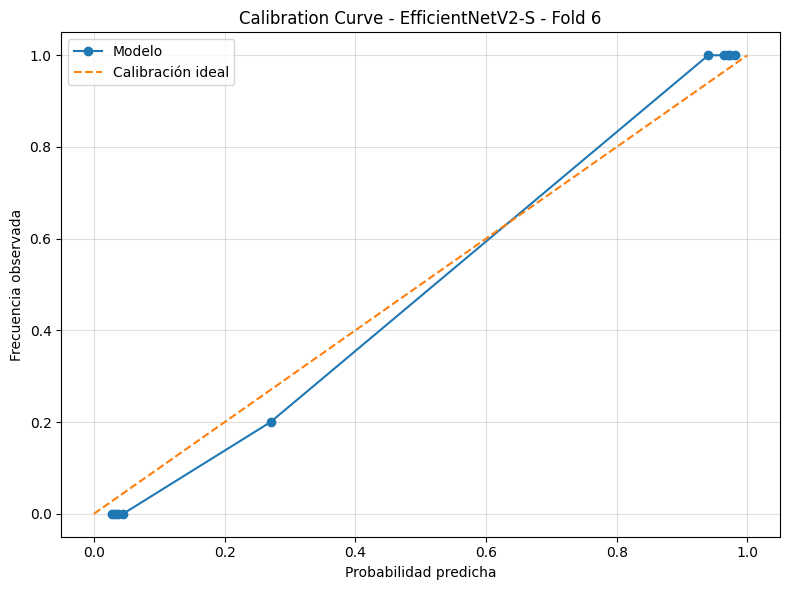

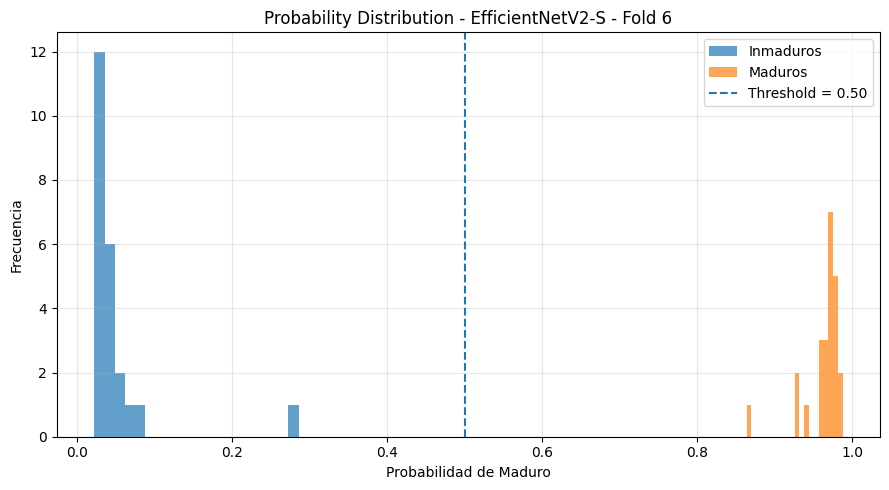

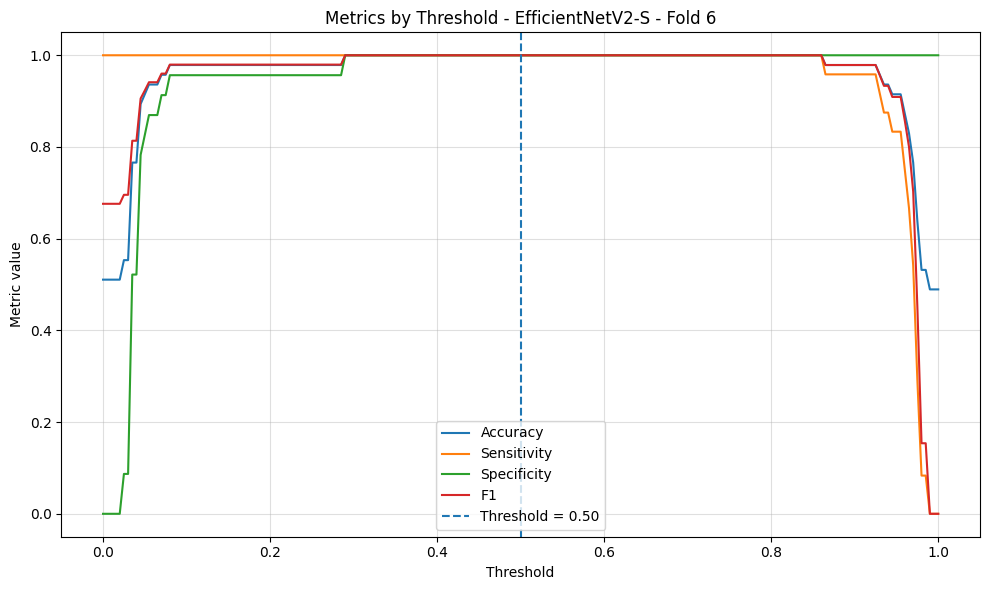


FOLD 7/10
------------------------------------------------------------------------
Epoch 1/9
27/27 ━━━━━━━━━━━━━━━━━━━━ 45s 853ms/step - accuracy: 0.9385 - auc: 0.9906 - loss: 0.2433 - pr_auc: 0.9907 - precision: 0.9384 - recall: 0.9384 - val_accuracy: 0.9149 - val_auc: 1.0000 - val_loss: 0.2517 - val_pr_auc: 1.0000 - val_precision: 0.8571 - val_recall: 1.0000
Epoch 2/9
27/27 ━━━━━━━━━━━━━━━━━━━━ 16s 582ms/step - accuracy: 0.9929 - auc: 0.9995 - loss: 0.1567 - pr_auc: 0.9994 - precision: 0.9906 - recall: 0.9953 - val_accuracy: 0.9787 - val_auc: 1.0000 - val_loss: 0.1763 - val_pr_auc: 1.0000 - val_precision: 1.0000 - val_recall: 0.9583
Epoch 3/9
27/27 ━━━━━━━━━━━━━━━━━━━━ 16s 584ms/step - accuracy: 0.9976 - auc: 0.9999 - loss: 0.1459 - pr_auc: 0.9999 - precision: 1.0000 - recall: 0.9953 - val_accuracy: 0.9787 - val_auc: 0.9982 - val_loss: 0.1796 - val_pr_auc: 0.9983 - val_precision: 0.9600 - val_recall: 1.0000
Epoch 4/9
27/27 ━━━━━━━━━━━━━━━━━━━━ 16s 578ms/step - accuracy: 0.9976 - auc

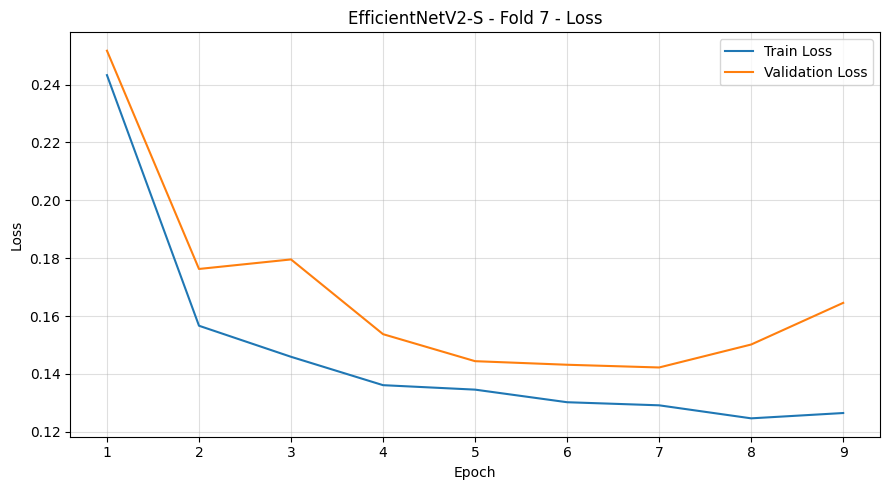

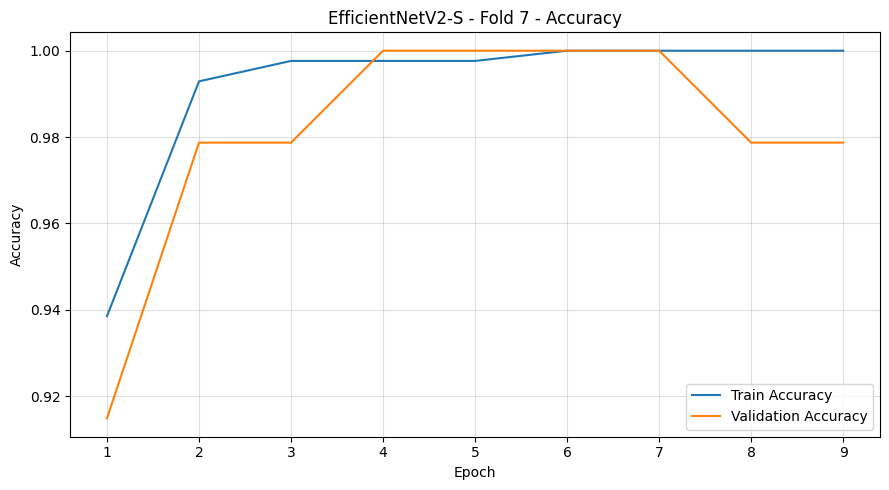

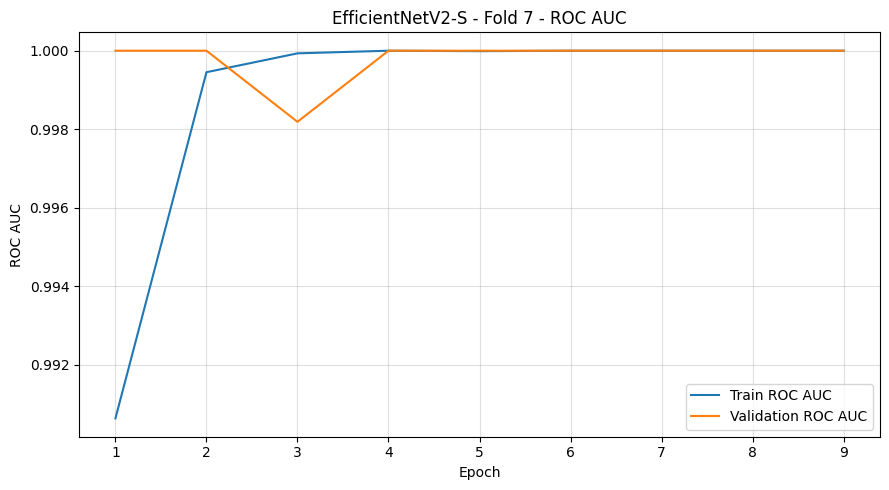

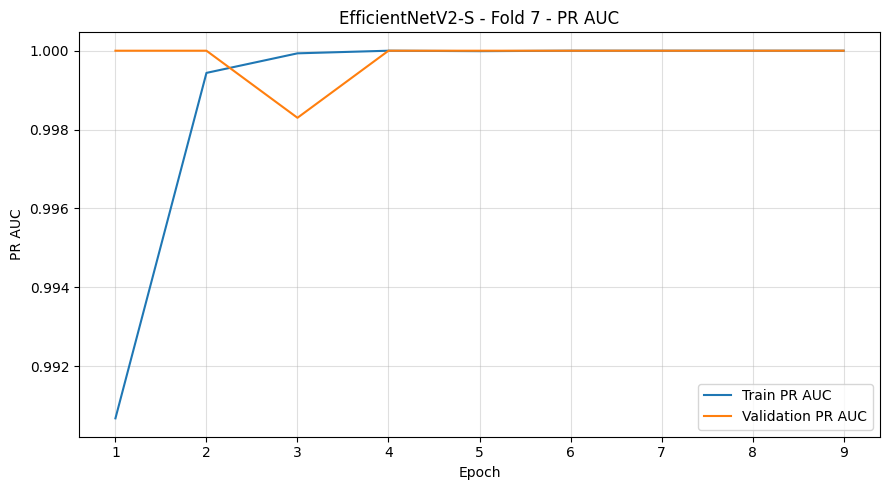

3/3 ━━━━━━━━━━━━━━━━━━━━ 10s 2s/step

Fold 07 | Acc: 0.9787 | Bal Acc: 0.9792 | F1: 0.9787 | ROC AUC: 1.0000 | PR AUC: 1.0000 | Log loss: 0.08133110 | Brier: 0.01685164 | ECE: 0.05247523


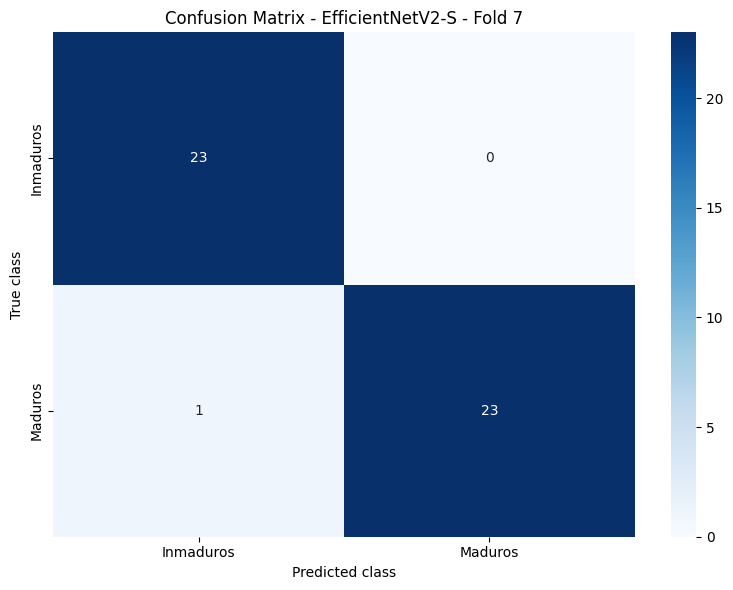

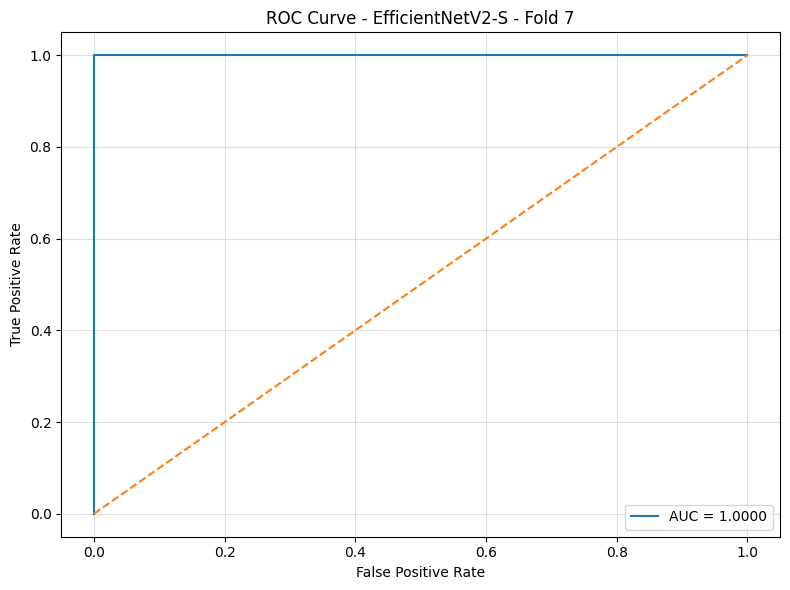

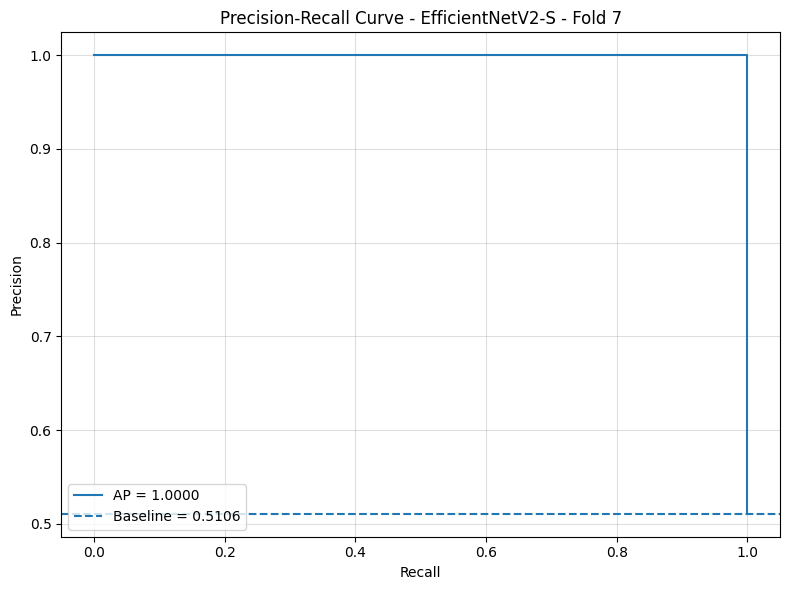

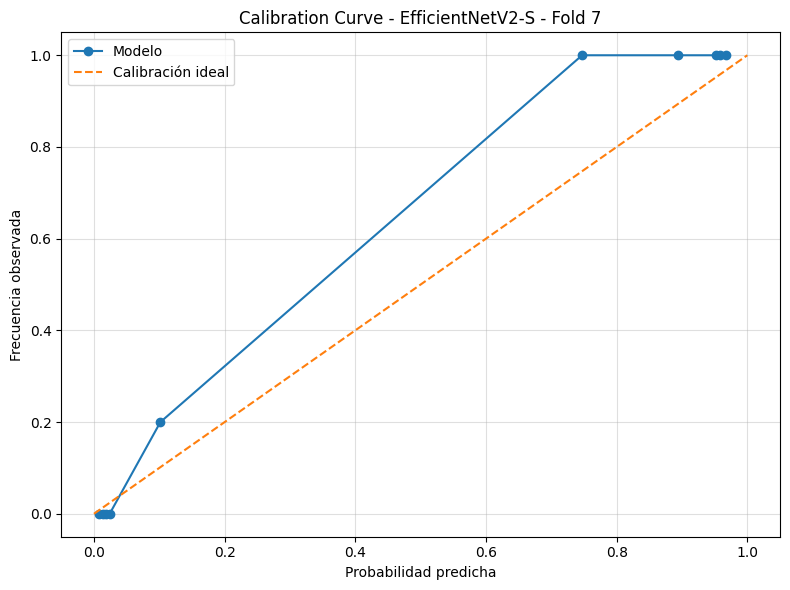

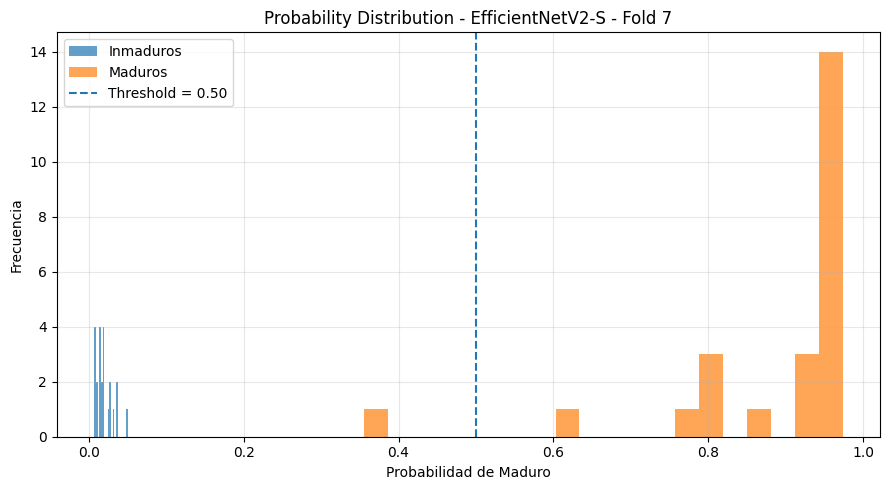

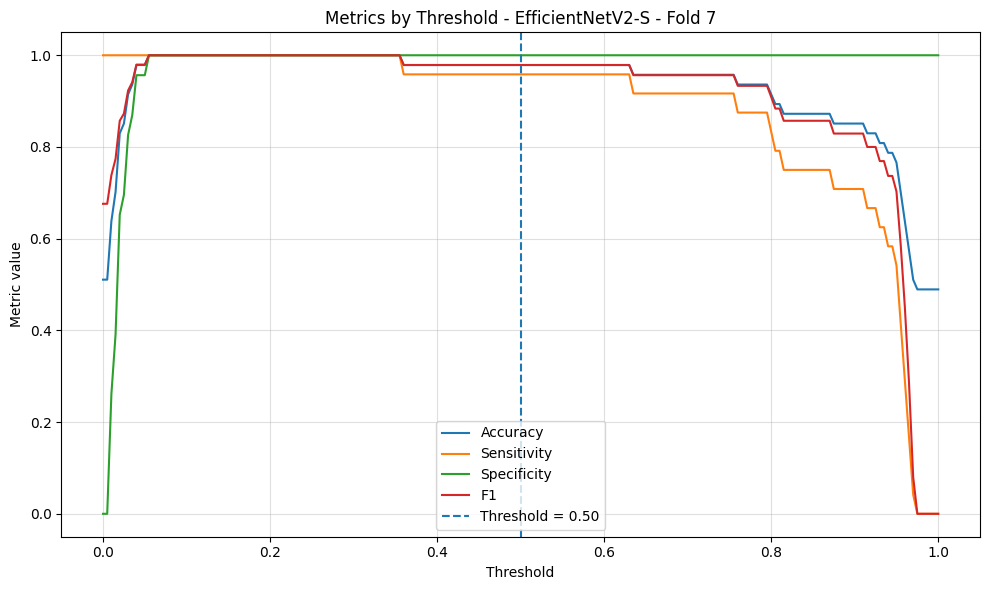


FOLD 8/10
------------------------------------------------------------------------
Epoch 1/9
27/27 ━━━━━━━━━━━━━━━━━━━━ 47s 881ms/step - accuracy: 0.9409 - auc: 0.9879 - loss: 0.2568 - pr_auc: 0.9883 - precision: 0.9387 - recall: 0.9431 - val_accuracy: 0.9787 - val_auc: 1.0000 - val_loss: 0.1907 - val_pr_auc: 1.0000 - val_precision: 0.9600 - val_recall: 1.0000
Epoch 2/9
27/27 ━━━━━━━━━━━━━━━━━━━━ 33s 591ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 0.1470 - pr_auc: 1.0000 - precision: 1.0000 - recall: 1.0000 - val_accuracy: 0.9574 - val_auc: 1.0000 - val_loss: 0.2108 - val_pr_auc: 1.0000 - val_precision: 0.9231 - val_recall: 1.0000
Epoch 3/9
27/27 ━━━━━━━━━━━━━━━━━━━━ 16s 584ms/step - accuracy: 0.9953 - auc: 0.9989 - loss: 0.1466 - pr_auc: 0.9988 - precision: 0.9953 - recall: 0.9953 - val_accuracy: 0.9787 - val_auc: 1.0000 - val_loss: 0.1652 - val_pr_auc: 1.0000 - val_precision: 0.9600 - val_recall: 1.0000
Epoch 4/9
27/27 ━━━━━━━━━━━━━━━━━━━━ 16s 590ms/step - accuracy: 0.9976 - auc

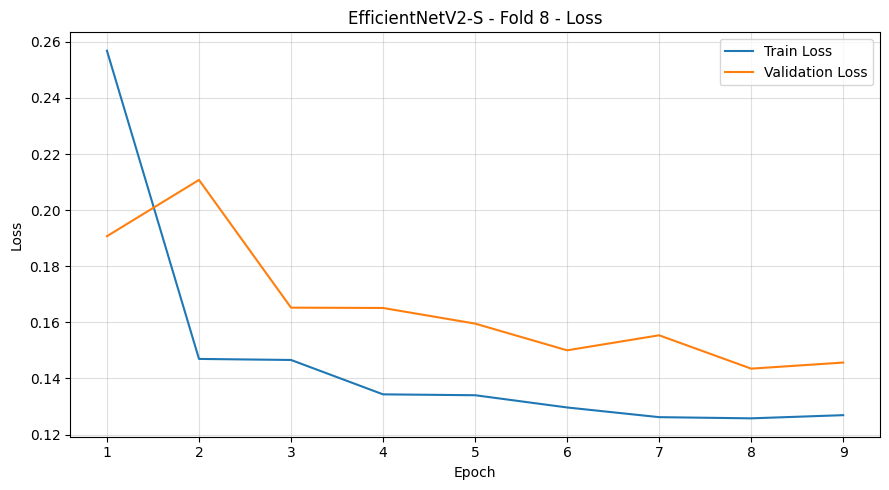

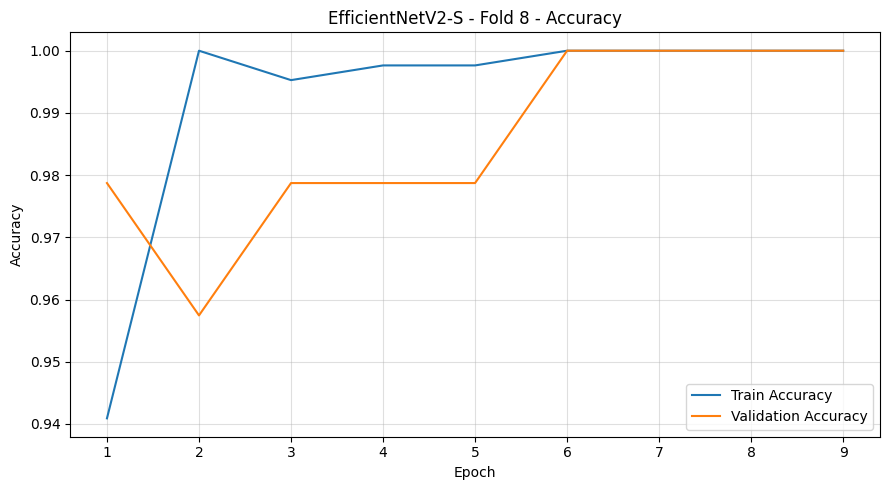

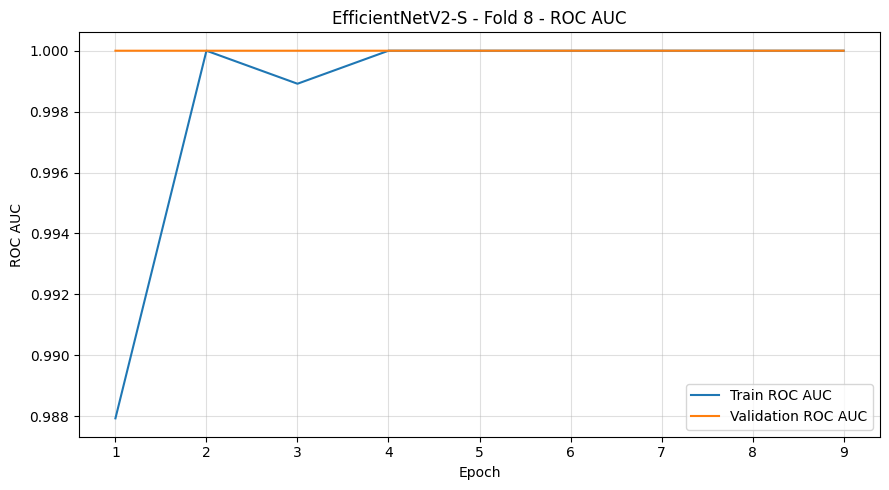

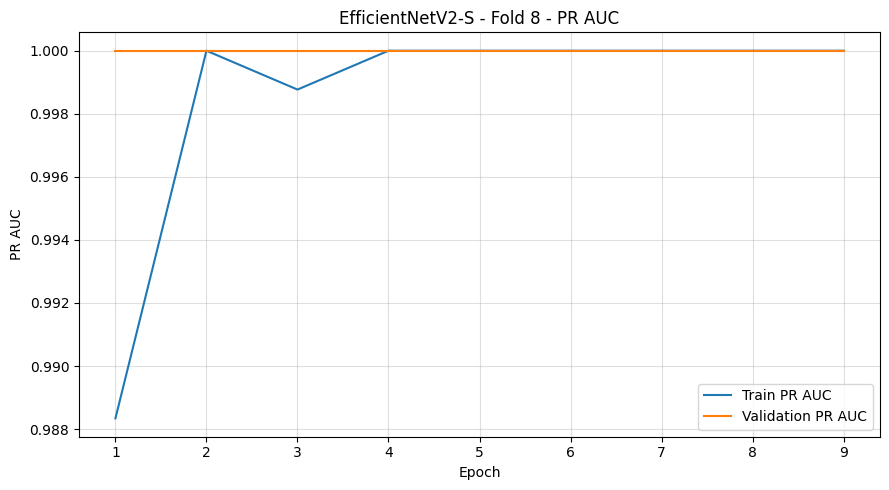

3/3 ━━━━━━━━━━━━━━━━━━━━ 11s 3s/step

Fold 08 | Acc: 1.0000 | Bal Acc: 1.0000 | F1: 1.0000 | ROC AUC: 1.0000 | PR AUC: 1.0000 | Log loss: 0.06259768 | Brier: 0.00926194 | ECE: 0.05644726


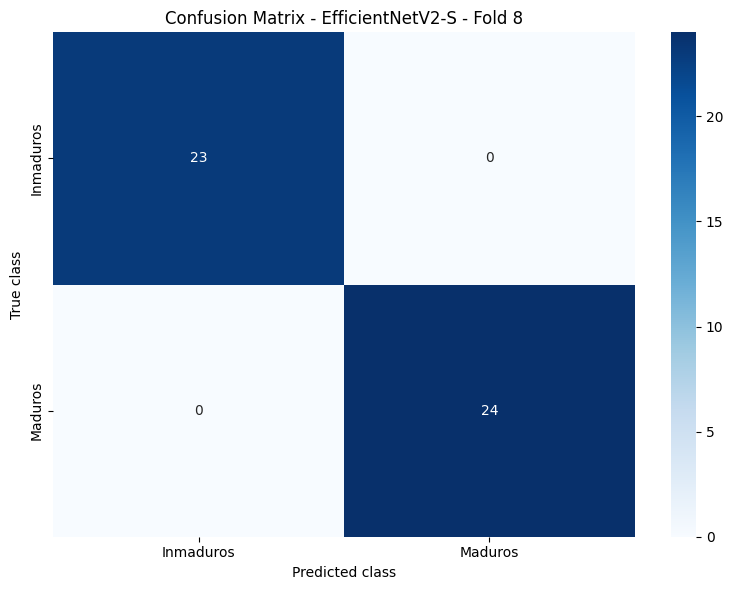

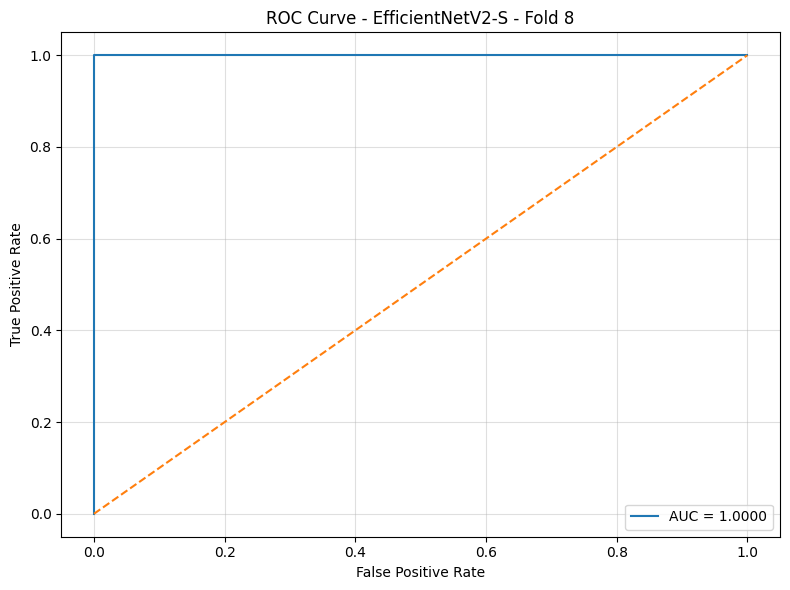

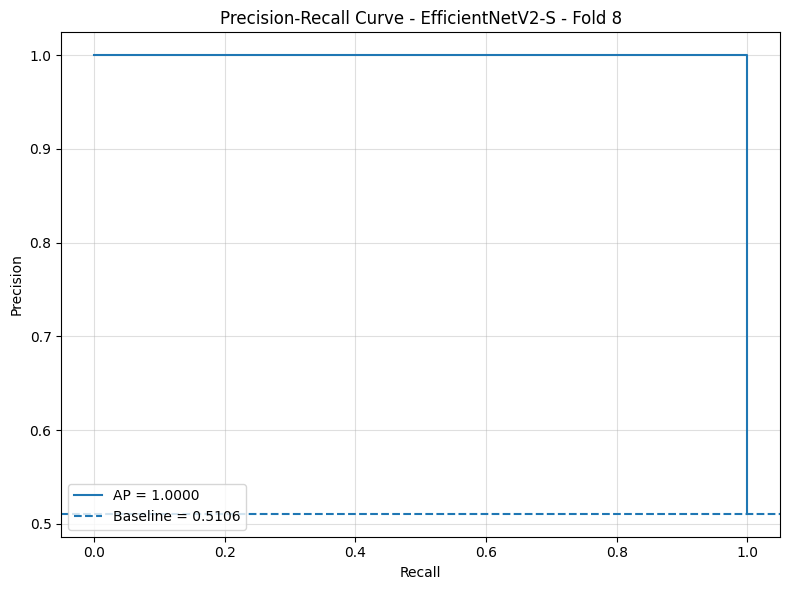

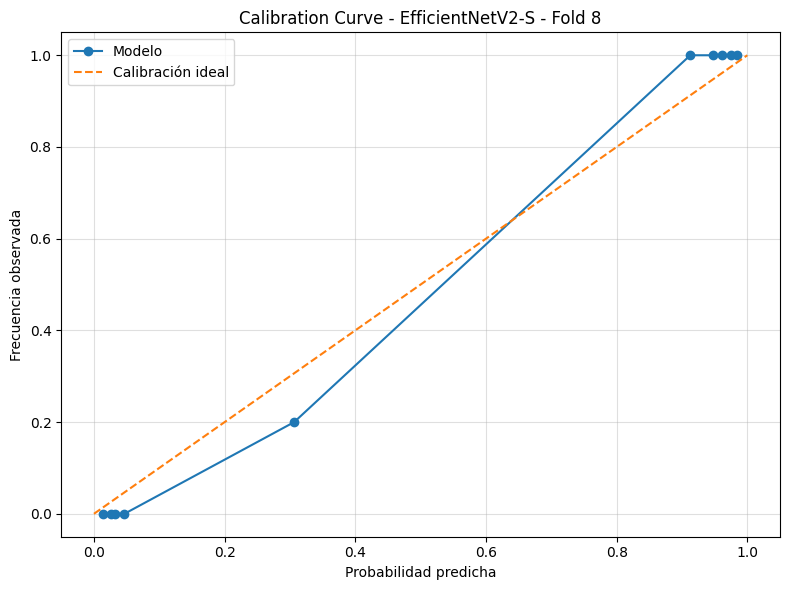

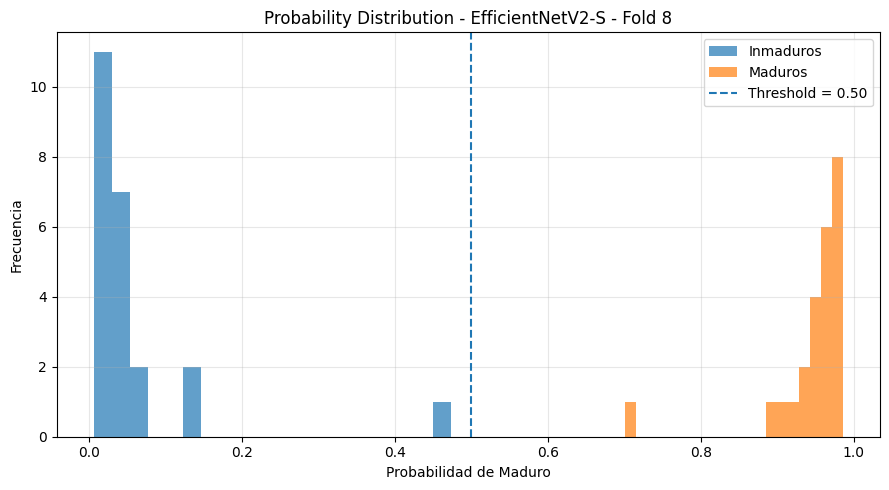

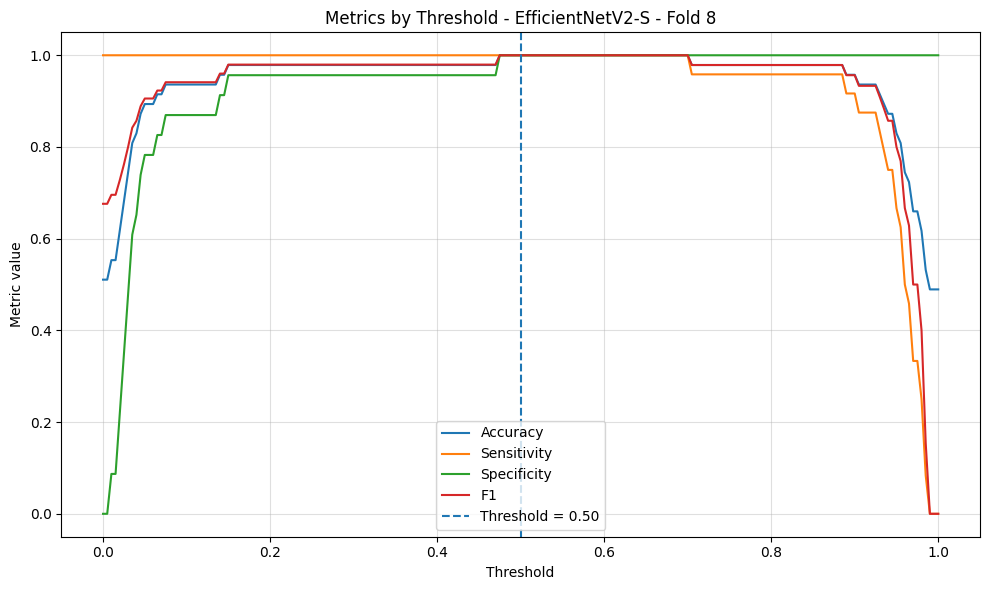


FOLD 9/10
------------------------------------------------------------------------
Epoch 1/9
27/27 ━━━━━━━━━━━━━━━━━━━━ 46s 865ms/step - accuracy: 0.9173 - auc: 0.9868 - loss: 0.2610 - pr_auc: 0.9878 - precision: 0.9490 - recall: 0.8815 - val_accuracy: 0.9787 - val_auc: 1.0000 - val_loss: 0.1593 - val_pr_auc: 1.0000 - val_precision: 1.0000 - val_recall: 0.9583
Epoch 2/9
27/27 ━━━━━━━━━━━━━━━━━━━━ 16s 584ms/step - accuracy: 0.9953 - auc: 1.0000 - loss: 0.1503 - pr_auc: 1.0000 - precision: 0.9906 - recall: 1.0000 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.1498 - val_pr_auc: 1.0000 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 3/9
27/27 ━━━━━━━━━━━━━━━━━━━━ 22s 623ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 0.1386 - pr_auc: 1.0000 - precision: 1.0000 - recall: 1.0000 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.1347 - val_pr_auc: 1.0000 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 4/9
27/27 ━━━━━━━━━━━━━━━━━━━━ 17s 613ms/step - accuracy: 0.9953 - auc

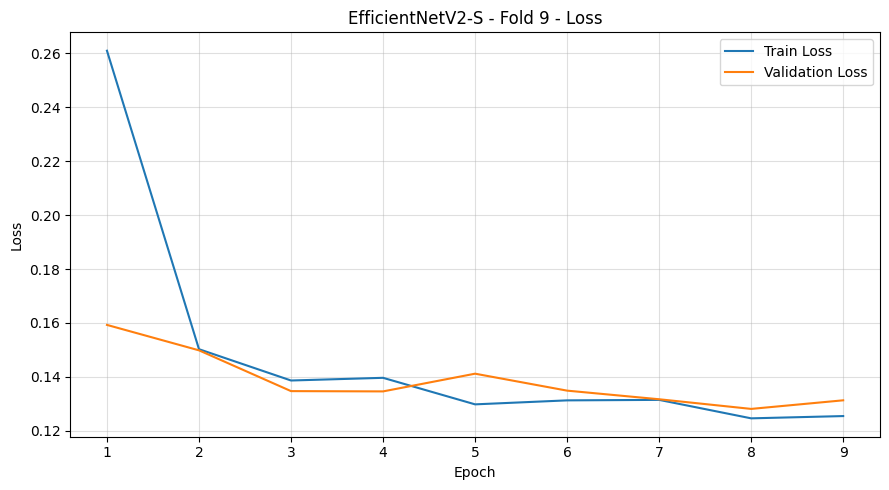

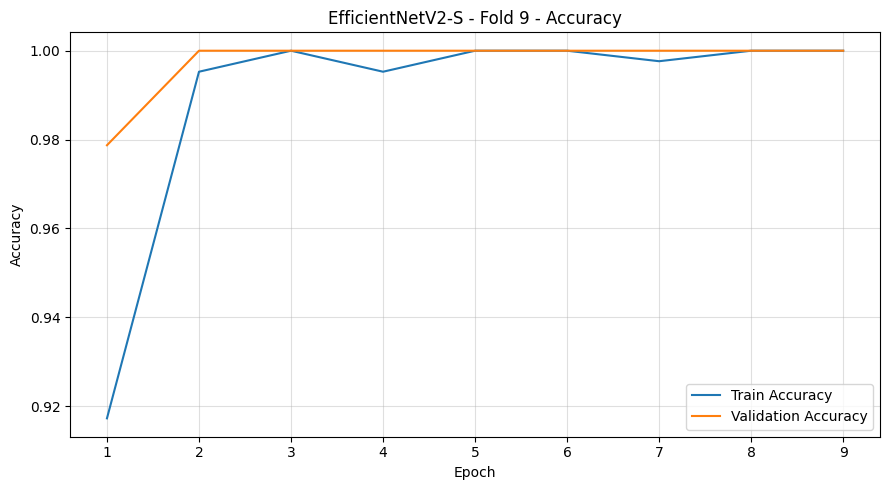

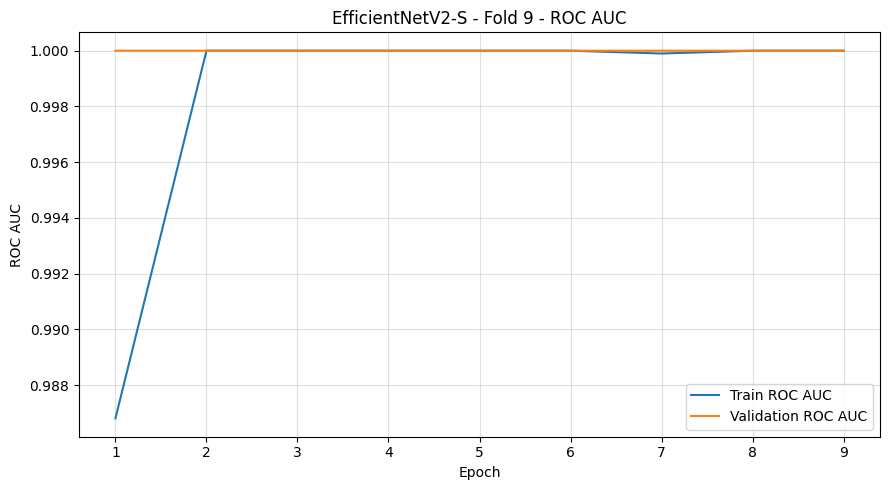

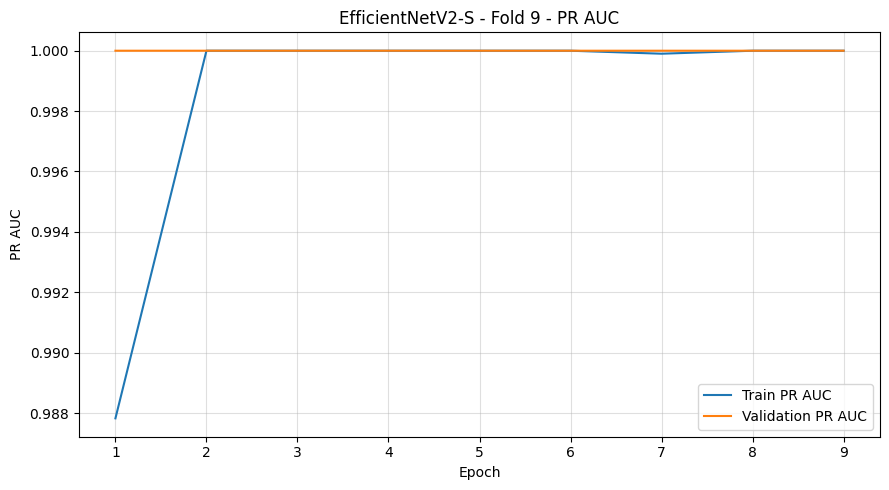

3/3 ━━━━━━━━━━━━━━━━━━━━ 10s 2s/step

Fold 09 | Acc: 1.0000 | Bal Acc: 1.0000 | F1: 1.0000 | ROC AUC: 1.0000 | PR AUC: 1.0000 | Log loss: 0.03866924 | Brier: 0.00460662 | ECE: 0.03561269


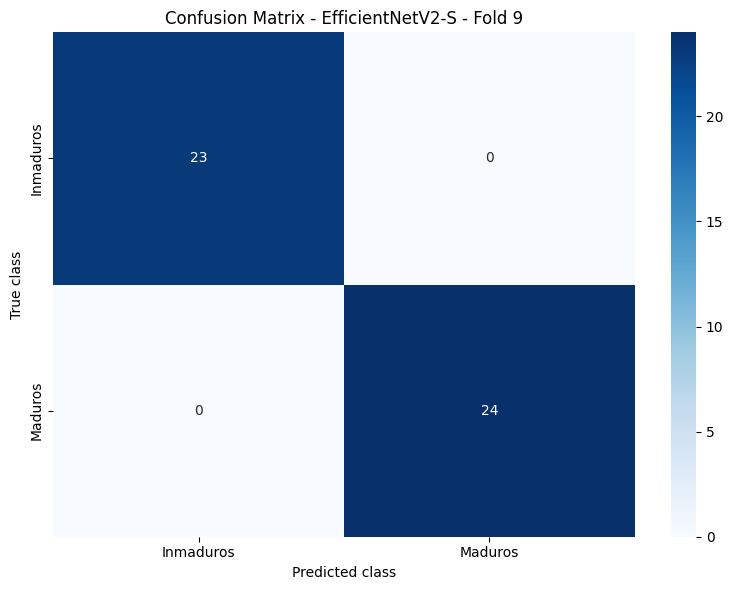

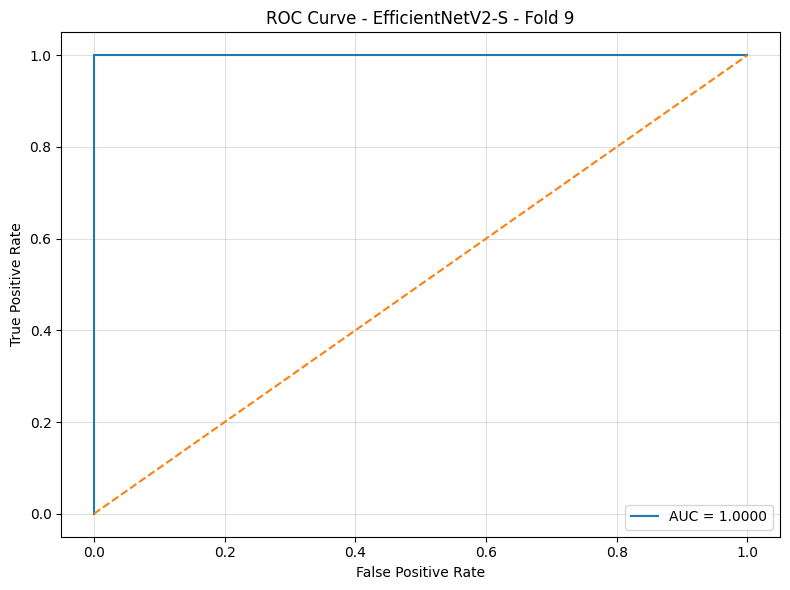

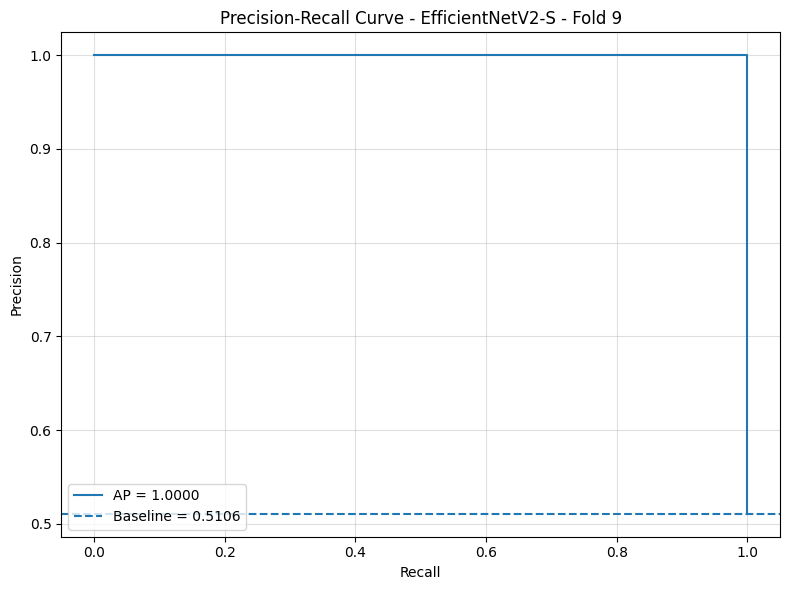

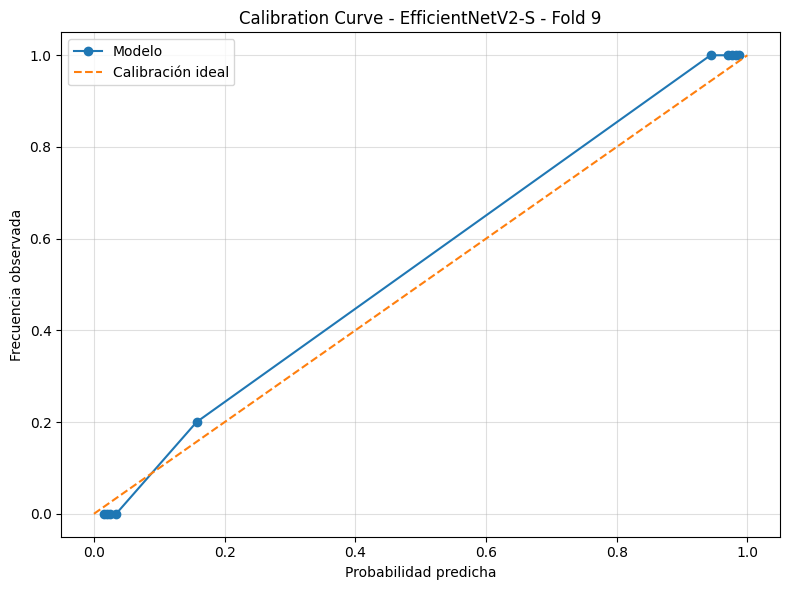

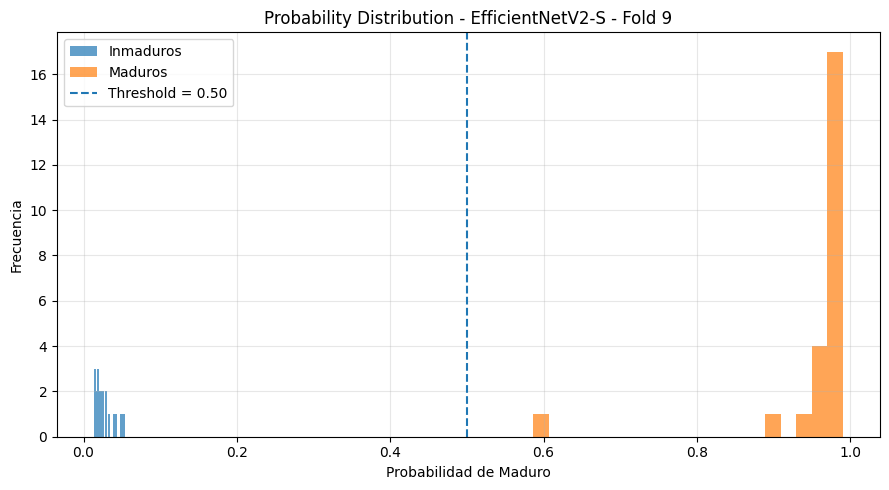

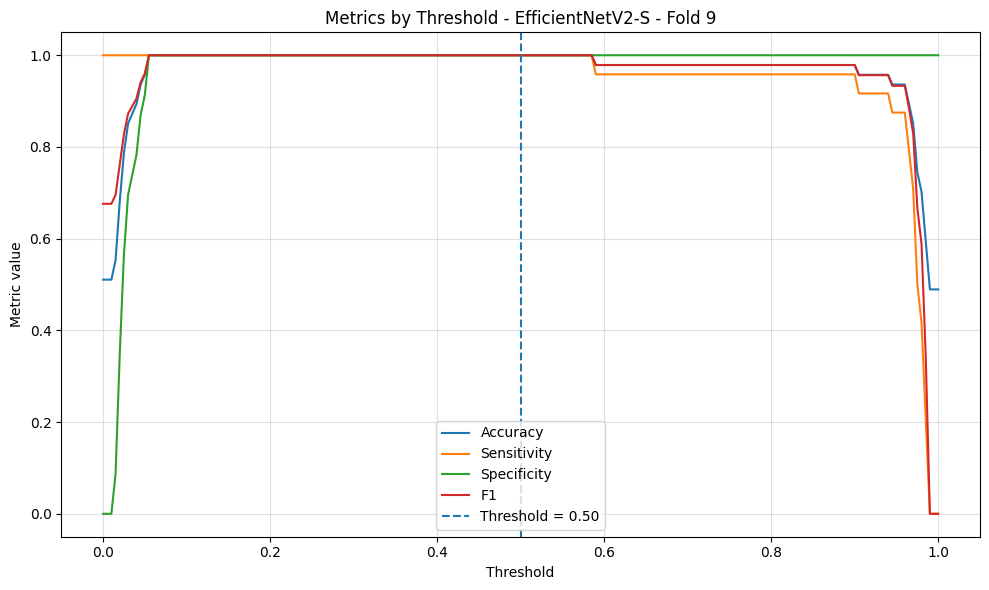


FOLD 10/10
------------------------------------------------------------------------
Epoch 1/9
27/27 ━━━━━━━━━━━━━━━━━━━━ 47s 887ms/step - accuracy: 0.9480 - auc: 0.9927 - loss: 0.2354 - pr_auc: 0.9928 - precision: 0.9315 - recall: 0.9668 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.1434 - val_pr_auc: 1.0000 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 2/9
27/27 ━━━━━━━━━━━━━━━━━━━━ 17s 611ms/step - accuracy: 0.9953 - auc: 0.9998 - loss: 0.1546 - pr_auc: 0.9998 - precision: 1.0000 - recall: 0.9905 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.1381 - val_pr_auc: 1.0000 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 3/9
27/27 ━━━━━━━━━━━━━━━━━━━━ 17s 619ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 0.1445 - pr_auc: 1.0000 - precision: 1.0000 - recall: 1.0000 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.1394 - val_pr_auc: 1.0000 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 4/9
27/27 ━━━━━━━━━━━━━━━━━━━━ 17s 635ms/step - accuracy: 0.9953 - au

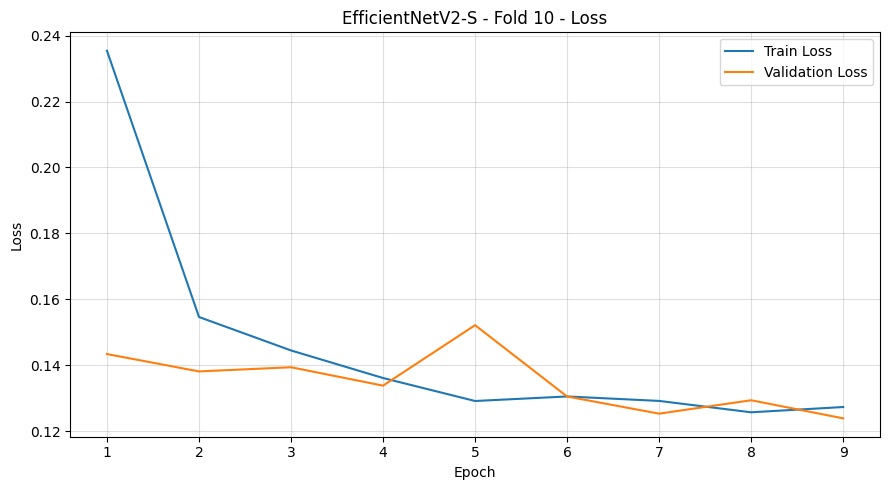

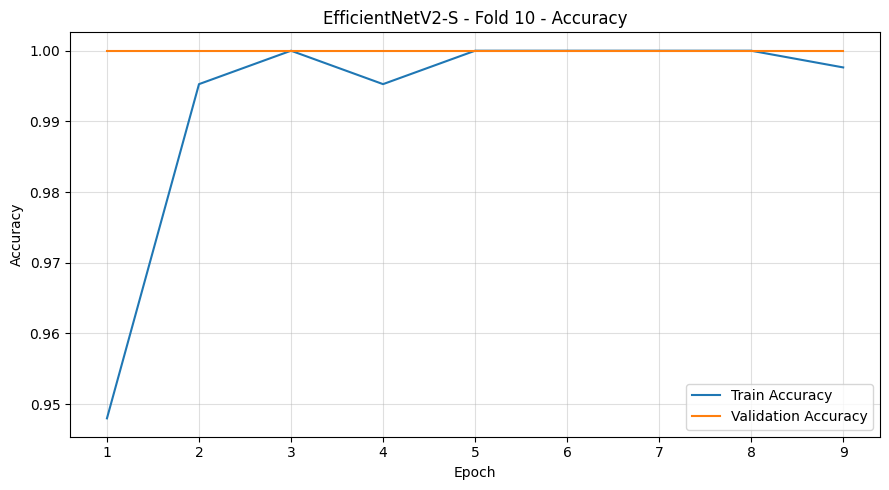

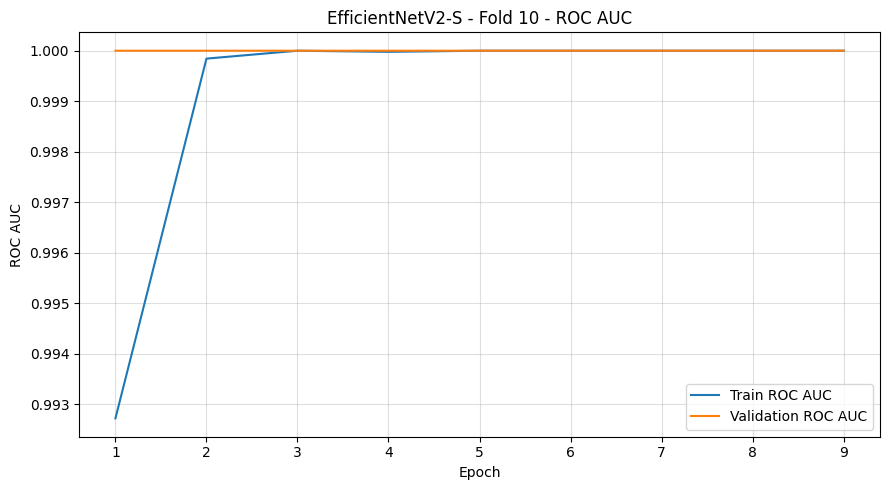

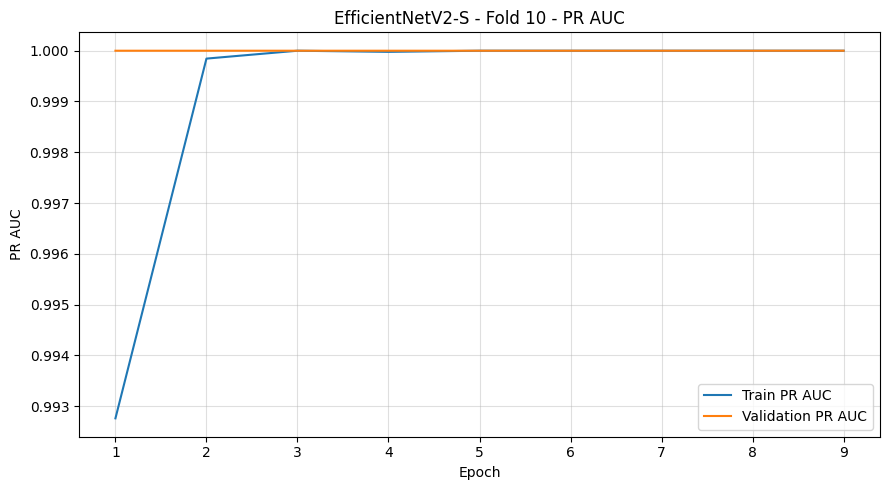

3/3 ━━━━━━━━━━━━━━━━━━━━ 11s 2s/step

Fold 10 | Acc: 1.0000 | Bal Acc: 1.0000 | F1: 1.0000 | ROC AUC: 1.0000 | PR AUC: 1.0000 | Log loss: 0.03474815 | Brier: 0.00150541 | ECE: 0.03396628


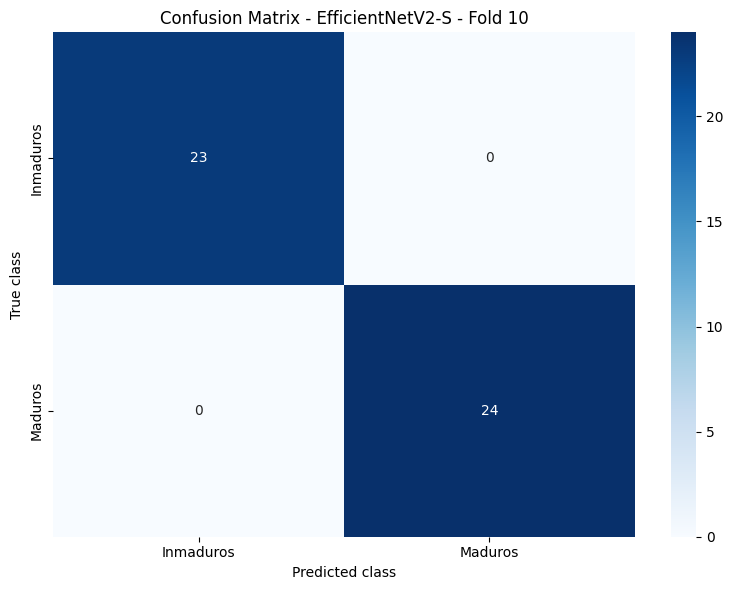

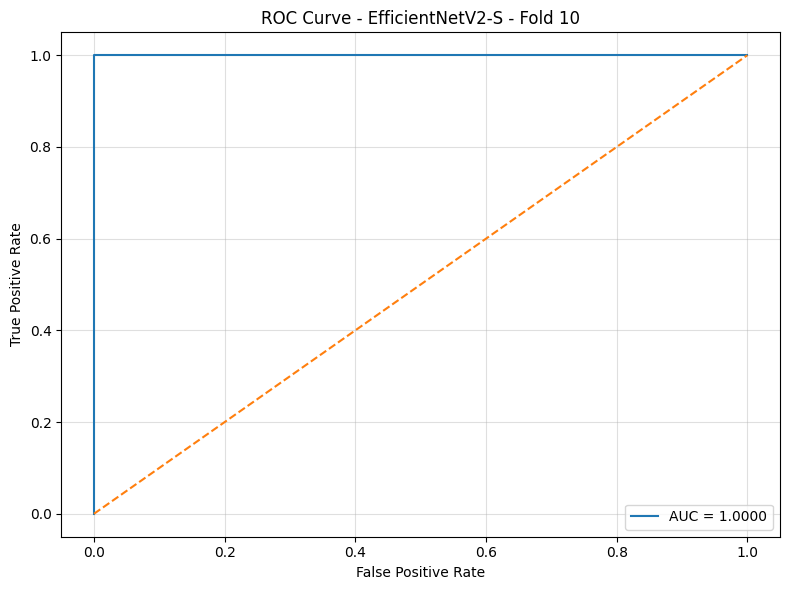

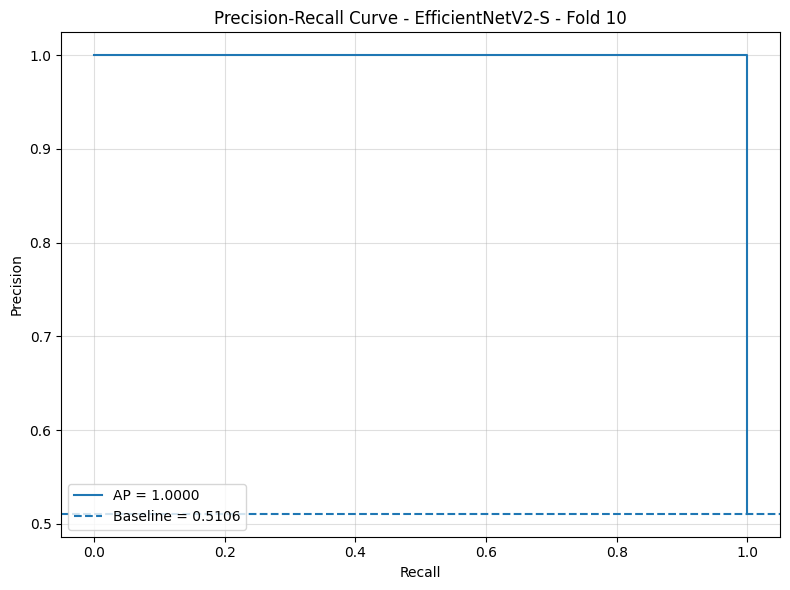

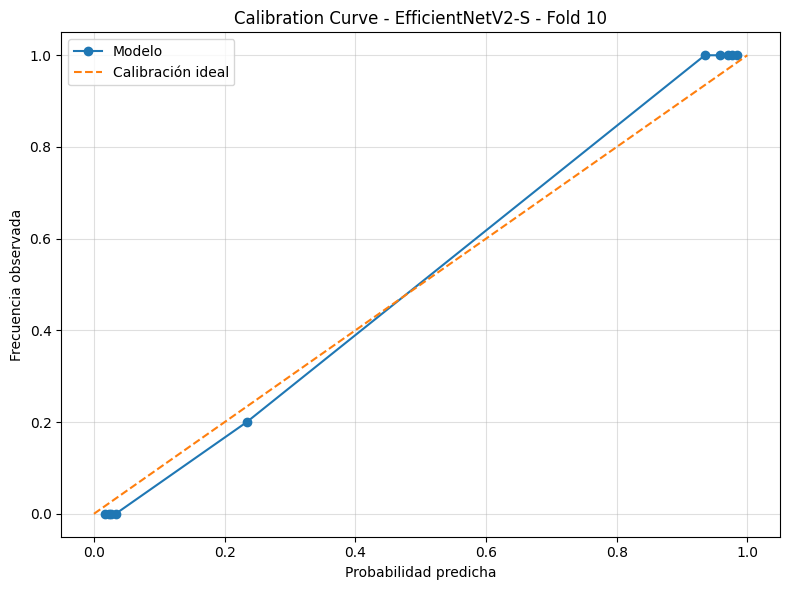

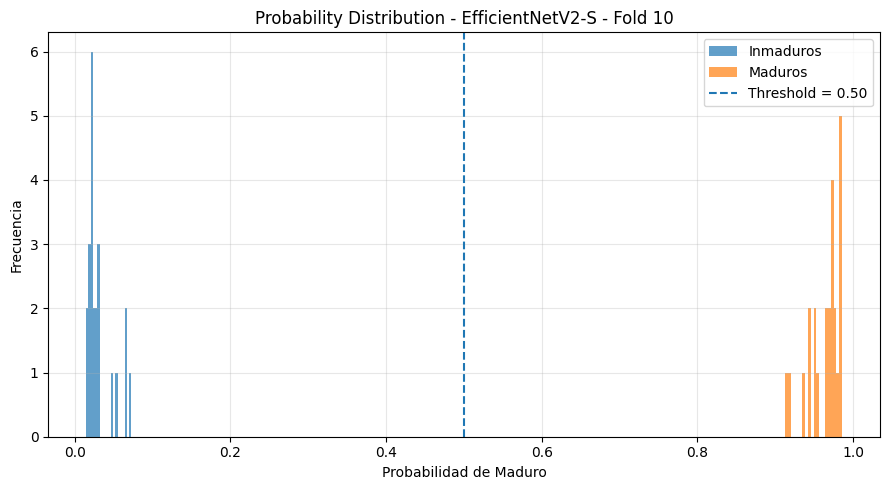

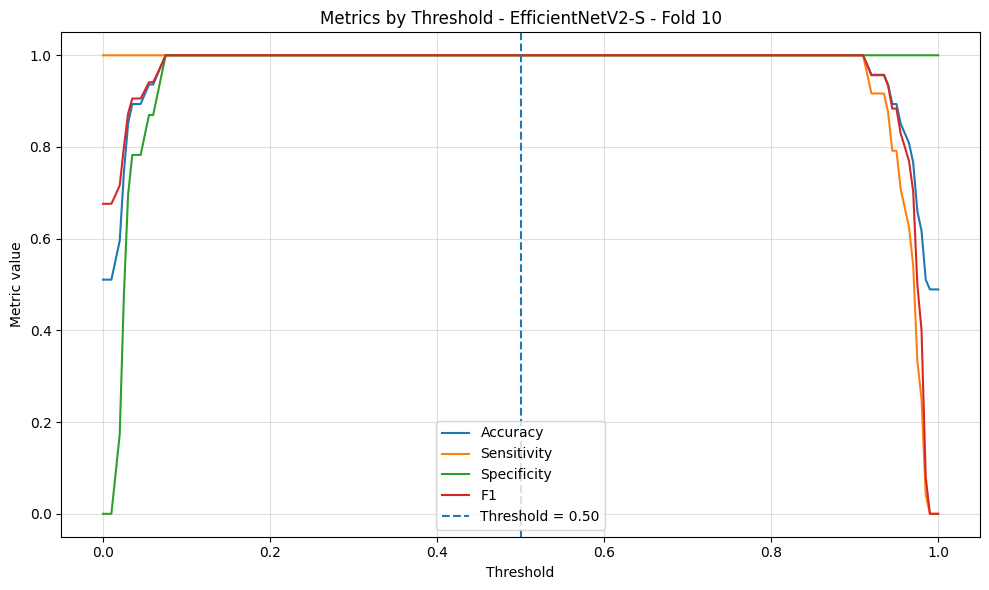


RESULTADOS POR FOLD


,tn,fp,fn,tp,accuracy,balanced_accuracy,precision_ppv,sensitivity_recall,specificity,negative_predictive_value,...,n_images,model,fold,train_images,validation_images,epochs_trained,epochs_source,training_time_seconds,inference_time_seconds,inference_time_per_image_ms
0,24,0,0,23,1.000000,1.000000,1.0,1.000000,1.0,1.000000,...,47,EfficientNetV2-S,1,423,47,9,best_optuna_trial,192.543343,10.540179,224.259128
1,24,0,0,23,1.000000,1.000000,1.0,1.000000,1.0,1.000000,...,47,EfficientNetV2-S,2,423,47,9,best_optuna_trial,169.129233,9.472915,201.551392
2,24,0,0,23,1.000000,1.000000,1.0,1.000000,1.0,1.000000,...,47,EfficientNetV2-S,3,423,47,9,best_optuna_trial,169.923457,10.657701,226.759596
3,24,0,0,23,1.000000,1.000000,1.0,1.000000,1.0,1.000000,...,47,EfficientNetV2-S,4,423,47,9,best_optuna_trial,195.849952,10.923831,232.421936
4,24,0,1,22,0.978723,0.978261,1.0,0.956522,1.0,0.960000,...,47,EfficientNetV2-S,5,423,47,9,best_optuna_trial,171.980900,9.960171,211.918527
5,23,0,0,24,1.000000,1.000000,1.0,1.000000,1.0,1.000000,...,47,EfficientNetV2-S,6,423,47,9,best_optuna_trial,183.008528,10.604226,225.621832
6,23,0,1,23,0.978723,0.979167,1.0,0.958333,1.0,0.958333,...,47,EfficientNetV2-S,7,423,47,9,best_optuna_trial,172.039960,9.662931,205.594276
7,23,0,0,24,1.000000,1.000000,1.0,1.000000,1.0,1.000000,...,47,EfficientNetV2-S,8,423,47,9,best_optuna_trial,193.986879,10.835160,230.535309
8,23,0,0,24,1.000000,1.000000,1.0,1.000000,1.0,1.000000,...,47,EfficientNetV2-S,9,423,47,9,best_optuna_trial,186.043828,9.845773,209.484521
9,23,0,0,24,1.000000,1.000000,1.0,1.000000,1.0,1.000000,...,47,EfficientNetV2-S,10,423,47,9,best_optuna_trial,187.871111,11.045921,235.019593



RESUMEN DE LOS 10 FOLDS


,metric,mean,std,median,min,max
0,accuracy,0.995745,0.008971,1.000000,0.978723,1.000000
1,balanced_accuracy,0.995743,0.008978,1.000000,0.978261,1.000000
2,precision_ppv,1.000000,0.000000,1.000000,1.000000,1.000000
3,sensitivity_recall,0.991486,0.017955,1.000000,0.956522,1.000000
4,specificity,1.000000,0.000000,1.000000,1.000000,1.000000
5,negative_predictive_value,0.991833,0.017221,1.000000,0.958333,1.000000
6,f1_score,0.995650,0.009173,1.000000,0.977778,1.000000
7,f2_score,0.993130,0.014488,1.000000,0.964912,1.000000
8,jaccard_index,0.991486,0.017955,1.000000,0.956522,1.000000
9,mcc,0.991659,0.017584,1.000000,0.958259,1.000000



MÉTRICAS OOF EXTENDIDAS


,0
tn,235
fp,0
fn,2
tp,233
accuracy,0.995745
balanced_accuracy,0.995745
precision_ppv,1.0
sensitivity_recall,0.991489
specificity,1.0
negative_predictive_value,0.991561


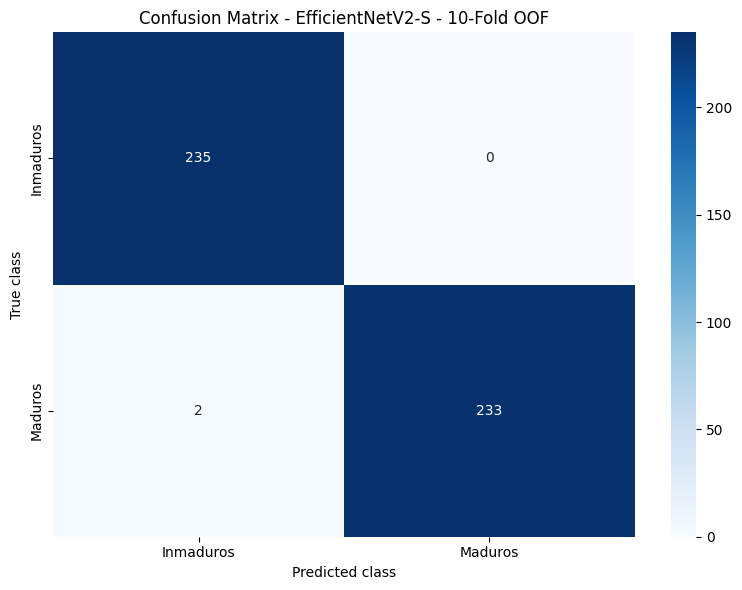

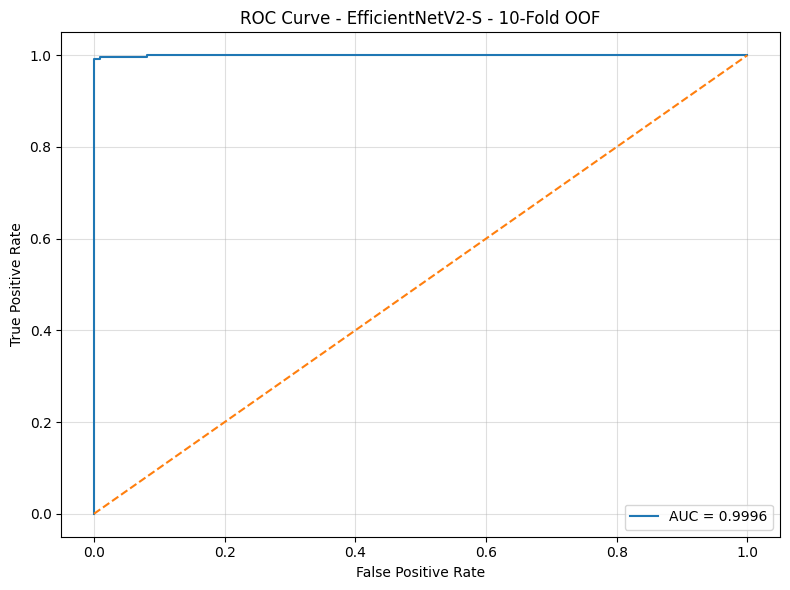

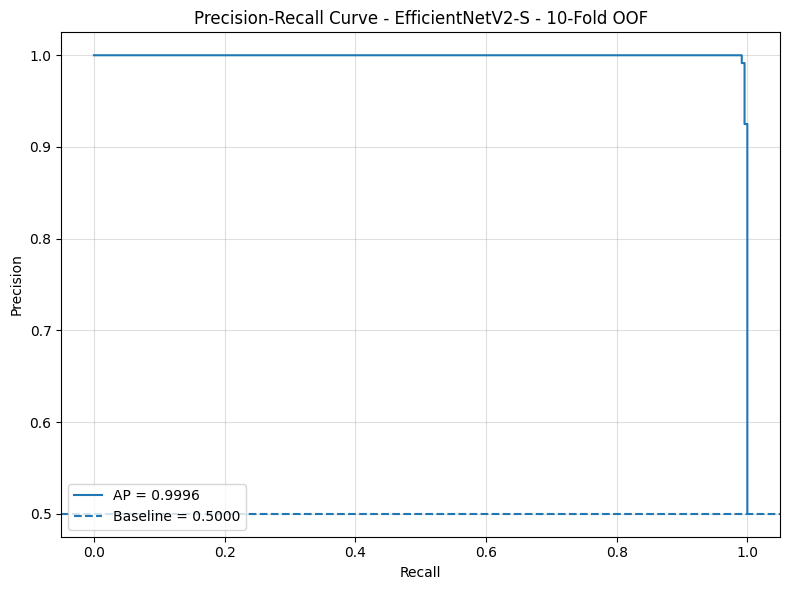

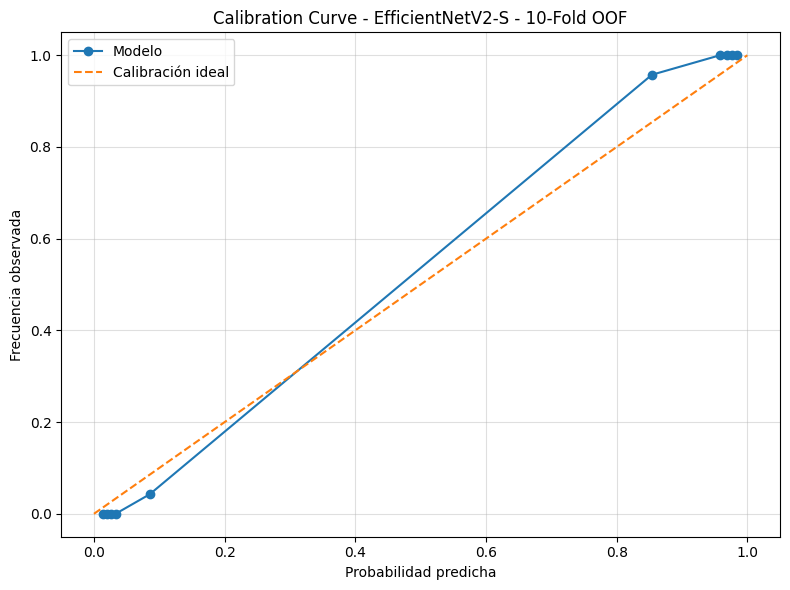

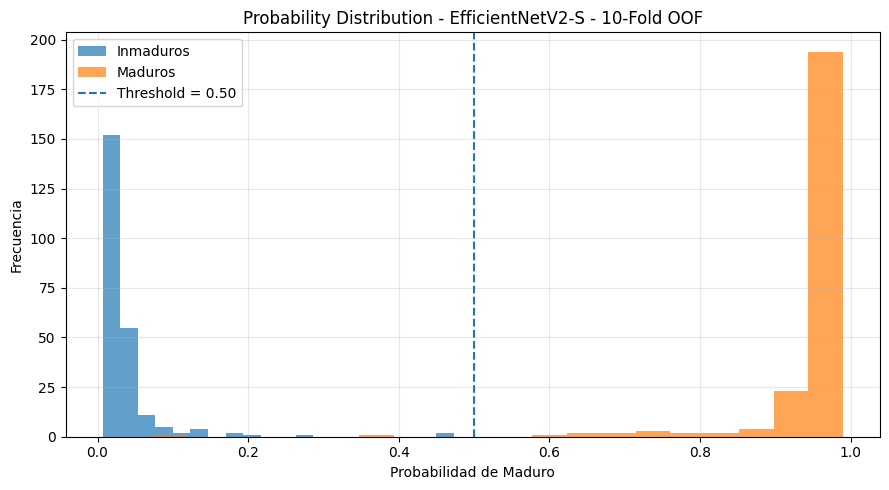

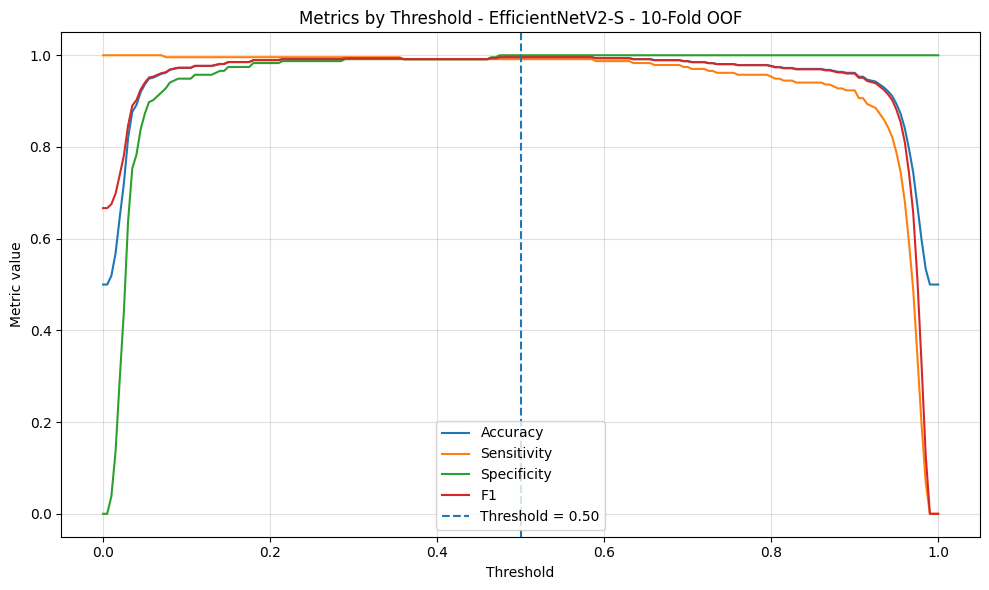


ENTRENAMIENTO FINAL CON TRAIN + VAL
Epoch 1/9
38/38 ━━━━━━━━━━━━━━━━━━━━ 51s 637ms/step - accuracy: 0.9586 - auc: 0.9935 - loss: 0.2280 - pr_auc: 0.9936 - precision: 0.9571 - recall: 0.9603
Epoch 2/9
38/38 ━━━━━━━━━━━━━━━━━━━━ 38s 606ms/step - accuracy: 0.9950 - auc: 0.9999 - loss: 0.1466 - pr_auc: 0.9999 - precision: 0.9902 - recall: 1.0000
Epoch 3/9
38/38 ━━━━━━━━━━━━━━━━━━━━ 41s 598ms/step - accuracy: 0.9950 - auc: 1.0000 - loss: 0.1383 - pr_auc: 1.0000 - precision: 0.9902 - recall: 1.0000
Epoch 4/9
38/38 ━━━━━━━━━━━━━━━━━━━━ 22s 562ms/step - accuracy: 0.9983 - auc: 1.0000 - loss: 0.1346 - pr_auc: 1.0000 - precision: 1.0000 - recall: 0.9967
Epoch 5/9
38/38 ━━━━━━━━━━━━━━━━━━━━ 22s 590ms/step - accuracy: 0.9983 - auc: 1.0000 - loss: 0.1302 - pr_auc: 1.0000 - precision: 1.0000 - recall: 0.9967
Epoch 6/9
38/38 ━━━━━━━━━━━━━━━━━━━━ 21s 554ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 0.1270 - pr_auc: 1.0000 - precision: 1.0000 - recall: 1.0000
Epoch 7/9
38/38 ━━━━━━━━━━━━━━━━━━━━ 22

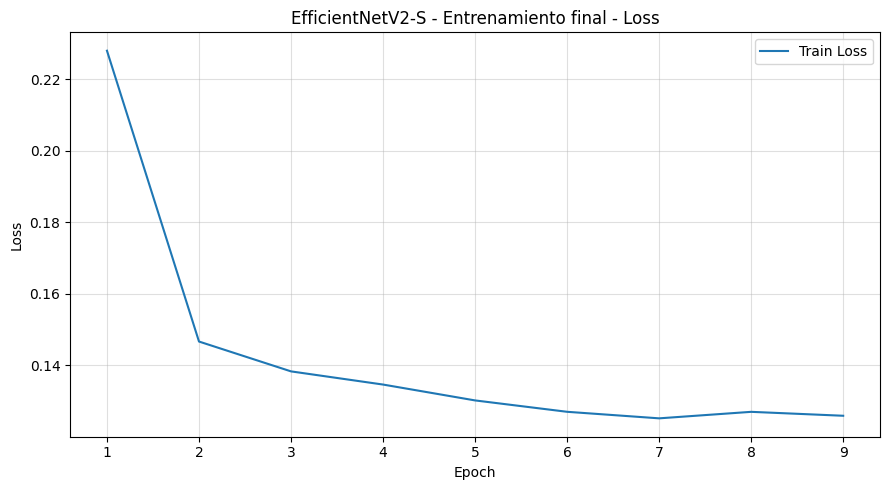

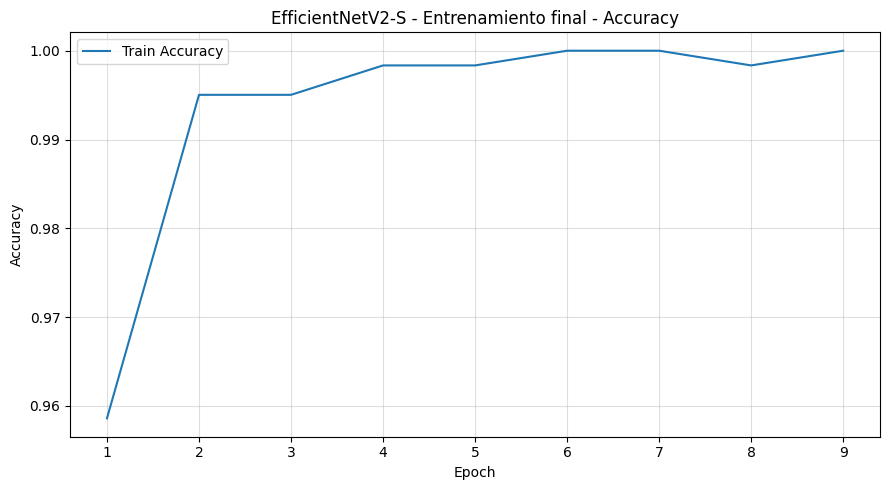

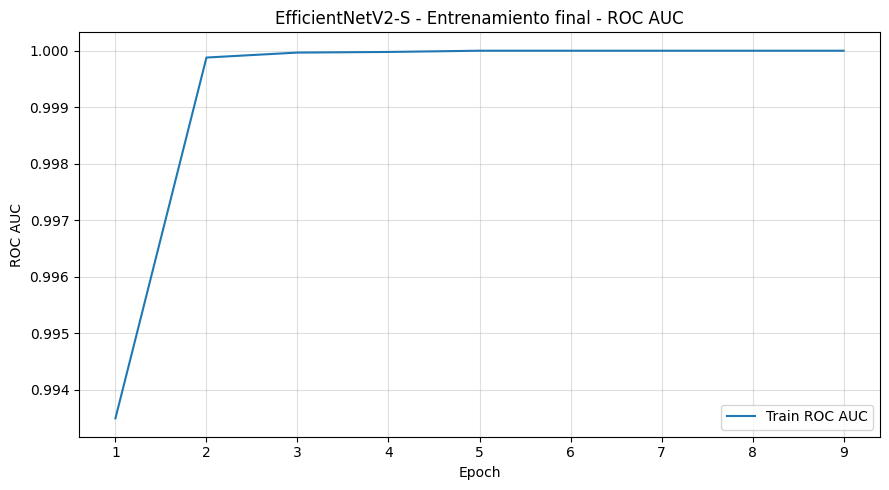

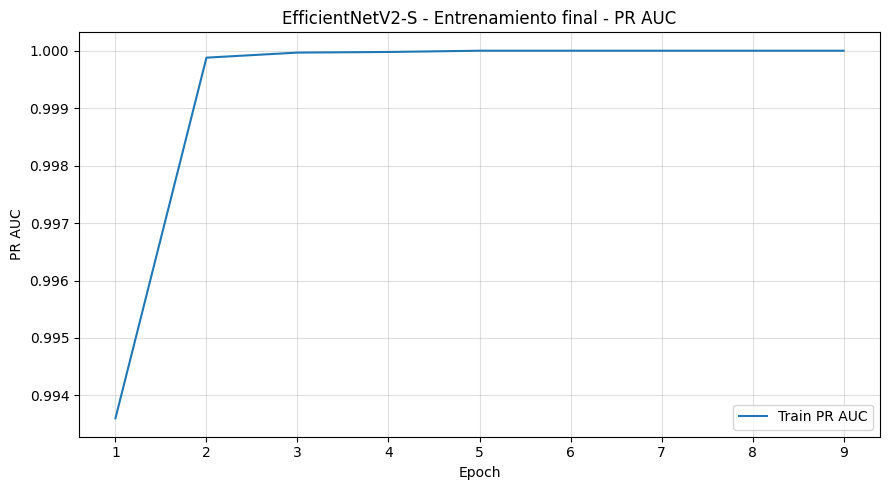


EVALUACIÓN FINAL SOBRE TEST INDEPENDIENTE

MÉTRICAS DEL TEST EXTENDIDAS


,0
tn,34
fp,0
fn,1
tp,33
accuracy,0.985294
...,...
inference_per_image_ms_median,18.731246
inference_per_image_ms_p95_repetition,18.813156
total_parameters,20987745
trainable_parameters,3474049


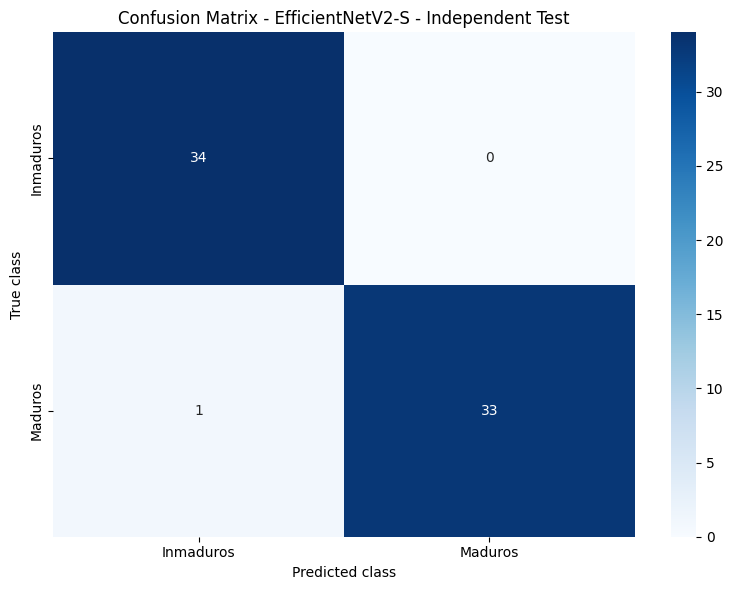

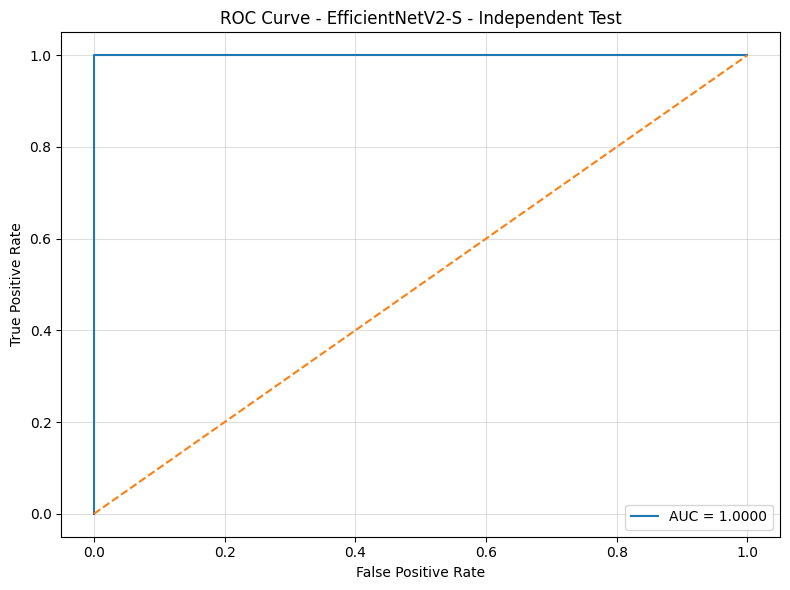

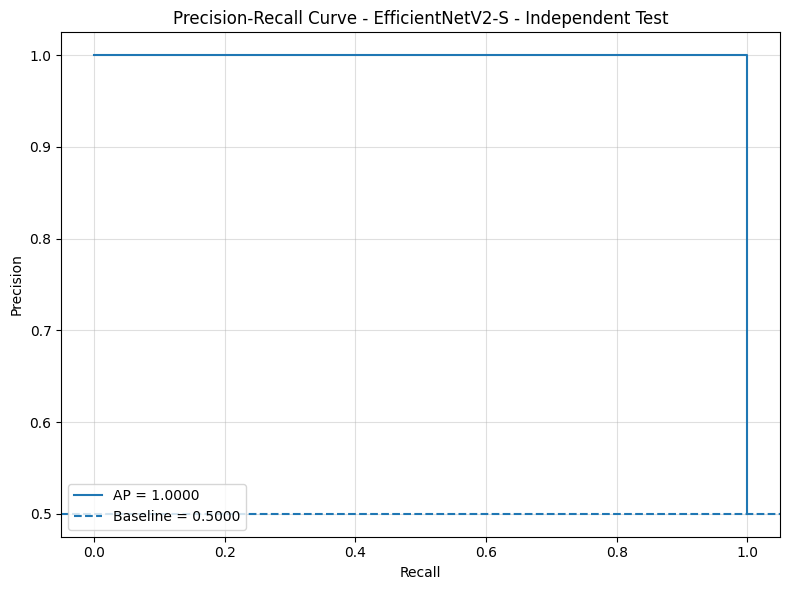

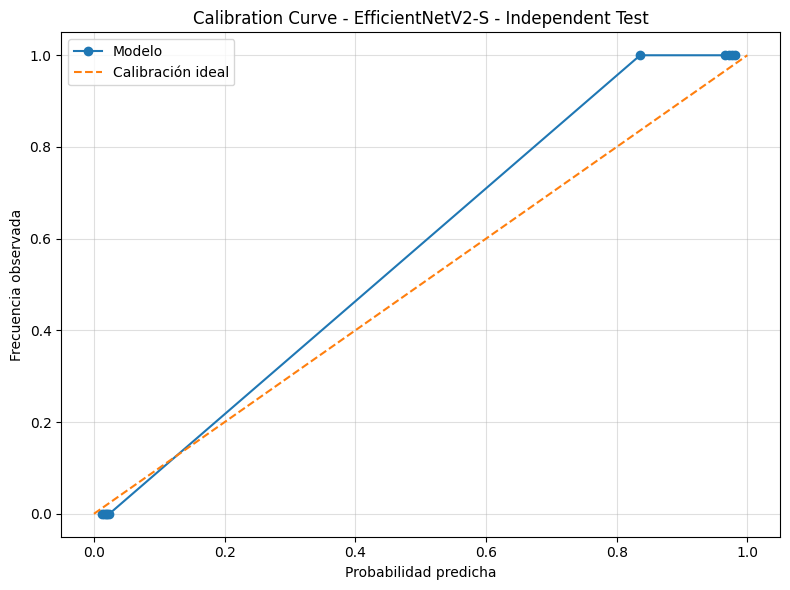

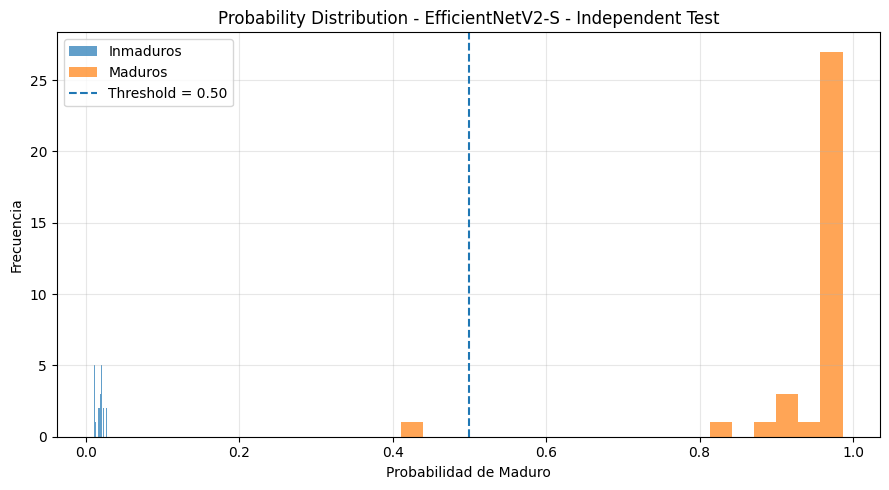

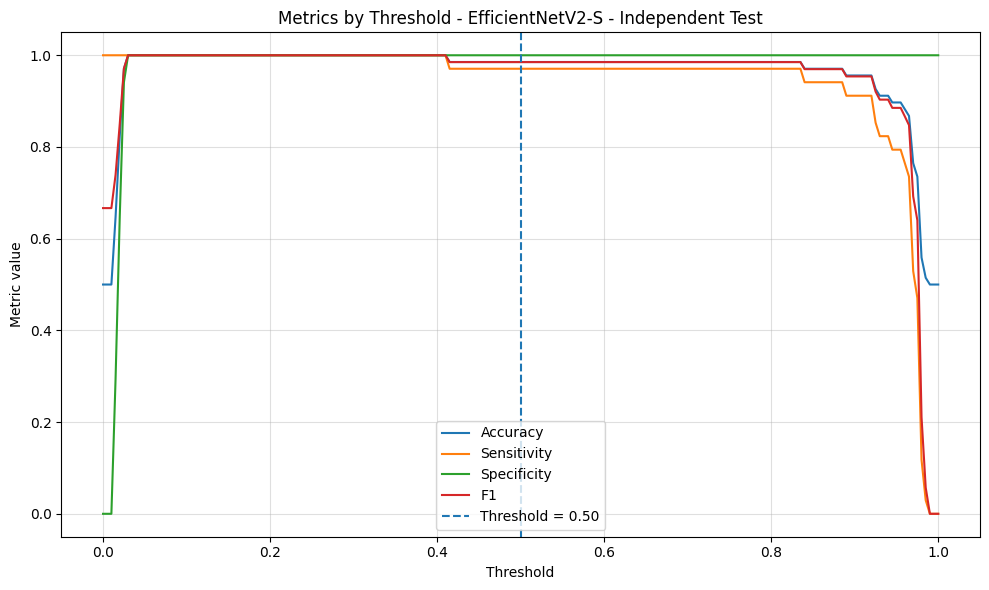


EXPORTANDO ARTEFACTOS DE EFFICIENTNETV2-S


Saved artifact at '/content/drive/MyDrive/Tesis-Mango/Dataset Tesis2/Resultados/Experimento_EfficientNetV2S_Evaluacion_Extendida/artefactos_modelo/EfficientNetV2S_saved_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='imagen_entrada')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  136788993380176: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136789272244112: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136789026988944: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136788993383248: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136789272244688: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136789026989136: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136789026991248: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136789920989648: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1367890269899

In [ ]:
# ============================================================
# EFFICIENTNETV2-S MONOLÍTICA - EVALUACIÓN EXTENDIDA
# ============================================================
#
# CLASIFICACIÓN:
#   0 = Inmaduros
#   1 = Maduros
#
# VARIANTE:
#   EfficientNetV2-S (EfficientNetV2S de TensorFlow/Keras).
#   Se utiliza IMG_SIZE=(224,224) para mantener comparabilidad con
#   EfficientNetV2-S y el futuro Swin Transformer Tiny.
#
# OBJETIVO:
#   Entrenar y evaluar EfficientNetV2-S con un conjunto amplio de métricas
#   para permitir comparaciones posteriores con ResNet50 y
#   Swin Transformer Tiny, incluso cuando Accuracy/F1/AUC se saturen.
#
# FLUJO:
#   1. Cargar train, val y test.
#   2. Verificar duplicados exactos SHA-256 entre splits.
#   3. Dividir únicamente val para Optuna (70/30).
#   4. Optuna ejecuta 30 trials y minimiza log loss.
#   5. Optuna selecciona hiperparámetros y cantidad de épocas.
#   6. Validación cruzada estratificada de 10 folds sobre train.
#      Cada fold entrena una EfficientNetV2-S nueva con la configuración fija
#      seleccionada por HPO. No se vuelve a elegir época en CV.
#   7. Evaluación OOF con métricas discriminativas, probabilísticas,
#      calibración, incertidumbre, intervalos y curvas.
#   8. Entrenamiento final con train + val.
#   9. Evaluación única en test independiente.
#  10. Exportación de modelo, pesos, configuración, TFLite,
#      SavedModel, manifiesto, checksums y ZIP.
#
# COLORES:
#   - Matrices de confusión: cmap="Blues".
#   - Resto de gráficos: ciclo de colores predeterminado de Matplotlib
#     (primera serie azul, segunda naranja, etc.).
# ============================================================


# ============================================================
# 1. INSTALAR DEPENDENCIAS
# ============================================================

!pip install -q optuna seaborn scipy statsmodels onnx onnxruntime tf2onnx


# ============================================================
# 2. IMPORTACIONES
# ============================================================

import os
import gc
import io
import json
import time
import math
import random
import shutil
import hashlib
import platform
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
import optuna

from tqdm.auto import tqdm
from IPython.display import display

from tensorflow.keras import Model, layers, callbacks, optimizers, regularizers
from tensorflow.keras.applications import EfficientNetV2S

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    jaccard_score,
    matthews_corrcoef,
    cohen_kappa_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    log_loss,
    brier_score_loss,
    roc_curve,
    precision_recall_curve,
    auc,
)
from sklearn.calibration import calibration_curve
from sklearn.linear_model import LogisticRegression
from scipy.stats import beta, ks_2samp

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)


# ============================================================
# 3. REPRODUCIBILIDAD
# ============================================================

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

try:
    tf.config.experimental.enable_op_determinism()
    print("Operaciones deterministas activadas.")
except Exception as error:
    print("No se pudo activar el determinismo completo:", error)


# ============================================================
# 4. CONFIGURACIÓN DE GPU
# ============================================================

gpus = tf.config.list_physical_devices("GPU")

if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print(f"GPU detectada: {gpus}")
    except Exception as error:
        print("No se pudo configurar la memoria GPU:", error)
else:
    print("No se detectó GPU. Se utilizará CPU.")


# ============================================================
# 5. RUTAS
# ============================================================

# Debe existir previamente:
# ejecucion = Path("/content/drive/MyDrive/Tesis-Mango/Resultados")

SPLIT_DIR = ejecucion / "Dataset_balanceado_split"
TRAIN_DIR = SPLIT_DIR / "train"
VAL_DIR = SPLIT_DIR / "val"
TEST_DIR = SPLIT_DIR / "test"

EXPERIMENT_DIR = ejecucion / "Experimento_EfficientNetV2S_Evaluacion_Extendida"
MODELS_DIR = EXPERIMENT_DIR / "modelos"
RESULTS_DIR = EXPERIMENT_DIR / "resultados"
FIGURES_DIR = EXPERIMENT_DIR / "figuras"
HISTORIES_DIR = EXPERIMENT_DIR / "historiales"
FOLDS_DIR = EXPERIMENT_DIR / "folds"
OPTUNA_DIR = EXPERIMENT_DIR / "optuna"
ARTEFACTS_DIR = EXPERIMENT_DIR / "artefactos_modelo"

for carpeta in [
    EXPERIMENT_DIR,
    MODELS_DIR,
    RESULTS_DIR,
    FIGURES_DIR,
    HISTORIES_DIR,
    FOLDS_DIR,
    OPTUNA_DIR,
    ARTEFACTS_DIR,
]:
    carpeta.mkdir(parents=True, exist_ok=True)


# ============================================================
# 6. CONFIGURACIÓN GENERAL
# ============================================================

MODEL_NAME = "EfficientNetV2-S"
IMG_SIZE = (224, 224)
INCLUDE_PREPROCESSING = True
CLASS_NAMES = ["Inmaduros", "Maduros"]
LABEL_MAP = {"Inmaduros": 0, "Maduros": 1}
INV_LABEL_MAP = {0: "Inmaduros", 1: "Maduros"}
POSITIVE_CLASS = 1
EXTENSIONES_VALIDAS = {".jpg", ".jpeg", ".png", ".bmp"}

# HPO
N_OPTUNA_TRIALS = 30
OPTUNA_VALIDATION_FRACTION = 0.30

# Validación cruzada
N_FOLDS = 10

# Clasificación
CLASSIFICATION_THRESHOLD = 0.50

# Calibración y bootstrap
N_CALIBRATION_BINS = 10
N_BOOTSTRAP = 2000
BOOTSTRAP_CONFIDENCE = 0.95

# Medición de latencia
LATENCY_REPETITIONS = 5

# Controles
GENERAR_PLOTS_POR_FOLD = True
VERIFICAR_DUPLICADOS = True
GUARDAR_MODELOS_FOLDS = False
EXPORTAR_SAVEDMODEL = True
EXPORTAR_TFLITE_FLOAT32 = True
EXPORTAR_TFLITE_OPTIMIZADO = True

# ONNX queda desactivado por defecto para evitar reinicios de Colab.
# Puede activarse posteriormente en un runtime limpio.
EXPORTAR_ONNX = False


# ============================================================
# 7. DATAFRAMES DE TRAIN, VAL Y TEST
# ============================================================

def crear_dataframe_split(carpeta_split, nombre_split):
    registros = []

    if not carpeta_split.exists():
        raise FileNotFoundError(f"No existe la carpeta:\n{carpeta_split}")

    for nombre_clase in CLASS_NAMES:
        carpeta_clase = carpeta_split / nombre_clase

        if not carpeta_clase.exists():
            raise FileNotFoundError(f"No existe la carpeta:\n{carpeta_clase}")

        archivos = sorted([
            archivo
            for archivo in carpeta_clase.rglob("*")
            if archivo.is_file()
            and archivo.suffix.lower() in EXTENSIONES_VALIDAS
        ])

        if not archivos:
            raise ValueError(
                f"La clase '{nombre_clase}' del split "
                f"'{nombre_split}' no contiene imágenes."
            )

        for archivo in archivos:
            registros.append({
                "filepath": str(archivo),
                "label": nombre_clase,
                "y": LABEL_MAP[nombre_clase],
                "split": nombre_split,
            })

    dataframe = pd.DataFrame(registros)
    return dataframe.sample(frac=1, random_state=SEED).reset_index(drop=True)


df_train = crear_dataframe_split(TRAIN_DIR, "train")
df_val = crear_dataframe_split(VAL_DIR, "validation")
df_test = crear_dataframe_split(TEST_DIR, "test")


# ============================================================
# 8. VERIFICACIONES INICIALES
# ============================================================

conteo_train = df_train["label"].value_counts().reindex(CLASS_NAMES)

if conteo_train.min() < N_FOLDS:
    raise ValueError(
        f"Cada clase de train debe tener al menos {N_FOLDS} imágenes "
        f"para ejecutar {N_FOLDS} folds.\n\nConteo:\n{conteo_train}"
    )

print("\nDISTRIBUCIÓN PRINCIPAL DEL DATASET")
print("=" * 72)

resumen_dataset = []

for nombre_split, dataframe in {
    "Train": df_train,
    "Validation": df_val,
    "Test": df_test,
}.items():
    print(f"\n{nombre_split}")
    conteo = dataframe["label"].value_counts().reindex(
        CLASS_NAMES,
        fill_value=0,
    )
    display(conteo)

    for clase in CLASS_NAMES:
        resumen_dataset.append({
            "split": nombre_split,
            "clase": clase,
            "cantidad": int(conteo.loc[clase]),
        })

pd.DataFrame(resumen_dataset).to_csv(
    RESULTS_DIR / "distribucion_dataset.csv",
    index=False,
    encoding="utf-8-sig",
)


# ============================================================
# 9. DUPLICADOS EXACTOS ENTRE SPLITS
# ============================================================

def calcular_hash_archivo(filepath, chunk_size=1024 * 1024):
    sha256 = hashlib.sha256()
    with open(filepath, "rb") as archivo:
        while True:
            bloque = archivo.read(chunk_size)
            if not bloque:
                break
            sha256.update(bloque)
    return sha256.hexdigest()


def verificar_duplicados_entre_splits(dataframes):
    hashes_observados = {}
    duplicados = []
    total_archivos = sum(len(df) for df in dataframes.values())
    barra = tqdm(total=total_archivos, desc="Verificando duplicados")

    for nombre_split, dataframe in dataframes.items():
        for filepath in dataframe["filepath"]:
            hash_imagen = calcular_hash_archivo(filepath)

            if hash_imagen in hashes_observados:
                anterior = hashes_observados[hash_imagen]
                if anterior["split"] != nombre_split:
                    duplicados.append({
                        "hash": hash_imagen,
                        "split_1": anterior["split"],
                        "archivo_1": anterior["filepath"],
                        "split_2": nombre_split,
                        "archivo_2": filepath,
                    })
            else:
                hashes_observados[hash_imagen] = {
                    "split": nombre_split,
                    "filepath": filepath,
                }

            barra.update(1)

    barra.close()

    if duplicados:
        df_duplicados = pd.DataFrame(duplicados)
        ruta = RESULTS_DIR / "duplicados_entre_splits.csv"
        df_duplicados.to_csv(ruta, index=False, encoding="utf-8-sig")
        display(df_duplicados)
        raise ValueError(
            "Se encontraron imágenes idénticas entre splits. "
            f"Reporte: {ruta}"
        )

    print("No se encontraron imágenes duplicadas entre los splits.")


if VERIFICAR_DUPLICADOS:
    verificar_duplicados_entre_splits({
        "train": df_train,
        "validation": df_val,
        "test": df_test,
    })


# ============================================================
# 10. DIVISIÓN INTERNA DE VAL PARA OPTUNA
# ============================================================

# Optuna usa únicamente val. No utiliza train principal ni test.

df_optuna_train, df_optuna_validation = train_test_split(
    df_val,
    test_size=OPTUNA_VALIDATION_FRACTION,
    stratify=df_val["y"],
    random_state=SEED,
)


df_optuna_train = df_optuna_train.sample(
    frac=1,
    random_state=SEED,
).reset_index(drop=True)

df_optuna_validation = df_optuna_validation.sample(
    frac=1,
    random_state=SEED,
).reset_index(drop=True)


df_optuna_train.to_csv(
    OPTUNA_DIR / "optuna_train.csv",
    index=False,
    encoding="utf-8-sig",
)

df_optuna_validation.to_csv(
    OPTUNA_DIR / "optuna_validation.csv",
    index=False,
    encoding="utf-8-sig",
)

print("\nDIVISIÓN INTERNA DE VALIDACIÓN PARA OPTUNA")
print("=" * 72)
print("\nOptuna train:")
display(
    df_optuna_train["label"]
    .value_counts()
    .reindex(CLASS_NAMES, fill_value=0)
)
print("\nOptuna validation:")
display(
    df_optuna_validation["label"]
    .value_counts()
    .reindex(CLASS_NAMES, fill_value=0)
)
print(f"\nTotal val: {len(df_val)}")
print(f"Optuna train: {len(df_optuna_train)}")
print(f"Optuna validation: {len(df_optuna_validation)}")


# ============================================================
# 11. AUMENTO DE DATOS CONTROLADO
# ============================================================

def construir_aumento_datos():
    """
    Aumento únicamente para entrenamiento.
    Se usa relleno negro porque las imágenes están segmentadas
    sobre fondo negro.
    """

    return tf.keras.Sequential(
        [
            layers.RandomFlip(
                mode="horizontal",
                seed=SEED,
            ),
            layers.RandomRotation(
                factor=0.08,
                fill_mode="constant",
                fill_value=0.0,
                seed=SEED + 1,
            ),
            layers.RandomZoom(
                height_factor=(-0.10, 0.10),
                width_factor=(-0.10, 0.10),
                fill_mode="constant",
                fill_value=0.0,
                seed=SEED + 2,
            ),
            layers.RandomTranslation(
                height_factor=0.05,
                width_factor=0.05,
                fill_mode="constant",
                fill_value=0.0,
                seed=SEED + 3,
            ),
            layers.RandomContrast(
                factor=0.15,
                seed=SEED + 4,
            ),
        ],
        name="aumento_datos_controlado",
    )


# ============================================================
# 12. FUNCIONES TF.DATA
# ============================================================

def cargar_y_redimensionar(filepath, label):
    imagen = tf.io.read_file(filepath)
    imagen = tf.io.decode_image(
        imagen,
        channels=3,
        expand_animations=False,
    )
    imagen.set_shape([None, None, 3])
    imagen = tf.image.resize(imagen, IMG_SIZE, method="bilinear")
    imagen = tf.cast(imagen, tf.float32)
    label = tf.cast(label, tf.float32)
    return imagen, label


def cargar_imagen_sin_label(filepath):
    imagen = tf.io.read_file(filepath)
    imagen = tf.io.decode_image(
        imagen,
        channels=3,
        expand_animations=False,
    )
    imagen.set_shape([None, None, 3])
    imagen = tf.image.resize(imagen, IMG_SIZE, method="bilinear")
    imagen = tf.cast(imagen, tf.float32)
    return imagen


def crear_dataset_etiquetado(
    dataframe,
    batch_size,
    aplicar_aumento=False,
    shuffle=False,
):
    paths = dataframe["filepath"].astype(str).values
    etiquetas = dataframe["y"].astype("float32").values

    dataset_tf = tf.data.Dataset.from_tensor_slices((paths, etiquetas))

    if shuffle:
        dataset_tf = dataset_tf.shuffle(
            buffer_size=len(dataframe),
            seed=SEED,
            reshuffle_each_iteration=True,
        )

    dataset_tf = dataset_tf.map(
        cargar_y_redimensionar,
        num_parallel_calls=tf.data.AUTOTUNE,
    )
    dataset_tf = dataset_tf.batch(batch_size, drop_remainder=False)

    if aplicar_aumento:
        augmentation_layer = construir_aumento_datos()
        dataset_tf = dataset_tf.map(
            lambda imagen, etiqueta: (
                augmentation_layer(imagen, training=True),
                etiqueta,
            ),
            num_parallel_calls=tf.data.AUTOTUNE,
        )

    # EfficientNetV2-S incluye internamente su capa Rescaling.
    # Las imágenes permanecen como float32 en el rango [0, 255].

    opciones = tf.data.Options()
    opciones.experimental_deterministic = True
    dataset_tf = dataset_tf.with_options(opciones)
    return dataset_tf.prefetch(tf.data.AUTOTUNE)


def crear_dataset_prediccion(dataframe, batch_size):
    paths = dataframe["filepath"].astype(str).values
    dataset_tf = tf.data.Dataset.from_tensor_slices(paths)
    dataset_tf = dataset_tf.map(
        cargar_imagen_sin_label,
        num_parallel_calls=tf.data.AUTOTUNE,
    )
    dataset_tf = dataset_tf.batch(batch_size, drop_remainder=False)
    # EfficientNetV2-S incluye internamente su capa Rescaling.
    # Las imágenes permanecen como float32 en el rango [0, 255].

    opciones = tf.data.Options()
    opciones.experimental_deterministic = True
    dataset_tf = dataset_tf.with_options(opciones)
    return dataset_tf.prefetch(tf.data.AUTOTUNE)


# ============================================================
# 13. PESOS DE CLASE
# ============================================================

def calcular_pesos_clase(etiquetas):
    clases, conteos = np.unique(etiquetas, return_counts=True)
    total = len(etiquetas)
    numero_clases = len(clases)

    return {
        int(clase): total / (numero_clases * conteo)
        for clase, conteo in zip(clases, conteos)
    }


# ============================================================
# 14. CONSTRUCCIÓN DE EFFICIENTNETV2-S
# ============================================================

def crear_optimizador(nombre, learning_rate):
    nombre = str(nombre).lower()

    if nombre == "adam":
        return optimizers.Adam(learning_rate=learning_rate)

    if nombre == "rmsprop":
        return optimizers.RMSprop(learning_rate=learning_rate)

    if nombre == "sgd":
        return optimizers.SGD(
            learning_rate=learning_rate,
            momentum=0.90,
            nesterov=True,
        )

    raise ValueError(f"Optimizador no reconocido: {nombre}")


def configurar_capas_entrenables(base_model, last_n_layers):
    for capa in base_model.layers:
        capa.trainable = False

    if last_n_layers > 0:
        for capa in base_model.layers[-last_n_layers:]:
            if isinstance(capa, layers.BatchNormalization):
                capa.trainable = False
            else:
                capa.trainable = True

    return base_model


def construir_efficientnetv2s(hiperparametros):
    base_model = EfficientNetV2S(
        weights="imagenet",
        include_top=False,
        input_shape=IMG_SIZE + (3,),
        pooling="avg",
        include_preprocessing=INCLUDE_PREPROCESSING,
    )

    base_model = configurar_capas_entrenables(
        base_model,
        last_n_layers=int(hiperparametros["last_n_layers"]),
    )

    entradas = layers.Input(
        shape=IMG_SIZE + (3,),
        name="imagen_entrada",
    )

    x = base_model(entradas, training=False)

    x = layers.Dense(
        units=int(hiperparametros["dense_units"]),
        activation="relu",
        kernel_regularizer=regularizers.l2(
            float(hiperparametros["l2_regularization"])
        ),
        name="capa_densa",
    )(x)

    x = layers.Dropout(
        rate=float(hiperparametros["dropout_rate"]),
        name="dropout",
    )(x)

    salida = layers.Dense(
        units=1,
        activation="sigmoid",
        name="salida_binaria",
    )(x)

    modelo = Model(
        entradas,
        salida,
        name="EfficientNetV2S_Madurez_Mango",
    )

    modelo.compile(
        optimizer=crear_optimizador(
            hiperparametros["optimizer"],
            float(hiperparametros["learning_rate"]),
        ),
        loss=tf.keras.losses.BinaryCrossentropy(
            label_smoothing=float(
                hiperparametros["label_smoothing"]
            )
        ),
        metrics=[
            tf.keras.metrics.BinaryAccuracy(name="accuracy"),
            tf.keras.metrics.AUC(name="auc"),
            tf.keras.metrics.AUC(
                name="pr_auc",
                curve="PR",
            ),
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall"),
        ],
    )

    return modelo


# ============================================================
# 15. MÉTRICAS EXTENDIDAS
# ============================================================

def division_segura(numerador, denominador):
    return (
        numerador / denominador
        if denominador not in (0, 0.0)
        else np.nan
    )


def intervalo_clopper_pearson(exitos, total, confianza=0.95):
    """Intervalo binomial exacto de Clopper-Pearson."""

    if total <= 0:
        return np.nan, np.nan

    alfa = 1.0 - confianza

    inferior = (
        0.0
        if exitos == 0
        else beta.ppf(alfa / 2.0, exitos, total - exitos + 1)
    )

    superior = (
        1.0
        if exitos == total
        else beta.ppf(1.0 - alfa / 2.0, exitos + 1, total - exitos)
    )

    return float(inferior), float(superior)


def calcular_ece_mce(y_true, y_score, n_bins=10):
    y_true = np.asarray(y_true).astype(int)
    y_score = np.asarray(y_score).astype(float)

    confianza_predicha = np.maximum(y_score, 1.0 - y_score)
    predicciones = (y_score >= 0.5).astype(int)
    aciertos = (predicciones == y_true).astype(float)

    bordes = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    mce = 0.0
    registros = []

    for i in range(n_bins):
        izquierda = bordes[i]
        derecha = bordes[i + 1]

        if i == n_bins - 1:
            mascara = (
                (confianza_predicha >= izquierda)
                & (confianza_predicha <= derecha)
            )
        else:
            mascara = (
                (confianza_predicha >= izquierda)
                & (confianza_predicha < derecha)
            )

        cantidad = int(mascara.sum())

        if cantidad == 0:
            registros.append({
                "bin": i + 1,
                "lower": izquierda,
                "upper": derecha,
                "count": 0,
                "mean_confidence": np.nan,
                "accuracy": np.nan,
                "gap": np.nan,
            })
            continue

        confianza_media = float(confianza_predicha[mascara].mean())
        accuracy_bin = float(aciertos[mascara].mean())
        gap = abs(accuracy_bin - confianza_media)

        ece += (cantidad / len(y_true)) * gap
        mce = max(mce, gap)

        registros.append({
            "bin": i + 1,
            "lower": izquierda,
            "upper": derecha,
            "count": cantidad,
            "mean_confidence": confianza_media,
            "accuracy": accuracy_bin,
            "gap": gap,
        })

    return float(ece), float(mce), pd.DataFrame(registros)


def calcular_calibracion_logistica(y_true, y_score):
    """
    Intercepto y pendiente de calibración.
    Ideal: intercepto = 0 y pendiente = 1.
    """

    y_true = np.asarray(y_true).astype(int)
    y_score = np.clip(
        np.asarray(y_score).astype(float),
        1e-7,
        1.0 - 1e-7,
    )

    if len(np.unique(y_true)) < 2:
        return np.nan, np.nan

    logits = np.log(y_score / (1.0 - y_score)).reshape(-1, 1)

    try:
        calibrador = LogisticRegression(
            penalty=None,
            solver="lbfgs",
            max_iter=5000,
        )
        calibrador.fit(logits, y_true)
        intercepto = float(calibrador.intercept_[0])
        pendiente = float(calibrador.coef_[0][0])
        return intercepto, pendiente
    except Exception:
        return np.nan, np.nan


def entropia_binaria(probabilidades):
    p = np.clip(
        np.asarray(probabilidades, dtype=float),
        1e-12,
        1.0 - 1e-12,
    )
    return -(p * np.log2(p) + (1.0 - p) * np.log2(1.0 - p))


def perdida_logaritmica_individual(y_true, y_score):
    y_true = np.asarray(y_true).astype(float)
    p = np.clip(
        np.asarray(y_score).astype(float),
        1e-7,
        1.0 - 1e-7,
    )
    return -(y_true * np.log(p) + (1.0 - y_true) * np.log(1.0 - p))


def calcular_metricas_binarias_extensas(
    y_true,
    y_pred,
    y_score,
    threshold=0.50,
    n_bins=10,
):
    y_true = np.asarray(y_true).astype(int)
    y_pred = np.asarray(y_pred).astype(int)
    y_score = np.asarray(y_score).astype(float)

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    sensibilidad = division_segura(tp, tp + fn)
    especificidad = division_segura(tn, tn + fp)
    ppv = division_segura(tp, tp + fp)
    npv = division_segura(tn, tn + fn)
    fpr = division_segura(fp, fp + tn)
    fnr = division_segura(fn, fn + tp)
    lr_positive = division_segura(sensibilidad, 1.0 - especificidad)
    lr_negative = division_segura(1.0 - sensibilidad, especificidad)
    dor = division_segura(lr_positive, lr_negative)

    valor_auc = (
        roc_auc_score(y_true, y_score)
        if len(np.unique(y_true)) == 2
        else np.nan
    )

    valor_ap = (
        average_precision_score(y_true, y_score)
        if len(np.unique(y_true)) == 2
        else np.nan
    )

    if len(np.unique(y_true)) == 2:
        precision_pr, recall_pr, _ = precision_recall_curve(
            y_true,
            y_score,
        )
        valor_pr_auc_trapezoidal = auc(recall_pr, precision_pr)
    else:
        valor_pr_auc_trapezoidal = np.nan

    youden_j = sensibilidad + especificidad - 1.0
    markedness = ppv + npv - 1.0
    geometric_mean = (
        math.sqrt(sensibilidad * especificidad)
        if np.isfinite(sensibilidad) and np.isfinite(especificidad)
        else np.nan
    )
    fowlkes_mallows = (
        math.sqrt(ppv * sensibilidad)
        if np.isfinite(ppv) and np.isfinite(sensibilidad)
        else np.nan
    )

    ece, mce, _ = calcular_ece_mce(
        y_true,
        y_score,
        n_bins=n_bins,
    )

    calibration_intercept, calibration_slope = (
        calcular_calibracion_logistica(y_true, y_score)
    )

    prob_clase_correcta = np.where(
        y_true == 1,
        y_score,
        1.0 - y_score,
    )

    margen = np.abs(y_score - threshold)
    entropia = entropia_binaria(y_score)

    scores_negativos = y_score[y_true == 0]
    scores_positivos = y_score[y_true == 1]

    if len(scores_negativos) > 0 and len(scores_positivos) > 0:
        ks_statistic, ks_pvalue = ks_2samp(
            scores_negativos,
            scores_positivos,
        )
    else:
        ks_statistic, ks_pvalue = np.nan, np.nan

    return {
        # Matriz de confusión
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),

        # Métricas basadas en clase
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "balanced_accuracy": float(
            balanced_accuracy_score(y_true, y_pred)
        ),
        "precision_ppv": float(
            precision_score(
                y_true,
                y_pred,
                pos_label=POSITIVE_CLASS,
                zero_division=0,
            )
        ),
        "sensitivity_recall": float(
            recall_score(
                y_true,
                y_pred,
                pos_label=POSITIVE_CLASS,
                zero_division=0,
            )
        ),
        "specificity": float(especificidad),
        "negative_predictive_value": float(npv),
        "f1_score": float(
            f1_score(
                y_true,
                y_pred,
                pos_label=POSITIVE_CLASS,
                zero_division=0,
            )
        ),
        "f2_score": float(
            fbeta_score(
                y_true,
                y_pred,
                beta=2.0,
                pos_label=POSITIVE_CLASS,
                zero_division=0,
            )
        ),
        "jaccard_index": float(
            jaccard_score(
                y_true,
                y_pred,
                pos_label=POSITIVE_CLASS,
                zero_division=0,
            )
        ),
        "mcc": float(matthews_corrcoef(y_true, y_pred)),
        "cohen_kappa": float(cohen_kappa_score(y_true, y_pred)),
        "false_positive_rate": float(fpr),
        "false_negative_rate": float(fnr),
        "positive_likelihood_ratio": float(lr_positive),
        "negative_likelihood_ratio": float(lr_negative),
        "diagnostic_odds_ratio": float(dor),
        "youden_j_informedness": float(youden_j),
        "markedness": float(markedness),
        "geometric_mean_sensitivity_specificity": float(geometric_mean),
        "fowlkes_mallows_index": float(fowlkes_mallows),
        "prevalence": float(np.mean(y_true)),
        "predicted_positive_rate": float(np.mean(y_pred)),

        # Métricas probabilísticas y threshold-independent
        "roc_auc": float(valor_auc),
        "pr_auc_average_precision": float(valor_ap),
        "pr_auc_trapezoidal": float(valor_pr_auc_trapezoidal),
        "log_loss": float(log_loss(y_true, y_score, labels=[0, 1])),
        "brier_score": float(brier_score_loss(y_true, y_score)),

        # Calibración
        "ece": float(ece),
        "mce": float(mce),
        "calibration_intercept": float(calibration_intercept),
        "calibration_slope": float(calibration_slope),

        # Confianza, separación e incertidumbre
        "mean_correct_class_probability": float(
            np.mean(prob_clase_correcta)
        ),
        "median_correct_class_probability": float(
            np.median(prob_clase_correcta)
        ),
        "minimum_correct_class_probability": float(
            np.min(prob_clase_correcta)
        ),
        "mean_margin_from_threshold": float(np.mean(margen)),
        "median_margin_from_threshold": float(np.median(margen)),
        "p05_margin_from_threshold": float(np.percentile(margen, 5)),
        "minimum_margin_from_threshold": float(np.min(margen)),
        "mean_predictive_entropy_bits": float(np.mean(entropia)),
        "maximum_predictive_entropy_bits": float(np.max(entropia)),
        "ks_statistic_score_separation": float(ks_statistic),
        "ks_pvalue_score_separation": float(ks_pvalue),
        "threshold": float(threshold),
        "n_images": int(len(y_true)),
    }


def construir_intervalos_exactos(y_true, y_pred, confianza=0.95):
    y_true = np.asarray(y_true).astype(int)
    y_pred = np.asarray(y_pred).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1],
    ).ravel()

    registros = []

    especificaciones = [
        ("accuracy", int((y_true == y_pred).sum()), len(y_true)),
        ("sensitivity", int(tp), int(tp + fn)),
        ("specificity", int(tn), int(tn + fp)),
        ("precision_ppv", int(tp), int(tp + fp)),
        ("negative_predictive_value", int(tn), int(tn + fn)),
    ]

    for metrica, exitos, total in especificaciones:
        inferior, superior = intervalo_clopper_pearson(
            exitos,
            total,
            confianza=confianza,
        )
        registros.append({
            "metric": metrica,
            "estimate": division_segura(exitos, total),
            "ci_lower": inferior,
            "ci_upper": superior,
            "confidence": confianza,
            "method": "Clopper-Pearson exact",
            "successes": exitos,
            "total": total,
        })

    return pd.DataFrame(registros)


def bootstrap_metricas(
    y_true,
    y_score,
    threshold=0.50,
    n_bootstrap=2000,
    confianza=0.95,
    seed=42,
):
    """
    Intervalos bootstrap estratificados para métricas que siguen
    siendo informativas cuando Accuracy/F1 se saturan.
    """

    y_true = np.asarray(y_true).astype(int)
    y_score = np.asarray(y_score).astype(float)
    rng = np.random.default_rng(seed)

    indices_0 = np.where(y_true == 0)[0]
    indices_1 = np.where(y_true == 1)[0]

    if len(indices_0) == 0 or len(indices_1) == 0:
        return pd.DataFrame()

    nombres = [
        "roc_auc",
        "pr_auc_average_precision",
        "log_loss",
        "brier_score",
        "ece",
        "mean_correct_class_probability",
        "mean_margin_from_threshold",
        "mean_predictive_entropy_bits",
    ]

    distribuciones = {nombre: [] for nombre in nombres}

    for _ in range(n_bootstrap):
        muestra_0 = rng.choice(indices_0, size=len(indices_0), replace=True)
        muestra_1 = rng.choice(indices_1, size=len(indices_1), replace=True)
        indices = np.concatenate([muestra_0, muestra_1])
        rng.shuffle(indices)

        yt = y_true[indices]
        ys = y_score[indices]

        ece_boot, _, _ = calcular_ece_mce(
            yt,
            ys,
            n_bins=N_CALIBRATION_BINS,
        )

        prob_correcta_boot = np.where(
            yt == 1,
            ys,
            1.0 - ys,
        )

        valores_boot = {
            "roc_auc": float(roc_auc_score(yt, ys)),
            "pr_auc_average_precision": float(
                average_precision_score(yt, ys)
            ),
            "log_loss": float(log_loss(yt, ys, labels=[0, 1])),
            "brier_score": float(brier_score_loss(yt, ys)),
            "ece": float(ece_boot),
            "mean_correct_class_probability": float(
                np.mean(prob_correcta_boot)
            ),
            "mean_margin_from_threshold": float(
                np.mean(np.abs(ys - threshold))
            ),
            "mean_predictive_entropy_bits": float(
                np.mean(entropia_binaria(ys))
            ),
        }

        for nombre in nombres:
            valor = valores_boot[nombre]
            if np.isfinite(valor):
                distribuciones[nombre].append(valor)

    alfa = 1.0 - confianza
    filas = []

    y_pred_original = (y_score >= threshold).astype(int)
    metricas_originales = calcular_metricas_binarias_extensas(
        y_true,
        y_pred_original,
        y_score,
        threshold=threshold,
        n_bins=N_CALIBRATION_BINS,
    )

    for nombre in nombres:
        valores = np.asarray(distribuciones[nombre], dtype=float)

        if len(valores) == 0:
            continue

        filas.append({
            "metric": nombre,
            "estimate": metricas_originales[nombre],
            "ci_lower": float(np.percentile(valores, 100 * alfa / 2)),
            "ci_upper": float(
                np.percentile(valores, 100 * (1.0 - alfa / 2))
            ),
            "confidence": confianza,
            "method": "Stratified percentile bootstrap",
            "n_bootstrap": int(n_bootstrap),
        })

    return pd.DataFrame(filas)


def crear_barrido_umbrales(y_true, y_score):
    filas = []

    for threshold in np.linspace(0.0, 1.0, 201):
        pred = (np.asarray(y_score) >= threshold).astype(int)
        tn, fp, fn, tp = confusion_matrix(
            y_true,
            pred,
            labels=[0, 1],
        ).ravel()

        sensibilidad = division_segura(tp, tp + fn)
        especificidad = division_segura(tn, tn + fp)
        precision = division_segura(tp, tp + fp)

        filas.append({
            "threshold": float(threshold),
            "accuracy": float(accuracy_score(y_true, pred)),
            "balanced_accuracy": float(
                balanced_accuracy_score(y_true, pred)
            ),
            "precision": precision,
            "sensitivity": sensibilidad,
            "specificity": especificidad,
            "f1_score": float(
                f1_score(y_true, pred, zero_division=0)
            ),
            "youden_j": float(sensibilidad + especificidad - 1.0),
            "tn": int(tn),
            "fp": int(fp),
            "fn": int(fn),
            "tp": int(tp),
        })

    return pd.DataFrame(filas)


# ============================================================
# 16. GRÁFICOS
# ============================================================

def plot_confusion_matrix_from_predictions(
    y_true,
    y_pred,
    class_names,
    title,
    save_path,
):
    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=list(range(len(class_names))),
    )

    plt.figure(figsize=(8, 6))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names,
    )
    plt.xlabel("Predicted class")
    plt.ylabel("True class")
    plt.title(title)
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()
    return cm


def plot_roc_binaria(y_true, y_score, title, save_path):
    fpr, tpr, _ = roc_curve(y_true, y_score)
    roc_auc = auc(fpr, tpr)

    plt.figure(figsize=(8, 6))
    plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.4f}")
    plt.plot([0, 1], [0, 1], linestyle="--")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(title)
    plt.legend(loc="lower right")
    plt.grid(alpha=0.4)
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()


def plot_precision_recall_binaria(y_true, y_score, title, save_path):
    precision, recall, _ = precision_recall_curve(y_true, y_score)
    ap = average_precision_score(y_true, y_score)
    baseline = float(np.mean(y_true))

    plt.figure(figsize=(8, 6))
    plt.plot(recall, precision, label=f"AP = {ap:.4f}")
    plt.axhline(
        baseline,
        linestyle="--",
        label=f"Baseline = {baseline:.4f}",
    )
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title(title)
    plt.legend(loc="lower left")
    plt.grid(alpha=0.4)
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()


def plot_calibracion(y_true, y_score, title, save_path, n_bins=10):
    prob_true, prob_pred = calibration_curve(
        y_true,
        y_score,
        n_bins=n_bins,
        strategy="quantile",
    )

    plt.figure(figsize=(8, 6))
    plt.plot(prob_pred, prob_true, marker="o", label="Modelo")
    plt.plot([0, 1], [0, 1], linestyle="--", label="Calibración ideal")
    plt.xlabel("Probabilidad predicha")
    plt.ylabel("Frecuencia observada")
    plt.title(title)
    plt.legend(loc="upper left")
    plt.grid(alpha=0.4)
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()


def plot_distribucion_probabilidades(
    y_true,
    y_score,
    title,
    save_path,
):
    y_true = np.asarray(y_true)
    y_score = np.asarray(y_score)

    plt.figure(figsize=(9, 5))
    plt.hist(
        y_score[y_true == 0],
        bins=20,
        alpha=0.70,
        label=CLASS_NAMES[0],
    )
    plt.hist(
        y_score[y_true == 1],
        bins=20,
        alpha=0.70,
        label=CLASS_NAMES[1],
    )
    plt.axvline(
        CLASSIFICATION_THRESHOLD,
        linestyle="--",
        label=f"Threshold = {CLASSIFICATION_THRESHOLD:.2f}",
    )
    plt.xlabel("Probabilidad de Maduro")
    plt.ylabel("Frecuencia")
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()


def plot_metricas_por_umbral(df_thresholds, title, save_path):
    plt.figure(figsize=(10, 6))
    plt.plot(
        df_thresholds["threshold"],
        df_thresholds["accuracy"],
        label="Accuracy",
    )
    plt.plot(
        df_thresholds["threshold"],
        df_thresholds["sensitivity"],
        label="Sensitivity",
    )
    plt.plot(
        df_thresholds["threshold"],
        df_thresholds["specificity"],
        label="Specificity",
    )
    plt.plot(
        df_thresholds["threshold"],
        df_thresholds["f1_score"],
        label="F1",
    )
    plt.axvline(
        CLASSIFICATION_THRESHOLD,
        linestyle="--",
        label=f"Threshold = {CLASSIFICATION_THRESHOLD:.2f}",
    )
    plt.xlabel("Threshold")
    plt.ylabel("Metric value")
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.4)
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()


def plot_historial_entrenamiento(historial_df, titulo_base, prefijo_archivo):
    if historial_df.empty:
        return

    pares = [
        ("loss", "val_loss", "Loss"),
        ("accuracy", "val_accuracy", "Accuracy"),
        ("auc", "val_auc", "ROC AUC"),
        ("pr_auc", "val_pr_auc", "PR AUC"),
    ]

    for train_col, val_col, nombre in pares:
        if train_col not in historial_df.columns:
            continue

        plt.figure(figsize=(9, 5))
        plt.plot(
            historial_df["epoch"],
            historial_df[train_col],
            label=f"Train {nombre}",
        )

        if val_col in historial_df.columns:
            plt.plot(
                historial_df["epoch"],
                historial_df[val_col],
                label=f"Validation {nombre}",
            )

        plt.xlabel("Epoch")
        plt.ylabel(nombre)
        plt.title(f"{titulo_base} - {nombre}")
        plt.legend()
        plt.grid(alpha=0.4)
        plt.tight_layout()
        plt.savefig(
            FIGURES_DIR / f"{prefijo_archivo}_{train_col}.png",
            dpi=300,
            bbox_inches="tight",
        )
        plt.show()
        plt.close()


def generar_graficos_evaluacion(
    y_true,
    y_pred,
    y_score,
    etiqueta,
    prefijo,
):
    plot_confusion_matrix_from_predictions(
        y_true,
        y_pred,
        CLASS_NAMES,
        f"Confusion Matrix - {MODEL_NAME} - {etiqueta}",
        FIGURES_DIR / f"confusion_matrix_{prefijo}.png",
    )

    plot_roc_binaria(
        y_true,
        y_score,
        f"ROC Curve - {MODEL_NAME} - {etiqueta}",
        FIGURES_DIR / f"roc_curve_{prefijo}.png",
    )

    plot_precision_recall_binaria(
        y_true,
        y_score,
        f"Precision-Recall Curve - {MODEL_NAME} - {etiqueta}",
        FIGURES_DIR / f"precision_recall_curve_{prefijo}.png",
    )

    plot_calibracion(
        y_true,
        y_score,
        f"Calibration Curve - {MODEL_NAME} - {etiqueta}",
        FIGURES_DIR / f"calibration_curve_{prefijo}.png",
        n_bins=N_CALIBRATION_BINS,
    )

    plot_distribucion_probabilidades(
        y_true,
        y_score,
        f"Probability Distribution - {MODEL_NAME} - {etiqueta}",
        FIGURES_DIR / f"probability_distribution_{prefijo}.png",
    )

    df_thresholds = crear_barrido_umbrales(y_true, y_score)
    df_thresholds.to_csv(
        RESULTS_DIR / f"threshold_sweep_{prefijo}.csv",
        index=False,
        encoding="utf-8-sig",
    )

    plot_metricas_por_umbral(
        df_thresholds,
        f"Metrics by Threshold - {MODEL_NAME} - {etiqueta}",
        FIGURES_DIR / f"metrics_by_threshold_{prefijo}.png",
    )


# ============================================================
# 17. ESPACIO DE HIPERPARÁMETROS
# ============================================================

def sugerir_hiperparametros(trial):
    return {
        "batch_size": trial.suggest_categorical(
            "batch_size",
            [8, 16, 32],
        ),
        "cnn_epochs": trial.suggest_int(
            "cnn_epochs",
            2,
            10,
        ),
        "last_n_layers": trial.suggest_categorical(
            "last_n_layers",
            [0, 10, 20, 30, 40],
        ),
        "dense_units": trial.suggest_categorical(
            "dense_units",
            [128, 256, 512],
        ),
        "dropout_rate": trial.suggest_float(
            "dropout_rate",
            0.10,
            0.50,
            step=0.10,
        ),
        "learning_rate": trial.suggest_float(
            "learning_rate",
            1e-5,
            3e-4,
            log=True,
        ),
        "optimizer": trial.suggest_categorical(
            "optimizer",
            ["adam", "rmsprop", "sgd"],
        ),
        "l2_regularization": trial.suggest_float(
            "l2_regularization",
            1e-6,
            1e-3,
            log=True,
        ),
        "label_smoothing": trial.suggest_categorical(
            "label_smoothing",
            [0.0, 0.05, 0.10],
        ),
    }


# ============================================================
# 18. OPTUNA SOBRE VAL
# ============================================================

def objetivo_optuna(trial):
    """
    Cada trial entrena solo con optuna_train y evalúa solo con
    optuna_validation. El objetivo es minimizar log loss estándar.
    """

    tf.keras.backend.clear_session()
    gc.collect()

    hiperparametros = sugerir_hiperparametros(trial)
    batch_size = int(hiperparametros["batch_size"])
    epocas = int(hiperparametros["cnn_epochs"])

    ds_train = crear_dataset_etiquetado(
        df_optuna_train,
        batch_size=batch_size,
        aplicar_aumento=True,
        shuffle=True,
    )

    ds_val = crear_dataset_etiquetado(
        df_optuna_validation,
        batch_size=batch_size,
        aplicar_aumento=False,
        shuffle=False,
    )

    ds_pred = crear_dataset_prediccion(
        df_optuna_validation,
        batch_size=batch_size,
    )

    pesos = calcular_pesos_clase(df_optuna_train["y"].values)
    modelo = construir_efficientnetv2s(hiperparametros)

    try:
        historial = modelo.fit(
            ds_train,
            validation_data=ds_val,
            epochs=epocas,
            class_weight=pesos,
            callbacks=[callbacks.TerminateOnNaN()],
            verbose=0,
        )

        probabilidades = modelo.predict(ds_pred, verbose=0).ravel()
        verdaderos = df_optuna_validation["y"].astype(int).values
        predicciones = (
            probabilidades >= CLASSIFICATION_THRESHOLD
        ).astype(int)

        metricas = calcular_metricas_binarias_extensas(
            verdaderos,
            predicciones,
            probabilidades,
            threshold=CLASSIFICATION_THRESHOLD,
            n_bins=N_CALIBRATION_BINS,
        )

        trial.set_user_attr("validation_accuracy", metricas["accuracy"])
        trial.set_user_attr("validation_roc_auc", metricas["roc_auc"])
        trial.set_user_attr(
            "validation_pr_auc",
            metricas["pr_auc_average_precision"],
        )
        trial.set_user_attr("validation_brier", metricas["brier_score"])
        trial.set_user_attr("validation_ece", metricas["ece"])
        trial.set_user_attr(
            "final_keras_val_loss",
            float(historial.history["val_loss"][-1]),
        )

        return float(metricas["log_loss"])

    finally:
        del modelo
        del ds_train
        del ds_val
        del ds_pred
        gc.collect()
        tf.keras.backend.clear_session()


print("\nINICIANDO OPTUNA - EFFICIENTNETV2-S")
print("=" * 72)

sampler = optuna.samplers.TPESampler(seed=SEED)
study = optuna.create_study(
    direction="minimize",
    sampler=sampler,
    study_name="EfficientNetV2S_Madurez_Mango_Evaluacion_Extendida",
)

study.optimize(
    objetivo_optuna,
    n_trials=N_OPTUNA_TRIALS,
    show_progress_bar=True,
    gc_after_trial=True,
)


# ============================================================
# 19. RESULTADOS DE OPTUNA
# ============================================================

mejores_hiperparametros = study.best_params.copy()
mejor_log_loss_optuna = float(study.best_value)
mejor_accuracy_optuna = float(
    study.best_trial.user_attrs.get("validation_accuracy", np.nan)
)
mejor_roc_auc_optuna = float(
    study.best_trial.user_attrs.get("validation_roc_auc", np.nan)
)
mejor_pr_auc_optuna = float(
    study.best_trial.user_attrs.get("validation_pr_auc", np.nan)
)
mejor_brier_optuna = float(
    study.best_trial.user_attrs.get("validation_brier", np.nan)
)
mejor_ece_optuna = float(
    study.best_trial.user_attrs.get("validation_ece", np.nan)
)

EPOCAS_SELECCIONADAS_HPO = int(
    mejores_hiperparametros["cnn_epochs"]
)

print("\nMEJORES HIPERPARÁMETROS")
print("=" * 72)
for nombre, valor in mejores_hiperparametros.items():
    print(f"{nombre}: {valor}")

print(f"\nMejor log loss: {mejor_log_loss_optuna:.8f}")
print(f"Accuracy del mejor trial: {mejor_accuracy_optuna:.6f}")
print(f"ROC AUC del mejor trial: {mejor_roc_auc_optuna:.6f}")
print(f"PR AUC del mejor trial: {mejor_pr_auc_optuna:.6f}")
print(f"Brier del mejor trial: {mejor_brier_optuna:.8f}")
print(f"ECE del mejor trial: {mejor_ece_optuna:.8f}")
print(f"Épocas elegidas por HPO: {EPOCAS_SELECCIONADAS_HPO}")

ruta_trials_optuna = RESULTS_DIR / "optuna_trials_efficientnetv2s.csv"
study.trials_dataframe().to_csv(
    ruta_trials_optuna,
    index=False,
    encoding="utf-8-sig",
)

ruta_mejores_parametros = RESULTS_DIR / "mejores_hiperparametros.json"
with open(ruta_mejores_parametros, "w", encoding="utf-8") as archivo:
    json.dump(
        {
            "model": MODEL_NAME,
            "objective": "validation_log_loss",
            "n_trials": N_OPTUNA_TRIALS,
            "optuna_train_images": int(len(df_optuna_train)),
            "optuna_validation_images": int(len(df_optuna_validation)),
            "best_log_loss": mejor_log_loss_optuna,
            "best_accuracy": mejor_accuracy_optuna,
            "best_roc_auc": mejor_roc_auc_optuna,
            "best_pr_auc": mejor_pr_auc_optuna,
            "best_brier": mejor_brier_optuna,
            "best_ece": mejor_ece_optuna,
            "selected_epochs": EPOCAS_SELECCIONADAS_HPO,
            "best_params": mejores_hiperparametros,
            "class_mapping": LABEL_MAP,
        },
        archivo,
        indent=4,
        ensure_ascii=False,
    )


df_trials = study.trials_dataframe()
df_trials_validos = df_trials[df_trials["value"].notna()].copy()

if not df_trials_validos.empty:
    plt.figure(figsize=(9, 5))
    plt.plot(
        df_trials_validos["number"],
        df_trials_validos["value"],
        marker="o",
    )
    plt.xlabel("Trial")
    plt.ylabel("Validation Log Loss")
    plt.title("Optuna Optimization History - EfficientNetV2-S")
    plt.grid(alpha=0.4)
    plt.tight_layout()
    plt.savefig(
        FIGURES_DIR / "optuna_optimization_history.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()
    plt.close()


# ============================================================
# 20. VALIDACIÓN CRUZADA DE 10 FOLDS SOBRE TRAIN
# ============================================================

print("\nINICIANDO VALIDACIÓN CRUZADA - EFFICIENTNETV2-S")
print("=" * 72)
print(
    "Cada fold utilizará exactamente "
    f"{EPOCAS_SELECCIONADAS_HPO} época(s) elegida(s) por HPO, "
    "sin EarlyStopping ni selección adicional de épocas."
)

skf = StratifiedKFold(
    n_splits=N_FOLDS,
    shuffle=True,
    random_state=SEED,
)

y_train_completo = df_train["y"].astype(int).values

oof_predicciones = np.zeros(len(df_train), dtype=int)
oof_probabilidades = np.zeros(len(df_train), dtype=float)
oof_fold = np.zeros(len(df_train), dtype=int)

resultados_folds = []
registros_folds = []

batch_size_cv = int(mejores_hiperparametros["batch_size"])

for fold_numero, (
    indices_fold_train,
    indices_fold_validation,
) in enumerate(
    skf.split(df_train["filepath"], df_train["y"]),
    start=1,
):
    print(f"\nFOLD {fold_numero}/{N_FOLDS}")
    print("-" * 72)

    tf.keras.backend.clear_session()
    gc.collect()

    df_fold_train = (
        df_train.iloc[indices_fold_train]
        .copy()
        .reset_index(drop=True)
    )

    df_fold_validation = (
        df_train.iloc[indices_fold_validation]
        .copy()
        .reset_index(drop=True)
    )

    for indice_original in indices_fold_train:
        registros_folds.append({
            "fold": fold_numero,
            "role": "train",
            "row_index": int(indice_original),
            "filepath": df_train.iloc[indice_original]["filepath"],
            "label": df_train.iloc[indice_original]["label"],
            "y": int(df_train.iloc[indice_original]["y"]),
        })

    for indice_original in indices_fold_validation:
        registros_folds.append({
            "fold": fold_numero,
            "role": "validation",
            "row_index": int(indice_original),
            "filepath": df_train.iloc[indice_original]["filepath"],
            "label": df_train.iloc[indice_original]["label"],
            "y": int(df_train.iloc[indice_original]["y"]),
        })

    ds_fold_train = crear_dataset_etiquetado(
        df_fold_train,
        batch_size=batch_size_cv,
        aplicar_aumento=True,
        shuffle=True,
    )

    ds_fold_validation = crear_dataset_etiquetado(
        df_fold_validation,
        batch_size=batch_size_cv,
        aplicar_aumento=False,
        shuffle=False,
    )

    ds_fold_prediction = crear_dataset_prediccion(
        df_fold_validation,
        batch_size=batch_size_cv,
    )

    pesos_fold = calcular_pesos_clase(df_fold_train["y"].values)
    modelo_fold = construir_efficientnetv2s(mejores_hiperparametros)

    inicio_entrenamiento = time.time()

    historial_fold = modelo_fold.fit(
        ds_fold_train,
        validation_data=ds_fold_validation,
        epochs=EPOCAS_SELECCIONADAS_HPO,
        class_weight=pesos_fold,
        callbacks=[callbacks.TerminateOnNaN()],
        verbose=1,
    )

    tiempo_entrenamiento = time.time() - inicio_entrenamiento

    df_historial_fold = pd.DataFrame(historial_fold.history)
    df_historial_fold["epoch"] = np.arange(
        1,
        len(df_historial_fold) + 1,
    )

    df_historial_fold.to_csv(
        HISTORIES_DIR / f"historial_fold_{fold_numero:02d}.csv",
        index=False,
        encoding="utf-8-sig",
    )

    plot_historial_entrenamiento(
        df_historial_fold,
        titulo_base=f"EfficientNetV2-S - Fold {fold_numero}",
        prefijo_archivo=f"historial_fold_{fold_numero:02d}",
    )

    inicio_inferencia = time.time()
    probabilidades_fold = modelo_fold.predict(
        ds_fold_prediction,
        verbose=1,
    ).ravel()
    tiempo_inferencia = time.time() - inicio_inferencia

    predicciones_fold = (
        probabilidades_fold >= CLASSIFICATION_THRESHOLD
    ).astype(int)

    verdaderos_fold = df_fold_validation["y"].astype(int).values

    oof_predicciones[indices_fold_validation] = predicciones_fold
    oof_probabilidades[indices_fold_validation] = probabilidades_fold
    oof_fold[indices_fold_validation] = fold_numero

    metricas_fold = calcular_metricas_binarias_extensas(
        verdaderos_fold,
        predicciones_fold,
        probabilidades_fold,
        threshold=CLASSIFICATION_THRESHOLD,
        n_bins=N_CALIBRATION_BINS,
    )

    metricas_fold.update({
        "model": MODEL_NAME,
        "fold": fold_numero,
        "train_images": int(len(df_fold_train)),
        "validation_images": int(len(df_fold_validation)),
        "epochs_trained": EPOCAS_SELECCIONADAS_HPO,
        "epochs_source": "best_optuna_trial",
        "training_time_seconds": float(tiempo_entrenamiento),
        "inference_time_seconds": float(tiempo_inferencia),
        "inference_time_per_image_ms": float(
            tiempo_inferencia / len(df_fold_validation) * 1000.0
        ),
    })

    resultados_folds.append(metricas_fold)

    print(
        f"\nFold {fold_numero:02d} | "
        f"Acc: {metricas_fold['accuracy']:.4f} | "
        f"Bal Acc: {metricas_fold['balanced_accuracy']:.4f} | "
        f"F1: {metricas_fold['f1_score']:.4f} | "
        f"ROC AUC: {metricas_fold['roc_auc']:.4f} | "
        f"PR AUC: {metricas_fold['pr_auc_average_precision']:.4f} | "
        f"Log loss: {metricas_fold['log_loss']:.8f} | "
        f"Brier: {metricas_fold['brier_score']:.8f} | "
        f"ECE: {metricas_fold['ece']:.8f}"
    )

    perdidas_individuales = perdida_logaritmica_individual(
        verdaderos_fold,
        probabilidades_fold,
    )
    probabilidades_correctas = np.where(
        verdaderos_fold == 1,
        probabilidades_fold,
        1.0 - probabilidades_fold,
    )
    margenes = np.abs(
        probabilidades_fold - CLASSIFICATION_THRESHOLD
    )
    entropias = entropia_binaria(probabilidades_fold)

    df_predicciones_fold = pd.DataFrame({
        "filepath": df_fold_validation["filepath"].values,
        "label": df_fold_validation["label"].values,
        "y_true": verdaderos_fold,
        "y_pred": predicciones_fold,
        "probability_maduro": probabilidades_fold,
        "probability_inmaduro": 1.0 - probabilidades_fold,
        "correct_class_probability": probabilidades_correctas,
        "margin_from_threshold": margenes,
        "predictive_entropy_bits": entropias,
        "individual_log_loss": perdidas_individuales,
        "correct": verdaderos_fold == predicciones_fold,
        "fold": fold_numero,
    })

    df_predicciones_fold.to_csv(
        FOLDS_DIR / f"predicciones_fold_{fold_numero:02d}.csv",
        index=False,
        encoding="utf-8-sig",
    )

    if GENERAR_PLOTS_POR_FOLD:
        generar_graficos_evaluacion(
            verdaderos_fold,
            predicciones_fold,
            probabilidades_fold,
            etiqueta=f"Fold {fold_numero}",
            prefijo=f"fold_{fold_numero:02d}",
        )

    if GUARDAR_MODELOS_FOLDS:
        modelo_fold.save(
            MODELS_DIR / f"efficientnetv2s_fold_{fold_numero:02d}.keras"
        )

    del modelo_fold
    del ds_fold_train
    del ds_fold_validation
    del ds_fold_prediction
    gc.collect()
    tf.keras.backend.clear_session()


# ============================================================
# 21. RESULTADOS DE LOS FOLDS
# ============================================================

df_resultados_folds = pd.DataFrame(resultados_folds)
ruta_resultados_folds = RESULTS_DIR / "efficientnetv2s_resultados_10_folds.csv"
df_resultados_folds.to_csv(
    ruta_resultados_folds,
    index=False,
    encoding="utf-8-sig",
)

pd.DataFrame(registros_folds).to_csv(
    RESULTS_DIR / "composicion_10_folds.csv",
    index=False,
    encoding="utf-8-sig",
)

print("\nRESULTADOS POR FOLD")
print("=" * 72)
display(df_resultados_folds)

columnas_resumen = [
    "accuracy",
    "balanced_accuracy",
    "precision_ppv",
    "sensitivity_recall",
    "specificity",
    "negative_predictive_value",
    "f1_score",
    "f2_score",
    "jaccard_index",
    "mcc",
    "cohen_kappa",
    "youden_j_informedness",
    "markedness",
    "geometric_mean_sensitivity_specificity",
    "fowlkes_mallows_index",
    "roc_auc",
    "pr_auc_average_precision",
    "pr_auc_trapezoidal",
    "log_loss",
    "brier_score",
    "ece",
    "mce",
    "calibration_intercept",
    "calibration_slope",
    "mean_correct_class_probability",
    "minimum_correct_class_probability",
    "mean_margin_from_threshold",
    "minimum_margin_from_threshold",
    "mean_predictive_entropy_bits",
    "ks_statistic_score_separation",
    "training_time_seconds",
    "inference_time_per_image_ms",
]

resumen_cv = []

for metrica in columnas_resumen:
    valores = pd.to_numeric(
        df_resultados_folds[metrica],
        errors="coerce",
    )
    resumen_cv.append({
        "metric": metrica,
        "mean": float(valores.mean()),
        "std": float(valores.std(ddof=1)),
        "median": float(valores.median()),
        "min": float(valores.min()),
        "max": float(valores.max()),
    })


df_resumen_cv = pd.DataFrame(resumen_cv)
df_resumen_cv.to_csv(
    RESULTS_DIR / "efficientnetv2s_resumen_10_folds.csv",
    index=False,
    encoding="utf-8-sig",
)

print("\nRESUMEN DE LOS 10 FOLDS")
print("=" * 72)
display(df_resumen_cv)


# ============================================================
# 22. EVALUACIÓN OOF
# ============================================================

metricas_oof = calcular_metricas_binarias_extensas(
    y_train_completo,
    oof_predicciones,
    oof_probabilidades,
    threshold=CLASSIFICATION_THRESHOLD,
    n_bins=N_CALIBRATION_BINS,
)

metricas_oof.update({
    "model": MODEL_NAME,
    "evaluation": "10_fold_oof",
    "n_folds": N_FOLDS,
})

ruta_metricas_oof = RESULTS_DIR / "efficientnetv2s_metricas_10fold_oof.csv"
pd.DataFrame([metricas_oof]).to_csv(
    ruta_metricas_oof,
    index=False,
    encoding="utf-8-sig",
)

perdidas_oof = perdida_logaritmica_individual(
    y_train_completo,
    oof_probabilidades,
)
prob_correcta_oof = np.where(
    y_train_completo == 1,
    oof_probabilidades,
    1.0 - oof_probabilidades,
)
margenes_oof = np.abs(oof_probabilidades - CLASSIFICATION_THRESHOLD)
entropias_oof = entropia_binaria(oof_probabilidades)


df_predicciones_oof = pd.DataFrame({
    "filepath": df_train["filepath"].values,
    "label": df_train["label"].values,
    "y_true": y_train_completo,
    "y_pred": oof_predicciones,
    "probability_maduro": oof_probabilidades,
    "probability_inmaduro": 1.0 - oof_probabilidades,
    "correct_class_probability": prob_correcta_oof,
    "margin_from_threshold": margenes_oof,
    "predictive_entropy_bits": entropias_oof,
    "individual_log_loss": perdidas_oof,
    "correct": y_train_completo == oof_predicciones,
    "fold": oof_fold,
})

ruta_predicciones_oof = (
    RESULTS_DIR / "efficientnetv2s_predicciones_10fold_oof.csv"
)
df_predicciones_oof.to_csv(
    ruta_predicciones_oof,
    index=False,
    encoding="utf-8-sig",
)

print("\nMÉTRICAS OOF EXTENDIDAS")
print("=" * 72)
display(pd.DataFrame([metricas_oof]).transpose())

# Reporte por clase
reporte_oof = classification_report(
    y_train_completo,
    oof_predicciones,
    labels=[0, 1],
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0,
)

pd.DataFrame(reporte_oof).transpose().to_csv(
    RESULTS_DIR / "efficientnetv2s_classification_report_oof.csv",
    encoding="utf-8-sig",
)

# Intervalos exactos y bootstrap
confiabilidad = BOOTSTRAP_CONFIDENCE

df_ci_exactos_oof = construir_intervalos_exactos(
    y_train_completo,
    oof_predicciones,
    confianza=confiabilidad,
)
df_ci_exactos_oof.to_csv(
    RESULTS_DIR / "efficientnetv2s_intervalos_exactos_oof.csv",
    index=False,
    encoding="utf-8-sig",
)


df_ci_bootstrap_oof = bootstrap_metricas(
    y_train_completo,
    oof_probabilidades,
    threshold=CLASSIFICATION_THRESHOLD,
    n_bootstrap=N_BOOTSTRAP,
    confianza=confiabilidad,
    seed=SEED,
)
df_ci_bootstrap_oof.to_csv(
    RESULTS_DIR / "efficientnetv2s_intervalos_bootstrap_oof.csv",
    index=False,
    encoding="utf-8-sig",
)

# Tabla de calibración por bins
_, _, df_bins_oof = calcular_ece_mce(
    y_train_completo,
    oof_probabilidades,
    n_bins=N_CALIBRATION_BINS,
)
df_bins_oof.to_csv(
    RESULTS_DIR / "efficientnetv2s_calibration_bins_oof.csv",
    index=False,
    encoding="utf-8-sig",
)

# Gráficos OOF
generar_graficos_evaluacion(
    y_train_completo,
    oof_predicciones,
    oof_probabilidades,
    etiqueta="10-Fold OOF",
    prefijo="10fold_oof",
)


# ============================================================
# 23. ENTRENAMIENTO FINAL CON TRAIN + VAL
# ============================================================

print("\nENTRENAMIENTO FINAL CON TRAIN + VAL")
print("=" * 72)

# Test permanece aislado.
df_entrenamiento_final = pd.concat(
    [df_train, df_val],
    ignore_index=True,
)

df_entrenamiento_final = df_entrenamiento_final.sample(
    frac=1,
    random_state=SEED,
).reset_index(drop=True)

batch_size_final = int(mejores_hiperparametros["batch_size"])


ds_entrenamiento_final = crear_dataset_etiquetado(
    df_entrenamiento_final,
    batch_size=batch_size_final,
    aplicar_aumento=True,
    shuffle=True,
)


ds_test_prediction = crear_dataset_prediccion(
    df_test,
    batch_size=batch_size_final,
)

pesos_finales = calcular_pesos_clase(
    df_entrenamiento_final["y"].values
)

tf.keras.backend.clear_session()
gc.collect()

modelo_final = construir_efficientnetv2s(mejores_hiperparametros)

parametros_totales = int(modelo_final.count_params())
parametros_entrenables = int(
    np.sum([np.prod(v.shape) for v in modelo_final.trainable_weights])
)
parametros_no_entrenables = parametros_totales - parametros_entrenables

inicio_entrenamiento_final = time.time()

historial_final = modelo_final.fit(
    ds_entrenamiento_final,
    epochs=EPOCAS_SELECCIONADAS_HPO,
    class_weight=pesos_finales,
    callbacks=[callbacks.TerminateOnNaN()],
    verbose=1,
)

tiempo_entrenamiento_final = time.time() - inicio_entrenamiento_final


df_historial_final = pd.DataFrame(historial_final.history)
df_historial_final["epoch"] = np.arange(
    1,
    len(df_historial_final) + 1,
)

df_historial_final.to_csv(
    HISTORIES_DIR / "historial_entrenamiento_final.csv",
    index=False,
    encoding="utf-8-sig",
)

plot_historial_entrenamiento(
    df_historial_final,
    titulo_base="EfficientNetV2-S - Entrenamiento final",
    prefijo_archivo="historial_entrenamiento_final",
)


# ============================================================
# 24. EVALUACIÓN FINAL SOBRE TEST
# ============================================================

print("\nEVALUACIÓN FINAL SOBRE TEST INDEPENDIENTE")
print("=" * 72)

# Warm-up
_ = modelo_final.predict(ds_test_prediction, verbose=0)

latencias = []
probabilidades_test = None

for repeticion in range(LATENCY_REPETITIONS):
    inicio = time.perf_counter()
    probabilidades_repeticion = modelo_final.predict(
        ds_test_prediction,
        verbose=0,
    ).ravel()
    duracion = time.perf_counter() - inicio
    latencias.append(duracion)

    if probabilidades_test is None:
        probabilidades_test = probabilidades_repeticion

predicciones_test = (
    probabilidades_test >= CLASSIFICATION_THRESHOLD
).astype(int)
verdaderos_test = df_test["y"].astype(int).values

latencias = np.asarray(latencias, dtype=float)

metricas_test = calcular_metricas_binarias_extensas(
    verdaderos_test,
    predicciones_test,
    probabilidades_test,
    threshold=CLASSIFICATION_THRESHOLD,
    n_bins=N_CALIBRATION_BINS,
)

metricas_test.update({
    "model": MODEL_NAME,
    "evaluation": "independent_test",
    "train_images": int(len(df_entrenamiento_final)),
    "test_images": int(len(df_test)),
    "epochs": EPOCAS_SELECCIONADAS_HPO,
    "training_time_seconds": float(tiempo_entrenamiento_final),
    "latency_repetitions": LATENCY_REPETITIONS,
    "inference_total_seconds_mean": float(latencias.mean()),
    "inference_total_seconds_std": float(latencias.std(ddof=1)),
    "inference_total_seconds_median": float(np.median(latencias)),
    "inference_per_image_ms_mean": float(
        latencias.mean() / len(df_test) * 1000.0
    ),
    "inference_per_image_ms_median": float(
        np.median(latencias) / len(df_test) * 1000.0
    ),
    "inference_per_image_ms_p95_repetition": float(
        np.percentile(latencias, 95) / len(df_test) * 1000.0
    ),
    "total_parameters": parametros_totales,
    "trainable_parameters": parametros_entrenables,
    "non_trainable_parameters": parametros_no_entrenables,
})

ruta_metricas_test = RESULTS_DIR / "efficientnetv2s_resultados_test.csv"
pd.DataFrame([metricas_test]).to_csv(
    ruta_metricas_test,
    index=False,
    encoding="utf-8-sig",
)

print("\nMÉTRICAS DEL TEST EXTENDIDAS")
print("=" * 72)
display(pd.DataFrame([metricas_test]).transpose())

perdidas_test = perdida_logaritmica_individual(
    verdaderos_test,
    probabilidades_test,
)
prob_correcta_test = np.where(
    verdaderos_test == 1,
    probabilidades_test,
    1.0 - probabilidades_test,
)
margenes_test = np.abs(
    probabilidades_test - CLASSIFICATION_THRESHOLD
)
entropias_test = entropia_binaria(probabilidades_test)


df_predicciones_test = pd.DataFrame({
    "filepath": df_test["filepath"].values,
    "true_label": df_test["label"].values,
    "y_true": verdaderos_test,
    "y_pred": predicciones_test,
    "predicted_label": [
        INV_LABEL_MAP[int(valor)]
        for valor in predicciones_test
    ],
    "probability_maduro": probabilidades_test,
    "probability_inmaduro": 1.0 - probabilidades_test,
    "correct_class_probability": prob_correcta_test,
    "margin_from_threshold": margenes_test,
    "predictive_entropy_bits": entropias_test,
    "individual_log_loss": perdidas_test,
    "correct": verdaderos_test == predicciones_test,
})

ruta_predicciones_test = RESULTS_DIR / "efficientnetv2s_predicciones_test.csv"
df_predicciones_test.to_csv(
    ruta_predicciones_test,
    index=False,
    encoding="utf-8-sig",
)

# Reporte por clase
reporte_test = classification_report(
    verdaderos_test,
    predicciones_test,
    labels=[0, 1],
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0,
)

pd.DataFrame(reporte_test).transpose().to_csv(
    RESULTS_DIR / "efficientnetv2s_classification_report_test.csv",
    encoding="utf-8-sig",
)

# Intervalos exactos y bootstrap
df_ci_exactos_test = construir_intervalos_exactos(
    verdaderos_test,
    predicciones_test,
    confianza=confiabilidad,
)
df_ci_exactos_test.to_csv(
    RESULTS_DIR / "efficientnetv2s_intervalos_exactos_test.csv",
    index=False,
    encoding="utf-8-sig",
)


df_ci_bootstrap_test = bootstrap_metricas(
    verdaderos_test,
    probabilidades_test,
    threshold=CLASSIFICATION_THRESHOLD,
    n_bootstrap=N_BOOTSTRAP,
    confianza=confiabilidad,
    seed=SEED + 1,
)
df_ci_bootstrap_test.to_csv(
    RESULTS_DIR / "efficientnetv2s_intervalos_bootstrap_test.csv",
    index=False,
    encoding="utf-8-sig",
)

_, _, df_bins_test = calcular_ece_mce(
    verdaderos_test,
    probabilidades_test,
    n_bins=N_CALIBRATION_BINS,
)
df_bins_test.to_csv(
    RESULTS_DIR / "efficientnetv2s_calibration_bins_test.csv",
    index=False,
    encoding="utf-8-sig",
)

# Gráficos test
generar_graficos_evaluacion(
    verdaderos_test,
    predicciones_test,
    probabilidades_test,
    etiqueta="Independent Test",
    prefijo="test",
)


# ============================================================
# 25. EXPORTACIÓN DE ARTEFACTOS
# ============================================================

print("\nEXPORTANDO ARTEFACTOS DE EFFICIENTNETV2-S")
print("=" * 72)

ruta_modelo_keras = ARTEFACTS_DIR / "EfficientNetV2S_madurez_mango_final.keras"
ruta_pesos = ARTEFACTS_DIR / "EfficientNetV2S_madurez_mango_final.weights.h5"
ruta_arquitectura = ARTEFACTS_DIR / "EfficientNetV2S_madurez_mango.architecture.json"
ruta_config = ARTEFACTS_DIR / "EfficientNetV2S_madurez_mango.config.json"
ruta_summary = ARTEFACTS_DIR / "EfficientNetV2S_madurez_mango.summary.txt"
ruta_saved_model = ARTEFACTS_DIR / "EfficientNetV2S_saved_model"
ruta_tflite_float32 = ARTEFACTS_DIR / "EfficientNetV2S_float32.tflite"
ruta_tflite_optimizado = ARTEFACTS_DIR / "EfficientNetV2S_dynamic_range.tflite"
ruta_onnx = ARTEFACTS_DIR / "EfficientNetV2S.onnx"
ruta_verificacion = ARTEFACTS_DIR / "verificacion_recarga_modelo.json"
ruta_errores = ARTEFACTS_DIR / "errores_exportacion.json"
ruta_manifiesto = ARTEFACTS_DIR / "manifesto_artefactos.csv"
ruta_checksums = ARTEFACTS_DIR / "checksums_sha256.csv"

modelo_final.save(ruta_modelo_keras)
modelo_final.save_weights(ruta_pesos)

with open(ruta_arquitectura, "w", encoding="utf-8") as archivo:
    archivo.write(modelo_final.to_json())

buffer_resumen = io.StringIO()
modelo_final.summary(
    print_fn=lambda linea: buffer_resumen.write(linea + "\n")
)

with open(ruta_summary, "w", encoding="utf-8") as archivo:
    archivo.write(buffer_resumen.getvalue())

config_modelo = {
    "model_name": MODEL_NAME,
    "framework": "TensorFlow/Keras",
    "tensorflow_version": tf.__version__,
    "python_version": platform.python_version(),
    "input_shape": [IMG_SIZE[0], IMG_SIZE[1], 3],
    "input_dtype_before_preprocessing": "float32",
    "input_value_range": [0, 255],
    "include_preprocessing": INCLUDE_PREPROCESSING,
    "color_order": "RGB",
    "preprocessing": (
        "preprocessing included inside EfficientNetV2S (Rescaling layer); input range [0, 255]"
    ),
    "class_names": CLASS_NAMES,
    "class_mapping": LABEL_MAP,
    "positive_class": "Maduros",
    "classification_threshold": CLASSIFICATION_THRESHOLD,
    "optuna_trials": N_OPTUNA_TRIALS,
    "selected_epochs": EPOCAS_SELECCIONADAS_HPO,
    "best_hyperparameters": mejores_hiperparametros,
    "total_parameters": parametros_totales,
    "trainable_parameters": parametros_entrenables,
    "non_trainable_parameters": parametros_no_entrenables,
    "evaluation_schema": {
        "primary_probability_metric": "log_loss",
        "secondary_probability_metrics": [
            "brier_score",
            "pr_auc_average_precision",
            "ece",
            "calibration_slope",
            "minimum_correct_class_probability",
            "minimum_margin_from_threshold",
        ],
        "same_schema_for_future_models": [
            "ResNet50",
            "Swin Transformer Tiny",
        ],
    },
    "onnx_export_enabled": EXPORTAR_ONNX,
    "pytorch_pt_note": (
        ".pt no se genera porque el modelo fue entrenado con "
        "TensorFlow/Keras, no con PyTorch."
    ),
}

with open(ruta_config, "w", encoding="utf-8") as archivo:
    json.dump(config_modelo, archivo, indent=4, ensure_ascii=False)


errores_exportacion = {}

if EXPORTAR_SAVEDMODEL:
    try:
        if ruta_saved_model.exists():
            shutil.rmtree(ruta_saved_model)

        if hasattr(modelo_final, "export"):
            modelo_final.export(
                str(ruta_saved_model),
                format="tf_saved_model",
            )
        else:
            tf.saved_model.save(modelo_final, str(ruta_saved_model))

        print(f"SavedModel exportado: {ruta_saved_model}")
    except Exception as error:
        errores_exportacion["saved_model"] = str(error)
        print("No se pudo exportar SavedModel:", error)

if EXPORTAR_TFLITE_FLOAT32:
    try:
        converter = tf.lite.TFLiteConverter.from_keras_model(modelo_final)
        modelo_tflite = converter.convert()

        with open(ruta_tflite_float32, "wb") as archivo:
            archivo.write(modelo_tflite)

        print(f"TFLite Float32 exportado: {ruta_tflite_float32}")
        del converter
        del modelo_tflite
        gc.collect()
    except Exception as error:
        errores_exportacion["tflite_float32"] = str(error)
        print("No se pudo exportar TFLite Float32:", error)

if EXPORTAR_TFLITE_OPTIMIZADO:
    try:
        converter = tf.lite.TFLiteConverter.from_keras_model(modelo_final)
        converter.optimizations = [tf.lite.Optimize.DEFAULT]
        modelo_tflite_optimizado = converter.convert()

        with open(ruta_tflite_optimizado, "wb") as archivo:
            archivo.write(modelo_tflite_optimizado)

        print(f"TFLite optimizado exportado: {ruta_tflite_optimizado}")
        del converter
        del modelo_tflite_optimizado
        gc.collect()
    except Exception as error:
        errores_exportacion["tflite_dynamic_range"] = str(error)
        print("No se pudo exportar TFLite optimizado:", error)

if EXPORTAR_ONNX:
    try:
        if not hasattr(modelo_final, "export"):
            raise RuntimeError(
                "La versión instalada de Keras no admite exportación ONNX."
            )

        modelo_final.export(str(ruta_onnx), format="onnx")
        print(f"ONNX exportado: {ruta_onnx}")
    except Exception as error:
        errores_exportacion["onnx"] = str(error)
        print("ONNX fue omitido o falló:", error)
else:
    errores_exportacion["onnx"] = (
        "Exportación desactivada por configuración para reducir "
        "el riesgo de reinicio del kernel."
    )

with open(ruta_errores, "w", encoding="utf-8") as archivo:
    json.dump(
        errores_exportacion,
        archivo,
        indent=4,
        ensure_ascii=False,
    )


# ============================================================
# 26. VERIFICACIÓN DE RECARGA
# ============================================================

verificacion = {"status": "not_executed"}

try:
    modelo_recargado = tf.keras.models.load_model(
        ruta_modelo_keras,
        compile=False,
    )

    probabilidades_recargadas = modelo_recargado.predict(
        ds_test_prediction,
        verbose=0,
    ).ravel()

    predicciones_recargadas = (
        probabilidades_recargadas >= CLASSIFICATION_THRESHOLD
    ).astype(int)

    verificacion = {
        "status": "ok",
        "max_absolute_probability_difference": float(
            np.max(
                np.abs(
                    probabilidades_test - probabilidades_recargadas
                )
            )
        ),
        "class_predictions_identical": bool(
            np.array_equal(
                predicciones_test,
                predicciones_recargadas,
            )
        ),
        "tolerance_reference": 1e-5,
    }

    del modelo_recargado
    gc.collect()

except Exception as error:
    verificacion = {
        "status": "error",
        "error": str(error),
    }

with open(ruta_verificacion, "w", encoding="utf-8") as archivo:
    json.dump(verificacion, archivo, indent=4, ensure_ascii=False)


# ============================================================
# 27. MANIFIESTO, CHECKSUMS Y ZIP
# ============================================================

def calcular_sha256_exportado(ruta_archivo, chunk_size=1024 * 1024):
    sha256 = hashlib.sha256()
    with open(ruta_archivo, "rb") as archivo:
        while True:
            bloque = archivo.read(chunk_size)
            if not bloque:
                break
            sha256.update(bloque)
    return sha256.hexdigest()


registros_artefactos = []
registros_checksums = []

for ruta in sorted(ARTEFACTS_DIR.rglob("*")):
    if not ruta.is_file():
        continue

    if ruta.name in {ruta_manifiesto.name, ruta_checksums.name}:
        continue

    tamaño_bytes = int(ruta.stat().st_size)
    ruta_relativa = str(ruta.relative_to(ARTEFACTS_DIR))

    registros_artefactos.append({
        "artifact": ruta_relativa,
        "extension": ruta.suffix,
        "size_bytes": tamaño_bytes,
        "size_mb": round(tamaño_bytes / (1024 ** 2), 4),
    })

    registros_checksums.append({
        "artifact": ruta_relativa,
        "sha256": calcular_sha256_exportado(ruta),
    })

pd.DataFrame(registros_artefactos).to_csv(
    ruta_manifiesto,
    index=False,
    encoding="utf-8-sig",
)

pd.DataFrame(registros_checksums).to_csv(
    ruta_checksums,
    index=False,
    encoding="utf-8-sig",
)

ruta_zip_base = EXPERIMENT_DIR / "EfficientNetV2S_artefactos"
ruta_zip = shutil.make_archive(
    base_name=str(ruta_zip_base),
    format="zip",
    root_dir=str(ARTEFACTS_DIR),
)

print(f"\nZIP creado: {ruta_zip}")
print(f"Manifiesto: {ruta_manifiesto}")
print(f"Checksums: {ruta_checksums}")
print(f"Verificación: {ruta_verificacion}")


# ============================================================
# 28. RESUMEN FINAL
# ============================================================

resumen_final = {
    "model": MODEL_NAME,
    "classes": CLASS_NAMES,
    "class_mapping": LABEL_MAP,
    "positive_class": "Maduros",
    "train_images": int(len(df_train)),
    "validation_images": int(len(df_val)),
    "test_images": int(len(df_test)),
    "final_training_images": int(len(df_entrenamiento_final)),
    "n_folds": N_FOLDS,
    "n_optuna_trials": N_OPTUNA_TRIALS,
    "optuna_objective": "validation_log_loss",
    "best_optuna_log_loss": mejor_log_loss_optuna,
    "selected_epochs": EPOCAS_SELECCIONADAS_HPO,
    "selected_hyperparameters": mejores_hiperparametros,
    "classification_threshold": CLASSIFICATION_THRESHOLD,
    "oof_metrics": metricas_oof,
    "test_metrics": metricas_test,
    "artifact_zip": str(ruta_zip),
}

with open(
    RESULTS_DIR / "resumen_experimento_efficientnetv2s.json",
    "w",
    encoding="utf-8",
) as archivo:
    json.dump(
        resumen_final,
        archivo,
        indent=4,
        ensure_ascii=False,
    )


# ============================================================
# 29. RESULTADOS PRINCIPALES
# ============================================================

print("\nEXPERIMENTO EFFICIENTNETV2-S COMPLETADO")
print("=" * 72)
print(f"Trials Optuna: {N_OPTUNA_TRIALS}")
print(f"Épocas elegidas: {EPOCAS_SELECCIONADAS_HPO}")
print(f"Accuracy OOF: {metricas_oof['accuracy']:.6f}")
print(f"Balanced Accuracy OOF: {metricas_oof['balanced_accuracy']:.6f}")
print(f"ROC AUC OOF: {metricas_oof['roc_auc']:.6f}")
print(f"PR AUC OOF: {metricas_oof['pr_auc_average_precision']:.6f}")
print(f"Log loss OOF: {metricas_oof['log_loss']:.8f}")
print(f"Brier OOF: {metricas_oof['brier_score']:.8f}")
print(f"ECE OOF: {metricas_oof['ece']:.8f}")
print(f"Accuracy test: {metricas_test['accuracy']:.6f}")
print(f"ROC AUC test: {metricas_test['roc_auc']:.6f}")
print(f"PR AUC test: {metricas_test['pr_auc_average_precision']:.6f}")
print(f"Log loss test: {metricas_test['log_loss']:.8f}")
print(f"Brier test: {metricas_test['brier_score']:.8f}")
print(f"ECE test: {metricas_test['ece']:.8f}")
print(f"Parámetros totales: {parametros_totales:,}")
print(
    "Latencia media test por imagen: "
    f"{metricas_test['inference_per_image_ms_mean']:.4f} ms"
)

print("\nARCHIVOS PRINCIPALES")
print("-" * 72)
print(f"Mejores hiperparámetros:\n{ruta_mejores_parametros}")
print(f"Trials Optuna:\n{ruta_trials_optuna}")
print(f"Resultados folds:\n{ruta_resultados_folds}")
print(f"Métricas OOF:\n{ruta_metricas_oof}")
print(f"Predicciones OOF:\n{ruta_predicciones_oof}")
print(f"Resultados test:\n{ruta_metricas_test}")
print(f"Predicciones test:\n{ruta_predicciones_test}")
print(f"Modelo Keras:\n{ruta_modelo_keras}")
print(f"Artefactos:\n{ARTEFACTS_DIR}")
print(f"ZIP:\n{ruta_zip}")
print(f"Carpeta completa:\n{EXPERIMENT_DIR}")


# ============================================================
# 30. LIBERAR MEMORIA
# ============================================================

gc.collect()
tf.keras.backend.clear_session()

print("\nEfficientNetV2-S finalizado correctamente.")


## **3.3. ConvNext-Tiny**

Operaciones deterministas activadas.
GPU detectada: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
ConvNeXtTiny disponible en tf.keras.applications.

DISTRIBUCIÓN PRINCIPAL DEL DATASET

Train


,count
label,
Inmaduros,235
Maduros,235



Validation


,count
label,
Inmaduros,67
Maduros,67



Test


,count
label,
Inmaduros,34
Maduros,34


Verificando duplicados:   0%|          | 0/672 [00:00<?, ?it/s]

No se encontraron imágenes duplicadas entre los splits.

DIVISIÓN INTERNA DE VALIDACIÓN PARA OPTUNA

Optuna train:


,count
label,
Inmaduros,46
Maduros,47



Optuna validation:


,count
label,
Inmaduros,21
Maduros,20



Total val: 134
Optuna train: 93
Optuna validation: 41

PRUEBA LIGERA DE CONVNEXT-TINY
Forma de salida declarada: (None, 1)
Parámetros totales: 27,918,689
Construcción superada. Optuna iniciará a continuación.

INICIANDO OPTUNA - CONVNEXT-TINY


  0%|          | 0/30 [00:00<?, ?it/s]


Trial 00: construyendo ConvNeXtTiny | batch=16 | épocas=7 | capas finales=60
Trial 00: iniciando entrenamiento...

Trial 01: construyendo ConvNeXtTiny | batch=32 | épocas=6 | capas finales=0
Trial 01: iniciando entrenamiento...

Trial 02: construyendo ConvNeXtTiny | batch=16 | épocas=7 | capas finales=80
Trial 02: iniciando entrenamiento...

Trial 03: construyendo ConvNeXtTiny | batch=32 | épocas=3 | capas finales=40
Trial 03: iniciando entrenamiento...

Trial 04: construyendo ConvNeXtTiny | batch=32 | épocas=7 | capas finales=0
Trial 04: iniciando entrenamiento...

Trial 05: construyendo ConvNeXtTiny | batch=32 | épocas=4 | capas finales=60
Trial 05: iniciando entrenamiento...

Trial 06: construyendo ConvNeXtTiny | batch=16 | épocas=6 | capas finales=80
Trial 06: iniciando entrenamiento...

Trial 07: construyendo ConvNeXtTiny | batch=8 | épocas=10 | capas finales=60
Trial 07: iniciando entrenamiento...

Trial 08: construyendo ConvNeXtTiny | batch=32 | épocas=2 | capas finales=80
Tria

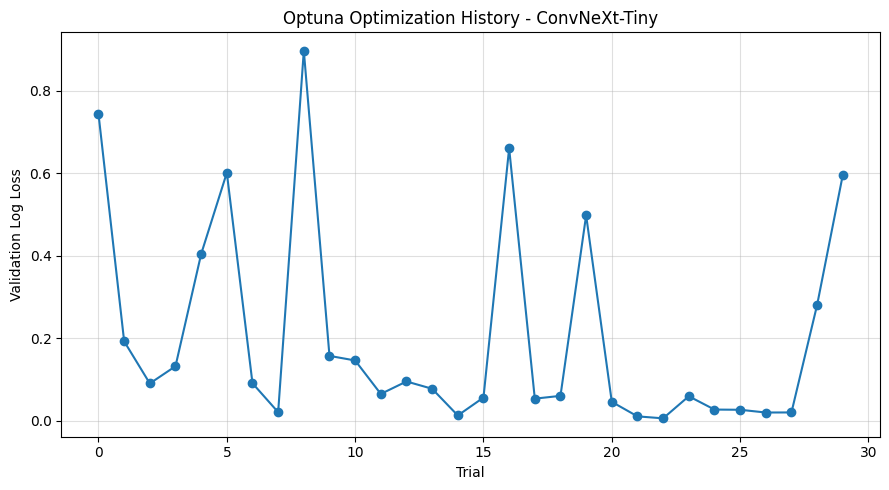


INICIANDO VALIDACIÓN CRUZADA - CONVNEXT-TINY
Cada fold utilizará exactamente 10 época(s) elegida(s) por HPO, sin EarlyStopping ni selección adicional de épocas.

FOLD 1/10
------------------------------------------------------------------------
Epoch 1/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 48s 614ms/step - accuracy: 0.9574 - auc: 0.9942 - loss: 0.1259 - pr_auc: 0.9942 - precision: 0.9533 - recall: 0.9623 - val_accuracy: 0.9574 - val_auc: 0.9982 - val_loss: 0.0814 - val_pr_auc: 0.9981 - val_precision: 0.9565 - val_recall: 0.9565
Epoch 2/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 20s 379ms/step - accuracy: 0.9953 - auc: 1.0000 - loss: 0.0263 - pr_auc: 1.0000 - precision: 1.0000 - recall: 0.9906 - val_accuracy: 0.9787 - val_auc: 1.0000 - val_loss: 0.0495 - val_pr_auc: 1.0000 - val_precision: 0.9583 - val_recall: 1.0000
Epoch 3/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 22s 411ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 0.0159 - pr_auc: 1.0000 - precision: 1.0000 - recall: 1.0000 - val_accuracy: 1.0000 - val_auc: 1.0

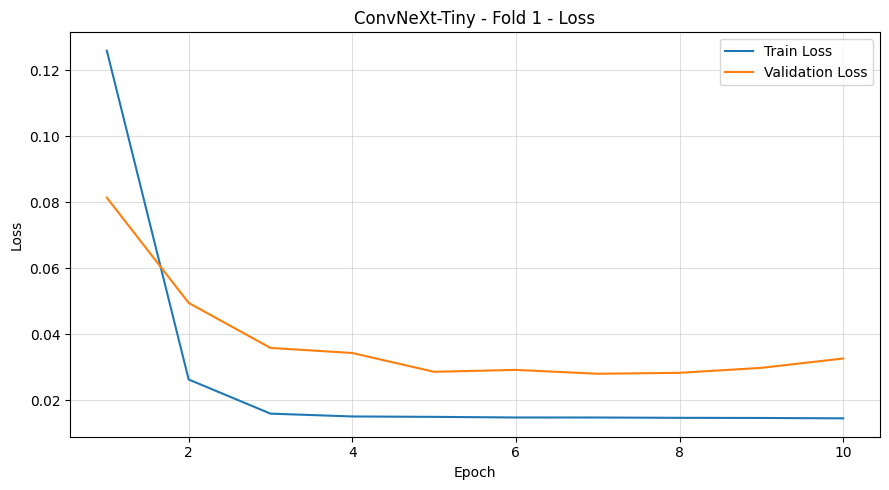

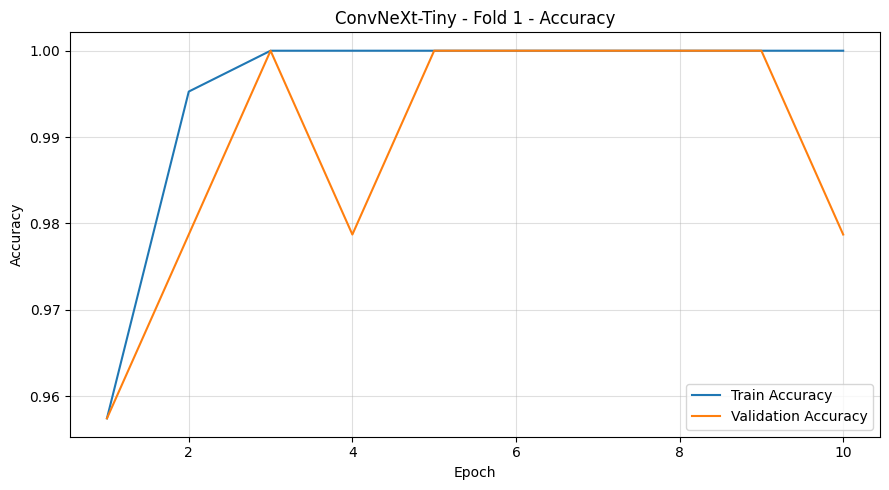

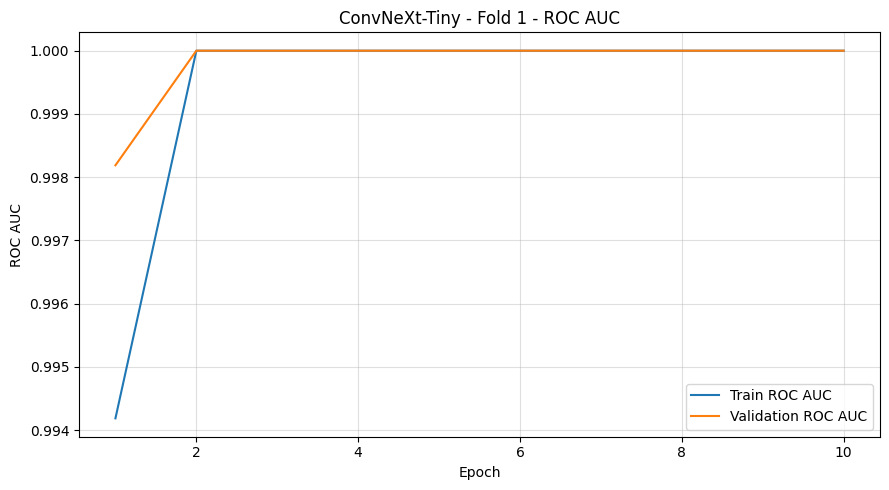

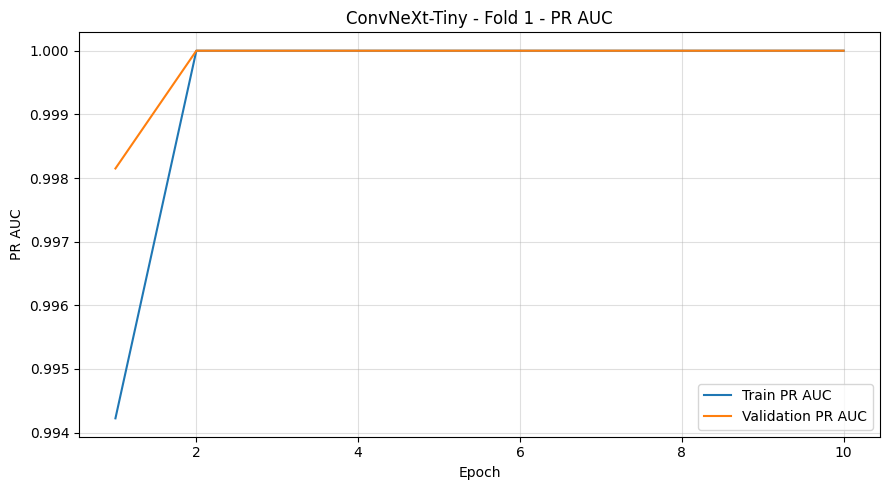

6/6 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step

Fold 01 | Acc: 0.9787 | Bal Acc: 0.9792 | F1: 0.9787 | ROC AUC: 1.0000 | PR AUC: 1.0000 | Log loss: 0.01821193 | Brier: 0.00673289 | ECE: 0.01259379


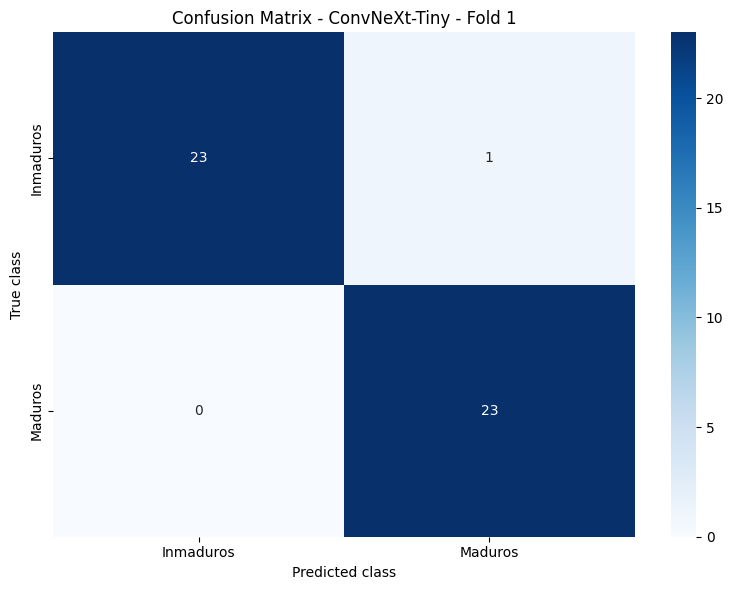

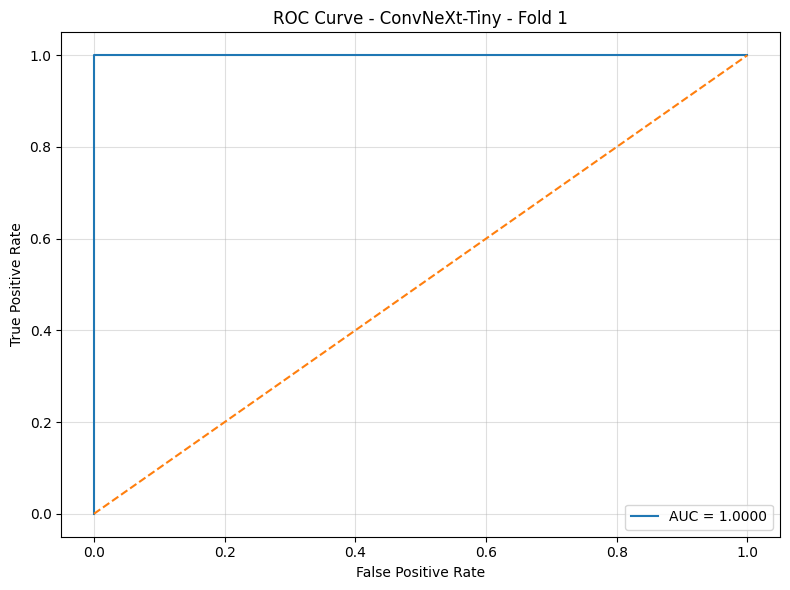

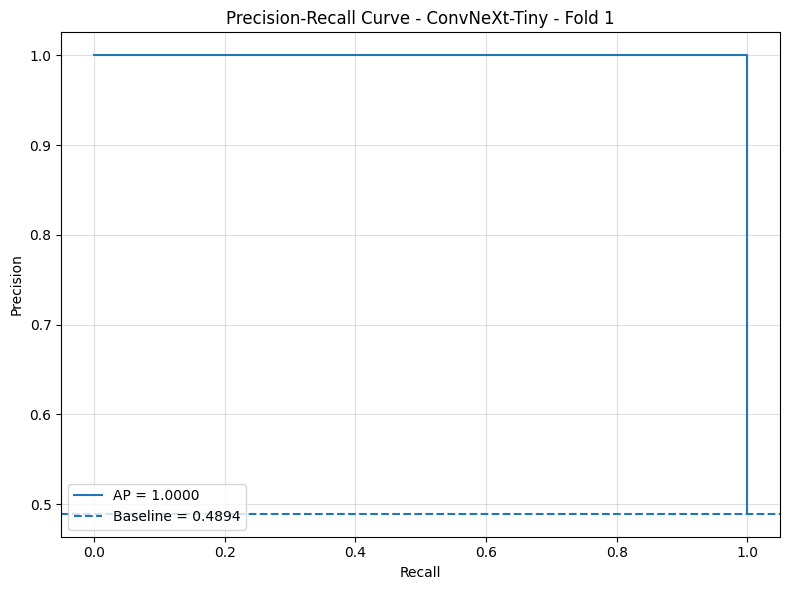

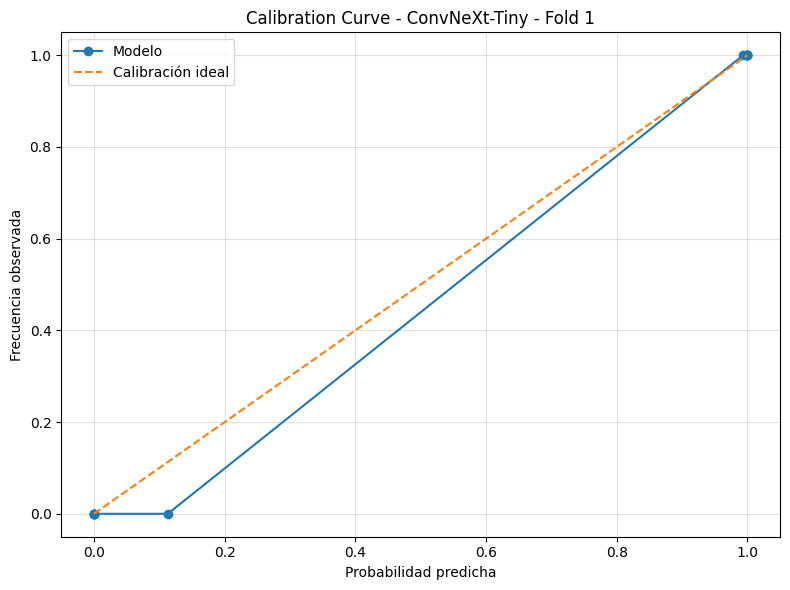

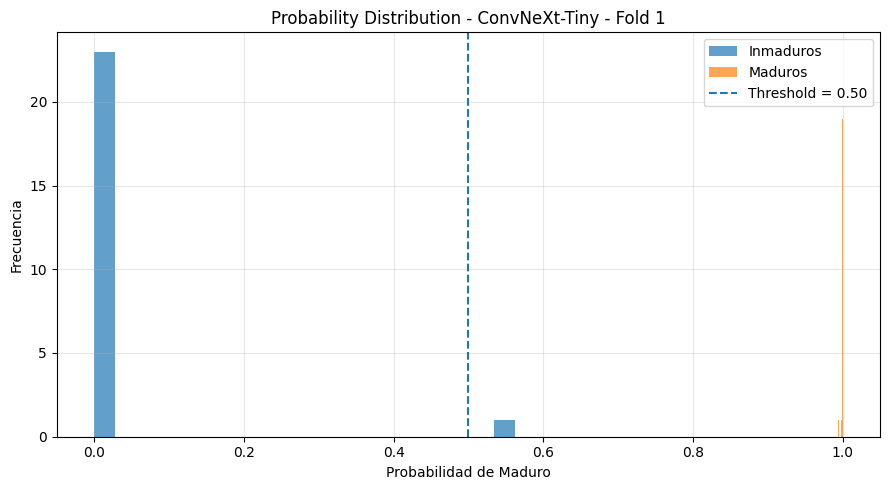

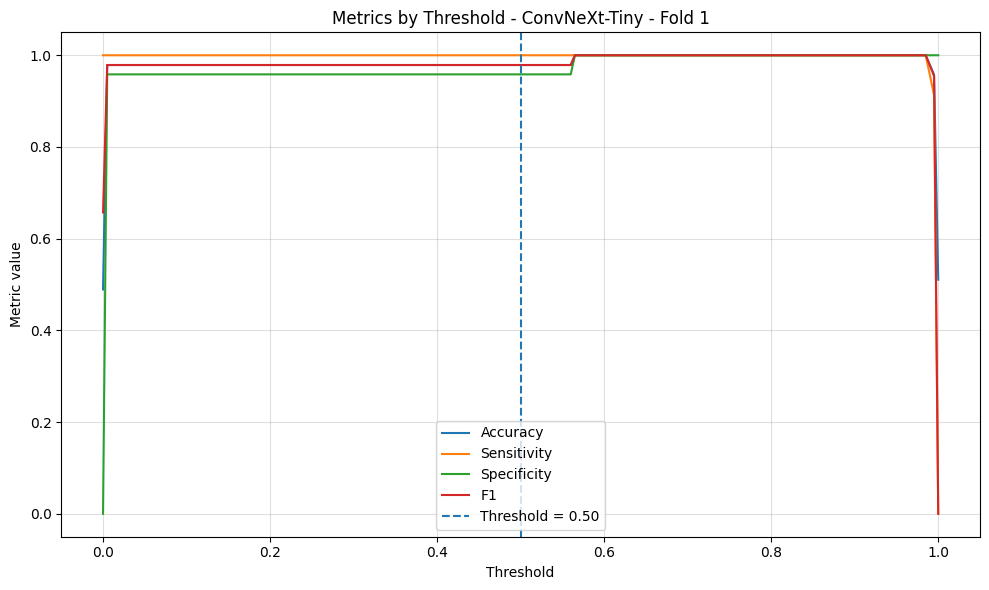


FOLD 2/10
------------------------------------------------------------------------
Epoch 1/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 44s 567ms/step - accuracy: 0.9551 - auc: 0.9930 - loss: 0.1405 - pr_auc: 0.9934 - precision: 0.9707 - recall: 0.9387 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0531 - val_pr_auc: 1.0000 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 2/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 19s 358ms/step - accuracy: 0.9976 - auc: 1.0000 - loss: 0.0259 - pr_auc: 1.0000 - precision: 1.0000 - recall: 0.9953 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0272 - val_pr_auc: 1.0000 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 3/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 19s 366ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 0.0158 - pr_auc: 1.0000 - precision: 1.0000 - recall: 1.0000 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0223 - val_pr_auc: 1.0000 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 4/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 20s 382ms/step - accuracy: 1.0000 -

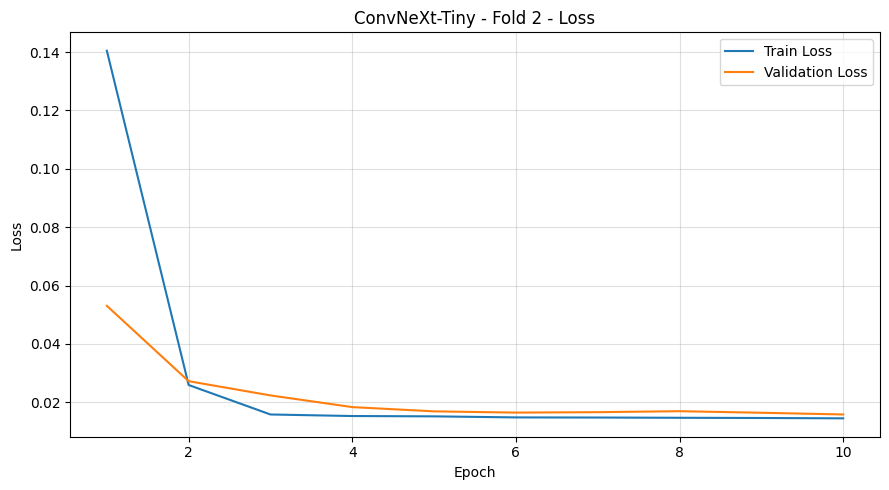

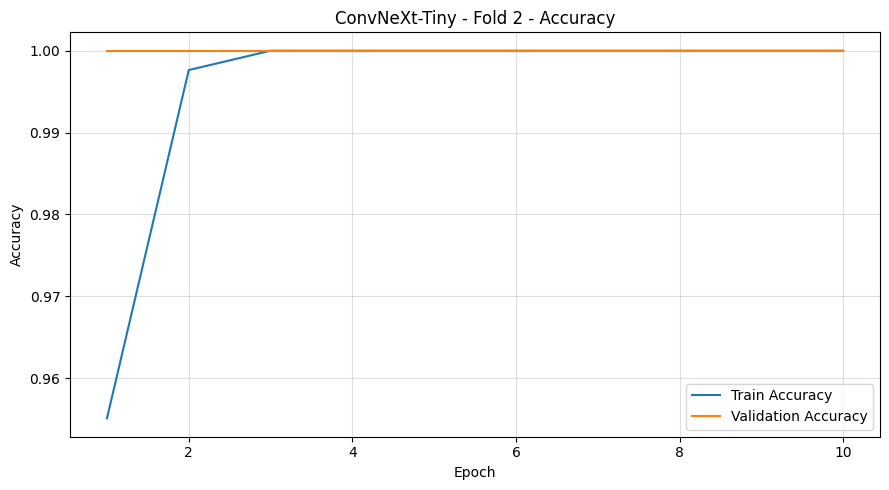

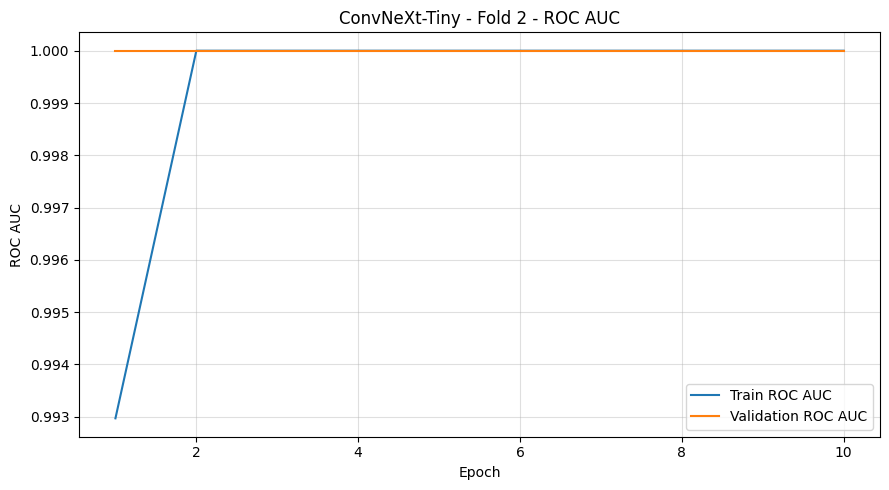

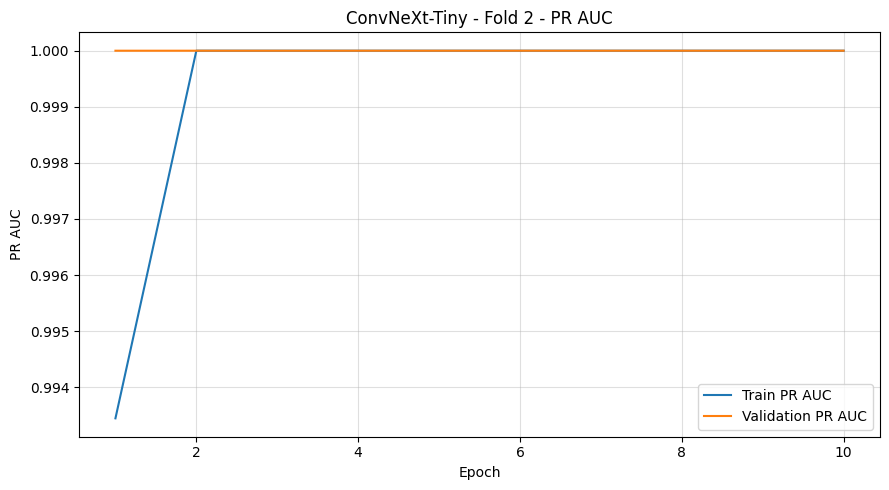

6/6 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step

Fold 02 | Acc: 1.0000 | Bal Acc: 1.0000 | F1: 1.0000 | ROC AUC: 1.0000 | PR AUC: 1.0000 | Log loss: 0.00139506 | Brier: 0.00004342 | ECE: 0.00137279


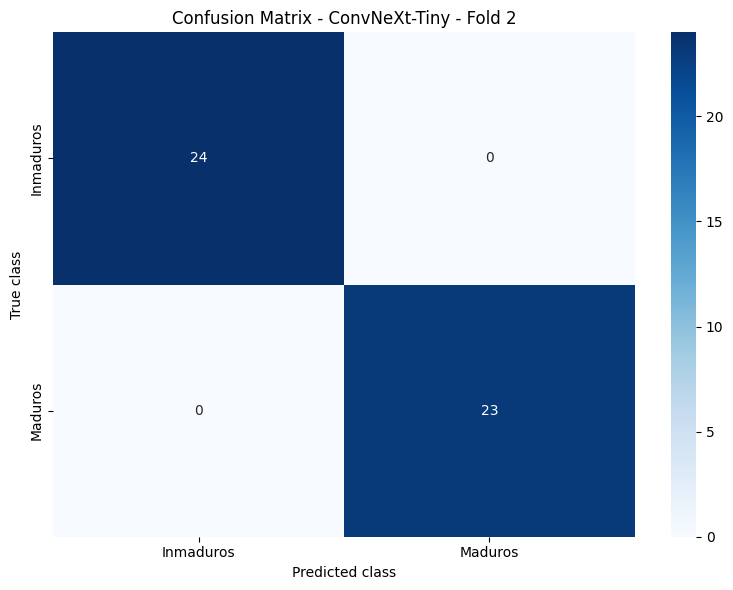

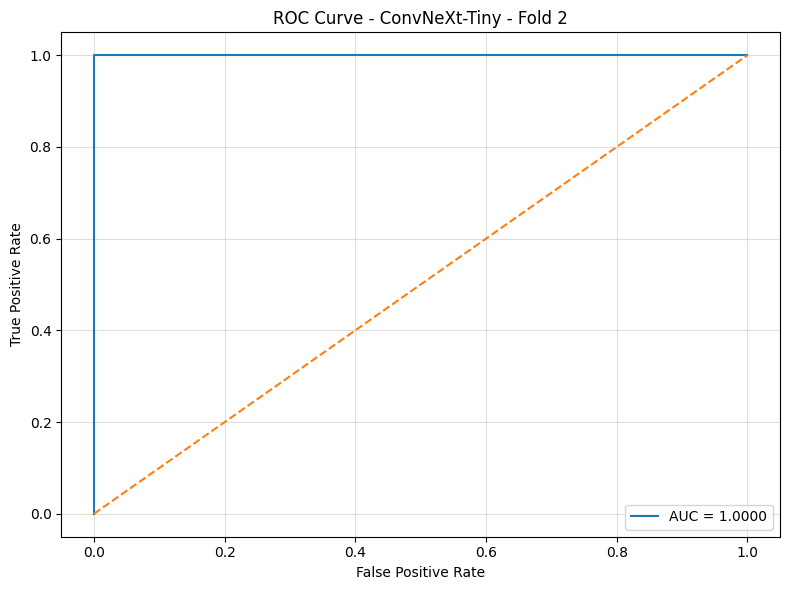

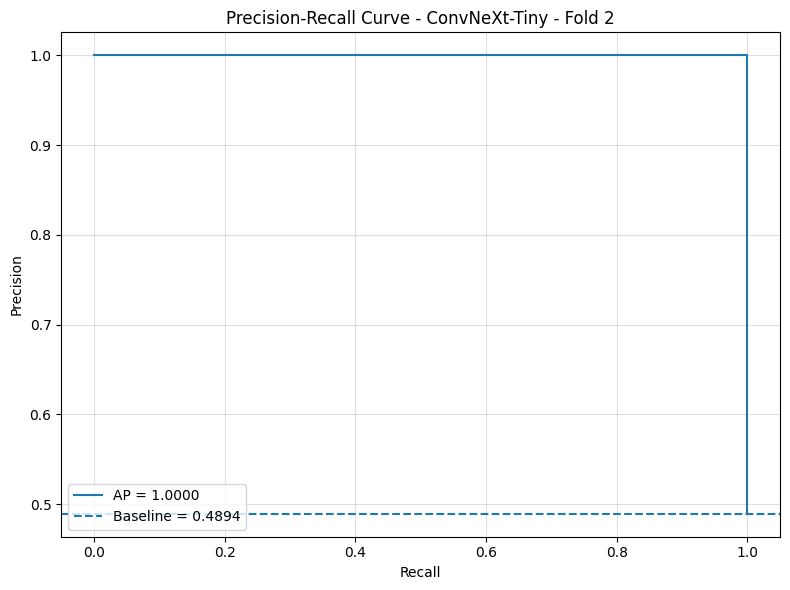

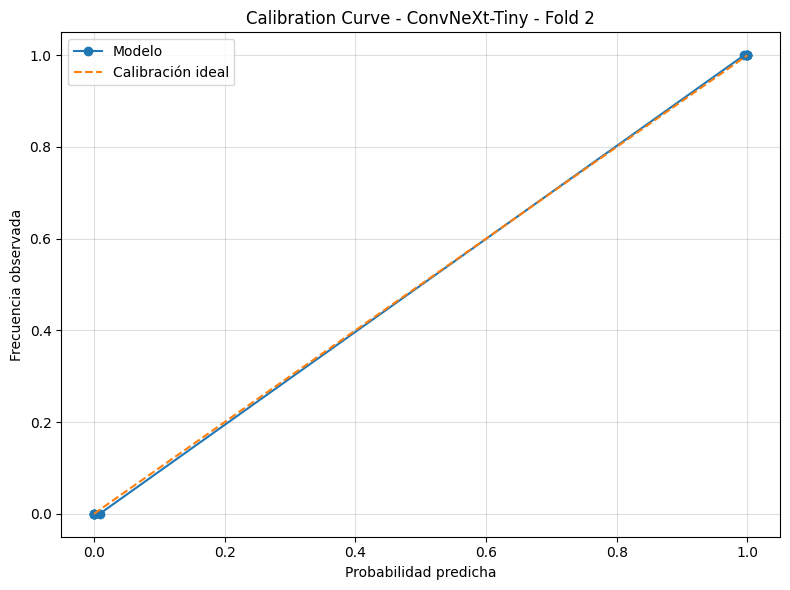

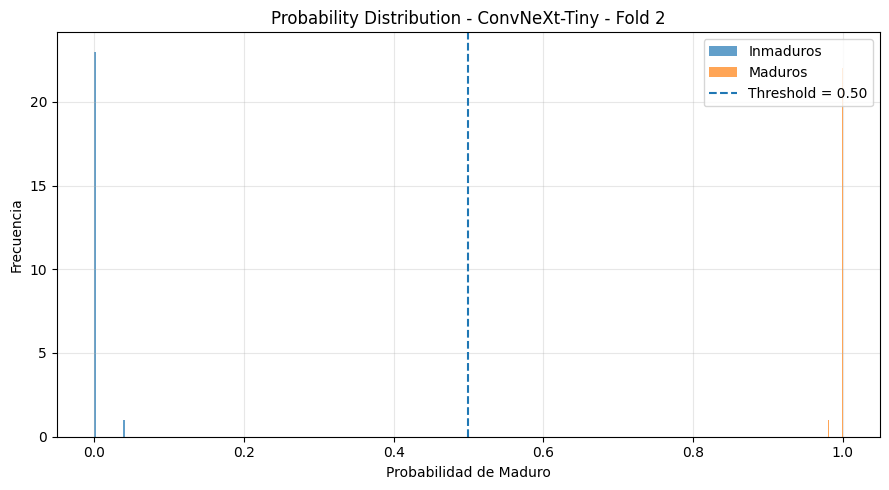

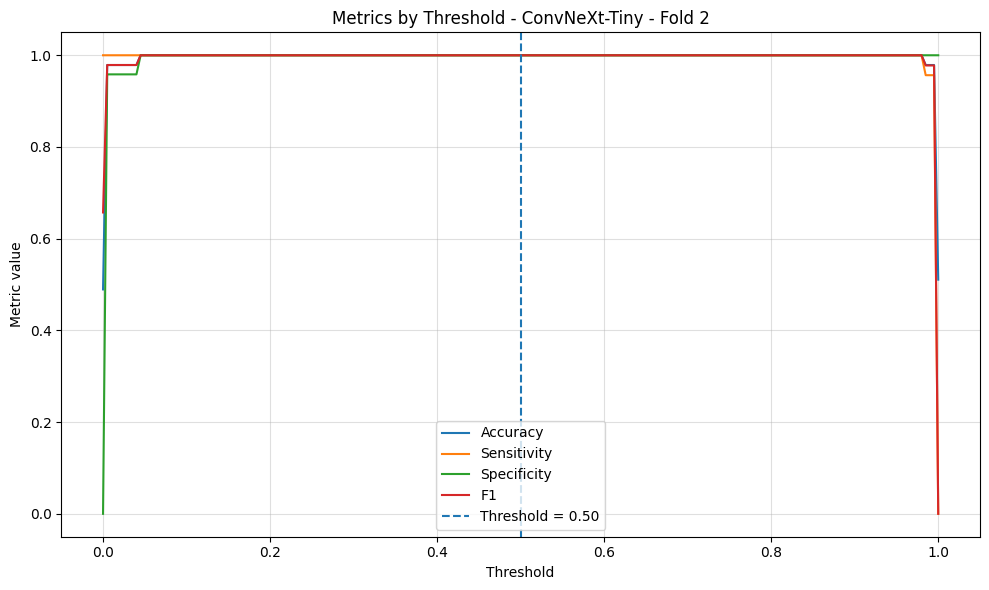


FOLD 3/10
------------------------------------------------------------------------
Epoch 1/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 46s 589ms/step - accuracy: 0.9362 - auc: 0.9800 - loss: 0.1976 - pr_auc: 0.9835 - precision: 0.9648 - recall: 0.9057 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0329 - val_pr_auc: 1.0000 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 2/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 19s 363ms/step - accuracy: 0.9953 - auc: 1.0000 - loss: 0.0245 - pr_auc: 1.0000 - precision: 0.9953 - recall: 0.9953 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0177 - val_pr_auc: 1.0000 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 3/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 20s 374ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 0.0168 - pr_auc: 1.0000 - precision: 1.0000 - recall: 1.0000 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0160 - val_pr_auc: 1.0000 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 4/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 20s 376ms/step - accuracy: 1.0000 -

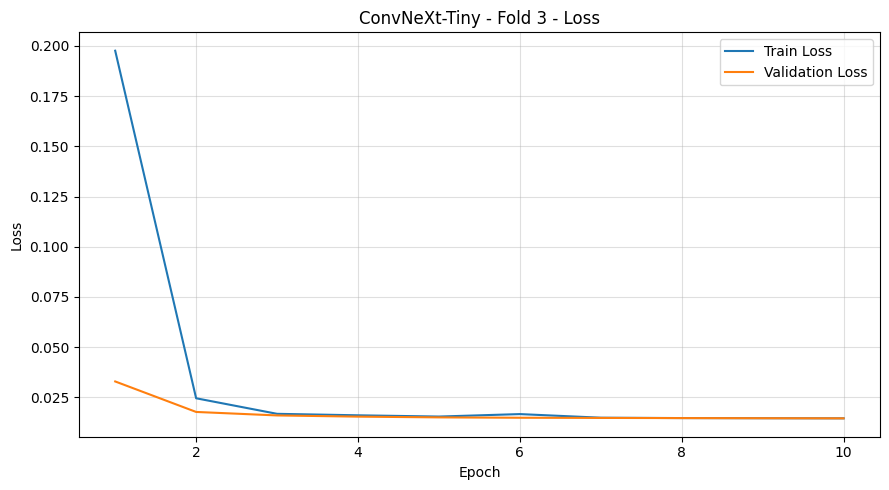

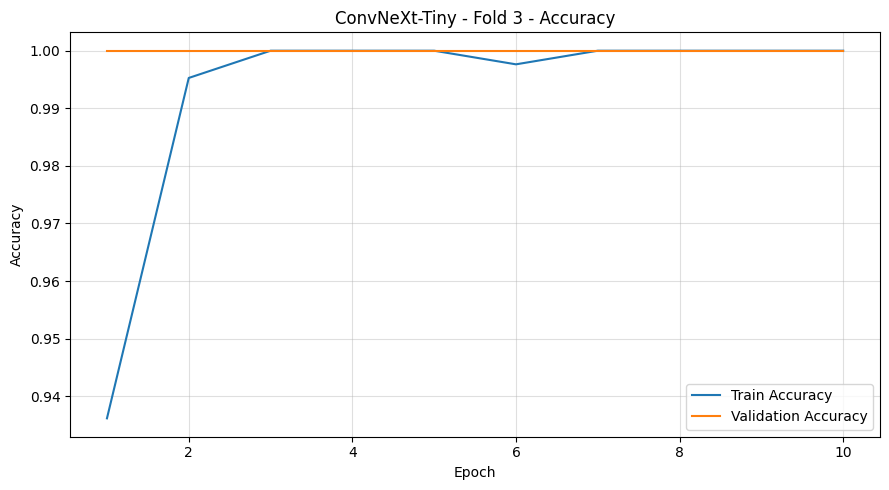

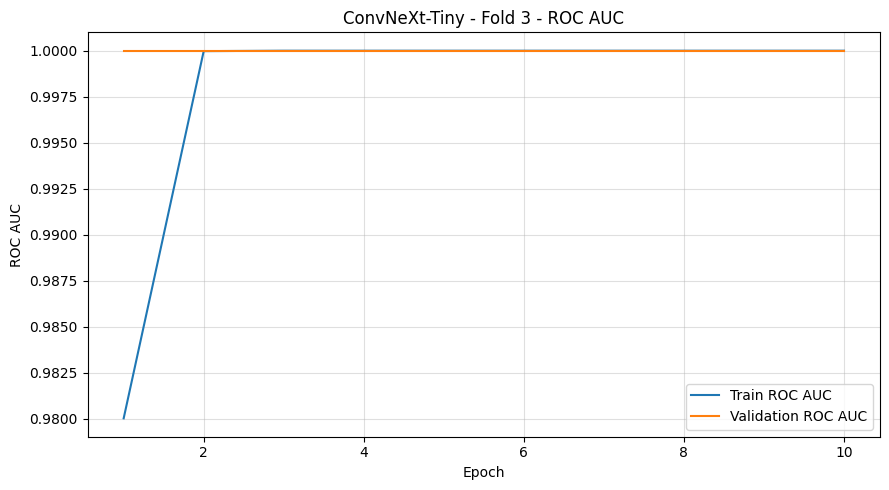

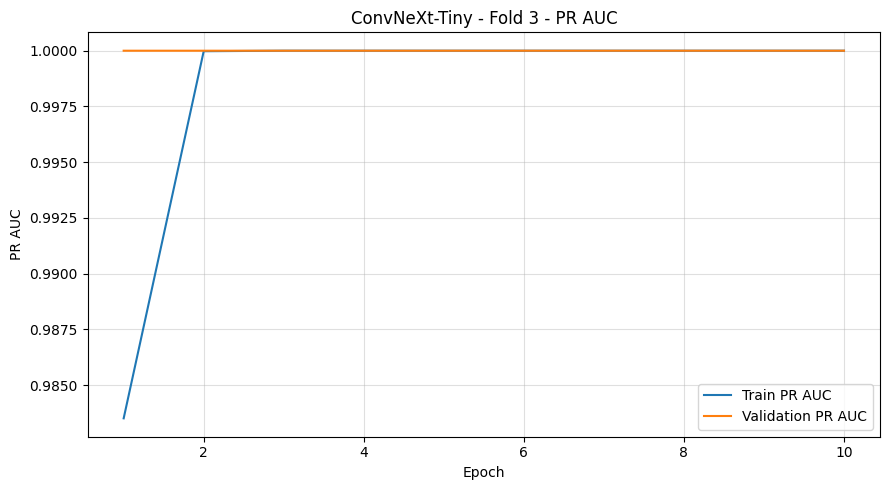

6/6 ━━━━━━━━━━━━━━━━━━━━ 8s 894ms/step

Fold 03 | Acc: 1.0000 | Bal Acc: 1.0000 | F1: 1.0000 | ROC AUC: 1.0000 | PR AUC: 1.0000 | Log loss: 0.00006543 | Brier: 0.00000003 | ECE: 0.00006542


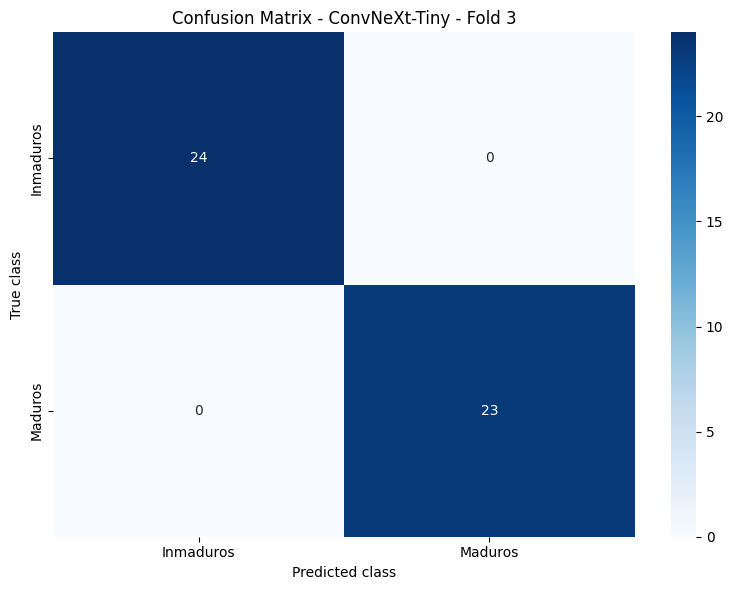

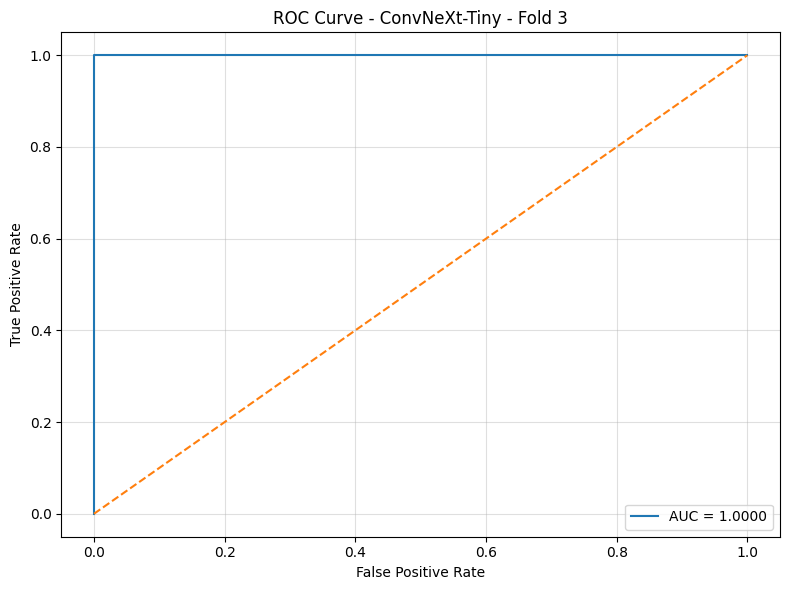

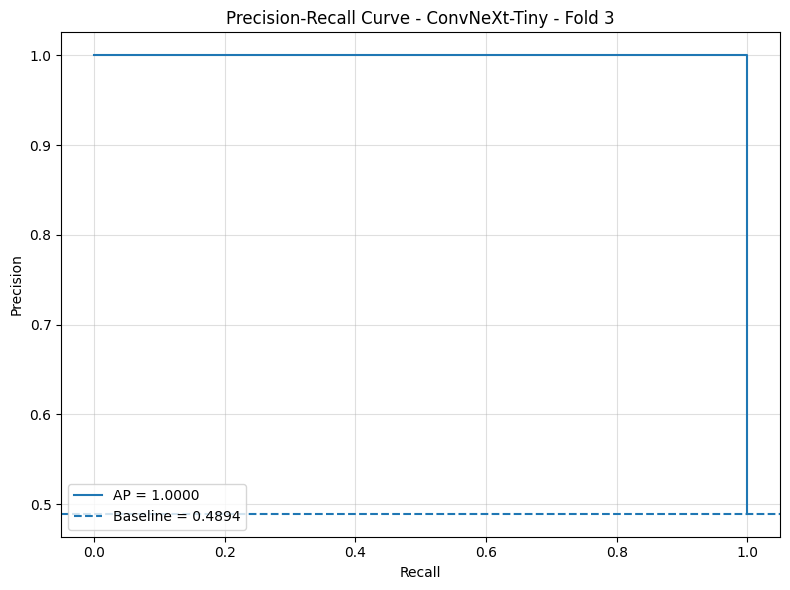

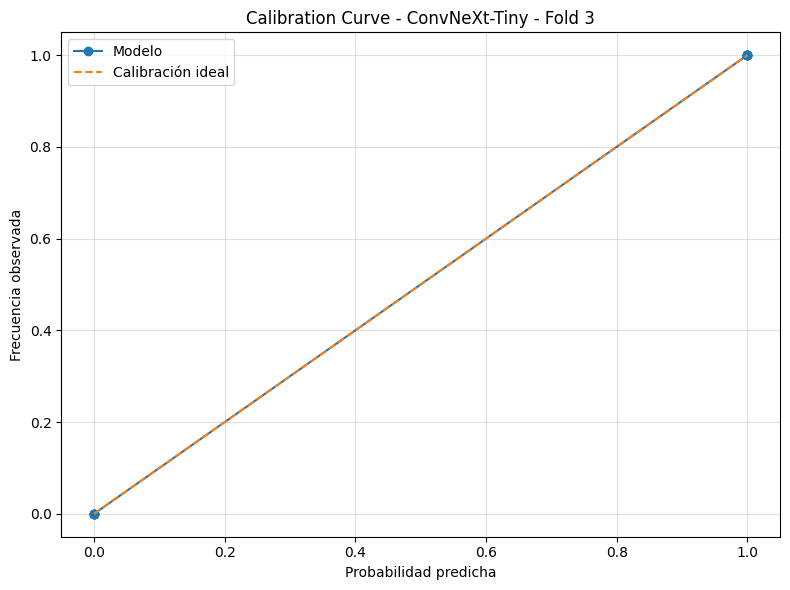

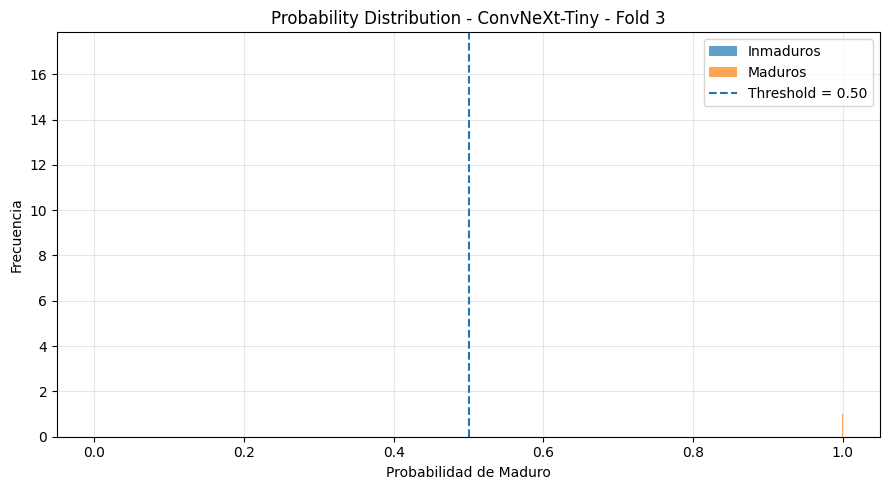

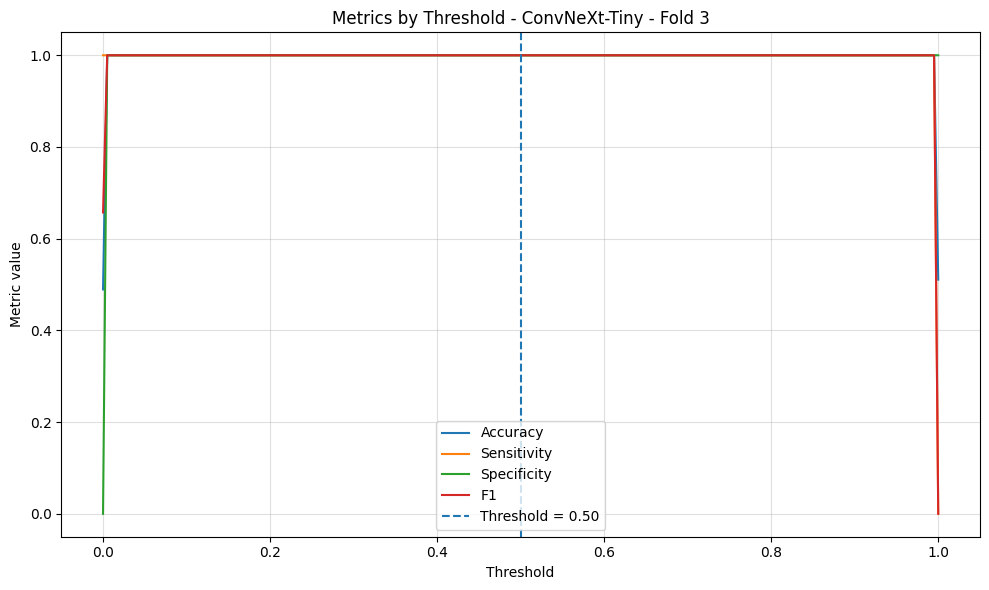


FOLD 4/10
------------------------------------------------------------------------
Epoch 1/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 45s 582ms/step - accuracy: 0.9433 - auc: 0.9917 - loss: 0.1494 - pr_auc: 0.9922 - precision: 0.9653 - recall: 0.9198 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0322 - val_pr_auc: 1.0000 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 2/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 20s 380ms/step - accuracy: 0.9976 - auc: 1.0000 - loss: 0.0248 - pr_auc: 1.0000 - precision: 1.0000 - recall: 0.9953 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0199 - val_pr_auc: 1.0000 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 3/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 20s 371ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 0.0182 - pr_auc: 1.0000 - precision: 1.0000 - recall: 1.0000 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0169 - val_pr_auc: 1.0000 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 4/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 21s 389ms/step - accuracy: 1.0000 -

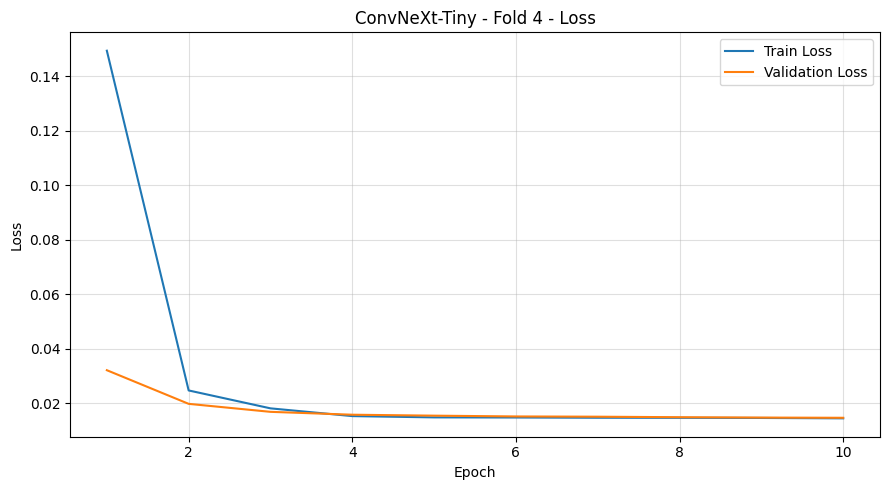

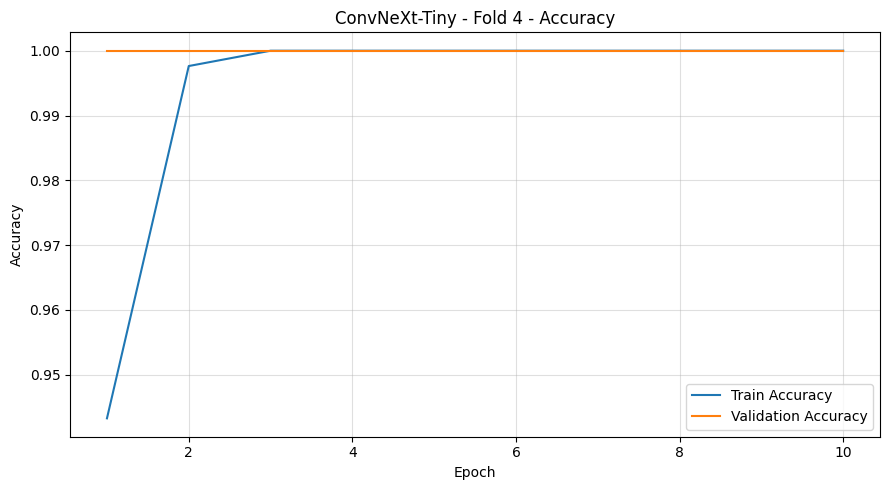

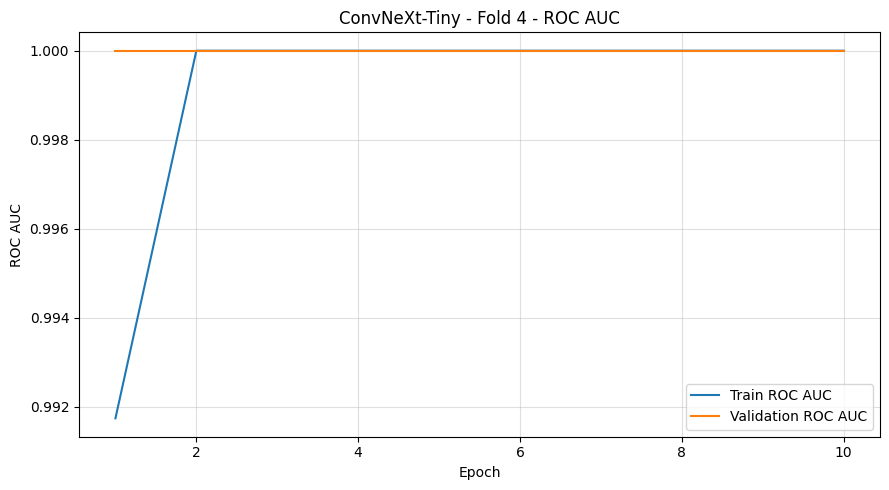

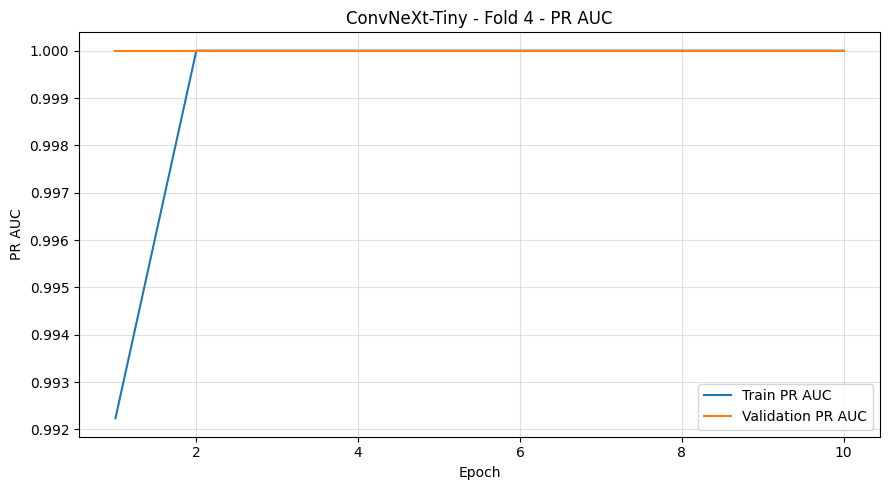

6/6 ━━━━━━━━━━━━━━━━━━━━ 8s 944ms/step

Fold 04 | Acc: 1.0000 | Bal Acc: 1.0000 | F1: 1.0000 | ROC AUC: 1.0000 | PR AUC: 1.0000 | Log loss: 0.00027786 | Brier: 0.00000110 | ECE: 0.00027731


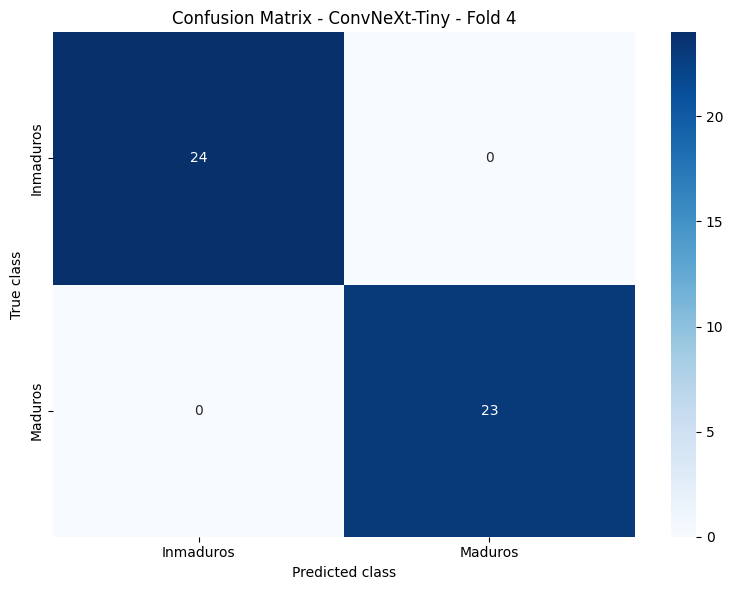

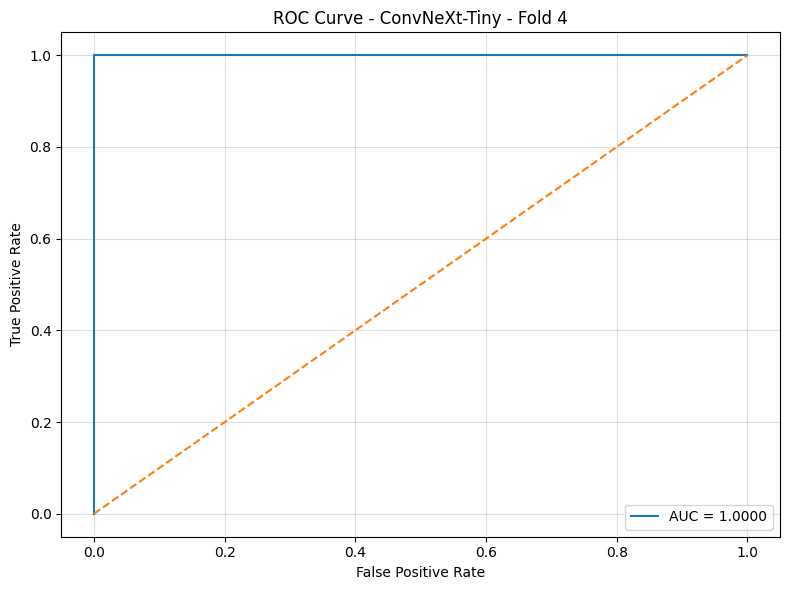

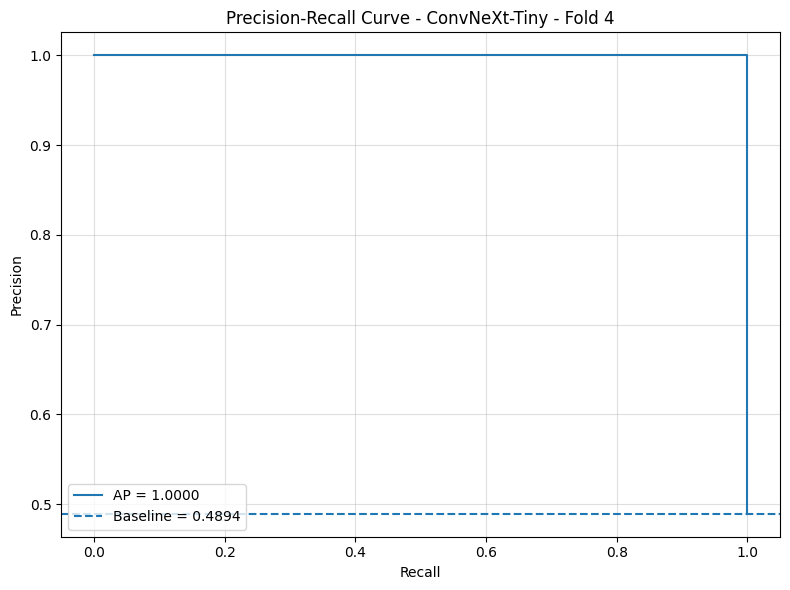

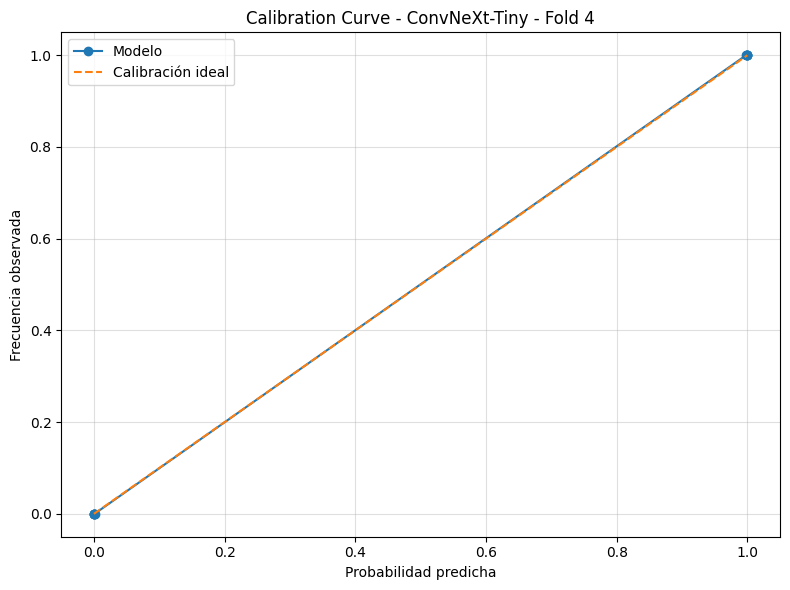

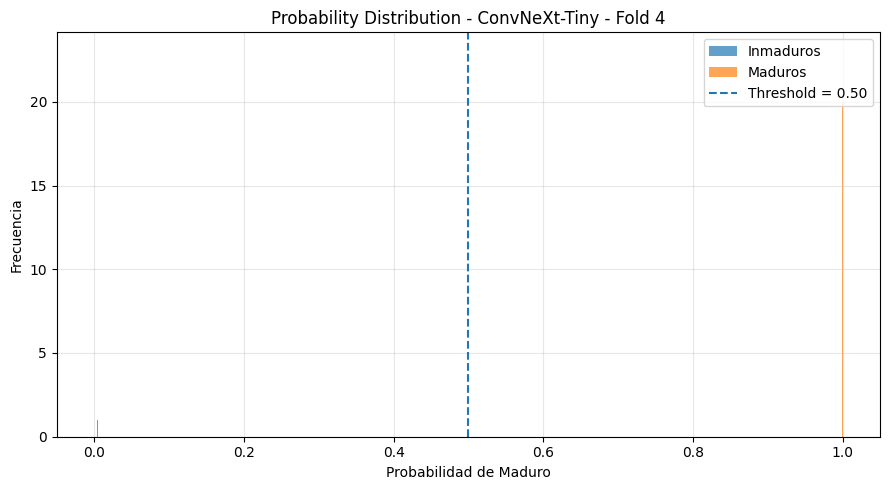

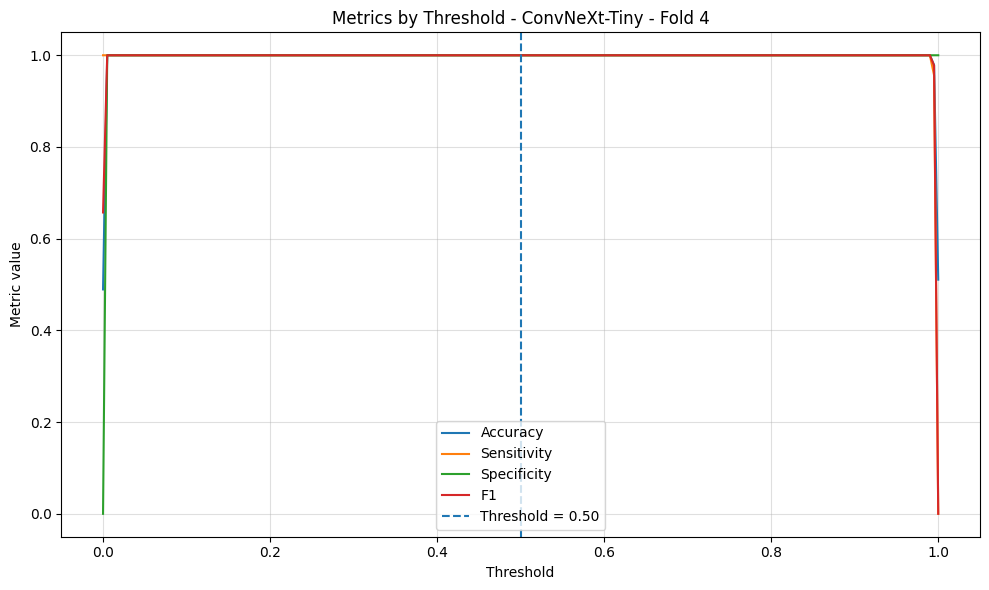


FOLD 5/10
------------------------------------------------------------------------
Epoch 1/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 48s 629ms/step - accuracy: 0.9574 - auc: 0.9937 - loss: 0.1267 - pr_auc: 0.9945 - precision: 0.9755 - recall: 0.9387 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0557 - val_pr_auc: 1.0000 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 2/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 21s 397ms/step - accuracy: 0.9976 - auc: 1.0000 - loss: 0.0214 - pr_auc: 1.0000 - precision: 1.0000 - recall: 0.9953 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0256 - val_pr_auc: 1.0000 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 3/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 23s 426ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 0.0170 - pr_auc: 1.0000 - precision: 1.0000 - recall: 1.0000 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0205 - val_pr_auc: 1.0000 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 4/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 21s 388ms/step - accuracy: 1.0000 -

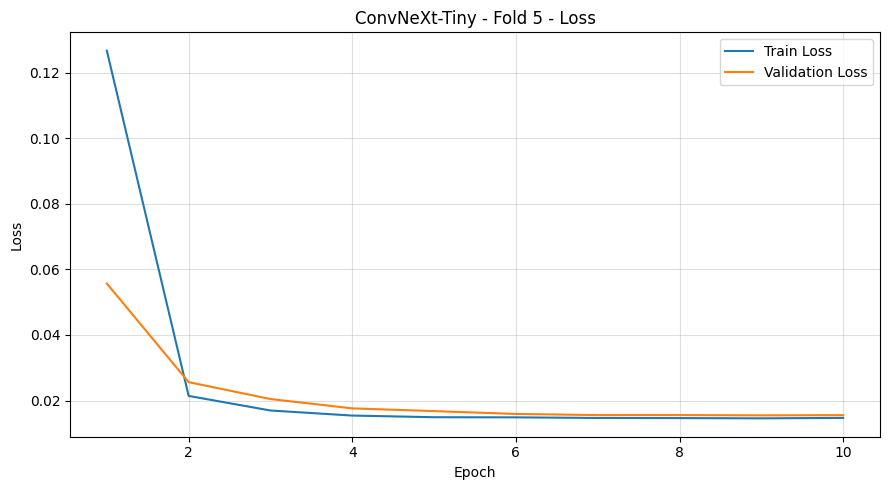

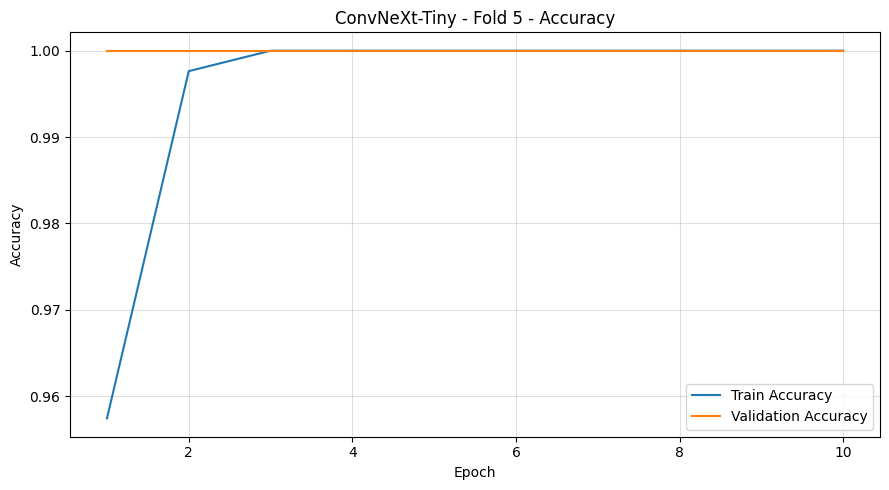

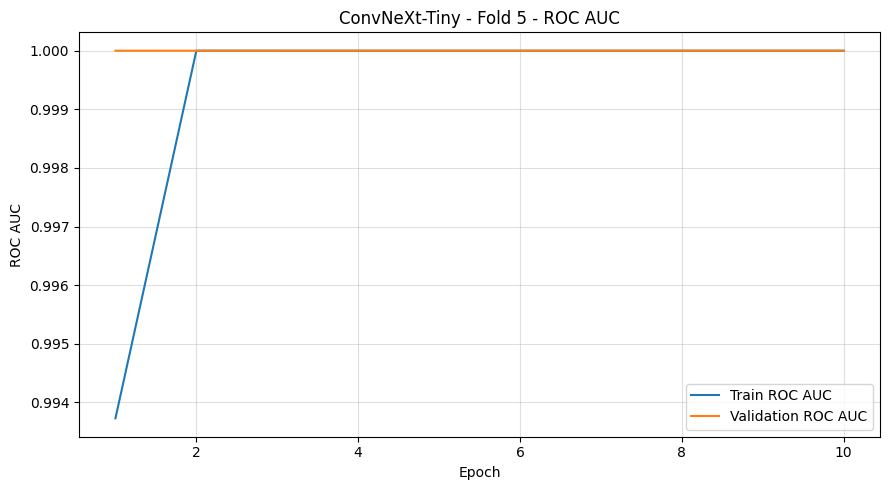

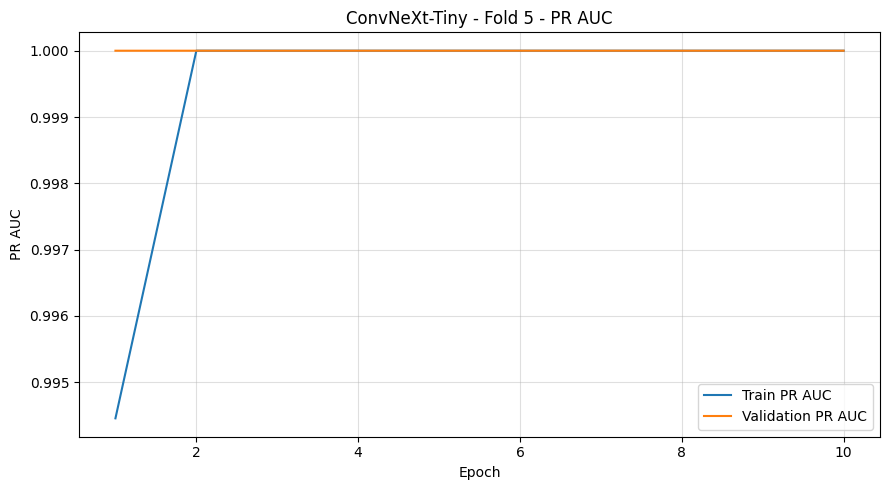

6/6 ━━━━━━━━━━━━━━━━━━━━ 11s 1s/step

Fold 05 | Acc: 1.0000 | Bal Acc: 1.0000 | F1: 1.0000 | ROC AUC: 1.0000 | PR AUC: 1.0000 | Log loss: 0.00110527 | Brier: 0.00002302 | ECE: 0.00109355


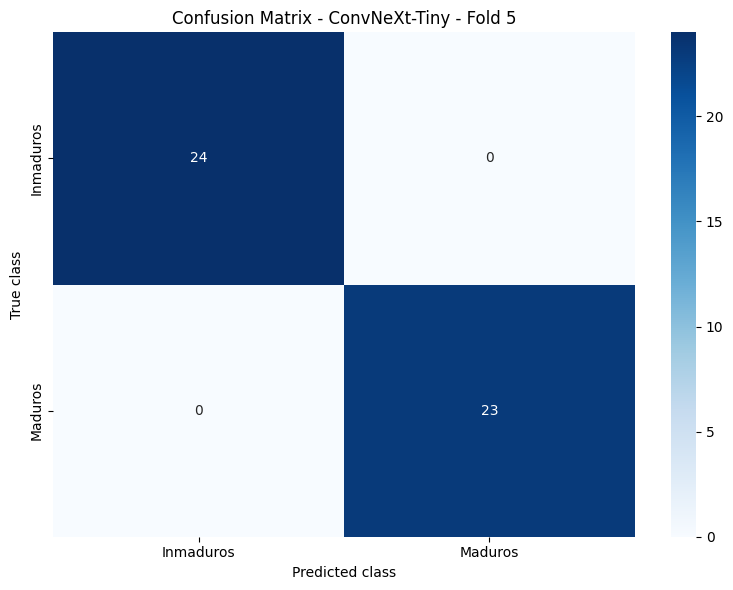

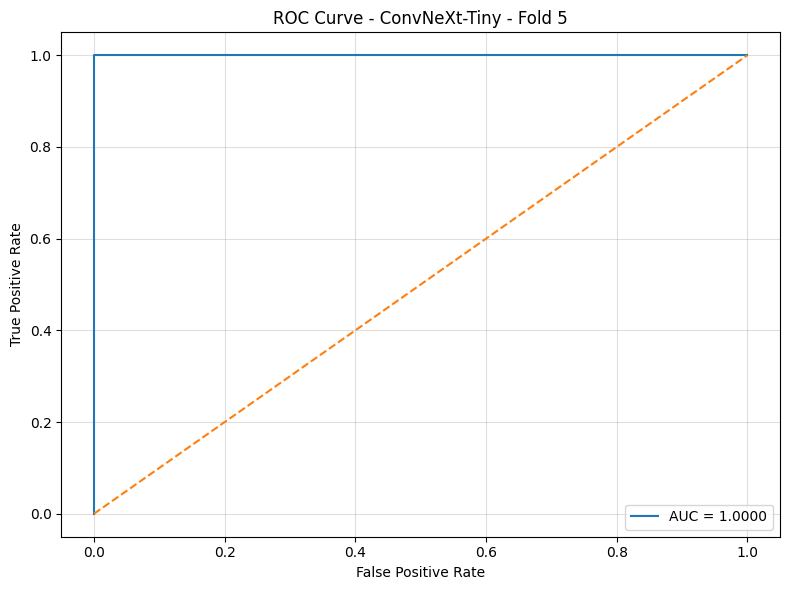

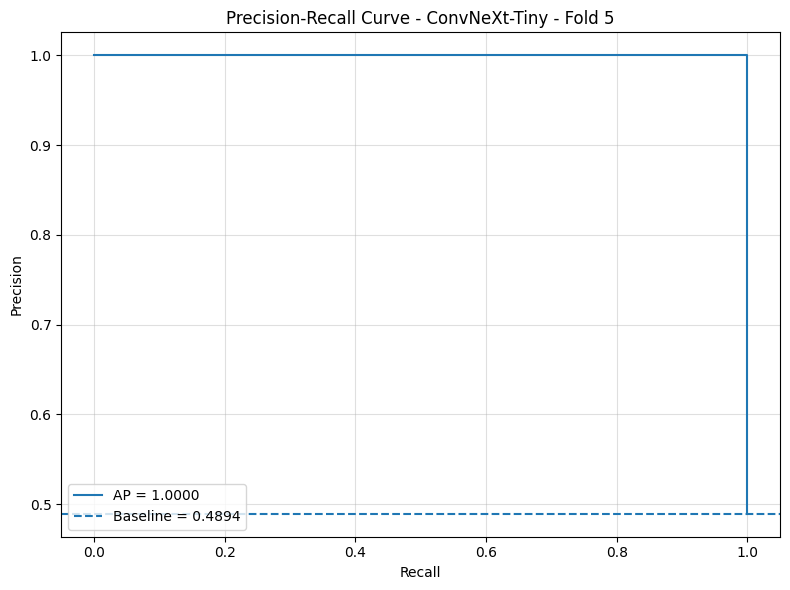

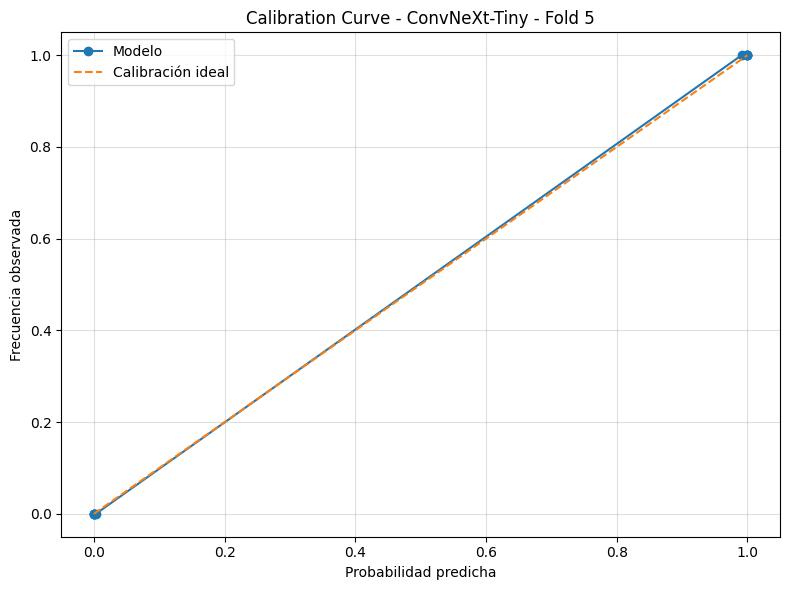

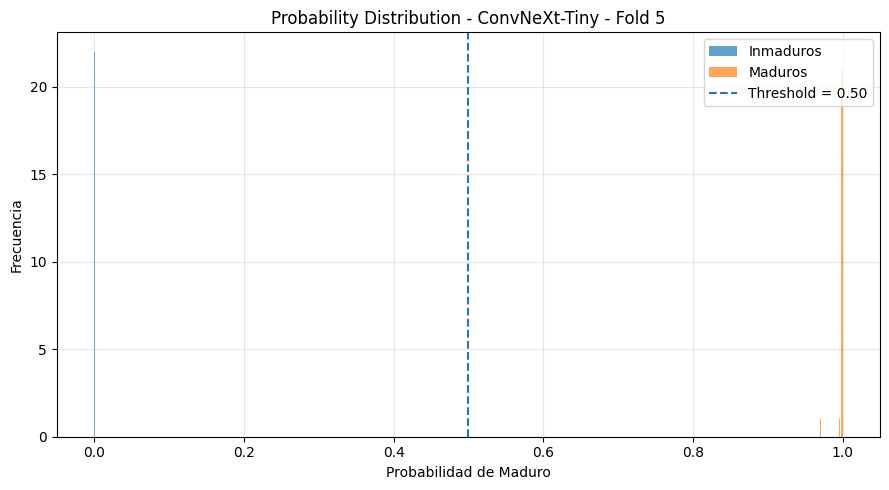

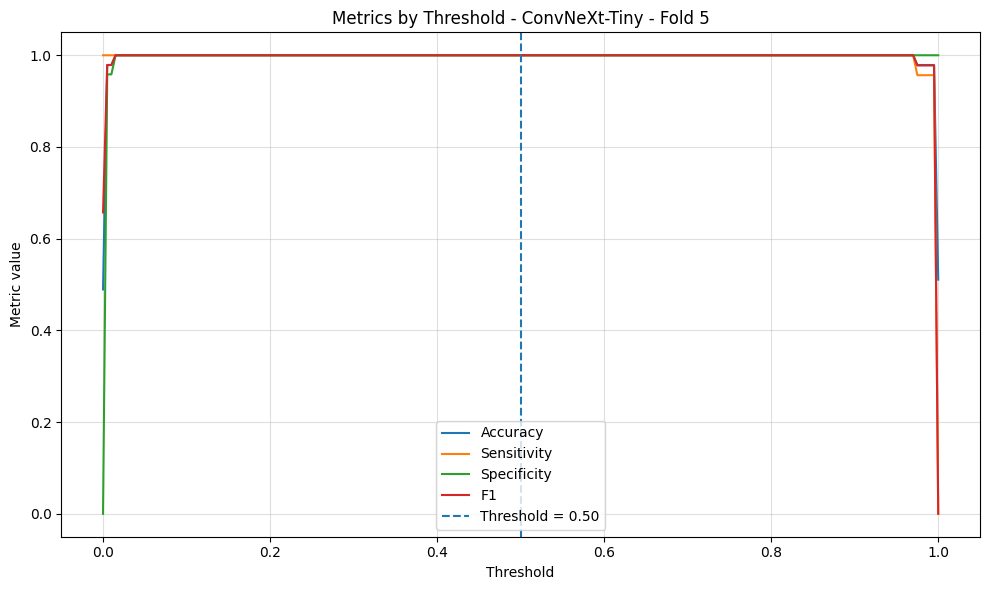


FOLD 6/10
------------------------------------------------------------------------
Epoch 1/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 48s 611ms/step - accuracy: 0.9480 - auc: 0.9922 - loss: 0.1341 - pr_auc: 0.9920 - precision: 0.9437 - recall: 0.9526 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0440 - val_pr_auc: 1.0000 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 2/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 22s 414ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 0.0230 - pr_auc: 1.0000 - precision: 1.0000 - recall: 1.0000 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0216 - val_pr_auc: 1.0000 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 3/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 20s 381ms/step - accuracy: 0.9976 - auc: 1.0000 - loss: 0.0178 - pr_auc: 1.0000 - precision: 1.0000 - recall: 0.9953 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0175 - val_pr_auc: 1.0000 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 4/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 21s 390ms/step - accuracy: 1.0000 -

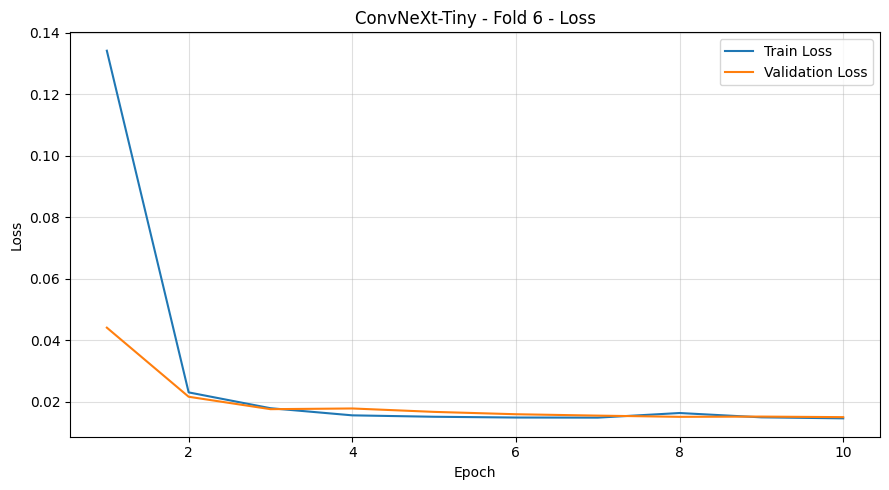

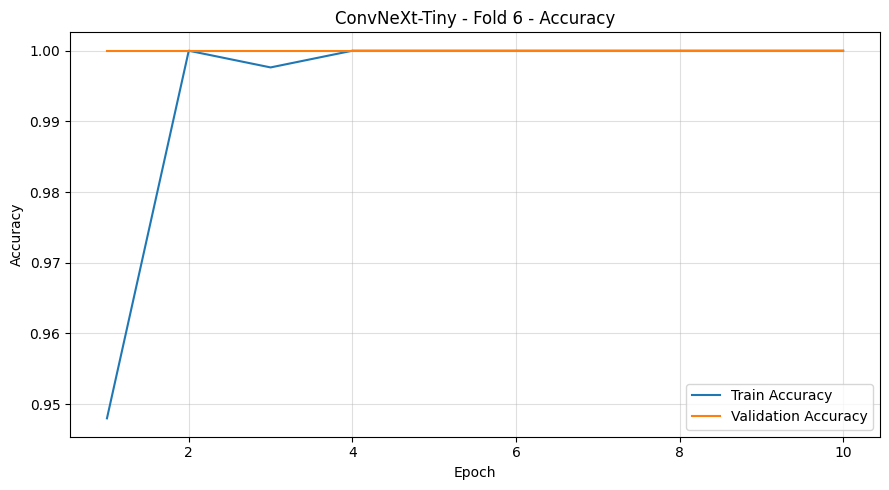

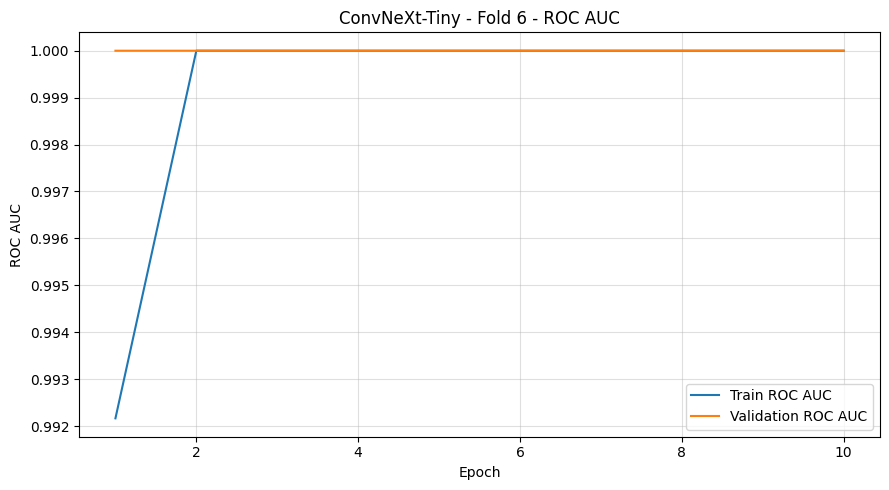

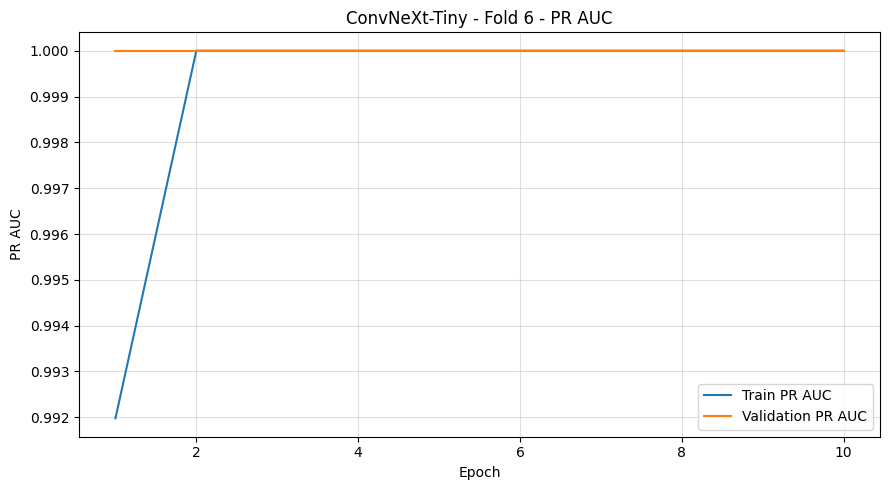

6/6 ━━━━━━━━━━━━━━━━━━━━ 9s 932ms/step

Fold 06 | Acc: 1.0000 | Bal Acc: 1.0000 | F1: 1.0000 | ROC AUC: 1.0000 | PR AUC: 1.0000 | Log loss: 0.00044285 | Brier: 0.00000269 | ECE: 0.00044149


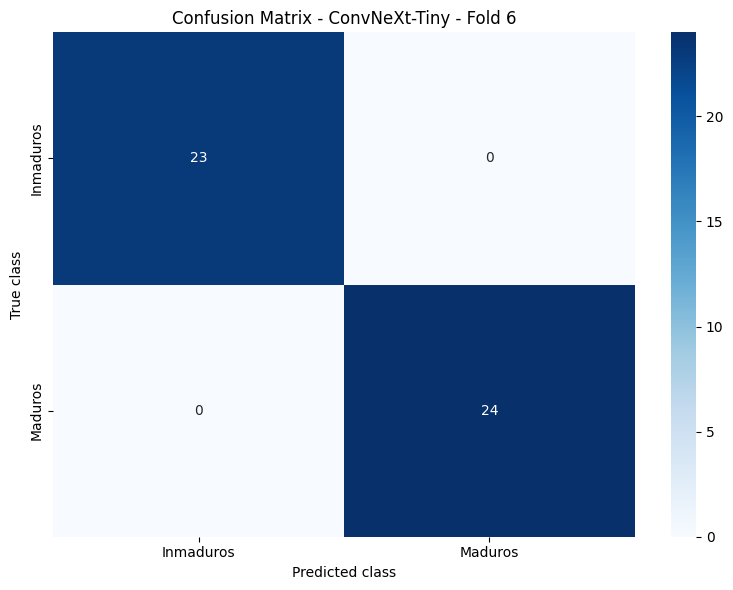

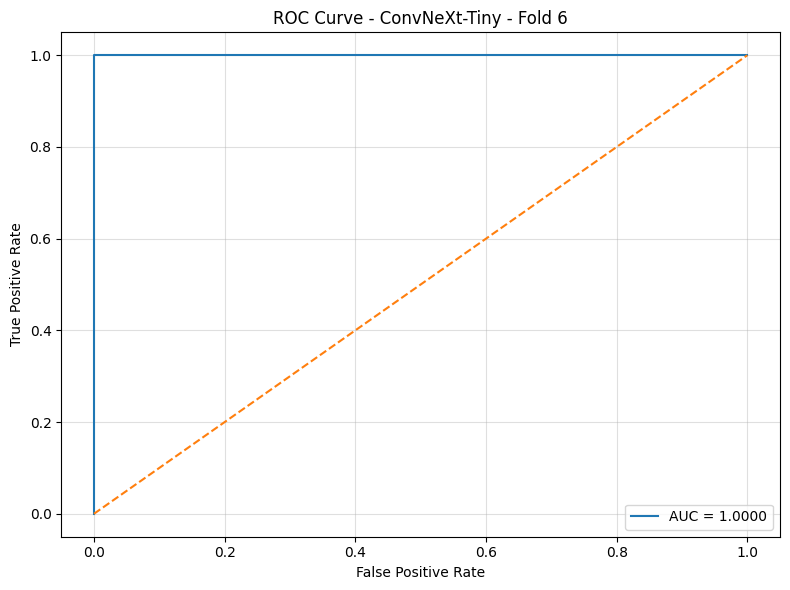

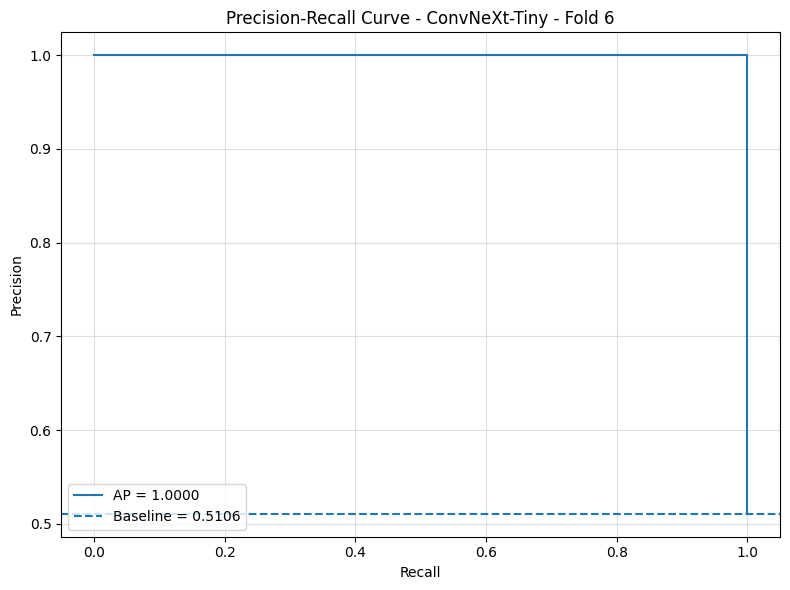

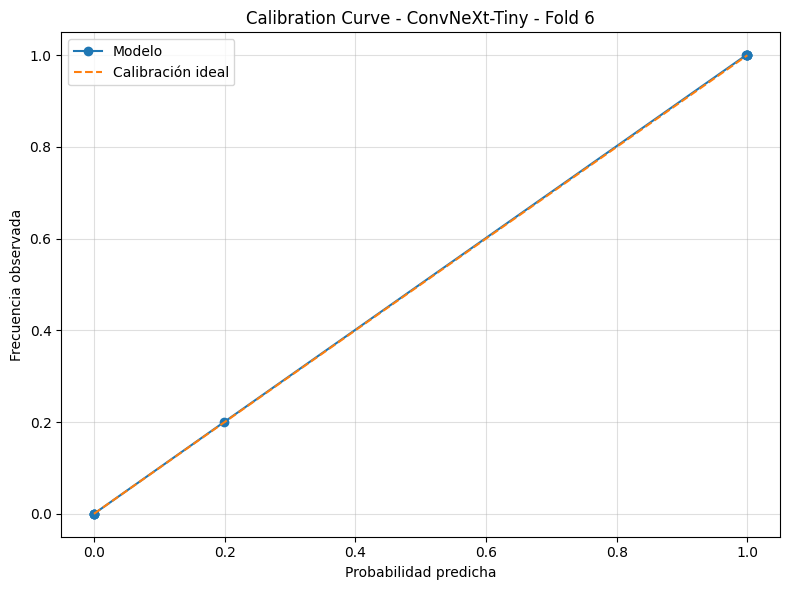

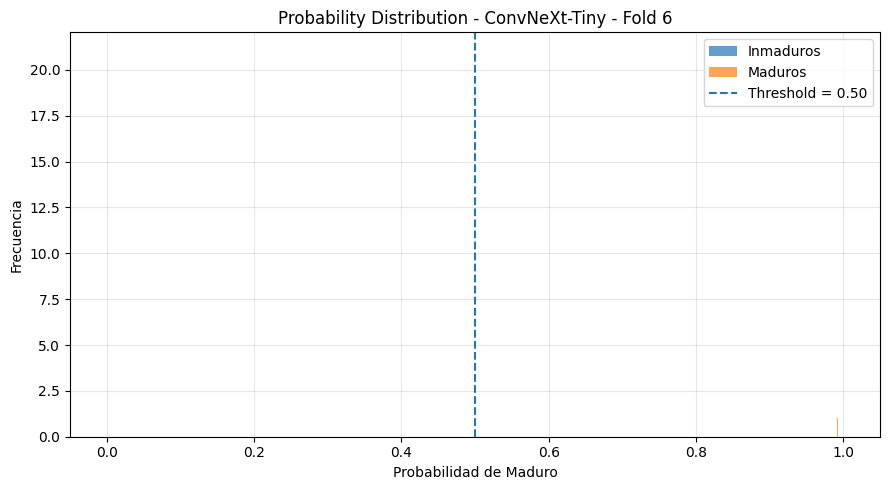

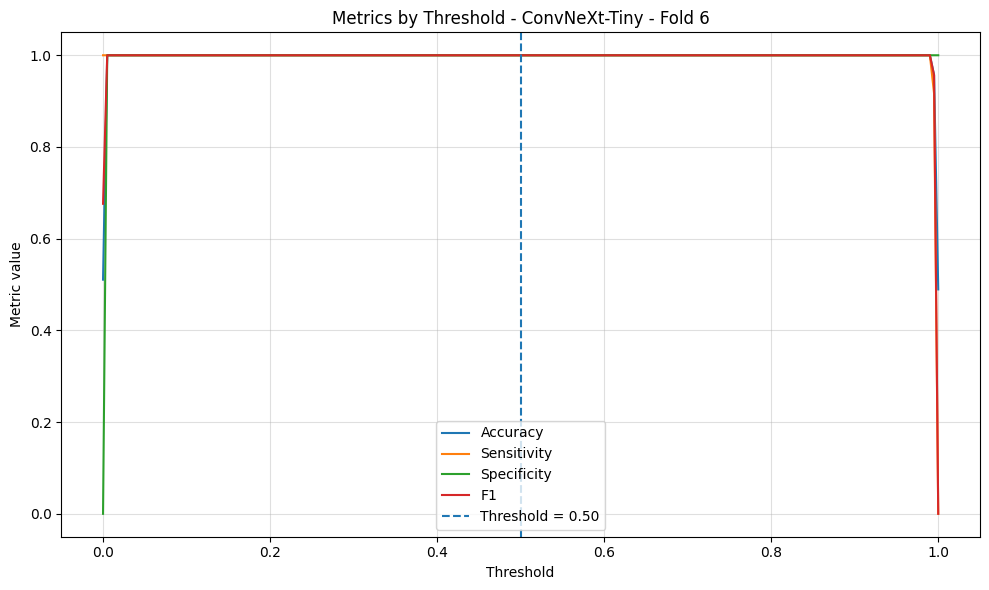


FOLD 7/10
------------------------------------------------------------------------
Epoch 1/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 47s 615ms/step - accuracy: 0.9527 - auc: 0.9948 - loss: 0.1166 - pr_auc: 0.9951 - precision: 0.9569 - recall: 0.9479 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0299 - val_pr_auc: 1.0000 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 2/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 20s 384ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 0.0190 - pr_auc: 1.0000 - precision: 1.0000 - recall: 1.0000 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0171 - val_pr_auc: 1.0000 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 3/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 22s 419ms/step - accuracy: 0.9976 - auc: 1.0000 - loss: 0.0222 - pr_auc: 1.0000 - precision: 1.0000 - recall: 0.9953 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0162 - val_pr_auc: 1.0000 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 4/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 21s 388ms/step - accuracy: 1.0000 -

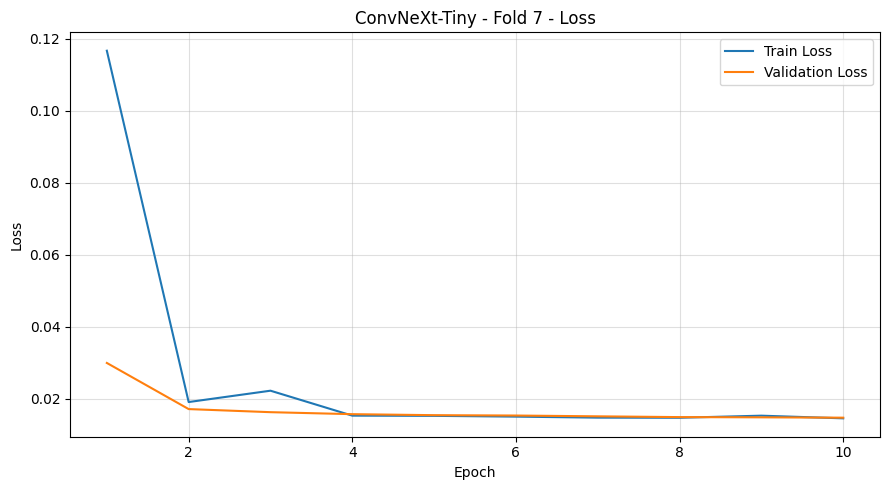

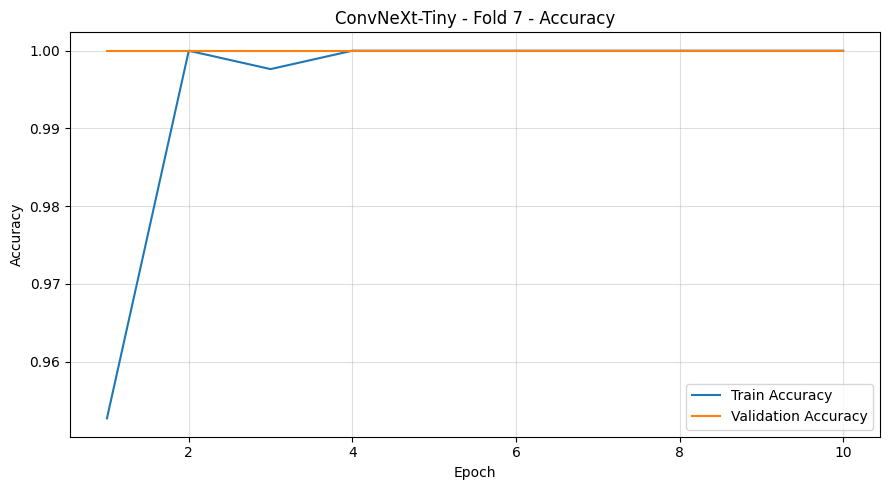

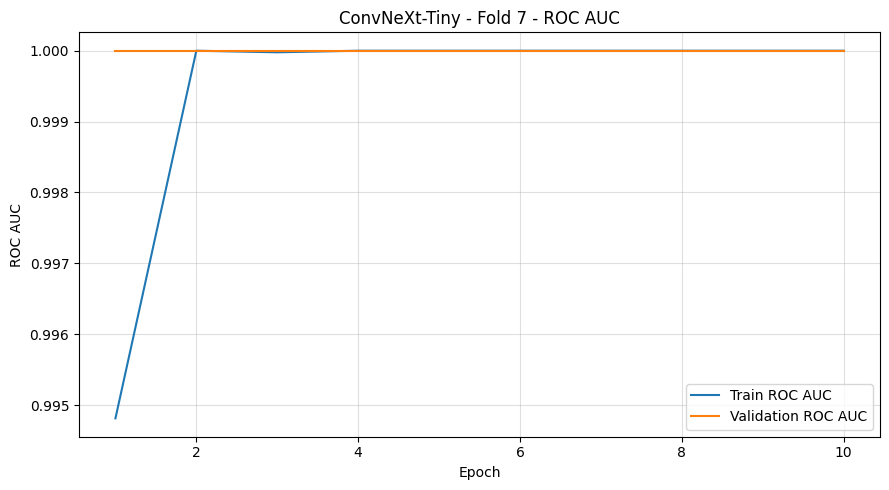

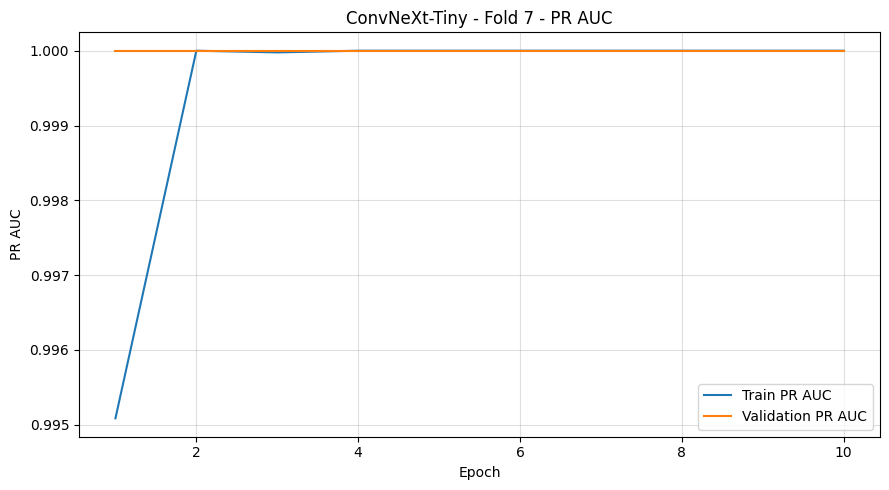

6/6 ━━━━━━━━━━━━━━━━━━━━ 10s 994ms/step

Fold 07 | Acc: 1.0000 | Bal Acc: 1.0000 | F1: 1.0000 | ROC AUC: 1.0000 | PR AUC: 1.0000 | Log loss: 0.00025166 | Brier: 0.00000132 | ECE: 0.00025100


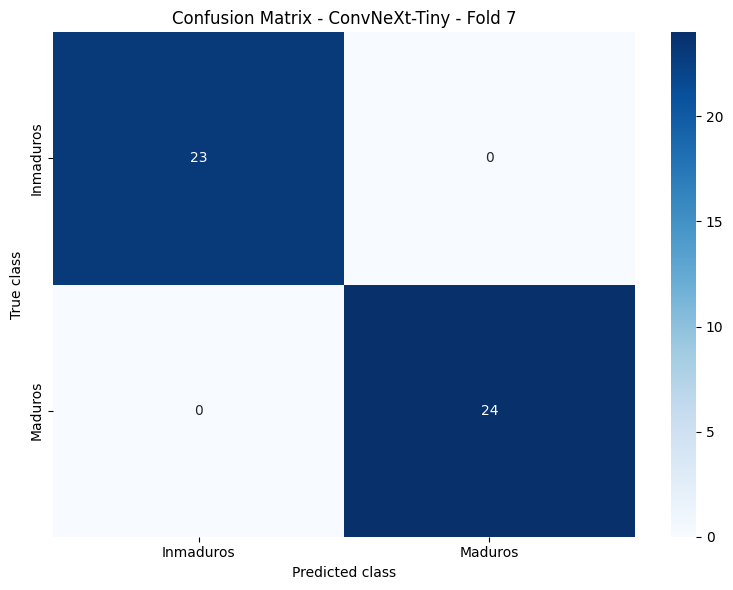

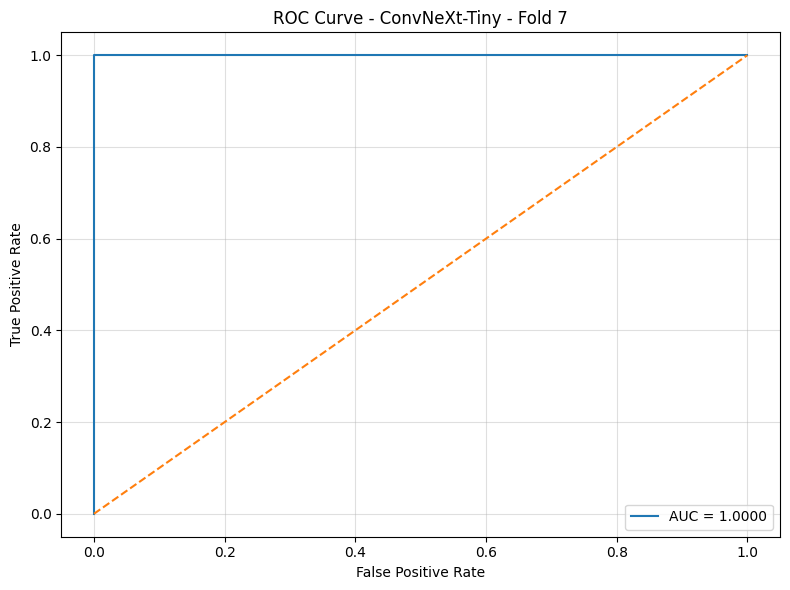

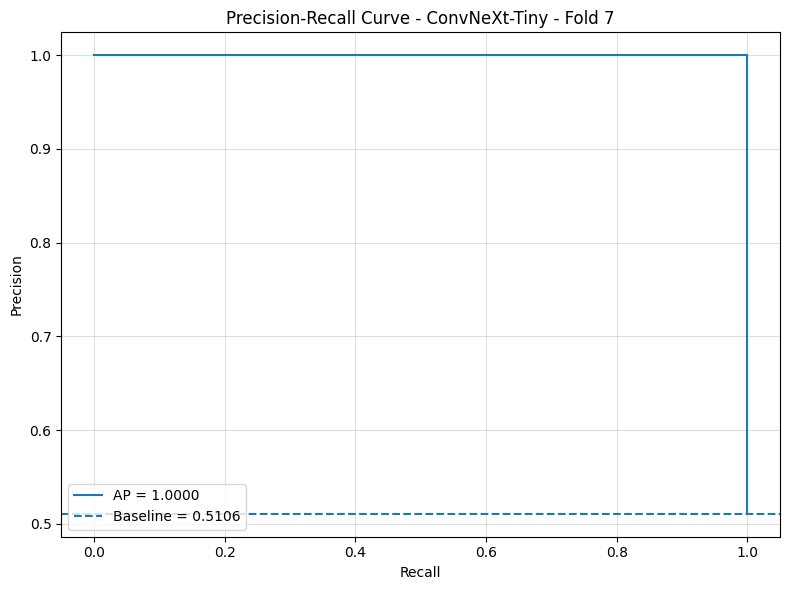

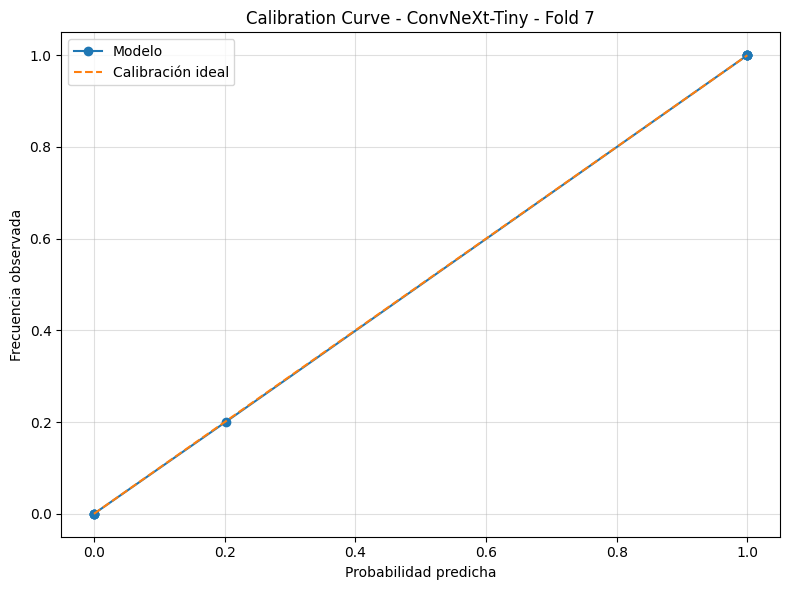

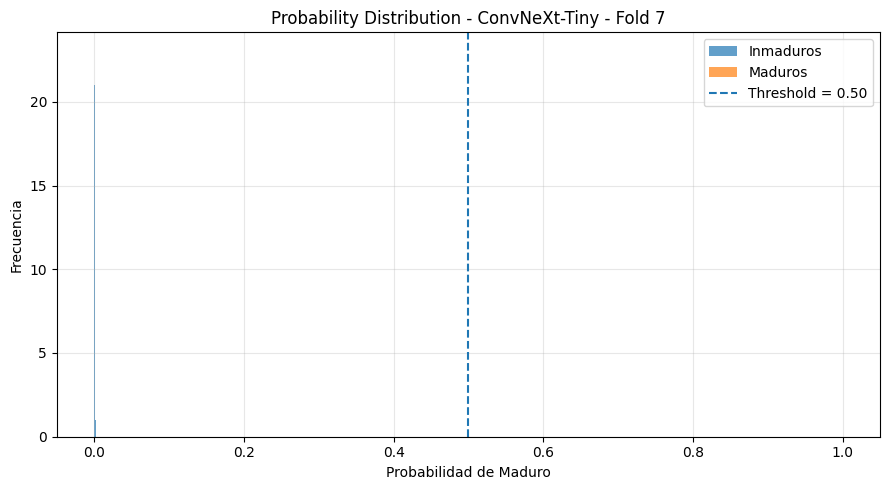

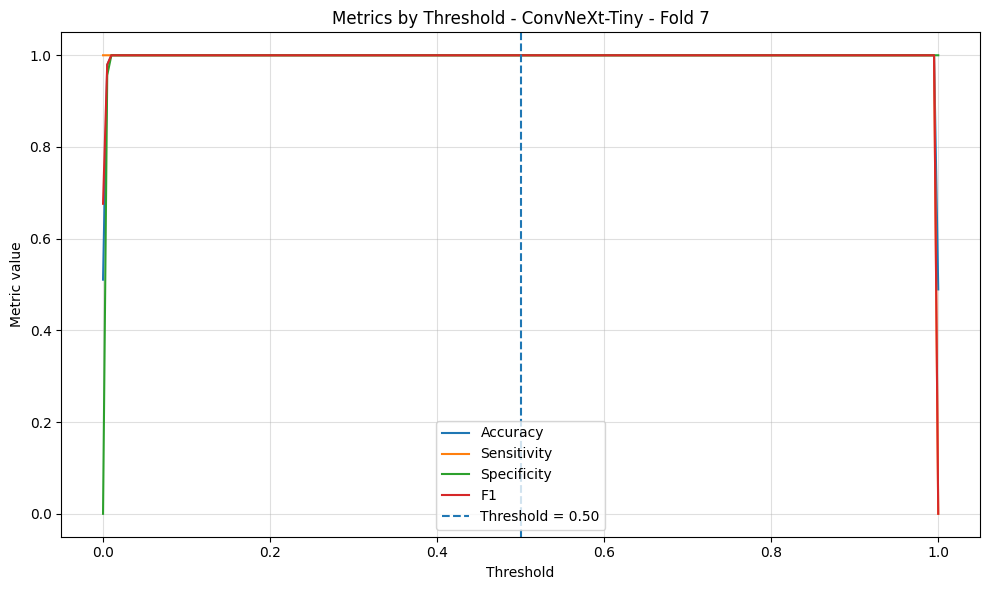


FOLD 8/10
------------------------------------------------------------------------
Epoch 1/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 46s 600ms/step - accuracy: 0.9716 - auc: 0.9943 - loss: 0.1128 - pr_auc: 0.9955 - precision: 0.9807 - recall: 0.9621 - val_accuracy: 0.9574 - val_auc: 0.9982 - val_loss: 0.0667 - val_pr_auc: 0.9983 - val_precision: 0.9583 - val_recall: 0.9583
Epoch 2/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 22s 405ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 0.0189 - pr_auc: 1.0000 - precision: 1.0000 - recall: 1.0000 - val_accuracy: 0.9574 - val_auc: 0.9982 - val_loss: 0.0564 - val_pr_auc: 0.9983 - val_precision: 0.9583 - val_recall: 0.9583
Epoch 3/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 21s 383ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 0.0157 - pr_auc: 1.0000 - precision: 1.0000 - recall: 1.0000 - val_accuracy: 0.9787 - val_auc: 1.0000 - val_loss: 0.0465 - val_pr_auc: 1.0000 - val_precision: 0.9600 - val_recall: 1.0000
Epoch 4/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 20s 370ms/step - accuracy: 0.9976 -

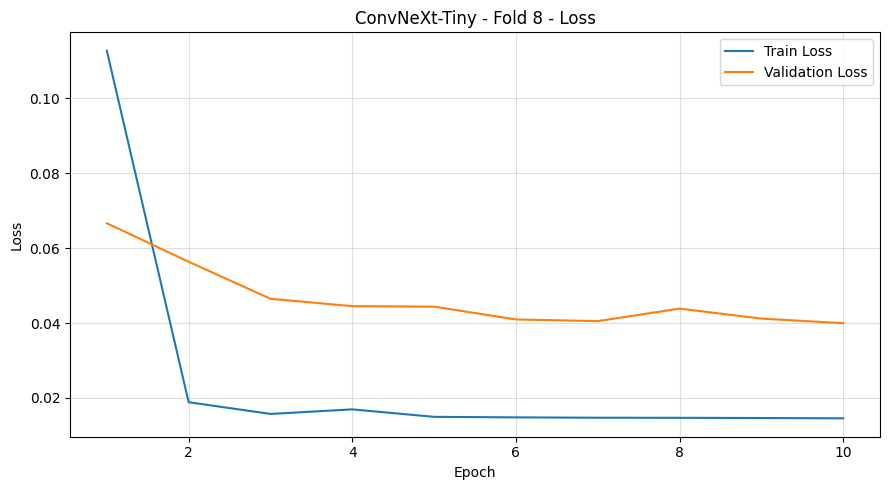

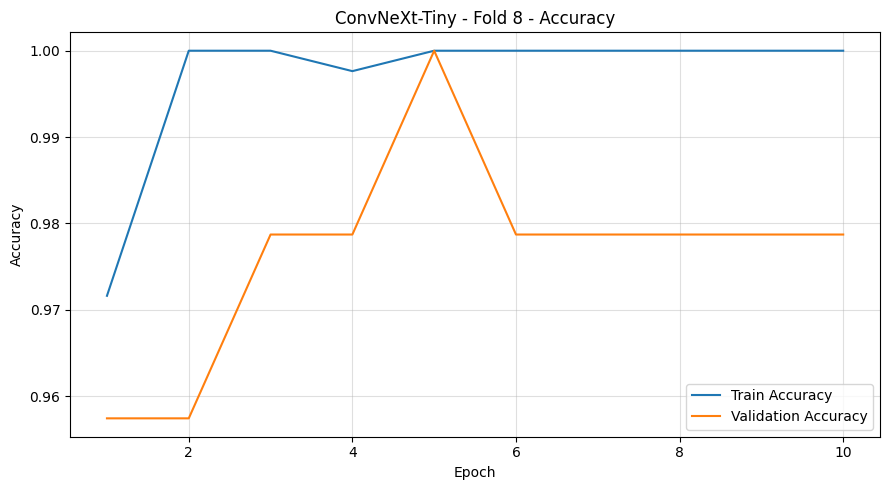

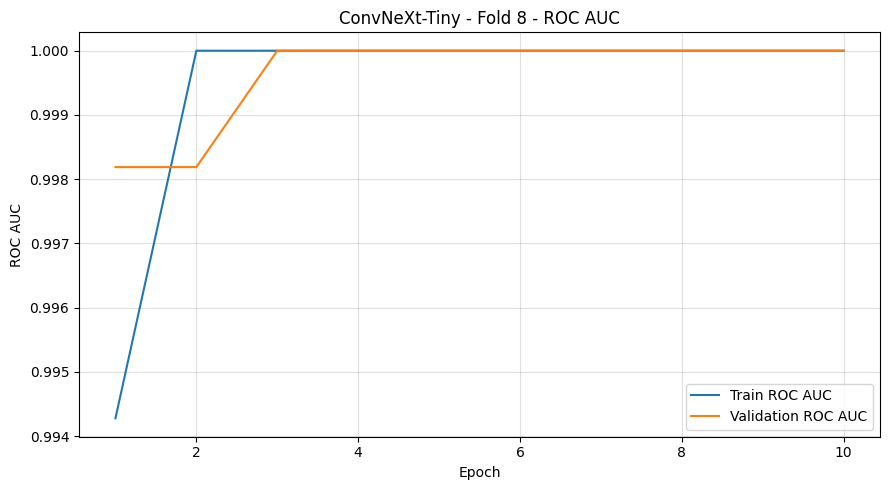

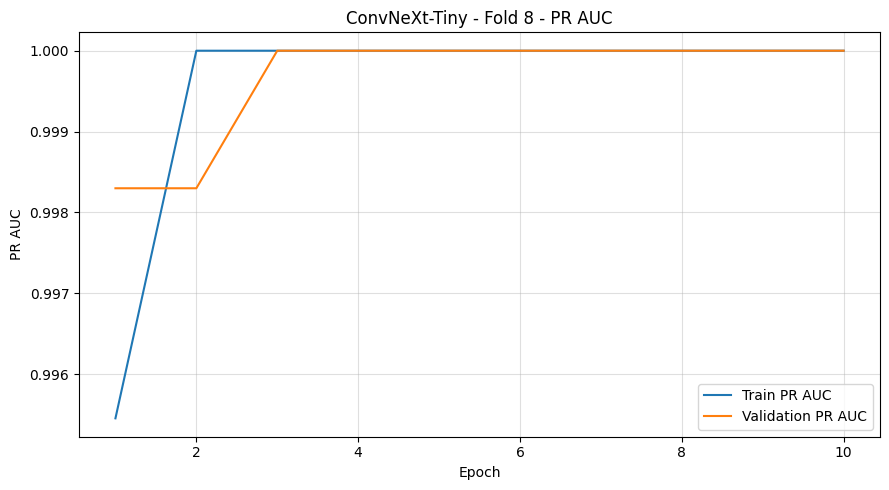

6/6 ━━━━━━━━━━━━━━━━━━━━ 9s 902ms/step

Fold 08 | Acc: 0.9787 | Bal Acc: 0.9783 | F1: 0.9796 | ROC AUC: 1.0000 | PR AUC: 1.0000 | Log loss: 0.02552631 | Brier: 0.00880860 | ECE: 0.01809372


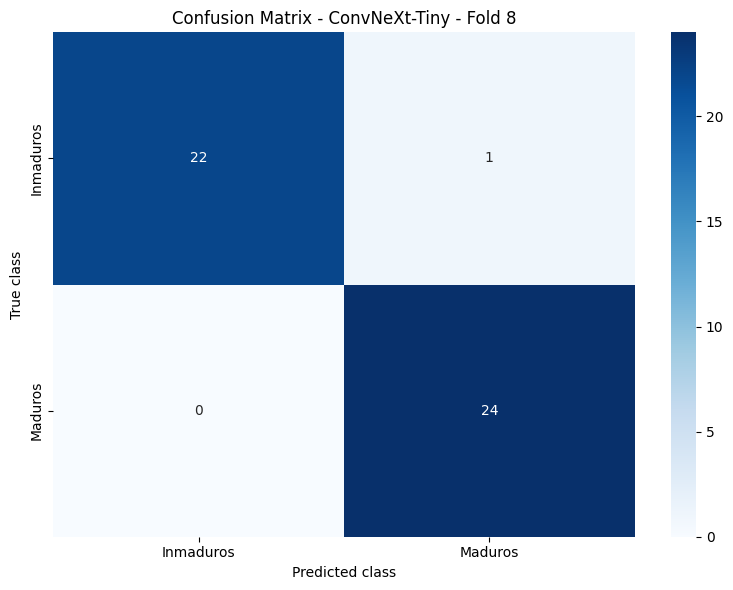

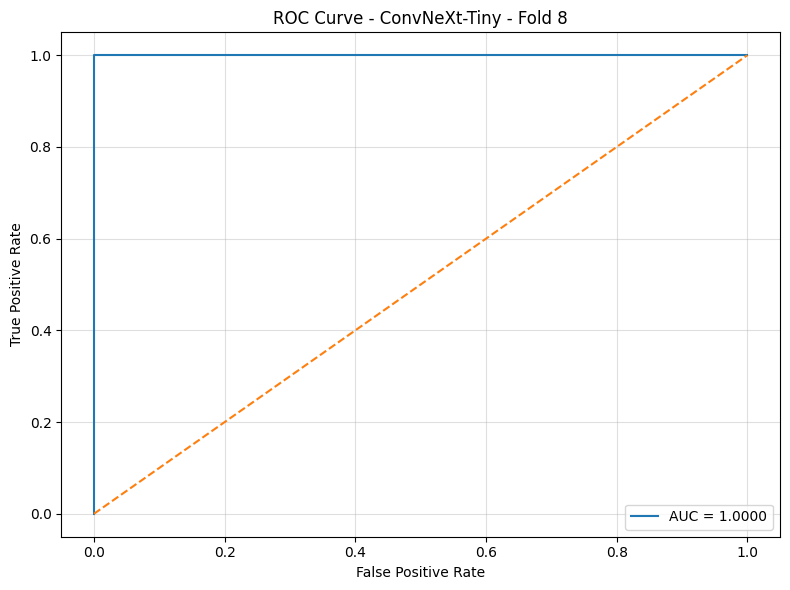

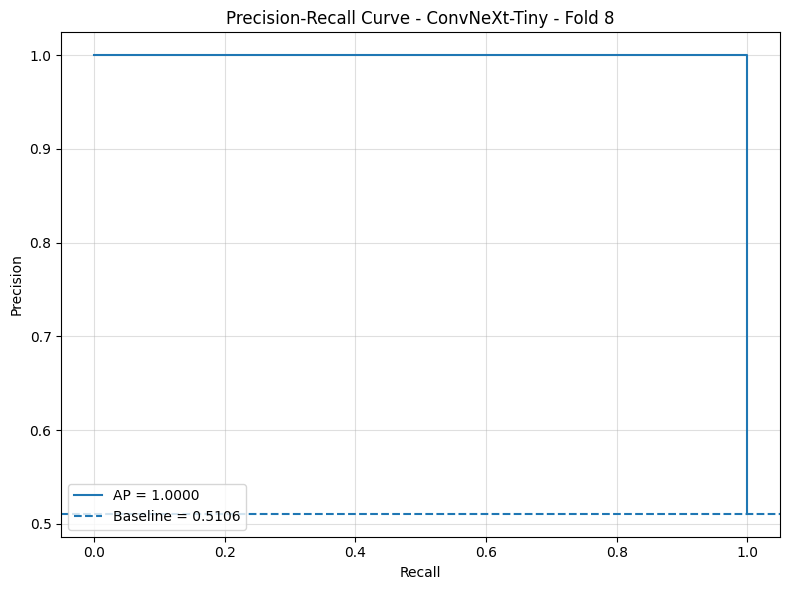

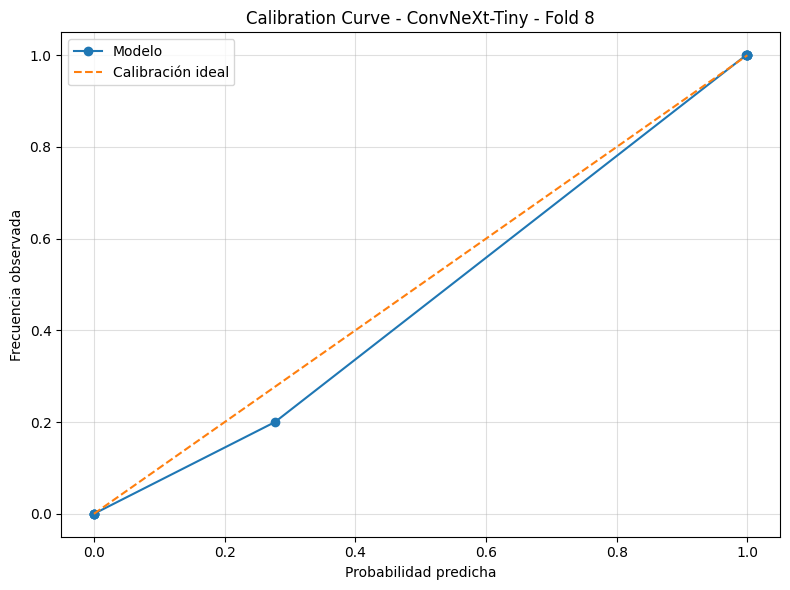

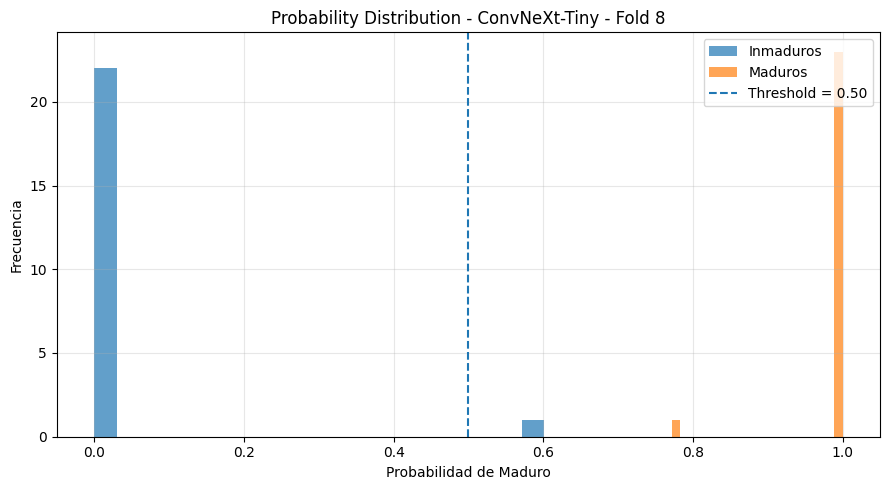

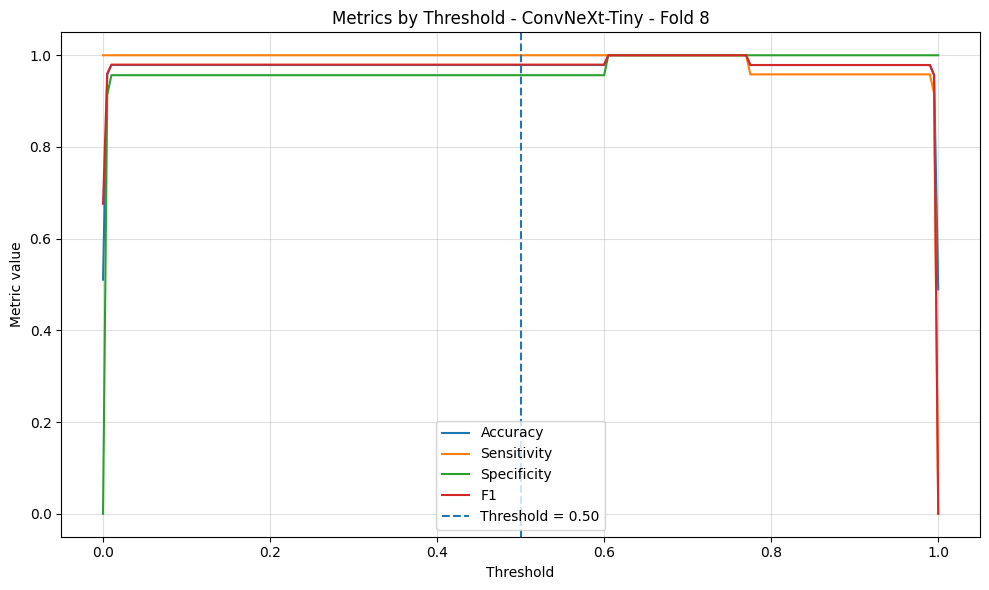


FOLD 9/10
------------------------------------------------------------------------
Epoch 1/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 46s 586ms/step - accuracy: 0.9480 - auc: 0.9929 - loss: 0.1327 - pr_auc: 0.9926 - precision: 0.9565 - recall: 0.9384 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0271 - val_pr_auc: 1.0000 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 2/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 20s 373ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 0.0222 - pr_auc: 1.0000 - precision: 1.0000 - recall: 1.0000 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0181 - val_pr_auc: 1.0000 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 3/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 20s 369ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 0.0158 - pr_auc: 1.0000 - precision: 1.0000 - recall: 1.0000 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0161 - val_pr_auc: 1.0000 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 4/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 21s 405ms/step - accuracy: 1.0000 -

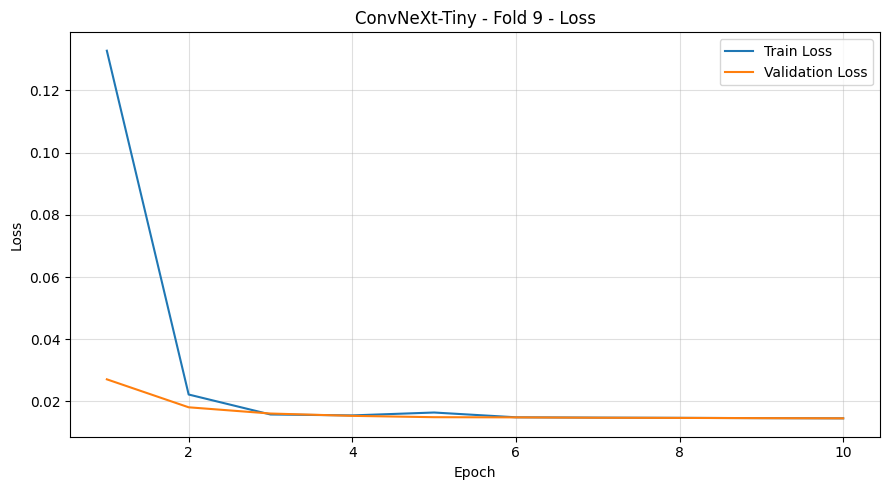

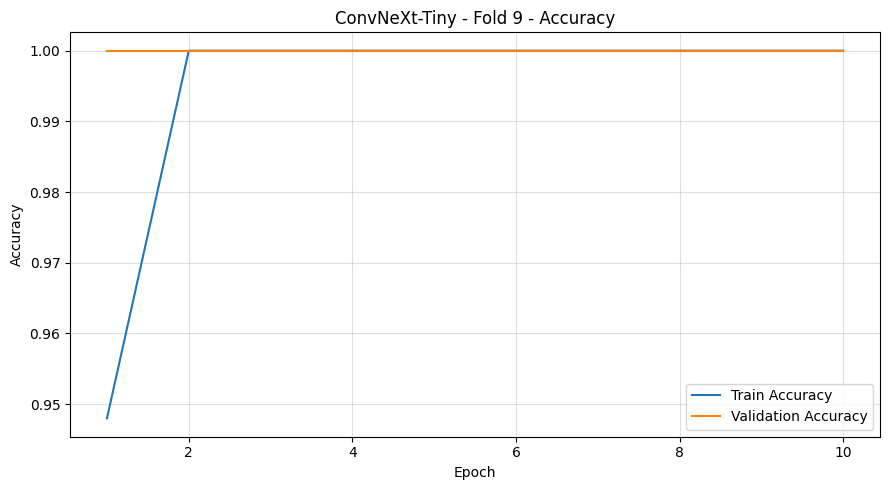

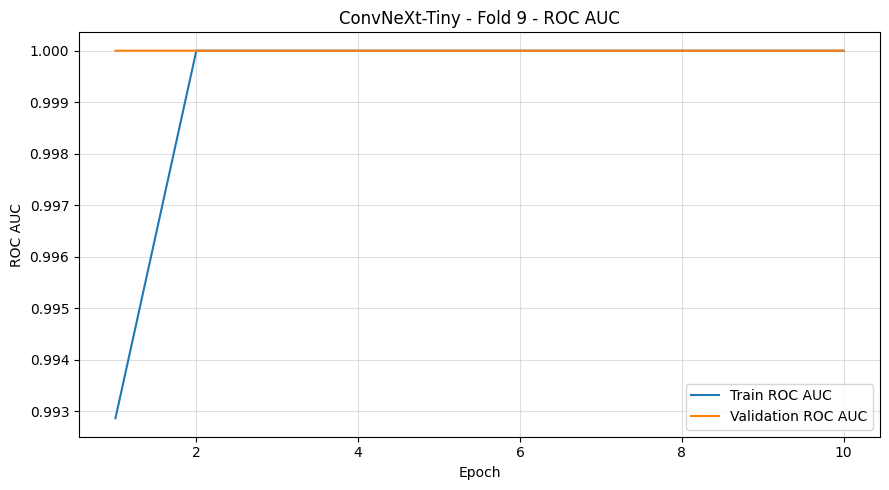

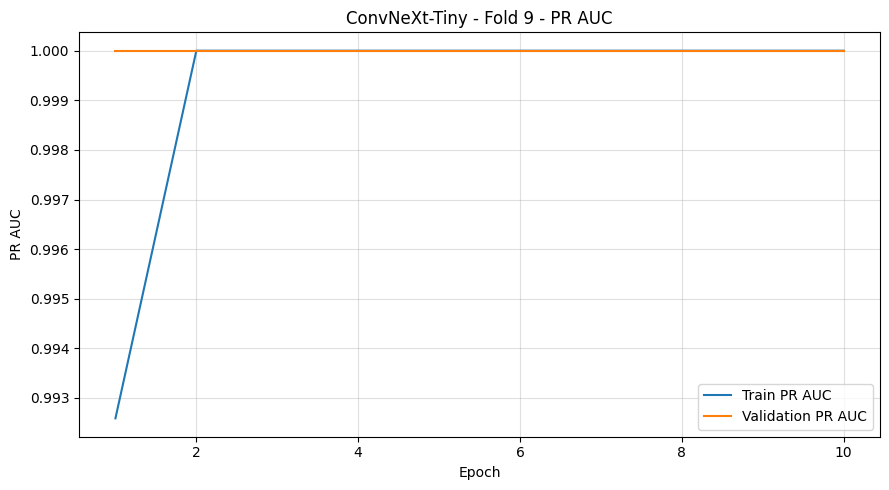

6/6 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step

Fold 09 | Acc: 1.0000 | Bal Acc: 1.0000 | F1: 1.0000 | ROC AUC: 1.0000 | PR AUC: 1.0000 | Log loss: 0.00007179 | Brier: 0.00000006 | ECE: 0.00007176


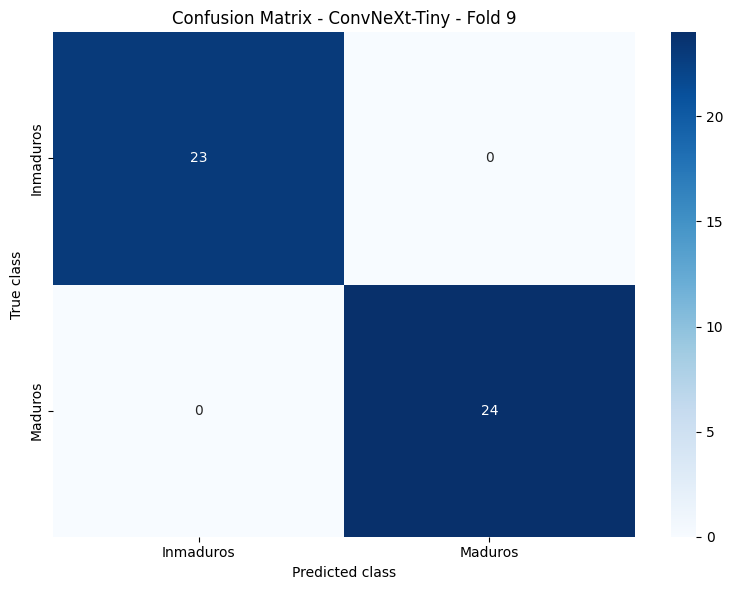

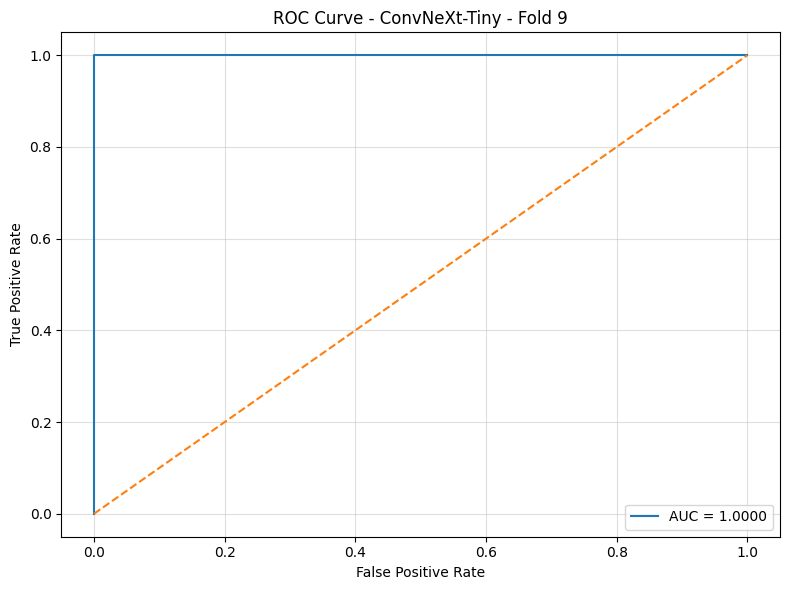

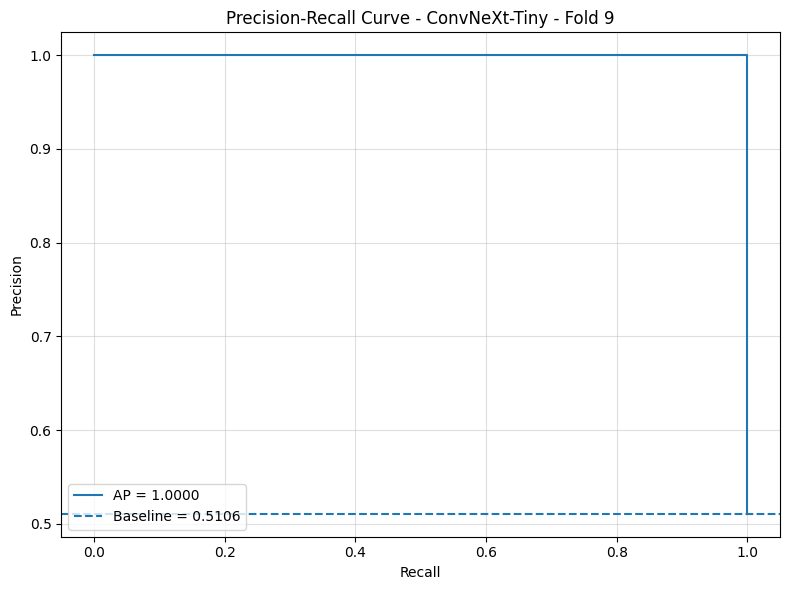

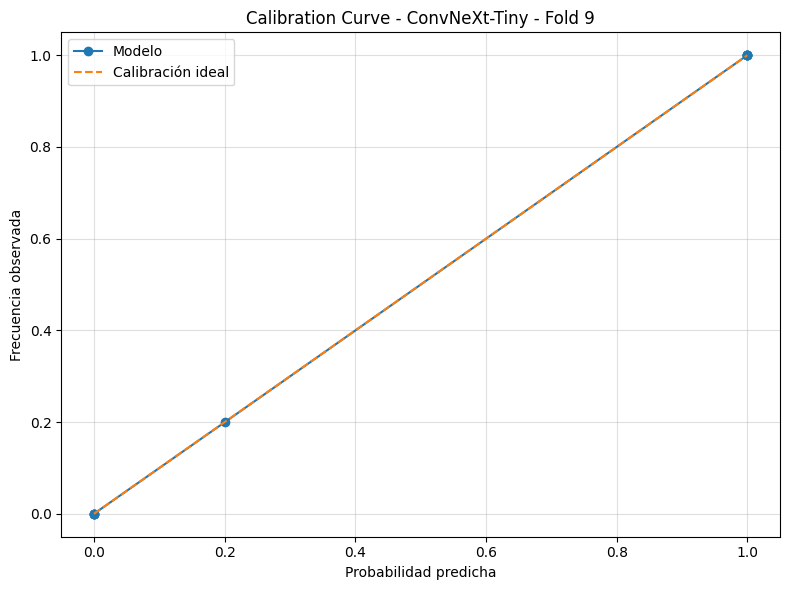

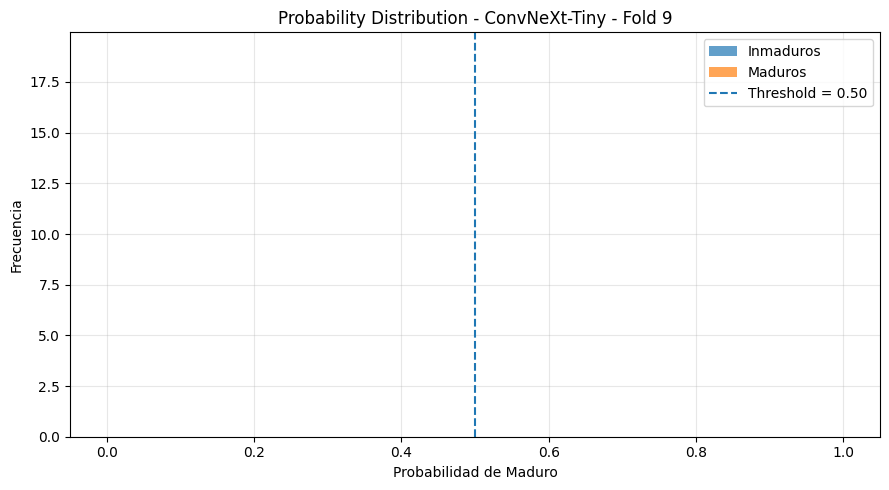

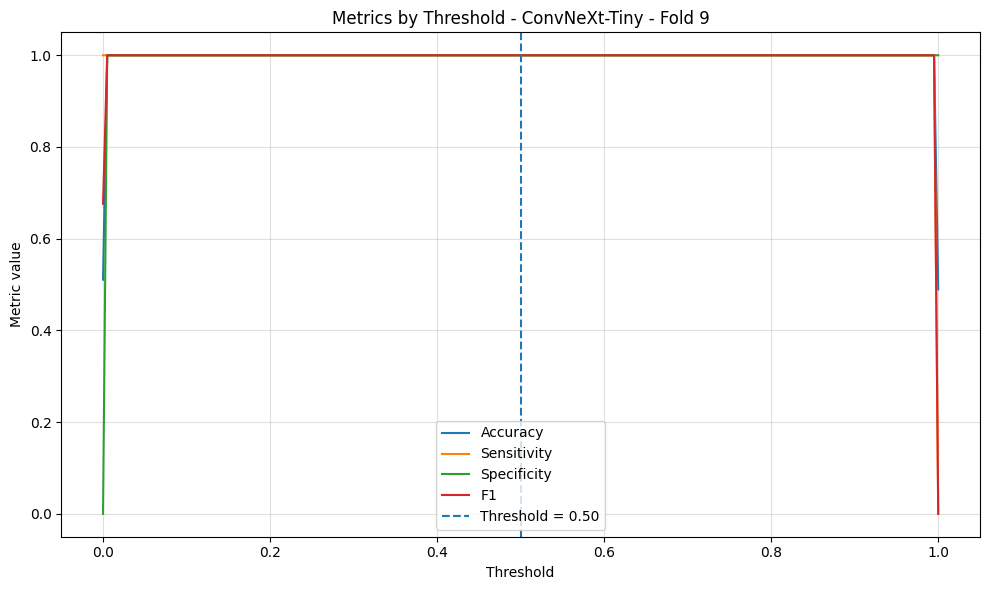


FOLD 10/10
------------------------------------------------------------------------
Epoch 1/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 46s 589ms/step - accuracy: 0.9456 - auc: 0.9899 - loss: 0.1483 - pr_auc: 0.9909 - precision: 0.9563 - recall: 0.9336 - val_accuracy: 0.9787 - val_auc: 1.0000 - val_loss: 0.0543 - val_pr_auc: 1.0000 - val_precision: 0.9600 - val_recall: 1.0000
Epoch 2/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 21s 395ms/step - accuracy: 0.9976 - auc: 1.0000 - loss: 0.0259 - pr_auc: 1.0000 - precision: 0.9953 - recall: 1.0000 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0216 - val_pr_auc: 1.0000 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 3/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 22s 403ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 0.0166 - pr_auc: 1.0000 - precision: 1.0000 - recall: 1.0000 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0173 - val_pr_auc: 1.0000 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 4/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 21s 388ms/step - accuracy: 0.9976 

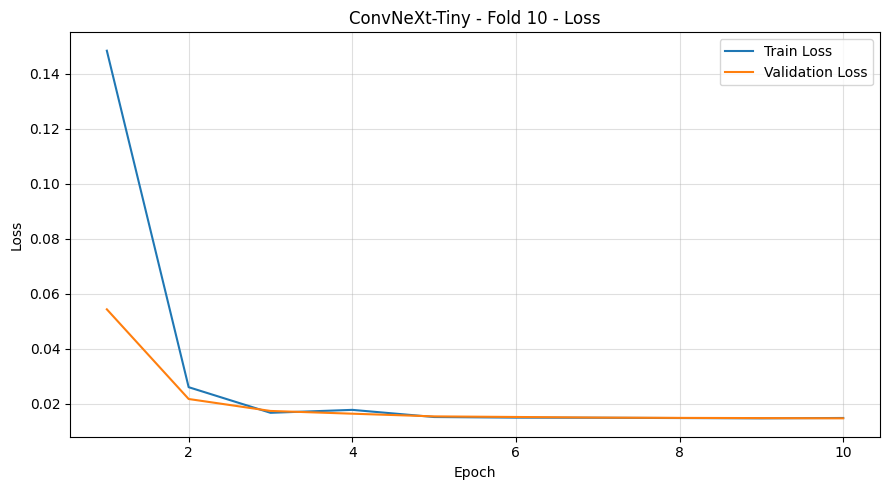

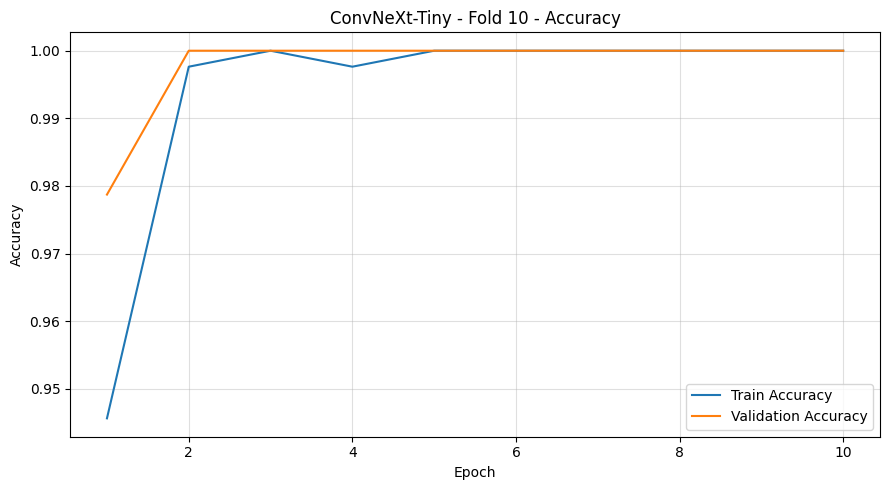

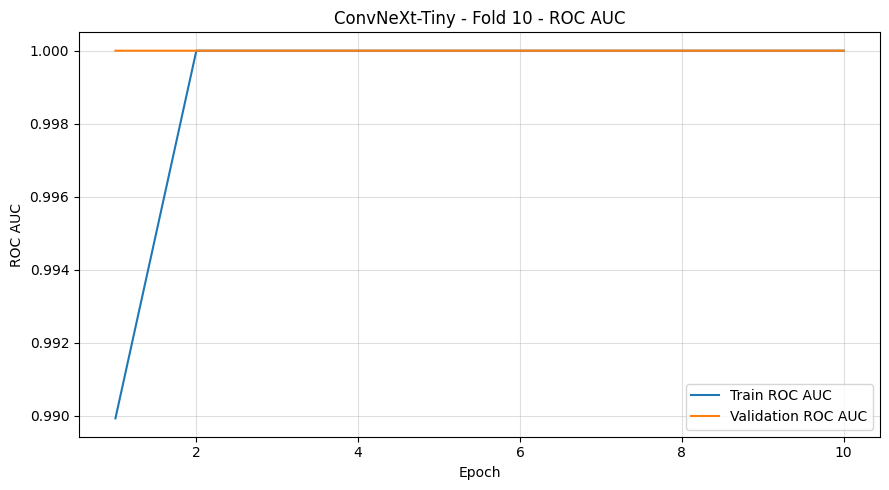

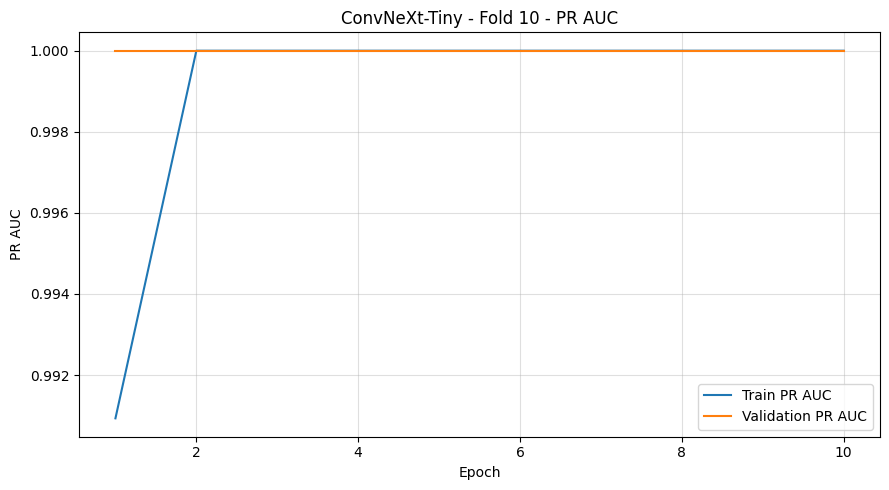

6/6 ━━━━━━━━━━━━━━━━━━━━ 11s 1s/step

Fold 10 | Acc: 1.0000 | Bal Acc: 1.0000 | F1: 1.0000 | ROC AUC: 1.0000 | PR AUC: 1.0000 | Log loss: 0.00014569 | Brier: 0.00000036 | ECE: 0.00014551


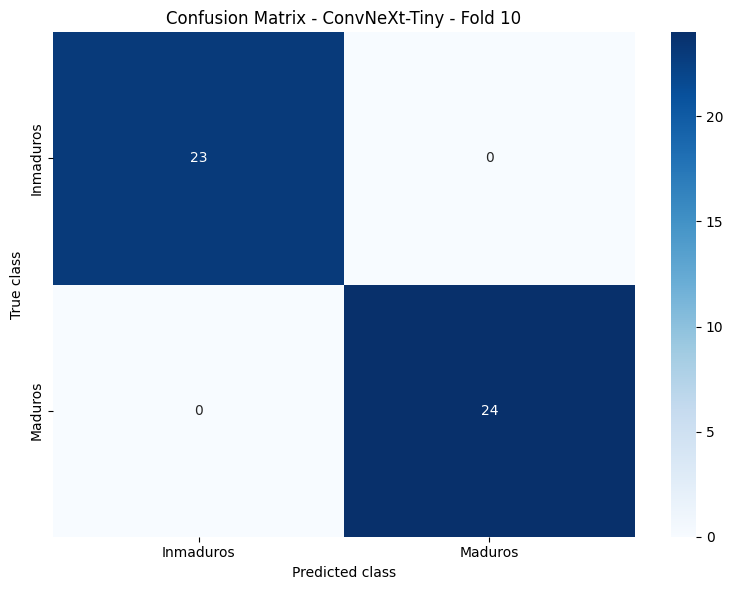

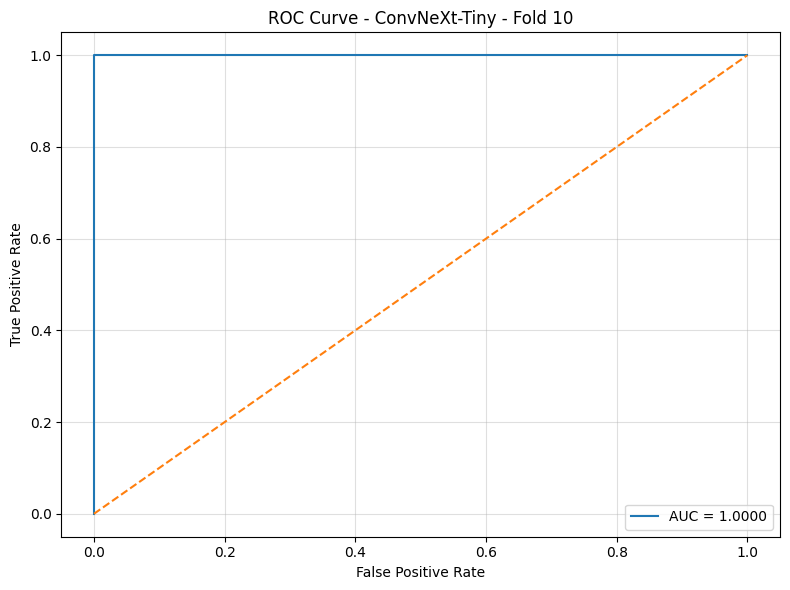

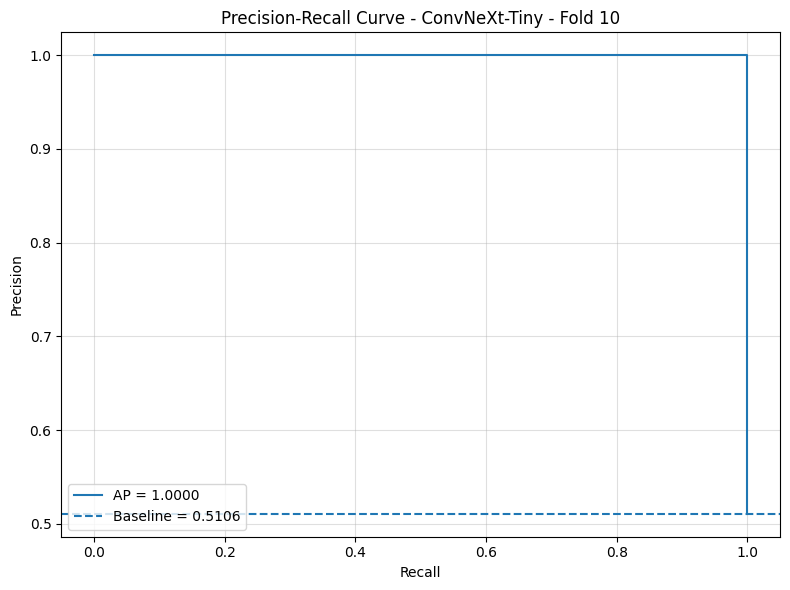

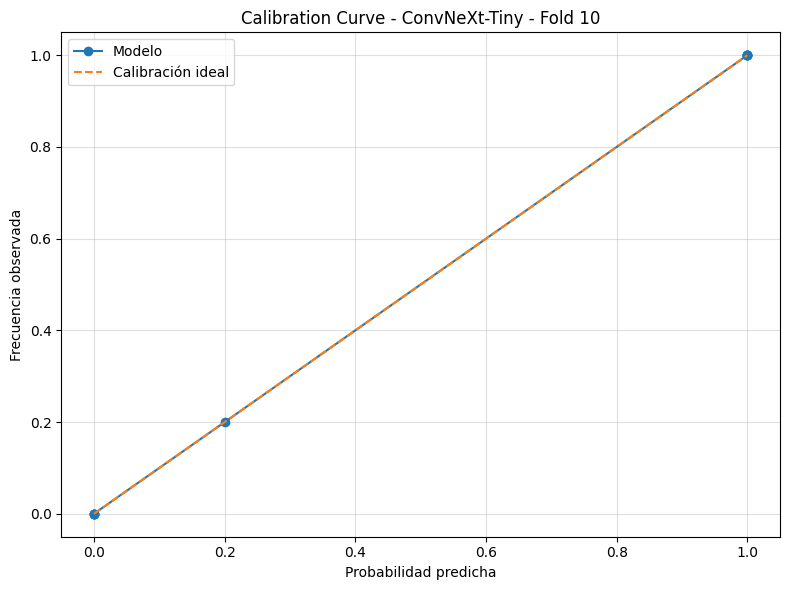

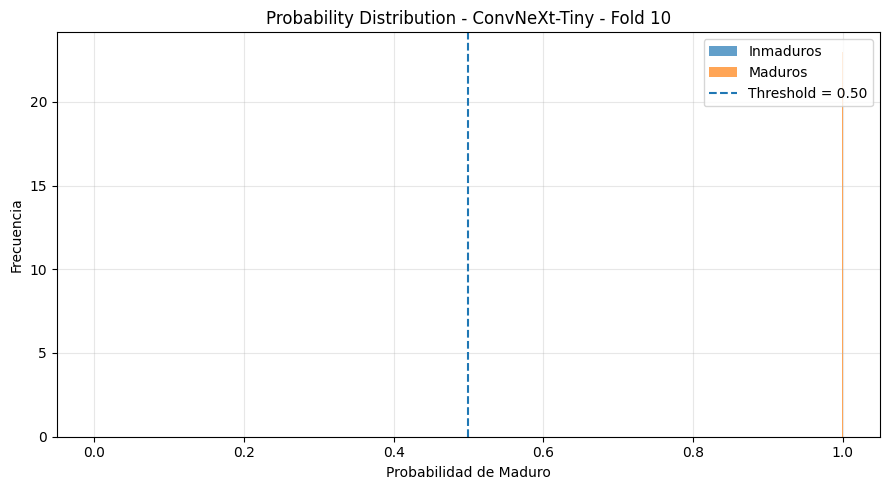

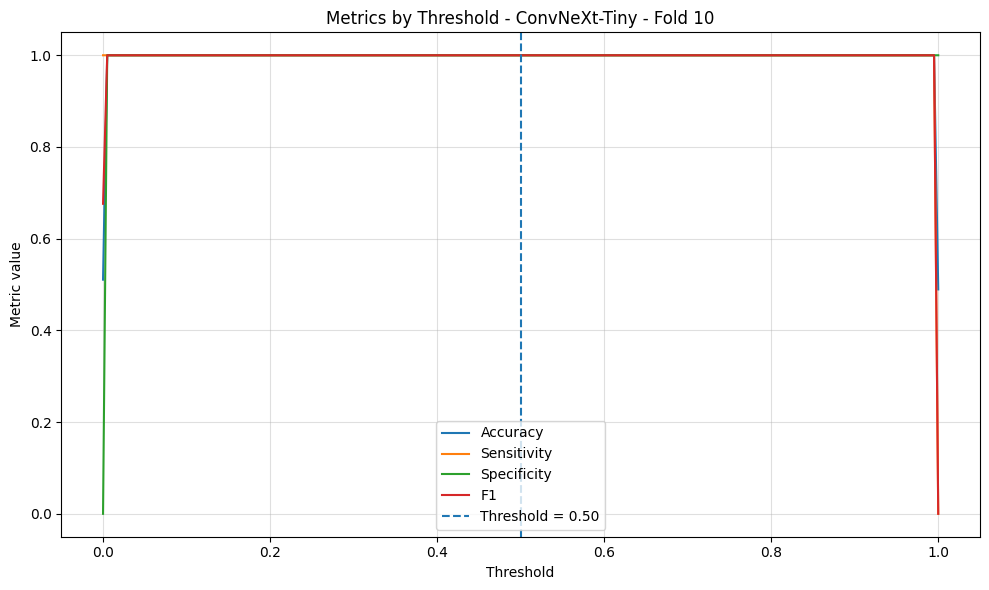


RESULTADOS POR FOLD


,tn,fp,fn,tp,accuracy,balanced_accuracy,precision_ppv,sensitivity_recall,specificity,negative_predictive_value,...,n_images,model,fold,train_images,validation_images,epochs_trained,epochs_source,training_time_seconds,inference_time_seconds,inference_time_per_image_ms
0,23,1,0,23,0.978723,0.979167,0.958333,1.0,0.958333,1.0,...,47,ConvNeXt-Tiny,1,423,47,10,best_optuna_trial,267.509831,9.479528,201.692084
1,24,0,0,23,1.000000,1.000000,1.000000,1.0,1.000000,1.0,...,47,ConvNeXt-Tiny,2,423,47,10,best_optuna_trial,223.430122,9.421004,200.446885
2,24,0,0,23,1.000000,1.000000,1.000000,1.0,1.000000,1.0,...,47,ConvNeXt-Tiny,3,423,47,10,best_optuna_trial,221.271207,8.273303,176.027719
3,24,0,0,23,1.000000,1.000000,1.000000,1.0,1.000000,1.0,...,47,ConvNeXt-Tiny,4,423,47,10,best_optuna_trial,226.252877,8.501142,180.875367
4,24,0,0,23,1.000000,1.000000,1.000000,1.0,1.000000,1.0,...,47,ConvNeXt-Tiny,5,423,47,10,best_optuna_trial,236.464990,10.570204,224.897958
5,23,0,0,24,1.000000,1.000000,1.000000,1.0,1.000000,1.0,...,47,ConvNeXt-Tiny,6,423,47,10,best_optuna_trial,236.491181,8.829846,187.869062
6,23,0,0,24,1.000000,1.000000,1.000000,1.0,1.000000,1.0,...,47,ConvNeXt-Tiny,7,423,47,10,best_optuna_trial,235.299371,10.028914,213.381153
7,22,1,0,24,0.978723,0.978261,0.960000,1.0,0.956522,1.0,...,47,ConvNeXt-Tiny,8,423,47,10,best_optuna_trial,231.972831,9.038193,192.301989
8,23,0,0,24,1.000000,1.000000,1.000000,1.0,1.000000,1.0,...,47,ConvNeXt-Tiny,9,423,47,10,best_optuna_trial,230.837870,9.648695,205.291378
9,23,0,0,24,1.000000,1.000000,1.000000,1.0,1.000000,1.0,...,47,ConvNeXt-Tiny,10,423,47,10,best_optuna_trial,264.457847,10.686839,227.379550



RESUMEN DE LOS 10 FOLDS


,metric,mean,std,median,min,max
0,accuracy,0.995745,8.971000e-03,1.000000,9.787234e-01,1.000000
1,balanced_accuracy,0.995743,8.977602e-03,1.000000,9.782609e-01,1.000000
2,precision_ppv,0.991833,1.722133e-02,1.000000,9.583333e-01,1.000000
3,sensitivity_recall,1.000000,0.000000e+00,1.000000,1.000000e+00,1.000000
4,specificity,0.991486,1.795520e-02,1.000000,9.565217e-01,1.000000
5,negative_predictive_value,1.000000,0.000000e+00,1.000000,1.000000e+00,1.000000
6,f1_score,0.995832,8.790302e-03,1.000000,9.787234e-01,1.000000
7,f2_score,0.998311,3.560693e-03,1.000000,9.913793e-01,1.000000
8,jaccard_index,0.991833,1.722133e-02,1.000000,9.583333e-01,1.000000
9,mcc,0.991659,1.758383e-02,1.000000,9.582593e-01,1.000000



MÉTRICAS OOF EXTENDIDAS


,0
tn,233
fp,2
fn,0
tp,235
accuracy,0.995745
balanced_accuracy,0.995745
precision_ppv,0.991561
sensitivity_recall,1.0
specificity,0.991489
negative_predictive_value,1.0


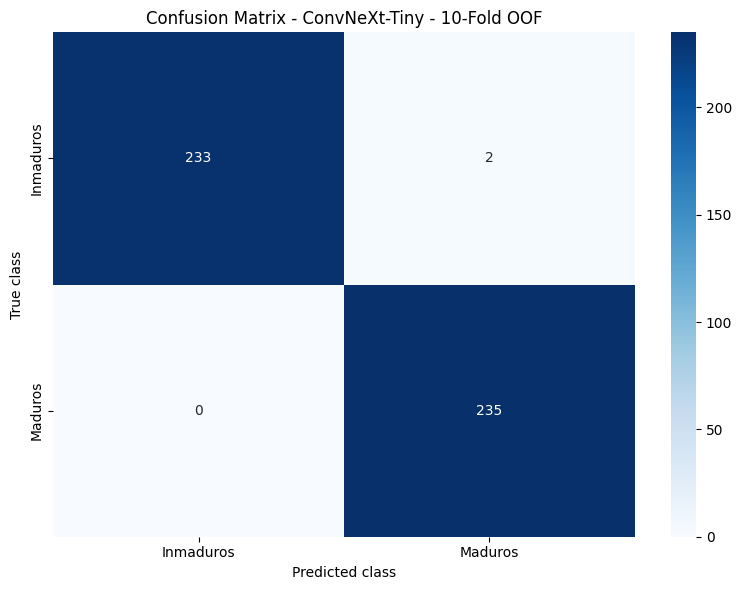

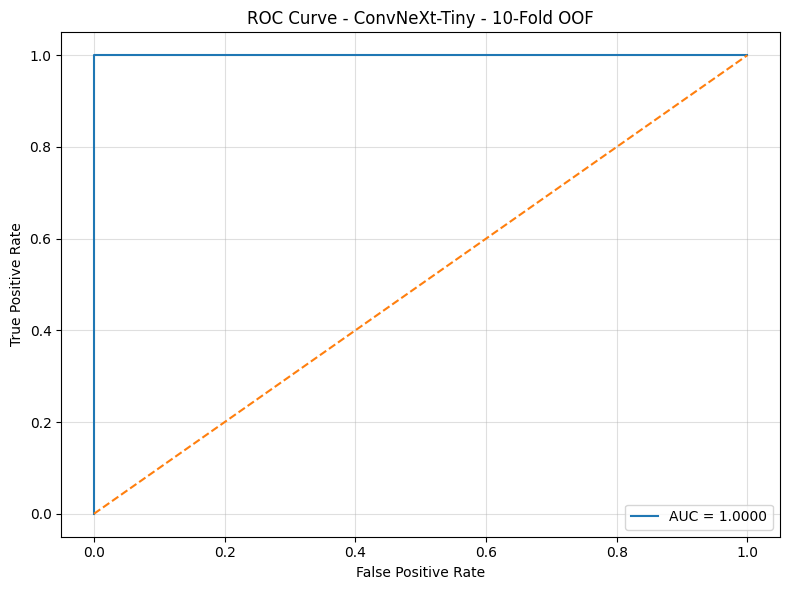

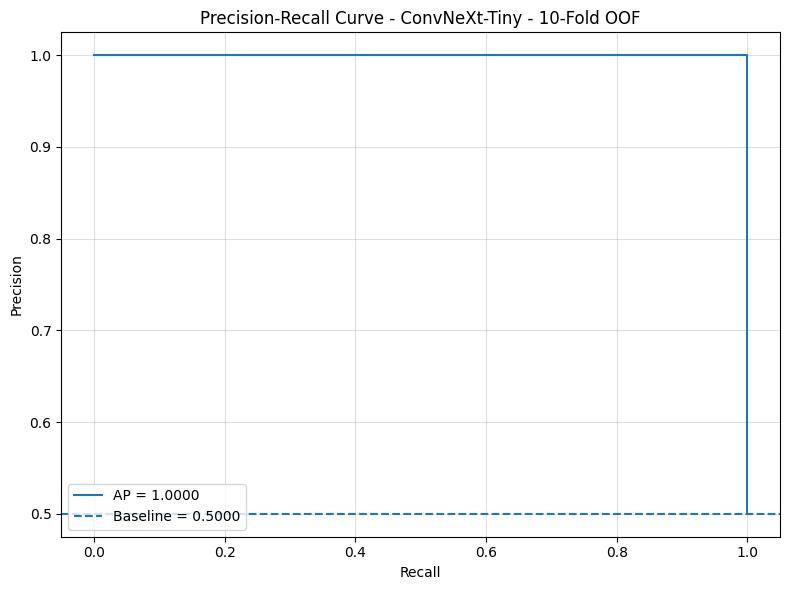

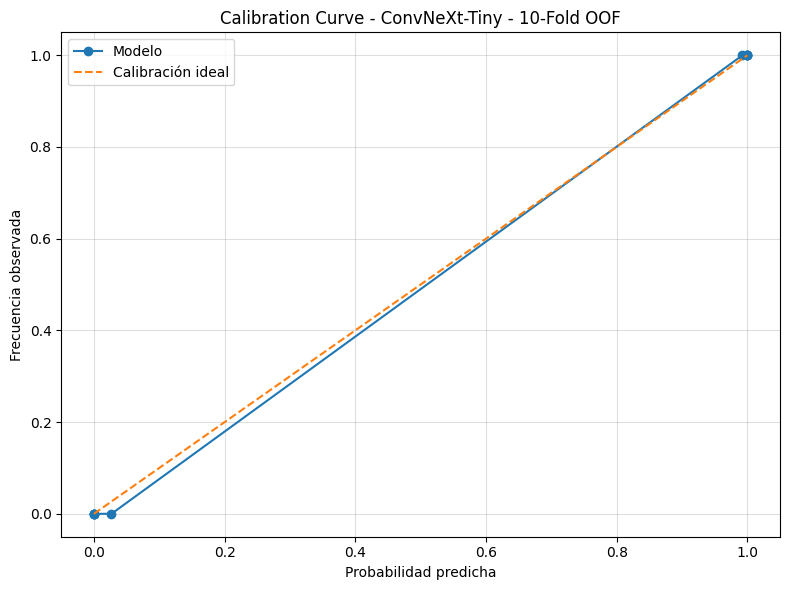

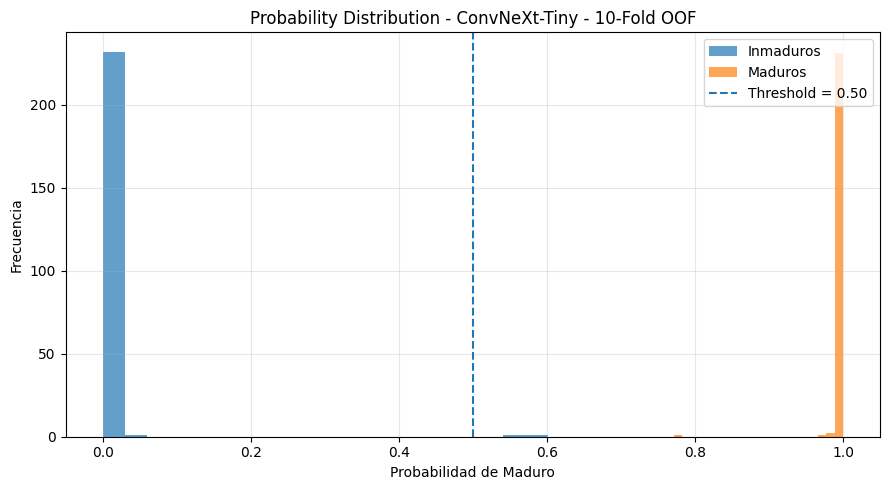

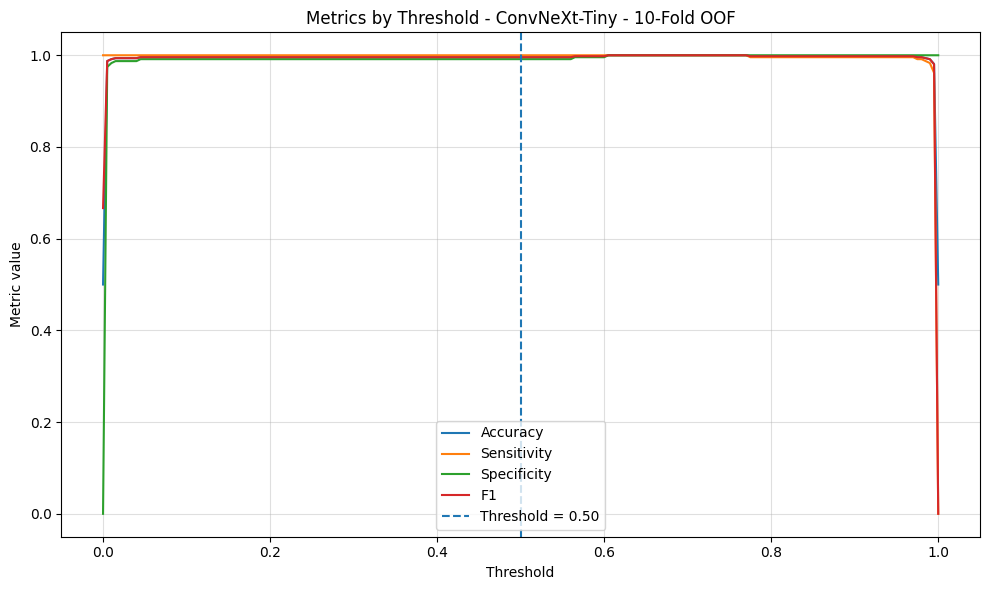


ENTRENAMIENTO FINAL CON TRAIN + VAL
Epoch 1/10
76/76 ━━━━━━━━━━━━━━━━━━━━ 50s 439ms/step - accuracy: 0.9603 - auc: 0.9957 - loss: 0.1108 - pr_auc: 0.9958 - precision: 0.9760 - recall: 0.9437
Epoch 2/10
76/76 ━━━━━━━━━━━━━━━━━━━━ 29s 384ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 0.0183 - pr_auc: 1.0000 - precision: 1.0000 - recall: 1.0000
Epoch 3/10
76/76 ━━━━━━━━━━━━━━━━━━━━ 28s 366ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 0.0156 - pr_auc: 1.0000 - precision: 1.0000 - recall: 1.0000
Epoch 4/10
76/76 ━━━━━━━━━━━━━━━━━━━━ 28s 369ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 0.0149 - pr_auc: 1.0000 - precision: 1.0000 - recall: 1.0000
Epoch 5/10
76/76 ━━━━━━━━━━━━━━━━━━━━ 29s 385ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 0.0148 - pr_auc: 1.0000 - precision: 1.0000 - recall: 1.0000
Epoch 6/10
76/76 ━━━━━━━━━━━━━━━━━━━━ 29s 379ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 0.0146 - pr_auc: 1.0000 - precision: 1.0000 - recall: 1.0000
Epoch 7/10
76/76 ━━━━━━━━━━━━━━━━

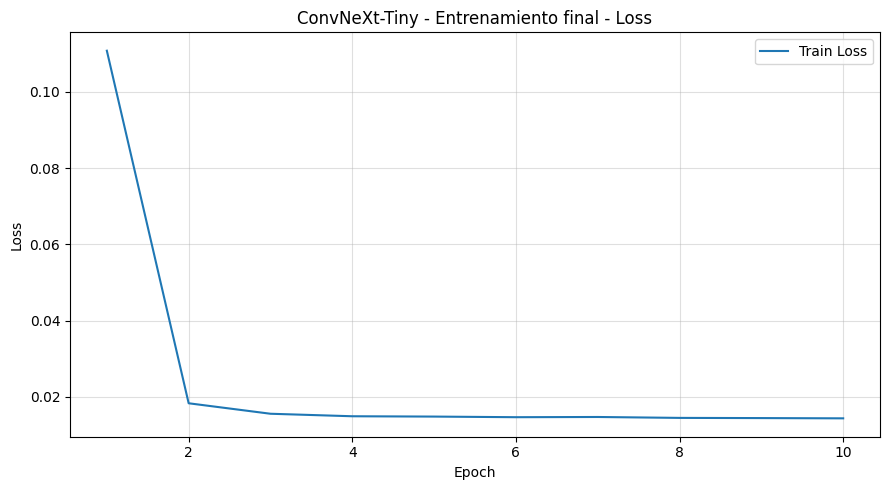

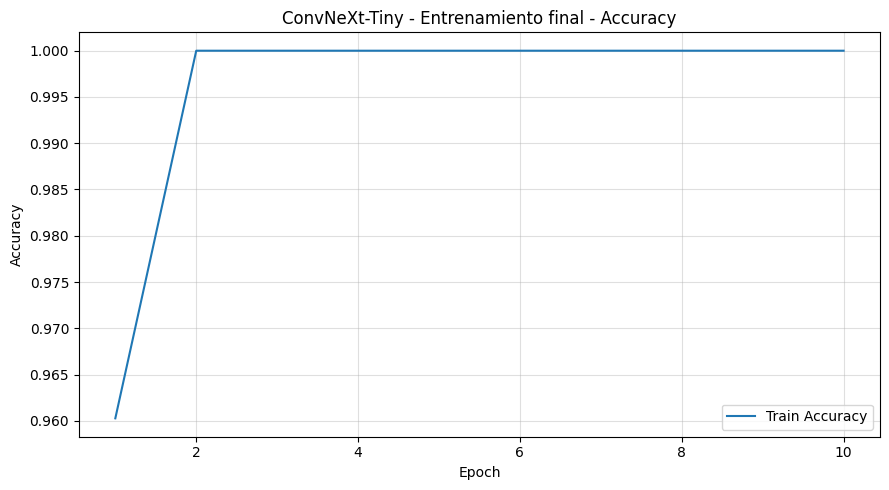

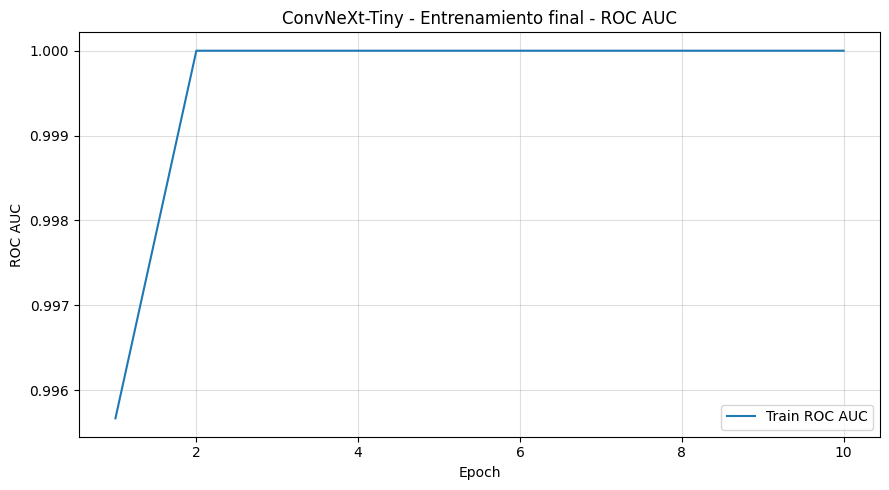

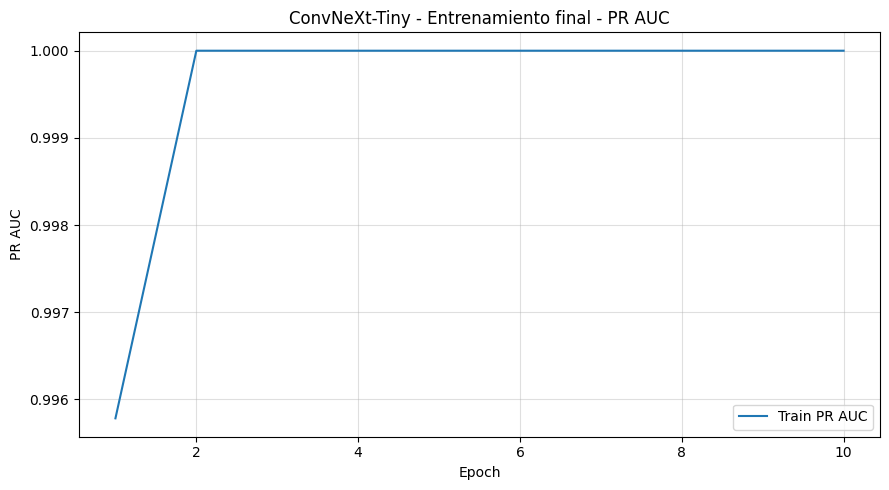


EVALUACIÓN FINAL SOBRE TEST INDEPENDIENTE

MÉTRICAS DEL TEST EXTENDIDAS


,0
tn,34
fp,0
fn,1
tp,33
accuracy,0.985294
...,...
inference_per_image_ms_median,18.727359
inference_per_image_ms_p95_repetition,33.938914
total_parameters,28017249
trainable_parameters,12085761


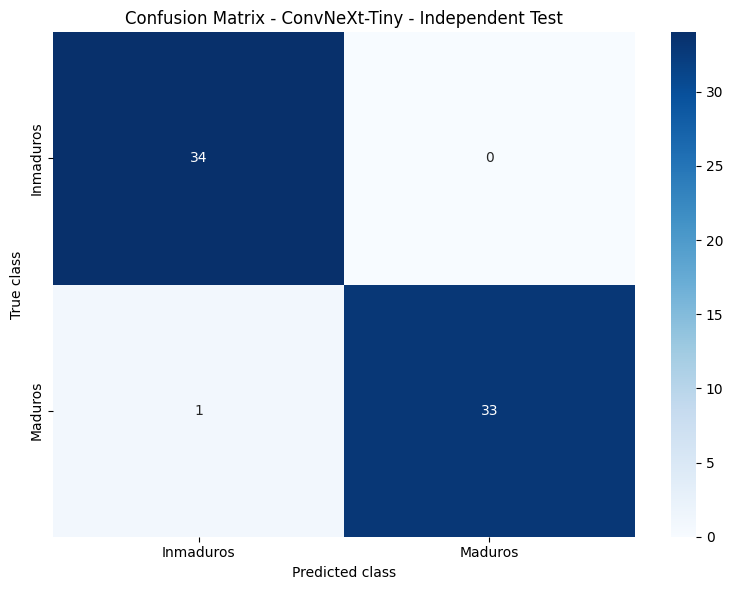

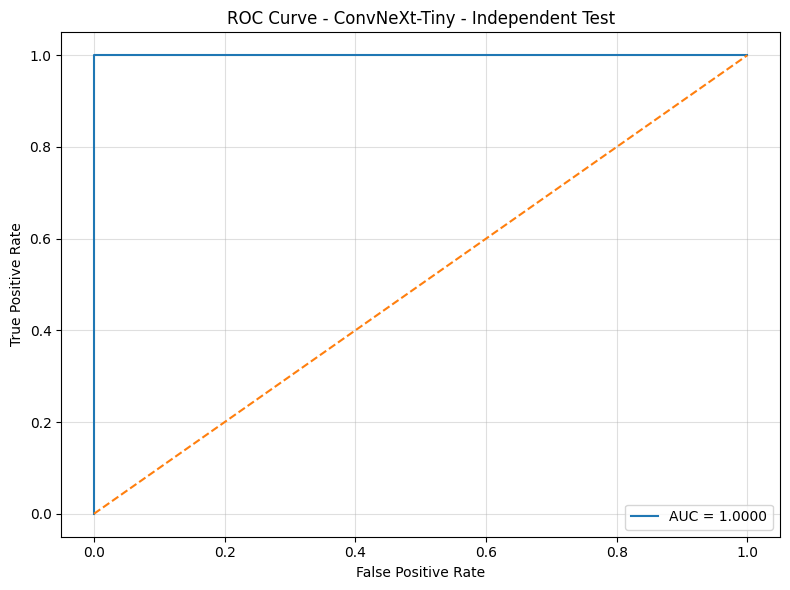

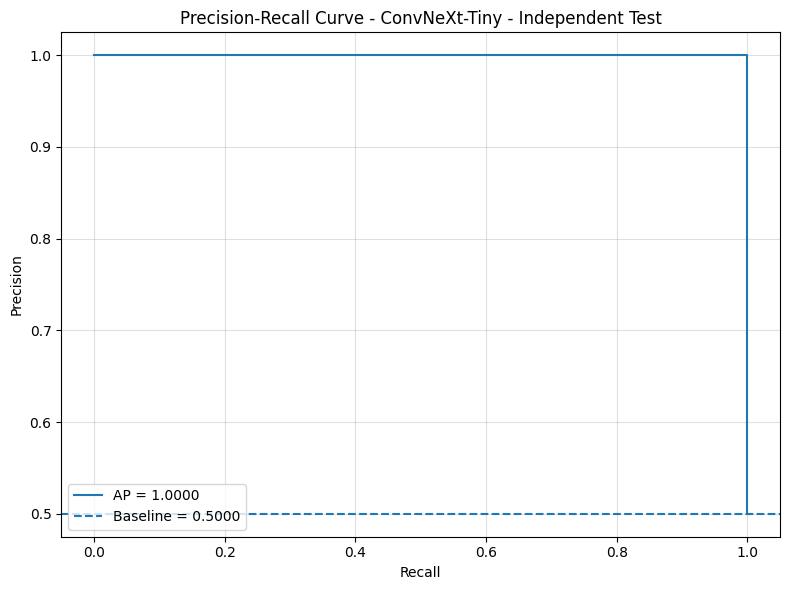

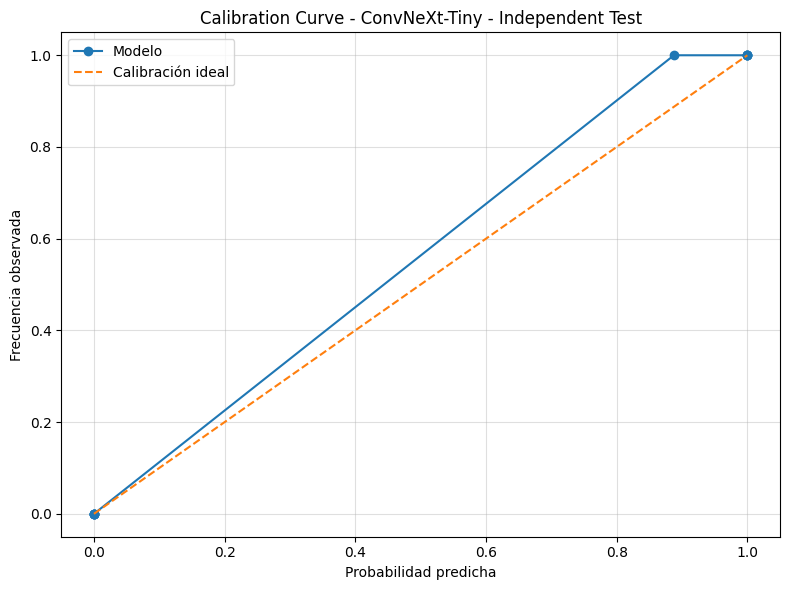

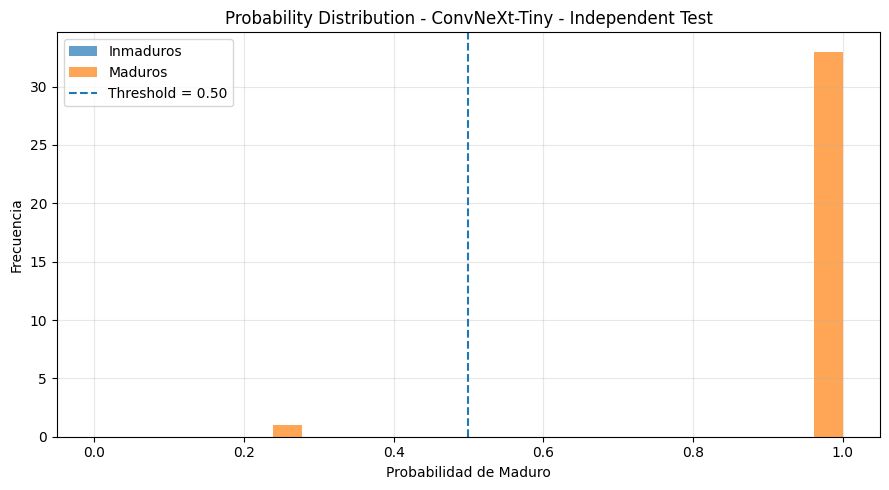

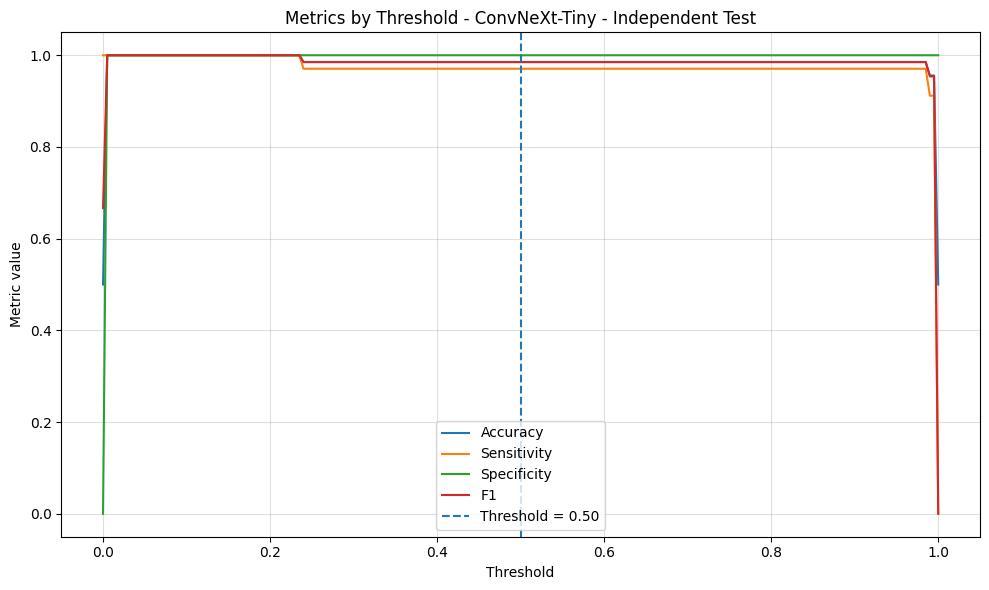


EXPORTANDO ARTEFACTOS DE CONVNEXT-TINY


Saved artifact at '/content/drive/MyDrive/Tesis-Mango/Dataset Tesis2/Resultados/Experimento_ConvNeXtTiny_Evaluacion_Extendida/artefactos_modelo/ConvNeXtTiny_saved_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='imagen_entrada')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  131995838094352: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  131995838099536: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  131995838095888: TensorSpec(shape=(), dtype=tf.resource, name=None)
  131995838093392: TensorSpec(shape=(), dtype=tf.resource, name=None)
  131995838091280: TensorSpec(shape=(), dtype=tf.resource, name=None)
  131995838091664: TensorSpec(shape=(), dtype=tf.resource, name=None)
  131995838089936: TensorSpec(shape=(), dtype=tf.resource, name=None)
  131995838092816: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1

In [ ]:
# ============================================================
# CONVNEXT-TINY MONOLÍTICA - EVALUACIÓN EXTENDIDA
# ============================================================
#
# CLASIFICACIÓN:
#   0 = Inmaduros
#   1 = Maduros
#
# VARIANTE:
#   ConvNeXt-Tiny (ConvNeXtTiny de TensorFlow/Keras), con pesos
#   preentrenados en ImageNet. Se utiliza IMG_SIZE=(224,224) para
#   mantener comparabilidad con ResNet50 y EfficientNetV2-S.
#
# OBJETIVO:
#   Entrenar y evaluar ConvNeXt-Tiny con el mismo esquema utilizado
#   para ResNet50 y EfficientNetV2-S, incluyendo métricas capaces de
#   diferenciar modelos cuando Accuracy/F1/AUC se saturen.
#
# FLUJO:
#   1. Cargar train, val y test.
#   2. Verificar duplicados exactos SHA-256 entre splits.
#   3. Dividir únicamente val para Optuna (70/30).
#   4. Optuna ejecuta 30 trials y minimiza log loss.
#   5. Optuna selecciona hiperparámetros y cantidad de épocas.
#   6. Validación cruzada estratificada de 10 folds sobre train.
#      Cada fold entrena una ConvNeXt-Tiny nueva con la configuración fija
#      seleccionada por HPO. No se vuelve a elegir época en CV.
#   7. Evaluación OOF con métricas discriminativas, probabilísticas,
#      calibración, incertidumbre, intervalos y curvas.
#   8. Entrenamiento final con train + val.
#   9. Evaluación única en test independiente.
#  10. Exportación de modelo, pesos, configuración, SavedModel,
#      manifiesto, checksums y ZIP. TFLite/ONNX quedan opcionales.
#
# COLORES:
#   - Matrices de confusión: cmap="Blues".
#   - Resto de gráficos: ciclo de colores predeterminado de Matplotlib
#     (primera serie azul, segunda naranja, etc.).
#
# COMPARABILIDAD:
#   - Mismos splits, semilla, resolución, 30 trials y 10 folds.
#   - Mismo objetivo HPO: minimizar log loss estándar.
#   - Mismos nombres de métricas y archivos que los experimentos
#     ResNet50 y EfficientNetV2-S.
#   - Mismo umbral principal: 0.50.
# ============================================================


# ============================================================
# 1. INSTALAR DEPENDENCIAS
# ============================================================

!pip install -q optuna seaborn scipy statsmodels onnx onnxruntime tf2onnx


# ============================================================
# 2. IMPORTACIONES
# ============================================================

import os

# Reducir mensajes internos y desactivar la compilación automática XLA/JIT.
# Debe configurarse antes de importar TensorFlow.
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["TF_XLA_FLAGS"] = "--tf_xla_auto_jit=0"

import gc
import io
import json
import time
import math
import random
import shutil
import hashlib
import platform
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import tensorflow as tf

# ConvNeXt puede activar rutas internas XLA durante la primera llamada.
# Se desactivan para evitar compilaciones prolongadas antes de Optuna.
tf.config.optimizer.set_jit(False)
tf.get_logger().setLevel("ERROR")
tf.autograph.set_verbosity(0)

import matplotlib.pyplot as plt
import seaborn as sns
import optuna

from tqdm.auto import tqdm
from IPython.display import display

from tensorflow.keras import Model, layers, callbacks, optimizers, regularizers
from tensorflow.keras.applications import ConvNeXtTiny

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    jaccard_score,
    matthews_corrcoef,
    cohen_kappa_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    log_loss,
    brier_score_loss,
    roc_curve,
    precision_recall_curve,
    auc,
)
from sklearn.calibration import calibration_curve
from sklearn.linear_model import LogisticRegression
from scipy.stats import beta, ks_2samp

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)


# ============================================================
# 3. REPRODUCIBILIDAD
# ============================================================

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

try:
    tf.config.experimental.enable_op_determinism()
    print("Operaciones deterministas activadas.")
except Exception as error:
    print("No se pudo activar el determinismo completo:", error)


# ============================================================
# 4. CONFIGURACIÓN DE GPU
# ============================================================

gpus = tf.config.list_physical_devices("GPU")

if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print(f"GPU detectada: {gpus}")
    except Exception as error:
        print("No se pudo configurar la memoria GPU:", error)
else:
    print("No se detectó GPU. Se utilizará CPU.")
    print(
        "ADVERTENCIA: ConvNeXtTiny con 30 trials y 10 folds es muy "
        "costoso en CPU. Para este experimento se recomienda activar "
        "una GPU T4 antes de iniciar Optuna."
    )


# ============================================================
# 5. RUTAS
# ============================================================

# Debe existir previamente:
# ejecucion = Path("/content/drive/MyDrive/Tesis-Mango/Resultados")

SPLIT_DIR = ejecucion / "Dataset_balanceado_split"
TRAIN_DIR = SPLIT_DIR / "train"
VAL_DIR = SPLIT_DIR / "val"
TEST_DIR = SPLIT_DIR / "test"

EXPERIMENT_DIR = ejecucion / "Experimento_ConvNeXtTiny_Evaluacion_Extendida"
MODELS_DIR = EXPERIMENT_DIR / "modelos"
RESULTS_DIR = EXPERIMENT_DIR / "resultados"
FIGURES_DIR = EXPERIMENT_DIR / "figuras"
HISTORIES_DIR = EXPERIMENT_DIR / "historiales"
FOLDS_DIR = EXPERIMENT_DIR / "folds"
OPTUNA_DIR = EXPERIMENT_DIR / "optuna"
ARTEFACTS_DIR = EXPERIMENT_DIR / "artefactos_modelo"

for carpeta in [
    EXPERIMENT_DIR,
    MODELS_DIR,
    RESULTS_DIR,
    FIGURES_DIR,
    HISTORIES_DIR,
    FOLDS_DIR,
    OPTUNA_DIR,
    ARTEFACTS_DIR,
]:
    carpeta.mkdir(parents=True, exist_ok=True)


# ============================================================
# 6. CONFIGURACIÓN GENERAL
# ============================================================

MODEL_NAME = "ConvNeXt-Tiny"
IMG_SIZE = (224, 224)
INCLUDE_PREPROCESSING = True
CLASS_NAMES = ["Inmaduros", "Maduros"]
LABEL_MAP = {"Inmaduros": 0, "Maduros": 1}
INV_LABEL_MAP = {0: "Inmaduros", 1: "Maduros"}
POSITIVE_CLASS = 1
EXTENSIONES_VALIDAS = {".jpg", ".jpeg", ".png", ".bmp"}

# HPO
N_OPTUNA_TRIALS = 30
OPTUNA_VALIDATION_FRACTION = 0.30

# Validación cruzada
N_FOLDS = 10

# Clasificación
CLASSIFICATION_THRESHOLD = 0.50

# Calibración y bootstrap
N_CALIBRATION_BINS = 10
N_BOOTSTRAP = 2000
BOOTSTRAP_CONFIDENCE = 0.95

# Medición de latencia
LATENCY_REPETITIONS = 5

# Controles
GENERAR_PLOTS_POR_FOLD = True
VERIFICAR_DUPLICADOS = True
GUARDAR_MODELOS_FOLDS = False
EXPORTAR_SAVEDMODEL = True
EXPORTAR_TFLITE_FLOAT32 = False
EXPORTAR_TFLITE_OPTIMIZADO = False

# TFLite y ONNX quedan desactivados por defecto para evitar reinicios
# de Colab después del entrenamiento. Pueden exportarse posteriormente
# desde el SavedModel en un runtime limpio y sin volver a entrenar.
EXPORTAR_ONNX = False


# ============================================================
# 7. PRUEBA PREVIA DE DISPONIBILIDAD DE CONVNEXT-TINY
# ============================================================

if not hasattr(tf.keras.applications, "ConvNeXtTiny"):
    raise ImportError(
        "La versión de TensorFlow/Keras de este runtime no incluye "
        "tf.keras.applications.ConvNeXtTiny. Reinicia el runtime estándar "
        "de Colab y vuelve a ejecutar el notebook sin instalar KerasHub."
    )

print("ConvNeXtTiny disponible en tf.keras.applications.")


# ============================================================
# 8. DATAFRAMES DE TRAIN, VAL Y TEST
# ============================================================

def crear_dataframe_split(carpeta_split, nombre_split):
    registros = []

    if not carpeta_split.exists():
        raise FileNotFoundError(f"No existe la carpeta:\n{carpeta_split}")

    for nombre_clase in CLASS_NAMES:
        carpeta_clase = carpeta_split / nombre_clase

        if not carpeta_clase.exists():
            raise FileNotFoundError(f"No existe la carpeta:\n{carpeta_clase}")

        archivos = sorted([
            archivo
            for archivo in carpeta_clase.rglob("*")
            if archivo.is_file()
            and archivo.suffix.lower() in EXTENSIONES_VALIDAS
        ])

        if not archivos:
            raise ValueError(
                f"La clase '{nombre_clase}' del split "
                f"'{nombre_split}' no contiene imágenes."
            )

        for archivo in archivos:
            registros.append({
                "filepath": str(archivo),
                "label": nombre_clase,
                "y": LABEL_MAP[nombre_clase],
                "split": nombre_split,
            })

    dataframe = pd.DataFrame(registros)
    return dataframe.sample(frac=1, random_state=SEED).reset_index(drop=True)


df_train = crear_dataframe_split(TRAIN_DIR, "train")
df_val = crear_dataframe_split(VAL_DIR, "validation")
df_test = crear_dataframe_split(TEST_DIR, "test")


# ============================================================
# 9. VERIFICACIONES INICIALES
# ============================================================

conteo_train = df_train["label"].value_counts().reindex(CLASS_NAMES)

if conteo_train.min() < N_FOLDS:
    raise ValueError(
        f"Cada clase de train debe tener al menos {N_FOLDS} imágenes "
        f"para ejecutar {N_FOLDS} folds.\n\nConteo:\n{conteo_train}"
    )

print("\nDISTRIBUCIÓN PRINCIPAL DEL DATASET")
print("=" * 72)

resumen_dataset = []

for nombre_split, dataframe in {
    "Train": df_train,
    "Validation": df_val,
    "Test": df_test,
}.items():
    print(f"\n{nombre_split}")
    conteo = dataframe["label"].value_counts().reindex(
        CLASS_NAMES,
        fill_value=0,
    )
    display(conteo)

    for clase in CLASS_NAMES:
        resumen_dataset.append({
            "split": nombre_split,
            "clase": clase,
            "cantidad": int(conteo.loc[clase]),
        })

pd.DataFrame(resumen_dataset).to_csv(
    RESULTS_DIR / "distribucion_dataset.csv",
    index=False,
    encoding="utf-8-sig",
)


# ============================================================
# 10. DUPLICADOS EXACTOS ENTRE SPLITS
# ============================================================

def calcular_hash_archivo(filepath, chunk_size=1024 * 1024):
    sha256 = hashlib.sha256()
    with open(filepath, "rb") as archivo:
        while True:
            bloque = archivo.read(chunk_size)
            if not bloque:
                break
            sha256.update(bloque)
    return sha256.hexdigest()


def verificar_duplicados_entre_splits(dataframes):
    hashes_observados = {}
    duplicados = []
    total_archivos = sum(len(df) for df in dataframes.values())
    barra = tqdm(total=total_archivos, desc="Verificando duplicados")

    for nombre_split, dataframe in dataframes.items():
        for filepath in dataframe["filepath"]:
            hash_imagen = calcular_hash_archivo(filepath)

            if hash_imagen in hashes_observados:
                anterior = hashes_observados[hash_imagen]
                if anterior["split"] != nombre_split:
                    duplicados.append({
                        "hash": hash_imagen,
                        "split_1": anterior["split"],
                        "archivo_1": anterior["filepath"],
                        "split_2": nombre_split,
                        "archivo_2": filepath,
                    })
            else:
                hashes_observados[hash_imagen] = {
                    "split": nombre_split,
                    "filepath": filepath,
                }

            barra.update(1)

    barra.close()

    if duplicados:
        df_duplicados = pd.DataFrame(duplicados)
        ruta = RESULTS_DIR / "duplicados_entre_splits.csv"
        df_duplicados.to_csv(ruta, index=False, encoding="utf-8-sig")
        display(df_duplicados)
        raise ValueError(
            "Se encontraron imágenes idénticas entre splits. "
            f"Reporte: {ruta}"
        )

    print("No se encontraron imágenes duplicadas entre los splits.")


if VERIFICAR_DUPLICADOS:
    verificar_duplicados_entre_splits({
        "train": df_train,
        "validation": df_val,
        "test": df_test,
    })


# ============================================================
# 11. DIVISIÓN INTERNA DE VAL PARA OPTUNA
# ============================================================

# Optuna usa únicamente val. No utiliza train principal ni test.

df_optuna_train, df_optuna_validation = train_test_split(
    df_val,
    test_size=OPTUNA_VALIDATION_FRACTION,
    stratify=df_val["y"],
    random_state=SEED,
)


df_optuna_train = df_optuna_train.sample(
    frac=1,
    random_state=SEED,
).reset_index(drop=True)

df_optuna_validation = df_optuna_validation.sample(
    frac=1,
    random_state=SEED,
).reset_index(drop=True)


df_optuna_train.to_csv(
    OPTUNA_DIR / "optuna_train.csv",
    index=False,
    encoding="utf-8-sig",
)

df_optuna_validation.to_csv(
    OPTUNA_DIR / "optuna_validation.csv",
    index=False,
    encoding="utf-8-sig",
)

print("\nDIVISIÓN INTERNA DE VALIDACIÓN PARA OPTUNA")
print("=" * 72)
print("\nOptuna train:")
display(
    df_optuna_train["label"]
    .value_counts()
    .reindex(CLASS_NAMES, fill_value=0)
)
print("\nOptuna validation:")
display(
    df_optuna_validation["label"]
    .value_counts()
    .reindex(CLASS_NAMES, fill_value=0)
)
print(f"\nTotal val: {len(df_val)}")
print(f"Optuna train: {len(df_optuna_train)}")
print(f"Optuna validation: {len(df_optuna_validation)}")


# ============================================================
# 12. AUMENTO DE DATOS CONTROLADO
# ============================================================

def construir_aumento_datos():
    """
    Aumento únicamente para entrenamiento.
    Se usa relleno negro porque las imágenes están segmentadas
    sobre fondo negro.
    """

    return tf.keras.Sequential(
        [
            layers.RandomFlip(
                mode="horizontal",
                seed=SEED,
            ),
            layers.RandomRotation(
                factor=0.08,
                fill_mode="constant",
                fill_value=0.0,
                seed=SEED + 1,
            ),
            layers.RandomZoom(
                height_factor=(-0.10, 0.10),
                width_factor=(-0.10, 0.10),
                fill_mode="constant",
                fill_value=0.0,
                seed=SEED + 2,
            ),
            layers.RandomTranslation(
                height_factor=0.05,
                width_factor=0.05,
                fill_mode="constant",
                fill_value=0.0,
                seed=SEED + 3,
            ),
            layers.RandomContrast(
                factor=0.15,
                seed=SEED + 4,
            ),
        ],
        name="aumento_datos_controlado",
    )


# ============================================================
# 13. FUNCIONES TF.DATA
# ============================================================

def cargar_y_redimensionar(filepath, label):
    imagen = tf.io.read_file(filepath)
    imagen = tf.io.decode_image(
        imagen,
        channels=3,
        expand_animations=False,
    )
    imagen.set_shape([None, None, 3])
    imagen = tf.image.resize(imagen, IMG_SIZE, method="bilinear")
    imagen = tf.cast(imagen, tf.float32)
    label = tf.cast(label, tf.float32)
    return imagen, label


def cargar_imagen_sin_label(filepath):
    imagen = tf.io.read_file(filepath)
    imagen = tf.io.decode_image(
        imagen,
        channels=3,
        expand_animations=False,
    )
    imagen.set_shape([None, None, 3])
    imagen = tf.image.resize(imagen, IMG_SIZE, method="bilinear")
    imagen = tf.cast(imagen, tf.float32)
    return imagen


def crear_dataset_etiquetado(
    dataframe,
    batch_size,
    aplicar_aumento=False,
    shuffle=False,
):
    paths = dataframe["filepath"].astype(str).values
    etiquetas = dataframe["y"].astype("float32").values

    dataset_tf = tf.data.Dataset.from_tensor_slices((paths, etiquetas))

    if shuffle:
        dataset_tf = dataset_tf.shuffle(
            buffer_size=len(dataframe),
            seed=SEED,
            reshuffle_each_iteration=True,
        )

    dataset_tf = dataset_tf.map(
        cargar_y_redimensionar,
        num_parallel_calls=tf.data.AUTOTUNE,
    )
    dataset_tf = dataset_tf.batch(batch_size, drop_remainder=False)

    if aplicar_aumento:
        augmentation_layer = construir_aumento_datos()
        dataset_tf = dataset_tf.map(
            lambda imagen, etiqueta: (
                augmentation_layer(imagen, training=True),
                etiqueta,
            ),
            num_parallel_calls=tf.data.AUTOTUNE,
        )

    # ConvNeXt-Tiny incluye internamente una capa Normalization.
    # Las imágenes permanecen como float32 RGB en el rango [0, 255].

    opciones = tf.data.Options()
    opciones.experimental_deterministic = True
    dataset_tf = dataset_tf.with_options(opciones)
    return dataset_tf.prefetch(tf.data.AUTOTUNE)


def crear_dataset_prediccion(dataframe, batch_size):
    paths = dataframe["filepath"].astype(str).values
    dataset_tf = tf.data.Dataset.from_tensor_slices(paths)
    dataset_tf = dataset_tf.map(
        cargar_imagen_sin_label,
        num_parallel_calls=tf.data.AUTOTUNE,
    )
    dataset_tf = dataset_tf.batch(batch_size, drop_remainder=False)
    # ConvNeXt-Tiny incluye internamente una capa Normalization.
    # Las imágenes permanecen como float32 RGB en el rango [0, 255].

    opciones = tf.data.Options()
    opciones.experimental_deterministic = True
    dataset_tf = dataset_tf.with_options(opciones)
    return dataset_tf.prefetch(tf.data.AUTOTUNE)


# ============================================================
# 14. PESOS DE CLASE
# ============================================================

def calcular_pesos_clase(etiquetas):
    clases, conteos = np.unique(etiquetas, return_counts=True)
    total = len(etiquetas)
    numero_clases = len(clases)

    return {
        int(clase): total / (numero_clases * conteo)
        for clase, conteo in zip(clases, conteos)
    }


# ============================================================
# 15. CONSTRUCCIÓN DE CONVNEXT-TINY
# ============================================================

def crear_optimizador(nombre, learning_rate):
    nombre = str(nombre).lower()

    if nombre == "adam":
        return optimizers.Adam(learning_rate=learning_rate)

    if nombre == "rmsprop":
        return optimizers.RMSprop(learning_rate=learning_rate)

    if nombre == "sgd":
        return optimizers.SGD(
            learning_rate=learning_rate,
            momentum=0.90,
            nesterov=True,
        )

    raise ValueError(f"Optimizador no reconocido: {nombre}")


def configurar_capas_entrenables(base_model, last_n_layers):
    for capa in base_model.layers:
        capa.trainable = False

    if last_n_layers > 0:
        for capa in base_model.layers[-last_n_layers:]:
            if isinstance(capa, layers.BatchNormalization):
                capa.trainable = False
            else:
                capa.trainable = True

    return base_model


def construir_convnext_tiny(hiperparametros):
    """Construye ConvNeXt-Tiny con cabeza binaria y pesos ImageNet."""

    base_model = ConvNeXtTiny(
        weights="imagenet",
        include_top=False,
        input_shape=IMG_SIZE + (3,),
        pooling="avg",
        include_preprocessing=INCLUDE_PREPROCESSING,
    )

    base_model = configurar_capas_entrenables(
        base_model,
        last_n_layers=int(hiperparametros["last_n_layers"]),
    )

    entradas = layers.Input(
        shape=IMG_SIZE + (3,),
        name="imagen_entrada",
    )

    # ConvNeXt usa LayerNormalization; se propaga el modo training.
    x = base_model(entradas)

    x = layers.Dense(
        units=int(hiperparametros["dense_units"]),
        activation="relu",
        kernel_regularizer=regularizers.l2(
            float(hiperparametros["l2_regularization"])
        ),
        name="capa_densa",
    )(x)

    x = layers.Dropout(
        rate=float(hiperparametros["dropout_rate"]),
        name="dropout",
    )(x)

    salida = layers.Dense(
        units=1,
        activation="sigmoid",
        name="salida_binaria",
    )(x)

    modelo = Model(
        entradas,
        salida,
        name="ConvNeXtTiny_Madurez_Mango",
    )

    modelo.compile(
        jit_compile=False,
        optimizer=crear_optimizador(
            hiperparametros["optimizer"],
            float(hiperparametros["learning_rate"]),
        ),
        loss=tf.keras.losses.BinaryCrossentropy(
            label_smoothing=float(
                hiperparametros["label_smoothing"]
            )
        ),
        metrics=[
            tf.keras.metrics.BinaryAccuracy(name="accuracy"),
            tf.keras.metrics.AUC(name="auc"),
            tf.keras.metrics.AUC(
                name="pr_auc",
                curve="PR",
            ),
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall"),
        ],
    )

    return modelo


# ============================================================
# 16. MÉTRICAS EXTENDIDAS
# ============================================================

def division_segura(numerador, denominador):
    return (
        numerador / denominador
        if denominador not in (0, 0.0)
        else np.nan
    )


def intervalo_clopper_pearson(exitos, total, confianza=0.95):
    """Intervalo binomial exacto de Clopper-Pearson."""

    if total <= 0:
        return np.nan, np.nan

    alfa = 1.0 - confianza

    inferior = (
        0.0
        if exitos == 0
        else beta.ppf(alfa / 2.0, exitos, total - exitos + 1)
    )

    superior = (
        1.0
        if exitos == total
        else beta.ppf(1.0 - alfa / 2.0, exitos + 1, total - exitos)
    )

    return float(inferior), float(superior)


def calcular_ece_mce(y_true, y_score, n_bins=10):
    y_true = np.asarray(y_true).astype(int)
    y_score = np.asarray(y_score).astype(float)

    confianza_predicha = np.maximum(y_score, 1.0 - y_score)
    predicciones = (y_score >= 0.5).astype(int)
    aciertos = (predicciones == y_true).astype(float)

    bordes = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    mce = 0.0
    registros = []

    for i in range(n_bins):
        izquierda = bordes[i]
        derecha = bordes[i + 1]

        if i == n_bins - 1:
            mascara = (
                (confianza_predicha >= izquierda)
                & (confianza_predicha <= derecha)
            )
        else:
            mascara = (
                (confianza_predicha >= izquierda)
                & (confianza_predicha < derecha)
            )

        cantidad = int(mascara.sum())

        if cantidad == 0:
            registros.append({
                "bin": i + 1,
                "lower": izquierda,
                "upper": derecha,
                "count": 0,
                "mean_confidence": np.nan,
                "accuracy": np.nan,
                "gap": np.nan,
            })
            continue

        confianza_media = float(confianza_predicha[mascara].mean())
        accuracy_bin = float(aciertos[mascara].mean())
        gap = abs(accuracy_bin - confianza_media)

        ece += (cantidad / len(y_true)) * gap
        mce = max(mce, gap)

        registros.append({
            "bin": i + 1,
            "lower": izquierda,
            "upper": derecha,
            "count": cantidad,
            "mean_confidence": confianza_media,
            "accuracy": accuracy_bin,
            "gap": gap,
        })

    return float(ece), float(mce), pd.DataFrame(registros)


def calcular_calibracion_logistica(y_true, y_score):
    """
    Intercepto y pendiente de calibración.
    Ideal: intercepto = 0 y pendiente = 1.
    """

    y_true = np.asarray(y_true).astype(int)
    y_score = np.clip(
        np.asarray(y_score).astype(float),
        1e-7,
        1.0 - 1e-7,
    )

    if len(np.unique(y_true)) < 2:
        return np.nan, np.nan

    logits = np.log(y_score / (1.0 - y_score)).reshape(-1, 1)

    try:
        calibrador = LogisticRegression(
            penalty=None,
            solver="lbfgs",
            max_iter=5000,
        )
        calibrador.fit(logits, y_true)
        intercepto = float(calibrador.intercept_[0])
        pendiente = float(calibrador.coef_[0][0])
        return intercepto, pendiente
    except Exception:
        return np.nan, np.nan


def entropia_binaria(probabilidades):
    p = np.clip(
        np.asarray(probabilidades, dtype=float),
        1e-12,
        1.0 - 1e-12,
    )
    return -(p * np.log2(p) + (1.0 - p) * np.log2(1.0 - p))


def perdida_logaritmica_individual(y_true, y_score):
    y_true = np.asarray(y_true).astype(float)
    p = np.clip(
        np.asarray(y_score).astype(float),
        1e-7,
        1.0 - 1e-7,
    )
    return -(y_true * np.log(p) + (1.0 - y_true) * np.log(1.0 - p))


def calcular_metricas_binarias_extensas(
    y_true,
    y_pred,
    y_score,
    threshold=0.50,
    n_bins=10,
):
    y_true = np.asarray(y_true).astype(int)
    y_pred = np.asarray(y_pred).astype(int)
    y_score = np.asarray(y_score).astype(float)

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    sensibilidad = division_segura(tp, tp + fn)
    especificidad = division_segura(tn, tn + fp)
    ppv = division_segura(tp, tp + fp)
    npv = division_segura(tn, tn + fn)
    fpr = division_segura(fp, fp + tn)
    fnr = division_segura(fn, fn + tp)
    lr_positive = division_segura(sensibilidad, 1.0 - especificidad)
    lr_negative = division_segura(1.0 - sensibilidad, especificidad)
    dor = division_segura(lr_positive, lr_negative)

    valor_auc = (
        roc_auc_score(y_true, y_score)
        if len(np.unique(y_true)) == 2
        else np.nan
    )

    valor_ap = (
        average_precision_score(y_true, y_score)
        if len(np.unique(y_true)) == 2
        else np.nan
    )

    if len(np.unique(y_true)) == 2:
        precision_pr, recall_pr, _ = precision_recall_curve(
            y_true,
            y_score,
        )
        valor_pr_auc_trapezoidal = auc(recall_pr, precision_pr)
    else:
        valor_pr_auc_trapezoidal = np.nan

    youden_j = sensibilidad + especificidad - 1.0
    markedness = ppv + npv - 1.0
    geometric_mean = (
        math.sqrt(sensibilidad * especificidad)
        if np.isfinite(sensibilidad) and np.isfinite(especificidad)
        else np.nan
    )
    fowlkes_mallows = (
        math.sqrt(ppv * sensibilidad)
        if np.isfinite(ppv) and np.isfinite(sensibilidad)
        else np.nan
    )

    ece, mce, _ = calcular_ece_mce(
        y_true,
        y_score,
        n_bins=n_bins,
    )

    calibration_intercept, calibration_slope = (
        calcular_calibracion_logistica(y_true, y_score)
    )

    prob_clase_correcta = np.where(
        y_true == 1,
        y_score,
        1.0 - y_score,
    )

    margen = np.abs(y_score - threshold)
    entropia = entropia_binaria(y_score)

    scores_negativos = y_score[y_true == 0]
    scores_positivos = y_score[y_true == 1]

    if len(scores_negativos) > 0 and len(scores_positivos) > 0:
        ks_statistic, ks_pvalue = ks_2samp(
            scores_negativos,
            scores_positivos,
        )
    else:
        ks_statistic, ks_pvalue = np.nan, np.nan

    return {
        # Matriz de confusión
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),

        # Métricas basadas en clase
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "balanced_accuracy": float(
            balanced_accuracy_score(y_true, y_pred)
        ),
        "precision_ppv": float(
            precision_score(
                y_true,
                y_pred,
                pos_label=POSITIVE_CLASS,
                zero_division=0,
            )
        ),
        "sensitivity_recall": float(
            recall_score(
                y_true,
                y_pred,
                pos_label=POSITIVE_CLASS,
                zero_division=0,
            )
        ),
        "specificity": float(especificidad),
        "negative_predictive_value": float(npv),
        "f1_score": float(
            f1_score(
                y_true,
                y_pred,
                pos_label=POSITIVE_CLASS,
                zero_division=0,
            )
        ),
        "f2_score": float(
            fbeta_score(
                y_true,
                y_pred,
                beta=2.0,
                pos_label=POSITIVE_CLASS,
                zero_division=0,
            )
        ),
        "jaccard_index": float(
            jaccard_score(
                y_true,
                y_pred,
                pos_label=POSITIVE_CLASS,
                zero_division=0,
            )
        ),
        "mcc": float(matthews_corrcoef(y_true, y_pred)),
        "cohen_kappa": float(cohen_kappa_score(y_true, y_pred)),
        "false_positive_rate": float(fpr),
        "false_negative_rate": float(fnr),
        "positive_likelihood_ratio": float(lr_positive),
        "negative_likelihood_ratio": float(lr_negative),
        "diagnostic_odds_ratio": float(dor),
        "youden_j_informedness": float(youden_j),
        "markedness": float(markedness),
        "geometric_mean_sensitivity_specificity": float(geometric_mean),
        "fowlkes_mallows_index": float(fowlkes_mallows),
        "prevalence": float(np.mean(y_true)),
        "predicted_positive_rate": float(np.mean(y_pred)),

        # Métricas probabilísticas y threshold-independent
        "roc_auc": float(valor_auc),
        "pr_auc_average_precision": float(valor_ap),
        "pr_auc_trapezoidal": float(valor_pr_auc_trapezoidal),
        "log_loss": float(log_loss(y_true, y_score, labels=[0, 1])),
        "brier_score": float(brier_score_loss(y_true, y_score)),

        # Calibración
        "ece": float(ece),
        "mce": float(mce),
        "calibration_intercept": float(calibration_intercept),
        "calibration_slope": float(calibration_slope),

        # Confianza, separación e incertidumbre
        "mean_correct_class_probability": float(
            np.mean(prob_clase_correcta)
        ),
        "median_correct_class_probability": float(
            np.median(prob_clase_correcta)
        ),
        "minimum_correct_class_probability": float(
            np.min(prob_clase_correcta)
        ),
        "mean_margin_from_threshold": float(np.mean(margen)),
        "median_margin_from_threshold": float(np.median(margen)),
        "p05_margin_from_threshold": float(np.percentile(margen, 5)),
        "minimum_margin_from_threshold": float(np.min(margen)),
        "mean_predictive_entropy_bits": float(np.mean(entropia)),
        "maximum_predictive_entropy_bits": float(np.max(entropia)),
        "ks_statistic_score_separation": float(ks_statistic),
        "ks_pvalue_score_separation": float(ks_pvalue),
        "threshold": float(threshold),
        "n_images": int(len(y_true)),
    }


def construir_intervalos_exactos(y_true, y_pred, confianza=0.95):
    y_true = np.asarray(y_true).astype(int)
    y_pred = np.asarray(y_pred).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1],
    ).ravel()

    registros = []

    especificaciones = [
        ("accuracy", int((y_true == y_pred).sum()), len(y_true)),
        ("sensitivity", int(tp), int(tp + fn)),
        ("specificity", int(tn), int(tn + fp)),
        ("precision_ppv", int(tp), int(tp + fp)),
        ("negative_predictive_value", int(tn), int(tn + fn)),
    ]

    for metrica, exitos, total in especificaciones:
        inferior, superior = intervalo_clopper_pearson(
            exitos,
            total,
            confianza=confianza,
        )
        registros.append({
            "metric": metrica,
            "estimate": division_segura(exitos, total),
            "ci_lower": inferior,
            "ci_upper": superior,
            "confidence": confianza,
            "method": "Clopper-Pearson exact",
            "successes": exitos,
            "total": total,
        })

    return pd.DataFrame(registros)


def bootstrap_metricas(
    y_true,
    y_score,
    threshold=0.50,
    n_bootstrap=2000,
    confianza=0.95,
    seed=42,
):
    """
    Intervalos bootstrap estratificados para métricas que siguen
    siendo informativas cuando Accuracy/F1 se saturan.
    """

    y_true = np.asarray(y_true).astype(int)
    y_score = np.asarray(y_score).astype(float)
    rng = np.random.default_rng(seed)

    indices_0 = np.where(y_true == 0)[0]
    indices_1 = np.where(y_true == 1)[0]

    if len(indices_0) == 0 or len(indices_1) == 0:
        return pd.DataFrame()

    nombres = [
        "roc_auc",
        "pr_auc_average_precision",
        "log_loss",
        "brier_score",
        "ece",
        "mean_correct_class_probability",
        "mean_margin_from_threshold",
        "mean_predictive_entropy_bits",
    ]

    distribuciones = {nombre: [] for nombre in nombres}

    for _ in range(n_bootstrap):
        muestra_0 = rng.choice(indices_0, size=len(indices_0), replace=True)
        muestra_1 = rng.choice(indices_1, size=len(indices_1), replace=True)
        indices = np.concatenate([muestra_0, muestra_1])
        rng.shuffle(indices)

        yt = y_true[indices]
        ys = y_score[indices]

        ece_boot, _, _ = calcular_ece_mce(
            yt,
            ys,
            n_bins=N_CALIBRATION_BINS,
        )

        prob_correcta_boot = np.where(
            yt == 1,
            ys,
            1.0 - ys,
        )

        valores_boot = {
            "roc_auc": float(roc_auc_score(yt, ys)),
            "pr_auc_average_precision": float(
                average_precision_score(yt, ys)
            ),
            "log_loss": float(log_loss(yt, ys, labels=[0, 1])),
            "brier_score": float(brier_score_loss(yt, ys)),
            "ece": float(ece_boot),
            "mean_correct_class_probability": float(
                np.mean(prob_correcta_boot)
            ),
            "mean_margin_from_threshold": float(
                np.mean(np.abs(ys - threshold))
            ),
            "mean_predictive_entropy_bits": float(
                np.mean(entropia_binaria(ys))
            ),
        }

        for nombre in nombres:
            valor = valores_boot[nombre]
            if np.isfinite(valor):
                distribuciones[nombre].append(valor)

    alfa = 1.0 - confianza
    filas = []

    y_pred_original = (y_score >= threshold).astype(int)
    metricas_originales = calcular_metricas_binarias_extensas(
        y_true,
        y_pred_original,
        y_score,
        threshold=threshold,
        n_bins=N_CALIBRATION_BINS,
    )

    for nombre in nombres:
        valores = np.asarray(distribuciones[nombre], dtype=float)

        if len(valores) == 0:
            continue

        filas.append({
            "metric": nombre,
            "estimate": metricas_originales[nombre],
            "ci_lower": float(np.percentile(valores, 100 * alfa / 2)),
            "ci_upper": float(
                np.percentile(valores, 100 * (1.0 - alfa / 2))
            ),
            "confidence": confianza,
            "method": "Stratified percentile bootstrap",
            "n_bootstrap": int(n_bootstrap),
        })

    return pd.DataFrame(filas)


def crear_barrido_umbrales(y_true, y_score):
    filas = []

    for threshold in np.linspace(0.0, 1.0, 201):
        pred = (np.asarray(y_score) >= threshold).astype(int)
        tn, fp, fn, tp = confusion_matrix(
            y_true,
            pred,
            labels=[0, 1],
        ).ravel()

        sensibilidad = division_segura(tp, tp + fn)
        especificidad = division_segura(tn, tn + fp)
        precision = division_segura(tp, tp + fp)

        filas.append({
            "threshold": float(threshold),
            "accuracy": float(accuracy_score(y_true, pred)),
            "balanced_accuracy": float(
                balanced_accuracy_score(y_true, pred)
            ),
            "precision": precision,
            "sensitivity": sensibilidad,
            "specificity": especificidad,
            "f1_score": float(
                f1_score(y_true, pred, zero_division=0)
            ),
            "youden_j": float(sensibilidad + especificidad - 1.0),
            "tn": int(tn),
            "fp": int(fp),
            "fn": int(fn),
            "tp": int(tp),
        })

    return pd.DataFrame(filas)


# ============================================================
# 17. GRÁFICOS
# ============================================================

def plot_confusion_matrix_from_predictions(
    y_true,
    y_pred,
    class_names,
    title,
    save_path,
):
    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=list(range(len(class_names))),
    )

    plt.figure(figsize=(8, 6))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names,
    )
    plt.xlabel("Predicted class")
    plt.ylabel("True class")
    plt.title(title)
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()
    return cm


def plot_roc_binaria(y_true, y_score, title, save_path):
    fpr, tpr, _ = roc_curve(y_true, y_score)
    roc_auc = auc(fpr, tpr)

    plt.figure(figsize=(8, 6))
    plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.4f}")
    plt.plot([0, 1], [0, 1], linestyle="--")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(title)
    plt.legend(loc="lower right")
    plt.grid(alpha=0.4)
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()


def plot_precision_recall_binaria(y_true, y_score, title, save_path):
    precision, recall, _ = precision_recall_curve(y_true, y_score)
    ap = average_precision_score(y_true, y_score)
    baseline = float(np.mean(y_true))

    plt.figure(figsize=(8, 6))
    plt.plot(recall, precision, label=f"AP = {ap:.4f}")
    plt.axhline(
        baseline,
        linestyle="--",
        label=f"Baseline = {baseline:.4f}",
    )
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title(title)
    plt.legend(loc="lower left")
    plt.grid(alpha=0.4)
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()


def plot_calibracion(y_true, y_score, title, save_path, n_bins=10):
    prob_true, prob_pred = calibration_curve(
        y_true,
        y_score,
        n_bins=n_bins,
        strategy="quantile",
    )

    plt.figure(figsize=(8, 6))
    plt.plot(prob_pred, prob_true, marker="o", label="Modelo")
    plt.plot([0, 1], [0, 1], linestyle="--", label="Calibración ideal")
    plt.xlabel("Probabilidad predicha")
    plt.ylabel("Frecuencia observada")
    plt.title(title)
    plt.legend(loc="upper left")
    plt.grid(alpha=0.4)
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()


def plot_distribucion_probabilidades(
    y_true,
    y_score,
    title,
    save_path,
):
    y_true = np.asarray(y_true)
    y_score = np.asarray(y_score)

    plt.figure(figsize=(9, 5))
    plt.hist(
        y_score[y_true == 0],
        bins=20,
        alpha=0.70,
        label=CLASS_NAMES[0],
    )
    plt.hist(
        y_score[y_true == 1],
        bins=20,
        alpha=0.70,
        label=CLASS_NAMES[1],
    )
    plt.axvline(
        CLASSIFICATION_THRESHOLD,
        linestyle="--",
        label=f"Threshold = {CLASSIFICATION_THRESHOLD:.2f}",
    )
    plt.xlabel("Probabilidad de Maduro")
    plt.ylabel("Frecuencia")
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()


def plot_metricas_por_umbral(df_thresholds, title, save_path):
    plt.figure(figsize=(10, 6))
    plt.plot(
        df_thresholds["threshold"],
        df_thresholds["accuracy"],
        label="Accuracy",
    )
    plt.plot(
        df_thresholds["threshold"],
        df_thresholds["sensitivity"],
        label="Sensitivity",
    )
    plt.plot(
        df_thresholds["threshold"],
        df_thresholds["specificity"],
        label="Specificity",
    )
    plt.plot(
        df_thresholds["threshold"],
        df_thresholds["f1_score"],
        label="F1",
    )
    plt.axvline(
        CLASSIFICATION_THRESHOLD,
        linestyle="--",
        label=f"Threshold = {CLASSIFICATION_THRESHOLD:.2f}",
    )
    plt.xlabel("Threshold")
    plt.ylabel("Metric value")
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.4)
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()


def plot_historial_entrenamiento(historial_df, titulo_base, prefijo_archivo):
    if historial_df.empty:
        return

    pares = [
        ("loss", "val_loss", "Loss"),
        ("accuracy", "val_accuracy", "Accuracy"),
        ("auc", "val_auc", "ROC AUC"),
        ("pr_auc", "val_pr_auc", "PR AUC"),
    ]

    for train_col, val_col, nombre in pares:
        if train_col not in historial_df.columns:
            continue

        plt.figure(figsize=(9, 5))
        plt.plot(
            historial_df["epoch"],
            historial_df[train_col],
            label=f"Train {nombre}",
        )

        if val_col in historial_df.columns:
            plt.plot(
                historial_df["epoch"],
                historial_df[val_col],
                label=f"Validation {nombre}",
            )

        plt.xlabel("Epoch")
        plt.ylabel(nombre)
        plt.title(f"{titulo_base} - {nombre}")
        plt.legend()
        plt.grid(alpha=0.4)
        plt.tight_layout()
        plt.savefig(
            FIGURES_DIR / f"{prefijo_archivo}_{train_col}.png",
            dpi=300,
            bbox_inches="tight",
        )
        plt.show()
        plt.close()


def generar_graficos_evaluacion(
    y_true,
    y_pred,
    y_score,
    etiqueta,
    prefijo,
):
    plot_confusion_matrix_from_predictions(
        y_true,
        y_pred,
        CLASS_NAMES,
        f"Confusion Matrix - {MODEL_NAME} - {etiqueta}",
        FIGURES_DIR / f"confusion_matrix_{prefijo}.png",
    )

    plot_roc_binaria(
        y_true,
        y_score,
        f"ROC Curve - {MODEL_NAME} - {etiqueta}",
        FIGURES_DIR / f"roc_curve_{prefijo}.png",
    )

    plot_precision_recall_binaria(
        y_true,
        y_score,
        f"Precision-Recall Curve - {MODEL_NAME} - {etiqueta}",
        FIGURES_DIR / f"precision_recall_curve_{prefijo}.png",
    )

    plot_calibracion(
        y_true,
        y_score,
        f"Calibration Curve - {MODEL_NAME} - {etiqueta}",
        FIGURES_DIR / f"calibration_curve_{prefijo}.png",
        n_bins=N_CALIBRATION_BINS,
    )

    plot_distribucion_probabilidades(
        y_true,
        y_score,
        f"Probability Distribution - {MODEL_NAME} - {etiqueta}",
        FIGURES_DIR / f"probability_distribution_{prefijo}.png",
    )

    df_thresholds = crear_barrido_umbrales(y_true, y_score)
    df_thresholds.to_csv(
        RESULTS_DIR / f"threshold_sweep_{prefijo}.csv",
        index=False,
        encoding="utf-8-sig",
    )

    plot_metricas_por_umbral(
        df_thresholds,
        f"Metrics by Threshold - {MODEL_NAME} - {etiqueta}",
        FIGURES_DIR / f"metrics_by_threshold_{prefijo}.png",
    )


# ============================================================
# 18. PRUEBA LIGERA DE CONSTRUCCIÓN ANTES DE OPTUNA
# ============================================================

print("\nPRUEBA LIGERA DE CONVNEXT-TINY")
print("=" * 72)

_parametros_prueba = {
    "batch_size": 8,
    "cnn_epochs": 2,
    "last_n_layers": 0,
    "dense_units": 128,
    "dropout_rate": 0.20,
    "learning_rate": 1e-4,
    "optimizer": "adam",
    "l2_regularization": 1e-5,
    "label_smoothing": 0.0,
}

# Solo se construye el grafo. No se ejecuta una inferencia previa,
# porque la primera llamada de ConvNeXt puede activar compilaciones
# internas costosas y aparentar un bloqueo antes de Optuna.
_modelo_prueba = construir_convnext_tiny(_parametros_prueba)

print(f"Forma de salida declarada: {_modelo_prueba.output_shape}")
print(f"Parámetros totales: {_modelo_prueba.count_params():,}")

if tuple(_modelo_prueba.output_shape) != (None, 1):
    raise RuntimeError(
        "ConvNeXt-Tiny no declaró la salida binaria esperada (None, 1)."
    )

print("Construcción superada. Optuna iniciará a continuación.")

del _modelo_prueba
gc.collect()
tf.keras.backend.clear_session()


# ============================================================
# 19. ESPACIO DE HIPERPARÁMETROS
# ============================================================

def sugerir_hiperparametros(trial):
    return {
        "batch_size": trial.suggest_categorical(
            "batch_size",
            [8, 16, 32],
        ),
        "cnn_epochs": trial.suggest_int(
            "cnn_epochs",
            2,
            10,
        ),
        "last_n_layers": trial.suggest_categorical(
            "last_n_layers",
            [0, 20, 40, 60, 80],
        ),
        "dense_units": trial.suggest_categorical(
            "dense_units",
            [128, 256, 512],
        ),
        "dropout_rate": trial.suggest_float(
            "dropout_rate",
            0.10,
            0.50,
            step=0.10,
        ),
        "learning_rate": trial.suggest_float(
            "learning_rate",
            1e-5,
            3e-4,
            log=True,
        ),
        "optimizer": trial.suggest_categorical(
            "optimizer",
            ["adam", "rmsprop", "sgd"],
        ),
        "l2_regularization": trial.suggest_float(
            "l2_regularization",
            1e-6,
            1e-3,
            log=True,
        ),
        "label_smoothing": trial.suggest_categorical(
            "label_smoothing",
            [0.0, 0.05, 0.10],
        ),
    }


# ============================================================
# 20. OPTUNA SOBRE VAL
# ============================================================

def objetivo_optuna(trial):
    """
    Cada trial entrena solo con optuna_train y evalúa solo con
    optuna_validation. El objetivo es minimizar log loss estándar.
    """

    tf.keras.backend.clear_session()
    gc.collect()

    hiperparametros = sugerir_hiperparametros(trial)
    batch_size = int(hiperparametros["batch_size"])
    epocas = int(hiperparametros["cnn_epochs"])

    ds_train = crear_dataset_etiquetado(
        df_optuna_train,
        batch_size=batch_size,
        aplicar_aumento=True,
        shuffle=True,
    )

    ds_val = crear_dataset_etiquetado(
        df_optuna_validation,
        batch_size=batch_size,
        aplicar_aumento=False,
        shuffle=False,
    )

    ds_pred = crear_dataset_prediccion(
        df_optuna_validation,
        batch_size=batch_size,
    )

    pesos = calcular_pesos_clase(df_optuna_train["y"].values)

    print(
        f"\nTrial {trial.number:02d}: construyendo ConvNeXtTiny | "
        f"batch={batch_size} | épocas={epocas} | "
        f"capas finales={hiperparametros['last_n_layers']}"
    )

    modelo = construir_convnext_tiny(hiperparametros)
    print(f"Trial {trial.number:02d}: iniciando entrenamiento...")

    try:
        historial = modelo.fit(
            ds_train,
            validation_data=ds_val,
            epochs=epocas,
            class_weight=pesos,
            callbacks=[callbacks.TerminateOnNaN()],
            verbose=0,
        )

        probabilidades = modelo.predict(ds_pred, verbose=0).ravel()
        verdaderos = df_optuna_validation["y"].astype(int).values
        predicciones = (
            probabilidades >= CLASSIFICATION_THRESHOLD
        ).astype(int)

        metricas = calcular_metricas_binarias_extensas(
            verdaderos,
            predicciones,
            probabilidades,
            threshold=CLASSIFICATION_THRESHOLD,
            n_bins=N_CALIBRATION_BINS,
        )

        trial.set_user_attr("validation_accuracy", metricas["accuracy"])
        trial.set_user_attr("validation_roc_auc", metricas["roc_auc"])
        trial.set_user_attr(
            "validation_pr_auc",
            metricas["pr_auc_average_precision"],
        )
        trial.set_user_attr("validation_brier", metricas["brier_score"])
        trial.set_user_attr("validation_ece", metricas["ece"])
        trial.set_user_attr(
            "final_keras_val_loss",
            float(historial.history["val_loss"][-1]),
        )

        return float(metricas["log_loss"])

    finally:
        del modelo
        del ds_train
        del ds_val
        del ds_pred
        gc.collect()
        tf.keras.backend.clear_session()


print("\nINICIANDO OPTUNA - CONVNEXT-TINY")
print("=" * 72)

sampler = optuna.samplers.TPESampler(seed=SEED)
study = optuna.create_study(
    direction="minimize",
    sampler=sampler,
    study_name="ConvNeXtTiny_Madurez_Mango_Evaluacion_Extendida",
)

study.optimize(
    objetivo_optuna,
    n_trials=N_OPTUNA_TRIALS,
    n_jobs=1,
    show_progress_bar=True,
    gc_after_trial=True,
)


# ============================================================
# 21. RESULTADOS DE OPTUNA
# ============================================================

mejores_hiperparametros = study.best_params.copy()
mejor_log_loss_optuna = float(study.best_value)
mejor_accuracy_optuna = float(
    study.best_trial.user_attrs.get("validation_accuracy", np.nan)
)
mejor_roc_auc_optuna = float(
    study.best_trial.user_attrs.get("validation_roc_auc", np.nan)
)
mejor_pr_auc_optuna = float(
    study.best_trial.user_attrs.get("validation_pr_auc", np.nan)
)
mejor_brier_optuna = float(
    study.best_trial.user_attrs.get("validation_brier", np.nan)
)
mejor_ece_optuna = float(
    study.best_trial.user_attrs.get("validation_ece", np.nan)
)

EPOCAS_SELECCIONADAS_HPO = int(
    mejores_hiperparametros["cnn_epochs"]
)

print("\nMEJORES HIPERPARÁMETROS")
print("=" * 72)
for nombre, valor in mejores_hiperparametros.items():
    print(f"{nombre}: {valor}")

print(f"\nMejor log loss: {mejor_log_loss_optuna:.8f}")
print(f"Accuracy del mejor trial: {mejor_accuracy_optuna:.6f}")
print(f"ROC AUC del mejor trial: {mejor_roc_auc_optuna:.6f}")
print(f"PR AUC del mejor trial: {mejor_pr_auc_optuna:.6f}")
print(f"Brier del mejor trial: {mejor_brier_optuna:.8f}")
print(f"ECE del mejor trial: {mejor_ece_optuna:.8f}")
print(f"Épocas elegidas por HPO: {EPOCAS_SELECCIONADAS_HPO}")

ruta_trials_optuna = RESULTS_DIR / "optuna_trials_convnext_tiny.csv"
study.trials_dataframe().to_csv(
    ruta_trials_optuna,
    index=False,
    encoding="utf-8-sig",
)

ruta_mejores_parametros = RESULTS_DIR / "mejores_hiperparametros.json"
with open(ruta_mejores_parametros, "w", encoding="utf-8") as archivo:
    json.dump(
        {
            "model": MODEL_NAME,
            "objective": "validation_log_loss",
            "n_trials": N_OPTUNA_TRIALS,
            "optuna_train_images": int(len(df_optuna_train)),
            "optuna_validation_images": int(len(df_optuna_validation)),
            "best_log_loss": mejor_log_loss_optuna,
            "best_accuracy": mejor_accuracy_optuna,
            "best_roc_auc": mejor_roc_auc_optuna,
            "best_pr_auc": mejor_pr_auc_optuna,
            "best_brier": mejor_brier_optuna,
            "best_ece": mejor_ece_optuna,
            "selected_epochs": EPOCAS_SELECCIONADAS_HPO,
            "best_params": mejores_hiperparametros,
            "class_mapping": LABEL_MAP,
        },
        archivo,
        indent=4,
        ensure_ascii=False,
    )


df_trials = study.trials_dataframe()
df_trials_validos = df_trials[df_trials["value"].notna()].copy()

if not df_trials_validos.empty:
    plt.figure(figsize=(9, 5))
    plt.plot(
        df_trials_validos["number"],
        df_trials_validos["value"],
        marker="o",
    )
    plt.xlabel("Trial")
    plt.ylabel("Validation Log Loss")
    plt.title("Optuna Optimization History - ConvNeXt-Tiny")
    plt.grid(alpha=0.4)
    plt.tight_layout()
    plt.savefig(
        FIGURES_DIR / "optuna_optimization_history.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()
    plt.close()


# ============================================================
# 22. VALIDACIÓN CRUZADA DE 10 FOLDS SOBRE TRAIN
# ============================================================

print("\nINICIANDO VALIDACIÓN CRUZADA - CONVNEXT-TINY")
print("=" * 72)
print(
    "Cada fold utilizará exactamente "
    f"{EPOCAS_SELECCIONADAS_HPO} época(s) elegida(s) por HPO, "
    "sin EarlyStopping ni selección adicional de épocas."
)

skf = StratifiedKFold(
    n_splits=N_FOLDS,
    shuffle=True,
    random_state=SEED,
)

y_train_completo = df_train["y"].astype(int).values

oof_predicciones = np.zeros(len(df_train), dtype=int)
oof_probabilidades = np.zeros(len(df_train), dtype=float)
oof_fold = np.zeros(len(df_train), dtype=int)

resultados_folds = []
registros_folds = []

batch_size_cv = int(mejores_hiperparametros["batch_size"])

for fold_numero, (
    indices_fold_train,
    indices_fold_validation,
) in enumerate(
    skf.split(df_train["filepath"], df_train["y"]),
    start=1,
):
    print(f"\nFOLD {fold_numero}/{N_FOLDS}")
    print("-" * 72)

    tf.keras.backend.clear_session()
    gc.collect()

    df_fold_train = (
        df_train.iloc[indices_fold_train]
        .copy()
        .reset_index(drop=True)
    )

    df_fold_validation = (
        df_train.iloc[indices_fold_validation]
        .copy()
        .reset_index(drop=True)
    )

    for indice_original in indices_fold_train:
        registros_folds.append({
            "fold": fold_numero,
            "role": "train",
            "row_index": int(indice_original),
            "filepath": df_train.iloc[indice_original]["filepath"],
            "label": df_train.iloc[indice_original]["label"],
            "y": int(df_train.iloc[indice_original]["y"]),
        })

    for indice_original in indices_fold_validation:
        registros_folds.append({
            "fold": fold_numero,
            "role": "validation",
            "row_index": int(indice_original),
            "filepath": df_train.iloc[indice_original]["filepath"],
            "label": df_train.iloc[indice_original]["label"],
            "y": int(df_train.iloc[indice_original]["y"]),
        })

    ds_fold_train = crear_dataset_etiquetado(
        df_fold_train,
        batch_size=batch_size_cv,
        aplicar_aumento=True,
        shuffle=True,
    )

    ds_fold_validation = crear_dataset_etiquetado(
        df_fold_validation,
        batch_size=batch_size_cv,
        aplicar_aumento=False,
        shuffle=False,
    )

    ds_fold_prediction = crear_dataset_prediccion(
        df_fold_validation,
        batch_size=batch_size_cv,
    )

    pesos_fold = calcular_pesos_clase(df_fold_train["y"].values)
    modelo_fold = construir_convnext_tiny(mejores_hiperparametros)

    inicio_entrenamiento = time.time()

    historial_fold = modelo_fold.fit(
        ds_fold_train,
        validation_data=ds_fold_validation,
        epochs=EPOCAS_SELECCIONADAS_HPO,
        class_weight=pesos_fold,
        callbacks=[callbacks.TerminateOnNaN()],
        verbose=1,
    )

    tiempo_entrenamiento = time.time() - inicio_entrenamiento

    df_historial_fold = pd.DataFrame(historial_fold.history)
    df_historial_fold["epoch"] = np.arange(
        1,
        len(df_historial_fold) + 1,
    )

    df_historial_fold.to_csv(
        HISTORIES_DIR / f"historial_fold_{fold_numero:02d}.csv",
        index=False,
        encoding="utf-8-sig",
    )

    plot_historial_entrenamiento(
        df_historial_fold,
        titulo_base=f"ConvNeXt-Tiny - Fold {fold_numero}",
        prefijo_archivo=f"historial_fold_{fold_numero:02d}",
    )

    inicio_inferencia = time.time()
    probabilidades_fold = modelo_fold.predict(
        ds_fold_prediction,
        verbose=1,
    ).ravel()
    tiempo_inferencia = time.time() - inicio_inferencia

    predicciones_fold = (
        probabilidades_fold >= CLASSIFICATION_THRESHOLD
    ).astype(int)

    verdaderos_fold = df_fold_validation["y"].astype(int).values

    oof_predicciones[indices_fold_validation] = predicciones_fold
    oof_probabilidades[indices_fold_validation] = probabilidades_fold
    oof_fold[indices_fold_validation] = fold_numero

    metricas_fold = calcular_metricas_binarias_extensas(
        verdaderos_fold,
        predicciones_fold,
        probabilidades_fold,
        threshold=CLASSIFICATION_THRESHOLD,
        n_bins=N_CALIBRATION_BINS,
    )

    metricas_fold.update({
        "model": MODEL_NAME,
        "fold": fold_numero,
        "train_images": int(len(df_fold_train)),
        "validation_images": int(len(df_fold_validation)),
        "epochs_trained": EPOCAS_SELECCIONADAS_HPO,
        "epochs_source": "best_optuna_trial",
        "training_time_seconds": float(tiempo_entrenamiento),
        "inference_time_seconds": float(tiempo_inferencia),
        "inference_time_per_image_ms": float(
            tiempo_inferencia / len(df_fold_validation) * 1000.0
        ),
    })

    resultados_folds.append(metricas_fold)

    print(
        f"\nFold {fold_numero:02d} | "
        f"Acc: {metricas_fold['accuracy']:.4f} | "
        f"Bal Acc: {metricas_fold['balanced_accuracy']:.4f} | "
        f"F1: {metricas_fold['f1_score']:.4f} | "
        f"ROC AUC: {metricas_fold['roc_auc']:.4f} | "
        f"PR AUC: {metricas_fold['pr_auc_average_precision']:.4f} | "
        f"Log loss: {metricas_fold['log_loss']:.8f} | "
        f"Brier: {metricas_fold['brier_score']:.8f} | "
        f"ECE: {metricas_fold['ece']:.8f}"
    )

    perdidas_individuales = perdida_logaritmica_individual(
        verdaderos_fold,
        probabilidades_fold,
    )
    probabilidades_correctas = np.where(
        verdaderos_fold == 1,
        probabilidades_fold,
        1.0 - probabilidades_fold,
    )
    margenes = np.abs(
        probabilidades_fold - CLASSIFICATION_THRESHOLD
    )
    entropias = entropia_binaria(probabilidades_fold)

    df_predicciones_fold = pd.DataFrame({
        "filepath": df_fold_validation["filepath"].values,
        "label": df_fold_validation["label"].values,
        "y_true": verdaderos_fold,
        "y_pred": predicciones_fold,
        "probability_maduro": probabilidades_fold,
        "probability_inmaduro": 1.0 - probabilidades_fold,
        "correct_class_probability": probabilidades_correctas,
        "margin_from_threshold": margenes,
        "predictive_entropy_bits": entropias,
        "individual_log_loss": perdidas_individuales,
        "correct": verdaderos_fold == predicciones_fold,
        "fold": fold_numero,
    })

    df_predicciones_fold.to_csv(
        FOLDS_DIR / f"predicciones_fold_{fold_numero:02d}.csv",
        index=False,
        encoding="utf-8-sig",
    )

    if GENERAR_PLOTS_POR_FOLD:
        generar_graficos_evaluacion(
            verdaderos_fold,
            predicciones_fold,
            probabilidades_fold,
            etiqueta=f"Fold {fold_numero}",
            prefijo=f"fold_{fold_numero:02d}",
        )

    if GUARDAR_MODELOS_FOLDS:
        modelo_fold.save(
            MODELS_DIR / f"convnext_tiny_fold_{fold_numero:02d}.keras"
        )

    del modelo_fold
    del ds_fold_train
    del ds_fold_validation
    del ds_fold_prediction
    gc.collect()
    tf.keras.backend.clear_session()


# ============================================================
# 23. RESULTADOS DE LOS FOLDS
# ============================================================

df_resultados_folds = pd.DataFrame(resultados_folds)
ruta_resultados_folds = RESULTS_DIR / "convnext_tiny_resultados_10_folds.csv"
df_resultados_folds.to_csv(
    ruta_resultados_folds,
    index=False,
    encoding="utf-8-sig",
)

pd.DataFrame(registros_folds).to_csv(
    RESULTS_DIR / "composicion_10_folds.csv",
    index=False,
    encoding="utf-8-sig",
)

print("\nRESULTADOS POR FOLD")
print("=" * 72)
display(df_resultados_folds)

columnas_resumen = [
    "accuracy",
    "balanced_accuracy",
    "precision_ppv",
    "sensitivity_recall",
    "specificity",
    "negative_predictive_value",
    "f1_score",
    "f2_score",
    "jaccard_index",
    "mcc",
    "cohen_kappa",
    "youden_j_informedness",
    "markedness",
    "geometric_mean_sensitivity_specificity",
    "fowlkes_mallows_index",
    "roc_auc",
    "pr_auc_average_precision",
    "pr_auc_trapezoidal",
    "log_loss",
    "brier_score",
    "ece",
    "mce",
    "calibration_intercept",
    "calibration_slope",
    "mean_correct_class_probability",
    "minimum_correct_class_probability",
    "mean_margin_from_threshold",
    "minimum_margin_from_threshold",
    "mean_predictive_entropy_bits",
    "ks_statistic_score_separation",
    "training_time_seconds",
    "inference_time_per_image_ms",
]

resumen_cv = []

for metrica in columnas_resumen:
    valores = pd.to_numeric(
        df_resultados_folds[metrica],
        errors="coerce",
    )
    resumen_cv.append({
        "metric": metrica,
        "mean": float(valores.mean()),
        "std": float(valores.std(ddof=1)),
        "median": float(valores.median()),
        "min": float(valores.min()),
        "max": float(valores.max()),
    })


df_resumen_cv = pd.DataFrame(resumen_cv)
df_resumen_cv.to_csv(
    RESULTS_DIR / "convnext_tiny_resumen_10_folds.csv",
    index=False,
    encoding="utf-8-sig",
)

print("\nRESUMEN DE LOS 10 FOLDS")
print("=" * 72)
display(df_resumen_cv)


# ============================================================
# 24. EVALUACIÓN OOF
# ============================================================

metricas_oof = calcular_metricas_binarias_extensas(
    y_train_completo,
    oof_predicciones,
    oof_probabilidades,
    threshold=CLASSIFICATION_THRESHOLD,
    n_bins=N_CALIBRATION_BINS,
)

metricas_oof.update({
    "model": MODEL_NAME,
    "evaluation": "10_fold_oof",
    "n_folds": N_FOLDS,
})

ruta_metricas_oof = RESULTS_DIR / "convnext_tiny_metricas_10fold_oof.csv"
pd.DataFrame([metricas_oof]).to_csv(
    ruta_metricas_oof,
    index=False,
    encoding="utf-8-sig",
)

perdidas_oof = perdida_logaritmica_individual(
    y_train_completo,
    oof_probabilidades,
)
prob_correcta_oof = np.where(
    y_train_completo == 1,
    oof_probabilidades,
    1.0 - oof_probabilidades,
)
margenes_oof = np.abs(oof_probabilidades - CLASSIFICATION_THRESHOLD)
entropias_oof = entropia_binaria(oof_probabilidades)


df_predicciones_oof = pd.DataFrame({
    "filepath": df_train["filepath"].values,
    "label": df_train["label"].values,
    "y_true": y_train_completo,
    "y_pred": oof_predicciones,
    "probability_maduro": oof_probabilidades,
    "probability_inmaduro": 1.0 - oof_probabilidades,
    "correct_class_probability": prob_correcta_oof,
    "margin_from_threshold": margenes_oof,
    "predictive_entropy_bits": entropias_oof,
    "individual_log_loss": perdidas_oof,
    "correct": y_train_completo == oof_predicciones,
    "fold": oof_fold,
})

ruta_predicciones_oof = (
    RESULTS_DIR / "convnext_tiny_predicciones_10fold_oof.csv"
)
df_predicciones_oof.to_csv(
    ruta_predicciones_oof,
    index=False,
    encoding="utf-8-sig",
)

print("\nMÉTRICAS OOF EXTENDIDAS")
print("=" * 72)
display(pd.DataFrame([metricas_oof]).transpose())

# Reporte por clase
reporte_oof = classification_report(
    y_train_completo,
    oof_predicciones,
    labels=[0, 1],
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0,
)

pd.DataFrame(reporte_oof).transpose().to_csv(
    RESULTS_DIR / "convnext_tiny_classification_report_oof.csv",
    encoding="utf-8-sig",
)

# Intervalos exactos y bootstrap
confiabilidad = BOOTSTRAP_CONFIDENCE

df_ci_exactos_oof = construir_intervalos_exactos(
    y_train_completo,
    oof_predicciones,
    confianza=confiabilidad,
)
df_ci_exactos_oof.to_csv(
    RESULTS_DIR / "convnext_tiny_intervalos_exactos_oof.csv",
    index=False,
    encoding="utf-8-sig",
)


df_ci_bootstrap_oof = bootstrap_metricas(
    y_train_completo,
    oof_probabilidades,
    threshold=CLASSIFICATION_THRESHOLD,
    n_bootstrap=N_BOOTSTRAP,
    confianza=confiabilidad,
    seed=SEED,
)
df_ci_bootstrap_oof.to_csv(
    RESULTS_DIR / "convnext_tiny_intervalos_bootstrap_oof.csv",
    index=False,
    encoding="utf-8-sig",
)

# Tabla de calibración por bins
_, _, df_bins_oof = calcular_ece_mce(
    y_train_completo,
    oof_probabilidades,
    n_bins=N_CALIBRATION_BINS,
)
df_bins_oof.to_csv(
    RESULTS_DIR / "convnext_tiny_calibration_bins_oof.csv",
    index=False,
    encoding="utf-8-sig",
)

# Gráficos OOF
generar_graficos_evaluacion(
    y_train_completo,
    oof_predicciones,
    oof_probabilidades,
    etiqueta="10-Fold OOF",
    prefijo="10fold_oof",
)


# ============================================================
# 25. ENTRENAMIENTO FINAL CON TRAIN + VAL
# ============================================================

print("\nENTRENAMIENTO FINAL CON TRAIN + VAL")
print("=" * 72)

# Test permanece aislado.
df_entrenamiento_final = pd.concat(
    [df_train, df_val],
    ignore_index=True,
)

df_entrenamiento_final = df_entrenamiento_final.sample(
    frac=1,
    random_state=SEED,
).reset_index(drop=True)

batch_size_final = int(mejores_hiperparametros["batch_size"])


ds_entrenamiento_final = crear_dataset_etiquetado(
    df_entrenamiento_final,
    batch_size=batch_size_final,
    aplicar_aumento=True,
    shuffle=True,
)


ds_test_prediction = crear_dataset_prediccion(
    df_test,
    batch_size=batch_size_final,
)

pesos_finales = calcular_pesos_clase(
    df_entrenamiento_final["y"].values
)

tf.keras.backend.clear_session()
gc.collect()

modelo_final = construir_convnext_tiny(mejores_hiperparametros)

parametros_totales = int(modelo_final.count_params())
parametros_entrenables = int(
    np.sum([np.prod(v.shape) for v in modelo_final.trainable_weights])
)
parametros_no_entrenables = parametros_totales - parametros_entrenables

inicio_entrenamiento_final = time.time()

historial_final = modelo_final.fit(
    ds_entrenamiento_final,
    epochs=EPOCAS_SELECCIONADAS_HPO,
    class_weight=pesos_finales,
    callbacks=[callbacks.TerminateOnNaN()],
    verbose=1,
)

tiempo_entrenamiento_final = time.time() - inicio_entrenamiento_final


df_historial_final = pd.DataFrame(historial_final.history)
df_historial_final["epoch"] = np.arange(
    1,
    len(df_historial_final) + 1,
)

df_historial_final.to_csv(
    HISTORIES_DIR / "historial_entrenamiento_final.csv",
    index=False,
    encoding="utf-8-sig",
)

plot_historial_entrenamiento(
    df_historial_final,
    titulo_base="ConvNeXt-Tiny - Entrenamiento final",
    prefijo_archivo="historial_entrenamiento_final",
)


# ============================================================
# 26. EVALUACIÓN FINAL SOBRE TEST
# ============================================================

print("\nEVALUACIÓN FINAL SOBRE TEST INDEPENDIENTE")
print("=" * 72)

# Warm-up
_ = modelo_final.predict(ds_test_prediction, verbose=0)

latencias = []
probabilidades_test = None

for repeticion in range(LATENCY_REPETITIONS):
    inicio = time.perf_counter()
    probabilidades_repeticion = modelo_final.predict(
        ds_test_prediction,
        verbose=0,
    ).ravel()
    duracion = time.perf_counter() - inicio
    latencias.append(duracion)

    if probabilidades_test is None:
        probabilidades_test = probabilidades_repeticion

predicciones_test = (
    probabilidades_test >= CLASSIFICATION_THRESHOLD
).astype(int)
verdaderos_test = df_test["y"].astype(int).values

latencias = np.asarray(latencias, dtype=float)

metricas_test = calcular_metricas_binarias_extensas(
    verdaderos_test,
    predicciones_test,
    probabilidades_test,
    threshold=CLASSIFICATION_THRESHOLD,
    n_bins=N_CALIBRATION_BINS,
)

metricas_test.update({
    "model": MODEL_NAME,
    "evaluation": "independent_test",
    "train_images": int(len(df_entrenamiento_final)),
    "test_images": int(len(df_test)),
    "epochs": EPOCAS_SELECCIONADAS_HPO,
    "training_time_seconds": float(tiempo_entrenamiento_final),
    "latency_repetitions": LATENCY_REPETITIONS,
    "inference_total_seconds_mean": float(latencias.mean()),
    "inference_total_seconds_std": float(latencias.std(ddof=1)),
    "inference_total_seconds_median": float(np.median(latencias)),
    "inference_per_image_ms_mean": float(
        latencias.mean() / len(df_test) * 1000.0
    ),
    "inference_per_image_ms_median": float(
        np.median(latencias) / len(df_test) * 1000.0
    ),
    "inference_per_image_ms_p95_repetition": float(
        np.percentile(latencias, 95) / len(df_test) * 1000.0
    ),
    "total_parameters": parametros_totales,
    "trainable_parameters": parametros_entrenables,
    "non_trainable_parameters": parametros_no_entrenables,
})

ruta_metricas_test = RESULTS_DIR / "convnext_tiny_resultados_test.csv"
pd.DataFrame([metricas_test]).to_csv(
    ruta_metricas_test,
    index=False,
    encoding="utf-8-sig",
)

print("\nMÉTRICAS DEL TEST EXTENDIDAS")
print("=" * 72)
display(pd.DataFrame([metricas_test]).transpose())

perdidas_test = perdida_logaritmica_individual(
    verdaderos_test,
    probabilidades_test,
)
prob_correcta_test = np.where(
    verdaderos_test == 1,
    probabilidades_test,
    1.0 - probabilidades_test,
)
margenes_test = np.abs(
    probabilidades_test - CLASSIFICATION_THRESHOLD
)
entropias_test = entropia_binaria(probabilidades_test)


df_predicciones_test = pd.DataFrame({
    "filepath": df_test["filepath"].values,
    "true_label": df_test["label"].values,
    "y_true": verdaderos_test,
    "y_pred": predicciones_test,
    "predicted_label": [
        INV_LABEL_MAP[int(valor)]
        for valor in predicciones_test
    ],
    "probability_maduro": probabilidades_test,
    "probability_inmaduro": 1.0 - probabilidades_test,
    "correct_class_probability": prob_correcta_test,
    "margin_from_threshold": margenes_test,
    "predictive_entropy_bits": entropias_test,
    "individual_log_loss": perdidas_test,
    "correct": verdaderos_test == predicciones_test,
})

ruta_predicciones_test = RESULTS_DIR / "convnext_tiny_predicciones_test.csv"
df_predicciones_test.to_csv(
    ruta_predicciones_test,
    index=False,
    encoding="utf-8-sig",
)

# Reporte por clase
reporte_test = classification_report(
    verdaderos_test,
    predicciones_test,
    labels=[0, 1],
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0,
)

pd.DataFrame(reporte_test).transpose().to_csv(
    RESULTS_DIR / "convnext_tiny_classification_report_test.csv",
    encoding="utf-8-sig",
)

# Intervalos exactos y bootstrap
df_ci_exactos_test = construir_intervalos_exactos(
    verdaderos_test,
    predicciones_test,
    confianza=confiabilidad,
)
df_ci_exactos_test.to_csv(
    RESULTS_DIR / "convnext_tiny_intervalos_exactos_test.csv",
    index=False,
    encoding="utf-8-sig",
)


df_ci_bootstrap_test = bootstrap_metricas(
    verdaderos_test,
    probabilidades_test,
    threshold=CLASSIFICATION_THRESHOLD,
    n_bootstrap=N_BOOTSTRAP,
    confianza=confiabilidad,
    seed=SEED + 1,
)
df_ci_bootstrap_test.to_csv(
    RESULTS_DIR / "convnext_tiny_intervalos_bootstrap_test.csv",
    index=False,
    encoding="utf-8-sig",
)

_, _, df_bins_test = calcular_ece_mce(
    verdaderos_test,
    probabilidades_test,
    n_bins=N_CALIBRATION_BINS,
)
df_bins_test.to_csv(
    RESULTS_DIR / "convnext_tiny_calibration_bins_test.csv",
    index=False,
    encoding="utf-8-sig",
)

# Gráficos test
generar_graficos_evaluacion(
    verdaderos_test,
    predicciones_test,
    probabilidades_test,
    etiqueta="Independent Test",
    prefijo="test",
)


# ============================================================
# 27. EXPORTACIÓN DE ARTEFACTOS
# ============================================================

print("\nEXPORTANDO ARTEFACTOS DE CONVNEXT-TINY")
print("=" * 72)

ruta_modelo_keras = ARTEFACTS_DIR / "ConvNeXtTiny_madurez_mango_final.keras"
ruta_pesos = ARTEFACTS_DIR / "ConvNeXtTiny_madurez_mango_final.weights.h5"
ruta_arquitectura = ARTEFACTS_DIR / "ConvNeXtTiny_madurez_mango.architecture.json"
ruta_config = ARTEFACTS_DIR / "ConvNeXtTiny_madurez_mango.config.json"
ruta_summary = ARTEFACTS_DIR / "ConvNeXtTiny_madurez_mango.summary.txt"
ruta_saved_model = ARTEFACTS_DIR / "ConvNeXtTiny_saved_model"
ruta_tflite_float32 = ARTEFACTS_DIR / "ConvNeXtTiny_float32.tflite"
ruta_tflite_optimizado = ARTEFACTS_DIR / "ConvNeXtTiny_dynamic_range.tflite"
ruta_onnx = ARTEFACTS_DIR / "ConvNeXtTiny.onnx"
ruta_verificacion = ARTEFACTS_DIR / "verificacion_recarga_modelo.json"
ruta_errores = ARTEFACTS_DIR / "errores_exportacion.json"
ruta_manifiesto = ARTEFACTS_DIR / "manifesto_artefactos.csv"
ruta_checksums = ARTEFACTS_DIR / "checksums_sha256.csv"

modelo_final.save(ruta_modelo_keras)
modelo_final.save_weights(ruta_pesos)

with open(ruta_arquitectura, "w", encoding="utf-8") as archivo:
    archivo.write(modelo_final.to_json())

buffer_resumen = io.StringIO()
modelo_final.summary(
    print_fn=lambda linea: buffer_resumen.write(linea + "\n")
)

with open(ruta_summary, "w", encoding="utf-8") as archivo:
    archivo.write(buffer_resumen.getvalue())

config_modelo = {
    "model_name": MODEL_NAME,
    "framework": "TensorFlow/Keras",
    "tensorflow_version": tf.__version__,
    "python_version": platform.python_version(),
    "input_shape": [IMG_SIZE[0], IMG_SIZE[1], 3],
    "input_dtype_before_preprocessing": "float32",
    "input_value_range": [0, 255],
    "include_preprocessing": INCLUDE_PREPROCESSING,
    "color_order": "RGB",
    "preprocessing": (
        "preprocessing included inside ConvNeXtTiny (Normalization layer); RGB input range [0, 255]"
    ),
    "class_names": CLASS_NAMES,
    "class_mapping": LABEL_MAP,
    "positive_class": "Maduros",
    "classification_threshold": CLASSIFICATION_THRESHOLD,
    "optuna_trials": N_OPTUNA_TRIALS,
    "selected_epochs": EPOCAS_SELECCIONADAS_HPO,
    "best_hyperparameters": mejores_hiperparametros,
    "total_parameters": parametros_totales,
    "trainable_parameters": parametros_entrenables,
    "non_trainable_parameters": parametros_no_entrenables,
    "evaluation_schema": {
        "primary_probability_metric": "log_loss",
        "secondary_probability_metrics": [
            "brier_score",
            "pr_auc_average_precision",
            "ece",
            "calibration_slope",
            "minimum_correct_class_probability",
            "minimum_margin_from_threshold",
        ],
        "comparison_models": [
            "ResNet50",
            "EfficientNetV2-S",
            "ConvNeXt-Tiny",
        ],
    },
    "onnx_export_enabled": EXPORTAR_ONNX,
    "pytorch_pt_note": (
        ".pt no se genera porque el modelo fue entrenado con "
        "TensorFlow/Keras, no con PyTorch."
    ),
}

with open(ruta_config, "w", encoding="utf-8") as archivo:
    json.dump(config_modelo, archivo, indent=4, ensure_ascii=False)


errores_exportacion = {}

if EXPORTAR_SAVEDMODEL:
    try:
        if ruta_saved_model.exists():
            shutil.rmtree(ruta_saved_model)

        if hasattr(modelo_final, "export"):
            modelo_final.export(
                str(ruta_saved_model),
                format="tf_saved_model",
            )
        else:
            tf.saved_model.save(modelo_final, str(ruta_saved_model))

        print(f"SavedModel exportado: {ruta_saved_model}")
    except Exception as error:
        errores_exportacion["saved_model"] = str(error)
        print("No se pudo exportar SavedModel:", error)

if EXPORTAR_TFLITE_FLOAT32:
    try:
        converter = tf.lite.TFLiteConverter.from_keras_model(modelo_final)
        modelo_tflite = converter.convert()

        with open(ruta_tflite_float32, "wb") as archivo:
            archivo.write(modelo_tflite)

        print(f"TFLite Float32 exportado: {ruta_tflite_float32}")
        del converter
        del modelo_tflite
        gc.collect()
    except Exception as error:
        errores_exportacion["tflite_float32"] = str(error)
        print("No se pudo exportar TFLite Float32:", error)
else:
    errores_exportacion["tflite_float32"] = (
        "Exportación desactivada por configuración. Ejecutar posteriormente "
        "desde SavedModel en un runtime limpio si se requiere despliegue."
    )

if EXPORTAR_TFLITE_OPTIMIZADO:
    try:
        converter = tf.lite.TFLiteConverter.from_keras_model(modelo_final)
        converter.optimizations = [tf.lite.Optimize.DEFAULT]
        modelo_tflite_optimizado = converter.convert()

        with open(ruta_tflite_optimizado, "wb") as archivo:
            archivo.write(modelo_tflite_optimizado)

        print(f"TFLite optimizado exportado: {ruta_tflite_optimizado}")
        del converter
        del modelo_tflite_optimizado
        gc.collect()
    except Exception as error:
        errores_exportacion["tflite_dynamic_range"] = str(error)
        print("No se pudo exportar TFLite optimizado:", error)
else:
    errores_exportacion["tflite_dynamic_range"] = (
        "Exportación desactivada por configuración. Ejecutar posteriormente "
        "desde SavedModel en un runtime limpio si se requiere despliegue."
    )

if EXPORTAR_ONNX:
    try:
        if not hasattr(modelo_final, "export"):
            raise RuntimeError(
                "La versión instalada de Keras no admite exportación ONNX."
            )

        modelo_final.export(str(ruta_onnx), format="onnx")
        print(f"ONNX exportado: {ruta_onnx}")
    except Exception as error:
        errores_exportacion["onnx"] = str(error)
        print("ONNX fue omitido o falló:", error)
else:
    errores_exportacion["onnx"] = (
        "Exportación desactivada por configuración para reducir "
        "el riesgo de reinicio del kernel."
    )

with open(ruta_errores, "w", encoding="utf-8") as archivo:
    json.dump(
        errores_exportacion,
        archivo,
        indent=4,
        ensure_ascii=False,
    )


# ============================================================
# 28. VERIFICACIÓN DE RECARGA
# ============================================================

verificacion = {"status": "not_executed"}

try:
    modelo_recargado = tf.keras.models.load_model(
        ruta_modelo_keras,
        compile=False,
    )

    probabilidades_recargadas = modelo_recargado.predict(
        ds_test_prediction,
        verbose=0,
    ).ravel()

    predicciones_recargadas = (
        probabilidades_recargadas >= CLASSIFICATION_THRESHOLD
    ).astype(int)

    verificacion = {
        "status": "ok",
        "max_absolute_probability_difference": float(
            np.max(
                np.abs(
                    probabilidades_test - probabilidades_recargadas
                )
            )
        ),
        "class_predictions_identical": bool(
            np.array_equal(
                predicciones_test,
                predicciones_recargadas,
            )
        ),
        "tolerance_reference": 1e-5,
    }

    del modelo_recargado
    gc.collect()

except Exception as error:
    verificacion = {
        "status": "error",
        "error": str(error),
    }

with open(ruta_verificacion, "w", encoding="utf-8") as archivo:
    json.dump(verificacion, archivo, indent=4, ensure_ascii=False)


# ============================================================
# 29. MANIFIESTO, CHECKSUMS Y ZIP
# ============================================================

def calcular_sha256_exportado(ruta_archivo, chunk_size=1024 * 1024):
    sha256 = hashlib.sha256()
    with open(ruta_archivo, "rb") as archivo:
        while True:
            bloque = archivo.read(chunk_size)
            if not bloque:
                break
            sha256.update(bloque)
    return sha256.hexdigest()


registros_artefactos = []
registros_checksums = []

for ruta in sorted(ARTEFACTS_DIR.rglob("*")):
    if not ruta.is_file():
        continue

    if ruta.name in {ruta_manifiesto.name, ruta_checksums.name}:
        continue

    tamaño_bytes = int(ruta.stat().st_size)
    ruta_relativa = str(ruta.relative_to(ARTEFACTS_DIR))

    registros_artefactos.append({
        "artifact": ruta_relativa,
        "extension": ruta.suffix,
        "size_bytes": tamaño_bytes,
        "size_mb": round(tamaño_bytes / (1024 ** 2), 4),
    })

    registros_checksums.append({
        "artifact": ruta_relativa,
        "sha256": calcular_sha256_exportado(ruta),
    })

pd.DataFrame(registros_artefactos).to_csv(
    ruta_manifiesto,
    index=False,
    encoding="utf-8-sig",
)

pd.DataFrame(registros_checksums).to_csv(
    ruta_checksums,
    index=False,
    encoding="utf-8-sig",
)

ruta_zip_base = EXPERIMENT_DIR / "ConvNeXtTiny_artefactos"
ruta_zip = shutil.make_archive(
    base_name=str(ruta_zip_base),
    format="zip",
    root_dir=str(ARTEFACTS_DIR),
)

print(f"\nZIP creado: {ruta_zip}")
print(f"Manifiesto: {ruta_manifiesto}")
print(f"Checksums: {ruta_checksums}")
print(f"Verificación: {ruta_verificacion}")


# ============================================================
# 30. RESUMEN FINAL
# ============================================================

resumen_final = {
    "model": MODEL_NAME,
    "classes": CLASS_NAMES,
    "class_mapping": LABEL_MAP,
    "positive_class": "Maduros",
    "train_images": int(len(df_train)),
    "validation_images": int(len(df_val)),
    "test_images": int(len(df_test)),
    "final_training_images": int(len(df_entrenamiento_final)),
    "n_folds": N_FOLDS,
    "n_optuna_trials": N_OPTUNA_TRIALS,
    "optuna_objective": "validation_log_loss",
    "best_optuna_log_loss": mejor_log_loss_optuna,
    "selected_epochs": EPOCAS_SELECCIONADAS_HPO,
    "selected_hyperparameters": mejores_hiperparametros,
    "classification_threshold": CLASSIFICATION_THRESHOLD,
    "oof_metrics": metricas_oof,
    "test_metrics": metricas_test,
    "artifact_zip": str(ruta_zip),
}

with open(
    RESULTS_DIR / "resumen_experimento_convnext_tiny.json",
    "w",
    encoding="utf-8",
) as archivo:
    json.dump(
        resumen_final,
        archivo,
        indent=4,
        ensure_ascii=False,
    )


# ============================================================
# 31. RESULTADOS PRINCIPALES
# ============================================================

print("\nEXPERIMENTO CONVNEXT-TINY COMPLETADO")
print("=" * 72)
print(f"Trials Optuna: {N_OPTUNA_TRIALS}")
print(f"Épocas elegidas: {EPOCAS_SELECCIONADAS_HPO}")
print(f"Accuracy OOF: {metricas_oof['accuracy']:.6f}")
print(f"Balanced Accuracy OOF: {metricas_oof['balanced_accuracy']:.6f}")
print(f"ROC AUC OOF: {metricas_oof['roc_auc']:.6f}")
print(f"PR AUC OOF: {metricas_oof['pr_auc_average_precision']:.6f}")
print(f"Log loss OOF: {metricas_oof['log_loss']:.8f}")
print(f"Brier OOF: {metricas_oof['brier_score']:.8f}")
print(f"ECE OOF: {metricas_oof['ece']:.8f}")
print(f"Accuracy test: {metricas_test['accuracy']:.6f}")
print(f"ROC AUC test: {metricas_test['roc_auc']:.6f}")
print(f"PR AUC test: {metricas_test['pr_auc_average_precision']:.6f}")
print(f"Log loss test: {metricas_test['log_loss']:.8f}")
print(f"Brier test: {metricas_test['brier_score']:.8f}")
print(f"ECE test: {metricas_test['ece']:.8f}")
print(f"Parámetros totales: {parametros_totales:,}")
print(
    "Latencia media test por imagen: "
    f"{metricas_test['inference_per_image_ms_mean']:.4f} ms"
)

print("\nARCHIVOS PRINCIPALES")
print("-" * 72)
print(f"Mejores hiperparámetros:\n{ruta_mejores_parametros}")
print(f"Trials Optuna:\n{ruta_trials_optuna}")
print(f"Resultados folds:\n{ruta_resultados_folds}")
print(f"Métricas OOF:\n{ruta_metricas_oof}")
print(f"Predicciones OOF:\n{ruta_predicciones_oof}")
print(f"Resultados test:\n{ruta_metricas_test}")
print(f"Predicciones test:\n{ruta_predicciones_test}")
print(f"Modelo Keras:\n{ruta_modelo_keras}")
print(f"Artefactos:\n{ARTEFACTS_DIR}")
print(f"ZIP:\n{ruta_zip}")
print(f"Carpeta completa:\n{EXPERIMENT_DIR}")


# ============================================================
# 32. LIBERAR MEMORIA
# ============================================================

gc.collect()
tf.keras.backend.clear_session()

print("\nConvNeXt-Tiny finalizado correctamente.")


# **4. Mejor Modelo**


1. AUDITORÍA DE ARCHIVOS DE RESULTADOS


,model,experiment_dir,fold_results_path,fold_results_exists,oof_metrics_path,oof_metrics_exists,oof_predictions_path,oof_predictions_exists,test_metrics_path,test_metrics_exists,test_predictions_path,test_predictions_exists,fold_composition_path,fold_composition_exists,artifact_manifest_path,artifact_manifest_exists,native_model_path,native_model_exists
0,ResNet50,/content/drive/MyDrive/Tesis-Mango/Dataset Tes...,/content/drive/MyDrive/Tesis-Mango/Dataset Tes...,True,/content/drive/MyDrive/Tesis-Mango/Dataset Tes...,True,/content/drive/MyDrive/Tesis-Mango/Dataset Tes...,True,/content/drive/MyDrive/Tesis-Mango/Dataset Tes...,True,/content/drive/MyDrive/Tesis-Mango/Dataset Tes...,True,/content/drive/MyDrive/Tesis-Mango/Dataset Tes...,True,/content/drive/MyDrive/Tesis-Mango/Dataset Tes...,True,/content/drive/MyDrive/Tesis-Mango/Dataset Tes...,True
1,EfficientNetV2-S,/content/drive/MyDrive/Tesis-Mango/Dataset Tes...,/content/drive/MyDrive/Tesis-Mango/Dataset Tes...,True,/content/drive/MyDrive/Tesis-Mango/Dataset Tes...,True,/content/drive/MyDrive/Tesis-Mango/Dataset Tes...,True,/content/drive/MyDrive/Tesis-Mango/Dataset Tes...,True,/content/drive/MyDrive/Tesis-Mango/Dataset Tes...,True,/content/drive/MyDrive/Tesis-Mango/Dataset Tes...,True,/content/drive/MyDrive/Tesis-Mango/Dataset Tes...,True,/content/drive/MyDrive/Tesis-Mango/Dataset Tes...,True
2,ConvNeXt-Tiny,/content/drive/MyDrive/Tesis-Mango/Dataset Tes...,/content/drive/MyDrive/Tesis-Mango/Dataset Tes...,True,/content/drive/MyDrive/Tesis-Mango/Dataset Tes...,True,/content/drive/MyDrive/Tesis-Mango/Dataset Tes...,True,/content/drive/MyDrive/Tesis-Mango/Dataset Tes...,True,/content/drive/MyDrive/Tesis-Mango/Dataset Tes...,True,/content/drive/MyDrive/Tesis-Mango/Dataset Tes...,True,/content/drive/MyDrive/Tesis-Mango/Dataset Tes...,True,/content/drive/MyDrive/Tesis-Mango/Dataset Tes...,True



2. CARGANDO RESULTADOS DE LOS TRES MODELOS
ResNet50: 10 folds, 470 OOF, 68 test
EfficientNetV2-S: 10 folds, 470 OOF, 68 test
ConvNeXt-Tiny: 10 folds, 470 OOF, 68 test

3. AUDITORÍA DE MUESTRAS Y FOLDS COMPARTIDOS


,model,oof_images,test_images,duplicate_oof_filepaths,duplicate_test_filepaths,same_oof_filepaths_as_reference,same_oof_labels_as_reference,same_oof_fold_assignment_as_reference,same_test_filepaths_as_reference,same_test_labels_as_reference,folds_reported,expected_folds_1_to_10
0,ResNet50,470,68,False,False,True,True,True,True,True,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]",True
1,EfficientNetV2-S,470,68,False,False,True,True,True,True,True,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]",True
2,ConvNeXt-Tiny,470,68,False,False,True,True,True,True,True,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]",True


Auditoría correcta: los tres modelos utilizaron exactamente las mismas imágenes OOF, folds y muestras de test.

4. PREPARANDO MÉTRICAS POR FOLD
Métricas presentes en los tres modelos: ['log_loss', 'brier_score', 'ece', 'mce', 'mean_predictive_entropy_bits', 'maximum_predictive_entropy_bits', 'absolute_calibration_intercept', 'calibration_slope_distance_to_one', 'inference_time_per_image_ms', 'training_time_seconds', 'mean_correct_class_probability', 'median_correct_class_probability', 'minimum_correct_class_probability', 'mean_margin_from_threshold', 'median_margin_from_threshold', 'p05_margin_from_threshold', 'minimum_margin_from_threshold', 'ks_statistic_score_separation', 'accuracy', 'balanced_accuracy', 'precision_ppv', 'sensitivity_recall', 'specificity', 'negative_predictive_value', 'f1_score', 'f2_score', 'jaccard_index', 'mcc', 'cohen_kappa', 'youden_j_informedness', 'markedness', 'geometric_mean_sensitivity_specificity', 'fowlkes_mallows_index', 'roc_auc', 'pr_auc_average_prec

,metric,direction,model,n_folds,mean,std,median,q1,q3,min,max,ci95_lower_descriptive,ci95_upper_descriptive
0,log_loss,min,ResNet50,10,0.008018,0.016260,0.000493,0.000085,0.001891,0.000002,0.046099,-0.003614,0.019650
1,log_loss,min,EfficientNetV2-S,10,0.053304,0.021399,0.045589,0.040015,0.062475,0.024979,0.093382,0.037997,0.068612
2,log_loss,min,ConvNeXt-Tiny,10,0.004749,0.009197,0.000360,0.000172,0.001323,0.000065,0.025526,-0.001830,0.011328



6. FRIEDMAN GLOBAL Y WILCOXON-HOLM
Friedman para métricas principales:


,metric,direction,n_folds,n_models,friedman_chi2,p_value,kendalls_w,interpretation,status
0,log_loss,min,10,3,15.2,0.000500,0.76,Diferencia estadísticamente significativa,Evaluable
1,brier_score,min,10,3,7.4,0.024724,0.37,Diferencia estadísticamente significativa,Evaluable
2,ece,min,10,3,15.2,0.000500,0.76,Diferencia estadísticamente significativa,Evaluable
18,accuracy,max,10,3,0.0,1.000000,0.00,Sin evidencia suficiente de diferencia,Evaluable
24,f1_score,max,10,3,0.0,1.000000,0.00,Sin evidencia suficiente de diferencia,Evaluable
33,roc_auc,max,10,3,0.0,1.000000,0.00,Sin evidencia suficiente de diferencia,Métrica completamente empatada/saturada


Post hoc para log loss:


,metric,direction,model_a,model_b,mean_a,mean_b,mean_diff_a_minus_b,median_diff_a_minus_b,folds_a_better,folds_b_better,folds_tied,wilcoxon_statistic,p_raw,winner_by_mean,status,p_adjusted_holm,significant_holm,interpretation_holm
0,log_loss,min,ResNet50,EfficientNetV2-S,0.008018,0.053304,-0.045287,-0.044331,10,0,0,0.0,0.001953,ResNet50,Evaluable,0.005859,True,Diferencia estadísticamente significativa
1,log_loss,min,ResNet50,ConvNeXt-Tiny,0.008018,0.004749,0.003268,-0.000232,6,4,0,24.0,0.769531,ConvNeXt-Tiny,Evaluable,0.769531,False,Sin evidencia suficiente de diferencia
2,log_loss,min,EfficientNetV2-S,ConvNeXt-Tiny,0.053304,0.004749,0.048555,0.040627,0,10,0,0.0,0.001953,ConvNeXt-Tiny,Evaluable,0.005859,True,Diferencia estadísticamente significativa



7. RESÚMENES OOF Y TEST
Resumen OOF:


,model,accuracy,f1_score,mcc,roc_auc,pr_auc_average_precision,log_loss,brier_score,ece,mean_correct_class_probability,minimum_correct_class_probability
0,ResNet50,0.995745,0.995763,0.991525,1.00000,1.000000,0.008018,0.002901,0.003900,0.996100,0.114583
1,EfficientNetV2-S,0.995745,0.995726,0.991525,0.99962,0.999646,0.053304,0.007601,0.039138,0.954172,0.072298
2,ConvNeXt-Tiny,0.995745,0.995763,0.991525,1.00000,1.000000,0.004749,0.001561,0.003441,0.996559,0.398647


Resumen test:


,model,accuracy,f1_score,mcc,roc_auc,pr_auc_average_precision,log_loss,brier_score,ece,mean_correct_class_probability,minimum_correct_class_probability,inference_per_image_ms_mean,total_parameters
0,ResNet50,1.000000,1.000000,1.000000,1.0,1.0,0.000008,3.365339e-09,0.000008,0.999992,0.999523,18.873171,23850113.0
1,EfficientNetV2-S,0.985294,0.985075,0.971008,1.0,1.0,0.041178,6.441487e-03,0.036039,0.963961,0.410095,18.689754,20987745.0
2,ConvNeXt-Tiny,0.985294,0.985075,0.971008,1.0,1.0,0.021438,8.523563e-03,0.011573,0.988427,0.238887,21.527282,28017249.0



8. TAMAÑO DE LOS ARTEFACTOS


,model,native_model_size_mb,all_artifacts_size_mb,artifact_file_count,native_model_path
0,ResNet50,214.229615,726.2310,13,/content/drive/MyDrive/Tesis-Mango/Dataset Tes...
1,EfficientNetV2-S,95.034369,456.4703,12,/content/drive/MyDrive/Tesis-Mango/Dataset Tes...
2,ConvNeXt-Tiny,153.496008,522.4904,11,/content/drive/MyDrive/Tesis-Mango/Dataset Tes...



9. BOOTSTRAP PAREADO OOF


,mean_a,mean_b,observed_mean_diff_a_minus_b,ci95_lower_diff,ci95_upper_diff,p_bootstrap_two_sided,probability_a_better,bootstrap_repetitions,dataset,metric,direction,model_a,model_b,n_images,winner_observed,p_adjusted_holm,significant_holm,interpretation_holm
0,0.008018,0.053304,-0.045287,-0.061658,-0.029560,0.0000,1.0000,5000,OOF_10_fold,individual_log_loss,min,ResNet50,EfficientNetV2-S,470,ResNet50,0.0000,True,Diferencia estadísticamente significativa
1,0.008018,0.004749,0.003268,-0.007868,0.016328,0.6256,0.3128,5000,OOF_10_fold,individual_log_loss,min,ResNet50,ConvNeXt-Tiny,470,ConvNeXt-Tiny,0.6256,False,Sin evidencia suficiente de diferencia
2,0.053304,0.004749,0.048555,0.036460,0.062644,0.0000,0.0000,5000,OOF_10_fold,individual_log_loss,min,EfficientNetV2-S,ConvNeXt-Tiny,470,ConvNeXt-Tiny,0.0000,True,Diferencia estadísticamente significativa
3,0.002901,0.007601,-0.004700,-0.010296,0.000973,0.1068,0.9466,5000,OOF_10_fold,individual_brier_score,min,ResNet50,EfficientNetV2-S,470,ResNet50,0.2136,False,Sin evidencia suficiente de diferencia
4,0.002901,0.001561,0.001340,-0.002885,0.006210,0.6056,0.3028,5000,OOF_10_fold,individual_brier_score,min,ResNet50,ConvNeXt-Tiny,470,ConvNeXt-Tiny,0.6056,False,Sin evidencia suficiente de diferencia
5,0.007601,0.001561,0.006040,0.002155,0.010425,0.0000,0.0000,5000,OOF_10_fold,individual_brier_score,min,EfficientNetV2-S,ConvNeXt-Tiny,470,ConvNeXt-Tiny,0.0000,True,Diferencia estadísticamente significativa



10. BOOTSTRAP PAREADO TEST


,mean_a,mean_b,observed_mean_diff_a_minus_b,ci95_lower_diff,ci95_upper_diff,p_bootstrap_two_sided,probability_a_better,bootstrap_repetitions,dataset,metric,direction,model_a,model_b,n_images,winner_observed,p_adjusted_holm,significant_holm,interpretation_holm
0,8.301893e-06,0.041178,-0.041170,-0.069951,-2.437110e-02,0.0000,1.0000,5000,independent_test,individual_log_loss,min,ResNet50,EfficientNetV2-S,68,ResNet50,0.0000,True,Diferencia estadísticamente significativa
1,8.301893e-06,0.021438,-0.021429,-0.063730,-8.962507e-06,0.0184,0.9908,5000,independent_test,individual_log_loss,min,ResNet50,ConvNeXt-Tiny,68,ResNet50,0.0368,True,Diferencia estadísticamente significativa
2,4.117817e-02,0.021438,0.019741,-0.034958,6.490700e-02,0.3740,0.1870,5000,independent_test,individual_log_loss,min,EfficientNetV2-S,ConvNeXt-Tiny,68,ConvNeXt-Tiny,0.3740,False,Sin evidencia suficiente de diferencia
3,3.365339e-09,0.006441,-0.006441,-0.017158,-7.669975e-04,0.0000,1.0000,5000,independent_test,individual_brier_score,min,ResNet50,EfficientNetV2-S,68,ResNet50,0.0000,True,Diferencia estadísticamente significativa
4,3.365339e-09,0.008524,-0.008524,-0.025564,1.594159e-09,0.0556,0.9722,5000,independent_test,individual_brier_score,min,ResNet50,ConvNeXt-Tiny,68,ResNet50,0.1112,False,Sin evidencia suficiente de diferencia
5,6.441487e-03,0.008524,-0.002082,-0.024195,1.642105e-02,0.9492,0.5254,5000,independent_test,individual_brier_score,min,EfficientNetV2-S,ConvNeXt-Tiny,68,EfficientNetV2-S,0.9492,False,Sin evidencia suficiente de diferencia



11. MCNEMAR EXACTO


,dataset,model_a,model_b,n_images,both_correct,a_correct_b_wrong,a_wrong_b_correct,both_wrong,discordant_pairs,mcnemar_exact_p_raw,status,mcnemar_p_adjusted_holm,mcnemar_significant_holm,interpretation_holm
0,OOF_10_fold,ResNet50,EfficientNetV2-S,470,466,2,2,0,4,1.0,Evaluable,1.0,False,Sin evidencia suficiente de diferencia
1,OOF_10_fold,ResNet50,ConvNeXt-Tiny,470,466,2,2,0,4,1.0,Evaluable,1.0,False,Sin evidencia suficiente de diferencia
2,OOF_10_fold,EfficientNetV2-S,ConvNeXt-Tiny,470,466,2,2,0,4,1.0,Evaluable,1.0,False,Sin evidencia suficiente de diferencia
3,independent_test,ResNet50,EfficientNetV2-S,68,67,1,0,0,1,1.0,Evaluable,1.0,False,Sin evidencia suficiente de diferencia
4,independent_test,ResNet50,ConvNeXt-Tiny,68,67,1,0,0,1,1.0,Evaluable,1.0,False,Sin evidencia suficiente de diferencia
5,independent_test,EfficientNetV2-S,ConvNeXt-Tiny,68,66,1,1,0,2,1.0,Evaluable,1.0,False,Sin evidencia suficiente de diferencia



12. SELECCIÓN JERÁRQUICA


,hierarchical_position,model,oof_log_loss,rank_oof_log_loss,oof_brier_score,rank_oof_brier_score,oof_ece,rank_oof_ece,oof_mean_correct_class_probability,rank_oof_mean_correct_class_probability,...,test_brier_score,rank_test_brier_score,test_ece,rank_test_ece,test_inference_per_image_ms_mean,rank_test_inference_per_image_ms_mean,test_total_parameters,rank_test_total_parameters,artifact_native_model_size_mb,rank_artifact_native_model_size_mb
0,1,ConvNeXt-Tiny,0.004749,1.0,0.001561,1.0,0.003441,1.0,0.996559,1.0,...,8.523563e-03,3.0,0.011573,2.0,21.527282,3.0,28017249.0,3.0,153.496008,2.0
1,2,ResNet50,0.008018,2.0,0.002901,2.0,0.003900,2.0,0.996100,2.0,...,3.365339e-09,1.0,0.000008,1.0,18.873171,2.0,23850113.0,2.0,214.229615,3.0
2,3,EfficientNetV2-S,0.053304,3.0,0.007601,3.0,0.039138,3.0,0.954172,3.0,...,6.441487e-03,2.0,0.036039,3.0,18.689754,1.0,20987745.0,1.0,95.034369,1.0



13. GENERANDO GRÁFICOS


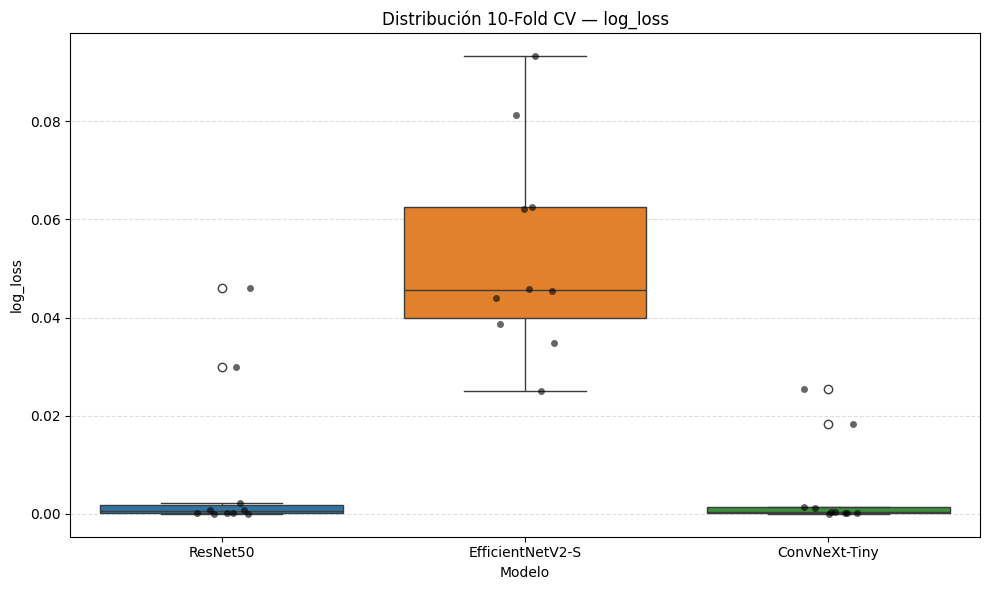

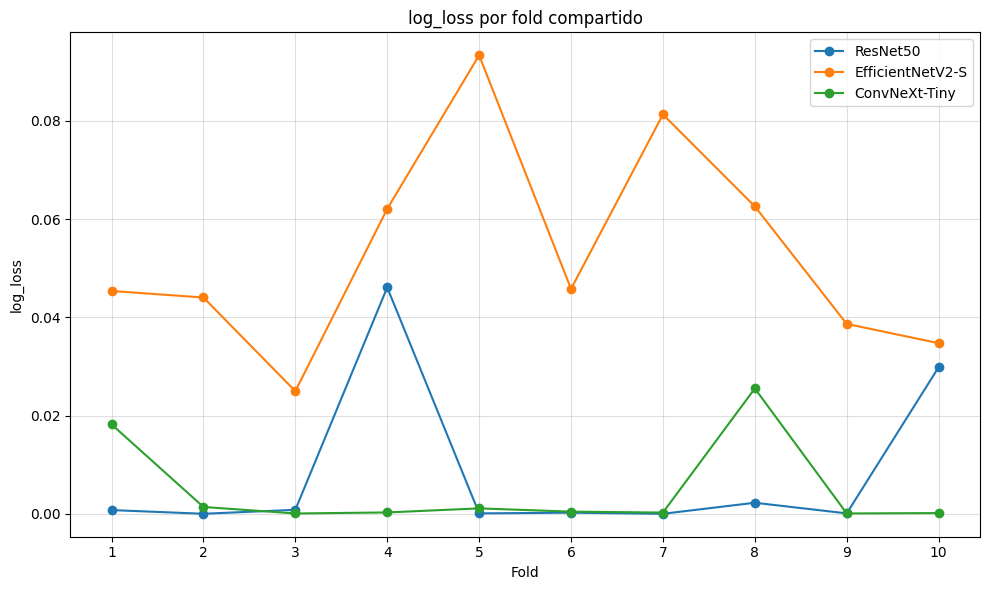

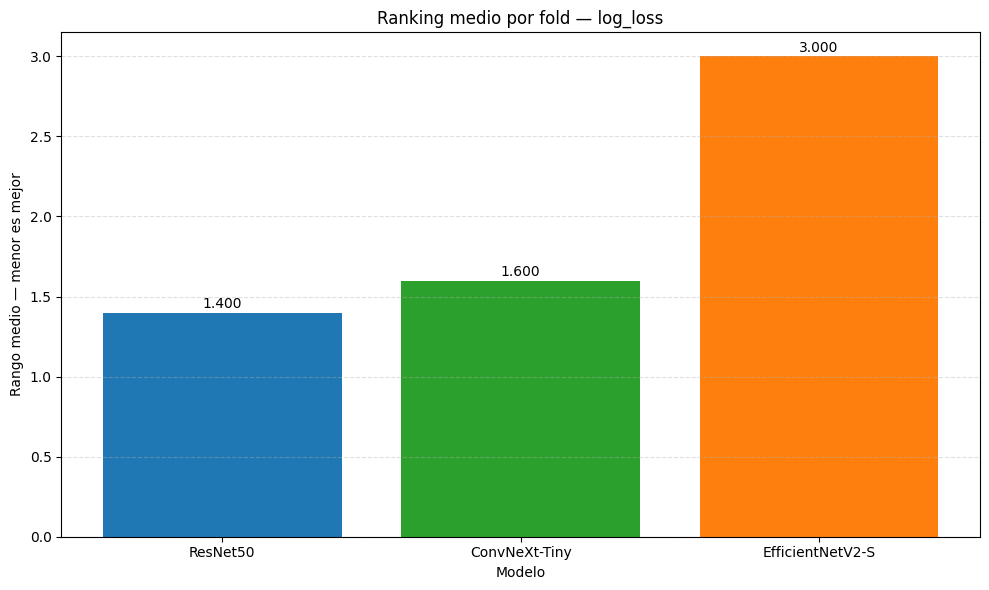

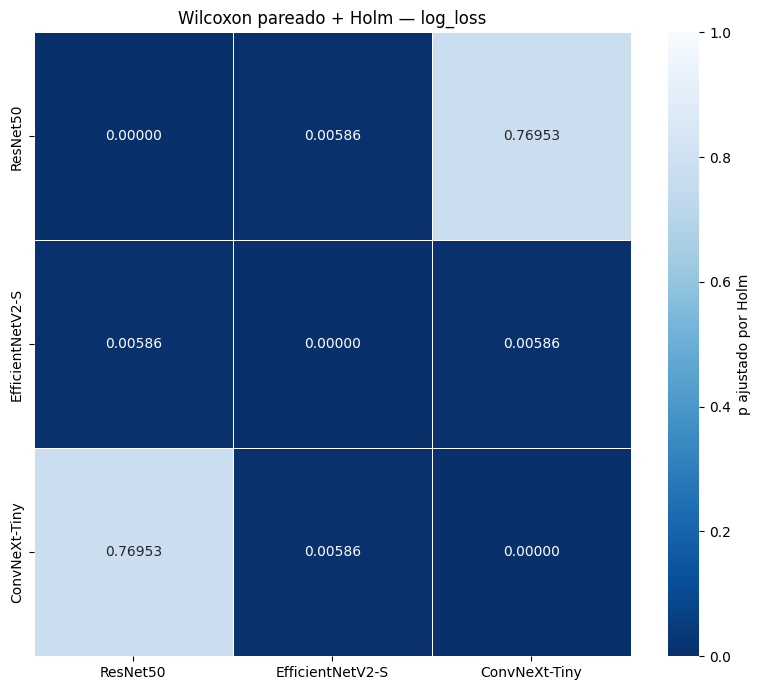

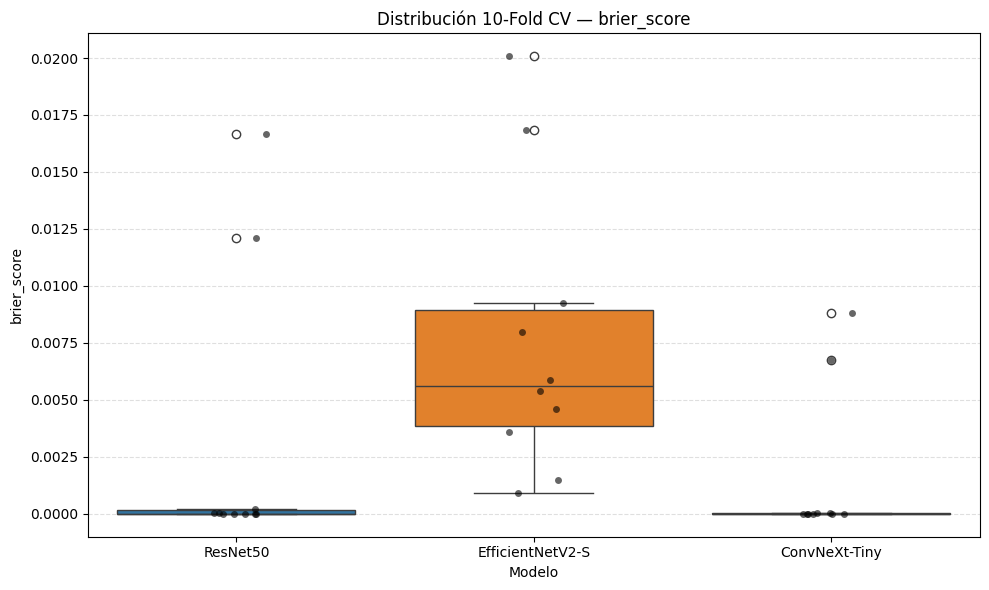

...

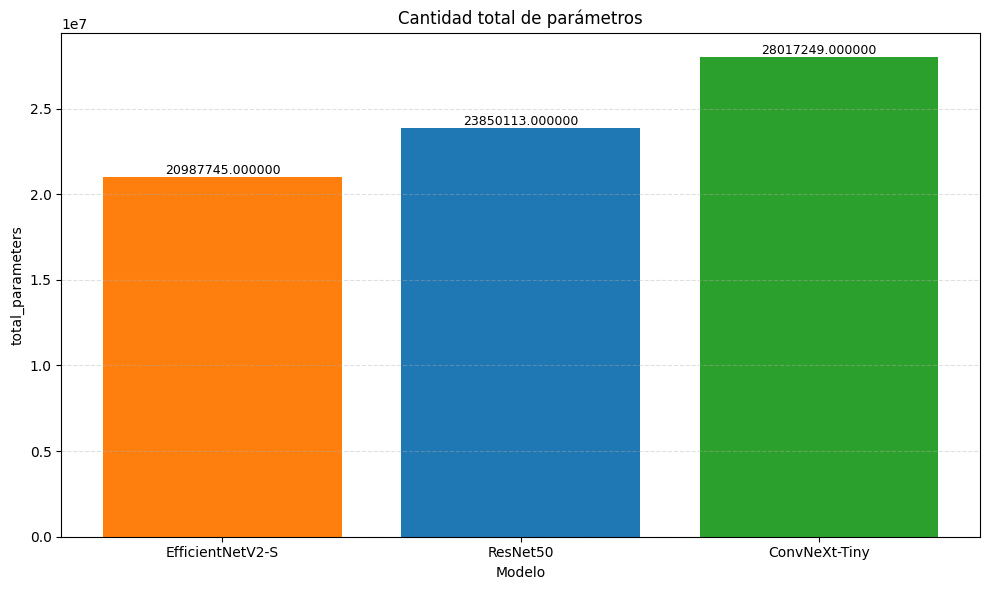

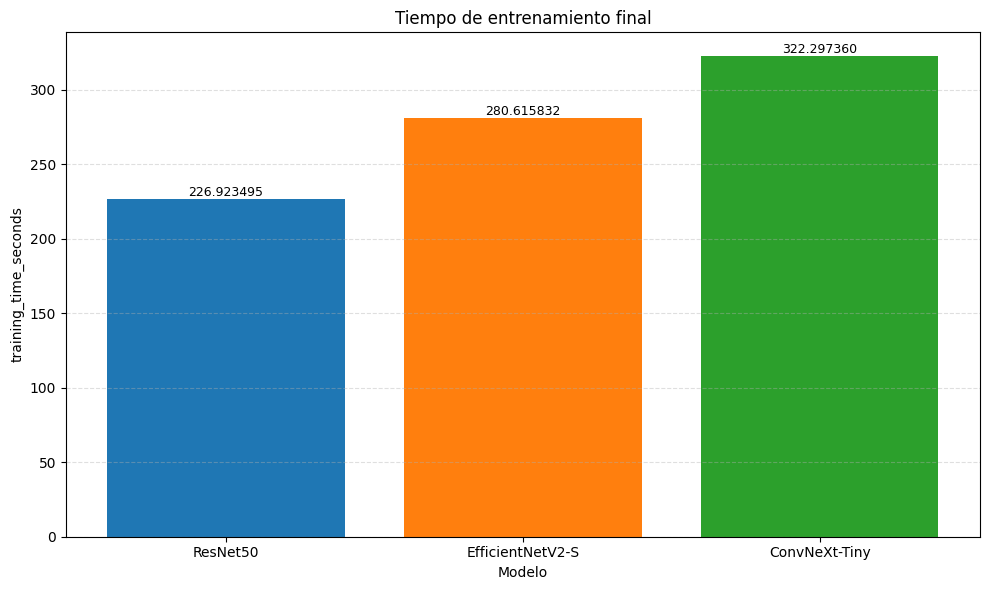

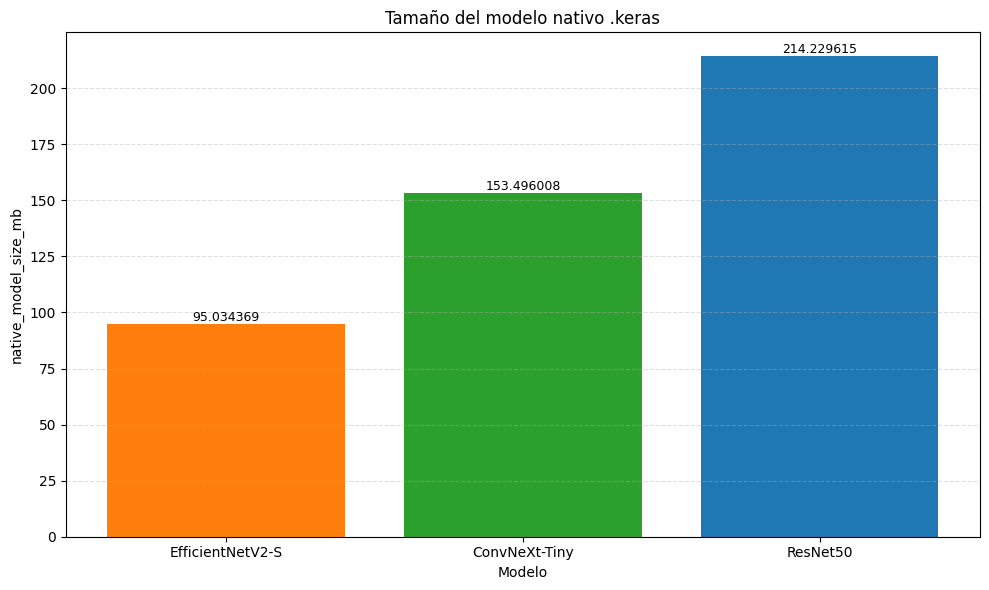

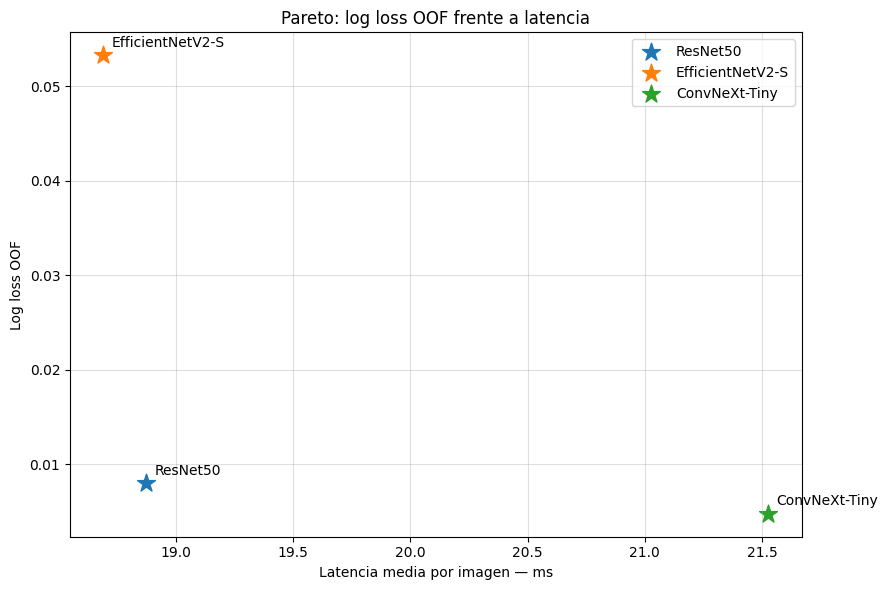

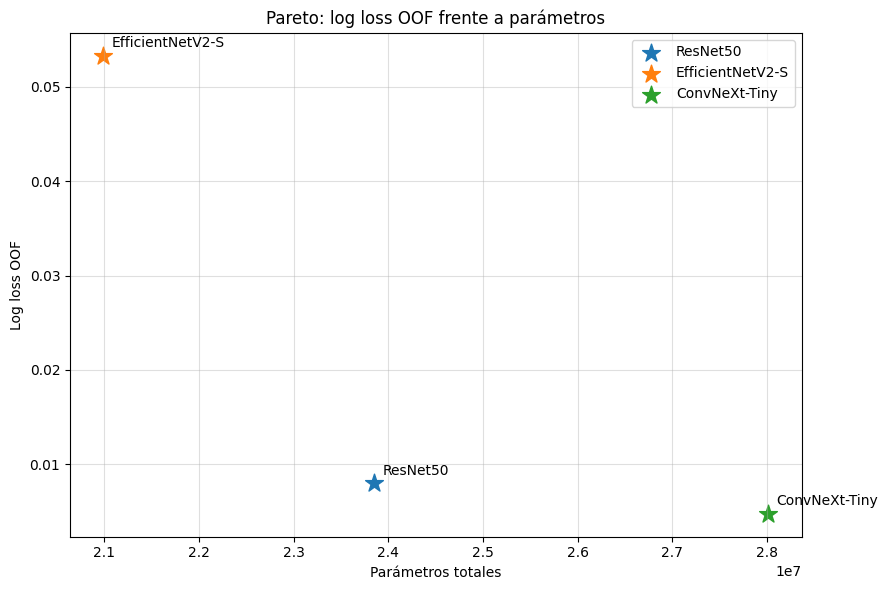


14. TABLA FINAL COMPARATIVA


,model,oof_accuracy,oof_balanced_accuracy,oof_f1_score,oof_mcc,oof_roc_auc,oof_pr_auc_average_precision,oof_log_loss,oof_brier_score,oof_ece,...,test_minimum_margin_from_threshold,test_mean_predictive_entropy_bits,test_inference_per_image_ms_mean,test_training_time_seconds,test_total_parameters,test_trainable_parameters,test_non_trainable_parameters,native_model_size_mb,all_artifacts_size_mb,hierarchical_position
0,ConvNeXt-Tiny,0.995745,0.995745,0.995763,0.991525,1.00000,1.000000,0.004749,0.001561,0.003441,...,0.261113,0.014729,21.527282,322.297360,28017249.0,12085761.0,15931488.0,153.496008,522.4904,1
1,ResNet50,0.995745,0.995745,0.995763,0.991525,1.00000,1.000000,0.008018,0.002901,0.003900,...,0.499523,0.000109,18.873171,226.923495,23850113.0,16069121.0,7780992.0,214.229615,726.2310,2
2,EfficientNetV2-S,0.995745,0.995745,0.995726,0.991525,0.99962,0.999646,0.053304,0.007601,0.039138,...,0.089905,0.185206,18.689754,280.615832,20987745.0,3474049.0,17513696.0,95.034369,456.4703,3



15. GENERANDO REPORTE INTERPRETATIVO

COMPARACIÓN COMPLETADA
Mejor modelo por log loss OOF: ConvNeXt-Tiny (0.0047493857)
Mejor modelo por log loss test: ResNet50 (0.0000082309)
Primera posición jerárquica: ConvNeXt-Tiny
Friedman log loss: p=0.00050045, Kendall W=0.76000000
Métricas OOF saturadas: ['accuracy', 'balanced_accuracy', 'mcc']

ARCHIVOS GENERADOS
----------------------------------------------------------------------------------------------------
Tablas: /content/drive/MyDrive/Tesis-Mango/Dataset Tesis2/Resultados/Comparacion_ResNet50_EfficientNetV2S_ConvNeXtTiny/tablas
Gráficos: /content/drive/MyDrive/Tesis-Mango/Dataset Tesis2/Resultados/Comparacion_ResNet50_EfficientNetV2S_ConvNeXtTiny/graficos
Reporte: /content/drive/MyDrive/Tesis-Mango/Dataset Tesis2/Resultados/Comparacion_ResNet50_EfficientNetV2S_ConvNeXtTiny/reportes/reporte_comparacion_resnet_efficientnet_convnext.txt
Auditoría: /content/drive/MyDrive/Tesis-Mango/Dataset Tesis2/Resultados/Comparacion_ResNet50_Efficien

In [ ]:
# ============================================================
# COMPARACIÓN ESTADÍSTICA EXTENDIDA DE MODELOS MONOLÍTICOS
# ============================================================
#
# MODELOS:
#   1. ResNet50
#   2. EfficientNetV2-S
#   3. ConvNeXt-Tiny
#
# PROPÓSITO:
#   Comparar los tres modelos con exactamente los resultados generados
#   por los scripts de evaluación extendida previamente creados.
#
# PRINCIPIO DE COMPARACIÓN:
#   Cuando Accuracy, F1, MCC o AUC alcanzan 1.0 en todos los modelos,
#   dejan de ser útiles para establecer diferencias. Por ello:
#
#   - Métrica principal: log loss OOF (menor es mejor).
#   - Desempates principales: Brier score, ECE, probabilidad de la
#     clase correcta, margen, entropía, latencia, parámetros y tamaño.
#   - Accuracy, F1, MCC y AUC se conservan como métricas secundarias.
#
# ANÁLISIS:
#   1. Auditoría estricta de archivos, muestras y folds compartidos.
#   2. Comparación de métricas por fold:
#        - Friedman global.
#        - Kendall's W.
#        - Wilcoxon pareado por pares.
#        - Corrección de Holm.
#   3. Comparación pareada sobre predicciones OOF:
#        - bootstrap por clusters de fold.
#        - McNemar sobre errores de clasificación.
#   4. Comparación pareada sobre test independiente:
#        - bootstrap estratificado por clase.
#        - McNemar exacto.
#   5. Curvas ROC, Precision-Recall y calibración comparadas.
#   6. Comparación de eficiencia y frentes de Pareto.
#   7. Selección jerárquica sin promediar arbitrariamente métricas.
#
# IMPORTANTE:
#   Este código no entrena modelos. Solo lee sus resultados.
# ============================================================


# ============================================================
# 1. INSTALAR DEPENDENCIAS
# ============================================================

!pip install -q scipy statsmodels seaborn


# ============================================================
# 2. IMPORTACIONES
# ============================================================

import os
import json
import math
import itertools
import warnings

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

from scipy.stats import (
    shapiro,
    friedmanchisquare,
    wilcoxon,
    t,
    binomtest,
)

from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    roc_auc_score,
    average_precision_score,
    log_loss,
    brier_score_loss,
    confusion_matrix,
    roc_curve,
    precision_recall_curve,
    auc,
)

from statsmodels.stats.multitest import multipletests

warnings.filterwarnings("ignore")


# ============================================================
# 3. CONFIGURACIÓN GENERAL
# ============================================================

# Debe existir previamente, como en los scripts de entrenamiento:
#
# ejecucion = Path(
#     "/content/drive/MyDrive/Tesis-Mango/Dataset Tesis2/Resultados"
# )

BASE_OUTPUT_DIR = Path(ejecucion)

COMPARISON_DIR = (
    BASE_OUTPUT_DIR /
    "Comparacion_ResNet50_EfficientNetV2S_ConvNeXtTiny"
)

TABLES_DIR = COMPARISON_DIR / "tablas"
PLOTS_DIR = COMPARISON_DIR / "graficos"
REPORTS_DIR = COMPARISON_DIR / "reportes"
AUDIT_DIR = COMPARISON_DIR / "auditoria"

for carpeta in [
    COMPARISON_DIR,
    TABLES_DIR,
    PLOTS_DIR,
    REPORTS_DIR,
    AUDIT_DIR,
]:
    carpeta.mkdir(parents=True, exist_ok=True)

SEED = 42
ALPHA = 0.05
N_CV_FOLDS = 10
N_BOOTSTRAP = 5000
N_CALIBRATION_BINS = 10

# La comparación debe detenerse si falta un modelo o si las muestras
# no son exactamente iguales. Los manifiestos y formatos de despliegue
# son opcionales: su ausencia no impide la comparación de resultados.
REQUIRE_ALL_MODELS = True
STRICT_SAMPLE_ALIGNMENT = True

# Métrica principal para la comparación por folds.
PRIMARY_METRIC = "log_loss"
PRIMARY_LOWER_IS_BETTER = True

CLASS_NAMES = ["Inmaduros", "Maduros"]

MODEL_ORDER = [
    "ResNet50",
    "EfficientNetV2-S",
    "ConvNeXt-Tiny",
]

# Colores consistentes tomados del ciclo predeterminado de Matplotlib.
COLORES_PREDETERMINADOS = (
    plt.rcParams["axes.prop_cycle"]
    .by_key()
    .get("color", ["C0", "C1", "C2"])
)

MODEL_COLORS = {
    modelo: COLORES_PREDETERMINADOS[indice]
    for indice, modelo in enumerate(MODEL_ORDER)
}


# ============================================================
# 4. CONFIGURACIÓN EXACTA DE LOS EXPERIMENTOS
# ============================================================

MODEL_CONFIGS = {
    "ResNet50": {
        "tag": "resnet50",
        "experiment_dir": (
            BASE_OUTPUT_DIR /
            "Experimento_ResNet50_Evaluacion_Extendida"
        ),
        "native_model_name": (
            "ResNet50_madurez_mango_final.keras"
        ),
    },

    "EfficientNetV2-S": {
        "tag": "efficientnetv2s",
        "experiment_dir": (
            BASE_OUTPUT_DIR /
            "Experimento_EfficientNetV2S_Evaluacion_Extendida"
        ),
        "native_model_name": (
            "EfficientNetV2S_madurez_mango_final.keras"
        ),
    },

    "ConvNeXt-Tiny": {
        "tag": "convnext_tiny",
        "experiment_dir": (
            BASE_OUTPUT_DIR /
            "Experimento_ConvNeXtTiny_Evaluacion_Extendida"
        ),
        "native_model_name": (
            "ConvNeXtTiny_madurez_mango_final.keras"
        ),
    },
}


for nombre_modelo, config in MODEL_CONFIGS.items():
    experiment_dir = config["experiment_dir"]
    results_dir = experiment_dir / "resultados"
    artifacts_dir = experiment_dir / "artefactos_modelo"
    tag = config["tag"]

    config.update({
        "results_dir": results_dir,
        "artifacts_dir": artifacts_dir,
        "fold_results": (
            results_dir /
            f"{tag}_resultados_10_folds.csv"
        ),
        "fold_summary": (
            results_dir /
            f"{tag}_resumen_10_folds.csv"
        ),
        "oof_metrics": (
            results_dir /
            f"{tag}_metricas_10fold_oof.csv"
        ),
        "oof_predictions": (
            results_dir /
            f"{tag}_predicciones_10fold_oof.csv"
        ),
        "test_metrics": (
            results_dir /
            f"{tag}_resultados_test.csv"
        ),
        "test_predictions": (
            results_dir /
            f"{tag}_predicciones_test.csv"
        ),
        "fold_composition": (
            results_dir /
            "composicion_10_folds.csv"
        ),
        "artifact_manifest": (
            artifacts_dir /
            "manifesto_artefactos.csv"
        ),
        "native_model": (
            artifacts_dir /
            config["native_model_name"]
        ),
    })


# ============================================================
# 5. MÉTRICAS DISPONIBLES Y SENTIDO DE OPTIMIZACIÓN
# ============================================================

# Métricas que se analizarán por fold cuando estén presentes.
# direction:
#   "min" -> menor es mejor
#   "max" -> mayor es mejor

CV_METRICS = {
    "log_loss": "min",
    "brier_score": "min",
    "ece": "min",
    "mce": "min",
    "mean_predictive_entropy_bits": "min",
    "maximum_predictive_entropy_bits": "min",
    "absolute_calibration_intercept": "min",
    "calibration_slope_distance_to_one": "min",
    "inference_time_per_image_ms": "min",
    "training_time_seconds": "min",

    "mean_correct_class_probability": "max",
    "median_correct_class_probability": "max",
    "minimum_correct_class_probability": "max",
    "mean_margin_from_threshold": "max",
    "median_margin_from_threshold": "max",
    "p05_margin_from_threshold": "max",
    "minimum_margin_from_threshold": "max",
    "ks_statistic_score_separation": "max",

    "accuracy": "max",
    "balanced_accuracy": "max",
    "precision_ppv": "max",
    "sensitivity_recall": "max",
    "specificity": "max",
    "negative_predictive_value": "max",
    "f1_score": "max",
    "f2_score": "max",
    "jaccard_index": "max",
    "mcc": "max",
    "cohen_kappa": "max",
    "youden_j_informedness": "max",
    "markedness": "max",
    "geometric_mean_sensitivity_specificity": "max",
    "fowlkes_mallows_index": "max",
    "roc_auc": "max",
    "pr_auc_average_precision": "max",
    "pr_auc_trapezoidal": "max",
}

# Métricas individuales calculadas a partir de las probabilidades.
PER_SAMPLE_METRICS = {
    "individual_log_loss": "min",
    "individual_brier_score": "min",
    "correct_class_probability": "max",
    "margin_from_threshold": "max",
    "predictive_entropy_bits": "min",
    "correct": "max",
}

# Orden jerárquico recomendado para seleccionar un modelo.
# No se suman métricas con escalas incompatibles.
SELECTION_HIERARCHY = [
    ("oof", "log_loss", "min"),
    ("oof", "brier_score", "min"),
    ("oof", "ece", "min"),
    ("oof", "mean_correct_class_probability", "max"),
    ("test", "log_loss", "min"),
    ("test", "brier_score", "min"),
    ("test", "ece", "min"),
    ("test", "inference_per_image_ms_mean", "min"),
    ("test", "total_parameters", "min"),
    ("artifact", "native_model_size_mb", "min"),
]


# ============================================================
# 6. FUNCIONES AUXILIARES
# ============================================================

def print_header(titulo):
    print("\n" + "=" * 100)
    print(titulo)
    print("=" * 100)


def safe_name(nombre):
    return (
        str(nombre)
        .replace("+", "_")
        .replace("/", "_")
        .replace(" ", "_")
        .replace("-", "_")
        .replace("(", "")
        .replace(")", "")
        .replace(".", "_")
        .replace("__", "_")
        .lower()
    )


def asegurar_columnas(dataframe, columnas, fuente):
    faltantes = [
        columna
        for columna in columnas
        if columna not in dataframe.columns
    ]

    if faltantes:
        raise KeyError(
            f"Faltan columnas en {fuente}: {faltantes}\n"
            f"Columnas disponibles: {list(dataframe.columns)}"
        )


def to_float_or_nan(valor):
    try:
        valor = float(valor)
        if np.isnan(valor):
            return np.nan
        return valor
    except Exception:
        return np.nan


def interpretacion_p(p_value, alpha=ALPHA):
    if pd.isna(p_value):
        return "No evaluable"

    if p_value < alpha:
        return "Diferencia estadísticamente significativa"

    return "Sin evidencia suficiente de diferencia"


def orientar_valor(valor, direction):
    """
    Convierte una métrica en un valor en el cual menor siempre es mejor.
    Solo se utiliza para ordenar, nunca para alterar resultados.
    """

    if pd.isna(valor):
        return np.inf

    valor = float(valor)

    if direction == "min":
        return valor

    if direction == "max":
        return -valor

    raise ValueError(f"Dirección no reconocida: {direction}")


def ganador_por_diferencia(
    modelo_a,
    modelo_b,
    diferencia_a_menos_b,
    direction,
    tolerancia=1e-12,
):
    if pd.isna(diferencia_a_menos_b):
        return "No evaluable"

    if abs(diferencia_a_menos_b) <= tolerancia:
        return "Empate"

    if direction == "min":
        return (
            modelo_a
            if diferencia_a_menos_b < 0
            else modelo_b
        )

    return (
        modelo_a
        if diferencia_a_menos_b > 0
        else modelo_b
    )


def intervalo_t_media(valores, confidence=0.95):
    valores = np.asarray(valores, dtype=float)
    valores = valores[np.isfinite(valores)]

    n = len(valores)

    if n == 0:
        return np.nan, np.nan

    media = float(np.mean(valores))

    if n == 1:
        return np.nan, np.nan

    sd = float(np.std(valores, ddof=1))
    se = sd / math.sqrt(n)
    cuant = t.ppf((1.0 + confidence) / 2.0, df=n - 1)

    return (
        float(media - cuant * se),
        float(media + cuant * se),
    )


def entropia_binaria(probabilidades):
    p = np.clip(
        np.asarray(probabilidades, dtype=float),
        1e-12,
        1.0 - 1e-12,
    )

    return -(
        p * np.log2(p)
        +
        (1.0 - p) * np.log2(1.0 - p)
    )


def perdida_logaritmica_individual(y_true, y_score):
    y_true = np.asarray(y_true, dtype=float)
    p = np.clip(
        np.asarray(y_score, dtype=float),
        1e-7,
        1.0 - 1e-7,
    )

    return -(
        y_true * np.log(p)
        +
        (1.0 - y_true) * np.log(1.0 - p)
    )


def calcular_ece_mce(y_true, y_score, n_bins=10):
    y_true = np.asarray(y_true).astype(int)
    y_score = np.asarray(y_score).astype(float)

    predicciones = (y_score >= 0.5).astype(int)
    confianza = np.maximum(y_score, 1.0 - y_score)
    aciertos = (predicciones == y_true).astype(float)

    bordes = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    mce = 0.0

    for indice in range(n_bins):
        izquierda = bordes[indice]
        derecha = bordes[indice + 1]

        if indice == n_bins - 1:
            mascara = (
                (confianza >= izquierda)
                &
                (confianza <= derecha)
            )
        else:
            mascara = (
                (confianza >= izquierda)
                &
                (confianza < derecha)
            )

        cantidad = int(mascara.sum())

        if cantidad == 0:
            continue

        confianza_media = float(confianza[mascara].mean())
        accuracy_bin = float(aciertos[mascara].mean())
        gap = abs(accuracy_bin - confianza_media)

        ece += cantidad / len(y_true) * gap
        mce = max(mce, gap)

    return float(ece), float(mce)


def calcular_metricas_desde_predicciones(y_true, y_pred, y_score):
    y_true = np.asarray(y_true).astype(int)
    y_pred = np.asarray(y_pred).astype(int)
    y_score = np.asarray(y_score).astype(float)

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    especificidad = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    probabilidades_correctas = np.where(
        y_true == 1,
        y_score,
        1.0 - y_score,
    )

    margenes = np.abs(y_score - 0.5)
    entropias = entropia_binaria(y_score)
    ece, mce = calcular_ece_mce(
        y_true,
        y_score,
        n_bins=N_CALIBRATION_BINS,
    )

    metricas = {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "balanced_accuracy": float(
            balanced_accuracy_score(y_true, y_pred)
        ),
        "precision_ppv": float(
            precision_score(
                y_true,
                y_pred,
                pos_label=1,
                zero_division=0,
            )
        ),
        "sensitivity_recall": float(
            recall_score(
                y_true,
                y_pred,
                pos_label=1,
                zero_division=0,
            )
        ),
        "specificity": float(especificidad),
        "f1_score": float(
            f1_score(
                y_true,
                y_pred,
                pos_label=1,
                zero_division=0,
            )
        ),
        "mcc": float(matthews_corrcoef(y_true, y_pred)),
        "log_loss": float(
            log_loss(y_true, y_score, labels=[0, 1])
        ),
        "brier_score": float(
            brier_score_loss(y_true, y_score)
        ),
        "ece": ece,
        "mce": mce,
        "mean_correct_class_probability": float(
            probabilidades_correctas.mean()
        ),
        "minimum_correct_class_probability": float(
            probabilidades_correctas.min()
        ),
        "mean_margin_from_threshold": float(margenes.mean()),
        "minimum_margin_from_threshold": float(margenes.min()),
        "mean_predictive_entropy_bits": float(entropias.mean()),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),
    }

    if len(np.unique(y_true)) == 2:
        metricas["roc_auc"] = float(
            roc_auc_score(y_true, y_score)
        )
        metricas["pr_auc_average_precision"] = float(
            average_precision_score(y_true, y_score)
        )
    else:
        metricas["roc_auc"] = np.nan
        metricas["pr_auc_average_precision"] = np.nan

    return metricas


# ============================================================
# 7. AUDITORÍA DE RUTAS Y ARCHIVOS
# ============================================================

print_header("1. AUDITORÍA DE ARCHIVOS DE RESULTADOS")

ruta_registros = []

for modelo in MODEL_ORDER:
    config = MODEL_CONFIGS[modelo]

    registro = {
        "model": modelo,
        "experiment_dir": str(config["experiment_dir"]),
    }

    for clave in [
        "fold_results",
        "oof_metrics",
        "oof_predictions",
        "test_metrics",
        "test_predictions",
        "fold_composition",
        "artifact_manifest",
        "native_model",
    ]:
        ruta = Path(config[clave])
        registro[f"{clave}_path"] = str(ruta)
        registro[f"{clave}_exists"] = bool(ruta.exists())

    ruta_registros.append(registro)

rutas_df = pd.DataFrame(ruta_registros)

display(rutas_df)

rutas_df.to_csv(
    AUDIT_DIR / "auditoria_rutas_modelos.csv",
    index=False,
    encoding="utf-8-sig",
)

archivos_criticos = [
    "fold_results_exists",
    "oof_metrics_exists",
    "oof_predictions_exists",
    "test_metrics_exists",
    "test_predictions_exists",
]

faltan_criticos = rutas_df[
    ~rutas_df[archivos_criticos].all(axis=1)
]

if REQUIRE_ALL_MODELS and len(faltan_criticos) > 0:
    raise FileNotFoundError(
        "Faltan archivos de resultados críticos de uno o más modelos. "
        "Los manifiestos, TFLite y ONNX no son necesarios.\n\n"
        f"{faltan_criticos.to_string(index=False)}"
    )


# ============================================================
# 8. CARGAR RESULTADOS DE FOLDS, OOF Y TEST
# ============================================================

print_header("2. CARGANDO RESULTADOS DE LOS TRES MODELOS")

fold_results_dict = {}
oof_metrics_dict = {}
test_metrics_dict = {}
oof_predictions_dict = {}
test_predictions_dict = {}

for modelo in MODEL_ORDER:
    config = MODEL_CONFIGS[modelo]

    if not config["fold_results"].exists():
        continue

    df_folds = pd.read_csv(config["fold_results"])
    df_oof_metrics = pd.read_csv(config["oof_metrics"])
    df_test_metrics = pd.read_csv(config["test_metrics"])
    df_oof_pred = pd.read_csv(config["oof_predictions"])
    df_test_pred = pd.read_csv(config["test_predictions"])

    # Distancias a los valores ideales de calibración.
    # Intercepto ideal = 0; pendiente ideal = 1.
    if "calibration_intercept" in df_folds.columns:
        df_folds["absolute_calibration_intercept"] = np.abs(
            pd.to_numeric(
                df_folds["calibration_intercept"],
                errors="coerce",
            )
        )

    if "calibration_slope" in df_folds.columns:
        df_folds["calibration_slope_distance_to_one"] = np.abs(
            pd.to_numeric(
                df_folds["calibration_slope"],
                errors="coerce",
            )
            - 1.0
        )

    asegurar_columnas(
        df_folds,
        ["fold", PRIMARY_METRIC],
        config["fold_results"],
    )

    asegurar_columnas(
        df_oof_pred,
        [
            "filepath",
            "y_true",
            "y_pred",
            "probability_maduro",
            "fold",
        ],
        config["oof_predictions"],
    )

    asegurar_columnas(
        df_test_pred,
        [
            "filepath",
            "y_true",
            "y_pred",
            "probability_maduro",
        ],
        config["test_predictions"],
    )

    # Columnas derivadas para uniformidad.
    for dataframe in [df_oof_pred, df_test_pred]:
        dataframe["filepath"] = dataframe["filepath"].astype(str)
        dataframe["y_true"] = dataframe["y_true"].astype(int)
        dataframe["y_pred"] = dataframe["y_pred"].astype(int)
        dataframe["probability_maduro"] = (
            dataframe["probability_maduro"].astype(float)
        )

        dataframe["individual_log_loss"] = (
            perdida_logaritmica_individual(
                dataframe["y_true"].values,
                dataframe["probability_maduro"].values,
            )
        )

        dataframe["individual_brier_score"] = (
            dataframe["y_true"].values
            -
            dataframe["probability_maduro"].values
        ) ** 2

        dataframe["correct_class_probability"] = np.where(
            dataframe["y_true"].values == 1,
            dataframe["probability_maduro"].values,
            1.0 - dataframe["probability_maduro"].values,
        )

        dataframe["margin_from_threshold"] = np.abs(
            dataframe["probability_maduro"].values - 0.5
        )

        dataframe["predictive_entropy_bits"] = entropia_binaria(
            dataframe["probability_maduro"].values
        )

        dataframe["correct"] = (
            dataframe["y_true"].values
            ==
            dataframe["y_pred"].values
        ).astype(int)

    fold_results_dict[modelo] = df_folds
    oof_metrics_dict[modelo] = df_oof_metrics
    test_metrics_dict[modelo] = df_test_metrics
    oof_predictions_dict[modelo] = df_oof_pred
    test_predictions_dict[modelo] = df_test_pred

    print(
        f"{modelo}: "
        f"{len(df_folds)} folds, "
        f"{len(df_oof_pred)} OOF, "
        f"{len(df_test_pred)} test"
    )


modelos_disponibles = [
    modelo
    for modelo in MODEL_ORDER
    if modelo in fold_results_dict
]

if len(modelos_disponibles) < 3:
    raise ValueError(
        "La comparación de Friedman requiere los tres modelos. "
        f"Solo se cargaron: {modelos_disponibles}"
    )


# ============================================================
# 9. AUDITORÍA ESTRICTA DE MUESTRAS Y FOLDS COMPARTIDOS
# ============================================================

print_header("3. AUDITORÍA DE MUESTRAS Y FOLDS COMPARTIDOS")

referencia_modelo = modelos_disponibles[0]
referencia_oof = (
    oof_predictions_dict[referencia_modelo]
    .sort_values("filepath")
    .reset_index(drop=True)
)
referencia_test = (
    test_predictions_dict[referencia_modelo]
    .sort_values("filepath")
    .reset_index(drop=True)
)

alineacion_registros = []

for modelo in modelos_disponibles:
    df_oof = (
        oof_predictions_dict[modelo]
        .sort_values("filepath")
        .reset_index(drop=True)
    )

    df_test = (
        test_predictions_dict[modelo]
        .sort_values("filepath")
        .reset_index(drop=True)
    )

    duplicados_oof = bool(df_oof["filepath"].duplicated().any())
    duplicados_test = bool(df_test["filepath"].duplicated().any())

    mismas_rutas_oof = np.array_equal(
        referencia_oof["filepath"].values,
        df_oof["filepath"].values,
    )

    mismas_etiquetas_oof = (
        mismas_rutas_oof
        and
        np.array_equal(
            referencia_oof["y_true"].values,
            df_oof["y_true"].values,
        )
    )

    mismos_folds_oof = (
        mismas_rutas_oof
        and
        np.array_equal(
            referencia_oof["fold"].astype(int).values,
            df_oof["fold"].astype(int).values,
        )
    )

    mismas_rutas_test = np.array_equal(
        referencia_test["filepath"].values,
        df_test["filepath"].values,
    )

    mismas_etiquetas_test = (
        mismas_rutas_test
        and
        np.array_equal(
            referencia_test["y_true"].values,
            df_test["y_true"].values,
        )
    )

    folds_reportados = sorted(
        df_oof["fold"].astype(int).unique().tolist()
    )

    alineacion_registros.append({
        "model": modelo,
        "oof_images": int(len(df_oof)),
        "test_images": int(len(df_test)),
        "duplicate_oof_filepaths": duplicados_oof,
        "duplicate_test_filepaths": duplicados_test,
        "same_oof_filepaths_as_reference": mismas_rutas_oof,
        "same_oof_labels_as_reference": mismas_etiquetas_oof,
        "same_oof_fold_assignment_as_reference": mismos_folds_oof,
        "same_test_filepaths_as_reference": mismas_rutas_test,
        "same_test_labels_as_reference": mismas_etiquetas_test,
        "folds_reported": json.dumps(folds_reportados),
        "expected_folds_1_to_10": (
            folds_reportados
            ==
            list(range(1, N_CV_FOLDS + 1))
        ),
    })

alineacion_df = pd.DataFrame(alineacion_registros)

display(alineacion_df)

alineacion_df.to_csv(
    AUDIT_DIR / "auditoria_alineacion_muestras_folds.csv",
    index=False,
    encoding="utf-8-sig",
)

columnas_alineacion = [
    "same_oof_filepaths_as_reference",
    "same_oof_labels_as_reference",
    "same_oof_fold_assignment_as_reference",
    "same_test_filepaths_as_reference",
    "same_test_labels_as_reference",
    "expected_folds_1_to_10",
]

alineacion_correcta = bool(
    alineacion_df[
        columnas_alineacion
    ].to_numpy(dtype=bool).all()
)

sin_duplicados = bool(
    (~alineacion_df[
        [
            "duplicate_oof_filepaths",
            "duplicate_test_filepaths",
        ]
    ]).to_numpy(dtype=bool).all()
)

if STRICT_SAMPLE_ALIGNMENT and not (alineacion_correcta and sin_duplicados):
    raise ValueError(
        "Los modelos no utilizaron exactamente las mismas muestras "
        "o los mismos folds. No es válido aplicar comparaciones pareadas."
    )

print(
    "Auditoría correcta: los tres modelos utilizaron exactamente "
    "las mismas imágenes OOF, folds y muestras de test."
)


# ============================================================
# 10. PREPARAR TABLAS DE MÉTRICAS POR FOLD
# ============================================================

print_header("4. PREPARANDO MÉTRICAS POR FOLD")

fold_long_rows = []
metricas_cv_disponibles = []

for metrica, direction in CV_METRICS.items():
    presente_en_todos = all(
        metrica in fold_results_dict[modelo].columns
        for modelo in modelos_disponibles
    )

    if not presente_en_todos:
        continue

    metricas_cv_disponibles.append(metrica)

    for modelo in modelos_disponibles:
        df_modelo = fold_results_dict[modelo]

        for _, fila in df_modelo.iterrows():
            fold_long_rows.append({
                "model": modelo,
                "fold": int(fila["fold"]),
                "metric": metrica,
                "direction": direction,
                "value": to_float_or_nan(fila[metrica]),
            })

fold_long_df = pd.DataFrame(fold_long_rows)
fold_long_df = fold_long_df.dropna(subset=["value"])

fold_long_df.to_csv(
    TABLES_DIR / "metricas_por_fold_formato_largo.csv",
    index=False,
    encoding="utf-8-sig",
)

print(
    "Métricas presentes en los tres modelos:",
    metricas_cv_disponibles,
)


# ============================================================
# 11. ESTADÍSTICOS DESCRIPTIVOS POR FOLD
# ============================================================

print_header("5. ESTADÍSTICOS DESCRIPTIVOS POR FOLD")

descriptivos_rows = []
normalidad_rows = []

for metrica in metricas_cv_disponibles:
    direction = CV_METRICS[metrica]

    for modelo in modelos_disponibles:
        valores = (
            fold_long_df[
                (fold_long_df["metric"] == metrica)
                &
                (fold_long_df["model"] == modelo)
            ]["value"]
            .astype(float)
            .values
        )

        if len(valores) == 0:
            continue

        ci_low, ci_high = intervalo_t_media(valores)

        descriptivos_rows.append({
            "metric": metrica,
            "direction": direction,
            "model": modelo,
            "n_folds": int(len(valores)),
            "mean": float(np.mean(valores)),
            "std": float(
                np.std(valores, ddof=1)
                if len(valores) > 1
                else 0.0
            ),
            "median": float(np.median(valores)),
            "q1": float(np.percentile(valores, 25)),
            "q3": float(np.percentile(valores, 75)),
            "min": float(np.min(valores)),
            "max": float(np.max(valores)),
            "ci95_lower_descriptive": ci_low,
            "ci95_upper_descriptive": ci_high,
        })

        if len(valores) >= 3 and not np.allclose(
            valores,
            valores[0],
            rtol=0.0,
            atol=1e-15,
        ):
            shapiro_stat, shapiro_p = shapiro(valores)
        else:
            shapiro_stat, shapiro_p = np.nan, np.nan

        normalidad_rows.append({
            "metric": metrica,
            "model": modelo,
            "shapiro_w": shapiro_stat,
            "p_value": shapiro_p,
            "interpretation": interpretacion_p(shapiro_p),
            "constant_values": bool(
                np.allclose(
                    valores,
                    valores[0],
                    rtol=0.0,
                    atol=1e-15,
                )
            ),
        })


descriptivos_cv_df = pd.DataFrame(descriptivos_rows)
normalidad_cv_df = pd.DataFrame(normalidad_rows)

descriptivos_cv_df.to_csv(
    TABLES_DIR / "descriptivos_metricas_por_fold.csv",
    index=False,
    encoding="utf-8-sig",
)

normalidad_cv_df.to_csv(
    TABLES_DIR / "normalidad_shapiro_por_fold.csv",
    index=False,
    encoding="utf-8-sig",
)

print("Descriptivos de la métrica principal:")
display(
    descriptivos_cv_df[
        descriptivos_cv_df["metric"] == PRIMARY_METRIC
    ]
)


# ============================================================
# 12. FRIEDMAN, KENDALL W Y WILCOXON-HOLM
# ============================================================

print_header("6. FRIEDMAN GLOBAL Y WILCOXON-HOLM")

friedman_rows = []
posthoc_rows = []
rank_rows = []

wide_tables = {}

for metrica in metricas_cv_disponibles:
    direction = CV_METRICS[metrica]

    df_metric = fold_long_df[
        fold_long_df["metric"] == metrica
    ].copy()

    df_wide = (
        df_metric
        .pivot(index="fold", columns="model", values="value")
        .sort_index()
    )

    df_wide = df_wide[modelos_disponibles].dropna(how="any")
    wide_tables[metrica] = df_wide

    if len(df_wide) == 0:
        continue

    matrices_iguales = all(
        np.allclose(
            df_wide[modelos_disponibles[0]].values,
            df_wide[modelo].values,
            rtol=0.0,
            atol=1e-15,
        )
        for modelo in modelos_disponibles[1:]
    )

    if matrices_iguales:
        friedman_stat = 0.0
        friedman_p = 1.0
        kendalls_w = 0.0
        estado = "Métrica completamente empatada/saturada"
    else:
        arreglos = [
            df_wide[modelo].astype(float).values
            for modelo in modelos_disponibles
        ]

        friedman_stat, friedman_p = friedmanchisquare(*arreglos)

        n_folds = df_wide.shape[0]
        k_models = df_wide.shape[1]

        kendalls_w = float(
            friedman_stat /
            (n_folds * (k_models - 1))
        )

        estado = "Evaluable"

    friedman_rows.append({
        "metric": metrica,
        "direction": direction,
        "n_folds": int(df_wide.shape[0]),
        "n_models": int(df_wide.shape[1]),
        "friedman_chi2": float(friedman_stat),
        "p_value": float(friedman_p),
        "kendalls_w": float(kendalls_w),
        "interpretation": interpretacion_p(friedman_p),
        "status": estado,
    })

    # Ranking por fold.
    rank_ascending = direction == "min"
    rank_df = df_wide.rank(
        axis=1,
        ascending=rank_ascending,
        method="average",
    )

    for modelo in modelos_disponibles:
        rank_rows.append({
            "metric": metrica,
            "direction": direction,
            "model": modelo,
            "mean_rank": float(rank_df[modelo].mean()),
            "median_rank": float(rank_df[modelo].median()),
        })

    # Comparaciones pareadas Wilcoxon.
    filas_metrica = []

    for modelo_a, modelo_b in itertools.combinations(
        modelos_disponibles,
        2,
    ):
        valores_a = df_wide[modelo_a].astype(float).values
        valores_b = df_wide[modelo_b].astype(float).values
        diferencia = valores_a - valores_b

        if np.allclose(
            diferencia,
            0.0,
            rtol=0.0,
            atol=1e-15,
        ):
            wilcoxon_stat = 0.0
            p_raw = 1.0
            status = "Todos los folds empatados"
        else:
            try:
                resultado = wilcoxon(
                    valores_a,
                    valores_b,
                    zero_method="zsplit",
                    correction=False,
                    alternative="two-sided",
                    method="auto",
                )
                wilcoxon_stat = float(resultado.statistic)
                p_raw = float(resultado.pvalue)
                status = "Evaluable"
            except Exception as error:
                wilcoxon_stat = np.nan
                p_raw = np.nan
                status = f"No evaluable: {error}"

        filas_metrica.append({
            "metric": metrica,
            "direction": direction,
            "model_a": modelo_a,
            "model_b": modelo_b,
            "mean_a": float(np.mean(valores_a)),
            "mean_b": float(np.mean(valores_b)),
            "mean_diff_a_minus_b": float(np.mean(diferencia)),
            "median_diff_a_minus_b": float(np.median(diferencia)),
            "folds_a_better": int(
                np.sum(
                    diferencia < 0
                    if direction == "min"
                    else diferencia > 0
                )
            ),
            "folds_b_better": int(
                np.sum(
                    diferencia > 0
                    if direction == "min"
                    else diferencia < 0
                )
            ),
            "folds_tied": int(np.sum(np.isclose(diferencia, 0.0))),
            "wilcoxon_statistic": wilcoxon_stat,
            "p_raw": p_raw,
            "winner_by_mean": ganador_por_diferencia(
                modelo_a,
                modelo_b,
                float(np.mean(diferencia)),
                direction,
            ),
            "status": status,
        })

    filas_metrica_df = pd.DataFrame(filas_metrica)
    mascara = filas_metrica_df["p_raw"].notna()

    if mascara.sum() > 0:
        reject, p_adj, _, _ = multipletests(
            filas_metrica_df.loc[mascara, "p_raw"].values,
            alpha=ALPHA,
            method="holm",
        )

        filas_metrica_df.loc[
            mascara,
            "p_adjusted_holm",
        ] = p_adj

        filas_metrica_df.loc[
            mascara,
            "significant_holm",
        ] = reject
    else:
        filas_metrica_df["p_adjusted_holm"] = np.nan
        filas_metrica_df["significant_holm"] = False

    filas_metrica_df["interpretation_holm"] = (
        filas_metrica_df["p_adjusted_holm"]
        .apply(interpretacion_p)
    )

    posthoc_rows.extend(
        filas_metrica_df.to_dict(orient="records")
    )

friedman_df = pd.DataFrame(friedman_rows)
posthoc_df = pd.DataFrame(posthoc_rows)
rank_summary_df = pd.DataFrame(rank_rows)

friedman_df.to_csv(
    TABLES_DIR / "friedman_todas_las_metricas.csv",
    index=False,
    encoding="utf-8-sig",
)

posthoc_df.to_csv(
    TABLES_DIR / "wilcoxon_holm_todas_las_metricas.csv",
    index=False,
    encoding="utf-8-sig",
)

rank_summary_df.to_csv(
    TABLES_DIR / "ranking_promedio_por_metrica.csv",
    index=False,
    encoding="utf-8-sig",
)

print("Friedman para métricas principales:")
display(
    friedman_df[
        friedman_df["metric"].isin([
            "log_loss",
            "brier_score",
            "ece",
            "accuracy",
            "f1_score",
            "roc_auc",
        ])
    ]
)

print("Post hoc para log loss:")
display(
    posthoc_df[
        posthoc_df["metric"] == "log_loss"
    ]
)


# ============================================================
# 13. CARGAR Y VALIDAR MÉTRICAS OOF Y TEST
# ============================================================

print_header("7. RESÚMENES OOF Y TEST")

resumen_oof_rows = []
resumen_test_rows = []

for modelo in modelos_disponibles:
    oof_pred = oof_predictions_dict[modelo]
    test_pred = test_predictions_dict[modelo]

    metricas_oof_calculadas = calcular_metricas_desde_predicciones(
        oof_pred["y_true"].values,
        oof_pred["y_pred"].values,
        oof_pred["probability_maduro"].values,
    )

    metricas_test_calculadas = calcular_metricas_desde_predicciones(
        test_pred["y_true"].values,
        test_pred["y_pred"].values,
        test_pred["probability_maduro"].values,
    )

    fila_oof_original = (
        oof_metrics_dict[modelo]
        .iloc[0]
        .to_dict()
    )

    fila_test_original = (
        test_metrics_dict[modelo]
        .iloc[0]
        .to_dict()
    )

    fila_oof = {
        "model": modelo,
        "n_images": int(len(oof_pred)),
        **metricas_oof_calculadas,
    }

    fila_test = {
        "model": modelo,
        "n_images": int(len(test_pred)),
        **metricas_test_calculadas,
    }

    # Conservar métricas computacionales provenientes del archivo test.
    for columna in [
        "training_time_seconds",
        "inference_total_seconds_mean",
        "inference_total_seconds_std",
        "inference_total_seconds_median",
        "inference_per_image_ms_mean",
        "inference_per_image_ms_median",
        "inference_per_image_ms_p95_repetition",
        "total_parameters",
        "trainable_parameters",
        "non_trainable_parameters",
        "epochs",
    ]:
        if columna in fila_test_original:
            fila_test[columna] = to_float_or_nan(
                fila_test_original[columna]
            )

    # Agregar todas las métricas adicionales del archivo, si existen.
    for clave, valor in fila_oof_original.items():
        if clave not in fila_oof:
            fila_oof[clave] = valor

    for clave, valor in fila_test_original.items():
        if clave not in fila_test:
            fila_test[clave] = valor

    resumen_oof_rows.append(fila_oof)
    resumen_test_rows.append(fila_test)

resumen_oof_df = pd.DataFrame(resumen_oof_rows)
resumen_test_df = pd.DataFrame(resumen_test_rows)

resumen_oof_df.to_csv(
    TABLES_DIR / "resumen_comparativo_oof.csv",
    index=False,
    encoding="utf-8-sig",
)

resumen_test_df.to_csv(
    TABLES_DIR / "resumen_comparativo_test.csv",
    index=False,
    encoding="utf-8-sig",
)

print("Resumen OOF:")
display(
    resumen_oof_df[
        [
            "model",
            "accuracy",
            "f1_score",
            "mcc",
            "roc_auc",
            "pr_auc_average_precision",
            "log_loss",
            "brier_score",
            "ece",
            "mean_correct_class_probability",
            "minimum_correct_class_probability",
        ]
    ]
)

print("Resumen test:")
columnas_test_mostrar = [
    "model",
    "accuracy",
    "f1_score",
    "mcc",
    "roc_auc",
    "pr_auc_average_precision",
    "log_loss",
    "brier_score",
    "ece",
    "mean_correct_class_probability",
    "minimum_correct_class_probability",
    "inference_per_image_ms_mean",
    "total_parameters",
]

columnas_test_mostrar = [
    columna
    for columna in columnas_test_mostrar
    if columna in resumen_test_df.columns
]

display(resumen_test_df[columnas_test_mostrar])


# ============================================================
# 14. TAMAÑOS DE ARTEFACTOS
# ============================================================

print_header("8. TAMAÑO DE LOS ARTEFACTOS")

artefactos_rows = []

for modelo in modelos_disponibles:
    config = MODEL_CONFIGS[modelo]
    ruta_modelo = config["native_model"]
    ruta_manifiesto = config["artifact_manifest"]

    tamaño_nativo_mb = (
        ruta_modelo.stat().st_size / (1024 ** 2)
        if ruta_modelo.exists()
        else np.nan
    )

    tamaño_total_mb = np.nan
    cantidad_archivos = np.nan

    if ruta_manifiesto.exists():
        manifiesto = pd.read_csv(ruta_manifiesto)

        if "size_mb" in manifiesto.columns:
            tamaño_total_mb = float(
                manifiesto["size_mb"].astype(float).sum()
            )

        cantidad_archivos = int(len(manifiesto))

    artefactos_rows.append({
        "model": modelo,
        "native_model_size_mb": tamaño_nativo_mb,
        "all_artifacts_size_mb": tamaño_total_mb,
        "artifact_file_count": cantidad_archivos,
        "native_model_path": str(ruta_modelo),
    })

artefactos_df = pd.DataFrame(artefactos_rows)

artefactos_df.to_csv(
    TABLES_DIR / "comparacion_tamaño_artefactos.csv",
    index=False,
    encoding="utf-8-sig",
)

display(artefactos_df)


# ============================================================
# 15. BOOTSTRAP PAREADO
# ============================================================

def bootstrap_indices_estratificados(
    y_true,
    rng,
):
    y_true = np.asarray(y_true).astype(int)
    indices_finales = []

    for clase in np.unique(y_true):
        indices_clase = np.where(y_true == clase)[0]
        muestra = rng.choice(
            indices_clase,
            size=len(indices_clase),
            replace=True,
        )
        indices_finales.extend(muestra.tolist())

    indices_finales = np.asarray(indices_finales, dtype=int)
    rng.shuffle(indices_finales)
    return indices_finales


def bootstrap_indices_por_fold(
    folds,
    rng,
):
    folds = np.asarray(folds).astype(int)
    folds_unicos = np.unique(folds)

    folds_muestreados = rng.choice(
        folds_unicos,
        size=len(folds_unicos),
        replace=True,
    )

    indices_finales = []

    for fold in folds_muestreados:
        indices_fold = np.where(folds == fold)[0]
        indices_finales.extend(indices_fold.tolist())

    return np.asarray(indices_finales, dtype=int)


def bootstrap_pareado_diferencia(
    valores_a,
    valores_b,
    direction,
    mode,
    y_true=None,
    folds=None,
    n_bootstrap=N_BOOTSTRAP,
    seed=SEED,
):
    valores_a = np.asarray(valores_a, dtype=float)
    valores_b = np.asarray(valores_b, dtype=float)

    if len(valores_a) != len(valores_b):
        raise ValueError("Los vectores pareados tienen longitudes diferentes.")

    rng = np.random.default_rng(seed)
    diferencias_bootstrap = []

    for _ in range(n_bootstrap):
        if mode == "stratified_test":
            indices = bootstrap_indices_estratificados(
                y_true,
                rng,
            )
        elif mode == "cluster_fold":
            indices = bootstrap_indices_por_fold(
                folds,
                rng,
            )
        else:
            raise ValueError(f"Modo bootstrap no reconocido: {mode}")

        diferencia = float(
            np.mean(valores_a[indices])
            -
            np.mean(valores_b[indices])
        )

        diferencias_bootstrap.append(diferencia)

    diferencias_bootstrap = np.asarray(
        diferencias_bootstrap,
        dtype=float,
    )

    diferencia_observada = float(
        np.mean(valores_a)
        -
        np.mean(valores_b)
    )

    ci_low = float(
        np.percentile(diferencias_bootstrap, 2.5)
    )
    ci_high = float(
        np.percentile(diferencias_bootstrap, 97.5)
    )

    p_two_sided = float(
        min(
            1.0,
            2.0 * min(
                np.mean(diferencias_bootstrap <= 0.0),
                np.mean(diferencias_bootstrap >= 0.0),
            ),
        )
    )

    if direction == "min":
        probabilidad_a_mejor = float(
            np.mean(diferencias_bootstrap < 0.0)
        )
    else:
        probabilidad_a_mejor = float(
            np.mean(diferencias_bootstrap > 0.0)
        )

    return {
        "mean_a": float(np.mean(valores_a)),
        "mean_b": float(np.mean(valores_b)),
        "observed_mean_diff_a_minus_b": diferencia_observada,
        "ci95_lower_diff": ci_low,
        "ci95_upper_diff": ci_high,
        "p_bootstrap_two_sided": p_two_sided,
        "probability_a_better": probabilidad_a_mejor,
        "bootstrap_repetitions": int(n_bootstrap),
    }


def ejecutar_comparacion_pareada_predicciones(
    predictions_dict,
    dataset_name,
    bootstrap_mode,
):
    filas = []

    referencia = (
        predictions_dict[modelos_disponibles[0]]
        .sort_values("filepath")
        .reset_index(drop=True)
    )

    y_true = referencia["y_true"].astype(int).values
    folds = (
        referencia["fold"].astype(int).values
        if "fold" in referencia.columns
        else None
    )

    for metrica, direction in PER_SAMPLE_METRICS.items():
        filas_metrica = []

        for numero_par, (modelo_a, modelo_b) in enumerate(
            itertools.combinations(modelos_disponibles, 2),
            start=1,
        ):
            df_a = (
                predictions_dict[modelo_a]
                .sort_values("filepath")
                .reset_index(drop=True)
            )

            df_b = (
                predictions_dict[modelo_b]
                .sort_values("filepath")
                .reset_index(drop=True)
            )

            valores_a = df_a[metrica].astype(float).values
            valores_b = df_b[metrica].astype(float).values

            resultado = bootstrap_pareado_diferencia(
                valores_a=valores_a,
                valores_b=valores_b,
                direction=direction,
                mode=bootstrap_mode,
                y_true=y_true,
                folds=folds,
                n_bootstrap=N_BOOTSTRAP,
                seed=SEED + numero_par * 100,
            )

            resultado.update({
                "dataset": dataset_name,
                "metric": metrica,
                "direction": direction,
                "model_a": modelo_a,
                "model_b": modelo_b,
                "n_images": int(len(valores_a)),
                "winner_observed": ganador_por_diferencia(
                    modelo_a,
                    modelo_b,
                    resultado[
                        "observed_mean_diff_a_minus_b"
                    ],
                    direction,
                ),
            })

            filas_metrica.append(resultado)

        filas_metrica_df = pd.DataFrame(filas_metrica)
        mascara = filas_metrica_df[
            "p_bootstrap_two_sided"
        ].notna()

        if mascara.sum() > 0:
            reject, p_adj, _, _ = multipletests(
                filas_metrica_df.loc[
                    mascara,
                    "p_bootstrap_two_sided",
                ].values,
                alpha=ALPHA,
                method="holm",
            )

            filas_metrica_df.loc[
                mascara,
                "p_adjusted_holm",
            ] = p_adj

            filas_metrica_df.loc[
                mascara,
                "significant_holm",
            ] = reject
        else:
            filas_metrica_df["p_adjusted_holm"] = np.nan
            filas_metrica_df["significant_holm"] = False

        filas_metrica_df["interpretation_holm"] = (
            filas_metrica_df["p_adjusted_holm"]
            .apply(interpretacion_p)
        )

        filas.extend(
            filas_metrica_df.to_dict(orient="records")
        )

    return pd.DataFrame(filas)


print_header("9. BOOTSTRAP PAREADO OOF")

bootstrap_oof_df = ejecutar_comparacion_pareada_predicciones(
    predictions_dict=oof_predictions_dict,
    dataset_name="OOF_10_fold",
    bootstrap_mode="cluster_fold",
)

bootstrap_oof_df.to_csv(
    TABLES_DIR / "bootstrap_pareado_oof_por_clusters_fold.csv",
    index=False,
    encoding="utf-8-sig",
)

display(
    bootstrap_oof_df[
        bootstrap_oof_df["metric"].isin([
            "individual_log_loss",
            "individual_brier_score",
        ])
    ]
)


print_header("10. BOOTSTRAP PAREADO TEST")

bootstrap_test_df = ejecutar_comparacion_pareada_predicciones(
    predictions_dict=test_predictions_dict,
    dataset_name="independent_test",
    bootstrap_mode="stratified_test",
)

bootstrap_test_df.to_csv(
    TABLES_DIR / "bootstrap_pareado_test_estratificado.csv",
    index=False,
    encoding="utf-8-sig",
)

display(
    bootstrap_test_df[
        bootstrap_test_df["metric"].isin([
            "individual_log_loss",
            "individual_brier_score",
        ])
    ]
)


# ============================================================
# 16. MCNEMAR EXACTO PARA OOF Y TEST
# ============================================================

def ejecutar_mcnemar(predictions_dict, dataset_name):
    filas = []

    for modelo_a, modelo_b in itertools.combinations(
        modelos_disponibles,
        2,
    ):
        df_a = (
            predictions_dict[modelo_a]
            .sort_values("filepath")
            .reset_index(drop=True)
        )

        df_b = (
            predictions_dict[modelo_b]
            .sort_values("filepath")
            .reset_index(drop=True)
        )

        y_true = df_a["y_true"].astype(int).values
        pred_a = df_a["y_pred"].astype(int).values
        pred_b = df_b["y_pred"].astype(int).values

        correcto_a = pred_a == y_true
        correcto_b = pred_b == y_true

        ambos_correctos = int(
            np.sum(correcto_a & correcto_b)
        )
        a_correcto_b_error = int(
            np.sum(correcto_a & ~correcto_b)
        )
        a_error_b_correcto = int(
            np.sum(~correcto_a & correcto_b)
        )
        ambos_error = int(
            np.sum(~correcto_a & ~correcto_b)
        )

        discordantes = (
            a_correcto_b_error
            +
            a_error_b_correcto
        )

        if discordantes == 0:
            p_value = 1.0
            status = (
                "Sin pares discordantes; McNemar no distingue "
                "los modelos"
            )
        else:
            resultado = binomtest(
                k=min(
                    a_correcto_b_error,
                    a_error_b_correcto,
                ),
                n=discordantes,
                p=0.5,
                alternative="two-sided",
            )
            p_value = float(resultado.pvalue)
            status = "Evaluable"

        filas.append({
            "dataset": dataset_name,
            "model_a": modelo_a,
            "model_b": modelo_b,
            "n_images": int(len(y_true)),
            "both_correct": ambos_correctos,
            "a_correct_b_wrong": a_correcto_b_error,
            "a_wrong_b_correct": a_error_b_correcto,
            "both_wrong": ambos_error,
            "discordant_pairs": int(discordantes),
            "mcnemar_exact_p_raw": p_value,
            "status": status,
        })

    dataframe = pd.DataFrame(filas)
    mascara = dataframe["mcnemar_exact_p_raw"].notna()

    if mascara.sum() > 0:
        reject, p_adj, _, _ = multipletests(
            dataframe.loc[
                mascara,
                "mcnemar_exact_p_raw",
            ].values,
            alpha=ALPHA,
            method="holm",
        )

        dataframe.loc[
            mascara,
            "mcnemar_p_adjusted_holm",
        ] = p_adj

        dataframe.loc[
            mascara,
            "mcnemar_significant_holm",
        ] = reject

    dataframe["interpretation_holm"] = (
        dataframe["mcnemar_p_adjusted_holm"]
        .apply(interpretacion_p)
    )

    return dataframe


print_header("11. MCNEMAR EXACTO")

mcnemar_oof_df = ejecutar_mcnemar(
    oof_predictions_dict,
    "OOF_10_fold",
)

mcnemar_test_df = ejecutar_mcnemar(
    test_predictions_dict,
    "independent_test",
)

mcnemar_all_df = pd.concat(
    [mcnemar_oof_df, mcnemar_test_df],
    ignore_index=True,
)

mcnemar_all_df.to_csv(
    TABLES_DIR / "mcnemar_exacto_oof_test.csv",
    index=False,
    encoding="utf-8-sig",
)

display(mcnemar_all_df)


# ============================================================
# 17. SELECCIÓN JERÁRQUICA DEL MODELO
# ============================================================

print_header("12. SELECCIÓN JERÁRQUICA")

seleccion_df = pd.DataFrame({
    "model": modelos_disponibles,
})

for fuente, metrica, direction in SELECTION_HIERARCHY:
    columna_salida = f"{fuente}_{metrica}"

    if fuente == "oof":
        fuente_df = resumen_oof_df
    elif fuente == "test":
        fuente_df = resumen_test_df
    elif fuente == "artifact":
        fuente_df = artefactos_df
    else:
        continue

    if metrica not in fuente_df.columns:
        continue

    mapa = (
        fuente_df
        .set_index("model")[metrica]
        .to_dict()
    )

    seleccion_df[columna_salida] = (
        seleccion_df["model"]
        .map(mapa)
        .astype(float)
    )

    seleccion_df[
        f"rank_{columna_salida}"
    ] = seleccion_df[columna_salida].rank(
        ascending=(direction == "min"),
        method="min",
    )

# Orden lexicográfico utilizando las métricas en el orden definido.
columnas_orden = []
ascending_orden = []

for fuente, metrica, direction in SELECTION_HIERARCHY:
    columna = f"{fuente}_{metrica}"

    if columna in seleccion_df.columns:
        columnas_orden.append(columna)
        ascending_orden.append(direction == "min")

seleccion_df = seleccion_df.sort_values(
    columnas_orden,
    ascending=ascending_orden,
    na_position="last",
).reset_index(drop=True)

seleccion_df.insert(
    0,
    "hierarchical_position",
    np.arange(1, len(seleccion_df) + 1),
)

seleccion_df.to_csv(
    TABLES_DIR / "seleccion_jerarquica_modelos.csv",
    index=False,
    encoding="utf-8-sig",
)

display(seleccion_df)

mejor_modelo_jerarquico = seleccion_df.iloc[0]["model"]


# ============================================================
# 18. FRENTES DE PARETO
# ============================================================

def identificar_pareto(
    dataframe,
    x_col,
    y_col,
    x_direction="min",
    y_direction="min",
):
    df = dataframe.copy().dropna(
        subset=[x_col, y_col]
    )

    valores_x = df[x_col].astype(float).values
    valores_y = df[y_col].astype(float).values

    if x_direction == "max":
        valores_x = -valores_x

    if y_direction == "max":
        valores_y = -valores_y

    es_pareto = np.ones(len(df), dtype=bool)

    for i in range(len(df)):
        dominado = False

        for j in range(len(df)):
            if i == j:
                continue

            no_peor = (
                valores_x[j] <= valores_x[i]
                and
                valores_y[j] <= valores_y[i]
            )

            estrictamente_mejor = (
                valores_x[j] < valores_x[i]
                or
                valores_y[j] < valores_y[i]
            )

            if no_peor and estrictamente_mejor:
                dominado = True
                break

        es_pareto[i] = not dominado

    df["is_pareto_optimal"] = es_pareto
    return df


pareto_base = (
    resumen_oof_df[
        ["model", "log_loss", "brier_score"]
    ]
    .merge(
        resumen_test_df[
            [
                columna
                for columna in [
                    "model",
                    "inference_per_image_ms_mean",
                    "total_parameters",
                ]
                if columna in resumen_test_df.columns
            ]
        ],
        on="model",
        how="left",
    )
    .merge(
        artefactos_df[
            ["model", "native_model_size_mb"]
        ],
        on="model",
        how="left",
    )
    .rename(columns={
        "log_loss": "oof_log_loss",
        "brier_score": "oof_brier_score",
    })
)

if "inference_per_image_ms_mean" in pareto_base.columns:
    pareto_latencia_df = identificar_pareto(
        pareto_base,
        x_col="inference_per_image_ms_mean",
        y_col="oof_log_loss",
        x_direction="min",
        y_direction="min",
    )
else:
    pareto_latencia_df = pd.DataFrame()

if "total_parameters" in pareto_base.columns:
    pareto_parametros_df = identificar_pareto(
        pareto_base,
        x_col="total_parameters",
        y_col="oof_log_loss",
        x_direction="min",
        y_direction="min",
    )
else:
    pareto_parametros_df = pd.DataFrame()

pareto_latencia_df.to_csv(
    TABLES_DIR / "pareto_logloss_vs_latencia.csv",
    index=False,
    encoding="utf-8-sig",
)

pareto_parametros_df.to_csv(
    TABLES_DIR / "pareto_logloss_vs_parametros.csv",
    index=False,
    encoding="utf-8-sig",
)


# ============================================================
# 19. FUNCIONES DE GRÁFICOS
# ============================================================

def plot_cv_boxplot(metrica, save_path):
    df_plot = fold_long_df[
        fold_long_df["metric"] == metrica
    ].copy()

    if df_plot.empty:
        return

    plt.figure(figsize=(10, 6))

    sns.boxplot(
        data=df_plot,
        x="model",
        y="value",
        order=modelos_disponibles,
        palette=MODEL_COLORS,
    )

    sns.stripplot(
        data=df_plot,
        x="model",
        y="value",
        order=modelos_disponibles,
        color="black",
        alpha=0.60,
        size=5,
    )

    plt.title(
        f"Distribución 10-Fold CV — {metrica}"
    )
    plt.xlabel("Modelo")
    plt.ylabel(metrica)
    plt.grid(axis="y", linestyle="--", alpha=0.4)
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()


def plot_fold_trajectories(metrica, save_path):
    if metrica not in wide_tables:
        return

    df_wide = wide_tables[metrica]

    plt.figure(figsize=(10, 6))

    for modelo in modelos_disponibles:
        plt.plot(
            df_wide.index,
            df_wide[modelo].values,
            marker="o",
            label=modelo,
            color=MODEL_COLORS[modelo],
        )

    plt.title(f"{metrica} por fold compartido")
    plt.xlabel("Fold")
    plt.ylabel(metrica)
    plt.xticks(df_wide.index)
    plt.grid(alpha=0.4)
    plt.legend()
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()


def plot_rank_summary(metrica, save_path):
    df_plot = rank_summary_df[
        rank_summary_df["metric"] == metrica
    ].sort_values("mean_rank")

    if df_plot.empty:
        return

    plt.figure(figsize=(10, 6))
    barras = plt.bar(
        df_plot["model"],
        df_plot["mean_rank"],
        color=[
            MODEL_COLORS[modelo]
            for modelo in df_plot["model"]
        ],
    )

    for barra, valor in zip(
        barras,
        df_plot["mean_rank"].values,
    ):
        plt.text(
            barra.get_x() + barra.get_width() / 2,
            valor + 0.03,
            f"{valor:.3f}",
            ha="center",
        )

    plt.title(f"Ranking medio por fold — {metrica}")
    plt.xlabel("Modelo")
    plt.ylabel("Rango medio — menor es mejor")
    plt.grid(axis="y", linestyle="--", alpha=0.4)
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()


def plot_posthoc_heatmap(metrica, save_path):
    df_metrica = posthoc_df[
        posthoc_df["metric"] == metrica
    ]

    if df_metrica.empty:
        return

    matriz = pd.DataFrame(
        np.nan,
        index=modelos_disponibles,
        columns=modelos_disponibles,
    )

    np.fill_diagonal(matriz.values, 0.0)

    for _, fila in df_metrica.iterrows():
        modelo_a = fila["model_a"]
        modelo_b = fila["model_b"]
        p_value = fila["p_adjusted_holm"]

        matriz.loc[modelo_a, modelo_b] = p_value
        matriz.loc[modelo_b, modelo_a] = p_value

    plt.figure(figsize=(8, 7))
    sns.heatmap(
        matriz,
        annot=True,
        fmt=".5f",
        cmap="Blues_r",
        vmin=0.0,
        vmax=1.0,
        linewidths=0.5,
        cbar_kws={
            "label": "p ajustado por Holm"
        },
    )
    plt.title(
        f"Wilcoxon pareado + Holm — {metrica}"
    )
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()


def plot_metric_bars(
    dataframe,
    metrica,
    titulo,
    save_path,
    direction,
):
    if metrica not in dataframe.columns:
        return

    df_plot = dataframe[
        ["model", metrica]
    ].dropna().copy()

    df_plot = df_plot.sort_values(
        metrica,
        ascending=(direction == "min"),
    )

    plt.figure(figsize=(10, 6))
    barras = plt.bar(
        df_plot["model"],
        df_plot[metrica],
        color=[
            MODEL_COLORS[modelo]
            for modelo in df_plot["model"]
        ],
    )

    for barra, valor in zip(
        barras,
        df_plot[metrica].values,
    ):
        plt.text(
            barra.get_x() + barra.get_width() / 2,
            valor,
            f"{valor:.6f}",
            ha="center",
            va="bottom",
            fontsize=9,
        )

    plt.title(titulo)
    plt.xlabel("Modelo")
    plt.ylabel(metrica)
    plt.grid(axis="y", linestyle="--", alpha=0.4)
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()


def plot_roc_comparison(
    predictions_dict,
    titulo,
    save_path,
):
    plt.figure(figsize=(8, 6))

    for modelo in modelos_disponibles:
        dataframe = predictions_dict[modelo]
        y_true = dataframe["y_true"].astype(int).values
        y_score = dataframe[
            "probability_maduro"
        ].astype(float).values

        fpr, tpr, _ = roc_curve(y_true, y_score)
        valor_auc = roc_auc_score(y_true, y_score)

        plt.plot(
            fpr,
            tpr,
            label=f"{modelo} — AUC={valor_auc:.6f}",
            color=MODEL_COLORS[modelo],
        )

    plt.plot([0, 1], [0, 1], linestyle="--")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(titulo)
    plt.grid(alpha=0.4)
    plt.legend(loc="lower right")
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()


def plot_pr_comparison(
    predictions_dict,
    titulo,
    save_path,
):
    plt.figure(figsize=(8, 6))

    for modelo in modelos_disponibles:
        dataframe = predictions_dict[modelo]
        y_true = dataframe["y_true"].astype(int).values
        y_score = dataframe[
            "probability_maduro"
        ].astype(float).values

        precision, recall, _ = precision_recall_curve(
            y_true,
            y_score,
        )

        valor_ap = average_precision_score(
            y_true,
            y_score,
        )

        plt.plot(
            recall,
            precision,
            label=f"{modelo} — AP={valor_ap:.6f}",
            color=MODEL_COLORS[modelo],
        )

    prevalencia = float(
        predictions_dict[modelos_disponibles[0]][
            "y_true"
        ].mean()
    )

    plt.axhline(
        prevalencia,
        linestyle="--",
        label=f"Prevalencia={prevalencia:.3f}",
    )

    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title(titulo)
    plt.grid(alpha=0.4)
    plt.legend(loc="lower left")
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()


def plot_calibration_comparison(
    predictions_dict,
    titulo,
    save_path,
):
    plt.figure(figsize=(8, 6))

    for modelo in modelos_disponibles:
        dataframe = predictions_dict[modelo]
        y_true = dataframe["y_true"].astype(int).values
        y_score = dataframe[
            "probability_maduro"
        ].astype(float).values

        prob_true, prob_pred = calibration_curve(
            y_true,
            y_score,
            n_bins=N_CALIBRATION_BINS,
            strategy="uniform",
        )

        ece, _ = calcular_ece_mce(
            y_true,
            y_score,
            n_bins=N_CALIBRATION_BINS,
        )

        plt.plot(
            prob_pred,
            prob_true,
            marker="o",
            label=f"{modelo} — ECE={ece:.6f}",
            color=MODEL_COLORS[modelo],
        )

    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        label="Calibración perfecta",
    )

    plt.xlabel("Probabilidad media predicha")
    plt.ylabel("Frecuencia observada")
    plt.title(titulo)
    plt.grid(alpha=0.4)
    plt.legend(loc="upper left")
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()


def plot_per_sample_distribution(
    predictions_dict,
    metrica,
    titulo,
    save_path,
):
    filas = []

    for modelo in modelos_disponibles:
        dataframe = predictions_dict[modelo]

        for valor in dataframe[metrica].astype(float).values:
            filas.append({
                "model": modelo,
                "value": valor,
            })

    df_plot = pd.DataFrame(filas)

    plt.figure(figsize=(10, 6))
    sns.boxplot(
        data=df_plot,
        x="model",
        y="value",
        order=modelos_disponibles,
        palette=MODEL_COLORS,
        showfliers=False,
    )
    sns.stripplot(
        data=df_plot,
        x="model",
        y="value",
        order=modelos_disponibles,
        color="black",
        alpha=0.25,
        size=2.5,
        jitter=0.20,
    )
    plt.title(titulo)
    plt.xlabel("Modelo")
    plt.ylabel(metrica)
    plt.grid(axis="y", linestyle="--", alpha=0.4)
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()


def plot_confusion_matrix_model(
    dataframe,
    modelo,
    titulo,
    save_path,
):
    cm = confusion_matrix(
        dataframe["y_true"].astype(int).values,
        dataframe["y_pred"].astype(int).values,
        labels=[0, 1],
    )

    plt.figure(figsize=(7, 6))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=CLASS_NAMES,
        yticklabels=CLASS_NAMES,
    )
    plt.xlabel("Predicted class")
    plt.ylabel("True class")
    plt.title(titulo)
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()


def plot_pareto(
    dataframe,
    x_col,
    y_col,
    titulo,
    xlabel,
    ylabel,
    save_path,
):
    if dataframe.empty:
        return

    plt.figure(figsize=(9, 6))

    for _, fila in dataframe.iterrows():
        modelo = fila["model"]
        marcador = "*" if fila["is_pareto_optimal"] else "o"
        tamaño = 180 if fila["is_pareto_optimal"] else 90

        plt.scatter(
            fila[x_col],
            fila[y_col],
            marker=marcador,
            s=tamaño,
            color=MODEL_COLORS[modelo],
            label=modelo,
        )

        plt.annotate(
            modelo,
            (fila[x_col], fila[y_col]),
            xytext=(6, 6),
            textcoords="offset points",
        )

    plt.title(titulo)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.grid(alpha=0.4)

    handles, labels = plt.gca().get_legend_handles_labels()
    unicos = dict(zip(labels, handles))
    plt.legend(unicos.values(), unicos.keys())

    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()


# ============================================================
# 20. GENERAR GRÁFICOS
# ============================================================

print_header("13. GENERANDO GRÁFICOS")

for metrica in [
    "log_loss",
    "brier_score",
    "ece",
    "mean_correct_class_probability",
    "minimum_correct_class_probability",
    "accuracy",
    "f1_score",
    "roc_auc",
]:
    if metrica in metricas_cv_disponibles:
        plot_cv_boxplot(
            metrica,
            PLOTS_DIR / f"cv_boxplot_{metrica}.png",
        )

        plot_fold_trajectories(
            metrica,
            PLOTS_DIR / f"cv_trayectoria_folds_{metrica}.png",
        )

        plot_rank_summary(
            metrica,
            PLOTS_DIR / f"cv_ranking_{metrica}.png",
        )

        plot_posthoc_heatmap(
            metrica,
            PLOTS_DIR / f"cv_wilcoxon_holm_{metrica}.png",
        )

# Barras OOF y test.
for metrica, direction in [
    ("log_loss", "min"),
    ("brier_score", "min"),
    ("ece", "min"),
    ("mean_correct_class_probability", "max"),
    ("minimum_correct_class_probability", "max"),
    ("mean_margin_from_threshold", "max"),
    ("mean_predictive_entropy_bits", "min"),
    ("accuracy", "max"),
    ("f1_score", "max"),
    ("roc_auc", "max"),
]:
    plot_metric_bars(
        resumen_oof_df,
        metrica,
        titulo=f"Comparación OOF — {metrica}",
        save_path=(
            PLOTS_DIR /
            f"oof_barras_{metrica}.png"
        ),
        direction=direction,
    )

    plot_metric_bars(
        resumen_test_df,
        metrica,
        titulo=f"Comparación test — {metrica}",
        save_path=(
            PLOTS_DIR /
            f"test_barras_{metrica}.png"
        ),
        direction=direction,
    )

# Curvas comparadas.
plot_roc_comparison(
    oof_predictions_dict,
    "Curvas ROC comparadas — OOF 10-fold",
    PLOTS_DIR / "roc_comparada_oof.png",
)

plot_roc_comparison(
    test_predictions_dict,
    "Curvas ROC comparadas — Test independiente",
    PLOTS_DIR / "roc_comparada_test.png",
)

plot_pr_comparison(
    oof_predictions_dict,
    "Curvas Precision-Recall comparadas — OOF",
    PLOTS_DIR / "precision_recall_comparada_oof.png",
)

plot_pr_comparison(
    test_predictions_dict,
    "Curvas Precision-Recall comparadas — Test",
    PLOTS_DIR / "precision_recall_comparada_test.png",
)

plot_calibration_comparison(
    oof_predictions_dict,
    "Curvas de calibración comparadas — OOF",
    PLOTS_DIR / "calibracion_comparada_oof.png",
)

plot_calibration_comparison(
    test_predictions_dict,
    "Curvas de calibración comparadas — Test",
    PLOTS_DIR / "calibracion_comparada_test.png",
)

# Distribuciones individuales.
for metrica in [
    "individual_log_loss",
    "individual_brier_score",
    "correct_class_probability",
    "margin_from_threshold",
    "predictive_entropy_bits",
]:
    plot_per_sample_distribution(
        oof_predictions_dict,
        metrica,
        titulo=f"Distribución individual OOF — {metrica}",
        save_path=(
            PLOTS_DIR /
            f"distribucion_oof_{metrica}.png"
        ),
    )

    plot_per_sample_distribution(
        test_predictions_dict,
        metrica,
        titulo=f"Distribución individual test — {metrica}",
        save_path=(
            PLOTS_DIR /
            f"distribucion_test_{metrica}.png"
        ),
    )

# Matrices de confusión con el mismo mapa Blues.
for modelo in modelos_disponibles:
    plot_confusion_matrix_model(
        oof_predictions_dict[modelo],
        modelo,
        titulo=f"Confusion Matrix — OOF — {modelo}",
        save_path=(
            PLOTS_DIR /
            f"confusion_matrix_oof_{safe_name(modelo)}.png"
        ),
    )

    plot_confusion_matrix_model(
        test_predictions_dict[modelo],
        modelo,
        titulo=f"Confusion Matrix — Test — {modelo}",
        save_path=(
            PLOTS_DIR /
            f"confusion_matrix_test_{safe_name(modelo)}.png"
        ),
    )

# Eficiencia.
for metrica, titulo in [
    (
        "inference_per_image_ms_mean",
        "Latencia media por imagen — Test",
    ),
    (
        "total_parameters",
        "Cantidad total de parámetros",
    ),
    (
        "training_time_seconds",
        "Tiempo de entrenamiento final",
    ),
]:
    if metrica in resumen_test_df.columns:
        plot_metric_bars(
            resumen_test_df,
            metrica,
            titulo=titulo,
            save_path=(
                PLOTS_DIR /
                f"eficiencia_{metrica}.png"
            ),
            direction="min",
        )

plot_metric_bars(
    artefactos_df,
    "native_model_size_mb",
    titulo="Tamaño del modelo nativo .keras",
    save_path=PLOTS_DIR / "tamaño_modelo_keras.png",
    direction="min",
)

# Pareto.
if not pareto_latencia_df.empty:
    plot_pareto(
        pareto_latencia_df,
        x_col="inference_per_image_ms_mean",
        y_col="oof_log_loss",
        titulo="Pareto: log loss OOF frente a latencia",
        xlabel="Latencia media por imagen — ms",
        ylabel="Log loss OOF",
        save_path=(
            PLOTS_DIR /
            "pareto_logloss_oof_vs_latencia.png"
        ),
    )

if not pareto_parametros_df.empty:
    plot_pareto(
        pareto_parametros_df,
        x_col="total_parameters",
        y_col="oof_log_loss",
        titulo="Pareto: log loss OOF frente a parámetros",
        xlabel="Parámetros totales",
        ylabel="Log loss OOF",
        save_path=(
            PLOTS_DIR /
            "pareto_logloss_oof_vs_parametros.png"
        ),
    )


# ============================================================
# 21. TABLA FINAL COMPARATIVA
# ============================================================

print_header("14. TABLA FINAL COMPARATIVA")

columnas_oof_final = [
    columna
    for columna in [
        "model",
        "accuracy",
        "balanced_accuracy",
        "f1_score",
        "mcc",
        "roc_auc",
        "pr_auc_average_precision",
        "log_loss",
        "brier_score",
        "ece",
        "mce",
        "mean_correct_class_probability",
        "minimum_correct_class_probability",
        "mean_margin_from_threshold",
        "minimum_margin_from_threshold",
        "mean_predictive_entropy_bits",
    ]
    if columna in resumen_oof_df.columns
]

columnas_test_final = [
    columna
    for columna in [
        "model",
        "accuracy",
        "balanced_accuracy",
        "f1_score",
        "mcc",
        "roc_auc",
        "pr_auc_average_precision",
        "log_loss",
        "brier_score",
        "ece",
        "mce",
        "mean_correct_class_probability",
        "minimum_correct_class_probability",
        "mean_margin_from_threshold",
        "minimum_margin_from_threshold",
        "mean_predictive_entropy_bits",
        "inference_per_image_ms_mean",
        "training_time_seconds",
        "total_parameters",
        "trainable_parameters",
        "non_trainable_parameters",
    ]
    if columna in resumen_test_df.columns
]

final_oof = resumen_oof_df[columnas_oof_final].copy()
final_test = resumen_test_df[columnas_test_final].copy()

final_oof = final_oof.rename(
    columns={
        columna: f"oof_{columna}"
        for columna in final_oof.columns
        if columna != "model"
    }
)

final_test = final_test.rename(
    columns={
        columna: f"test_{columna}"
        for columna in final_test.columns
        if columna != "model"
    }
)

final_comparison_df = (
    final_oof
    .merge(final_test, on="model", how="outer")
    .merge(
        artefactos_df[
            [
                "model",
                "native_model_size_mb",
                "all_artifacts_size_mb",
            ]
        ],
        on="model",
        how="left",
    )
    .merge(
        seleccion_df[
            ["model", "hierarchical_position"]
        ],
        on="model",
        how="left",
    )
    .sort_values("hierarchical_position")
    .reset_index(drop=True)
)

final_comparison_df.to_csv(
    TABLES_DIR / "tabla_final_comparacion_modelos.csv",
    index=False,
    encoding="utf-8-sig",
)

display(final_comparison_df)


# ============================================================
# 22. REPORTE INTERPRETATIVO AUTOMÁTICO
# ============================================================

print_header("15. GENERANDO REPORTE INTERPRETATIVO")

friedman_principal = friedman_df[
    friedman_df["metric"] == PRIMARY_METRIC
]

if len(friedman_principal) > 0:
    friedman_principal = friedman_principal.iloc[0]
else:
    friedman_principal = None

resumen_oof_ordenado = resumen_oof_df.sort_values(
    "log_loss",
    ascending=True,
).reset_index(drop=True)

resumen_test_ordenado = resumen_test_df.sort_values(
    "log_loss",
    ascending=True,
).reset_index(drop=True)

mejor_oof_logloss = resumen_oof_ordenado.iloc[0]
mejor_test_logloss = resumen_test_ordenado.iloc[0]

metricas_saturadas = []

for metrica in [
    "accuracy",
    "balanced_accuracy",
    "f1_score",
    "mcc",
    "roc_auc",
    "pr_auc_average_precision",
]:
    if metrica not in resumen_oof_df.columns:
        continue

    valores = resumen_oof_df[metrica].astype(float).values

    if np.allclose(
        valores,
        valores[0],
        rtol=0.0,
        atol=1e-12,
    ):
        metricas_saturadas.append(metrica)

reporte_path = (
    REPORTS_DIR /
    "reporte_comparacion_resnet_efficientnet_convnext.txt"
)

with open(reporte_path, "w", encoding="utf-8") as archivo:
    archivo.write(
        "COMPARACIÓN ESTADÍSTICA DE RESNET50, "
        "EFFICIENTNETV2-S Y CONVNEXT-TINY\n"
    )
    archivo.write("=" * 90 + "\n\n")

    archivo.write("Diseño experimental:\n")
    archivo.write(
        "- Los tres modelos fueron evaluados con el mismo dataset, "
        "semilla y 10 folds estratificados.\n"
    )
    archivo.write(
        "- La auditoría verificó que cada imagen OOF perteneciera "
        "al mismo fold en los tres modelos.\n"
    )
    archivo.write(
        "- El test independiente contiene exactamente las mismas "
        "imágenes y etiquetas para todos los modelos.\n"
    )
    archivo.write(
        "- La métrica primaria es log loss OOF porque conserva "
        "capacidad discriminativa cuando Accuracy y F1 se saturan.\n\n"
    )

    archivo.write("Métricas saturadas en OOF:\n")
    archivo.write(
        ", ".join(metricas_saturadas)
        if metricas_saturadas
        else "Ninguna"
    )
    archivo.write("\n\n")

    archivo.write("Mejor log loss OOF:\n")
    archivo.write(
        f"- {mejor_oof_logloss['model']}: "
        f"{mejor_oof_logloss['log_loss']:.10f}\n\n"
    )

    archivo.write("Mejor log loss en test:\n")
    archivo.write(
        f"- {mejor_test_logloss['model']}: "
        f"{mejor_test_logloss['log_loss']:.10f}\n\n"
    )

    archivo.write("Selección jerárquica recomendada:\n")
    archivo.write(
        seleccion_df.to_string(index=False)
    )
    archivo.write("\n\n")

    if friedman_principal is not None:
        archivo.write("Friedman para log loss por fold:\n")
        archivo.write(
            f"- Chi-cuadrado: "
            f"{friedman_principal['friedman_chi2']:.8f}\n"
        )
        archivo.write(
            f"- p-value: "
            f"{friedman_principal['p_value']:.8f}\n"
        )
        archivo.write(
            f"- Kendall W: "
            f"{friedman_principal['kendalls_w']:.8f}\n"
        )
        archivo.write(
            f"- Interpretación: "
            f"{friedman_principal['interpretation']}\n\n"
        )

    archivo.write("Comparaciones Wilcoxon-Holm para log loss:\n")
    archivo.write(
        posthoc_df[
            posthoc_df["metric"] == "log_loss"
        ].to_string(index=False)
    )
    archivo.write("\n\n")

    archivo.write("Bootstrap pareado OOF para log loss:\n")
    archivo.write(
        bootstrap_oof_df[
            bootstrap_oof_df["metric"]
            ==
            "individual_log_loss"
        ].to_string(index=False)
    )
    archivo.write("\n\n")

    archivo.write("Bootstrap pareado test para log loss:\n")
    archivo.write(
        bootstrap_test_df[
            bootstrap_test_df["metric"]
            ==
            "individual_log_loss"
        ].to_string(index=False)
    )
    archivo.write("\n\n")

    archivo.write("McNemar OOF y test:\n")
    archivo.write(mcnemar_all_df.to_string(index=False))
    archivo.write("\n\n")

    archivo.write("Tabla final:\n")
    archivo.write(final_comparison_df.to_string(index=False))
    archivo.write("\n\n")

    archivo.write("Interpretación metodológica:\n")
    archivo.write(
        "- Si Accuracy, F1, MCC o AUC son idénticas, no se debe "
        "afirmar que los modelos son equivalentes.\n"
    )
    archivo.write(
        "- Se priorizan log loss y Brier porque utilizan la "
        "probabilidad completa y distinguen predicciones correctas "
        "pero poco seguras de predicciones correctas y firmes.\n"
    )
    archivo.write(
        "- ECE y las curvas de calibración se interpretan con "
        "precaución cuando el test es pequeño.\n"
    )
    archivo.write(
        "- McNemar solo distingue modelos cuando existen casos "
        "discordantes; si todos clasifican igual, su p-value no "
        "aporta evidencia de superioridad.\n"
    )
    archivo.write(
        "- Los resultados por fold no son observaciones totalmente "
        "independientes porque los conjuntos de entrenamiento se "
        "solapan; Friedman y Wilcoxon se interpretan como evidencia "
        "comparativa del esquema de CV compartido.\n"
    )
    archivo.write(
        "- La selección final debe considerar también latencia, "
        "parámetros y tamaño cuando no exista una diferencia "
        "probabilística concluyente.\n"
    )


# ============================================================
# 23. RESUMEN JSON PARA REPRODUCIBILIDAD
# ============================================================

resumen_json = {
    "models": modelos_disponibles,
    "primary_metric": PRIMARY_METRIC,
    "primary_metric_direction": "lower_is_better",
    "seed": SEED,
    "n_cv_folds": N_CV_FOLDS,
    "n_bootstrap": N_BOOTSTRAP,
    "strict_sample_alignment": STRICT_SAMPLE_ALIGNMENT,
    "sample_alignment_passed": bool(
        alineacion_correcta and sin_duplicados
    ),
    "saturated_oof_metrics": metricas_saturadas,
    "best_oof_log_loss_model": str(
        mejor_oof_logloss["model"]
    ),
    "best_oof_log_loss": float(
        mejor_oof_logloss["log_loss"]
    ),
    "best_test_log_loss_model": str(
        mejor_test_logloss["model"]
    ),
    "best_test_log_loss": float(
        mejor_test_logloss["log_loss"]
    ),
    "hierarchical_best_model": str(
        mejor_modelo_jerarquico
    ),
    "comparison_directory": str(COMPARISON_DIR),
}

with open(
    REPORTS_DIR / "resumen_comparacion_modelos.json",
    "w",
    encoding="utf-8",
) as archivo:
    json.dump(
        resumen_json,
        archivo,
        indent=4,
        ensure_ascii=False,
    )


# ============================================================
# 24. RESULTADOS PRINCIPALES
# ============================================================

print_header("COMPARACIÓN COMPLETADA")

print(
    f"Mejor modelo por log loss OOF: "
    f"{mejor_oof_logloss['model']} "
    f"({mejor_oof_logloss['log_loss']:.10f})"
)

print(
    f"Mejor modelo por log loss test: "
    f"{mejor_test_logloss['model']} "
    f"({mejor_test_logloss['log_loss']:.10f})"
)

print(
    f"Primera posición jerárquica: "
    f"{mejor_modelo_jerarquico}"
)

if friedman_principal is not None:
    print(
        f"Friedman log loss: "
        f"p={friedman_principal['p_value']:.8f}, "
        f"Kendall W={friedman_principal['kendalls_w']:.8f}"
    )

print(
    "Métricas OOF saturadas:",
    metricas_saturadas,
)

print("\nARCHIVOS GENERADOS")
print("-" * 100)
print(f"Tablas: {TABLES_DIR}")
print(f"Gráficos: {PLOTS_DIR}")
print(f"Reporte: {reporte_path}")
print(f"Auditoría: {AUDIT_DIR}")
print(f"Carpeta completa: {COMPARISON_DIR}")

print(
    "\nComparación de ResNet50, EfficientNetV2-S y "
    "ConvNeXt-Tiny finalizada correctamente."
)


#a